# <a id='toc1_'></a>[0️⃣ ReviewOfWork (Main Notebook) - Imports](#toc0_)

In [24]:
%config IPCompleter.use_jedi = False
# %xmode Verbose
# %xmode context
%pdb off
%load_ext autoreload
%autoreload 3
# # Add exclusions for metaclass-using modules
# %aimport -neuropy.core.session.dataSession
# %aimport -neuropy.core.session.Formats.BaseDataSessionFormats
# %aimport -neuropy.core.session.Formats.Specific.KDibaOldDataSessionFormat
# %aimport -neuropy.core.session.Formats.Specific.BapunDataSessionFormat 
# %aimport -neuropy.core.session.Formats.Specific.RachelDataSessionFormat
# %aimport -neuropy.core.session.Formats.Specific.HiroDataSessionFormt

# # # !pip install viztracer
# %load_ext viztracer
# from viztracer import VizTracer

# %load_ext memory_profiler

import sys
from pathlib import Path

import os
os.environ['QT_API'] = 'pyqt5'
os.environ['PYQTGRAPH_QT_LIB'] = 'PyQt5'

# from PyQt5.QtWebEngineWidgets import QWebEngineView ## this must come first, before any QtApplication is made: 'ImportError: QtWebEngineWidgets must be imported or Qt.AA_ShareOpenGLContexts must be set before a QCoreApplication instance is created'

# required to enable non-blocking interaction:
%gui qt5

import importlib
from copy import deepcopy
from numba import jit
import numpy as np
import pandas as pd
pd.options.mode.chained_assignment = None  # default='warn'
# pd.options.mode.dtype_backend = 'pyarrow' # use new pyarrow backend instead of numpy

from attrs import define, field, fields, Factory, make_class
import tables as tb
from datetime import datetime, timedelta

# Pho's Formatting Preferences
import builtins

import IPython
from IPython.core.formatters import PlainTextFormatter
from IPython import get_ipython

from pyphocorehelpers.preferences_helpers import set_pho_preferences, set_pho_preferences_concise, set_pho_preferences_verbose
# set_pho_preferences_concise()
set_pho_preferences_verbose()
# Jupyter-lab enable printing for any line on its own (instead of just the last one in the cell)
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

# BEGIN PPRINT CUSTOMIZATION ___________________________________________________________________________________________ #

## IPython pprint
from pyphocorehelpers.pprint import wide_pprint, wide_pprint_ipython, wide_pprint_jupyter, MAX_LINE_LENGTH
# Override default pprint
builtins.pprint = wide_pprint

ip = get_ipython()

from pyphocorehelpers.ipython_helpers import CustomFormatterMagics

# Register the magic
get_ipython().register_magics(CustomFormatterMagics)



from pyphocorehelpers.pyqt_ipython_rendering_helpers import PyQtFormatters
from pyphoplacecellanalysis.General.Mixins.DisplayHelpers import debug_widget_geometry

# Register formatters for specific PyQt5 types
# Create an instance and register formatters
qt_formatters = PyQtFormatters()
qt_formatters.register()


from pyphocorehelpers.print_helpers import render_scrollable_colored_table_from_dataframe, render_scrollable_colored_table

# # import pho_jupyter_preview_widget
# from pyphocorehelpers.pho_jupyter_preview_widget.ipython_helpers import PreviewWidgetMagics
# from pyphocorehelpers.pho_jupyter_preview_widget.display_helpers import array_repr_with_graphical_preview

# # # # Register the magic
# ip.register_magics(PreviewWidgetMagics)

# %config_ndarray_preview width=500

# Register the custom display function for NumPy arrays
# ip.display_formatter.formatters['text/html'].for_type(np.ndarray, lambda arr: array_preview_with_graphical_shape_repr_html(arr))
# ip = array_repr_with_graphical_shape(ip=ip)
# ip = array_repr_with_graphical_preview(ip=ip)
# ip = dataframe_show_more_button(ip=ip)

print(f'MAX_LINE_LENGTH: {MAX_LINE_LENGTH}')
text_formatter: PlainTextFormatter = ip.display_formatter.formatters['text/plain']
text_formatter.max_width = MAX_LINE_LENGTH
text_formatter.for_type(object, wide_pprint_jupyter)


# END PPRINT CUSTOMIZATION ___________________________________________________________________________________________ #

from pyphocorehelpers.print_helpers import get_now_time_str, get_now_day_str
from pyphocorehelpers.indexing_helpers import get_dict_subset

## Pho's Custom Libraries:
from pyphocorehelpers.Filesystem.path_helpers import find_first_extant_path, file_uri_from_path
from pyphocorehelpers.Filesystem.open_in_system_file_manager import reveal_in_system_file_manager
import pyphocorehelpers.programming_helpers as programming_helpers

# NeuroPy (Diba Lab Python Repo) Loading
# from neuropy import core
from typing import Dict, List, Tuple, Optional, Callable, Union, Any
from typing_extensions import TypeAlias
import nptyping as ND
from nptyping import NDArray
import neuropy.utils.type_aliases as types

from neuropy.core.session.Formats.BaseDataSessionFormats import DataSessionFormatRegistryHolder, find_local_session_paths
from neuropy.analyses.placefields import PlacefieldComputationParameters
from neuropy.core.epoch import NamedTimerange, Epoch
from neuropy.core.ratemap import Ratemap
from neuropy.core.session.Formats.Specific.KDibaOldDataSessionFormat import KDibaOldDataSessionFormatRegisteredClass
from neuropy.utils.matplotlib_helpers import matplotlib_file_only, matplotlib_configuration, matplotlib_configuration_update
from neuropy.core.neuron_identities import NeuronIdentityTable, neuronTypesList, neuronTypesEnum
from neuropy.utils.mixins.AttrsClassHelpers import AttrsBasedClassHelperMixin, serialized_field, serialized_attribute_field, non_serialized_field, custom_define
from neuropy.utils.mixins.HDF5_representable import HDF_DeserializationMixin, post_deserialize, HDF_SerializationMixin, HDFMixin, HDF_Converter

## For computation parameters:
from neuropy.analyses.placefields import PlacefieldComputationParameters
from neuropy.utils.dynamic_container import DynamicContainer
from neuropy.utils.result_context import IdentifyingContext
from neuropy.core.neurons import NeuronType
from neuropy.core.user_annotations import UserAnnotationsManager
from neuropy.core.position import Position
from neuropy.core.session.dataSession import DataSession
from neuropy.analyses.time_dependent_placefields import PfND_TimeDependent, PlacefieldSnapshot
from neuropy.utils.debug_helpers import debug_print_placefield, debug_print_subsession_neuron_differences, debug_print_ratemap, debug_print_spike_counts, debug_plot_2d_binning, print_aligned_columns, parameter_sweeps, _plot_parameter_sweep, compare_placefields_info
from neuropy.utils.indexing_helpers import NumpyHelpers, union_of_arrays, intersection_of_arrays, find_desired_sort_indicies, paired_incremental_sorting
from pyphocorehelpers.print_helpers import print_object_memory_usage, print_dataframe_memory_usage, print_value_overview_only, DocumentationFilePrinter, print_keys_if_possible, generate_html_string, document_active_variables
from pyphocorehelpers.programming_helpers import metadata_attributes
from pyphocorehelpers.function_helpers import function_attributes
## Pho Programming Helpers:
import inspect
from pyphocorehelpers.print_helpers import DocumentationFilePrinter, TypePrintMode, print_keys_if_possible, debug_dump_object_member_shapes, print_value_overview_only, document_active_variables
from pyphocorehelpers.programming_helpers import IPythonHelpers, PythonDictionaryDefinitionFormat, MemoryManagement, inspect_callable_arguments, get_arguments_as_optional_dict, GeneratedClassDefinitionType, CodeConversion
from pyphocorehelpers.notebook_helpers import NotebookCellExecutionLogger
from pyphocorehelpers.gui.Jupyter.AsyncExecutionHelper import run_async
from pyphocorehelpers.gui.Qt.TopLevelWindowHelper import TopLevelWindowHelper, print_widget_hierarchy
from pyphocorehelpers.indexing_helpers import reorder_columns, reorder_columns_relative, dict_to_full_array
from pyphocorehelpers.DataStructure.RenderPlots.MatplotLibRenderPlots import MatplotlibRenderPlots
from pyphocorehelpers.gui.Jupyter.AsyncExecutionHelper import run_async
doc_output_parent_folder: Path = Path('EXTERNAL/DEVELOPER_NOTES/DataStructureDocumentation').resolve() # ../.
print(f"doc_output_parent_folder: {doc_output_parent_folder}")
assert doc_output_parent_folder.exists()

_notebook_path:Path = Path(IPythonHelpers.try_find_notebook_filepath(IPython.extract_module_locals())).resolve() # Finds the path of THIS notebook
# _notebook_execution_logger: NotebookCellExecutionLogger = NotebookCellExecutionLogger(notebook_path=_notebook_path, enable_logging_to_file=False) # Builds a logger that records info about this notebook

# pyPhoPlaceCellAnalysis:
from pyphoplacecellanalysis.General.Pipeline.NeuropyPipeline import NeuropyPipeline # get_neuron_identities
from pyphoplacecellanalysis.General.Mixins.ExportHelpers import export_pyqtgraph_plot
from pyphoplacecellanalysis.General.Batch.NonInteractiveProcessing import batch_load_session, batch_extended_computations, batch_evaluate_required_computations, BatchPlotting # BatchPlotting.batch_extended_programmatic_figures

from pyphoplacecellanalysis.General.Pipeline.NeuropyPipeline import PipelineSavingScheme # used in perform_pipeline_save
from pyphoplacecellanalysis.GUI.IPyWidgets.pipeline_ipywidgets import PipelineJupyterHelpers, CustomProcessingPhases


import pyphoplacecellanalysis.External.pyqtgraph as pg
pg.setConfigOptions(useOpenGL=True)    # Use OpenGL for rendering which handles larger coordinates

from pyphocorehelpers.exception_helpers import ExceptionPrintingContext, CapturedException
from pyphoplacecellanalysis.General.Batch.NonInteractiveProcessing import batch_perform_all_plots
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.LongShortTrackComputations import JonathanFiringRateAnalysisResult
from pyphoplacecellanalysis.General.Mixins.CrossComputationComparisonHelpers import _find_any_context_neurons
from pyphoplacecellanalysis.General.Batch.runBatch import BatchSessionCompletionHandler # for `post_compute_validate(...)`
from pyphoplacecellanalysis.Analysis.Decoder.reconstruction import BasePositionDecoder
from pyphoplacecellanalysis.SpecificResults.AcrossSessionResults import AcrossSessionsResults
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.SpikeAnalysis import SpikeRateTrends # for `_perform_long_short_instantaneous_spike_rate_groups_analysis`
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.LongShortTrackComputations import SingleBarResult, InstantaneousSpikeRateGroupsComputation, TruncationCheckingResults # for `BatchSessionCompletionHandler`, `AcrossSessionsAggregator`
from pyphoplacecellanalysis.General.Mixins.CrossComputationComparisonHelpers import SplitPartitionMembership
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import DirectionalPlacefieldGlobalComputationFunctions, DirectionalLapsResult, TrackTemplates, DecoderDecodedEpochsResult
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.RankOrderComputations import RankOrderGlobalComputationFunctions,  RankOrderComputationsContainer, RankOrderResult, RankOrderAnalyses
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import TrackTemplates
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.EpochComputationFunctions import EpochComputationFunctions, EpochComputationsComputationsContainer, DecodingResultND, Compute_NonPBE_Epochs, KnownFilterEpochs
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.SequenceBasedComputations import WCorrShuffle, SequenceBasedComputationsContainer
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.ComputationFunctionRegistryHolder import ComputationFunctionRegistryHolder, computation_precidence_specifying_function, global_function

from neuropy.utils.mixins.binning_helpers import transition_matrix
from pyphoplacecellanalysis.Analysis.Decoder.transition_matrix import TransitionMatrixComputations
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import TrackTemplates, get_proper_global_spikes_df

from pyphocorehelpers.Filesystem.path_helpers import set_posix_windows

from pyphocorehelpers.assertion_helpers import Assert

# Plotting
# import pylustrator # customization of figures
import matplotlib
import matplotlib as mpl
import matplotlib.pyplot as plt
_bak_rcParams = mpl.rcParams.copy()

import seaborn as sns

from pyphoplacecellanalysis.Pho2D.matplotlib.visualize_heatmap import visualize_heatmap, visualize_heatmap_pyqtgraph # used in `plot_kourosh_activity_style_figure`
from pyphoplacecellanalysis.General.Pipeline.Stages.DisplayFunctions.SpikeRasters import plot_multiple_raster_plot, plot_raster_plot
from pyphoplacecellanalysis.General.Mixins.DataSeriesColorHelpers import UnitColoringMode, DataSeriesColorHelpers
from pyphoplacecellanalysis.General.Pipeline.Stages.DisplayFunctions.SpikeRasters import _build_default_tick, build_scatter_plot_kwargs
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.Mixins.Render2DScrollWindowPlot import Render2DScrollWindowPlotMixin, ScatterItemData
from pyphoplacecellanalysis.General.Batch.NonInteractiveProcessing import BatchPlotting # BatchPlotting.batch_extended_programmatic_figures, BatchPlotting.batch_programmatic_figures
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.SpikeAnalysis import SpikeRateTrends
from pyphoplacecellanalysis.General.Mixins.SpikesRenderingBaseMixin import SpikeEmphasisState
from pyphoplacecellanalysis.General.Model.SpecificComputationParameterTypes import ComputationKWargParameters
from pyphoplacecellanalysis.SpecificResults.PhoDiba2023Paper import PAPER_FIGURE_figure_1_add_replay_epoch_rasters, PAPER_FIGURE_figure_1_full, PAPER_FIGURE_figure_3, main_complete_figure_generations
# from pyphoplacecellanalysis.SpecificResults.fourthYearPresentation import *

# Jupyter Widget Interactive
import ipywidgets as widgets
from IPython.display import display, HTML
from pyphocorehelpers.Filesystem.open_in_system_file_manager import reveal_in_system_file_manager
from pyphoplacecellanalysis.GUI.IPyWidgets.pipeline_ipywidgets import interactive_pipeline_widget, interactive_pipeline_files
from pyphocorehelpers.gui.Jupyter.simple_widgets import fullwidth_path_widget, render_colors
from pyphoplacecellanalysis.GUI.IPyWidgets.pipeline_ipywidgets import PipelineJupyterHelpers, CustomProcessingPhases, PipelinePickleFileSelectorWidget
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.ContainerBased.PhoContainerTool import GenericMatplotlibContainer, GenericPyQtGraphContainer, PhoBaseContainerTool

from datetime import datetime, date, timedelta
from pyphocorehelpers.print_helpers import get_now_day_str, get_now_rounded_time_str

DAY_DATE_STR: str = date.today().strftime("%Y-%m-%d")
DAY_DATE_TO_USE = f'{DAY_DATE_STR}' # used for filenames throught the notebook
print(f'DAY_DATE_STR: {DAY_DATE_STR}, DAY_DATE_TO_USE: {DAY_DATE_TO_USE}')

NOW_DATETIME: str = get_now_rounded_time_str()
NOW_DATETIME_TO_USE = f'{NOW_DATETIME}' # used for filenames throught the notebook
print(f'NOW_DATETIME: {NOW_DATETIME}, NOW_DATETIME_TO_USE: {NOW_DATETIME_TO_USE}')

def get_global_variable(var_name):
    """ used by `PipelineJupyterHelpers._build_pipeline_custom_processing_mode_selector_widget(...)` to update the notebook's variables """
    return globals()[var_name]
    
def update_global_variable(var_name, value):
    """ used by `PipelineJupyterHelpers._build_pipeline_custom_processing_mode_selector_widget(...)` to update the notebook's variables """
    globals()[var_name] = value

from pyphocorehelpers.gui.Jupyter.simple_widgets import build_global_data_root_parent_path_selection_widget
all_paths = [Path('/media/halechr/BETAMAX1/Data'), Path(r'/home/halechr/FastData'), Path('/Volumes/SwapSSD/Data'), Path('/Users/pho/data'), Path(r'/media/halechr/MAX/Data'), Path(r'L:\Data'), Path(r'W:\Data'), Path(r"H:\Data"), Path(r'/home/halechr/cloud/turbo/Data'), Path(r'/Volumes/MoverNew/data'), Path(r'/home/halechr/turbo/Data'), Path(r'/Users/pho/cloud/turbo/Data')] # Path('/Volumes/FedoraSSD/FastData'), 
global_data_root_parent_path = None
def on_user_update_path_selection(new_path: Path):
    global global_data_root_parent_path
    new_global_data_root_parent_path = new_path.resolve()
    global_data_root_parent_path = new_global_data_root_parent_path
    print(f'global_data_root_parent_path changed to {global_data_root_parent_path}')
    assert global_data_root_parent_path.exists(), f"global_data_root_parent_path: {global_data_root_parent_path} does not exist! Is the right computer's config commented out above?"

## Path widget is built in the Load Data cell after `curr_context` is known, so selection can require the specific session folder.

Automatic pdb calling has been turned OFF
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
PyQt5 formatters registered successfully
MAX_LINE_LENGTH: 240


<function pyphocorehelpers.pretty.wide_pprint_jupyter(obj, p, cycle, **kwargs)>

doc_output_parent_folder: H:\TEMP\Spike3DEnv_ExploreUpgrade\Spike3DWorkEnv\Spike3D\EXTERNAL\DEVELOPER_NOTES\DataStructureDocumentation
DAY_DATE_STR: 2026-11-18, DAY_DATE_TO_USE: 2026-11-18
NOW_DATETIME: 2026-11-18_0500PM, NOW_DATETIME_TO_USE: 2026-11-18_0500PM


# <a id='toc2_'></a>[0️⃣ Load Pipeline](#toc0_)

In [25]:
# ==================================================================================================================== #
# Load Data                                                                                                            #
# ==================================================================================================================== #

active_data_mode_name = 'kdiba'
local_session_root_parent_context = IdentifyingContext(format_name=active_data_mode_name) # , animal_name='', configuration_name='one', session_name=a_sess.session_name

# [*] - indicates bad or session with a problem
# 0, 1, 2, 3, 4, 5, 6, 7, [8], [9], 10, 11, [12], 13, 14, [15], [16], 17, 
# curr_context = IdentifyingContext(format_name='kdiba',animal='gor01',exper_name='one',session_name='2006-6-07_11-26-53')
# curr_context = IdentifyingContext(format_name='kdiba',animal='gor01',exper_name='one',session_name='2006-6-08_14-26-15') # Recomputed 2025-06-10 00:56
curr_context = IdentifyingContext(format_name='kdiba',animal='gor01',exper_name='one',session_name='2006-6-09_1-22-43') # #TODO 2026-09-17 11:56: - [ ] Active (but exporting bad posterior 'multi' images) in 'ReviewOfWork_2026-04-01.ipynb' notebook
# curr_context = IdentifyingContext(format_name='kdiba',animal='gor01',exper_name='one',session_name='2006-6-12_15-55-31') # Recomputed 2025-06-10 01:16 #TODO 2026-08-27 06:19: - [ ] Not real multi-anchor-origin cells either

# curr_context = IdentifyingContext(format_name='kdiba',animal='gor01',exper_name='two',session_name='2006-6-07_16-40-19') # Recomputed 2025-06-10 01:56  -- notedy ylims shifted up by about half the track width
# curr_context = IdentifyingContext(format_name='kdiba',animal='gor01',exper_name='two',session_name='2006-6-12_16-53-46') # Recomputed 2025-06-10 02:27 -- HIGH ANTICIPATION
# curr_context = IdentifyingContext(format_name='kdiba',animal='vvp01',exper_name='one',session_name='2006-4-09_17-29-30') ## BLOCKING ERROR with pf2D computation (empty) for 5Hz 2024-12-02 15:24 
# curr_context = IdentifyingContext(format_name='kdiba',animal='vvp01',exper_name='one',session_name='2006-4-10_12-25-50') # Recomputed 2025-06-10 02:40  -- Moderately HGIH ANTICIPATION # 2025-08-22 - Decided to discard because the positions are shifted between 'x' and 'lin_pos', and that manifests on the pf peaks. #TODO 2026-11-05 16:00: - [ ] Now there's an issue with the the session having no 1D/2D pfs, but for some reason having directional ones.
# curr_context = IdentifyingContext(format_name='kdiba',animal='vvp01',exper_name='two',session_name='2006-4-09_16-40-54') # 2025-06-10 02:52 -- about 3 good replays
## BAD # curr_context = IdentifyingContext(format_name='kdiba',animal='vvp01',exper_name='two',session_name='2006-4-10_12-58-3') # Recomputed 2025-06-10 03:23 -- HIGH ANTICIPATION - BAD
# curr_context = IdentifyingContext(format_name='kdiba',animal='pin01',exper_name='one',session_name='11-03_12-3-25') # Recomputed 2024-12-16 19:33 -- about 5 good replays -- #TODO 2026-09-01 17:32: - [ ] KDIBA2025 Branch mode
# curr_context = IdentifyingContext(format_name='kdiba',animal='pin01',exper_name='one',session_name='fet11-01_12-58-54') # Recomputed 2026-09-01 00:00 -- TONS of good replays, 10+ pages of them 

## Choose the first data root that contains this specific session folder (not merely an extant Data root):
session_relative_path = Path('KDIBA').joinpath(curr_context.animal, curr_context.exper_name, curr_context.session_name)
global_data_root_parent_path_widget = build_global_data_root_parent_path_selection_widget(all_paths, on_user_update_path_selection, required_relative_path=session_relative_path)
display(global_data_root_parent_path_widget)

local_session_root_parent_path = global_data_root_parent_path.joinpath('KDIBA')
local_session_parent_path: Path = local_session_root_parent_path.joinpath(curr_context.animal, curr_context.exper_name) # 'gor01', 'one' - probably not needed anymore
basedir: Path = local_session_parent_path.joinpath(curr_context.session_name).resolve()
print(f'basedir: {str(basedir)}')
assert basedir.exists(), f"basedir: {basedir} does not exist! No data root contained session_relative_path: {session_relative_path}"

epoch_name_includelist = None
active_computation_functions_name_includelist=['lap_direction_determination',
                                                'pf_computation',
                                                'pfdt_computation',
                                                # 'firing_rate_trends',
                                                # 'pf_dt_sequential_surprise', 
                                            #    'ratemap_peaks_prominence2d',
                                                'position_decoding', 
                                                # 'position_decoding_two_step', #'directional_decoders_epoch_heuristic_scoring',
                                            #    'long_short_decoding_analyses', 'jonathan_firing_rate_analysis', 'long_short_fr_indicies_analyses', 'short_long_pf_overlap_analyses', 'long_short_post_decoding', 'long_short_rate_remapping',
                                            #     'long_short_inst_spike_rate_groups',
                                            #     'long_short_endcap_analysis',
                                            
]

## 'split_to_directional_laps' -- is global

# # Read if possible:
saving_mode = PipelineSavingScheme.SKIP_SAVING
force_reload = False

# Force write:
# saving_mode = PipelineSavingScheme.TEMP_THEN_OVERWRITE
# saving_mode = PipelineSavingScheme.OVERWRITE_IN_PLACE
# force_reload = True

selector, on_value_change = PipelineJupyterHelpers._build_pipeline_custom_processing_mode_selector_widget(update_global_variable_fn=update_global_variable, debug_print=False, enable_full_view=True)
# selector.value = 'clean_run'
selector.value = 'continued_run'
# selector.value = 'final_run'
on_value_change(dict(new=selector.value)) ## do update manually so the workspace variables reflect the set values
## TODO: if loading is not possible, we need to change the `saving_mode` so that the new results are properly saved.
print(f"saving_mode: {saving_mode}, force_reload: {force_reload}")

extended_computations_include_includelist_phase_dict: Dict[str, CustomProcessingPhases] = CustomProcessingPhases.get_extended_computations_include_includelist_phase_dict()

current_phase: CustomProcessingPhases = CustomProcessingPhases[selector.value]  # Assuming selector.value is an instance of CustomProcessingPhases
extended_computations_include_includelist: List[str] = [key for key, value in extended_computations_include_includelist_phase_dict.items() if value <= current_phase]
display(extended_computations_include_includelist)
force_recompute_override_computations_includelist = None
# force_recompute_override_computations_includelist = ['split_to_directional_laps', 'merged_directional_placefields', 'rank_order_shuffle_analysis', 'directional_decoders_decode_continuous'] # 

# ## INPUTS: basedir
active_session_pickle_file_widget = PipelinePickleFileSelectorWidget(directory=basedir, on_update_global_variable_callback=update_global_variable, on_get_global_variable_callback=get_global_variable)

_subfn_load, _subfn_save, _subfn_compute, _subfn_compute_new = active_session_pickle_file_widget._build_load_save_callbacks(global_data_root_parent_path=global_data_root_parent_path, active_data_mode_name=active_data_mode_name, basedir=basedir, saving_mode=saving_mode, force_reload=force_reload,
                                                             extended_computations_include_includelist=extended_computations_include_includelist, force_recompute_override_computations_includelist=force_recompute_override_computations_includelist,
                                                             computation_functions_name_includelist=active_computation_functions_name_includelist, epoch_name_includelist=epoch_name_includelist)

## try selecting the first
did_find_valid_selection: bool = active_session_pickle_file_widget.try_select_first_valid_files()

# Display the widget
active_session_pickle_file_widget.servable()
# active_session_pickle_file_widget.try_select_first_valid_files()

# OUTPUTS: active_session_pickle_file_widget, widget.active_local_pkl, widget.active_global_pkl


global_data_root_parent_path changed to W:\Data


ToggleButtons(description='Data Root:', layout=Layout(width='auto'), options=(WindowsPath('W:/Data'),), style=ToggleButtonsStyle(button_width='max-content'), tooltip='global_data_root_parent_path', value=WindowsPath('W:/Data'))

basedir: W:\Data\KDIBA\gor01\one\2006-6-09_1-22-43


saving_mode: PipelineSavingScheme.SKIP_SAVING, force_reload: False


['lap_direction_determination',
 'pf_computation',
 'pfdt_computation',
 'position_decoding',
 'firing_rate_trends',
 'extended_stats',
 'long_short_decoding_analyses',
 'jonathan_firing_rate_analysis',
 'long_short_fr_indicies_analyses',
 'long_short_post_decoding',
 'long_short_inst_spike_rate_groups',
 'long_short_endcap_analysis',
 'split_to_directional_laps',
 'merged_directional_placefields',
 'directional_decoders_decode_continuous',
 'directional_decoders_evaluate_epochs',
 'directional_decoders_epoch_heuristic_scoring',
 'non_PBE_epochs_results',
 'generalized_specific_epochs_decoding']

Column
    [0] Tabulator(disabled=True, height=400, page_size=10, pagination='local', selection=[0], show_index=False, sorters=[{'field': 'Modification D...], value=              ...)
    [1] Tabulator(disabled=True, height=400, page_size=10, pagination='local', selection=[0], show_index=False, sorters=[{'field': 'Modification D...], value=              ...)
    [2] Column(margin=(10, 0))
        [0] HTML(str)
        [1] Row
            [0] IntInput(end=100, name='Min FR (Hz)', start=0, value=2, width=150)
            [1] TextInput(name='QClu Values', placeholder='Enter as list: [1, ..., value='[1, 2, 4, 6, 7, 8, 9]')
    [3] Row
        [0] Button(button_type='success', name='Save')
        [1] Button(button_type='primary', name='Load')
        [2] Button(button_type='warning', name='Compute')
        [3] Button(button_type='primary', name='Compute New')

In [ ]:
if did_find_valid_selection:
	_subfn_load()

In [ ]:
curr_context.get_description()

In [ ]:
_subfn_compute()

In [ ]:
_subfn_compute_new()

In [ ]:
# custom_suffix: str = '_withNewComputedReplays-qclu_[1, 2]-frateThresh_5.0'

minimum_inclusion_fr_Hz = active_session_pickle_file_widget.current_parameter_values['minimum_inclusion_fr_Hz']
included_qclu_values = active_session_pickle_file_widget.current_parameter_values['included_qclu_values']

included_qclu_values

custom_suffix: str = f'_withNewComputedReplays-qclu_{included_qclu_values}-frateThresh_{minimum_inclusion_fr_Hz:2f}'
custom_suffix


In [ ]:
## Set default local comp pkl:
default_selected_local_file_name: str = 'loadedSessPickle.pkl'
default_local_section_indicies = [active_session_pickle_file_widget.local_file_browser_widget._data['File Name'].tolist().index(default_selected_local_file_name)]
active_session_pickle_file_widget.local_file_browser_widget.selection = default_local_section_indicies

## Set default global computation pkl:
default_selected_global_file_name: str = 'global_computation_results.pkl'
default_global_section_indicies = [active_session_pickle_file_widget.global_file_browser_widget._data['File Name'].tolist().index(default_selected_global_file_name)]
active_session_pickle_file_widget.global_file_browser_widget.selection = default_global_section_indicies

In [ ]:
curr_active_pipeline.pickle_path
# curr_active_pipeline.has_associated_pickle
curr_active_pipeline.save_pipeline( 

In [ ]:
from pyphoplacecellanalysis.GUI.IPyWidgets.SaveAsWidget import PipelineBackupWidget

backup_widget = PipelineBackupWidget(curr_active_pipeline)
backup_widget.servable()


## <a id='toc2_1_'></a>[2024-06-25 - Load from saved custom](#toc0_)

IMPORTANT: This HAS to be done if we want to load a custom pipeline pkl! 

In [26]:
## NOTE: you do not need to run this if you've already ran `_subfn_load()`, as that function duplicates this functionality
curr_active_pipeline, custom_suffix, proposed_load_pkl_path = active_session_pickle_file_widget.on_load_local(global_data_root_parent_path=global_data_root_parent_path, active_data_mode_name=active_data_mode_name, basedir=basedir, saving_mode=saving_mode, force_reload=force_reload)

custom_suffix: "_withNormalComputedReplays-qclu_[1, 2, 4, 6, 7, 8, 9]-frateThresh_2.0"
[TIMING START] Loading loaded session pickle file @ 2026-11-18T17:00:39 path="W:/Data/KDIBA/gor01/one/2006-6-09_1-22-43/loadedSessPickle_withNormalComputedReplays-qclu_[1, 2, 4, 6, 7, 8, 9]-frateThresh_2.0.pkl"
Loading loaded session pickle file results : "W:/Data/KDIBA/gor01/one/2006-6-09_1-22-43/loadedSessPickle_withNormalComputedReplays-qclu_[1, 2, 4, 6, 7, 8, 9]-frateThresh_2.0.pkl"...


	done.
	done.
	done.
	done.
	done.
	done.
	done.
	done.
	done.
	done.
	done.
	done.
	done.
	done.
	done.
	done.
build_logger(full_logger_string="2026-11-18_17-11-09.Apogee.kdiba.gor01.one.2006-6-09_1-22-43", file_logging_dir: None):
[TIMING END] Loading loaded session pickle file elapsed=30.4s status=ok
done.
Loading pickled pipeline success: W:\Data\KDIBA\gor01\one\2006-6-09_1-22-43\loadedSessPickle_withNormalComputedReplays-qclu_[1, 2, 4, 6, 7, 8, 9]-frateThresh_2.0.pkl.
properties already present in pickled version. No need to save.
pipeline load success!
using provided computation_functions_name_includelist: ['lap_direction_determination', 'pf_computation', 'firing_rate_trends', 'position_decoding']
skip_save_on_initial_load is True so not saving at the end of batch_load_session
DEPRICATION WARNING: workaround to allow subscripting ComputationResult objects. Will be depricated. key: computed_data
DEPRICATION WARNING: workaround to allow subscripting ComputationResult objects. Will 

H:\TEMP\Spike3DEnv_ExploreUpgrade\Spike3DWorkEnv\NeuroPy\neuropy\core\epoch.py:2188: UserWarning: curr_epochs already empty prior to any filtering
  warn(f'curr_epochs already empty prior to any filtering')


[TIMING START] Saving non_pbe results @ 2026-11-18T17:01:12 path="W:/Data/KDIBA/gor01/one/2006-6-09_1-22-43/2006-6-09_1-22-43.non_pbe.npy"
Saving non_pbe results results : "W:/Data/KDIBA/gor01/one/2006-6-09_1-22-43/2006-6-09_1-22-43.non_pbe.npy"...
2006-6-09_1-22-43.non_pbe.npy saved
[TIMING END] Saving non_pbe results elapsed=0.0s status=ok
done.
computing non_PBE_EndcapsOnly epochs for session...



H:\TEMP\Spike3DEnv_ExploreUpgrade\Spike3DWorkEnv\NeuroPy\neuropy\core\epoch.py:2188: UserWarning: curr_epochs already empty prior to any filtering
  warn(f'curr_epochs already empty prior to any filtering')


[TIMING START] Saving non_pbe_endcaps results @ 2026-11-18T17:01:12 path="W:/Data/KDIBA/gor01/one/2006-6-09_1-22-43/2006-6-09_1-22-43.non_pbe_endcaps.npy"
Saving non_pbe_endcaps results results : "W:/Data/KDIBA/gor01/one/2006-6-09_1-22-43/2006-6-09_1-22-43.non_pbe_endcaps.npy"...
2006-6-09_1-22-43.non_pbe_endcaps.npy saved
[TIMING END] Saving non_pbe_endcaps results elapsed=0.0s status=ok
done.
	 !!!||||||||||||||||||> RUNNING `PostHocPipelineFixup.FINAL_FIX_LAPS_FROM_OVERRIDES(...)`:
	overriding laps....
override_laps_df:         start       stop  lap_id label  duration   lap  is_LR_dir  lap_dir
0     45.1960    50.8700       1     1    5.6740   1.0      False        1
1     65.7850    72.2230       2     2    6.4380   2.0       True        0
2     84.3034    91.0442       3     3    6.7408   3.0      False        1
3    106.4260   112.9650       4     4    6.5390   4.0       True        0
4    244.1300   250.6710       5     5    6.5410   5.0      False        1
5    260.4140   281.2

In [4]:
curr_active_pipeline = active_session_pickle_file_widget.on_load_global(curr_active_pipeline=curr_active_pipeline, basedir=basedir, extended_computations_include_includelist=extended_computations_include_includelist, force_recompute_override_computations_includelist=force_recompute_override_computations_includelist,
                                       skip_global_load=False, force_reload=False, override_global_computation_results_pickle_path=active_session_pickle_file_widget.active_global_pkl)



override_global_computation_results_pickle_path: "W:\Data\KDIBA\gor01\one\2006-6-09_1-22-43\output\global_computation_results_withNormalComputedReplays-qclu_[1, 2, 4, 6, 7, 8, 9]-frateThresh_2.0-tbin_laps250ms_ripple25ms.pkl"
included includelist is specified: ['lap_direction_determination', 'pf_computation', 'pfdt_computation', 'position_decoding', 'firing_rate_trends', 'extended_stats', 'long_short_decoding_analyses', 'jonathan_firing_rate_analysis', 'long_short_fr_indicies_analyses', 'long_short_post_decoding', 'long_short_inst_spike_rate_groups', 'long_short_endcap_analysis', 'split_to_directional_laps', 'merged_directional_placefields', 'directional_decoders_decode_continuous', 'directional_decoders_evaluate_epochs', 'directional_decoders_epoch_heuristic_scoring', 'non_PBE_epochs_results', 'generalized_specific_epochs_decoding'], so only performing these extended computations.
Running batch_evaluate_required_computations(...) with global_epoch_name: "maze_any"
heuristic_score_col_

In [ ]:
ec = curr_active_pipeline.global_computation_results.computed_data['EpochComputations']
ec

In [ ]:
ec.a_new_NonPBE_Epochs_obj, ec.results1D, ec.results2D, ec.a_general_decoder_dict_decoded_epochs_dict_result, ec.a_generic_decoder_dict_decoded_epochs_dict_result

In [ ]:
ec.a_general_decoder_dict_decoded_epochs_dict_result ## we have this one, but not `ec.a_generic_decoder_dict_decoded_epochs_dict_result`



In [ ]:
ec.a_generic_decoder_dict_decoded_epochs_dict_result is not None
ec.a_generic_decoder_dict_decoded_epochs_dict_result.has_all_per_epoch_aggregations()

In [ ]:
ec = curr_active_pipeline.global_computation_results.computed_data['EpochComputations']
ec.a_generic_decoder_dict_decoded_epochs_dict_result

In [ ]:
## indicate that it was loaded with a custom suffix
curr_active_pipeline.pickle_path ## correct
curr_active_pipeline.global_computation_results_pickle_path ## correct

curr_active_pipeline.save_pipeline(saving_mode=PipelineSavingScheme.TEMP_THEN_OVERWRITE, override_pickle_path=curr_active_pipeline.pickle_path, active_pickle_filename=curr_active_pipeline.pickle_path.name) #active_pickle_filename=
curr_active_pipeline.save_global_computation_results(override_global_pickle_path=curr_active_pipeline.global_computation_results_pickle_path)

## 0️⃣💾 Save Pipeline 

In [ ]:
# default_selected_local_file_name: str = 'loadedSessPickle.pkl'
# if curr_active_pipeline.pickle_path is None:
#     curr_active_pipeline.pickle_path = Path('W:/Data/KDIBA/vvp01/one/2006-4-09_17-29-30/loadedSessPickle.pkl')


In [ ]:
curr_active_pipeline.pickle_path ## correct
curr_active_pipeline.global_computation_results_pickle_path ## correct

In [ ]:
## indicate that it was loaded with a custom suffix
curr_active_pipeline.pickle_path ## correct
curr_active_pipeline.global_computation_results_pickle_path ## correct

if curr_active_pipeline.pickle_path is None:
    active_pickle_filename = 'loadedSessPickle.pkl'
else:
    active_pickle_filename = curr_active_pipeline.pickle_path.name
    
print(f'active_pickle_filename: {active_pickle_filename}')
curr_active_pipeline.save_pipeline(saving_mode=PipelineSavingScheme.TEMP_THEN_OVERWRITE, override_pickle_path=curr_active_pipeline.pickle_path, active_pickle_filename=active_pickle_filename) #active_pickle_filename=


In [ ]:
curr_active_pipeline.save_global_computation_results(override_global_pickle_path=curr_active_pipeline.global_computation_results_pickle_path)

In [ ]:
split_save_folder, split_save_paths, split_save_output_types, failed_keys = curr_active_pipeline.save_split_global_computation_results(override_global_pickle_path=curr_active_pipeline.global_computation_results_pickle_path)

### Pickle Fixing Helpers

In [ ]:
from pyphocorehelpers.Filesystem.pickling_helpers import PicklingHelpers

PicklingHelpers.diagnose_pickling_issues(curr_active_pipeline, stop_after_first_problemmatic_attribute=True)


In [ ]:
# narrow:
PicklingHelpers.diagnose_pickling_issues(curr_active_pipeline.computation_results)

In [ ]:
import dill.detect
print(dill.detect.badobjects(curr_active_pipeline, depth=3))
print(dill.detect.errors(curr_active_pipeline))

In [ ]:
import importlib
import dill as pickle

# # stop further autoreload damage for this save attempt
# try:
#     %autoreload 0
# except Exception:
#     pass

from pyphocorehelpers.Filesystem.pickling_helpers import PicklingHelpers

n = PicklingHelpers.rebind_attrs_classes(curr_active_pipeline)
print(f'rebound {n} objects')


In [ ]:
# also fix PipelineSavingScheme identity if needed
from pyphoplacecellanalysis.General.Pipeline.NeuropyPipeline import PipelineSavingScheme
pickle.dumps(curr_active_pipeline)  # smoke test

## <a id='toc2_3_'></a>[0️⃣ Normal Pipeline Load](#toc0_)

In [ ]:
# ==================================================================================================================== #
# Load Pipeline                                                                                                        #
# ==================================================================================================================== #
# with VizTracer(output_file=f"viztracer_{get_now_time_str()}-full_session_LOO_decoding_analysis.json", min_duration=200, tracer_entries=3000000, ignore_frozen=True) as tracer:
# epoch_name_includelist = ['maze']

curr_active_pipeline: NeuropyPipeline = batch_load_session(global_data_root_parent_path, active_data_mode_name, basedir, epoch_name_includelist=epoch_name_includelist,
                                        computation_functions_name_includelist=active_computation_functions_name_includelist,
                                        saving_mode=saving_mode, force_reload=force_reload,
                                        skip_extended_batch_computations=True, debug_print=True, fail_on_exception=True) #, time_bin_size = 0.025 time_bin_size = 0.058, override_parameters_flat_keypaths_dict = dict(), 
# , active_pickle_filename = 'loadedSessPickle_withParameters.pkl'

## OLD `run-group-0` main load cell, but it always reads in the non-prefixed/suffixed pipeline.pkl

In [ ]:
# curr_active_pipeline.get_failed_computations()
curr_active_pipeline.clear_all_failed_computations()

In [ ]:

# {'maze1_odd': {'_split_to_directional_laps': CapturedException(_split_to_directional_laps() missing 3 required positional arguments: 'global_computation_results', 'computation_results', and 'active_configs', traceback=C:\Users\pho\repos\Spike3DWorkEnv\pyPhoPlaceCellAnalysis\src\pyphoplacecellanalysis\General\Pipeline\Stages\Computation.py:1065<fn: _execute_computation_functions>: TypeError: _split_to_directional_laps() missing 3 required positional arguments: 'global_computation_results', 'computation_results', and 'active_configs')},
#  'maze2_odd': {'_split_to_directional_laps': CapturedException(_split_to_directional_laps() missing 3 required positional arguments: 'global_computation_results', 'computation_results', and 'active_configs', traceback=C:\Users\pho\repos\Spike3DWorkEnv\pyPhoPlaceCellAnalysis\src\pyphoplacecellanalysis\General\Pipeline\Stages\Computation.py:1065<fn: _execute_computation_functions>: TypeError: _split_to_directional_laps() missing 3 required positional arguments: 'global_computation_results', 'computation_results', and 'active_configs')},
#  'maze_odd': {'_split_to_directional_laps': CapturedException(_split_to_directional_laps() missing 3 required positional arguments: 'global_computation_results', 'computation_results', and 'active_configs', traceback=C:\Users\pho\repos\Spike3DWorkEnv\pyPhoPlaceCellAnalysis\src\pyphoplacecellanalysis\General\Pipeline\Stages\Computation.py:1065<fn: _execute_computation_functions>: TypeError: _split_to_directional_laps() missing 3 required positional arguments: 'global_computation_results', 'computation_results', and 'active_configs')},
#  'maze1_even': {'_split_to_directional_laps': CapturedException(_split_to_directional_laps() missing 3 required positional arguments: 'global_computation_results', 'computation_results', and 'active_configs', traceback=C:\Users\pho\repos\Spike3DWorkEnv\pyPhoPlaceCellAnalysis\src\pyphoplacecellanalysis\General\Pipeline\Stages\Computation.py:1065<fn: _execute_computation_functions>: TypeError: _split_to_directional_laps() missing 3 required positional arguments: 'global_computation_results', 'computation_results', and 'active_configs')},
#  'maze2_even': {'_split_to_directional_laps': CapturedException(_split_to_directional_laps() missing 3 required positional arguments: 'global_computation_results', 'computation_results', and 'active_configs', traceback=C:\Users\pho\repos\Spike3DWorkEnv\pyPhoPlaceCellAnalysis\src\pyphoplacecellanalysis\General\Pipeline\Stages\Computation.py:1065<fn: _execute_computation_functions>: TypeError: _split_to_directional_laps() missing 3 required positional arguments: 'global_computation_results', 'computation_results', and 'active_configs')},
#  'maze_even': {'_split_to_directional_laps': CapturedException(_split_to_directional_laps() missing 3 required positional arguments: 'global_computation_results', 'computation_results', and 'active_configs', traceback=C:\Users\pho\repos\Spike3DWorkEnv\pyPhoPlaceCellAnalysis\src\pyphoplacecellanalysis\General\Pipeline\Stages\Computation.py:1065<fn: _execute_computation_functions>: TypeError: _split_to_directional_laps() missing 3 required positional arguments: 'global_computation_results', 'computation_results', and 'active_configs')},
#  'maze1_any': {'_split_to_directional_laps': CapturedException(_split_to_directional_laps() missing 3 required positional arguments: 'global_computation_results', 'computation_results', and 'active_configs', traceback=C:\Users\pho\repos\Spike3DWorkEnv\pyPhoPlaceCellAnalysis\src\pyphoplacecellanalysis\General\Pipeline\Stages\Computation.py:1065<fn: _execute_computation_functions>: TypeError: _split_to_directional_laps() missing 3 required positional arguments: 'global_computation_results', 'computation_results', and 'active_configs')},
#  'maze2_any': {'_split_to_directional_laps': CapturedException(_split_to_directional_laps() missing 3 required positional arguments: 'global_computation_results', 'computation_results', and 'active_configs', traceback=C:\Users\pho\repos\Spike3DWorkEnv\pyPhoPlaceCellAnalysis\src\pyphoplacecellanalysis\General\Pipeline\Stages\Computation.py:1065<fn: _execute_computation_functions>: TypeError: _split_to_directional_laps() missing 3 required positional arguments: 'global_computation_results', 'computation_results', and 'active_configs')},
#  'maze_any': {'_split_to_directional_laps': CapturedException(_split_to_directional_laps() missing 3 required positional arguments: 'global_computation_results', 'computation_results', and 'active_configs', traceback=C:\Users\pho\repos\Spike3DWorkEnv\pyPhoPlaceCellAnalysis\src\pyphoplacecellanalysis\General\Pipeline\Stages\Computation.py:1065<fn: _execute_computation_functions>: TypeError: _split_to_directional_laps() missing 3 required positional arguments: 'global_computation_results', 'computation_results', and 'active_configs')}}

_out = curr_active_pipeline.perform_specific_computation(computation_functions_name_includelist=['_split_to_directional_laps'], fail_on_exception=True, debug_print=True)


# curr_active_pipeline.perform_specific_computation(computation_functions_name_includelist=['_split_to_directional_laps'], computation_kwargs_list=[{}], 
#                                                   enabled_filter_names=None, fail_on_exception=True, debug_print=True)


In [5]:

## Post Compute Validate 2023-05-16:
# was_updated = BatchSessionCompletionHandler.post_compute_validate(curr_active_pipeline) ## TODO: need to potentially re-save if was_updated. This will fail because constained versions not ran yet.
was_updated = False
if was_updated:
    print(f'was_updated: {was_updated}')
    try:
        curr_active_pipeline.save_pipeline(saving_mode=saving_mode)
    except Exception as e:
        ## TODO: catch/log saving error and indicate that it isn't saved.
        exception_info = sys.exc_info()
        e = CapturedException(e, exception_info)
        print(f'ERROR RE-SAVING PIPELINE after update. error: {e}')

force_recompute_global = force_reload
needs_computation_output_dict, valid_computed_results_output_list, remaining_include_function_names = batch_evaluate_required_computations(curr_active_pipeline, include_includelist=extended_computations_include_includelist, include_global_functions=True, fail_on_exception=False, progress_print=True,
                                                    force_recompute=force_recompute_global, force_recompute_override_computations_includelist=force_recompute_override_computations_includelist, debug_print=False)
print(f'Pre-load global computations: needs_computation_output_dict: {[k for k,v in needs_computation_output_dict.items() if (v is not None)]}')
# valid_computed_results_output_list
if not force_reload: # not just force_reload, needs to recompute whenever the computation fails.
    try:
        # curr_active_pipeline.load_pickled_global_computation_results()
        with set_posix_windows():
            sucessfully_updated_keys, successfully_loaded_keys = curr_active_pipeline.load_pickled_global_computation_results(allow_overwrite_existing=True, allow_overwrite_existing_allow_keys=extended_computations_include_includelist) # is new
            
        print(f'sucessfully_updated_keys: {sucessfully_updated_keys}\nsuccessfully_loaded_keys: {successfully_loaded_keys}')
    except FileNotFoundError as e:
        exception_info = sys.exc_info()
        e = CapturedException(e, exception_info)
        print(f'cannot load global results because pickle file does not exist! Maybe it has never been created? {e}')
    except Exception as e:
        exception_info = sys.exc_info()
        e = CapturedException(e, exception_info)
        print(f'Unhandled exception: cannot load global results: {e}')
        raise

# Recomputing active_epoch_placefields... 	 done.
# Recomputing active_epoch_placefields2D... 	 done.
# WARN: f"len(self.is_non_firing_time_bin): 30459, self.num_time_windows: 30762", trying to recompute them....
# UNHANDLED EXCEPTION: Unable to allocate 3.46 GiB for an array with shape (15124, 30724) and data type float64

included includelist is specified: ['lap_direction_determination', 'pf_computation', 'pfdt_computation', 'position_decoding', 'firing_rate_trends', 'extended_stats', 'long_short_decoding_analyses', 'jonathan_firing_rate_analysis', 'long_short_fr_indicies_analyses', 'long_short_post_decoding', 'long_short_inst_spike_rate_groups', 'long_short_endcap_analysis', 'split_to_directional_laps', 'merged_directional_placefields', 'directional_decoders_decode_continuous', 'directional_decoders_evaluate_epochs', 'directional_decoders_epoch_heuristic_scoring', 'non_PBE_epochs_results', 'generalized_specific_epochs_decoding'], so only performing these extended computations.
Running batch_evaluate_required_computations(...) with global_epoch_name: "maze_any"
heuristic_score_col_names: ['avg_jump_cm', 'travel', 'coverage', 'total_distance_traveled', 'track_coverage_score', 'mseq_len', 'mseq_len_ignoring_intrusions', 'mseq_len_ignoring_intrusions_and_repeats', 'mseq_len_ratio_ignoring_intrusions_and_re

In [ ]:
curr_active_pipeline.global_computation_results.accumulated_errors

In [6]:
force_recompute_global = force_reload
needs_computation_output_dict, valid_computed_results_output_list, remaining_include_function_names = batch_evaluate_required_computations(curr_active_pipeline, include_includelist=extended_computations_include_includelist, include_global_functions=True, fail_on_exception=False, progress_print=True,
                                                    force_recompute=force_recompute_global, force_recompute_override_computations_includelist=force_recompute_override_computations_includelist, debug_print=False)
print(f'Post-load global computations: needs_computation_output_dict: {[k for k,v in needs_computation_output_dict.items() if (v is not None)]}')
curr_active_pipeline.reload_default_computation_functions()
force_recompute_global = force_reload # Post-load global computations: needs_computation_output_dict: ['rank_order_shuffle_analysis', 'directional_train_test_split', 'short_long_pf_overlap_analyses', 'wcorr_shuffle_analysis', 'extended_pf_peak_information', 'position_decoding_two_step']
# force_recompute_global = True

included includelist is specified: ['lap_direction_determination', 'pf_computation', 'pfdt_computation', 'position_decoding', 'firing_rate_trends', 'extended_stats', 'long_short_decoding_analyses', 'jonathan_firing_rate_analysis', 'long_short_fr_indicies_analyses', 'long_short_post_decoding', 'long_short_inst_spike_rate_groups', 'long_short_endcap_analysis', 'split_to_directional_laps', 'merged_directional_placefields', 'directional_decoders_decode_continuous', 'directional_decoders_evaluate_epochs', 'directional_decoders_epoch_heuristic_scoring', 'non_PBE_epochs_results', 'generalized_specific_epochs_decoding'], so only performing these extended computations.
Running batch_evaluate_required_computations(...) with global_epoch_name: "maze_any"
heuristic_score_col_names: ['avg_jump_cm', 'travel', 'coverage', 'total_distance_traveled', 'track_coverage_score', 'mseq_len', 'mseq_len_ignoring_intrusions', 'mseq_len_ignoring_intrusions_and_repeats', 'mseq_len_ratio_ignoring_intrusions_and_re

In [ ]:
fail_on_exception = False

newly_computed_values = batch_extended_computations(curr_active_pipeline, include_includelist=extended_computations_include_includelist, include_global_functions=True, fail_on_exception=fail_on_exception, progress_print=True,
                                                    force_recompute=force_recompute_global, force_recompute_override_computations_includelist=force_recompute_override_computations_includelist, debug_print=False)
if (len(newly_computed_values) > 0):
    print(f'newly_computed_values: {newly_computed_values}.')
    if (saving_mode.value != 'skip_saving'):
        print(f'Saving global results...')
        try:
            # curr_active_pipeline.global_computation_results.persist_time = datetime.now()
            # Try to write out the global computation function results:
            curr_active_pipeline.save_global_computation_results()
        except Exception as e:
            exception_info = sys.exc_info()
            e = CapturedException(e, exception_info)
            print(f'\n\n!!WARNING!!: saving the global results threw the exception: {e}')
            print(f'\tthe global results are currently unsaved! proceed with caution and save as soon as you can!\n\n\n')
    else:
        print(f'\n\n!!WARNING!!: changes to global results have been made but they will not be saved since saving_mode.value == "skip_saving"')
        print(f'\tthe global results are currently unsaved! proceed with caution and save as soon as you can!\n\n\n')
else:
    print(f'no changes in global results.')

# Post-hoc verification that the computations worked and that the validators reflect that. The list should be empty now.
needs_computation_output_dict, valid_computed_results_output_list, remaining_include_function_names = batch_evaluate_required_computations(curr_active_pipeline, include_includelist=extended_computations_include_includelist, include_global_functions=True, fail_on_exception=fail_on_exception, progress_print=True,
                                                    force_recompute=False, force_recompute_override_computations_includelist=[], debug_print=True)
print(f'Post-compute validation: needs_computation_output_dict: {[k for k,v in needs_computation_output_dict.items() if (v is not None)]}')

## <a id='toc2_4_'></a>[0️⃣ Shared Post-Pipeline load stuff](#toc0_)

In [27]:
# BATCH_DATE_TO_USE: str = f'{DAY_DATE_TO_USE}_GL'
# BATCH_DATE_TO_USE: str = f'{DAY_DATE_TO_USE}_rMBP' # TODO: Change this as needed, templating isn't actually doing anything rn.
BATCH_DATE_TO_USE: str = f'{DAY_DATE_TO_USE}_Apogee'
# BATCH_DATE_TO_USE: str = f'{DAY_DATE_TO_USE}_Lab'
 
try:
    if custom_suffix is not None:
        BATCH_DATE_TO_USE = f'{BATCH_DATE_TO_USE}{custom_suffix}'
        print(f'Adding custom suffix: "{custom_suffix}" - BATCH_DATE_TO_USE: "{BATCH_DATE_TO_USE}"')
except NameError as err:
    custom_suffix = None
    print(f'NO CUSTOM SUFFIX.')

known_collected_output_paths = [Path(v).resolve() for v in ['/nfs/turbo/umms-kdiba/Data/Output/collected_outputs', '/home/halechr/FastData/collected_outputs/',
                                                           '/home/halechr/cloud/turbo/Data/Output/collected_outputs',
                                                           r'C:\Users\pho\repos\Spike3DWorkEnv\Spike3D\output\collected_outputs',
                                                           r"K:\scratch\collected_outputs",
                                                           '/Users/pho/data/collected_outputs',
                                                          'output/gen_scripts/']]
collected_outputs_path = find_first_extant_path(known_collected_output_paths)
assert collected_outputs_path.exists(), f"collected_outputs_path: {collected_outputs_path} does not exist! Is the right computer's config commented out above?"
# fullwidth_path_widget(scripts_output_path, file_name_label='Scripts Output Path:')
print(f'collected_outputs_path: {collected_outputs_path}')
# collected_outputs_path.mkdir(exist_ok=True)
# assert collected_outputs_path.exists()

## Build the output prefix from the session context:
active_context = curr_active_pipeline.get_session_context()
curr_session_name: str = curr_active_pipeline.session_name # '2006-6-08_14-26-15'
CURR_BATCH_OUTPUT_PREFIX: str = f"{BATCH_DATE_TO_USE}-{curr_session_name}"
print(f'CURR_BATCH_OUTPUT_PREFIX: "{CURR_BATCH_OUTPUT_PREFIX}"')

Adding custom suffix: "_withNormalComputedReplays-qclu_[1, 2, 4, 6, 7, 8, 9]-frateThresh_2.0" - BATCH_DATE_TO_USE: "2026-11-18_Apogee_withNormalComputedReplays-qclu_[1, 2, 4, 6, 7, 8, 9]-frateThresh_2.0"
collected_outputs_path: K:\scratch\collected_outputs
CURR_BATCH_OUTPUT_PREFIX: "2026-11-18_Apogee_withNormalComputedReplays-qclu_[1, 2, 4, 6, 7, 8, 9]-frateThresh_2.0-2006-6-09_1-22-43"


## <a id='toc2_5_'></a>[Specific Recomputations](#toc0_)

In [ ]:
any_most_recent_computation_time, each_epoch_latest_computation_time, each_epoch_each_result_computation_completion_times, (global_computations_latest_computation_time, global_computation_completion_times) = curr_active_pipeline.get_computation_times(debug_print=False)
# each_epoch_latest_computation_time
each_epoch_each_result_computation_completion_times

In [ ]:
curr_active_pipeline.reload_default_computation_functions()

In [ ]:
curr_active_pipeline.clear_all_failed_computations()

In [ ]:
curr_active_pipeline.global_computation_results.computation_config.instantaneous_time_bin_size_seconds = 0.002

In [ ]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.SpikeAnalysis import SpikeRateTrends
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.LongShortTrackComputations import InstantaneousSpikeRateGroupsComputation

# Example usage of the complete round-trip functionality:

# 1. Create and compute the original object
# inst_fr_comp = InstantaneousSpikeRateGroupsComputation(instantaneous_time_bin_size_seconds=0.02) # 20ms bins
# inst_fr_comp = InstantaneousSpikeRateGroupsComputation(instantaneous_time_bin_size_seconds=0.001) # 1ms bins
inst_fr_comp = InstantaneousSpikeRateGroupsComputation(instantaneous_time_bin_size_seconds=1000.0) # 1sec bins
inst_fr_comp.compute(curr_active_pipeline=curr_active_pipeline)

# 2. Get comprehensive DataFrame
across_session_inst_fr_computation_df: pd.DataFrame = inst_fr_comp.get_comprehensive_dataframe()
print(f"DataFrame shape: {across_session_inst_fr_computation_df.shape}")
print(f"Columns: {across_session_inst_fr_computation_df.columns.tolist()}")
across_session_inst_fr_computation_df

across_session_inst_fr_summary_df: pd.DataFrame = inst_fr_comp.get_summary_dataframe()
across_session_inst_fr_summary_df

In [ ]:
# inst_fr_comp_1ms = deepcopy(inst_fr_comp)

In [ ]:

inst_fr_comp_1ms = InstantaneousSpikeRateGroupsComputation(instantaneous_time_bin_size_seconds=0.001) # 1ms bins
inst_fr_comp

In [ ]:
inst_fr_comp.LxC_ReplayDeltaPlus.inst_fr_df_list # epoch_agg_inst_fr_list

#### Base Sampling Rate

In [ ]:
across_session_inst_fr_computation_df

across_session_inst_fr_summary_df: pd.DataFrame = inst_fr_comp.get_summary_dataframe()
across_session_inst_fr_summary_df

In [ ]:
from pyphoplacecellanalysis.SpecificResults.AcrossSessionResults import AcrossSessionsVisualizations
from pyphoplacecellanalysis.SpecificResults.PhoDiba2023Paper import PaperFigureTwo
from pyphoplacecellanalysis.SpecificResults.AcrossSessionResults import InstantaneousFiringRatesDataframeAccessor
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.LongShortTrackComputations import SingleBarResult
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.LongShortTrackComputations import InstantaneousSpikeRateGroupsComputation

across_session_inst_fr_summary_df = inst_fr_comp.get_summary_dataframe()

# num_sessions: int = across_session_inst_fr_computation_df['session_uid'].nunique(dropna=True)
across_session_inst_fr_computation_shell_obj, visualization_df = InstantaneousFiringRatesDataframeAccessor.build_shell_object_for_plot(loaded_result_df=across_session_inst_fr_summary_df)
# Perform the actual plotting:
fig2_ctxt, fig2, _fig_2_output_dict = AcrossSessionsVisualizations.across_sessions_bar_graphs(across_session_inst_fr_computation_shell_obj, num_sessions=1, save_figure=False, enable_tiny_point_labels=False, enable_hover_labels=False, write_vector_format=False, prepare_for_publication=False) # fig2_export_folder
fig2

In [ ]:
print(list(comprehensive_df.columns)) # ['aclu', 'neuron_type', 'cell_index_in_type', 'instantaneous_time_bin_size_seconds', 'session_format_name', 'session_animal', 'session_exper_name', 'session_session_name', 'replay_delta_minus_pop_mean', 'replay_delta_minus_pop_std', 'replay_delta_minus_pop_n_cells', 'replay_delta_plus_pop_mean', 'replay_delta_plus_pop_std', 'replay_delta_plus_pop_n_cells', 'theta_delta_minus_pop_mean', 'theta_delta_minus_pop_std', 'theta_delta_minus_pop_n_cells', 'theta_delta_plus_pop_mean', 'theta_delta_plus_pop_std', 'theta_delta_plus_pop_n_cells', 'replay_delta_minus_firing_rate', 'replay_delta_plus_firing_rate', 'theta_delta_minus_firing_rate', 'theta_delta_plus_firing_rate', 'LxC_ReplayDeltaMinus_summary_mean', 'LxC_ReplayDeltaMinus_summary_std', 'LxC_ReplayDeltaPlus_summary_mean', 'LxC_ReplayDeltaPlus_summary_std', 'SxC_ReplayDeltaMinus_summary_mean', 'SxC_ReplayDeltaMinus_summary_std', 'SxC_ReplayDeltaPlus_summary_mean', 'SxC_ReplayDeltaPlus_summary_std', 'LxC_ThetaDeltaMinus_summary_mean', 'LxC_ThetaDeltaMinus_summary_std', 'LxC_ThetaDeltaPlus_summary_mean', 'LxC_ThetaDeltaPlus_summary_std', 'SxC_ThetaDeltaMinus_summary_mean', 'SxC_ThetaDeltaMinus_summary_std', 'SxC_ThetaDeltaPlus_summary_mean', 'SxC_ThetaDeltaPlus_summary_std', 'format_name', 'animal', 'exper_name', 'session_name', 'session_uid', 'neuron_uid']

In [ ]:
inst_fr_comp.AnyC_aclus # (66, )

In [ ]:
# inst_fr_comp.AnyC_ThetaDeltaMinus.spike_counts_df_list

inst_fr_comp.AnyC_ThetaDeltaMinus.epoch_unit_fr_df_list

In [ ]:
cell_LS_eXclusivity_threshold: bool = 0.85

# inst_fr_comp.AnyC_ThetaDeltaPlus.epoch_unit_fr_df_list
# pre_post_delta_ResultSets = (inst_fr_comp.AnyC_ThetaDeltaMinus, inst_fr_comp.AnyC_ThetaDeltaPlus)
# for a_pre_post_delta_result in pre_post_delta_ResultSets:
#     total_spikes_per_unit = pd.concat(inst_fr_comp.AnyC_ThetaDeltaPlus.spike_counts_df_list, axis='index', ignore_index=True).sum(axis=0) ## one for each cell
    
pre_total_spikes_per_unit = pd.concat(inst_fr_comp.AnyC_ThetaDeltaMinus.spike_counts_df_list, axis='index', ignore_index=True).sum(axis=0) ## one for each cell
post_total_spikes_per_unit = pd.concat(inst_fr_comp.AnyC_ThetaDeltaPlus.spike_counts_df_list, axis='index', ignore_index=True).sum(axis=0) ## one for each cell
total_both = pre_total_spikes_per_unit + post_total_spikes_per_unit
pre_post_diff = post_total_spikes_per_unit - pre_total_spikes_per_unit
# pre_post_diff

pct_long = (pre_total_spikes_per_unit / total_both)
pct_short = (post_total_spikes_per_unit / total_both)

is_cell_n_spikes_LxC = (pct_long >= cell_LS_eXclusivity_threshold)
pct_long.index.to_numpy()[is_cell_n_spikes_LxC]

is_cell_n_spikes_SxC = (pct_short >= cell_LS_eXclusivity_threshold)
pct_long.index.to_numpy()[is_cell_n_spikes_SxC]

# pct_long


In [ ]:
inst_fr_comp.LxC_ThetaDeltaMinus.spike_counts_df_list
# inst_fr_comp.LxC_ThetaDeltaMinus.epoch_unit_fr_df_list

In [ ]:
inst_fr_comp.LxC_ReplayDeltaMinus.inst_fr_df_list

In [ ]:
# 'theta_delta_minus_firing_rate', 'theta_delta_plus_firing_rate'

for a_period_name in ['theta', 'replay']:
    comprehensive_df[f'{a_period_name}_delta_diff_pop_mean'] = comprehensive_df[f'{a_period_name}_delta_plus_pop_mean'] - comprehensive_df[f'{a_period_name}_delta_minus_pop_mean']
    comprehensive_df[f'{a_period_name}_delta_diff_firing_rate'] = comprehensive_df[f'{a_period_name}_delta_plus_firing_rate'] - comprehensive_df[f'{a_period_name}_delta_minus_firing_rate']
    comprehensive_df[f'{a_period_name}_delta_diff_firing_rate'] = comprehensive_df[f'{a_period_name}_delta_plus_firing_rate'] - comprehensive_df[f'{a_period_name}_delta_minus_firing_rate']

comprehensive_df

In [ ]:
comprehensive_df[comprehensive_df.duplicated(subset=['aclu'], keep='last')]

# df = df.drop_duplicates(subset=['aclu'], keep='last', ignore_index=True, inplace=False) ## drop any duplicate aclus, keep the last (AnyC version)


In [ ]:
inst_fr_comp.AnyC_ThetaDeltaMinus

In [ ]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.LongShortTrackComputations import InstantaneousSpikeRateGroupsComputation

# # 3. Test round-trip conversion
# is_roundtrip_successful = inst_fr_comp.test_round_trip()
# print(f"Round-trip successful: {is_roundtrip_successful}")

# # 4. Save to file
# inst_fr_comp.save_comprehensive_dataframe('data.parquet', format='parquet')

# # 5. Load from file and reconstruct object
# reconstructed_comp = InstantaneousSpikeRateGroupsComputation.load_from_comprehensive_dataframe(
#     'data.parquet', format='parquet'
# )

# # 6. Validate the DataFrame
# validation_result = inst_fr_comp.validate_comprehensive_dataframe()
# print(f"Validation result: {validation_result}")

# # 7. Get summary information
# summary = inst_fr_comp.get_dataframe_summary()
# print(f"DataFrame summary: {summary}")

# 8. Direct reconstruction from DataFrame
df = inst_fr_comp.get_comprehensive_dataframe()
reconstructed_comp2 = InstantaneousSpikeRateGroupsComputation.from_comprehensive_dataframe(df)

# 9. Compare original and reconstructed objects
print(f"LxC aclus match: {np.array_equal(inst_fr_comp.LxC_aclus, reconstructed_comp2.LxC_aclus)}")
print(f"SxC aclus match: {np.array_equal(inst_fr_comp.SxC_aclus, reconstructed_comp2.SxC_aclus)}")


In [ ]:
force_recompute_global

In [ ]:
force_recompute_global = False

In [ ]:
extended_computations_include_includelist=['lap_direction_determination', 'pf_computation', 'firing_rate_trends', 'pfdt_computation',
    # 'pf_dt_sequential_surprise',
    #  'ratemap_peaks_prominence2d',
    'extended_stats',
    'long_short_decoding_analyses',
    'jonathan_firing_rate_analysis',
    'long_short_fr_indicies_analyses',
    'short_long_pf_overlap_analyses',
    'long_short_post_decoding',
    # 'long_short_rate_remapping',
    'long_short_inst_spike_rate_groups',
    'long_short_endcap_analysis',
    # 'spike_burst_detection',
    'split_to_directional_laps',
    'merged_directional_placefields',
    'rank_order_shuffle_analysis',
    'directional_decoders_decode_continuous',
    'directional_decoders_evaluate_epochs',
    'directional_decoders_epoch_heuristic_scoring',
] # do only specified

# ['split_to_directional_laps', 'merged_directional_placefields', 'rank_order_shuffle_analysis', 'directional_decoders_decode_continuous']

# force_recompute_override_computations_includelist = [
#     'directional_decoders_evaluate_epochs', 'directional_decoders_epoch_heuristic_scoring',
#     'split_to_directional_laps', 'lap_direction_determination', 'DirectionalLaps',
#     'merged_directional_placefields',
#     'directional_decoders_decode_continuous',
# ]
force_recompute_override_computations_includelist = None

newly_computed_values = batch_extended_computations(curr_active_pipeline, include_includelist=extended_computations_include_includelist, include_global_functions=True, fail_on_exception=False, progress_print=True,
                                                    force_recompute=force_recompute_global, force_recompute_override_computations_includelist=force_recompute_override_computations_includelist, debug_print=False)
newly_computed_values



In [ ]:

# extended_computations_include_includelist=['ratemap_peaks_prominence2d', 'rank_order_shuffle_analysis', 'directional_decoders_decode_continuous', 'directional_decoders_evaluate_epochs', 'directional_decoders_epoch_heuristic_scoring',] # do only specified
extended_computations_include_includelist=['rank_order_shuffle_analysis', 'directional_decoders_decode_continuous', 'directional_decoders_evaluate_epochs' ] # do only specified
needs_computation_output_dict, valid_computed_results_output_list, remaining_include_function_names = batch_evaluate_required_computations(curr_active_pipeline, include_includelist=extended_computations_include_includelist, include_global_functions=True, fail_on_exception=False, progress_print=True,
                                                    force_recompute=force_recompute_global, force_recompute_override_computations_includelist=force_recompute_override_computations_includelist, debug_print=False)
print(f'Post-load global computations: needs_computation_output_dict: {[k for k,v in needs_computation_output_dict.items() if (v is not None)]}')

In [ ]:
# Post-hoc verification that the computations worked and that the validators reflect that. The list should be empty now.
newly_computed_values = curr_active_pipeline.batch_extended_computations(include_includelist=extended_computations_include_includelist, include_global_functions=True, fail_on_exception=False, progress_print=True,
                                                    force_recompute=force_recompute_global, force_recompute_override_computations_includelist=force_recompute_override_computations_includelist, debug_print=False)
needs_computation_output_dict, valid_computed_results_output_list, remaining_include_function_names = curr_active_pipeline.batch_evaluate_required_computations(include_includelist=extended_computations_include_includelist, include_global_functions=True, fail_on_exception=False, progress_print=True,
                                                    force_recompute=force_recompute_global, force_recompute_override_computations_includelist=force_recompute_override_computations_includelist, debug_print=False)
print(f'Post-load global computations: needs_computation_output_dict: {[k for k,v in needs_computation_output_dict.items() if (v is not None)]}')

In [ ]:
# Post-hoc verification that the computations worked and that the validators reflect that. The list should be empty now.
newly_computed_values = curr_active_pipeline.batch_extended_computations(include_includelist=extended_computations_include_includelist, include_global_functions=True, fail_on_exception=False, progress_print=True,
                                                    force_recompute=force_recompute_global, force_recompute_override_computations_includelist=force_recompute_override_computations_includelist, debug_print=False)


In [ ]:
needs_computation_output_dict, valid_computed_results_output_list, remaining_include_function_names = curr_active_pipeline.batch_evaluate_required_computations(include_includelist=extended_computations_include_includelist, include_global_functions=True, fail_on_exception=False, progress_print=True,
                                                    force_recompute=force_recompute_global, force_recompute_override_computations_includelist=force_recompute_override_computations_includelist, debug_print=False)
print(f'Post-load global computations: needs_computation_output_dict: {[k for k,v in needs_computation_output_dict.items() if (v is not None)]}')

In [ ]:
curr_active_pipeline.global_computation_config


In [ ]:
# mmm ## lots of m's to break computations

## Next wave of computations
extended_computations_include_includelist=['directional_decoders_epoch_heuristic_scoring',] # do only specified
force_recompute_override_computations_includelist = deepcopy(extended_computations_include_includelist)
needs_computation_output_dict, valid_computed_results_output_list, remaining_include_function_names = batch_evaluate_required_computations(curr_active_pipeline, include_includelist=extended_computations_include_includelist, include_global_functions=True, fail_on_exception=False, progress_print=True,
                                                    force_recompute=force_recompute_global, force_recompute_override_computations_includelist=force_recompute_override_computations_includelist, debug_print=False)
print(f'Post-load global computations: needs_computation_output_dict: {[k for k,v in needs_computation_output_dict.items() if (v is not None)]}')
# Post-hoc verification that the computations worked and that the validators reflect that. The list should be empty now.
newly_computed_values = batch_extended_computations(curr_active_pipeline, include_includelist=extended_computations_include_includelist, include_global_functions=True, fail_on_exception=False, progress_print=True,
                                                    force_recompute=force_recompute_global, force_recompute_override_computations_includelist=force_recompute_override_computations_includelist, debug_print=False)

needs_computation_output_dict, valid_computed_results_output_list, remaining_include_function_names = batch_evaluate_required_computations(curr_active_pipeline, include_includelist=extended_computations_include_includelist, include_global_functions=True, fail_on_exception=False, progress_print=True,
                                                    force_recompute=force_recompute_global, force_recompute_override_computations_includelist=force_recompute_override_computations_includelist, debug_print=False)
print(f'Post-load global computations: needs_computation_output_dict: {[k for k,v in needs_computation_output_dict.items() if (v is not None)]}')


In [ ]:
# mmm ## lots of m's to break computations

## Next wave of computations
extended_computations_include_includelist=['rank_order_shuffle_analysis',] # do only specified
force_recompute_override_computations_includelist = deepcopy(extended_computations_include_includelist)
needs_computation_output_dict, valid_computed_results_output_list, remaining_include_function_names = batch_evaluate_required_computations(curr_active_pipeline, include_includelist=extended_computations_include_includelist, include_global_functions=True, fail_on_exception=False, progress_print=True,
                                                    force_recompute=force_recompute_global, force_recompute_override_computations_includelist=force_recompute_override_computations_includelist, debug_print=False)
print(f'Post-load global computations: needs_computation_output_dict: {[k for k,v in needs_computation_output_dict.items() if (v is not None)]}')
# Post-hoc verification that the computations worked and that the validators reflect that. The list should be empty now.
newly_computed_values = batch_extended_computations(curr_active_pipeline, include_includelist=extended_computations_include_includelist, include_global_functions=True, fail_on_exception=False, progress_print=True,
                                                    force_recompute=force_recompute_global, force_recompute_override_computations_includelist=force_recompute_override_computations_includelist, debug_print=False)

needs_computation_output_dict, valid_computed_results_output_list, remaining_include_function_names = batch_evaluate_required_computations(curr_active_pipeline, include_includelist=extended_computations_include_includelist, include_global_functions=True, fail_on_exception=False, progress_print=True,
                                                    force_recompute=force_recompute_global, force_recompute_override_computations_includelist=force_recompute_override_computations_includelist, debug_print=False)
print(f'Post-load global computations: needs_computation_output_dict: {[k for k,v in needs_computation_output_dict.items() if (v is not None)]}')


In [ ]:
global_dropped_keys, local_dropped_keys = curr_active_pipeline.perform_drop_computed_result(computed_data_keys_to_drop = ['DirectionalLaps', 'DirectionalDecodersDecoded'], debug_print=True) ## would like it to drop all downstream dependent computations as well



In [ ]:
# 'lap_direction_determination'
extended_computations_include_includelist=['_split_to_directional_laps'] # do only specified
needs_computation_output_dict, valid_computed_results_output_list, remaining_include_function_names = batch_evaluate_required_computations(curr_active_pipeline, include_includelist=extended_computations_include_includelist, include_global_functions=True, fail_on_exception=True, progress_print=True,
                                                    force_recompute=force_recompute_global, force_recompute_override_computations_includelist=force_recompute_override_computations_includelist, debug_print=True)
print(f'Post-load global computations: needs_computation_output_dict: {[k for k,v in needs_computation_output_dict.items() if (v is not None)]}')
curr_active_pipeline.perform_specific_computation(computation_functions_name_includelist=['_split_to_directional_laps'], computation_kwargs_list=None, enabled_filter_names=None, fail_on_exception=True, debug_print=True)

In [ ]:
curr_active_pipeline.find_downstream_dependencies(provided_global_keys=['DirectionalLaps'], debug_print=True)

In [ ]:
curr_active_pipeline.reload_default_computation_functions()
curr_active_pipeline.get_failed_computations() # 'maze1_odd': {'_split_to_directional_laps': CapturedException(_split_to_directional_laps() missing 3 required positional arguments: 'global_computation_results', 'computation_results', and 'active_configs', traceback=C:\Users\pho\repos\Spike3DWorkEnv\pyPhoPlaceCellAnalysis\src\pyphoplacecellanalysis\General\Pipeline\Stages\Computation.py:973<fn: _execute_computation_functions>: TypeError: _split_to_directional_laps() missing 3 required positional arguments: 'global_computation_results', 'computation_results', and 'active_configs')}

# curr_active_pipeline.rerun_failed_computations()
# curr_active_pipeline.stage.rerun_failed_computations()


# <a id='toc3_'></a>[0️⃣ Pho Interactive Pipeline Jupyter Widget](#toc0_)

In [ ]:
import ipywidgets as widgets
from IPython.display import display
from pyphocorehelpers.Filesystem.open_in_system_file_manager import reveal_in_system_file_manager
from pyphoplacecellanalysis.GUI.IPyWidgets.pipeline_ipywidgets import interactive_pipeline_widget, interactive_pipeline_files

_pipeline_jupyter_widget = interactive_pipeline_widget(curr_active_pipeline=curr_active_pipeline)
# display(_pipeline_jupyter_widget)
_pipeline_jupyter_widget

# <a id='toc4_'></a>[1️⃣ End Run](#toc0_)

In [28]:
# (long_one_step_decoder_1D, short_one_step_decoder_1D), (long_one_step_decoder_2D, short_one_step_decoder_2D) = compute_short_long_constrained_decoders(curr_active_pipeline, recalculate_anyway=True)
long_epoch_name, short_epoch_name, global_epoch_name = curr_active_pipeline.find_LongShortGlobal_epoch_names()
long_epoch_context, short_epoch_context, global_epoch_context = [curr_active_pipeline.filtered_contexts[a_name] for a_name in (long_epoch_name, short_epoch_name, global_epoch_name)]
long_epoch_obj, short_epoch_obj = [Epoch(curr_active_pipeline.sess.epochs.to_dataframe().epochs.label_slice(an_epoch_name.removesuffix('_any'))) for an_epoch_name in [long_epoch_name, short_epoch_name]] #TODO 2023-11-10 20:41: - [ ] Issue with getting actual Epochs from sess.epochs for directional laps: emerges because long_epoch_name: 'maze1_any' and the actual epoch label in curr_active_pipeline.sess.epochs is 'maze1' without the '_any' part.
long_session, short_session, global_session = [curr_active_pipeline.filtered_sessions[an_epoch_name] for an_epoch_name in [long_epoch_name, short_epoch_name, global_epoch_name]]
long_results, short_results, global_results = [curr_active_pipeline.computation_results[an_epoch_name].computed_data for an_epoch_name in [long_epoch_name, short_epoch_name, global_epoch_name]]
long_computation_config, short_computation_config, global_computation_config = [curr_active_pipeline.computation_results[an_epoch_name].computation_config for an_epoch_name in [long_epoch_name, short_epoch_name, global_epoch_name]]
long_pf1D, short_pf1D, global_pf1D = long_results.pf1D, short_results.pf1D, global_results.pf1D
long_pf2D, short_pf2D, global_pf2D = long_results.pf2D, short_results.pf2D, global_results.pf2D

assert short_epoch_obj.n_epochs > 0, f'long_epoch_obj: {long_epoch_obj}, short_epoch_obj: {short_epoch_obj}'
assert long_epoch_obj.n_epochs > 0, f'long_epoch_obj: {long_epoch_obj}, short_epoch_obj: {short_epoch_obj}'

t_start, t_delta, t_end = curr_active_pipeline.find_LongShortDelta_times()
t_start, t_delta, t_end

(0.0, 1029.316608761903, 1737.1968310000375)

In [29]:
# directional_merged_decoders_result = deepcopy(directional_decoders_epochs_decode_result)
from neuropy.analyses.placefields import PfND
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import DirectionalPseudo2DDecodersResult

spikes_df = deepcopy(curr_active_pipeline.sess.spikes_df)
spikes_df

,t,t_seconds,t_rel_seconds,shank,cluster,aclu,qclu,x,y,speed,traj,lap,maze_relative_lap,maze_id,is_theta,is_ripple,theta_phase_radians,neuron_type,flat_spike_idx,x_loaded,y_loaded,lin_pos,fragile_linear_neuron_IDX,PBE_id,scISI
0,69.0,643040.535914,0.002120,12,8,99,5,NaN,NaN,NaN,0,-1,-1,1,False,False,5.548105,NeuronType.INTERNEURONS,0,NaN,NaN,100.401028,97,-1,NaN
1,101.0,643040.536897,0.003103,12,7,98,1,NaN,NaN,NaN,0,-1,-1,1,False,False,5.686500,NeuronType.PYRAMIDAL,1,NaN,NaN,100.401028,96,-1,NaN
2,161.0,643040.538740,0.004946,2,17,21,5,NaN,NaN,NaN,0,-1,-1,1,False,False,5.811695,NeuronType.INTERNEURONS,2,NaN,NaN,100.401028,19,-1,NaN
3,163.0,643040.538801,0.005007,1,12,7,5,NaN,NaN,NaN,0,-1,-1,1,False,False,5.811695,NeuronType.INTERNEURONS,3,NaN,NaN,100.401028,5,-1,NaN
4,177.0,643040.539231,0.005437,7,11,49,5,NaN,NaN,NaN,0,-1,-1,1,False,False,5.834456,NeuronType.INTERNEURONS,4,NaN,NaN,100.401028,47,-1,NaN
5,220.0,643040.540552,0.006758,8,19,64,5,NaN,NaN,NaN,0,-1,-1,1,False,False,5.923098,NeuronType.INTERNEURONS,5,NaN,NaN,100.401028,62,-1,NaN
6,222.0,643040.540614,0.006820,12,7,98,1,NaN,NaN,NaN,0,-1,-1,1,False,False,5.947938,NeuronType.PYRAMIDAL,6,NaN,NaN,100.401028,96,-1,0.003717
7,254.0,643040.541597,0.007803,2,18,22,5,NaN,NaN,NaN,0,-1,-1,1,False,False,6.026509,NeuronType.INTERNEURONS,7,NaN,NaN,100.401028,20,-1,NaN
8,291.0,643040.542734,0.008940,7,11,49,5,NaN,NaN,NaN,0,-1,-1,1,False,False,6.053059,NeuronType.INTERNEURONS,8,NaN,NaN,100.401028,47,-1,0.003502
9,296.0,643040.542887,0.009093,1,12,7,5,NaN,NaN,NaN,0,-1,-1,1,False,False,6.053059,NeuronType.INTERNEURONS,9,NaN,NaN,100.401028,5,-1,0.004086


In [30]:

global_computation_results = curr_active_pipeline.global_computation_results

rank_order_results = curr_active_pipeline.global_computation_results.computed_data.get('RankOrder', None) # : "RankOrderComputationsContainer"
if rank_order_results is not None:
    minimum_inclusion_fr_Hz: float = rank_order_results.minimum_inclusion_fr_Hz
    included_qclu_values: List[int] = rank_order_results.included_qclu_values
else:
    ## get from parameters:
    minimum_inclusion_fr_Hz: float = curr_active_pipeline.global_computation_results.computation_config.rank_order_shuffle_analysis.minimum_inclusion_fr_Hz
    included_qclu_values: List[int] = curr_active_pipeline.global_computation_results.computation_config.rank_order_shuffle_analysis.included_qclu_values


directional_laps_results: DirectionalLapsResult = global_computation_results.computed_data['DirectionalLaps']
track_templates: TrackTemplates = directional_laps_results.get_templates(minimum_inclusion_fr_Hz=minimum_inclusion_fr_Hz) # non-shared-only -- !! Is minimum_inclusion_fr_Hz=None the issue/difference?
# print(f'minimum_inclusion_fr_Hz: {minimum_inclusion_fr_Hz}')
# print(f'included_qclu_values: {included_qclu_values}')

# DirectionalMergedDecoders: Get the result after computation:
directional_merged_decoders_result: DirectionalPseudo2DDecodersResult = global_computation_results.computed_data['DirectionalMergedDecoders']
ripple_decoding_time_bin_size: float = directional_merged_decoders_result.ripple_decoding_time_bin_size
laps_decoding_time_bin_size: float = directional_merged_decoders_result.laps_decoding_time_bin_size
# pos_bin_size = _recover_position_bin_size(track_templates.get_decoders()[0]) # 3.793023081021702
# print(f'laps_decoding_time_bin_size: {laps_decoding_time_bin_size}, ripple_decoding_time_bin_size: {ripple_decoding_time_bin_size}, pos_bin_size: {pos_bin_size}')
# pos_bin_size: float = directional_decoders_epochs_decode_result.pos_bin_size

## Simple Pearson Correlation
assert spikes_df is not None
(laps_simple_pf_pearson_merged_df, ripple_simple_pf_pearson_merged_df), corr_column_names = directional_merged_decoders_result.compute_simple_spike_time_v_pf_peak_x_by_epoch(track_templates=track_templates, spikes_df=deepcopy(spikes_df))
## OUTPUTS: (laps_simple_pf_pearson_merged_df, ripple_simple_pf_pearson_merged_df), corr_column_names
## Computes the highest-valued decoder for this score:
try:
    best_decoder_index_col_name: str = 'best_decoder_index'
    laps_simple_pf_pearson_merged_df[best_decoder_index_col_name] = laps_simple_pf_pearson_merged_df[corr_column_names].abs().apply(lambda row: np.argmax(row.values), axis=1)
    ripple_simple_pf_pearson_merged_df[best_decoder_index_col_name] = ripple_simple_pf_pearson_merged_df[corr_column_names].abs().apply(lambda row: np.argmax(row.values), axis=1)
except KeyError as e:
    pass # KeyError: "None of [Index(['long_LR_pf_peak_x_pearsonr', 'long_RL_pf_peak_x_pearsonr', 'short_LR_pf_peak_x_pearsonr', 'short_RL_pf_peak_x_pearsonr'], dtype='object')] are in the [columns]"


In [ ]:
(minimum_inclusion_fr_Hz, included_qclu_values)
rank_order_results

In [ ]:
all_directional_pf1D_Decoder = directional_merged_decoders_result.all_directional_pf1D_Decoder
pf1D = all_directional_pf1D_Decoder.pf
# all_directional_pf1D_Decoder
pf1D
# all_directional_pf1D_Decoder.pf.plot_occupancy()

In [ ]:
## Sort from left to right by peak location, and bottom-to-top by context
# pf1D.peak_indicies
# pf1D.peak_tuning_curve_center_of_mass_bin_coordinates

# pf1D.get_tuning_curve_peak_df
# pf1D.tuning_curves_dict
# pf1D.tuning_curves

# pf1D
directional_laps_results

In [31]:
from pyphoplacecellanalysis.Analysis.Decoder.reconstruction import DecodedFilterEpochsResult, SingleEpochDecodedResult
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import DecoderDecodedEpochsResult

directional_decoders_epochs_decode_result: DecoderDecodedEpochsResult = curr_active_pipeline.global_computation_results.computed_data['DirectionalDecodersEpochsEvaluations']
directional_decoders_epochs_decode_result.add_all_extra_epoch_columns(curr_active_pipeline, track_templates=track_templates, required_min_percentage_of_active_cells=0.33333333, debug_print=False)

pos_bin_size: float = directional_decoders_epochs_decode_result.pos_bin_size
ripple_decoding_time_bin_size: float = directional_decoders_epochs_decode_result.ripple_decoding_time_bin_size
laps_decoding_time_bin_size: float = directional_decoders_epochs_decode_result.laps_decoding_time_bin_size
decoder_laps_filter_epochs_decoder_result_dict: Dict[str, DecodedFilterEpochsResult] = directional_decoders_epochs_decode_result.decoder_laps_filter_epochs_decoder_result_dict
decoder_ripple_filter_epochs_decoder_result_dict: Dict[str, DecodedFilterEpochsResult] = directional_decoders_epochs_decode_result.decoder_ripple_filter_epochs_decoder_result_dict

print(f'pos_bin_size: {pos_bin_size}')
print(f'ripple_decoding_time_bin_size: {ripple_decoding_time_bin_size}')
print(f'laps_decoding_time_bin_size: {laps_decoding_time_bin_size}')

# Radon Transforms:
decoder_laps_radon_transform_df_dict = directional_decoders_epochs_decode_result.decoder_laps_radon_transform_df_dict
decoder_ripple_radon_transform_df_dict = directional_decoders_epochs_decode_result.decoder_ripple_radon_transform_df_dict
decoder_laps_radon_transform_extras_dict = directional_decoders_epochs_decode_result.decoder_laps_radon_transform_extras_dict
decoder_ripple_radon_transform_extras_dict = directional_decoders_epochs_decode_result.decoder_ripple_radon_transform_extras_dict

# Weighted correlations:
laps_weighted_corr_merged_df: pd.DataFrame = directional_decoders_epochs_decode_result.laps_weighted_corr_merged_df
ripple_weighted_corr_merged_df: pd.DataFrame = directional_decoders_epochs_decode_result.ripple_weighted_corr_merged_df
decoder_laps_weighted_corr_df_dict: Dict[str, pd.DataFrame] = directional_decoders_epochs_decode_result.decoder_laps_weighted_corr_df_dict
decoder_ripple_weighted_corr_df_dict: Dict[str, pd.DataFrame] = directional_decoders_epochs_decode_result.decoder_ripple_weighted_corr_df_dict

# Pearson's correlations:
laps_simple_pf_pearson_merged_df: pd.DataFrame = directional_decoders_epochs_decode_result.laps_simple_pf_pearson_merged_df
ripple_simple_pf_pearson_merged_df: pd.DataFrame = directional_decoders_epochs_decode_result.ripple_simple_pf_pearson_merged_df

# laps_simple_pf_pearson_merged_df
# ripple_simple_pf_pearson_merged_df

# ## Drop rows where all are missing
# corr_column_names = ['long_LR_pf_peak_x_pearsonr', 'long_RL_pf_peak_x_pearsonr', 'short_LR_pf_peak_x_pearsonr', 'short_RL_pf_peak_x_pearsonr']
# # ripple_simple_pf_pearson_merged_df.dropna(subset=corr_column_names, axis='index', how='all') # 350/412 rows
# filtered_laps_simple_pf_pearson_merged_df: pd.DataFrame = laps_simple_pf_pearson_merged_df.dropna(subset=corr_column_names, axis='index', how='any') # 320/412 rows
# filtered_ripple_simple_pf_pearson_merged_df: pd.DataFrame = ripple_simple_pf_pearson_merged_df.dropna(subset=corr_column_names, axis='index', how='any') # 320/412 rows

## Update the `decoder_ripple_filter_epochs_decoder_result_dict` with the included epochs:
# decoder_ripple_filter_epochs_decoder_result_dict: Dict[str, DecodedFilterEpochsResult] = {a_name:decoder_ripple_filter_epochs_decoder_result_dict[a_name].filtered_by_epochs(filtered_ripple_simple_pf_pearson_merged_df.index) for a_name, a_df in decoder_ripple_filter_epochs_decoder_result_dict.items()}
# decoder_laps_filter_epochs_decoder_result_dict: Dict[str, DecodedFilterEpochsResult] = {a_name:decoder_laps_filter_epochs_decoder_result_dict[a_name].filtered_by_epochs(filtered_laps_simple_pf_pearson_merged_df.index) for a_name, a_df in decoder_laps_filter_epochs_decoder_result_dict.items()}
# decoder_ripple_filter_epochs_decoder_result_dict: Dict[str, DecodedFilterEpochsResult] = {a_name:decoder_ripple_filter_epochs_decoder_result_dict[a_name].filtered_by_epoch_times(filtered_ripple_simple_pf_pearson_merged_df[['start', 'stop']].to_numpy()) for a_name, a_df in decoder_ripple_filter_epochs_decoder_result_dict.items()}
# decoder_laps_filter_epochs_decoder_result_dict: Dict[str, DecodedFilterEpochsResult] = {a_name:decoder_laps_filter_epochs_decoder_result_dict[a_name].filtered_by_epoch_times(filtered_laps_simple_pf_pearson_merged_df[['start', 'stop']].to_numpy()) for a_name, a_df in decoder_laps_filter_epochs_decoder_result_dict.items()}
# decoder_ripple_filter_epochs_decoder_result_dict: Dict[str, DecodedFilterEpochsResult] = {a_name:decoder_ripple_filter_epochs_decoder_result_dict[a_name].filtered_by_epoch_times(filtered_ripple_simple_pf_pearson_merged_df['start'].to_numpy()) for a_name, a_df in decoder_ripple_filter_epochs_decoder_result_dict.items()}
# decoder_laps_filter_epochs_decoder_result_dict: Dict[str, DecodedFilterEpochsResult] = {a_name:decoder_laps_filter_epochs_decoder_result_dict[a_name].filtered_by_epoch_times(filtered_laps_simple_pf_pearson_merged_df['start'].to_numpy()) for a_name, a_df in decoder_laps_filter_epochs_decoder_result_dict.items()}


len(active_epochs_df): 416
min_num_unique_aclu_inclusions: 15
pos_bin_size: 4.877453969028168
ripple_decoding_time_bin_size: 0.05
laps_decoding_time_bin_size: 0.05


In [ ]:
laps_weighted_corr_merged_df

In [32]:
# I have several python variables I want to print: t_start, t_delta, t_end
# I want to generate a print statement that explicitly lists the variable name prior to its value like `print(f't_start: {t_start}, t_delta: {t_delta}, t_end: {t_end}')`
# Currently I have to t_start, t_delta, t_end
curr_active_pipeline.get_session_context()

print(f'{curr_active_pipeline.session_name}:\tt_start: {t_start}, t_delta: {t_delta}, t_end: {t_end}')

Context(format_name= 'kdiba', animal= 'gor01', exper_name= 'one', session_name= '2006-6-09_1-22-43')

2006-6-09_1-22-43:	t_start: 0.0, t_delta: 1029.316608761903, t_end: 1737.1968310000375


In [33]:
# Unpack all directional variables:
## {"even": "RL", "odd": "LR"}
long_LR_name, short_LR_name, global_LR_name, long_RL_name, short_RL_name, global_RL_name, long_any_name, short_any_name, global_any_name = ['maze1_odd', 'maze2_odd', 'maze_odd', 'maze1_even', 'maze2_even', 'maze_even', 'maze1_any', 'maze2_any', 'maze_any']

# Most popular
# long_LR_name, short_LR_name, long_RL_name, short_RL_name, global_any_name

# Unpacking for `(long_LR_name, long_RL_name, short_LR_name, short_RL_name)`
(long_LR_context, long_RL_context, short_LR_context, short_RL_context) = [curr_active_pipeline.filtered_contexts[a_name] for a_name in (long_LR_name, long_RL_name, short_LR_name, short_RL_name)]
long_LR_epochs_obj, long_RL_epochs_obj, short_LR_epochs_obj, short_RL_epochs_obj, global_any_laps_epochs_obj = [curr_active_pipeline.computation_results[an_epoch_name].computation_config.pf_params.computation_epochs for an_epoch_name in (long_LR_name, long_RL_name, short_LR_name, short_RL_name, global_any_name)] # note has global also
(long_LR_session, long_RL_session, short_LR_session, short_RL_session) = [curr_active_pipeline.filtered_sessions[an_epoch_name] for an_epoch_name in (long_LR_name, long_RL_name, short_LR_name, short_RL_name)] # sessions are correct at least, seems like just the computation parameters are messed up
(long_LR_results, long_RL_results, short_LR_results, short_RL_results) = [curr_active_pipeline.computation_results[an_epoch_name].computed_data for an_epoch_name in (long_LR_name, long_RL_name, short_LR_name, short_RL_name)]
(long_LR_computation_config, long_RL_computation_config, short_LR_computation_config, short_RL_computation_config) = [curr_active_pipeline.computation_results[an_epoch_name].computation_config for an_epoch_name in (long_LR_name, long_RL_name, short_LR_name, short_RL_name)]
(long_LR_pf1D, long_RL_pf1D, short_LR_pf1D, short_RL_pf1D) = (long_LR_results.pf1D, long_RL_results.pf1D, short_LR_results.pf1D, short_RL_results.pf1D)
(long_LR_pf2D, long_RL_pf2D, short_LR_pf2D, short_RL_pf2D) = (long_LR_results.pf2D, long_RL_results.pf2D, short_LR_results.pf2D, short_RL_results.pf2D)
(long_LR_pf1D_Decoder, long_RL_pf1D_Decoder, short_LR_pf1D_Decoder, short_RL_pf1D_Decoder) = (long_LR_results.pf1D_Decoder, long_RL_results.pf1D_Decoder, short_LR_results.pf1D_Decoder, short_RL_results.pf1D_Decoder)


In [34]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import DirectionalPseudo2DDecodersResult, DirectionalLapsResult, DirectionalDecodersContinuouslyDecodedResult

directional_laps_results: DirectionalLapsResult = curr_active_pipeline.global_computation_results.computed_data['DirectionalLaps']
directional_merged_decoders_result: DirectionalPseudo2DDecodersResult = curr_active_pipeline.global_computation_results.computed_data['DirectionalMergedDecoders']   
rank_order_results: RankOrderComputationsContainer = curr_active_pipeline.global_computation_results.computed_data.get('RankOrder', None)
if rank_order_results is not None:
    minimum_inclusion_fr_Hz: float = rank_order_results.minimum_inclusion_fr_Hz
    included_qclu_values: List[int] = rank_order_results.included_qclu_values
else:        
    ## get from parameters:
    minimum_inclusion_fr_Hz: float = curr_active_pipeline.global_computation_results.computation_config.rank_order_shuffle_analysis.minimum_inclusion_fr_Hz
    included_qclu_values: List[int] = curr_active_pipeline.global_computation_results.computation_config.rank_order_shuffle_analysis.included_qclu_values

print(f'minimum_inclusion_fr_Hz: {minimum_inclusion_fr_Hz}')
print(f'included_qclu_values: {included_qclu_values}')

minimum_inclusion_fr_Hz: 2.0
included_qclu_values: [1, 2, 4, 6, 7, 8, 9]


In [18]:
from pyphoplacecellanalysis.Analysis.Decoder.heuristic_replay_scoring import HeuristicReplayScoring, HeuristicsResult

a_heuristics_result: HeuristicsResult = curr_active_pipeline.global_computation_results.computed_data['Heuristics']
a_heuristics_result

HeuristicsResult(is_global: bool,
	result_version: str,
	_VersionedResultMixin_version: str,
	heuristic_scores_df_dict: dict,
	partition_result_dict: dict
)

In [ ]:
directional_merged_decoders_result.laps_time_bin_marginals_df
directional_merged_decoders_result.all_directional_laps_filter_epochs_decoder_result

In [ ]:
directional_laps_results

In [ ]:
# directional_merged_decoders_result.all_directional_laps_filter_epochs_decoder_result ## here is a single result, but not a dict
# directional_merged_decoders_result # DirectionalPseudo2DDecodersResult

In [ ]:
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import _perform_build_individual_time_bin_decoded_posteriors_df

## From `directional_merged_decoders_result`
# transfer_column_names_list: List[str] = ['maze_id', 'lap_dir', 'lap_id']
transfer_column_names_list: List[str] = []
filtered_laps_time_bin_marginals_df = _perform_build_individual_time_bin_decoded_posteriors_df(curr_active_pipeline, track_templates=track_templates, all_directional_laps_filter_epochs_decoder_result=directional_merged_decoders_result.all_directional_laps_filter_epochs_decoder_result, transfer_column_names_list=transfer_column_names_list)
filtered_laps_time_bin_marginals_df['lap_id'] = filtered_laps_time_bin_marginals_df['parent_epoch_label'].astype(int) + 1
filtered_laps_time_bin_marginals_df

In [ ]:
# directional_merged_decoders_result.all_directional_laps_filter_epochs_decoder_result

# directional_merged_decoders_result.all_directional_decoder_dict


In [ ]:
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import _perform_build_individual_time_bin_decoded_posteriors_df

all_directional_laps_filter_epochs_decoder_result = deepcopy(directional_merged_decoders_result.all_directional_laps_filter_epochs_decoder_result)
filtered_laps_time_bin_marginals_df = _perform_build_individual_time_bin_decoded_posteriors_df(curr_active_pipeline, track_templates=track_templates, all_directional_laps_filter_epochs_decoder_result=all_directional_laps_filter_epochs_decoder_result)
filtered_laps_time_bin_marginals_df

In [ ]:
from pyphoplacecellanalysis.Pho2D.stacked_epoch_slices import PhoPaginatedMultiDecoderDecodedEpochsWindow, DecodedEpochSlicesPaginatedFigureController, EpochSelectionsObject, ClickActionCallbacks
from pyphoplacecellanalysis.GUI.Qt.Widgets.ThinButtonBar.ThinButtonBarWidget import ThinButtonBarWidget
from pyphoplacecellanalysis.GUI.Qt.Widgets.PaginationCtrl.PaginationControlWidget import PaginationControlWidget, PaginationControlWidgetState
from neuropy.core.user_annotations import UserAnnotationsManager
from pyphoplacecellanalysis.Resources import GuiResources, ActionIcons, silx_resources_rc
## INPUTS filtered_decoder_filter_epochs_decoder_result_dict
# decoder_decoded_epochs_result_dict: generic

app, paginated_multi_decoder_decoded_epochs_window, pagination_controller_dict = PhoPaginatedMultiDecoderDecodedEpochsWindow.init_from_track_templates(curr_active_pipeline, track_templates,
                                                                                                # decoder_decoded_epochs_result_dict=decoder_ripple_filter_epochs_decoder_result_dict, epochs_name='ripple',
                                                                                                decoder_decoded_epochs_result_dict=filtered_decoder_filter_epochs_decoder_result_dict, epochs_name='ripple',
                                                                                                # decoder_decoded_epochs_result_dict=filtered_ripple_simple_pf_pearson_merged_df, epochs_name='ripple',
                                                                                                # decoder_decoded_epochs_result_dict=long_like_during_post_delta_only_filtered_decoder_filter_epochs_decoder_result_dict, epochs_name='ripple', title='Long-like post-Delta Ripples Only', ## RIPPLE
                                                                                                # decoder_decoded_epochs_result_dict=decoder_laps_filter_epochs_decoder_result_dict, epochs_name='laps', ## LAPS
                                                                                                included_epoch_indicies=None, debug_print=False,
                                                                                                params_kwargs={'enable_per_epoch_action_buttons': False,
                                                                                                    'skip_plotting_most_likely_positions': True, 'skip_plotting_measured_positions': True, 
                                                                                                    'enable_decoded_most_likely_position_curve': False, 'enable_radon_transform_info': False, 'enable_overlay_labels_info': True,
                                                                                                    # 'enable_radon_transform_info': False, 'enable_overlay_labels_info': False,
                                                                                                    # 'disable_y_label': True,
                                                                                                    'isPaginatorControlWidgetBackedMode': True,
                                                                                                    'enable_update_window_title_on_page_change': False, 'build_internal_callbacks': True,
                                                                                                    # 'debug_print': True,
                                                                                                    'max_subplots_per_page': 10,
                                                                                                    'scrollable_figure': False,
                                                                                                    # 'scrollable_figure': True,
                                                                                                    # 'posterior_heatmap_imshow_kwargs': dict(vmin=0.0075),
                                                                                                    'use_AnchoredCustomText': False,
                                                                                                    'should_suppress_callback_exceptions': False,
                                                                                                    # 'build_fn': 'insets_view',
                                                                                                })


In [ ]:

### attached raster viewer widget:
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.ContainerBased.RankOrderRastersDebugger import RankOrderRastersDebugger
from pyphoplacecellanalysis.General.Model.Configs.LongShortDisplayConfig import DisplayColorsEnum
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import get_proper_global_spikes_df
from pyphoplacecellanalysis.Pho2D.data_exporting import PosteriorExporting

## INPUTS: active_spikes_df
# active_spikes_df = get_proper_global_spikes_df(curr_active_pipeline, minimum_inclusion_fr_Hz=5)

active_spikes_df = get_proper_global_spikes_df(curr_active_pipeline)

# PosteriorExporting._perform_export_current_epoch_marginal_and_raster_images



# _out_ripple_rasters, update_attached_raster_viewer_epoch_callback = paginated_multi_decoder_decoded_epochs_window.build_attached_raster_viewer_widget(track_templates=track_templates, active_spikes_df=active_spikes_df, filtered_epochs_df=filtered_epochs_df) ## BEST
# _out_ripple_rasters, update_attached_raster_viewer_epoch_callback = paginated_multi_decoder_decoded_epochs_window.build_attached_raster_viewer_widget(track_templates=track_templates, active_spikes_df=active_spikes_df, filtered_epochs_df=filtered_ripple_simple_pf_pearson_merged_df) # original
_out_ripple_rasters, update_attached_raster_viewer_epoch_callback = paginated_multi_decoder_decoded_epochs_window.build_attached_raster_viewer_widget(track_templates=track_templates, active_spikes_df=active_spikes_df, filtered_epochs_df=extracted_merged_scores_df)
# _out_ripple_rasters, update_attached_raster_viewer_epoch_callback = paginated_multi_decoder_decoded_epochs_window.build_attached_raster_viewer_widget(track_templates=track_templates, active_spikes_df=active_spikes_df, filtered_epochs_df=long_like_during_post_delta_only_filter_epochs_df) # Long-like-during-post-delta


# all_directional_laps_filter_epochs_decoder_result_value
# laps_filter_epochs = ensure_dataframe(deepcopy(decoder_laps_filter_epochs_decoder_result_dict['long_LR'].filter_epochs)) 
# _out_ripple_rasters, update_attached_raster_viewer_epoch_callback = paginated_multi_decoder_decoded_epochs_window.build_attached_raster_viewer_widget(track_templates=track_templates, active_spikes_df=laps_spikes_df, filtered_epochs_df=filtered_laps_simple_pf_pearson_merged_df) ## LAPS


In [ ]:
# _out_ripple_rasters: RankOrderRastersDebugger
### Add yellow-blue marginals to `paginated_multi_decoder_decoded_epochs_window`
from pyphoplacecellanalysis.General.Pipeline.Stages.DisplayFunctions.DecoderPredictionError import plot_decoded_epoch_slices
from pyphocorehelpers.gui.Qt.widget_positioning_helpers import WidgetPositioningHelpers, DesiredWidgetLocation, WidgetGeometryInfo

yellow_blue_trackID_marginals_plot_tuple = paginated_multi_decoder_decoded_epochs_window.build_attached_yellow_blue_track_identity_marginal_window(directional_merged_decoders_result, global_session, ripple_decoding_time_bin_size)


In [ ]:
# Compute the mean and max number of active aclus per time bin for each epoch (lap)
filtered_laps_time_bin_marginals_df.groupby(['lap_id']).agg(n_unique_aclus_mean=('n_unique_aclus', 'mean'), n_unique_aclus_max=('n_unique_aclus', 'max')).reset_index()
filtered_laps_time_bin_marginals_df.groupby(['maze_id']).agg(n_unique_aclus_mean=('n_unique_aclus', 'mean'), n_unique_aclus_max=('n_unique_aclus', 'max')).reset_index() ## per maze
filtered_laps_time_bin_marginals_df.groupby(['maze_id', 'lap_dir']).agg(n_unique_aclus_mean=('n_unique_aclus', 'mean'), n_unique_aclus_max=('n_unique_aclus', 'max')).reset_index() # per maze x lap_dir


In [35]:
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.BatchCompletionHandler import BatchSessionCompletionHandler

BatchSessionCompletionHandler.post_compute_validate(curr_active_pipeline=curr_active_pipeline)

DEPRICATION WARNING: workaround to allow subscripting ComputationResult objects. Will be depricated. key: computed_data
DEPRICATION WARNING: workaround to allow subscripting ComputationResult objects. Will be depricated. key: computed_data
DEPRICATION WARNING: workaround to allow subscripting ComputationResult objects. Will be depricated. key: computed_data
DEPRICATION WARNING: workaround to allow subscripting ComputationResult objects. Will be depricated. key: computed_data
DEPRICATION WARNING: workaround to allow subscripting ComputationResult objects. Will be depricated. key: computed_data
DEPRICATION WARNING: workaround to allow subscripting ComputationResult objects. Will be depricated. key: computed_data
were pipeline preprocessing parameters missing and updated?: False
	 !!!||||||||||||||||||> RUNNING `PostHocPipelineFixup.FINAL_UPDATE_ALL(...)`:
starting `PostHocPipelineFixup.FINAL_UPDATE_ALL(...)`...
	 =================> RUNNING `PostHocPipelineFixup.FINAL_UPDATE_FILEPATHS(...

H:\TEMP\Spike3DEnv_ExploreUpgrade\Spike3DWorkEnv\NeuroPy\neuropy\core\epoch.py:2188: UserWarning: curr_epochs already empty prior to any filtering
  warn(f'curr_epochs already empty prior to any filtering')


[TIMING START] Saving non_pbe results @ 2026-11-18T17:01:37 path="W:/Data/KDIBA/gor01/one/2006-6-09_1-22-43/2006-6-09_1-22-43.non_pbe.npy"
Saving non_pbe results results : "W:/Data/KDIBA/gor01/one/2006-6-09_1-22-43/2006-6-09_1-22-43.non_pbe.npy"...
2006-6-09_1-22-43.non_pbe.npy saved
[TIMING END] Saving non_pbe results elapsed=0.0s status=ok
done.
computing non_PBE_EndcapsOnly epochs for session...



H:\TEMP\Spike3DEnv_ExploreUpgrade\Spike3DWorkEnv\NeuroPy\neuropy\core\epoch.py:2188: UserWarning: curr_epochs already empty prior to any filtering
  warn(f'curr_epochs already empty prior to any filtering')


[TIMING START] Saving non_pbe_endcaps results @ 2026-11-18T17:01:37 path="W:/Data/KDIBA/gor01/one/2006-6-09_1-22-43/2006-6-09_1-22-43.non_pbe_endcaps.npy"
Saving non_pbe_endcaps results results : "W:/Data/KDIBA/gor01/one/2006-6-09_1-22-43/2006-6-09_1-22-43.non_pbe_endcaps.npy"...
2006-6-09_1-22-43.non_pbe_endcaps.npy saved
[TIMING END] Saving non_pbe_endcaps results elapsed=0.0s status=ok
done.
	 !!!||||||||||||||||||> RUNNING `PostHocPipelineFixup.FINAL_FIX_LAPS_FROM_OVERRIDES(...)`:
	overriding laps....
override_laps_df:         start       stop  lap_id label  duration   lap  is_LR_dir  lap_dir
0     45.1960    50.8700       1     1    5.6740   1.0      False        1
1     65.7850    72.2230       2     2    6.4380   2.0       True        0
2     84.3034    91.0442       3     3    6.7408   3.0      False        1
3    106.4260   112.9650       4     4    6.5390   4.0       True        0
4    244.1300   250.6710       5     5    6.5410   5.0      False        1
5    260.4140   281.2

(False, False)

In [36]:
list(directional_laps_results.directional_lap_specific_configs.keys()) # ['maze1_odd', 'maze1_even', 'maze2_odd', 'maze2_even']


['maze1_odd', 'maze1_even', 'maze2_odd', 'maze2_even']

In [37]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import DecoderDecodedEpochsResult
from neuropy.utils.indexing_helpers import NumpyHelpers

if ('DirectionalDecodersEpochsEvaluations' in curr_active_pipeline.global_computation_results.computed_data) and (curr_active_pipeline.global_computation_results.computed_data['DirectionalDecodersEpochsEvaluations'] is not None):
    directional_decoders_epochs_decode_result: DecoderDecodedEpochsResult = curr_active_pipeline.global_computation_results.computed_data['DirectionalDecodersEpochsEvaluations']
    directional_decoders_epochs_decode_result.add_all_extra_epoch_columns(curr_active_pipeline, track_templates=track_templates, required_min_percentage_of_active_cells=0.33333333, debug_print=False)

    ## UNPACK HERE via direct property access:
    pos_bin_size: float = directional_decoders_epochs_decode_result.pos_bin_size
    ripple_decoding_time_bin_size: float = directional_decoders_epochs_decode_result.ripple_decoding_time_bin_size
    laps_decoding_time_bin_size: float = directional_decoders_epochs_decode_result.laps_decoding_time_bin_size
    print(f'{pos_bin_size = }, {ripple_decoding_time_bin_size = }, {laps_decoding_time_bin_size = }') # pos_bin_size = 3.8054171165052444, ripple_decoding_time_bin_size = 0.025, laps_decoding_time_bin_size = 0.2
    decoder_laps_filter_epochs_decoder_result_dict = directional_decoders_epochs_decode_result.decoder_laps_filter_epochs_decoder_result_dict
    decoder_ripple_filter_epochs_decoder_result_dict = directional_decoders_epochs_decode_result.decoder_ripple_filter_epochs_decoder_result_dict
    decoder_laps_radon_transform_df_dict = directional_decoders_epochs_decode_result.decoder_laps_radon_transform_df_dict
    decoder_ripple_radon_transform_df_dict = directional_decoders_epochs_decode_result.decoder_ripple_radon_transform_df_dict

    # New items:
    decoder_laps_radon_transform_extras_dict = directional_decoders_epochs_decode_result.decoder_laps_radon_transform_extras_dict
    decoder_ripple_radon_transform_extras_dict = directional_decoders_epochs_decode_result.decoder_ripple_radon_transform_extras_dict

    # Weighted correlations:
    laps_weighted_corr_merged_df = directional_decoders_epochs_decode_result.laps_weighted_corr_merged_df
    ripple_weighted_corr_merged_df = directional_decoders_epochs_decode_result.ripple_weighted_corr_merged_df
    decoder_laps_weighted_corr_df_dict = directional_decoders_epochs_decode_result.decoder_laps_weighted_corr_df_dict
    decoder_ripple_weighted_corr_df_dict = directional_decoders_epochs_decode_result.decoder_ripple_weighted_corr_df_dict

    # Pearson's correlations:
    laps_simple_pf_pearson_merged_df = directional_decoders_epochs_decode_result.laps_simple_pf_pearson_merged_df
    ripple_simple_pf_pearson_merged_df = directional_decoders_epochs_decode_result.ripple_simple_pf_pearson_merged_df
    
    # for k, v in directional_decoders_epochs_decode_result.decoder_ripple_filter_epochs_decoder_result_dict.items():
    #     print(f'{k}: v.decoding_time_bin_size: {v.decoding_time_bin_size}')
    
    individual_result_ripple_time_bin_sizes = [v.decoding_time_bin_size for k, v in directional_decoders_epochs_decode_result.decoder_ripple_filter_epochs_decoder_result_dict.items()]
    assert np.allclose(ripple_decoding_time_bin_size, individual_result_ripple_time_bin_sizes), f'protects from overwrite! ripple_decoding_time_bin_size: {ripple_decoding_time_bin_size}, individual_result_ripple_time_bin_sizes: {individual_result_ripple_time_bin_sizes}'

    if not np.allclose(ripple_decoding_time_bin_size, individual_result_ripple_time_bin_sizes):
        individual_result_ripple_time_bin_size = individual_result_ripple_time_bin_sizes[0] # get the first
        assert np.allclose(individual_result_ripple_time_bin_size, individual_result_ripple_time_bin_sizes), f"`individual_result_ripple_time_bin_size ({individual_result_ripple_time_bin_size}) does not equal the individual result time bin sizes: {individual_result_ripple_time_bin_sizes}`. This can occur when there are epochs smaller than the desired size ({ripple_decoding_time_bin_size}) for the result and epochs_filtering_mode=EpochFilteringMode.ConstrainDecodingTimeBinSizeToMinimum"
        print(f'WARN: overriding directional_decoders_epochs_decode_result.ripple_decoding_time_bin_size (original value: {directional_decoders_epochs_decode_result.ripple_decoding_time_bin_size}) with individual_result_ripple_time_bin_size: {individual_result_ripple_time_bin_size}')
        directional_decoders_epochs_decode_result.ripple_decoding_time_bin_size = individual_result_ripple_time_bin_size # override the time_bin_size with the actually used one
        ripple_decoding_time_bin_size: float = directional_decoders_epochs_decode_result.ripple_decoding_time_bin_size
        print(f'{pos_bin_size = }, {ripple_decoding_time_bin_size = }, {laps_decoding_time_bin_size = }') # pos_bin_size = 3.8054171165052444, ripple_decoding_time_bin_size = 0.025, laps_decoding_time_bin_size = 0.2
    else:
        # all are close, it's good
        pass

    # assert np.allclose(ripple_decoding_time_bin_size, individual_result_ripple_time_bin_sizes), f"`directional_decoders_epochs_decode_result.ripple_decoding_time_bin_size ({ripple_decoding_time_bin_size}) does not equal the individual result time bin sizes: {individual_result_ripple_time_bin_sizes}`. This can occur when there are epochs smaller than the desired size ({ripple_decoding_time_bin_size}) for the result and epochs_filtering_mode=EpochFilteringMode.ConstrainDecodingTimeBinSizeToMinimum"

len(active_epochs_df): 416
min_num_unique_aclu_inclusions: 15


pos_bin_size = 4.877453969028168, ripple_decoding_time_bin_size = 0.05, laps_decoding_time_bin_size = 0.05


AssertionError: protects from overwrite! ripple_decoding_time_bin_size: 0.05, individual_result_ripple_time_bin_sizes: [0.016, 0.016, 0.016, 0.016]

In [ ]:
directional_decoders_epochs_decode_result: DecoderDecodedEpochsResult = curr_active_pipeline.global_computation_results.computed_data['DirectionalDecodersEpochsEvaluations']
directional_decoders_epochs_decode_result

In [ ]:
individual_result_ripple_time_bin_sizes

In [ ]:
decoder_laps_filter_epochs_decoder_result_dict['long_LR'].filter_epochs

In [ ]:
# directional_decoders_epochs_decode_result # DecoderDecodedEpochsResult
# laps_weighted_corr_merged_df


In [ ]:
# active_config_name: str = 'maze_any'
long_epoch_name, short_epoch_name, global_epoch_name = curr_active_pipeline.find_LongShortGlobal_epoch_names()
active_config_name: str = global_epoch_name # 'maze_any'
active_config_name

In [ ]:
## INPUTS: curr_active_pipeline, active_config_name
active_peak_prominence_2d_results = curr_active_pipeline.computation_results[active_config_name].computed_data.get('RatemapPeaksAnalysis', {}).get('PeakProminence2D', None)
if active_peak_prominence_2d_results is None:
    curr_active_pipeline.perform_specific_computation(computation_functions_name_includelist=['ratemap_peaks_prominence2d'], enabled_filter_names=None, fail_on_exception=False, debug_print=False)
    # curr_active_pipeline.perform_specific_computation(computation_functions_name_includelist=['ratemap_peaks_prominence2d'], enabled_filter_names=[short_LR_name, short_RL_name, long_any_name, short_any_name], fail_on_exception=False, debug_print=False) # or at least
    active_peak_prominence_2d_results = curr_active_pipeline.computation_results[active_config_name].computed_data.get('RatemapPeaksAnalysis', {}).get('PeakProminence2D', None)
    assert active_peak_prominence_2d_results is not None, f"bad even after computation"

# active_peak_prominence_2d_results

In [ ]:
type(active_peak_prominence_2d_results)


In [ ]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import DirectionalDecodersContinuouslyDecodedResult

if 'DirectionalDecodersDecoded' in curr_active_pipeline.global_computation_results.computed_data:
    directional_decoders_decode_result: DirectionalDecodersContinuouslyDecodedResult = curr_active_pipeline.global_computation_results.computed_data['DirectionalDecodersDecoded']
    all_directional_pf1D_Decoder_dict: Dict[str, BasePositionDecoder] = directional_decoders_decode_result.pf1D_Decoder_dict
    pseudo2D_decoder: BasePositionDecoder = directional_decoders_decode_result.pseudo2D_decoder
    spikes_df = directional_decoders_decode_result.spikes_df
    continuously_decoded_result_cache_dict = directional_decoders_decode_result.continuously_decoded_result_cache_dict
    previously_decoded_keys: List[float] = list(continuously_decoded_result_cache_dict.keys()) # [0.03333]
    print(F'previously_decoded time_bin_sizes: {previously_decoded_keys}')
    
    time_bin_size: float = directional_decoders_decode_result.most_recent_decoding_time_bin_size
    print(f'time_bin_size: {time_bin_size}')
    continuously_decoded_dict: Dict[str, DecodedFilterEpochsResult] = directional_decoders_decode_result.most_recent_continuously_decoded_dict
    all_directional_continuously_decoded_dict = continuously_decoded_dict or {} ## what is plotted in the `f'{a_decoder_name}_ContinuousDecode'` rows by `AddNewDirectionalDecodedEpochs_MatplotlibPlotCommand`
    all_directional_continuously_decoded_dict

    pseudo2D_decoder_continuously_decoded_result: DecodedFilterEpochsResult = continuously_decoded_dict.get('pseudo2D', None)
    assert len(pseudo2D_decoder_continuously_decoded_result.p_x_given_n_list) == 1
    p_x_given_n = pseudo2D_decoder_continuously_decoded_result.p_x_given_n_list[0]
    # p_x_given_n = pseudo2D_decoder_continuously_decoded_result.p_x_given_n_list[0]['p_x_given_n']
    time_bin_containers = pseudo2D_decoder_continuously_decoded_result.time_bin_containers[0]
    time_window_centers = time_bin_containers.centers
    # p_x_given_n.shape # (62, 4, 209389)

    ## Split across the 2nd axis to make 1D posteriors that can be displayed in separate dock rows:
    assert p_x_given_n.shape[1] == 4, f"expected the 4 pseudo-y bins for the decoder in p_x_given_n.shape[1]. but found p_x_given_n.shape: {p_x_given_n.shape}"
    split_pseudo2D_posteriors_dict = {k:np.squeeze(p_x_given_n[:, i, :]) for i, k in enumerate(('long_LR', 'long_RL', 'short_LR', 'short_RL'))}
    split_pseudo2D_posteriors_dict


In [ ]:
directional_decoders_decode_result

In [ ]:
all_directional_pf1D_Decoder_dict

In [ ]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.SequenceBasedComputations import WCorrShuffle, SequenceBasedComputationsContainer

wcorr_shuffle_results: SequenceBasedComputationsContainer = curr_active_pipeline.global_computation_results.computed_data.get('SequenceBased', None)
if wcorr_shuffle_results is not None:    
    wcorr_ripple_shuffle: WCorrShuffle = wcorr_shuffle_results.wcorr_ripple_shuffle
    if wcorr_ripple_shuffle is not None:
        print(f'wcorr_ripple_shuffle.n_completed_shuffles: {wcorr_ripple_shuffle.n_completed_shuffles}')
    else:
        print(f'SequenceBased is computed but `wcorr_shuffle_results.wcorr_ripple_shuffle` is None.')        
else:
    print(f'SequenceBased is not computed.')

In [ ]:
curr_active_pipeline.perform_specific_computation(computation_functions_name_includelist=['trial_by_trial_metrics'], enabled_filter_names=None, fail_on_exception=True, debug_print=False)
directional_trial_by_trial_activity_result = curr_active_pipeline.global_computation_results.computed_data.get('TrialByTrialActivity', None) ## try again to get the result
assert directional_trial_by_trial_activity_result is not None, f"directional_trial_by_trial_activity_result is None even after forcing recomputation!!"
print(f'\t done.')

In [ ]:
from pyphoplacecellanalysis.Analysis.reliability import TrialByTrialActivity
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import TrialByTrialActivityResult

directional_trial_by_trial_activity_result: TrialByTrialActivityResult = curr_active_pipeline.global_computation_results.computed_data.get('TrialByTrialActivity', None)
if directional_trial_by_trial_activity_result is None:
    # if `KeyError: 'TrialByTrialActivity'` recompute
    print(f'TrialByTrialActivity is not computed, computing it...')
    curr_active_pipeline.perform_specific_computation(computation_functions_name_includelist=['trial_by_trial_metrics'], enabled_filter_names=None, fail_on_exception=True, debug_print=False)
    directional_trial_by_trial_activity_result = curr_active_pipeline.global_computation_results.computed_data.get('TrialByTrialActivity', None) ## try again to get the result
    assert directional_trial_by_trial_activity_result is not None, f"directional_trial_by_trial_activity_result is None even after forcing recomputation!!"
    print(f'\t done.')

## unpack either way:
any_decoder_neuron_IDs = directional_trial_by_trial_activity_result.any_decoder_neuron_IDs
active_pf_dt: PfND_TimeDependent = directional_trial_by_trial_activity_result.active_pf_dt
directional_lap_epochs_dict: Dict[str, Epoch] = directional_trial_by_trial_activity_result.directional_lap_epochs_dict
directional_active_lap_pf_results_dicts: Dict[str, TrialByTrialActivity] = directional_trial_by_trial_activity_result.directional_active_lap_pf_results_dicts
stability_dict = {k:list(v.aclu_to_stability_score_dict.values()) for k,v in directional_active_lap_pf_results_dicts.items()}
stability_df: pd.DataFrame = pd.DataFrame({'aclu': any_decoder_neuron_IDs, **stability_dict})
## OUTPUTS: stability_df, stability_dict

## OUTPUTS: directional_trial_by_trial_activity_result, directional_active_lap_pf_results_dicts

In [ ]:
wcorr_shuffle_results: SequenceBasedComputationsContainer = curr_active_pipeline.global_computation_results.computed_data.get('SequenceBased', None)
if wcorr_shuffle_results is not None:    
    wcorr_ripple_shuffle: WCorrShuffle = wcorr_shuffle_results.wcorr_ripple_shuffle
    if wcorr_ripple_shuffle is not None:  
        print(f'wcorr_ripple_shuffle.n_completed_shuffles: {wcorr_ripple_shuffle.n_completed_shuffles}')
    else:
        print(f'SequenceBased is computed but wcorr_ripple_shuffle is None.')
else:
    print(f'SequenceBased is not computed.')

In [ ]:
from pyphoplacecellanalysis.Analysis.Decoder.reconstruction import DecodedFilterEpochsResult, SingleEpochDecodedResult

most_recent_time_bin_size: float = directional_decoders_decode_result.most_recent_decoding_time_bin_size
# most_recent_time_bin_size
most_recent_continuously_decoded_dict = deepcopy(directional_decoders_decode_result.most_recent_continuously_decoded_dict)
# most_recent_continuously_decoded_dict

## Adds in the 'pseudo2D' decoder in:
time_bin_size: float = directional_decoders_decode_result.most_recent_decoding_time_bin_size
# time_bin_size: float = 0.01
print(f'time_bin_size: {time_bin_size}')
# continuously_decoded_dict = continuously_decoded_result_cache_dict[time_bin_size]
continuously_decoded_dict = continuously_decoded_result_cache_dict[(time_bin_size, time_bin_size)] ## tuple
pseudo2D_decoder_continuously_decoded_result = continuously_decoded_dict.get('pseudo2D', None)
if pseudo2D_decoder_continuously_decoded_result is None:
    # compute here...
    ## Currently used for both cases to decode:
    t_start, t_delta, t_end = curr_active_pipeline.find_LongShortDelta_times()
    single_global_epoch_df: pd.DataFrame = pd.DataFrame({'start': [t_start], 'stop': [t_end], 'label': [0]}) # Build an Epoch object containing a single epoch, corresponding to the global epoch for the entire session:
    single_global_epoch: Epoch = Epoch(single_global_epoch_df)
    spikes_df = directional_decoders_decode_result.spikes_df
    pseudo2D_decoder_continuously_decoded_result: DecodedFilterEpochsResult = pseudo2D_decoder.decode_specific_epochs(spikes_df=deepcopy(spikes_df), filter_epochs=single_global_epoch, decoding_time_bin_size=time_bin_size, debug_print=False)
    continuously_decoded_dict['pseudo2D'] = pseudo2D_decoder_continuously_decoded_result
    continuously_decoded_dict
    
pseudo2D_decoder_continuously_decoded_single_result: SingleEpochDecodedResult = pseudo2D_decoder_continuously_decoded_result.get_result_for_epoch(0)
pseudo2D_decoder_continuously_decoded_single_result

In [ ]:
print(list(directional_decoders_decode_result.continuously_decoded_result_cache_dict.keys())) # [(0.025, 0.025), (0.05, 0.05), (0.075, 0.075)]


In [ ]:
directional_decoders_decode_result.most_recent_decoding_time_bin_size

In [ ]:
# pseudo2D_decoder_continuously_decoded_single_result.epoch_info_tuple
pseudo2D_decoder_continuously_decoded_single_result.nbins
pseudo2D_decoder_continuously_decoded_single_result.p_x_given_n
pseudo2D_decoder_continuously_decoded_single_result.p_x_given_n.shape # (57, 4, 29951)


short_RL_only = pseudo2D_decoder_continuously_decoded_single_result.p_x_given_n[:, 3, :]
np.shape(short_RL_only)

debug_portion_short_RL_only = short_RL_only[:, :1000]


plt.figure(clear=True)
plt.imshow(debug_portion_short_RL_only)
# plt.plot(np.sum(short_RL_only, axis=0))
# plt.plot(np.cumsum(np.sum(short_RL_only, axis=0)))



In [ ]:
curr_active_pipeline.sess.epochs

In [ ]:
from pyphoplacecellanalysis.Analysis.Decoder.reconstruction import SingleEpochDecodedResult


only_result.p_x_given_n
only_result.time_bin_edges

In [ ]:
pseudo2D_decoder_continuously_decoded_result.filter_epochs

In [ ]:
# NEW 2023-11-22 method: Get the templates (which can be filtered by frate first) and the from those get the decoders):        
# track_templates: TrackTemplates = directional_laps_results.get_shared_aclus_only_templates(minimum_inclusion_fr_Hz=minimum_inclusion_fr_Hz) # shared-only
track_templates: TrackTemplates = directional_laps_results.get_templates(minimum_inclusion_fr_Hz=minimum_inclusion_fr_Hz, included_qclu_values=included_qclu_values) # non-shared-only
long_LR_decoder, long_RL_decoder, short_LR_decoder, short_RL_decoder = track_templates.get_decoders()

# Unpack all directional variables:
## {"even": "RL", "odd": "LR"}
long_LR_name, short_LR_name, global_LR_name, long_RL_name, short_RL_name, global_RL_name, long_any_name, short_any_name, global_any_name = ['maze1_odd', 'maze2_odd', 'maze_odd', 'maze1_even', 'maze2_even', 'maze_even', 'maze1_any', 'maze2_any', 'maze_any']
# Unpacking for `(long_LR_name, long_RL_name, short_LR_name, short_RL_name)`
(long_LR_context, long_RL_context, short_LR_context, short_RL_context) = [curr_active_pipeline.filtered_contexts[a_name] for a_name in (long_LR_name, long_RL_name, short_LR_name, short_RL_name)]
long_LR_epochs_obj, long_RL_epochs_obj, short_LR_epochs_obj, short_RL_epochs_obj, global_any_laps_epochs_obj = [curr_active_pipeline.computation_results[an_epoch_name].computation_config.pf_params.computation_epochs for an_epoch_name in (long_LR_name, long_RL_name, short_LR_name, short_RL_name, global_any_name)] # note has global also
(long_LR_session, long_RL_session, short_LR_session, short_RL_session) = [curr_active_pipeline.filtered_sessions[an_epoch_name] for an_epoch_name in (long_LR_name, long_RL_name, short_LR_name, short_RL_name)] # sessions are correct at least, seems like just the computation parameters are messed up
(long_LR_results, long_RL_results, short_LR_results, short_RL_results) = [curr_active_pipeline.computation_results[an_epoch_name].computed_data for an_epoch_name in (long_LR_name, long_RL_name, short_LR_name, short_RL_name)]
(long_LR_computation_config, long_RL_computation_config, short_LR_computation_config, short_RL_computation_config) = [curr_active_pipeline.computation_results[an_epoch_name].computation_config for an_epoch_name in (long_LR_name, long_RL_name, short_LR_name, short_RL_name)]
(long_LR_pf1D, long_RL_pf1D, short_LR_pf1D, short_RL_pf1D) = (long_LR_results.pf1D, long_RL_results.pf1D, short_LR_results.pf1D, short_RL_results.pf1D)
(long_LR_pf2D, long_RL_pf2D, short_LR_pf2D, short_RL_pf2D) = (long_LR_results.pf2D, long_RL_results.pf2D, short_LR_results.pf2D, short_RL_results.pf2D)
(long_LR_pf1D_Decoder, long_RL_pf1D_Decoder, short_LR_pf1D_Decoder, short_RL_pf1D_Decoder) = (long_LR_results.pf1D_Decoder, long_RL_results.pf1D_Decoder, short_LR_results.pf1D_Decoder, short_RL_results.pf1D_Decoder)

if rank_order_results is not None:
    # `LongShortStatsItem` form (2024-01-02):
    # LR_results_real_values = np.array([(a_result_item.long_stats_z_scorer.real_value, a_result_item.short_stats_z_scorer.real_value) for epoch_id, a_result_item in rank_order_results.LR_ripple.ranked_aclus_stats_dict.items()])
    # RL_results_real_values = np.array([(a_result_item.long_stats_z_scorer.real_value, a_result_item.short_stats_z_scorer.real_value) for epoch_id, a_result_item in rank_order_results.RL_ripple.ranked_aclus_stats_dict.items()])
    LR_results_long_short_z_diffs = np.array([a_result_item.long_short_z_diff for epoch_id, a_result_item in rank_order_results.LR_ripple.ranked_aclus_stats_dict.items()])
    RL_results_long_short_z_diff = np.array([a_result_item.long_short_z_diff for epoch_id, a_result_item in rank_order_results.RL_ripple.ranked_aclus_stats_dict.items()])


In [ ]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import TrainTestSplitResult

if 'TrainTestSplit' in curr_active_pipeline.global_computation_results.computed_data:
    directional_train_test_split_result: TrainTestSplitResult = curr_active_pipeline.global_computation_results.computed_data.get('TrainTestSplit', None)
    training_data_portion: float = directional_train_test_split_result.training_data_portion
    test_data_portion: float = directional_train_test_split_result.test_data_portion
    test_epochs_dict: Dict[str, pd.DataFrame] = directional_train_test_split_result.test_epochs_dict
    train_epochs_dict: Dict[str, pd.DataFrame] = directional_train_test_split_result.train_epochs_dict
    train_lap_specific_pf1D_Decoder_dict: Dict[str, BasePositionDecoder] = directional_train_test_split_result.train_lap_specific_pf1D_Decoder_dict
    
long_LR_name, short_LR_name, global_LR_name, long_RL_name, short_RL_name, global_RL_name, long_any_name, short_any_name, global_any_name = ['maze1_odd', 'maze2_odd', 'maze_odd', 'maze1_even', 'maze2_even', 'maze_even', 'maze1_any', 'maze2_any', 'maze_any']
long_LR_epochs_obj, long_RL_epochs_obj, short_LR_epochs_obj, short_RL_epochs_obj = [curr_active_pipeline.computation_results[an_epoch_name].computation_config.pf_params.computation_epochs for an_epoch_name in (long_LR_name, long_RL_name, short_LR_name, short_RL_name)] # note has global also
long_LR_name, long_RL_name, short_LR_name, short_RL_name = track_templates.get_decoder_names()

In [ ]:
if 'burst_detection' in curr_active_pipeline.computation_results[global_epoch_name].computed_data:
    active_burst_intervals = curr_active_pipeline.computation_results[global_epoch_name].computed_data['burst_detection']['burst_intervals']
# active_burst_intervals

In [ ]:
active_extended_stats = global_results.get('extended_stats', None)

In [ ]:
# Time-dependent
long_pf1D_dt, short_pf1D_dt, global_pf1D_dt = long_results.pf1D_dt, short_results.pf1D_dt, global_results.pf1D_dt
long_pf2D_dt, short_pf2D_dt, global_pf2D_dt = long_results.pf2D_dt, short_results.pf2D_dt, global_results.pf2D_dt
global_pf1D_dt: PfND_TimeDependent = global_results.pf1D_dt
global_pf2D_dt: PfND_TimeDependent = global_results.pf2D_dt

In [ ]:
## long_short_endcap_analysis: checks for cells localized to the endcaps that have their placefields truncated after shortening the track
truncation_checking_result: TruncationCheckingResults = curr_active_pipeline.global_computation_results.computed_data.long_short_endcap
disappearing_endcap_aclus = truncation_checking_result.disappearing_endcap_aclus
# disappearing_endcap_aclus
trivially_remapping_endcap_aclus = truncation_checking_result.minor_remapping_endcap_aclus
# trivially_remapping_endcap_aclus
significant_distant_remapping_endcap_aclus = truncation_checking_result.significant_distant_remapping_endcap_aclus
# significant_distant_remapping_endcap_aclus
# appearing_aclus = jonathan_firing_rate_analysis_result.neuron_replay_stats_df[jonathan_firing_rate_analysis_result.neuron_replay_stats_df['track_membership'] == SplitPartitionMembership.RIGHT_ONLY].index
# appearing_aclus

# <a id='toc5_'></a>[1️⃣ POST-Compute:](#toc0_)

In [39]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import DirectionalPlacefieldGlobalDisplayFunctions
from pyphoplacecellanalysis.General.Pipeline.Stages.DisplayFunctions.SpikeRasters import plot_multi_sort_raster_browser
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.ContainerBased.RankOrderRastersDebugger import RankOrderRastersDebugger

from pyphoplacecellanalysis.General.Pipeline.Stages.DisplayFunctions.SpikeRasters import paired_separately_sort_neurons, paired_incremental_sort_neurons # _display_directional_template_debugger
from neuropy.utils.indexing_helpers import paired_incremental_sorting, union_of_arrays, intersection_of_arrays, find_desired_sort_indicies
from pyphoplacecellanalysis.GUI.Qt.Widgets.ScrollBarWithSpinBox.ScrollBarWithSpinBox import ScrollBarWithSpinBox

from neuropy.utils.mixins.HDF5_representable import HDF_SerializationMixin
from pyphoplacecellanalysis.General.Model.ComputationResults import ComputedResult
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import TrackTemplates
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.RankOrderComputations import RankOrderAnalyses, RankOrderResult, ShuffleHelper, Zscorer, LongShortStatsTuple, DirectionalRankOrderLikelihoods, DirectionalRankOrderResult, RankOrderComputationsContainer
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.RankOrderComputations import TimeColumnAliasesProtocol
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.RankOrderComputations import RankOrderComputationsContainer
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.RankOrderComputations import DirectionalRankOrderResult
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import DirectionalPseudo2DDecodersResult

## Display Testing
# from pyphoplacecellanalysis.External.pyqtgraph import QtGui
from pyphoplacecellanalysis.Pho2D.PyQtPlots.Extensions.pyqtgraph_helpers import pyqtplot_build_image_bounds_extent, pyqtplot_plot_image

spikes_df = curr_active_pipeline.sess.spikes_df
rank_order_results: RankOrderComputationsContainer = curr_active_pipeline.global_computation_results.computed_data.get('RankOrder', None)
if rank_order_results is not None:
    minimum_inclusion_fr_Hz: float = rank_order_results.minimum_inclusion_fr_Hz
    included_qclu_values: List[int] = rank_order_results.included_qclu_values
    ripple_result_tuple, laps_result_tuple = rank_order_results.ripple_most_likely_result_tuple, rank_order_results.laps_most_likely_result_tuple

else:        
    ## get from parameters:
    minimum_inclusion_fr_Hz: float = curr_active_pipeline.global_computation_results.computation_config.rank_order_shuffle_analysis.minimum_inclusion_fr_Hz
    included_qclu_values: List[int] = curr_active_pipeline.global_computation_results.computation_config.rank_order_shuffle_analysis.included_qclu_values

directional_laps_results: DirectionalLapsResult = curr_active_pipeline.global_computation_results.computed_data['DirectionalLaps']
track_templates: TrackTemplates = directional_laps_results.get_templates(minimum_inclusion_fr_Hz=minimum_inclusion_fr_Hz, included_qclu_values=included_qclu_values) # non-shared-only -- !! Is minimum_inclusion_fr_Hz=None the issue/difference?
print(f'minimum_inclusion_fr_Hz: {minimum_inclusion_fr_Hz}')
print(f'included_qclu_values: {included_qclu_values}')
# ripple_result_tuple

# ripple_result_tuple.directional_likelihoods_tuple.long_best_direction_indices
dir_index_to_direction_name_map: Dict[int, str] = {0:'LR', 1:"RL"}

if rank_order_results is not None:
    ## All three DataFrames are the same number of rows, each with one row corresponding to an Epoch:
    active_replay_epochs_df = deepcopy(rank_order_results.LR_ripple.epochs_df)
    # active_replay_epochs_df

    # Change column type to int8 for columns: 'long_best_direction_indices', 'short_best_direction_indices'
    # directional_likelihoods_df = pd.DataFrame.from_dict(ripple_result_tuple.directional_likelihoods_tuple._asdict()).astype({'long_best_direction_indices': 'int8', 'short_best_direction_indices': 'int8'})
    directional_likelihoods_df = ripple_result_tuple.directional_likelihoods_df
    # directional_likelihoods_df

    # 2023-12-15 - Newest method:
    laps_merged_complete_epoch_stats_df: pd.DataFrame = rank_order_results.laps_merged_complete_epoch_stats_df ## New method
    ripple_merged_complete_epoch_stats_df: pd.DataFrame = rank_order_results.ripple_merged_complete_epoch_stats_df ## New method



# DirectionalMergedDecoders: Get the result after computation:
directional_merged_decoders_result: DirectionalPseudo2DDecodersResult = curr_active_pipeline.global_computation_results.computed_data['DirectionalMergedDecoders']

all_directional_decoder_dict_value = directional_merged_decoders_result.all_directional_decoder_dict
all_directional_pf1D_Decoder_value = directional_merged_decoders_result.all_directional_pf1D_Decoder
# long_directional_pf1D_Decoder_value = directional_merged_decoders_result.long_directional_pf1D_Decoder
# long_directional_decoder_dict_value = directional_merged_decoders_result.long_directional_decoder_dict
# short_directional_pf1D_Decoder_value = directional_merged_decoders_result.short_directional_pf1D_Decoder
# short_directional_decoder_dict_value = directional_merged_decoders_result.short_directional_decoder_dict

all_directional_laps_filter_epochs_decoder_result_value = directional_merged_decoders_result.all_directional_laps_filter_epochs_decoder_result
all_directional_ripple_filter_epochs_decoder_result_value = directional_merged_decoders_result.all_directional_ripple_filter_epochs_decoder_result

laps_directional_marginals, laps_directional_all_epoch_bins_marginal, laps_most_likely_direction_from_decoder, laps_is_most_likely_direction_LR_dir  = directional_merged_decoders_result.laps_directional_marginals_tuple
laps_track_identity_marginals, laps_track_identity_all_epoch_bins_marginal, laps_most_likely_track_identity_from_decoder, laps_is_most_likely_track_identity_Long = directional_merged_decoders_result.laps_track_identity_marginals_tuple
ripple_directional_marginals, ripple_directional_all_epoch_bins_marginal, ripple_most_likely_direction_from_decoder, ripple_is_most_likely_direction_LR_dir  = directional_merged_decoders_result.ripple_directional_marginals_tuple
ripple_track_identity_marginals, ripple_track_identity_all_epoch_bins_marginal, ripple_most_likely_track_identity_from_decoder, ripple_is_most_likely_track_identity_Long = directional_merged_decoders_result.ripple_track_identity_marginals_tuple

ripple_decoding_time_bin_size: float = directional_merged_decoders_result.ripple_decoding_time_bin_size
laps_decoding_time_bin_size: float = directional_merged_decoders_result.laps_decoding_time_bin_size

print(f'laps_decoding_time_bin_size: {laps_decoding_time_bin_size}, ripple_decoding_time_bin_size: {ripple_decoding_time_bin_size}')

laps_all_epoch_bins_marginals_df = directional_merged_decoders_result.laps_all_epoch_bins_marginals_df
ripple_all_epoch_bins_marginals_df = directional_merged_decoders_result.ripple_all_epoch_bins_marginals_df


minimum_inclusion_fr_Hz: 2.0
included_qclu_values: [1, 2, 4, 6, 7, 8, 9]
laps_decoding_time_bin_size: 0.05, ripple_decoding_time_bin_size: 0.05


In [ ]:
ripple_merged_complete_epoch_stats_df

In [ ]:
laps_directional_marginals

In [ ]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import filter_and_update_epochs_and_spikes
# from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import HeuristicReplayScoring
from neuropy.core.epoch import EpochHelpers
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import _perform_filter_replay_epochs

# filtered_epochs_df, filtered_decoder_filter_epochs_decoder_result_dict, filtered_ripple_all_epoch_bins_marginals_df = None, None, None
# with VizTracer(output_file=f"viztracer_{get_now_time_str()}-_perform_filter_replay_epochs.json", min_duration=200, tracer_entries=3000000, ignore_frozen=True) as tracer:
filtered_epochs_df, filtered_decoder_filter_epochs_decoder_result_dict, filtered_ripple_all_epoch_bins_marginals_df = _perform_filter_replay_epochs(curr_active_pipeline, global_epoch_name, track_templates, decoder_ripple_filter_epochs_decoder_result_dict, ripple_all_epoch_bins_marginals_df, ripple_decoding_time_bin_size=ripple_decoding_time_bin_size, should_only_include_user_selected_epochs=False)
filtered_epochs_df
# filtered_ripple_all_epoch_bins_marginals_df

## 1m 38s

In [ ]:
filtered_ripple_all_epoch_bins_marginals_df

In [ ]:
# full_sess: DataSession = curr_active_pipeline.sess
global_session.compute_pbe_epochs()

### <a id='toc5_1_1_'></a>[2024-06-25 - Advanced Time-dependent decoding:](#toc0_)

In [ ]:
## Directional Versions: 'long_LR':
from neuropy.core.epoch import EpochHelpers, ensure_dataframe
from neuropy.analyses.time_dependent_placefields import PfND_TimeDependent

## INPUTS: long_LR_epochs_obj, long_LR_results

a_pf1D_dt: PfND_TimeDependent = deepcopy(long_LR_results.pf1D_dt)
a_pf2D_dt: PfND_TimeDependent = deepcopy(long_LR_results.pf2D_dt)

# Example usage
df: pd.DataFrame = ensure_dataframe(deepcopy(long_LR_epochs_obj)) 
df['epoch_type'] = 'lap'
df['interval_type_id'] = 666

# subdivide_bin_size = 0.200  # Specify the size of each sub-epoch in seconds
subdivide_bin_size = 0.050
subdiv_df: pd.DataFrame = EpochHelpers.subdivide_epochs(df, subdivide_bin_size)
# print(subdivided_df)

## Evolve the ratemaps:
_a_pf1D_dt_snapshots = a_pf1D_dt.batch_snapshotting(subdiv_df, reset_at_start=True)
_a_pf2D_dt_snapshots = a_pf2D_dt.batch_snapshotting(subdiv_df, reset_at_start=True)
# a_pf2D_dt.plot_ratemaps_2D()

## takes about 2 mins

# <a id='toc6_'></a>[/ 🛑 End Run Section 🛑](#toc0_)
-------

In [ ]:
## Find the time series of Long-likely events
# type(long_RL_results) # DynamicParameters
long_LR_pf1D_Decoder



In [ ]:
type(all_directional_decoder_dict_value)
list(all_directional_decoder_dict_value.keys()) # ['long_LR', 'long_RL', 'short_LR', 'short_RL']

In [ ]:
laps_all_epoch_bins_marginals_df
laps_most_likely_direction_from_decoder


In [ ]:
type(ripple_result_tuple) # pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.RankOrderComputations.DirectionalRankOrderResult


In [ ]:
assert isinstance(ripple_result_tuple, DirectionalRankOrderResult) 

ripple_result_tuple.plot_histograms(num='test')

In [ ]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.RankOrderComputations import DirectionalRankOrderResult
from pyphocorehelpers.DataStructure.RenderPlots.MatplotLibRenderPlots import MatplotlibRenderPlots 

# @register_type_display(DirectionalRankOrderResult)
def plot_histograms(self: DirectionalRankOrderResult, **kwargs) -> "MatplotlibRenderPlots":
    """ 
    num='RipplesRankOrderZscore'
    """
    print(f'.plot_histograms(..., kwargs: {kwargs})')
    fig = plt.figure(layout="constrained", **kwargs)
    ax_dict = fig.subplot_mosaic(
        [
            ["long_short_best_z_score_diff", "long_short_best_z_score_diff"],
            ["long_best_z_scores", "short_best_z_scores"],
        ],
    )
    plots = (pd.DataFrame({'long_best_z_scores': self.long_best_dir_z_score_values}).hist(ax=ax_dict['long_best_z_scores'], bins=21, alpha=0.8),
        pd.DataFrame({'short_best_z_scores': self.short_best_dir_z_score_values}).hist(ax=ax_dict['short_best_z_scores'], bins=21, alpha=0.8),
        pd.DataFrame({'long_short_best_z_score_diff': self.long_short_best_dir_z_score_diff_values}).hist(ax=ax_dict['long_short_best_z_score_diff'], bins=21, alpha=0.8),
    )
    return MatplotlibRenderPlots(name='plot_histogram_figure', figures=[fig], axes=ax_dict)


# register_type_display(plot_histograms, DirectionalRankOrderResult)
## Call the newly added `plot_histograms` function on the `ripple_result_tuple` object which is of type `DirectionalRankOrderResult`:
assert isinstance(ripple_result_tuple, DirectionalRankOrderResult) 
ripple_result_tuple.plot_histograms(num='test')

In [ ]:
ripple_result_tuple.plot_histograms()

In [ ]:
# 💾 CSVs 
print(f'\t try saving to CSV...')
merged_complete_epoch_stats_df = rank_order_results.ripple_merged_complete_epoch_stats_df ## New method
merged_complete_epoch_stats_df
merged_complete_ripple_epoch_stats_df_output_path = curr_active_pipeline.get_output_path().joinpath(f'{DAY_DATE_TO_USE}_merged_complete_epoch_stats_df.csv').resolve()
merged_complete_epoch_stats_df.to_csv(merged_complete_ripple_epoch_stats_df_output_path)
print(f'\t saving to CSV: {merged_complete_ripple_epoch_stats_df_output_path} done.')

In [ ]:
print(f'\tdone. building global result.')
directional_laps_results: DirectionalLapsResult = curr_active_pipeline.global_computation_results.computed_data['DirectionalLaps']
selected_spikes_df = deepcopy(curr_active_pipeline.global_computation_results.computed_data['RankOrder'].LR_ripple.selected_spikes_df)
# active_epochs = global_computation_results.computed_data['RankOrder'].ripple_most_likely_result_tuple.active_epochs
active_epochs = deepcopy(curr_active_pipeline.global_computation_results.computed_data['RankOrder'].LR_ripple.epochs_df)
track_templates = directional_laps_results.get_templates(minimum_inclusion_fr_Hz=minimum_inclusion_fr_Hz)

ripple_combined_epoch_stats_df, ripple_new_output_tuple = RankOrderAnalyses.pandas_df_based_correlation_computations(selected_spikes_df=selected_spikes_df, active_epochs_df=active_epochs, track_templates=track_templates, num_shuffles=2)

In [ ]:
# new_output_tuple (output_active_epoch_computed_values, valid_stacked_arrays, real_stacked_arrays, n_valid_shuffles) = ripple_new_output_tuple
curr_active_pipeline.global_computation_results.computed_data['RankOrder'].ripple_combined_epoch_stats_df, curr_active_pipeline.global_computation_results.computed_data['RankOrder'].ripple_new_output_tuple = ripple_combined_epoch_stats_df, ripple_new_output_tuple
print(f'done!')

In [ ]:
### Display the `TrainTestSplitResult` in a `PhoPaginatedMultiDecoderDecodedEpochsWindow`
from neuropy.core.epoch import Epoch, ensure_dataframe
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import add_laps_groundtruth_information_to_dataframe
from pyphoplacecellanalysis.Pho2D.stacked_epoch_slices import PhoPaginatedMultiDecoderDecodedEpochsWindow

## INPUTS: train_decoded_results_dict
# decoder_laps_filter_epochs_decoder_result_dict['long_LR'].filter_epochs # looks like 'lap_dir' column is wrong

# active_results: Dict[types.DecoderName, DecodedFilterEpochsResult] = deepcopy(decoder_laps_filter_epochs_decoder_result_dict)
active_results: Dict[types.DecoderName, DecodedFilterEpochsResult] = deepcopy({k:v.decoder_result for k, v in _out_separate_decoder_results[0].items()})

laps_app, laps_paginated_multi_decoder_decoded_epochs_window, laps_pagination_controller_dict = PhoPaginatedMultiDecoderDecodedEpochsWindow.init_from_track_templates(curr_active_pipeline, track_templates,
                            decoder_decoded_epochs_result_dict=active_results, epochs_name='laps', included_epoch_indicies=None, 
    params_kwargs={'enable_per_epoch_action_buttons': False,
    'skip_plotting_most_likely_positions': False, 'skip_plotting_measured_positions': False, 
    # 'enable_decoded_most_likely_position_curve': False, 'enable_radon_transform_info': True, 'enable_overlay_labels_info': False,
    'enable_decoded_most_likely_position_curve': True, 'enable_radon_transform_info': False, 'enable_overlay_labels_info': False,
    # 'disable_y_label': True,
    # 'isPaginatorControlWidgetBackedMode': True,
    # 'enable_update_window_title_on_page_change': False, 'build_internal_callbacks': True,
    # 'debug_print': True,
    'max_subplots_per_page': 10,
    'scrollable_figure': True,
    # 'posterior_heatmap_imshow_kwargs': dict(vmin=0.0075),
    'use_AnchoredCustomText': False,
    })


In [ ]:
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import _perform_build_individual_time_bin_decoded_posteriors_df

transfer_column_names_list: List[str] = ['maze_id', 'lap_dir', 'lap_id']
filtered_laps_time_bin_marginals_df = _perform_build_individual_time_bin_decoded_posteriors_df(curr_active_pipeline, track_templates=track_templates, all_directional_laps_filter_epochs_decoder_result=all_directional_laps_filter_epochs_decoder_result, transfer_column_names_list=transfer_column_names_list)
filtered_laps_time_bin_marginals_df

In [ ]:
from pyphoplacecellanalysis.Analysis.Decoder.reconstruction import DecodedFilterEpochsResult
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import co_filter_epochs_and_spikes

## INPUTS: all_directional_laps_filter_epochs_decoder_result
transfer_column_names_list: List[str] = ['maze_id', 'lap_dir', 'lap_id']
TIME_OVERLAP_PREVENTION_EPSILON: float = 1e-12
(laps_directional_marginals_tuple, laps_track_identity_marginals_tuple, laps_non_marginalized_decoder_marginals_tuple), laps_marginals_df = all_directional_laps_filter_epochs_decoder_result.compute_marginals(epoch_idx_col_name='lap_idx', epoch_start_t_col_name='lap_start_t',
                                                                                                                                                    additional_transfer_column_names=['start','stop','label','duration','lap_id','lap_dir','maze_id','is_LR_dir'])
laps_directional_marginals, laps_directional_all_epoch_bins_marginal, laps_most_likely_direction_from_decoder, laps_is_most_likely_direction_LR_dir  = laps_directional_marginals_tuple
laps_track_identity_marginals, laps_track_identity_all_epoch_bins_marginal, laps_most_likely_track_identity_from_decoder, laps_is_most_likely_track_identity_Long = laps_track_identity_marginals_tuple
non_marginalized_decoder_marginals, non_marginalized_decoder_all_epoch_bins_marginal, most_likely_decoder_idxs, non_marginalized_decoder_all_epoch_bins_decoder_probs_df = laps_non_marginalized_decoder_marginals_tuple
laps_time_bin_marginals_df: pd.DataFrame = all_directional_laps_filter_epochs_decoder_result.build_per_time_bin_marginals_df(active_marginals_tuple=(laps_directional_marginals, laps_track_identity_marginals, non_marginalized_decoder_marginals),
                                                                                                                              columns_tuple=(['P_LR', 'P_RL'], ['P_Long', 'P_Short'], ['long_LR', 'long_RL', 'short_LR', 'short_RL']), transfer_column_names_list=transfer_column_names_list)
laps_time_bin_marginals_df['start'] = laps_time_bin_marginals_df['start'] + TIME_OVERLAP_PREVENTION_EPSILON ## ENSURE NON-OVERLAPPING

## INPUTS: laps_time_bin_marginals_df
# active_min_num_unique_aclu_inclusions_requirement: int = track_templates.min_num_unique_aclu_inclusions_requirement(curr_active_pipeline, required_min_percentage_of_active_cells=0.33333333333333)
active_min_num_unique_aclu_inclusions_requirement = None # must be none for individual `time_bin` periods
filtered_laps_time_bin_marginals_df, active_spikes_df = co_filter_epochs_and_spikes(active_spikes_df=get_proper_global_spikes_df(curr_active_pipeline, minimum_inclusion_fr_Hz=curr_active_pipeline.global_computation_config.rank_order_shuffle_analysis.minimum_inclusion_fr_Hz),
                                                                  active_epochs_df=laps_time_bin_marginals_df, included_aclus=track_templates.any_decoder_neuron_IDs, min_num_unique_aclu_inclusions=active_min_num_unique_aclu_inclusions_requirement,
                                                                epoch_id_key_name='lap_individual_time_bin_id', no_interval_fill_value=-1, add_unique_aclus_list_column=True, drop_non_epoch_spikes=True)
filtered_laps_time_bin_marginals_df

In [ ]:
# Compute the mean and max number of active aclus per time bin for each epoch (lap)
filtered_laps_time_bin_marginals_df.groupby(['lap_id']).agg(n_unique_aclus_mean=('n_unique_aclus', 'mean'), n_unique_aclus_max=('n_unique_aclus', 'max')).reset_index()
filtered_laps_time_bin_marginals_df.groupby(['maze_id']).agg(n_unique_aclus_mean=('n_unique_aclus', 'mean'), n_unique_aclus_max=('n_unique_aclus', 'max')).reset_index() ## per maze
filtered_laps_time_bin_marginals_df.groupby(['maze_id', 'lap_dir']).agg(n_unique_aclus_mean=('n_unique_aclus', 'mean'), n_unique_aclus_max=('n_unique_aclus', 'max')).reset_index() # per maze x lap_dir


In [ ]:
filtered_laps_time_bin_marginals_df

In [ ]:
# {frozenset({('desired_shared_decoding_time_bin_size', 0.025), ('minimum_event_duration', 0.05), ('use_single_time_bin_per_epoch', False)}): 0.025,
#  frozenset({('desired_shared_decoding_time_bin_size', 0.03), ('minimum_event_duration', 0.05), ('use_single_time_bin_per_epoch', False)}): 0.03,
#  frozenset({('desired_shared_decoding_time_bin_size', 0.044), ('minimum_event_duration', 0.05), ('use_single_time_bin_per_epoch', False)}): 0.044,
#  frozenset({('desired_shared_decoding_time_bin_size', 0.05), ('minimum_event_duration', 0.05), ('use_single_time_bin_per_epoch', False)}): 0.05}

In [ ]:
# a_trial_by_trial_result.directional_active_lap_pf_results_dicts
a_trial_by_trial_result.directional_lap_epochs_dict

In [ ]:
several_time_bin_sizes_ripple_df

ripple_out_path # 'K:/scratch/collected_outputs/2024-07-05-kdiba_gor01_two_2006-6-07_16-40-19__withNewKamranExportedReplays-(ripple_marginals_df).csv'
# 'K:/scratch/collected_outputs/2024-07-05-kdiba_gor01_two_2006-6-07_16-40-19__withNewComputedReplays-qclu_[1, 2]-frateThresh_5.0-(ripple_marginals_df).csv'
several_time_bin_sizes_time_bin_ripple_df

ripple_time_bin_marginals_out_path # 'K:/scratch/collected_outputs/2024-07-05-kdiba_gor01_two_2006-6-07_16-40-19__withNewKamranExportedReplays-(ripple_time_bin_marginals_df).csv'
# 'K:/scratch/collected_outputs/2024-07-05-kdiba_gor01_two_2006-6-07_16-40-19__withNewComputedReplays-qclu_[1, 2]-frateThresh_5.0-(ripple_time_bin_marginals_df).csv'


In [ ]:
v: DecoderDecodedEpochsResult = list(output_directional_decoders_epochs_decode_results_dict.values())[0]
v.add_all_extra_epoch_columns(curr_active_pipeline=curr_active_pipeline, track_templates=track_templates)
# _out = v.export_csvs(parent_output_path=collected_outputs_path, active_context=curr_active_pipeline.get_session_context(), session_name=curr_active_pipeline.session_name, curr_session_t_delta=t_delta)

# assert self.collected_outputs_path.exists()
# curr_session_name: str = curr_active_pipeline.session_name # '2006-6-08_14-26-15'
# CURR_BATCH_OUTPUT_PREFIX: str = f"{self.BATCH_DATE_TO_USE}-{curr_session_name}"
# print(f'CURR_BATCH_OUTPUT_PREFIX: {CURR_BATCH_OUTPUT_PREFIX}')

# from pyphoplacecellanalysis.General.Batch.NonInteractiveProcessing import batch_extended_computations
# curr_active_pipeline.reload_default_computation_functions()
# batch_extended_computations(curr_active_pipeline, include_includelist=['merged_directional_placefields'], include_global_functions=True, fail_on_exception=True, force_recompute=False)
# directional_merged_decoders_result = curr_active_pipeline.global_computation_results.computed_data['DirectionalMergedDecoders']

# active_context = curr_active_pipeline.get_session_context()
# _out = directional_merged_decoders_result.compute_and_export_marginals_df_csvs(parent_output_path=self.collected_outputs_path, active_context=active_context)
# print(f'successfully exported marginals_df_csvs to {self.collected_outputs_path}!')
# (laps_marginals_df, laps_out_path), (ripple_marginals_df, ripple_out_path) = _out
# (laps_marginals_df, laps_out_path, laps_time_bin_marginals_df, laps_time_bin_marginals_out_path), (ripple_marginals_df, ripple_out_path, ripple_time_bin_marginals_df, ripple_time_bin_marginals_out_path) = _out
# print(f'\tlaps_out_path: {laps_out_path}\n\tripple_out_path: {ripple_out_path}\n\tdone.')


In [ ]:
laps_time_bin_marginals_df

In [ ]:
_across_session_results_extended_dict['perform_sweep_decoding_time_bin_sizes_marginals_dfs_completion_function']

In [ ]:
## Take extra computations from `_decode_and_evaluate_epochs_using_directional_decoders` and integrate into the multi-time-bin results from `perform_sweep_decoding_time_bin_sizes_marginals_dfs_completion_function`
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import _compute_all_df_score_metrics

should_skip_radon_transform = True
## Recompute the epoch scores/metrics such as radon transform and wcorr:

a_sweep_tuple, a_pseudo_2D_result = list(output_full_directional_merged_decoders_result.items())[0]
a_decoder_laps_filter_epochs_decoder_result_dict = deepcopy(a_pseudo_2D_result.all_directional_laps_filter_epochs_decoder_result)
a_decoder_ripple_filter_epochs_decoder_result_dict = deepcopy(a_pseudo_2D_result.all_directional_ripple_filter_epochs_decoder_result)

(decoder_laps_filter_epochs_decoder_result_dict, decoder_ripple_filter_epochs_decoder_result_dict), merged_df_outputs_tuple, raw_dict_outputs_tuple = _compute_all_df_score_metrics(directional_merged_decoders_result, track_templates,
                                                                                                                                                                                    decoder_laps_filter_epochs_decoder_result_dict=a_decoder_laps_filter_epochs_decoder_result_dict, decoder_ripple_filter_epochs_decoder_result_dict=a_decoder_ripple_filter_epochs_decoder_result_dict,
                                                                                                                                                                                    spikes_df=deepcopy(curr_active_pipeline.sess.spikes_df),
                                                                                                                                                                                    should_skip_radon_transform=should_skip_radon_transform)
laps_radon_transform_merged_df, ripple_radon_transform_merged_df, laps_weighted_corr_merged_df, ripple_weighted_corr_merged_df, laps_simple_pf_pearson_merged_df, ripple_simple_pf_pearson_merged_df = merged_df_outputs_tuple
decoder_laps_radon_transform_df_dict, decoder_ripple_radon_transform_df_dict, decoder_laps_radon_transform_extras_dict, decoder_ripple_radon_transform_extras_dict, decoder_laps_weighted_corr_df_dict, decoder_ripple_weighted_corr_df_dict = raw_dict_outputs_tuple

In [ ]:
# `_perform_compute_custom_epoch_decoding`

a_sweep_tuple
# a_pseudo_2D_result.all_directional_laps_filter_epochs_decoder_result
# a_pseudo_2D_result
# a_pseudo_2D_result.short_directional_decoder_dict

In [ ]:
# print_keys_if_possible('several_time_bin_sizes_laps_df', several_time_bin_sizes_laps_df)
print_keys_if_possible('output_full_directional_merged_decoders_result', output_full_directional_merged_decoders_result, max_depth=3)

In [ ]:
# get_file_pat
collected_outputs_path

In [ ]:
output_laps_decoding_accuracy_results_df

In [ ]:
import seaborn as sns
# from neuropy.utils.matplotlib_helpers import pho_jointplot
from pyphoplacecellanalysis.Pho2D.statistics_plotting_helpers import pho_jointplot, plot_histograms
sns.set_theme(style="ticks")


In [ ]:
import seaborn as sns
# from neuropy.utils.matplotlib_helpers import pho_jointplot
from pyphoplacecellanalysis.Pho2D.statistics_plotting_helpers import pho_jointplot, plot_histograms
sns.set_theme(style="ticks")

# def pho_jointplot(*args, **kwargs):
# 	""" wraps sns.jointplot to allow adding titles/axis labels/etc."""
# 	title = kwargs.pop('title', None)
# 	_out = sns.jointplot(*args, **kwargs)
# 	if title is not None:
# 		plt.suptitle(title)
# 	return _out

common_kwargs = dict(ylim=(0,1), hue='time_bin_size') # , marginal_kws=dict(bins=25, fill=True)
# sns.jointplot(data=a_laps_all_epoch_bins_marginals_df, x='lap_start_t', y='P_Long', kind="scatter", color="#4CB391")
pho_jointplot(data=several_time_bin_sizes_laps_df, x='delta_aligned_start_t', y='P_Long', kind="scatter", **common_kwargs, title='Laps: per epoch') #color="#4CB391")
pho_jointplot(data=several_time_bin_sizes_ripple_df, x='delta_aligned_start_t', y='P_Long', kind="scatter", **common_kwargs, title='Ripple: per epoch')
pho_jointplot(data=several_time_bin_sizes_time_bin_ripple_df, x='delta_aligned_start_t', y='P_Long', kind="scatter", **common_kwargs, title='Ripple: per time bin')
pho_jointplot(data=several_time_bin_sizes_time_bin_laps_df, x='delta_aligned_start_t', y='P_Long', kind="scatter", **common_kwargs, title='Laps: per time bin')

In [ ]:
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import plot_histograms

# You can use it like this:
plot_histograms('Laps', 'One Session', several_time_bin_sizes_time_bin_laps_df, "several")
plot_histograms('Ripples', 'One Session', several_time_bin_sizes_time_bin_ripple_df, "several")

In [ ]:
several_time_bin_sizes_ripple_df

In [ ]:
# sns.displot(
#     several_time_bin_sizes_laps_df, x="P_Long", col="species", row="time_bin_size",
#     binwidth=3, height=3, facet_kws=dict(margin_titles=True),
# )

sns.displot(
    several_time_bin_sizes_laps_df, x='delta_aligned_start_t', y='P_Long', row="time_bin_size",
    binwidth=3, height=3, facet_kws=dict(margin_titles=True),
)


# <a id='toc7_'></a>[🎨 2024-02-06 - Other Plotting](#toc0_)

In [22]:
from pyphoplacecellanalysis.Pho2D.PyQtPlots.TimeSynchronizedPlotters.TimeSynchronizedPlacefieldsPlotter import TimeSynchronizedPlacefieldsPlotter
from pyphoplacecellanalysis.General.Mixins.ExportHelpers import FileOutputManager

# For PlotWidget
# pg.setConfigOptions(useOpenGL=True)
pg.setConfigOptions(useOpenGL=False)

_restore_previous_matplotlib_settings_callback = matplotlib_configuration_update(is_interactive=True, backend='Qt5Agg')

#  Create a new `SpikeRaster2D` instance using `_display_spike_raster_pyqtplot_2D` and capture its outputs:
curr_active_pipeline.reload_default_display_functions()
curr_active_pipeline.prepare_for_display()

In [ ]:
from pyphoplacecellanalysis.General.Pipeline.Stages.Display import DisplayFunctionItem
from pyphocorehelpers.gui.Qt.tree_helpers import find_tree_item_by_text
from pyphoplacecellanalysis.GUI.Qt.MainApplicationWindows.LauncherWidget.LauncherWidget import LauncherWidget

widget = LauncherWidget(display_suffix='Modern (develop)')
# widget.debug_print = True
treeWidget = widget.mainTreeWidget # QTreeWidget
widget.build_for_pipeline(curr_active_pipeline=curr_active_pipeline)
widget.show()

In [ ]:
curr_active_pipeline.reload_default_display_functions()

In [ ]:
_out = dict()
_out['_display_directional_template_debugger'] = curr_active_pipeline.display(display_function='_display_directional_template_debugger', active_session_configuration_context=None) # _display_directional_template_debugger


In [ ]:
export_dimensions_px = (114.6818, 156.474)
export_dims_aspect_ratio = (export_dimensions_px[0]/export_dimensions_px[1], export_dimensions_px[1]/export_dimensions_px[1])
print(f'export_dims_aspect_ratio: {export_dims_aspect_ratio}')


In [ ]:
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.ContainerBased.TemplateDebugger import TemplateDebugger

pg.setConfigOption('background', 'w')
pg.setConfigOption('foreground', 'k')

export_dimensions_px = (114.6818, 156.474)
export_scale_multiplier: float = 8.0
export_dimensions_px = (float(export_scale_multiplier) * np.array(export_dimensions_px))
print(f'export_dimensions_px: {export_dimensions_px}')

# export_dims_aspect_ratio = (export_dimensions_px[0]/export_dimensions_px[1], export_dimensions_px[1]/export_dimensions_px[1])
# print(f'export_dims_aspect_ratio: {export_dims_aspect_ratio}')

# export_dimensions_px = (114.6818, 156.474)
curr_active_pipeline.reload_default_display_functions()

_out = dict()
_out['_display_directional_template_debugger'] = curr_active_pipeline.display(
    display_function='_display_directional_template_debugger',
    active_session_configuration_context=None,
    use_incremental_sorting=False,
    # use_incremental_sorting=True,
    prepare_for_publication=True,
    enable_track_boundary_lines=True,  # default
    export_dimensions_px=export_dimensions_px,
)
graphics_output_dict = _out['_display_directional_template_debugger']
template_debugger: TemplateDebugger = graphics_output_dict['obj']

# _export_dict = template_debugger.save_figure(shared_output_file_prefix=f'output/2025-07-23')
_export_dict = template_debugger.save_figure(shared_output_file_prefix=f'output/2026-09-29', export_dimensions_px=export_dimensions_px, export_content_only=True)
_export_dict

In [ ]:
plt.close('all')

In [ ]:
from pyphoplacecellanalysis.SpecificResults.PhoDiba2023Paper import main_complete_figure_generations

main_complete_figure_generations(curr_active_pipeline, enable_default_wandb_plots=False)

In [ ]:
_out = dict()
_out['_display_measured_vs_decoded_occupancy_distributions'] = curr_active_pipeline.display(display_function='_display_measured_vs_decoded_occupancy_distributions', active_session_configuration_context=None) # _display_measured_vs_decoded_occupancy_distributions


In [ ]:

# then apply the same long_on_body / short_on_body logic above
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import determine_good_aclus_by_track_body_prop


both_body_aclus_both_dirs = determine_good_aclus_by_track_body_prop(curr_active_pipeline, require_both_directions=False, require_both_tracks=True)
included_aclus = deepcopy(both_body_aclus_both_dirs) ## [ 2,  9, 12, 14, 18, 21, 22, 28, 30, 32]
## now re-run all computations restricting results to only the `included_aclus`
included_aclus

# (require_both_directions, require_both_tracks)

# (False, False): array([ 2,  3,  5,  7,  9, 11, 12, 13, 14, 15, 18, 21, 22, 26, 28, 29, 30, 31, 32])
# (False, True): array([ 2,  3,  5,  9, 11, 12, 13, 14, 15, 18, 21, 22, 26, 28, 29, 30, 31, 32])
# (True, True): array([ 2,  9, 12, 14, 18, 21, 22, 28, 30, 32])


In [ ]:
import numpy as np
from pyphoplacecellanalysis.General.Batch.NonInteractiveProcessing import (
    batch_extended_computations,
    batch_evaluate_required_computations,
)
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import compute_peak_matched_long_short_pf_remapping

## INPUTS: both_body_aclus_both_dirs
_get_templates_kwargs = dict(minimum_inclusion_fr_Hz=2.0)
should_overwrite_pipeline_results: bool = False
included_aclus = np.asarray(both_body_aclus_both_dirs, dtype=int)  # [2, 9, 12, ...]

# --- 1) Slice DirectionalLaps (keeps existing PFs, just subsets neurons) ---
directional_laps_results = curr_active_pipeline.global_computation_results.computed_data['DirectionalLaps']

# Safety: only keep aclus that actually exist in the decoders
track_templates_full = directional_laps_results.get_templates(**_get_templates_kwargs)
included_aclus = np.intersect1d(included_aclus, track_templates_full.any_decoder_neuron_IDs)
print(f'{len(included_aclus)} aclus after intersection: {included_aclus}')

filtered_directional_laps = directional_laps_results.filtered_by_included_aclus(included_aclus)
if should_overwrite_pipeline_results:
    curr_active_pipeline.global_computation_results.computed_data['DirectionalLaps'] = filtered_directional_laps

# Verify
filtered_track_templates = filtered_directional_laps.get_templates(**_get_templates_kwargs)
filtered_track_templates.any_decoder_neuron_IDs  # should match included_aclus

## OUTPUTS: filtered_track_templates

decoder_peak_diffs_df, *_ = compute_peak_matched_long_short_pf_remapping(filtered_track_templates)
decoder_peak_diffs_df

In [ ]:
track_templates_full.any_decoder_neuron_IDs
filtered_track_templates.any_decoder_neuron_IDs

In [ ]:

# --- 2) Find & drop all downstream results computed from the OLD full neuron set ---
dependent_validators, (downstream_global_keys, downstream_local_keys) = (
    curr_active_pipeline.find_downstream_dependencies(
        provided_global_keys=['DirectionalLaps'],
        debug_print=True,
    )
)

# Don't drop DirectionalLaps itself — we just replaced it with the sliced version
keys_to_drop = [k for k in downstream_global_keys if k != 'DirectionalLaps']
print('Dropping:', keys_to_drop)

curr_active_pipeline.perform_drop_computed_result(
    computed_data_keys_to_drop=keys_to_drop,
    debug_print=True,
)
# --- 3) Recompute downstream batch computations ---
extended_computations_include_includelist = [
    'merged_directional_placefields',
    'directional_decoders_decode_continuous',
    'directional_decoders_evaluate_epochs',
    'directional_decoders_epoch_heuristic_scoring',
    'rank_order_shuffle_analysis',
    'perform_wcorr_shuffle_analysis',
    'jonathan_firing_rate_analysis',
    'long_short_fr_indicies_analyses',
    'long_short_endcap_analysis',
    'long_short_decoding_analyses',
    'trial_by_trial_metrics',
    # ... whatever you normally use from ProcessBatchOutputs
]

# Force recompute everything that depends on the sliced DirectionalLaps
force_recompute_override_computations_includelist = list(dependent_validators.keys())

computation_kwargs_dict = {
    'rank_order_shuffle_analysis': {
        'minimum_inclusion_fr_Hz': _get_templates_kwargs.get('minimum_inclusion_fr_Hz', 2.0),
        'included_qclu_values': _get_templates_kwargs.get('included_qclu_values', None),   # qclu already handled upstream; decoders are pre-sliced
        'num_shuffles': 1024,
    },
    'merged_directional_placefields': {
        'laps_decoding_time_bin_size': 0.075,
        'ripple_decoding_time_bin_size': 0.075,
    },
    # mirror your ProcessBatchOutputs_qclus1246789_Only.ipy settings...
}

newly_computed_values = batch_extended_computations(
    curr_active_pipeline,
    include_includelist=extended_computations_include_includelist,
    include_global_functions=True,
    fail_on_exception=False,
    progress_print=True,
    force_recompute=False,
    force_recompute_override_computations_includelist=force_recompute_override_computations_includelist,
    computation_kwargs_dict=computation_kwargs_dict,
)


# curr_active_pipeline.save_global_computation_results()

In [ ]:
curr_active_pipeline.reload_default_display_functions()

In [ ]:
curr_active_pipeline.reload_default_display_functions()
_out = dict()
_out['_display_directional_track_remapping_diagram'] = curr_active_pipeline.display(display_function='_display_directional_track_remapping_diagram', active_session_configuration_context=None) # _display_directional_track_remapping_diagram


In [ ]:
import pyphoplacecellanalysis.External.pyqtgraph as pg
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.ContainerBased.TrialByTrialActivityWindow import TrialByTrialActivityWindow

curr_active_pipeline.reload_default_display_functions()
_out = dict()
pg.setConfigOptions(useOpenGL=False)
_out['_display_trial_to_trial_reliability'] = curr_active_pipeline.display(display_function='_display_trial_to_trial_reliability', active_session_configuration_context=None) # _display_trial_to_trial_reliability
trial_by_trial_window: TrialByTrialActivityWindow = _out['_display_trial_to_trial_reliability']
trial_by_trial_window.root_render_widget.useOpenGL(False)

## OUTPUTS: trial_by_trial_window

In [ ]:
all_decoders_peak_prominence_df

In [ ]:
_out2 = trial_by_trial_window.add_peak_center_vertical_markers(all_decoders_peak_prominence_df)


In [ ]:
print_keys_if_possible('plots_data', trial_by_trial_window.plots_data, max_depth=2)


In [ ]:
%keys trial_by_trial_window.plots_data

In [ ]:
%keys trial_by_trial_window.plots_data -d 2

In [ ]:
from pyphoplacecellanalysis.External.peak_prominence2d import PeakPromenence

a_decoder_name: str = 'long_RL'
a_result: TrialByTrialActivity = a_trial_by_trial_result.directional_active_lap_pf_results_dicts[a_decoder_name]
## Find the point where the trial-to-trial correlation (stability) exceeds a requirement for 3 successive laps (allowing for LR/RL only firing)
C_trial_by_trial_correlation_matrix: NDArray[ND.Shape["N_ACLUS, N_EPOCHS, N_EPOCHS"], Any] = a_result.C_trial_by_trial_correlation_matrix
z_scored_tuning_map_matrix: NDArray[ND.Shape["N_TRIALS, N_ACLUS, N_XBINS"], Any] = a_result.z_scored_tuning_map_matrix
aclu_to_matrix_IDX_map = deepcopy(a_result.aclu_to_matrix_IDX_map)

# C_trial_by_trial_correlation_matrix

# z_scored_tuning_map_matrix: NDArray[ND.Shape["N_TRIALS, N_ACLUS, N_XBINS"], Any] = 
# all_epochs_all_t_bins_epoch_t_bin_idx_tuple_list, all_epochs_promenence_tuples_dict, all_epochs_masks = PeakPromenence.compute_posterior_peak_promenences(p_x_given_n_list=z_scored_tuning_map_matrix, alpha=0.9) # ValueError: compute_2d_posterior_peak_promenences expects a 3D array, got shape (103, 59)

## INPUTS: z_scored_tuning_map_matrix
n_trials, n_aclus, n_xbins = np.shape(z_scored_tuning_map_matrix)
# all_epochs_all_t_bins_epoch_t_bin_idx_tuple_list, all_epochs_promenence_tuples_dict, all_epochs_masks = PeakPromenence.compute_posterior_peak_promenences(p_x_given_n_list=[np.squeeze(z_scored_tuning_map_matrix[:, neuron_IDX, :]).T for neuron_IDX in np.arange(n_aclus)], alpha=0.9) # ValueError: compute_2d_posterior_peak_promenences expects a 3D array, got shape (103, 59)



In [ ]:
# a_trial_by_trial_result.active_pf_dt.xbin_centers

aclu_to_matrix_IDX_map

In [ ]:
%keys a_trial_by_trial_result.active_pf_dt

In [ ]:
a_trial_by_trial_result.directional_lap_epochs_dict

In [ ]:
a_trial_by_trial_result

In [ ]:
from pyphoplacecellanalysis.Analysis.reliability import TrialByTrialActivity
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import TrialByTrialActivityResult
from pyphoplacecellanalysis.External.peak_prominence2d import PeakPromenence

## INPUTS: a_trial_by_trial_result
all_decoders_peak_prominence_df, peak_prominence_df_dict, peak_transitions_df_dict = a_trial_by_trial_result.computing_trial_peak_promenences(
        # max_peak_idx=0, 
        max_peak_idx=1,
        # max_match_n_xbins=10, translate_threshold_n_xbins=25,
        max_match_n_xbins=20, translate_threshold_n_xbins=35,
    )
all_decoders_peak_transitions_df = pd.concat(peak_transitions_df_dict.values(), ignore_index=True)
# OUTPUTS: all_decoders_peak_prominence_df, all_decoders_peak_transitions_df
all_decoders_peak_prominence_df

In [ ]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import DirectionalLapsResult, TrackTemplates

directional_laps_results: DirectionalLapsResult = curr_active_pipeline.global_computation_results.computed_data['DirectionalLaps']

# optional filters (typical notebook pattern):
minimum_inclusion_fr_Hz = 1.0
# minimum_inclusion_fr_Hz = 5.0
# included_qclu_values = [1, 2]  # or whatever you use
included_qclu_values = None

track_templates: TrackTemplates = directional_laps_results.get_templates(
    minimum_inclusion_fr_Hz=minimum_inclusion_fr_Hz,
    included_qclu_values=included_qclu_values,
)

# unpack
long_LR, long_RL, short_LR, short_RL = track_templates.get_decoders()
# or:
decoders_dict = track_templates.get_decoders_dict()
# {'long_LR': ..., 'long_RL': ..., 'short_LR': ..., 'short_RL': ...}

(LR_peaks_df, RL_peaks_df), any_dir_peaks_df = track_templates.get_directional_pf_maximum_peaks_dfs(
    drop_aclu_if_missing_long_or_short=False,  # keep cells with only one track
)

# columns like: long_LR, short_LR, peak_diff   (and RL analogs)
# any_dir also has: peak_diff_LR, peak_diff_RL
# LR_peaks_df
# RL_peaks_df
any_dir_peaks_df


# 2) Full peak info (includes widths) for each of the 4 decoders
#    Require width so find_peaks returns 'widths'
_, _, decoder_peaks_df_dict = track_templates.get_decoders_tuning_curve_modes(
    peak_mode='peaks',
    height=0.2,
    width=2,   # important: enables widths in the peak properties
)

max_n_peaks: int = 3
all_decoder_peaks_df_list = []
for decoder_name, peaks_df in decoder_peaks_df_dict.items():
    peaks_df = peaks_df[peaks_df['subpeak_idx'] < max_n_peaks].copy()
    peaks_df['decoder_name'] = decoder_name
    all_decoder_peaks_df_list.append(peaks_df)

all_decoder_peaks_df = pd.concat(all_decoder_peaks_df_list, ignore_index=True)
# columns include: aclu, subpeak_idx, pos, bin_index, peak_heights, widths, ...
all_decoder_peaks_df
## OUTPUTS: all_decoder_peaks_df

In [ ]:
xstep = float(track_templates.long_LR_decoder.pf.bin_info['xstep'])  # cm / bin

def max_peak_half_width_cm(peaks_df: pd.DataFrame, xstep: float) -> pd.Series:
    """One half-width (cm) per aclu from the tallest peak (subpeak_idx == 0)."""
    df = peaks_df.copy()
    if 'aclu' not in df.columns:
        # some versions use series_idx -> map to neuron_ids; ratemap path usually already has aclu
        raise KeyError(df.columns.tolist())
    # prefer primary/max peak
    if 'subpeak_idx' in df.columns:
        df = df[df['subpeak_idx'] == 0]
    elif 'peak_heights' in df.columns:
        df = df.sort_values('peak_heights', ascending=False).groupby('aclu', as_index=False).first()
    # scipy widths are in bins; half-width in cm
    return (df.set_index('aclu')['widths'] * xstep / 2.0).rename('pf_half_width')

# 3) Attach one column per decoder, then a convenient aggregate
for decoder_name, peaks_df in decoder_peaks_df_dict.items():
    hw = max_peak_half_width_cm(peaks_df, xstep=xstep)
    any_dir_peaks_df[f'{decoder_name}_pf_half_width'] = any_dir_peaks_df.index.map(hw)

# # Optional: single w_i-like column (e.g. mean of available long/short for that direction)
# any_dir_peaks_df['pf_half_width_LR'] = any_dir_peaks_df[['long_LR_pf_half_width', 'short_LR_pf_half_width']].mean(axis=1, skipna=True)
# any_dir_peaks_df['pf_half_width_RL'] = any_dir_peaks_df[['long_RL_pf_half_width', 'short_RL_pf_half_width']].mean(axis=1, skipna=True)
any_dir_peaks_df


### Plots the tracks with the vertical long/short platform lines overlayed

In [ ]:
from pyphoplacecellanalysis.Pho2D.track_shape_drawing import test_LinearTrackDimensions_2D_Matplotlib, add_vertical_track_bounds_lines
from pyphocorehelpers.geometry_helpers import BoundsRect

session_cm_grid_bin_bounds = UserAnnotationsManager.get_hardcoded_specific_session_override_dict()[curr_active_pipeline.get_session_context()]['cm_grid_bin_bounds']
session_cm_grid_bin_bounds = BoundsRect.init_from_grid_bin_bounds(session_cm_grid_bin_bounds)
session_cm_grid_bin_bounds

x_mid, y_mid = session_cm_grid_bin_bounds.center_point

long_offset = (x_mid, y_mid)
short_offset = (x_mid, y_mid)
fig, ax1, ax2 = test_LinearTrackDimensions_2D_Matplotlib(long_offset=long_offset, short_offset=short_offset)

grid_bin_bounds = deepcopy(long_pf2D.config.grid_bin_bounds)
long_track_line_collection, short_track_line_collection = add_vertical_track_bounds_lines(grid_bin_bounds=deepcopy(long_pf2D.config.grid_bin_bounds), ax=ax1)
long_track_line_collection, short_track_line_collection = add_vertical_track_bounds_lines(grid_bin_bounds=deepcopy(short_pf2D.config.grid_bin_bounds), ax=ax2)

# long_notable_x_platform_positions



In [ ]:
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import CellFieldRemappingModels

# LS_pf_peak_x_diff = ['LS_pf_peak_x_diff']
# active_scatter_all_neuron_stats_table[['long_LR_pf1D_peak', 'long_RL_pf1D_peak']]
# active_scatter_all_neuron_stats_table[['short_LR_pf1D_peak', 'short_RL_pf1D_peak', 'peak_diff_LR_pf1D_peak', 'peak_diff_RL_pf1D_peak']]

all_neuron_stats_table: pd.DataFrame = AcrossSessionsResults.build_neuron_identities_df_for_CSV(curr_active_pipeline=curr_active_pipeline)
active_scatter_all_neuron_stats_table = CellFieldRemappingModels.fix_has_considerable_remapping_column(all_neuron_stats_table=all_neuron_stats_table)
active_scatter_all_neuron_stats_table

In [ ]:
model_errors, best_model_name = CellFieldRemappingModels.main_evaluate_remapping_models(active_scatter_all_neuron_stats_table=active_scatter_all_neuron_stats_table)


In [ ]:
from pyphoplacecellanalysis.SpecificResults.AcrossSessionResults import AcrossSessionsResults # for .build_neuron_identities_df_for_CSV
from pyphoplacecellanalysis.SpecificResults.PhoDiba2023Paper import PhoPublicationFigureHelper
from pyphoplacecellanalysis.Pho2D.track_shape_drawing import TrackRemappingDiagramFigure

# 2025-06-09 18:22 - Added combined output helper:        
# all_neuron_stats_table: pd.DataFrame = AcrossSessionsResults.build_neuron_identities_df_for_CSV(curr_active_pipeline=curr_active_pipeline)
# active_scatter_all_neuron_stats_table: pd.DataFrame = deepcopy(all_neuron_stats_table).fillna(value=np.nan, inplace=False) ## fill all Pandas.NA values with np.nan so they can be correctly cast to floats
# active_scatter_all_neuron_stats_table

## INPUTS: active_scatter_all_neuron_stats_table
use_pf2D_peaks: bool = False

_fig_container = TrackRemappingDiagramFigure.plot_publication_bidirectional_track_remapping_diagram(all_neuron_stats_table=active_scatter_all_neuron_stats_table,
    use_pf2D_peaks=use_pf2D_peaks, use_considerable_remapping_cells_only=False,
    # common_circle_points_kwargs = dict(alpha=0.9, picker=False, plotnonfinite=False),
    # common_BOTH_only_circle_points_kwargs = dict(alpha=0.6, picker=False, plotnonfinite=False, marker='o', zorder=9),	
    common_circle_points_kwargs = dict(alpha=0.9, picker=False, plotnonfinite=False, linewidths=0),
    common_BOTH_only_circle_points_kwargs = dict(alpha=0.9, picker=False, plotnonfinite=False, marker='d', zorder=9),		

    # arrowprops_kwargs = dict(arrowstyle="fancy, head_length=0.25, head_width=0.25, tail_width=0.05", alpha=0.6, zorder=1),
    # arrowprops_kwargs = dict(arrowstyle="fancy, head_length=0.9, head_width=0.25, tail_width=0.01", alpha=0.6, zorder=1),
    # arrowprops_kwargs = dict(arrowstyle="fancy, head_length=0.25, head_width=0.25, tail_width=0.05", mutation_scale=1, alpha=0.6, zorder=1),
    arrowprops_kwargs = dict(arrowstyle="simple", lw=0.01, alpha=0.6, zorder=1), # , mutation_scale=10
	
    # base_1D_height = 1.0, top_bottom_padding = 0.025,  intra_track_y_spacing = 0.05, scatter_point_size = 15.0, # Defaults
    base_1D_height = 1.0, top_bottom_padding = 0.2125,  intra_track_y_spacing = 0.25, scatter_point_size = 7.0, # Smaller
    base_platform_additive_height = 0.1, long_height_multiplier = 1.0, common_1D_platform_height = 0.25, common_1D_track_height = 0.1, track_to_baseline_padding = 0.05,
	edgecolors = "#00000000", # should be provided here and not within `common_circle_points_kwargs` or `common_BOTH_only_circle_points_kwargs` because the real edgecolors need to have one value for each point 
	
    considerable_remapping_emphasis_color='red',
    # considerable_remapping_emphasis_color=None,
    write_vector_format=True,
	skip_RL_direction_tracks=True,
)
_fig_container


In [ ]:
_fig_container

In [ ]:
plt.close('all')

In [ ]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import DirectionalPlacefieldGlobalDisplayFunctions

collector = DirectionalPlacefieldGlobalDisplayFunctions._display_directional_track_remapping_diagram(owning_pipeline_reference=curr_active_pipeline, global_computation_results=curr_active_pipeline.global_computation_results, computation_results=None, active_configs=None, save_figure=False, is_dark_mode=False)
collector

In [ ]:
from pyphoplacecellanalysis.SpecificResults.PhoDiba2023Paper import PAPER_FIGURE_figure_1_full

pf1d_compare_graphics, (example_epoch_rasters_L, example_epoch_rasters_S), example_stacked_epoch_graphics, fig_1c_figures_out_dict = PAPER_FIGURE_figure_1_full(curr_active_pipeline, prepare_for_publication=True, write_vector_format=True) # did not display the pf1

In [ ]:
# _out = dict()
_out['_display_pf_peak_prominence2d_plots'] = curr_active_pipeline.display(display_function='_display_pf_peak_prominence2d_plots', active_session_configuration_context=IdentifyingContext(format_name='kdiba',animal='gor01',exper_name='one',session_name='2006-6-09_1-22-43',filter_name='maze1_odd',lap_dir='odd')) # _display_pf_peak_prominence2d_plots


In [ ]:
# _out['3d_interactive_spike_and_behavior_browser'] = curr_active_pipeline.display(display_function='_display_3d_interactive_spike_and_behavior_browser', active_session_configuration_context=None) # _display_grid_bin_bounds_validation


#### 2025-06-26 - InteractivePlaceCellDataExplorer with Long & Short Placefields - Not Finished


In [ ]:
from pyphoplacecellanalysis.GUI.PyVista.InteractivePlotter.InteractivePlaceCellDataExplorer import InteractivePlaceCellDataExplorer

curr_active_pipeline.reload_default_display_functions()
_out = {}
global_any_context = curr_active_pipeline.filtered_contexts[global_any_name]
_out['_display_3d_interactive_tuning_curves_plotter'] = curr_active_pipeline.display(display_function='_display_3d_interactive_tuning_curves_plotter', active_session_configuration_context=global_any_context,
																					 separate_window = False,
																					 params_kwargs={'show_legend': False, 'should_display_placefield_points': False, 'should_nan_non_visited_elements': False, 'zScalingFactor': 500.0, 'debug_print': False},
                                                                                    #  panel_controls_mode = 'Panel',
                                                                                    # panel_controls_mode = 'Qt',
                                                                                    panel_controls_mode = None,
                                                                                    # debug_print=False,
                                                                                    ) # _display_grid_bin_bounds_validation


## Move the long-maze to -`maze_y_offset` units and the short-maze to +`maze_y_offset` units along the y-axis 
ipcDataExplorer: InteractivePlaceCellDataExplorer = _out['_display_3d_interactive_tuning_curves_plotter']['ipcDataExplorer']
pActiveTuningCurvesPlotter = _out['_display_3d_interactive_tuning_curves_plotter']['plotter']
pane = _out['_display_3d_interactive_tuning_curves_plotter']['pane']

In [ ]:
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import LongShort3DPlacefieldsHelpers

pane = LongShort3DPlacefieldsHelpers._plot_long_short_placefields(ipcDataExplorer=ipcDataExplorer, long_pf2D=long_pf2D, short_pf2D=short_pf2D, maze_y_offset=20.0)
# ipcDataExplorer.p.render()

In [ ]:
for k, v in ipcDataExplorer.plots.tuningCurvePlotActors.items():
    v.SetVisibility(0)
    peaks = v.get('peaks', None)
    if peaks:
        peaks.SetVisibility(1)




# ipcDataExplorer.plots_data['tuningCurvePlotData']

In [ ]:
# ipcDataExplorer.plots.tuningCurvePlotActors[3]['long']['peaks']
# ipcDataExplorer.plots.tuningCurvePlotActors[3]['peaks'].SetVisibility(1)

In [ ]:
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import LongShort3DPlacefieldsHelpers

# active_config_name: str = short_epoch_name # 'maze_any'
# print(f'active_config_name: {active_config_name}')
# active_peak_prominence_2d_results = curr_active_pipeline.computation_results[active_config_name].computed_data.get('RatemapPeaksAnalysis', {}).get('PeakProminence2D', None)

# # pActiveTuningCurvesPlotter = None
# # display_output = display_output | curr_active_pipeline.display('_display_3d_interactive_tuning_curves_plotter', active_config_name, extant_plotter=display_output.get('pActiveTuningCurvesPlotter', None), panel_controls_mode='Qt', should_nan_non_visited_elements=False, zScalingFactor=2000.0) # Works now!
# # ipcDataExplorer = display_output['ipcDataExplorer']
# # display_output['pActiveTuningCurvesPlotter'] = display_output.pop('plotter') # rename the key from the generic "plotter" to "pActiveSpikesBehaviorPlotter" to avoid collisions with others
# # pActiveTuningCurvesPlotter = display_output['pActiveTuningCurvesPlotter']
# # root_dockAreaWindow, placefieldControlsContainerWidget, pf_widgets = display_output['pane'] # for Qt mode
long_epoch_name, short_epoch_name, global_epoch_name = curr_active_pipeline.find_LongShortGlobal_epoch_names()
# render_all_neuron_peak_prominence_2d_results_on_pyvista_plotter(ipcDataExplorer, active_peak_prominence_2d_results)
LongShort3DPlacefieldsHelpers.render_long_short_all_neuron_peak_prominence_2d_results_on_pyvista_plotter(ipcDataExplorer,
																										 long_peak_prominence_2d_results=curr_active_pipeline.computation_results[long_epoch_name].computed_data.get('RatemapPeaksAnalysis', {}).get('PeakProminence2D', None),
                                                                                                         short_peak_prominence_2d_results=curr_active_pipeline.computation_results[short_epoch_name].computed_data.get('RatemapPeaksAnalysis', {}).get('PeakProminence2D', None),
																										 )


## Pseudo2D Example

In [ ]:
from pyphoplacecellanalysis.Pho2D.PyQtPlots.Extensions.pyqtgraph_helpers import LayoutScrollability, pyqtplot_build_image_bounds_extent
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.ContainerBased.TemplateDebugger import BaseTemplateDebuggingMixin, build_pf1D_heatmap_with_labels_and_peaks, TrackTemplates
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.ContainerBased.BinByBinDecodingDebugger import BinByBinDecodingDebugger 

# Example usage:
long_epoch_name, short_epoch_name, global_epoch_name = curr_active_pipeline.find_LongShortGlobal_epoch_names()
global_spikes_df = deepcopy(curr_active_pipeline.computation_results[global_epoch_name]['computed_data'].pf1D.spikes_df)
global_laps = deepcopy(curr_active_pipeline.filtered_sessions[global_epoch_name].laps).trimmed_to_non_overlapping() 
global_laps_epochs_df = global_laps.to_dataframe()
# global_laps_epochs_df

## INPUTS: 
time_bin_size: float = 0.050
# time_bin_size: float = 0.500
a_lap_id: int = 37
a_decoder_name = 'long_RL'
epoch_id_col_name = 'lap_id'
## COMPUTED: 
a_decoder_idx: int = track_templates.get_decoder_names().index(a_decoder_name)
# a_decoder = deepcopy(track_templates.long_LR_decoder)
a_decoder = deepcopy(track_templates.get_decoders()[a_decoder_idx])
# (_out_decoded_time_bin_edges, _out_decoded_unit_specific_time_binned_spike_counts, _out_decoded_active_unit_lists, _out_decoded_active_p_x_given_n, _out_decoded_active_plots_data) = BinByBinDecodingDebugger.build_spike_counts_and_decoder_outputs(a_decoder=a_decoder, epochs_df=global_laps_epochs_df, spikes_df=global_spikes_df, epoch_id_col_name=epoch_id_col_name, time_bin_size=time_bin_size)
# win, out_pf1D_decoder_template_objects, (_out_decoded_active_plots, _out_decoded_active_plots_data) = BinByBinDecodingDebugger.build_time_binned_decoder_debug_plots(a_decoder=a_decoder, an_epoch_id=a_lap_id, _out_decoded_time_bin_edges=_out_decoded_time_bin_edges, _out_decoded_active_p_x_given_n=_out_decoded_active_p_x_given_n,
# 																																									  _out_decoded_active_unit_lists=_out_decoded_active_unit_lists, _out_decoded_active_plots_data=_out_decoded_active_plots_data, debug_print=True)

## All-in-one mode:
# win, out_pf1D_decoder_template_objects, (_out_decoded_active_plots, _out_decoded_active_plots_data) = BinByBinDecodingDebugger.plot_bin_by_bin_decoding_example(curr_active_pipeline=curr_active_pipeline, a_decoder=a_decoder, time_bin_size=time_bin_size, an_epoch_id=a_lap_id)
bin_by_bin_debugger = BinByBinDecodingDebugger.plot_bin_by_bin_decoding_example(curr_active_pipeline=curr_active_pipeline, a_decoder=a_decoder, time_bin_size=time_bin_size, an_epoch_id=a_lap_id)
# bin_by_bin_debugger: BinByBinDecodingDebugger = BinByBinDecodingDebugger.init_from_builder_classmethod(win=win, pf1D_decoder_template_objects=out_pf1D_decoder_template_objects)

print(f"Returned window: {bin_by_bin_debugger.ui.win}")
# print(f"Returned decoder objects: {out_pf1D_decoder_template_objects}")
bin_by_bin_debugger.ui.win.show()



In [ ]:
curr_active_pipeline.perform_specific_computation(computation_functions_name_includelist=['directional_decoders_decode_continuous'], computation_kwargs_list=[{'time_bin_size': time_bin_size, 'should_disable_cache': False}], enabled_filter_names=None, fail_on_exception=True, debug_print=False)
## get the result data:
## Uses the `global_computation_results.computed_data['DirectionalDecodersDecoded']`
directional_decoders_decode_result: DirectionalDecodersContinuouslyDecodedResult = curr_active_pipeline.global_computation_results.computed_data['DirectionalDecodersDecoded']
pseudo2D_decoder: BasePositionDecoder = directional_decoders_decode_result.pseudo2D_decoder
all_directional_pf1D_Decoder_dict: Dict[str, BasePositionDecoder] = directional_decoders_decode_result.pf1D_Decoder_dict
a_continuously_decoded_dict = directional_decoders_decode_result.continuously_decoded_result_cache_dict.get(time_bin_size, None)
info_string: str = f" - t_bin_size: {time_bin_size}"



In [ ]:
all_directional_pf1D_Decoder_dict

In [ ]:
## INPUTS: pseudo2D_decoder
bin_by_bin_debugger = BinByBinDecodingDebugger.plot_bin_by_bin_decoding_example(curr_active_pipeline=curr_active_pipeline, a_decoder=pseudo2D_decoder, time_bin_size=time_bin_size, an_epoch_id=a_lap_id)
# bin_by_bin_debugger: BinByBinDecodingDebugger = BinByBinDecodingDebugger.init_from_builder_classmethod(win=win, pf1D_decoder_template_objects=out_pf1D_decoder_template_objects)

print(f"Returned window: {bin_by_bin_debugger.ui.win}")
# print(f"Returned decoder objects: {out_pf1D_decoder_template_objects}")
bin_by_bin_debugger.ui.win.show()

In [ ]:
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.ContainerBased.TemplateDebugger import TemplateDebugger

_out = TemplateDebugger.init_templates_debugger(track_templates) # , included_any_context_neuron_ids


In [ ]:
track_templates.get_decoders()



In [ ]:
# list(_out_decoded_active_plots_data.keys()) # looks like a separate entry for each time bin? Weird
# list(_out_decoded_active_plots.keys()) # looks like a single entry with its key being this epoch_id?

active_plot_data = bin_by_bin_debugger.plot_data._out_decoded_active_plots_data[37]
active_plot_data
# bin_by_bin_debugger.plot_data.pf1D_decoder_template_objects


# _out_decoded_active_plots_data[1]
## recursive time


In [ ]:
active_plot_data.data_keys

In [ ]:
per_time_bin_render_plots = bin_by_bin_debugger.per_time_bin_render_plots
per_time_bin_render_plots


In [ ]:
pf1D_decoder_template_objects =  bin_by_bin_debugger.plot_data.pf1D_decoder_template_objects
pf1D_decoder_template_objects[0] # BaseTemplateDebuggingMixin


In [ ]:
# for i, an_obj in enumerate(out_pf1D_decoder_template_objects):
for i, an_obj in enumerate(bin_by_bin_debugger.plot_data.pf1D_decoder_template_objects):
    a_plot_item, an_image_item = an_obj.plots.pf1D_heatmap
    # an_image_item # pg.ImageItem
    a_plot_item: pg.PlotItem = a_plot_item
    a_plot_item.getViewBox().viewRange() # [[-982.817266187045, 403.2776978417262], [-1.129145764281552, 2.1291457642815517]]
    # (a_decoder.xbin[0], a_decoder.xbin[-1])
    a_plot_item.setRange(xRange=(a_decoder.xbin[0], a_decoder.xbin[-1]))


# [[-165.22507509844218, 328.9511350154895], [-1.2271993262886023, 2.227199326288602]]

In [ ]:

image_bounds_extent, x_range, y_range = pyqtplot_build_image_bounds_extent(xbin_edges, ybin_edges, margin=0.0, debug_print=debug_print)
curr_plot.hideButtons()
img_item = pg.ImageItem(image=image, levels=(0,1))
curr_plot.addItem(img_item, defaultPadding=0.0)
img_item.setImage(image, rect=image_bounds_extent, autoLevels=False)
img_item.setLookupTable(cmap.getLookupTable(nPts=256), update=False)
curr_plot.setRange(xRange=x_range, yRange=y_range, padding=0.0, update=False, disableAutoRange=True)
curr_plot.setLimits(xMin=x_range[0], xMax=x_range[-1], yMin=y_range[0], yMax=y_range[-1])


In [ ]:
from pyphocorehelpers.DataStructure.RenderPlots.PyqtgraphRenderPlots import PyqtgraphRenderPlots
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.ContainerBased.BinByBinDecodingDebugger import BinByBinDebuggingData, BinByBinDecodingDebugger


neuron_IDs = deepcopy(a_decoder.neuron_IDs)
global_spikes_df = get_proper_global_spikes_df(curr_active_pipeline).spikes.sliced_by_neuron_id(neuron_IDs) ## only get the relevant spikes
## OUTPUTS: neuron_IDs, global_spikes_df, active_window_time_bins
active_2d_plot = spike_raster_window.spike_raster_plt_2d
active_spikes_window = active_2d_plot.spikes_window

if isinstance(a_decoded_result, SingleEpochDecodedResult):
    single_continuous_result = a_decoded_result ## already have this
    decoding_time_bin_size: float = single_continuous_result.time_bin_container.edge_info.step
else:
    ## extract it
    single_continuous_result: SingleEpochDecodedResult = a_decoded_result.get_result_for_epoch(0) # SingleEpochDecodedResult            
    decoding_time_bin_size: float = a_decoded_result.decoding_time_bin_size


# decoding_bins_epochs_df: pd.DataFrame = single_continuous_result.build_pseudo_epochs_df_from_decoding_bins().epochs.get_valid_df()
bin_by_bin_data: BinByBinDebuggingData = BinByBinDebuggingData.init_from_single_continuous_result(a_decoder=a_decoder, global_spikes_df=global_spikes_df, single_continuous_result=single_continuous_result, decoding_time_bin_size=decoding_time_bin_size, n_max_debugged_time_bins=n_max_debugged_time_bins)
## OUTPUTS: bin_by_bin_data

## INPUTS: active_spikes_window, global_spikes_df, decoding_bins_epochs_df
## Slice to current window:
active_window_t_start, active_window_t_end = active_spikes_window.active_time_window
print(f'active_window_t_start: {active_window_t_start}, active_window_t_end: {active_window_t_end}')
active_global_spikes_df, active_window_decoded_epochs_df, active_epoch_active_aclu_spike_counts_list, (active_window_slice_idxs, active_window_time_bin_edges, active_p_x_given_n) = bin_by_bin_data.sliced_to_current_window(active_window_t_start, active_window_t_end)

## OUTPUTS: active_window_slice_idxs, active_window_time_bin_edges, active_p_x_given_n

## OUTPUTS: active_global_spikes_df, active_window_decoded_epochs_df, active_epoch_active_aclu_spike_counts_list

## INPUTS: neuron_IDs, (active_global_spikes_df, active_window_decoded_epochs_df, active_aclu_spike_counts_dict_list)
## INPUTS: active_window_slice_idxs, active_window_time_bin_edges, active_p_x_given_n
plots_container = PyqtgraphRenderPlots(name=f'PhoTest_{name_suffix}', root_plot=None) # Create a new one
plots_data = RenderPlotsData(name=f'epoch[{name_suffix}]', spikes_df=active_global_spikes_df, a_decoder=a_decoder, active_aclus=neuron_IDs, bin_by_bin_data=bin_by_bin_data)
win, out_pf1D_decoder_template_objects, (plots_container, plots_data) = BinByBinDecodingDebugger._perform_build_time_binned_decoder_debug_plots(a_decoder=a_decoder, time_bin_edges=active_window_time_bin_edges, p_x_given_n=active_p_x_given_n, active_epoch_active_aclu_spike_counts_list=active_epoch_active_aclu_spike_counts_list,
                                                                                                                            plots_data=plots_data, plots_container=plots_container,
                                                                                                                            debug_print=False, name_suffix=name_suffix)
bin_by_bin_debugger: BinByBinDecodingDebugger = BinByBinDecodingDebugger.init_from_builder_classmethod(win=win, pf1D_decoder_template_objects=out_pf1D_decoder_template_objects, plots_container=plots_container, plot_data=plots_data)


In [ ]:
# real_cm_x_grid_bin_bounds

global_session.config

In [ ]:
out_pf1D_decoder_template_objects[0].plots_data.spikes_df

In [ ]:
lap_specific_spikes_df = _out_decoded_active_plots_data[a_lap_id].spikes_df

In [ ]:
_out = dict()
_out['_display_directional_merged_pfs'] = curr_active_pipeline.display(display_function='_display_directional_merged_pfs', active_session_configuration_context=None) # _display_directional_merged_pfs


n_epoch_time_bins

In [ ]:
win.nextRow()
lbl = win.addLabel(text='HUGE', colspan=n_epoch_time_bins) # , row=2


In [ ]:
# Set the span to cover all columns in the row
win.ci.layout.setRowStretchFactor(win.ci.rowCount() - 1, 1)  # Adjust the stretch factor for the new row
win.ci.layout.setColumnStretchFactor(0, n_epoch_time_bins)   # Ensure it spans all columns


In [ ]:
spanning_plot2 = win.addPlot(title="Spanning Plot3", row=1, rowspan=1, col=0, colspan=n_epoch_time_bins)  # Add the plot


In [ ]:
spanning_plot2.setTitle("Spanning Plot - Covers Entire Width")


In [ ]:
# Set the span to cover all columns in the row
win.ci.layout.setRowStretchFactor(win.ci.rowCount() - 1, 1)  # Adjust the stretch factor for the new row
win.ci.layout.setColumnStretchFactor(0, n_epoch_time_bins)   # Ensure it spans all columns


In [ ]:
from pyphoplacecellanalysis.Pho2D.decoder_difference import display_predicted_position_difference

active_computed_data = curr_active_pipeline.computation_results[global_epoch_name]
active_resampled_pos_df = active_computed_data.extended_stats.time_binned_position_df.copy() # active_computed_data.extended_stats.time_binned_position_df  # 1717 rows × 16 columns
active_resampled_measured_positions = active_resampled_pos_df[['x','y']].to_numpy() # The measured positions resampled (interpolated) at the window centers. 
display_predicted_position_difference(active_one_step_decoder, active_two_step_decoder, active_resampled_measured_positions)

In [ ]:
np.shape(p_x_given_n)

In [ ]:
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.ContainerBased.TemplateDebugger import BaseTemplateDebuggingMixin, build_pf1D_heatmap_with_labels_and_peaks, TrackTemplates

_obj = BaseTemplateDebuggingMixin.init_from_decoder(a_decoder=a_decoder)

In [ ]:


curr_img, out_colors_heatmap_image_matrix = build_pf1D_heatmap_with_labels_and_peaks(pf1D_decoder=a_decoder, visible_aclus=active_bin_aclus, plot_item=None)


In [ ]:
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.ContainerBased.TemplateDebugger import TemplateDebugger

_out_TemplateDebugger: TemplateDebugger = TemplateDebugger.init_templates_debugger(track_templates) # , included_any_context_neuron_ids

# _out_ui.root_dockAreaWindow
# _out_ui.dock_widgets[a_decoder_name]

## Plots:
# _out_plots.pf1D_heatmaps[a_decoder_name] = visualize_heatmap_pyqtgraph(curr_curves, title=title_str, show_value_labels=False, show_xticks=False, show_yticks=False, show_colorbar=False, win=None, defer_show=True) # Sort to match first decoder (long_LR)
# Adds aclu text labels with appropriate colors to y-axis: uses `sorted_shared_sort_neuron_IDs`:
# curr_win, curr_img = _out_plots.pf1D_heatmaps[a_decoder_name] # win, img



In [ ]:
## INPUTS: 
a_decoder_aclu_to_color_map = deepcopy(_out_TemplateDebugger.plots_data['sort_helper_neuron_id_to_neuron_colors_dicts'][a_decoder_idx])
a_decoder_aclu_to_color_map
# _out_TemplateDebugger.plots_data['out_colors_heatmap_image_matrix_dicts'][a_decoder_idx]
an_img_extents = deepcopy(_out_TemplateDebugger.plots_data['active_pfs_img_extents_dict'])[a_decoder_name] # [0.0, 0, 289.2117008543986, 35.0]
an_img_extents


In [ ]:
# _out_TemplateDebugger.params
# _out_TemplateDebugger.plots_data.data_keys

a_decoder_name


a_decoder_idx


In [ ]:
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import easy_independent_decoding


time_bin_size: float = 0.500 # 500ms
t_start = 0.0
t_end = 2093.8978568242164
_decoded_pos_outputs, (unit_specific_time_binned_spike_counts, time_bin_edges, spikes_df) = easy_independent_decoding(long_LR_decoder, spikes_df=spikes_df, time_bin_size=time_bin_size, t_start=t_start, t_end=t_end)

In [ ]:
_out = curr_active_pipeline.display('_display_directional_template_debugger')

In [ ]:
# a_t_bin_idx: int = 0
# active_aclus_list = _out_decoded_active_unit_lists[a_row.lap_id][a_t_bin_idx]

_out_TemplateDebugger.update_cell_emphasis(solo_emphasized_aclus=active_bin_aclus)


In [ ]:
_out_TemplateDebugger.pf1D_heatmaps

In [ ]:
from pyphocorehelpers.indexing_helpers import compute_paginated_grid_config
from pyphoplacecellanalysis.GUI.PyQtPlot.pyqtplot_common import pyqtplot_common_setup
from pyphoplacecellanalysis.Pho2D.PyQtPlots.Extensions.pyqtgraph_helpers import LayoutScrollability, pyqtplot_build_image_bounds_extent, set_small_title
from neuropy.utils.matplotlib_helpers import _scale_current_placefield_to_acceptable_range, _build_neuron_identity_label # for display_all_pf_2D_pyqtgraph_binned_image_rendering
from pyphocorehelpers.gui.Qt.color_helpers import ColormapHelpers

class HeatmapLayout(pg.QtWidgets.QWidget):
    def __init__(self):
        super().__init__()

        # Create layout
        layout = pg.QtWidgets.QVBoxLayout(self)
        layout.setContentsMargins(0, 0, 0, 0)
        layout.setSpacing(0)
        
        # Top row: variable number of heatmaps
        self.top_row = pg.GraphicsLayoutWidget()
        self.top_row.setContentsMargins(0, 0, 0, 0)
        self.top_plots = []
        layout.addWidget(self.top_row)

        # Bottom row: single heatmap
        self.bottom_row = pg.GraphicsLayoutWidget()
        self.bottom_row.setContentsMargins(0, 0, 0, 0)
        self.bottom_plot = self.bottom_row.addPlot()
        self.bottom_plot.setContentsMargins(0, 0, 0, 0)
        self.bottom_img = pg.ImageItem()
        self.bottom_plot.addItem(self.bottom_img)
        layout.addWidget(self.bottom_row)
        
        # Style plots
        for p in [self.bottom_plot]:
            p.showAxis('left', True)
            p.showAxis('bottom', True)
            p.getAxis('left').setLabel("Y-Axis")
            p.getAxis('bottom').setLabel("X-Axis")
            p.setContentsMargins(0, 0, 0, 0)
            p.setDefaultPadding(0)
            

    def update_top_heatmaps(self, data_list):
        self.top_row.clear()
        self.top_plots = []
        for data in data_list:
            plot = self.top_row.addPlot()
            plot.setContentsMargins(0, 0, 0, 0)
            plot.setDefaultPadding(0)
            img = pg.ImageItem(data)
            plot.addItem(img)
            plot.showAxis('left', True)
            plot.getAxis('left').setLabel("Y-Axis")
            plot.hideAxis('bottom')
            self.top_plots.append(plot)
            self.top_row.nextRow()

    def update_bottom_heatmap(self, data):
        self.bottom_img.setImage(data)

## Testing
window = pg.QtWidgets.QMainWindow()
widget = HeatmapLayout()

# Example data
top_data_list = [np.random.rand(10, 10), np.random.rand(15, 10)]
bottom_data = np.random.rand(20, 20)

widget.update_top_heatmaps(top_data_list)
widget.update_bottom_heatmap(bottom_data)

window.setCentralWidget(widget)
window.resize(800, 600)
window.show()


In [ ]:

parent_root_widget = None
root_render_widget = None
# Need to go from (n_epochs, n_neurons, n_pos_bins) -> (n_neurons, n_xbins, n_ybins)
n_epochs, n_neurons, n_pos_bins = np.shape(z_scored_tuning_map_matrix)
images = z_scored_tuning_map_matrix.transpose(1, 2, 0) # (71, 57, 22)
xbin_edges=active_one_step_decoder.xbin
assert (len(xbin_edges)-1) == n_pos_bins, f"n_pos_bins: {n_pos_bins}, len(xbin_edges): {len(xbin_edges)} "
# ybin_edges=active_one_step_decoder.ybin
ybin_edges = np.arange(n_epochs+1) - 0.5 # correct ybin_edges are n_epochs
root_render_widget, parent_root_widget, app = pyqtplot_common_setup(f'TrialByTrialActivityArray: {np.shape(images)}', app=app, parent_root_widget=parent_root_widget, root_render_widget=root_render_widget) ## 🚧 TODO: BUG: this makes a new QMainWindow to hold this item, which is inappropriate if it's to be rendered as a child of another control

pg.setConfigOptions(imageAxisOrder='col-major') # this causes the placefields to be rendered horizontally, like they were in _temp_pyqtplot_plot_image_array



## build pg.GraphicsLayoutWidget(...) required to hold the decoding preview
root = pg.GraphicsLayoutWidget(title='Decoding Example')


root.addItem

In [ ]:
from pyphoplacecellanalysis.General.Model.SpecificComputationValidation import SpecificComputationValidator

def _build_default_required_computation_keys_computation_validator_fn_factory():
    def _subfn(curr_active_pipeline, computation_filter_name='maze'):
        has_all_required_local_keys: bool = np.all(np.isin((a_fn_callable.input_requires or []),  list(curr_active_pipeline.computation_results[computation_filter_name].computed_data.keys())))
        has_all_required_global_keys: bool = np.all(np.isin((a_fn_callable.requires_global_keys or []),  list(curr_active_pipeline.global_computation_results.computed_data.keys())))
        has_all_required_keys: bool = (has_all_required_local_keys and has_all_required_global_keys)
        return has_all_required_keys
    return _subfn


should_use_nice_display_names: bool = False
display_function_items = widget.get_display_function_items()
display_fn_validators_dict = {}

for a_fcn_name, a_disp_fn_item in display_function_items.items():
    # extract the info from the function:
    # if hasattr(a_fcn, 'short_name') and a_fcn.short_name is not None:
    #     active_name = a_fcn.short_name or a_fcn_name
    # else:
    #     active_name = a_fcn_name

    # active_name: str = a_disp_fn_item.name
    if should_use_nice_display_names:
        active_name: str = a_disp_fn_item.best_display_name
    else:
        active_name: str = a_disp_fn_item.name # function name

    a_fn_callable = a_disp_fn_item.fn_callable

    if ((not hasattr(a_fn_callable, 'validate_computation_test')) or (a_fn_callable.validate_computation_test is None)):
        a_fn_callable.validate_computation_test = _build_default_required_computation_keys_computation_validator_fn_factory()

    display_fn_validators_dict[a_fcn_name] = SpecificComputationValidator.init_from_decorated_fn(a_fn_callable)
    # a_disp_fn_item
    # a_fn_handle = widget.curr_active_pipeline.plot.__getattr__(a_disp_fn_item.name)
    # a_fn_handle

    # a_validate_computation_test = lambda curr_active_pipeline, computation_filter_name='maze': (curr_active_pipeline.computation_results[computation_filter_name].computed_data['pf1D_Decoder'], curr_active_pipeline.computation_results[computation_filter_name].computed_data['pf2D_Decoder'])


# display_function_items
# a_fn_handle.
display_fn_validators_dict

In [ ]:


display_fn_validators_dict = {}


{k:SpecificComputationValidator.init_from_decorated_fn(v) for k,v in self.registered_merged_computation_function_dict.items() if hasattr(v, 'validate_computation_test') and (v.validate_computation_test is not None)}


In [ ]:
curr_active_pipeline.computation_results['maze_any'].computed_data

_out = curr_active_pipeline.display('_display_plot_marginal_1D_most_likely_position_comparisons', active_session_configuration_context='maze_any', most_likely_positions_mode='standard')

In [ ]:
# _out = dict()
# _out['_display_1d_placefield_occupancy'] = curr_active_pipeline.display('_display_1d_placefield_occupancy') # _display_1d_placefield_occupancy

# _out = dict()
# _out['_display_1d_placefield_occupancy'] = curr_active_pipeline.display(display_function='_display_1d_placefield_occupancy', active_session_configuration_context='kdiba_gor01_one_2006-6-09_1-22-43_maze_any_any') # _display_1d_placefield_occupancy

_out = dict()
_out['_display_1d_placefield_occupancy'] = curr_active_pipeline.display(display_function='_display_1d_placefield_occupancy', active_session_configuration_context=IdentifyingContext(format_name='kdiba',animal='gor01',exper_name='one',session_name='2006-6-09_1-22-43',filter_name='maze1_any',lap_dir='any'), plot_pos_bin_axes=False) # _display_1d_placefield_occupancy


In [ ]:
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.GraphicsWidgets.EpochsEditorItem import EpochsEditor # perform_plot_laps_diagnoser

long_epoch_name, short_epoch_name, global_epoch_name = curr_active_pipeline.find_LongShortGlobal_epoch_names()
long_epoch_context, short_epoch_context, global_epoch_context = [curr_active_pipeline.filtered_contexts[a_name] for a_name in (long_epoch_name, short_epoch_name, global_epoch_name)]
long_epoch_obj, short_epoch_obj = [Epoch(curr_active_pipeline.sess.epochs.to_dataframe().epochs.label_slice(an_epoch_name.removesuffix('_any'))) for an_epoch_name in [long_epoch_name, short_epoch_name]] #TODO 2023-11-10 20:41: - [ ] Issue with getting actual Epochs from sess.epochs for directional laps: emerges because long_epoch_name: 'maze1_any' and the actual epoch label in curr_active_pipeline.sess.epochs is 'maze1' without the '_any' part.
long_session, short_session, global_session = [curr_active_pipeline.filtered_sessions[an_epoch_name] for an_epoch_name in [long_epoch_name, short_epoch_name, global_epoch_name]]

# sess = curr_active_pipeline.sess
sess = global_session

# pos_df = sess.compute_position_laps() # ensures the laps are computed if they need to be:
position_obj = deepcopy(sess.position)
position_obj.compute_higher_order_derivatives()
pos_df = position_obj.compute_smoothed_position_info(N=20) ## Smooth the velocity curve to apply meaningful logic to it
pos_df = position_obj.to_dataframe()
# Drop rows with missing data in columns: 't', 'velocity_x_smooth' and 2 other columns. This occurs from smoothing
pos_df = pos_df.dropna(subset=['t', 'x_smooth', 'velocity_x_smooth', 'acceleration_x_smooth']).reset_index(drop=True)
curr_laps_df = sess.laps.to_dataframe()
curr_laps_df
epochs_editor = EpochsEditor.init_laps_diagnoser(pos_df, curr_laps_df, include_velocity=True, include_accel=False)


In [ ]:
## Show step-by-step how the decoder works

## Show pseudo2D merged placefields:
_out = dict()
_out['_display_directional_merged_pfs'] = curr_active_pipeline.display(display_function='_display_directional_merged_pfs', active_session_configuration_context=None) # _display_directional_merged_pfs


In [ ]:
from pyphoplacecellanalysis.SpecificResults.AcrossSessionResults import AcrossSessionsResults

all_neuron_stats_table: pd.DataFrame = AcrossSessionsResults.build_neuron_identities_df_for_CSV(curr_active_pipeline=curr_active_pipeline)
all_neuron_stats_table


In [ ]:
# curr_active_pipeline.sess.neurons

# co_filter_epochs_and_spikes(

### <a id='toc7_1_1_'></a>[2025-01-20 - Decoding step-by-step](#toc0_)

In [ ]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import DirectionalPseudo2DDecodersResult
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import get_proper_global_spikes_df
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import easy_independent_decoding

directional_merged_decoders_result: DirectionalPseudo2DDecodersResult = curr_active_pipeline.global_computation_results.computed_data['DirectionalMergedDecoders']
all_directional_pf1D_Decoder: BasePositionDecoder = deepcopy(directional_merged_decoders_result.all_directional_pf1D_Decoder) # all-directions
# directional_merged_decoders_result

# a_1D_decoder: PfND = directional_merged_decoders_result.all_directional_decoder_dict['long_LR']

long_LR_decoder: BasePositionDecoder = deepcopy(track_templates.long_LR_decoder)

# ratemap: Ratemap = all_directional_pf1D_Decoder.ratemap

## Pass in epochs to decode, for example, the laps
laps = deepcopy(curr_active_pipeline.sess.laps)

spikes_df: pd.DataFrame = deepcopy(curr_active_pipeline.sess.spikes_df)
# spikes_df: pd.DataFrame = get_proper_global_spikes_df(curr_active_pipeline)
# spikes_df = spikes_df.spikes.sliced_by_neuron_id(all_directional_pf1D_Decoder.neuron_IDs)
# spikes_df

## Given a list of discrete, equally-sized `time_bin_edges`, and a `spikes_df` pd.DataFrame of neuron spike times:

## use the column 'aclu', which contains a distinct unit ID

## count up the number of spikes occuring for each neuron (aclu-value) in each time bin, according to the column 't_rel_seconds' and collect the result in a numpy matrix `unit_specific_time_binned_spike_counts`


# _ratemap
# neuron_ids = deepcopy(spikes_df.spikes.neuron_ids) # array([ 5, 10, 14, 15, 24, 25, 26, 31, 32, 33, 41, 49, 50, 51, 55, 58, 64, 69, 70, 73, 74, 75, 76, 78, 82, 83, 85, 86, 90, 92, 93, 96])
# array([  3,   4,   5,   7,   9,  10,  11,  14,  15,  16,  17,  21,  24,  25,  26,  31,  32,  33,  34,  35,  36,  37,  41,  45,  48,  49,  50,  51,  53,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  66,  67,  68,  69,  70,  71,  73,  74,  75,  76,  78,  82,  83,  84,  85,  86,  88,  89,  90,  92,  93,  96,  98, 100, 102, 107, 108])
# neuron_ids
# neuron_IDs = deepcopy(all_directional_pf1D_Decoder.neuron_IDs) # array([  2,   5,   8,  10,  14,  15,  23,  24,  25,  26,  31,  32,  33,  41,  49,  50,  51,  55,  58,  64,  69,  70,  73,  74,  75,  76,  78,  82,  83,  85,  86,  90,  92,  93,  96, 109])
# neuron_IDs

neuron_IDs = deepcopy(long_LR_decoder.neuron_IDs) # array([  2,   5,   8,  10,  14,  15,  23,  24,  25,  26,  31,  32,  33,  41,  49,  50,  51,  55,  58,  64,  69,  70,  73,  74,  75,  76,  78,  82,  83,  85,  86,  90,  92,  93,  96, 109])
neuron_IDs

# all_directional_pf1D_Decoder.slic
spikes_df = spikes_df.spikes.sliced_by_neuron_id(neuron_IDs) ## filter everything down
# all_directional_pf1D_Decoder.pf.spikes_df = deepcopy(spikes_df)
## Need to update .pf._filtered_spikes_df now:

# all_directional_pf1D_Decoder = all_directional_pf1D_Decoder.get_by_id(ids=neuron_IDs, defer_compute_all=True)
# all_directional_pf1D_Decoder

# ratemap = ratemap.get_by_id(ids=neuron_IDs)
# all_directional_pf1D_Decoder._ratemap = ratemap
# all_directional_pf1D_Decoder.compute()
# ratemap



In [ ]:
# curr_active_pipeline.filtered_epochs
time_bin_size: float = 0.025
t_start = 0.0
t_end = 2093.8978568242164
time_bin_edges: NDArray = np.arange(t_start, t_end + time_bin_size, time_bin_size)
# time_bin_edges
unique_units = np.unique(spikes_df['aclu']) # sorted
unit_specific_time_binned_spike_counts: NDArray = np.array([
    np.histogram(spikes_df.loc[spikes_df['aclu'] == unit, 't_rel_seconds'], bins=time_bin_edges)[0]
    for unit in unique_units
])
unit_specific_time_binned_spike_counts
 
## OUTPUT: time_bin_edges, unit_specific_time_binned_spike_counts

In [ ]:
## `easy_independent_decoding`
_decoded_pos_outputs, (unit_specific_time_binned_spike_counts, time_bin_edges, spikes_df) = easy_independent_decoding(long_LR_decoder, spikes_df=spikes_df, time_bin_size=time_bin_size, t_start=t_start, t_end=t_end)
most_likely_positions, p_x_given_n, most_likely_position_indicies, flat_outputs_container = _decoded_pos_outputs

In [ ]:
p_x_given_n

In [ ]:
plt.figure()
plt.plot(most_likely_positions)


In [ ]:
_decoded_pos_outputs = long_LR_decoder.decode(unit_specific_time_binned_spike_counts=unit_specific_time_binned_spike_counts, time_bin_size=time_bin_size, output_flat_versions=True, debug_print=True)
# _decoded_pos_outputs = all_directional_pf1D_Decoder.decode(unit_specific_time_binned_spike_counts=unit_specific_time_binned_spike_counts, time_bin_size=0.020, output_flat_versions=True, debug_print=True)
_decoded_pos_outputs

In [ ]:
# all_directional_pf1D_Decoder.neuron_IDs # array([  2,   5,   8,  10,  14,  15,  23,  24,  25,  26,  31,  32,  33,  41,  49,  50,  51,  55,  58,  64,  69,  70,  73,  74,  75,  76,  78,  82,  83,  85,  86,  90,  92,  93,  96, 109])

In [ ]:
_decoded_pos_outputs

In [ ]:
from neuropy.core.laps import Laps


curr_laps_df = Laps._compute_lap_dir_from_smoothed_velocity(laps_df=curr_laps_df, global_session=global_session, replace_existing=True)
curr_laps_df


In [ ]:
epochs_editor.plots.lap_epoch_widgets



In [ ]:
curr_active_pipeline.get_session_context()

# Context(format_name= 'kdiba', animal= 'gor01', exper_name= 'one', session_name= '2006-6-09_1-22-43')

In [ ]:
laps_df = deepcopy(epochs_editor.get_user_labeled_epochs_df())
laps_df
laps_df.to_clipboard(sep=',', index=False)


In [ ]:
## Drop the first two laps:
laps_df = laps_df[laps_df['lap_id'] > 2].reset_index(drop=True)
laps_df
## re-index
laps_df['lap_id'] = laps_df.index
laps_df['label'] = laps_df.index
laps_df.to_clipboard(sep=',', excel=False)
# laps_df[['start', 'stop', 'lap_dir']].to_numpy()

In [ ]:
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import override_laps

override_laps_df: Optional[pd.DataFrame] = UserAnnotationsManager.get_hardcoded_laps_override_dict().get(curr_active_pipeline.get_session_context(), None)
if override_laps_df is not None:
    print(f'overriding laps....')
    display(override_laps_df)
    override_laps(curr_active_pipeline, override_laps_df=override_laps_df)


In [ ]:
replacing_computation_epochs

In [ ]:
override_laps_df
# override_laps_obj.filtered_by_lap_flat_index()


In [ ]:
a_filtered_context

In [ ]:
curr_active_pipeline.sess.replace_session_laps_with_estimates()

In [ ]:
from neuropy.plotting.placemaps import plot_placefield_occupancy

plot_placefield_occupancy(global_pf1D, plot_pos_bin_axes=True)
# global_pf1D.plot_occupancy(plot_pos_bin_axes=True)

In [ ]:
# Need to separate out the main-track vs.the platforms so that I can impose continuity constraints (for filtering replays via step-sizes) only on the bins of the main track.


In [ ]:
curr_active_pipeline.sess.epochs
# global_session.epochs
# long_session.epochs
# short_session.epochs
## find first lap
global_laps

# curr_active_pipeline.sess.position.to_dataframe()
long_session.position.to_dataframe()


In [ ]:

active_sess_config = deepcopy(curr_active_pipeline.active_sess_config)
# absolute_start_timestamp: float = active_sess_config.absolute_start_timestamp
loaded_track_limits = active_sess_config.loaded_track_limits # x_midpoint, 
loaded_track_limits

In [ ]:
(first_valid_pos_time, last_valid_pos_time) = curr_active_pipeline.find_first_and_last_valid_position_times()
first_valid_pos_time, last_valid_pos_time



In [ ]:
curr_active_pipeline.get_all_parameters()

In [ ]:
from neuropy.plotting.figure import pretty_plot
from pyphoplacecellanalysis.PhoPositionalData.plotting.placefield import plot_1d_placecell_validations
from pyphoplacecellanalysis.PhoPositionalData.plotting.placefield import plot_single_cell_1D_placecell_validation
from pyphoplacecellanalysis.PhoPositionalData.plotting.placefield import _subfn_plot_pf1D_placefield
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import test_plotRaw_v_time


_restore_previous_matplotlib_settings_callback = matplotlib_configuration_update(is_interactive=True, backend='Qt5Agg')


# global_session.config.plotting_config
active_config = deepcopy(curr_active_pipeline.active_configs[global_epoch_name])
active_pf1D = deepcopy(global_pf1D)

fig = plt.figure(figsize=(23, 9.7), clear=True, num='test_plotRaw_v_time')
# Need axes:
# Layout Subplots in Figure:
gs = fig.add_gridspec(1, 8)
gs.update(wspace=0, hspace=0.05) # set the spacing between axes. # `wspace=0`` is responsible for sticking the pf and the activity axes together with no spacing
ax_activity_v_time = fig.add_subplot(gs[0, :-1]) # all except the last element are the trajectory over time
ax_pf_tuning_curve = fig.add_subplot(gs[0, -1], sharey=ax_activity_v_time) # The last element is the tuning curve
# if should_include_labels:
    # ax_pf_tuning_curve.set_title('Normalized Placefield', fontsize='14')
ax_pf_tuning_curve.set_xticklabels([])
ax_pf_tuning_curve.set_yticklabels([])


cellind: int = 2

kwargs = {}
# jitter the curve_value for each spike based on the time it occured along the curve:
spikes_color_RGB = kwargs.get('spikes_color', (0, 0, 0))
spikes_alpha = kwargs.get('spikes_alpha', 0.8)
# print(f'spikes_color: {spikes_color_RGB}')
should_plot_bins_grid = kwargs.get('should_plot_bins_grid', False)

should_include_trajectory = kwargs.get('should_include_trajectory', True) # whether the plot should include 
should_include_labels = kwargs.get('should_include_labels', True) # whether the plot should include text labels, like the title, axes labels, etc
should_include_plotRaw_v_time_spikes = kwargs.get('should_include_spikes', True) # whether the plot should include plotRaw_v_time-spikes, should be set to False to plot completely with the new all spikes mode
use_filtered_positions: bool = kwargs.pop('use_filtered_positions', False)

# position_plot_kwargs = {'color': '#393939c8', 'linewidth': 1.0, 'zorder':5} | kwargs.get('position_plot_kwargs', {}) # passed into `active_epoch_placefields1D.plotRaw_v_time`
position_plot_kwargs = {'color': '#757575c8', 'linewidth': 1.0, 'zorder':5} | kwargs.get('position_plot_kwargs', {}) # passed into `active_epoch_placefields1D.plotRaw_v_time`


# _out = test_plotRaw_v_time(active_pf1D=active_pf1D, cellind=cellind)
# spike_plot_kwargs = {'linestyle':'none', 'markersize':5.0, 'marker': '.', 'markerfacecolor':spikes_color_RGB, 'markeredgecolor':spikes_color_RGB, 'zorder':10} ## OLDER
spike_plot_kwargs = {'zorder':10} ## OLDER


# active_pf1D.plotRaw_v_time(cellind, ax=ax_activity_v_time, spikes_alpha=spikes_alpha,
# 	position_plot_kwargs=position_plot_kwargs,
# 	spike_plot_kwargs=spike_plot_kwargs,
# 	should_include_labels=should_include_labels, should_include_trajectory=should_include_trajectory, should_include_spikes=should_include_plotRaw_v_time_spikes,
# 	use_filtered_positions=use_filtered_positions,
# ) # , spikes_color=spikes_color, spikes_alpha=spikes_alpha

_out = test_plotRaw_v_time(active_pf1D=active_pf1D, cellind=cellind, ax=ax_activity_v_time, spikes_alpha=spikes_alpha,
    position_plot_kwargs=position_plot_kwargs,
    spike_plot_kwargs=spike_plot_kwargs,
    should_include_labels=should_include_labels, should_include_trajectory=should_include_trajectory, should_include_spikes=should_include_plotRaw_v_time_spikes,
    use_filtered_positions=use_filtered_positions,
)

_out

In [ ]:

_out = _subfn_plot_pf1D_placefield(active_epoch_placefields1D=active_pf1D, placefield_cell_index=cellind,
                                ax_activity_v_time=ax_activity_v_time, ax_pf_tuning_curve=ax_pf_tuning_curve, pf_tuning_curve_ax_position='right')
_out

In [ ]:
import itertools as itt
from mpl_multitab import MplMultiTab

n_cells = active_placefields1D.ratemap.n_neurons
out_figures_list = []
out_axes_list = []

if should_save:
    curr_parent_out_path = plotting_config.active_output_parent_dir.joinpath('1d Placecell Validation')
    curr_parent_out_path.mkdir(parents=True, exist_ok=True)        
    
# Tabbed Matplotlib Figure Mode:
ui = MplMultiTab(title='plot_1d_placecell_validations')


for a_decoder_name, a_decoder in track_templates.get_decoders_dict().items():
    print(f'a_decoder_name: {a_decoder}')
    curr_pf1D = a_decoder.pf
    curr_pf1D.    

    fig = ui.add_tab(f'Dataset {c.upper()}', f'Observation {m}')
    ax = fig.subplots()
    


for i in np.arange(n_cells):
    curr_cell_id = active_placefields1D.cell_ids[i]
    # fig = ui.add_tab(f'Dataset {modifier_string}', f'Cell {curr_cell_id}') # Tabbed mode only
    fig = ui.add_tab(f'Cell{curr_cell_id}')

    fig, axs = plot_single_cell_1D_placecell_validation(active_placefields1D, i, extant_fig=fig, **(plot_kwargs or {}))
    out_figures_list.append(fig)
    out_axes_list.append(axs)

# once done, save out as specified
common_basename = active_placefields1D.str_for_filename(prefix_string=modifier_string)
if should_save:
    common_basename = active_placefields1D.str_for_filename(prefix_string=modifier_string)
    if save_mode == 'separate_files':
        # make a subdirectory for this run (with these parameters and such)
        curr_specific_parent_out_path = curr_parent_out_path.joinpath(common_basename)
        curr_specific_parent_out_path.mkdir(parents=True, exist_ok=True)
        print(f'Attempting to write {n_cells} separate figures to {str(curr_specific_parent_out_path)}')
        for i in np.arange(n_cells):
            print('Saving figure {} of {}...'.format(i, n_cells))
            curr_cell_id = active_placefields1D.cell_ids[i]
            fig = out_figures_list[i]
            # curr_cell_filename = 'pf1D-' + modifier_string + _filename_for_placefield(active_placefields1D, curr_cell_id) + '.png'
            curr_cell_basename = '-'.join([common_basename, f'cell_{curr_cell_id:02d}'])
            # add the file extension
            curr_cell_filename = f'{curr_cell_basename}.png'
            active_pf_curr_cell_output_filepath = curr_specific_parent_out_path.joinpath(curr_cell_filename)
            fig.savefig(active_pf_curr_cell_output_filepath)
    elif save_mode == 'pdf':
        print('saving multipage pdf...')
        curr_cell_basename = common_basename
        # add the file extension
        curr_cell_filename = f'{curr_cell_basename}-multipage_pdf.pdf'
        pdf_save_path = curr_parent_out_path.joinpath(curr_cell_filename)
        save_to_multipage_pdf(out_figures_list, save_file_path=pdf_save_path)
    else:
        raise ValueError
    print('\t done.')


# ui.show() # Tabbed mode only
_final_out = MatplotlibRenderPlots(name=f'{common_basename}', figures=out_figures_list, axes=out_axes_list, ui=ui)
## OUTPUT: _final_out





In [ ]:
# active_pf1D.run_spk_pos
active_pf1D.spk_pos
active_pf1D.run_spk_t

In [ ]:
active_pf1D.ratemap_spiketrains
active_pf1D.ratemap_spiketrains_pos

In [ ]:
_out = plot_1d_placecell_validations(active_pf1D, active_config.plotting_config, modifier_string='lap_only', should_save=False)
# _out = curr_active_pipeline.display('_display_1d_placefield_validations', 'maze_any')


In [ ]:
_out.ui.show()

In [ ]:
# matplotlib_configuration_update(
_restore_previous_matplotlib_settings_callback = matplotlib_configuration_update(is_interactive=True, backend='Qt5Agg')


In [ ]:
# with matplotlib_interactivity(is_interactive=True):
_out.figures[0].show()


In [ ]:
qclu_included_aclus = curr_active_pipeline.determine_good_aclus_by_qclu(included_qclu_values=[1,2,4,9])
qclu_included_aclus

In [ ]:
# original_neuron_ids_list = [a_decoder.pf.ratemap.neuron_ids for a_decoder in (long_LR_decoder, long_RL_decoder, short_LR_decoder, short_RL_decoder)]
original_neuron_ids_list = [a_decoder.pf.ratemap.neuron_ids for a_decoder in track_templates.get_decoders_dict().values()]
original_neuron_ids_list

In [ ]:
decoder_names = track_templates.get_decoder_names() # ('long_LR', 'long_RL', 'short_LR', 'short_RL')
decoder_names = TrackTemplates.get_decoder_names() # ('long_LR', 'long_RL', 'short_LR', 'short_RL')

link = #00fff7
link_visited = #ffaaff

In [ ]:
debug_print = True
## INPUTS: included_qclu_values
included_qclu_values = [1, 2]

# modified_neuron_ids_dict = track_templates.determine_decoder_aclus_filtered_by_qclu(included_qclu_values=included_qclu_values)

# filtered_track_templates = track_templates.filtered_by_frate_and_qclu(minimum_inclusion_fr_Hz=None, included_qclu_values=None)
# filtered_track_templates = track_templates.filtered_by_frate_and_qclu(included_qclu_values=included_qclu_values)
filtered_track_templates = track_templates.filtered_by_frate_and_qclu(minimum_inclusion_fr_Hz=5.0, included_qclu_values=[1, 2])

# modified_neuron_ids_dict
filtered_track_templates.decoder_neuron_IDs_list
_out = dict()
_out['_display_short_long_firing_rate_index_comparison'] = curr_active_pipeline.display(display_function='_display_short_long_firing_rate_index_comparison', active_session_configuration_context=None) # _display_short_long_firing_rate_index_comparison


In [ ]:
final_included_aclus_dict = {}
# for a_decoder in track_templates.get_decoders_dict().values():
    # a_decoder.pf.spikes_df
for a_decoder_name, a_decoder in track_templates.get_decoders_dict().items():
    neuron_identities: pd.DataFrame = deepcopy(a_decoder.pf.filtered_spikes_df).spikes.extract_unique_neuron_identities()
    if debug_print:
        print(f"original {len(neuron_identities)}")
    filtered_neuron_identities: pd.DataFrame = neuron_identities[neuron_identities.neuron_type == NeuronType.PYRAMIDAL]
    if debug_print:
        print(f"post PYRAMIDAL filtering {len(filtered_neuron_identities)}")
    filtered_neuron_identities = filtered_neuron_identities[['aclu', 'shank', 'cluster', 'qclu']]
    filtered_neuron_identities = filtered_neuron_identities[np.isin(filtered_neuron_identities.qclu, included_qclu_values)] # drop [6, 7], which are said to have double fields - 80 remain
    if debug_print:
        print(f"post (qclu != [6, 7]) filtering {len(filtered_neuron_identities)}")
    # filtered_neuron_identities
    final_included_aclus = filtered_neuron_identities['aclu'].to_numpy()
    final_included_aclus_dict[a_decoder_name] = final_included_aclus.tolist()


final_included_aclus_dict

In [ ]:
curr_active_pipeline.display_output_history_list
curr_active_pipeline.display_output_last_added_context
curr_active_pipeline.last_added_display_output

In [ ]:
track_templates.any_decoder_neuron_IDs
track_templates.decoder_neuron_IDs_list

In [ ]:
curr_active_pipeline.reload_default_display_functions()

In [ ]:
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.SpikeRasterWidgets.Spike2DRaster import Spike2DRaster
from pyphoplacecellanalysis.GUI.Qt.SpikeRasterWindows.Spike3DRasterWindowWidget import Spike3DRasterWindowWidget
from pyphoplacecellanalysis.GUI.Qt.PlaybackControls.Spike3DRasterBottomPlaybackControlBarWidget import Spike3DRasterBottomPlaybackControlBar
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.SpikeRasterWidgets.Spike2DRaster import SynchronizedPlotMode
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.SpikeRasterWidgets.spike_raster_widgets import _setup_spike_raster_window_for_debugging

# For PlotWidget
pg.setConfigOptions(useOpenGL=True)

# curr_active_pipeline.reload_default_display_functions()
# Gets the existing SpikeRasterWindow or creates a new one if one doesn't already exist:
spike_raster_window, (active_2d_plot, active_3d_plot, main_graphics_layout_widget, main_plot_widget, background_static_scroll_plot_widget) = Spike3DRasterWindowWidget.find_or_create_if_needed(curr_active_pipeline, force_create_new=True, use_docked_pyqtgraph_plots=False)


In [ ]:
from pyphoplacecellanalysis.GUI.Qt.SpikeRasterWindows.Spike3DRasterWindowWidget import Spike3DRasterWindowWidget
# active_2d_plot, active_3d_plot, spike_raster_window = curr_active_pipeline.plot._display_spike_rasters_pyqtplot_2D(**kwargs).values()


active_2d_plot, active_3d_plot, spike_raster_window = curr_active_pipeline.display('_display_spike_rasters_pyqtplot_2D', active_session_configuration_context='maze_any')
# active_2d_plot, active_3d_plot, spike_raster_window = curr_active_pipeline.dsiplay('_display_spike_rasters_window')

In [ ]:
from pyphoplacecellanalysis.GUI.Qt.SpikeRasterWindows.Spike3DRasterWindowWidget import Spike3DRasterWindowWidget

# spike_raster_window, (active_2d_plot, active_3d_plot, main_graphics_layout_widget, main_plot_widget, background_static_scroll_plot_widget) = Spike3DRasterWindowWidget.find_or_create_if_needed(curr_active_pipeline, force_create_new=False)
spike_raster_window, (active_2d_plot, active_3d_plot, *_out_args) = Spike3DRasterWindowWidget.find_or_create_if_needed(curr_active_pipeline, force_create_new=False)

active_2d_plot
active_3d_plot
spike_raster_window

In [ ]:
# active_2d_plot.find_matplotlib_render_plot_widget('interval_overview')
intervals_overview_dock, intervals_overview_time_sync_pyqtgraph_widget = active_2d_plot.find_dock_item_tuple(identifier='interval_overview')
# root_graphics_layout_widget = active_2d_plot.ui.matplotlib_view_widgets[name].getRootGraphicsLayoutWidget()
# plot_item = active_2d_plot.ui.matplotlib_view_widgets[name].getRootPlotItem()
intervals_overview_root_graphics_layout_widget = intervals_overview_time_sync_pyqtgraph_widget.getRootGraphicsLayoutWidget()
intervals_overview_plot_item = intervals_overview_time_sync_pyqtgraph_widget.getRootPlotItem()


# intervals_overview_plot_item.set
# intervals_plot_item.setXRange(self.spikes_window.active_window_start_time, self.spikes_window.active_window_end_time, padding=0)

intervals_overview_plot_item.setXRange(active_2d_plot.spikes_window.total_data_start_time, active_2d_plot.spikes_window.total_data_end_time, padding=0)

In [ ]:
intervals_overview_plot_item.setClipToView(True) # Usually default

In [ ]:
active_2d_plot.get_leaf_only_flat_dock_identifiers_list()

In [ ]:
is_docked_pyqtgraph_plots_mode: bool = spike_raster_window.params.use_docked_pyqtgraph_plots

In [ ]:

all_global_menus_actionsDict, global_flat_action_dict, _all_outputs_dict = _setup_spike_raster_window_for_debugging(spike_raster_window, wants_docked_raster_window_track=True, enable_interval_overview_track=True)


In [ ]:
ec = curr_active_pipeline.global_computation_results.computed_data['EpochComputations']
ec

In [ ]:
ec = curr_active_pipeline.global_computation_results.computed_data['EpochComputations']
ec.a_generic_decoder_dict_decoded_epochs_dict_result is not None
ec.a_generic_decoder_dict_decoded_epochs_dict_result.has_all_per_epoch_aggregations()

In [ ]:
import sys, threading
sys.settrace(None)
threading.settrace(None)

from debugpy._vendored.pydevd.pydevd import stoptrace
stoptrace()

In [ ]:
from pyphocorehelpers.DataStructure.dynamic_parameters import DynamicParameters
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.Mixins.Render2DScrollWindowPlot import ScatterItemData
from pyphoplacecellanalysis.General.Model.Datasources.Datasources import DataframeDatasource
from pyphoplacecellanalysis.General.Model.SpikesDataframeWindow import SpikesDataframeWindow
from pyphoplacecellanalysis.General.Pipeline.Stages.DisplayFunctions.SpikeRasters import SpikeRastersDisplayFunctions
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.SpikeRasterWidgets.SpikeRasterBase import SpikeRasterBase
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.SpikeRasterWidgets.Spike2DRaster import Spike2DRaster
from pyphoplacecellanalysis.GUI.Qt.SpikeRasterWindows.Spike3DRasterWindowWidget import Spike3DRasterWindowWidget
from pyphoplacecellanalysis.GUI.Qt.PlaybackControls.Spike3DRasterBottomPlaybackControlBarWidget import Spike3DRasterBottomPlaybackControlBar
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.SpikeRasterWidgets.Spike2DRaster import SynchronizedPlotMode

curr_active_pipeline.reload_default_display_functions()

In [ ]:
import importlib, sys

for mod_name in [
    'neuropy.utils.mixins.time_slicing',
    'neuropy.core.flattened_spiketrains',
    'pyphoplacecellanalysis.General.Model.Datasources.Datasources',
    'pyphoplacecellanalysis.General.Model.SpikesDataframeWindow',
    'pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.SpikeRasterWidgets.SpikeRasterBase',
    'pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.SpikeRasterWidgets.Spike2DRaster',
    'pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.SpikeRasterWidgets.Spike3DRaster',
    'pyphoplacecellanalysis.GUI.Qt.SpikeRasterWindows.Spike3DRasterWindowWidget',
    'pyphoplacecellanalysis.General.Pipeline.Stages.DisplayFunctions.SpikeRasters',
]:
    if mod_name in sys.modules:
        importlib.reload(sys.modules[mod_name])

from neuropy.core.flattened_spiketrains import SpikesAccessor
from pyphoplacecellanalysis.GUI.Qt.SpikeRasterWindows.Spike3DRasterWindowWidget import Spike3DRasterWindowWidget
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.SpikeRasterWidgets.Spike2DRaster import Spike2DRaster
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.SpikeRasterWidgets.SpikeRasterBase import SpikeRasterBase

assert SpikeRasterBase in Spike2DRaster.__mro__

spikes_df = curr_active_pipeline.sess.spikes_df
spikes_df.__dict__.pop('spikes', None)
if 't' not in spikes_df.columns:
    source_col = 't_rel_seconds' if 't_rel_seconds' in spikes_df.columns else '_t_BAK'
    spikes_df['t'] = spikes_df[source_col]
SpikesAccessor._SpikesAccessor__time_variable_name = 't_rel_seconds'
spikes_df.spikes.set_time_variable_name('t_rel_seconds')

# curr_active_pipeline.register_default_known_display_functions()
curr_active_pipeline.reload_default_display_functions()
print(spikes_df.spikes.time_variable_name, 't' in spikes_df.columns, SpikeRastersDisplayFunctions._display_spike_rasters_window.__code__.co_filename)

In [ ]:
curr_active_pipeline.find_LongShortGlobal_epoch_names() # ('maze1_any', 'maze2_any', 'maze_any')
curr_active_pipeline.filtered_session_names # ['maze1_odd', 'maze2_odd', 'maze_odd', 'maze1_even', 'maze2_even', 'maze_even', 'maze1_any', 'maze2_any', 'maze_any']
curr_active_pipeline.active_config_names # ['maze1_odd', 'maze2_odd', 'maze_odd', 'maze1_even', 'maze2_even', 'maze_even', 'maze1_any', 'maze2_any', 'maze_any']


In [ ]:
curr_active_pipeline.sess.paradigm # ['maze1', 'maze2']


In [ ]:
import numpy as np
from neuropy.core.epoch import ensure_dataframe

include = curr_active_pipeline.active_completed_computation_result_names
paradigm_labels = list(curr_active_pipeline.sess.paradigm.get_unique_labels())
epoch_labels = list(curr_active_pipeline.sess.epochs.get_unique_labels())

print("paradigm labels:", paradigm_labels)
print("sess.epochs labels:", epoch_labels)
print("computation_results keys (complete):", include)

# Replay find_LongShortGlobal logic
known = [*paradigm_labels, "maze"]
if np.all(~np.isin(known, include)):
    known_any = [f"{a}_any" for a in known]
    print("after _any suffix:", known_any)
    print("in computation_results?:", {k: k in include for k in known_any})

try:
    print("find_LongShortGlobal_epoch_names():", curr_active_pipeline.find_LongShortGlobal_epoch_names())
except AssertionError as e:
    print("FAILED:", e)

print("TrialByTrialActivity present?:",
      "TrialByTrialActivity" in curr_active_pipeline.global_computation_results.computed_data)

dl = curr_active_pipeline.global_computation_results.computed_data.get("DirectionalLaps")
if dl is not None:
    print("DirectionalLaps.computed_base_epoch_names:", getattr(dl, "computed_base_epoch_names", None))

In [ ]:
curr_active_pipeline.perform_specific_computation(
    computation_functions_name_includelist=['pf_computation', 'pfdt_computation'],
    enabled_filter_names=None, fail_on_exception=True, debug_print=True)
curr_active_pipeline.perform_specific_computation(
    computation_functions_name_includelist=['trial_by_trial_metrics'],
    enabled_filter_names=None, fail_on_exception=True, debug_print=True)

'TrialByTrialActivity' in curr_active_pipeline.global_computation_results.computed_data

In [ ]:
curr_active_pipeline.display(
    '_display_trial_to_trial_reliability',
    curr_active_pipeline.get_session_context(),
    defer_render=True, save_figure=False,
)

In [ ]:
from pyphoplacecellanalysis.General.Model.SpikesDataframeWindow import SpikesDataframeWindow
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.SpikeRasterWidgets.SpikeRasterBase import SpikeRasterBase
from pyphoplacecellanalysis.General.Pipeline.Stages.DisplayFunctions.SpikeRasters import SpikeRastersDisplayFunctions
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.SpikeRasterWidgets.Spike2DRaster import Spike2DRaster
from pyphoplacecellanalysis.GUI.Qt.SpikeRasterWindows.Spike3DRasterWindowWidget import Spike3DRasterWindowWidget
from pyphoplacecellanalysis.GUI.Qt.PlaybackControls.Spike3DRasterBottomPlaybackControlBarWidget import Spike3DRasterBottomPlaybackControlBar
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.SpikeRasterWidgets.Spike2DRaster import SynchronizedPlotMode
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.SpikeRasterWidgets.spike_raster_widgets import _setup_spike_raster_window_for_debugging

# For PlotWidget
# pg.setConfigOptions(useOpenGL=True)
pg.setConfigOptions(useOpenGL=False)

# with VizTracer(output_file=f"viztracer_{get_now_time_str()}-Spike3DRasterWindowWidget.json", min_duration=200, tracer_entries=3000000, ignore_frozen=True) as tracer:
# Gets the existing SpikeRasterWindow or creates a new one if one doesn't already exist:
spike_raster_window, (active_2d_plot, active_3d_plot, _all_outputs_dict) = Spike3DRasterWindowWidget.find_or_create_if_needed(curr_active_pipeline, force_create_new=True,
    wants_docked_raster_window_track=True, enable_interval_overview_track=True, allow_replace_hardcoded_main_plots_with_tracks=True,
)
main_graphics_layout_widget = _all_outputs_dict['main_graphics_layout_widget'] 
main_plot_widget = _all_outputs_dict['main_plot_widget']
background_static_scroll_plot_widget = _all_outputs_dict['background_static_scroll_plot_widget']

all_global_menus_actionsDict = _all_outputs_dict['all_global_menus_actionsDict']
global_flat_action_dict = _all_outputs_dict['global_flat_action_dict']
# all_global_menus_actionsDict, global_flat_action_dict, _all_outputs_dict = _setup_spike_raster_window_for_debugging(spike_raster_window, wants_docked_raster_window_track=True, enable_interval_overview_track=True, allow_replace_hardcoded_main_plots_with_tracks=False)
# all_global_menus_actionsDict, global_flat_action_dict, _all_outputs_dict = _setup_spike_raster_window_for_debugging(spike_raster_window, wants_docked_raster_window_track=True, enable_interval_overview_track=True, allow_replace_hardcoded_main_plots_with_tracks=False)

# # preview_overview_scatter_plot: pg.ScatterPlotItem  = active_2d_plot.plots.preview_overview_scatter_plot # ScatterPlotItem 
# # preview_overview_scatter_plot.setDownsampling(auto=True, method='subsample', dsRate=10)
# main_graphics_layout_widget: pg.GraphicsLayoutWidget = active_2d_plot.ui.main_graphics_layout_widget
# wrapper_layout: pg.QtWidgets.QVBoxLayout = active_2d_plot.ui.wrapper_layout
# main_content_splitter = active_2d_plot.ui.main_content_splitter # QSplitter
# layout = active_2d_plot.ui.layout
# background_static_scroll_window_plot = active_2d_plot.plots.background_static_scroll_window_plot # PlotItem
# main_plot_widget = active_2d_plot.plots.main_plot_widget # PlotItem
# active_window_container_layout = active_2d_plot.ui.active_window_container_layout # GraphicsLayout, first item of `main_graphics_layout_widget` -- just the active raster window I think, there is a strange black space above it
# bottom_bar: Spike3DRasterBottomPlaybackControlBar = spike_raster_window.bottom_playback_control_bar_widget
# # bottom_bar.log_print('test manual log entry')
# bottom_bar.add_log_line('test manual log entry')



In [ ]:
spike_raster_window = None

In [ ]:
## Uses the `global_computation_results.computed_data['DirectionalDecodersDecoded']`
directional_decoders_decode_result: DirectionalDecodersContinuouslyDecodedResult = curr_active_pipeline.global_computation_results.computed_data['DirectionalDecodersDecoded']
# pseudo2D_decoder: BasePositionDecoder = directional_decoders_decode_result.pseudo2D_decoder        
# all_directional_pf1D_Decoder_dict: Dict[str, BasePositionDecoder] = directional_decoders_decode_result.pf1D_Decoder_dict
continuously_decoded_result_cache_dict = directional_decoders_decode_result.continuously_decoded_result_cache_dict


a_large_time_bin_size_result_dict = deepcopy(continuously_decoded_result_cache_dict[0.05]) # 50ms
a_tiny_time_bin_size_result_dict = deepcopy(continuously_decoded_result_cache_dict[1.25]) # 1250ms



In [ ]:
## INPUTS: a_large_time_bin_size_result_dict, a_tiny_time_bin_size_result_dict
# a_tiny_time_bin_size_result_dict

## get bin position
a_decoder_name = 'pseudo2D'

a_result: DecodedFilterEpochsResult = a_large_time_bin_size_result_dict[a_decoder_name]
flat_time_window_centers = deepcopy(a_result.flat_time_window_centers) ## can be for any decoder


In [ ]:
search_t: float = 5.635867
# a_result.get_result_for_epoch_at_time(epoch_start_time=5.635867)

found_idx = np.searchsorted(flat_time_window_centers, search_t)
assert found_idx is not None
found_idx ## start index


In [ ]:
# np.shape(a_result.p_x_given_n_list[0]) # (n_pos_bins, n_decoders, n_t_bins)
a_result.p_x_given_n_list[0][:, :, found_idx:] ## start the the start_idx

In [ ]:
from pyphoplacecellanalysis.General.Mixins.ExportHelpers import FileOutputManager, FigureOutputLocation, ContextToPathMode	
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.EpochComputationFunctions import EpochComputationDisplayFunctions
from benedict import benedict
from pyphoplacecellanalysis.Pho2D.data_exporting import PosteriorExporting
from pyphocorehelpers.plotting.media_output_helpers import PDFHelpers
from pyphoplacecellanalysis.SpecificResults.AcrossSessionResults import Assert

assert self.collected_outputs_path.exists()
curr_session_name: str = curr_active_pipeline.session_name # '2006-6-08_14-26-15'
CURR_BATCH_OUTPUT_PREFIX: str = f"{self.BATCH_DATE_TO_USE}-{curr_session_name}"
print(f'CURR_BATCH_OUTPUT_PREFIX: {CURR_BATCH_OUTPUT_PREFIX}')

print(f'<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<')
print(f'figures_plot_generalized_decode_epochs_dict_and_export_results_completion_function(curr_session_context: {curr_session_context}, curr_session_basedir: {str(curr_session_basedir)}, ...)')
custom_figure_output_path = self.collected_outputs_path
assert custom_figure_output_path.exists(), f"custom_figure_output_path: '{custom_figure_output_path}' does not exist!"


custom_fig_man: FileOutputManager = FileOutputManager(figure_output_location=FigureOutputLocation.CUSTOM, context_to_path_mode=ContextToPathMode.GLOBAL_UNIQUE, override_output_parent_path=custom_figure_output_path)

# print(f'custom_figure_output_path: "{custom_figure_output_path}"')
# test_context = IdentifyingContext(format_name='kdiba',animal='gor01',exper_name='one',session_name='2006-6-08_14-26-15',display_fn_name='display_long_short_laps')
test_display_output_path = custom_fig_man.get_figure_save_file_path(curr_active_pipeline.get_session_context(), make_folder_if_needed=False)
print(f'\ttest_display_output_path: "{test_display_output_path}"')




In [ ]:
## Export Tracks
import pyphoplacecellanalysis.External.pyqtgraph as pg
from pyphocorehelpers.gui.Qt.color_helpers import ColormapHelpers
from pyphoplacecellanalysis.General.Mixins.ExportHelpers import FigureToImageHelpers
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.SpikeRasterWidgets.spike_raster_widgets import _setup_spike_raster_window_for_debugging
from PyQt5.QtCore import QTimer


# For PlotWidget
pg.setConfigOptions(useOpenGL=True)
pg.setConfigOption('antialias', False)
# _restore_previous_matplotlib_settings_callback = matplotlib_configuration_update(is_interactive=True, backend='Qt5Agg')
_, _, global_epoch_name = curr_active_pipeline.find_LongShortGlobal_epoch_names()
global_epoch_context = curr_active_pipeline.filtered_contexts[global_epoch_name]

display_context = curr_active_pipeline.build_display_context_for_session(display_fn_name='export_all_time_tracks')

# #  Create a new `SpikeRaster2D` instance using `_display_spike_raster_pyqtplot_2D` and capture its outputs:
# _out = curr_active_pipeline.display(display_function='_display_spike_rasters_window',
#                                         active_session_configuration_context=global_epoch_context,
#                                     #  active_session_configuration_context=IdentifyingContext(format_name='kdiba',animal='vvp01',exper_name='two',session_name='2006-4-10_12-58-3',filter_name='maze_any',lap_dir='any'),
#                                         ) # _display_spike_rasters_window

# active_2d_plot = _out['spike_raster_plt_2d']
# assert active_2d_plot is not None, f"failed to get active_2d_plot after trying to display _display_spike_rasters_window."
    
# spike_raster_window = _out['spike_raster_window']
# assert spike_raster_window is not None, f"failed to get spike_raster_window after trying to display _display_spike_rasters_window."

# all_global_menus_actionsDict, global_flat_action_dict, _all_outputs_dict = _setup_spike_raster_window_for_debugging(spike_raster_window, wants_docked_raster_window_track=True, enable_interval_overview_track=False, allow_replace_hardcoded_main_plots_with_tracks=True)

# Run after a 0.5 second delay
def _perform_output_figure_delayed():
    ## #TODO 2025-08-22 10:25: - [ ] Output to correct path (see above):            
    if custom_fig_man is not None:
        print(f'custom_fig_man is not None! Custom output path will be used!')
        test_display_output_path = custom_fig_man.get_figure_save_file_path(display_context, make_folder_if_needed=False)
        print(f'\ttest_display_output_path: "{test_display_output_path}"')
    else:
        raise NotImplementedError(f'needs displayman!')

    relative_data_output_parent_folder = Path('data').resolve()
    Assert.path_exists(relative_data_output_parent_folder)

    ## INPUTS: im_posterior_x_stack, track_labels, 
    output_pdf_path: Path = test_display_output_path.with_suffix('.pdf') # relative_data_output_parent_folder.joinpath('all_timeline_tracks_exported_stack.pdf')
    print(f'\t\toutput_pdf_path: "{output_pdf_path}"')
    ## Export the wrapped tracks:
    included_track_dock_identifiers = additional_marginal_overlaying_measured_position_kwargs.pop('included_track_dock_identifiers', None)
    track_labels = additional_marginal_overlaying_measured_position_kwargs.pop('track_labels', None)
    saved_output_pdf_path = FigureToImageHelpers.export_wrapped_tracks_to_paged_df(active_2d_plot, output_pdf_path=output_pdf_path, included_track_dock_identifiers=included_track_dock_identifiers, track_labels=track_labels, debug_max_num_pages=25)
    print(f'\t\tsaved_output_pdf_path: "{saved_output_pdf_path}"')
    across_session_results_extended_dict['figures_plot_generalized_decode_epochs_dict_and_export_results_completion_function'].update({
        '_render_export_all_time_tracks': {'fig_save_path': saved_output_pdf_path},
    })


across_session_results_extended_dict['figures_plot_generalized_decode_epochs_dict_and_export_results_completion_function'].update({
    '_render_export_all_time_tracks': {'fig_save_path': None},
})
QTimer.singleShot(800, _perform_output_figure_delayed)


## INPUT: `_out` -- _a_trial_by_trial_window

# export_all_time_tracks_save_path = Path('data').joinpath('export_all_time_tracks.svg').resolve()
# export_pyqtgraph_plot(_out['_render_export_all_time_tracks'].plots['root_render_widget'], savepath=export_all_time_tracks_save_path) # works


In [ ]:
from pyphoplacecellanalysis.GUI.Qt.PlaybackControls.Spike3DRasterBottomPlaybackControlBarWidget import Spike3DRasterBottomPlaybackControlBar, SpikeRasterBottomFrameControlsMixin


# active_2d_plot
bottom_playback_control_bar_widget: Spike3DRasterBottomPlaybackControlBar = spike_raster_window.bottom_playback_control_bar_widget
bottom_playback_control_bar_widget

btnToogleTimeEdit: pg.QtWidgets.QToolButton = bottom_playback_control_bar_widget.ui.btnEditNumberField_Toggle
btnToogleTimeEdit.setChecked(False)


In [ ]:
spike_raster_window.on_crosshair_trace_toggled()


In [ ]:
active_2d_plot.layout_dockGroups()

In [ ]:
curr_active_pipeline.reload_default_display_functions()
# decoding_time_bin_size = 0.025
# filter_epochs_decoder_result, active_filter_epochs, default_figure_name = long_results['specific_epochs_decoding'][('Ripples', decoding_time_bin_size)]

_out = dict()
_out['_display_plot_decoded_epoch_slices'] = curr_active_pipeline.display(display_function='_display_plot_decoded_epoch_slices', active_session_configuration_context=IdentifyingContext(format_name='kdiba',animal='gor01',exper_name='one',session_name='2006-6-09_1-22-43',filter_name='maze2_any',lap_dir='any'), filter_epochs='replay') # _display_plot_decoded_epoch_slices


In [ ]:
from pyphoplacecellanalysis.General.Pipeline.Stages.DisplayFunctions.SpikeRasters import _build_additional_window_menus
## Build the additional menus:
output_references = _build_additional_window_menus(spike_raster_window, owning_pipeline_reference=curr_active_pipeline, computation_result, active_display_fn_identifying_ctx) ## the menus on the other hand take the entire pipeline, because they might need that valuable DATA


In [ ]:
## Recompute the one and two-step decoding computations continuously

# ['_perform_position_decoding_computation', '_perform_two_step_position_decoding_computation']
# ['position_decoding', 'position_decoding_two_step']

debug_print: bool = False
curr_active_pipeline.perform_specific_computation(computation_functions_name_includelist=['_perform_position_decoding_computation', '_perform_two_step_position_decoding_computation'],
												  computation_kwargs_list=[{'override_decoding_time_bin_size': 0.025, 'debug_print': debug_print}, {'debug_print': debug_print}],
												  enabled_filter_names=None, fail_on_exception=True, debug_print=debug_print)

active_one_step_decoder = curr_active_pipeline.computation_results[active_config_name].computed_data.get('pf2D_Decoder', None)


assert active_one_step_decoder is not None


In [ ]:
active_one_step_decoder.flat_p_x_given_n.shape # (472, 66151)
np.shape(active_one_step_decoder.p_x_given_n) # (59, 8, 66151)
np.shape(active_one_step_decoder.P_x) # (472, 1)
active_one_step_decoder.original_position_data_shape # (59, 8)
active_one_step_decoder.flat_position_size # 472


In [ ]:
curr_active_pipeline.reload_default_computation_functions()
curr_active_pipeline.perform_specific_computation(computation_functions_name_includelist=['_perform_two_step_position_decoding_computation'],
												  computation_kwargs_list=[{'ndim': 2, 'debug_print': debug_print}],
												  enabled_filter_names=None, fail_on_exception=True, debug_print=debug_print)

active_two_step_decoder = curr_active_pipeline.computation_results[active_config_name].computed_data.get('pf2D_TwoStepDecoder', None)
assert active_two_step_decoder is not None

In [ ]:
active_one_step_decoder.xbin
active_one_step_decoder.ybin

active_two_step_decoder.xbin
active_two_step_decoder.ybin

# active_two_step_decoder.

In [ ]:
from pyphoplacecellanalysis.General.Pipeline.Stages.DisplayFunctions.DecoderPredictionError import AddNewDecodedPosition_MatplotlibPlotCommand, AddNewLongShortDecodedEpochSlices_MatplotlibPlotCommand, AddNewTrackTemplatesDecodedEpochSlicesRows_MatplotlibPlotCommand # for add matplotlib plot action
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import AddNewDirectionalDecodedEpochs_MatplotlibPlotCommand, AddNewDecodedPosteriors_MatplotlibPlotCommand, AddNewDecodedEpochMarginal_MatplotlibPlotCommand
from pyphoplacecellanalysis.GUI.Qt.Menus.SpecificMenus.CreateLinkedWidget_MenuProvider import CreateNewTimeSynchronizedPlotterCommand, CreateNewTimeSynchronizedCombinedPlotterCommand
from pyphoplacecellanalysis.Pho2D.PyQtPlots.TimeSynchronizedPlotters.TimeSynchronizedPositionDecoderPlotter import TimeSynchronizedPositionDecoderPlotter

active_config_name = None # kwargs.get('active_config_name', None)
active_config_name = global_any_name
active_context = None
display_output = {}
active_pf_2D_dt = curr_active_pipeline.computation_results[active_config_name].computed_data.get('pf2D_dt', None)
active_one_step_decoder = curr_active_pipeline.computation_results[active_config_name].computed_data.get('pf2D_Decoder', None)
active_two_step_decoder = curr_active_pipeline.computation_results[active_config_name].computed_data.get('pf2D_TwoStepDecoder', None)
_out = CreateNewTimeSynchronizedPlotterCommand(spike_raster_window, active_pf_2D_dt=active_pf_2D_dt, plotter_type='decoder', curr_active_pipeline=curr_active_pipeline, active_context=active_context, active_config_name=active_config_name, display_output=display_output, action_identifier='actionTimeSynchronizedDecoderPlotter')
_out.execute()
a_plotter_obj, _a_conn = display_output['synchronizedPlotter_decoder']
active_ax = a_plotter_obj.ui.root_plot
a_plotter_obj: TimeSynchronizedPositionDecoderPlotter = a_plotter_obj # TimeSynchronizedPositionDecoderPlotter 
(long_rects_outputs, short_rects_outputs) = a_plotter_obj.add_track_shapes()
a_plotter_obj.update(t=active_2d_plot.active_window_start_time, defer_render=False)

## OUTPUTS: active_ax

In [ ]:
active_one_step_decoder.xbin
active_one_step_decoder.ybin

In [ ]:
a_plotter_obj.params.x_range
a_plotter_obj.params.y_range
a_plotter_obj.params.image_bounds_extent # [0.0, 86.33093525179856, 287.7697841726619, 115.10791366906471]

In [ ]:
from pyphoplacecellanalysis.Pho2D.track_shape_drawing import LinearTrackDimensions, test_LinearTrackDimensions_2D_pyqtgraph

long_track_dims = LinearTrackDimensions(track_length=170.0)
short_track_dims = LinearTrackDimensions(track_length=100.0)

app, w, cw, (ax0, ax1), (long_track_dims, long_rect_items, long_rects), (short_track_dims, short_rect_items, short_rects) = test_LinearTrackDimensions_2D_pyqtgraph(long_track_dims, short_track_dims)


In [ ]:
from pyphoplacecellanalysis.Pho2D.track_shape_drawing import LinearTrackInstance
from neuropy.utils.mixins.dict_representable import overriding_dict_with

loaded_track_limits = {'long_xlim': np.array([59.0774, 228.69]),
    'long_unit_xlim': np.array([0.205294, 0.794698]),
    'short_xlim': np.array([94.0156, 193.757]),
    'short_unit_xlim': np.array([0.326704, 0.673304]),
    'long_ylim': np.array([138.164, 146.12]),
    'long_unit_ylim': np.array([0.48012, 0.507766]),
    'short_ylim': np.array([138.021, 146.263]),
    'short_unit_ylim': np.array([0.479622, 0.508264]),
}

## INPUTS: active_ax

long_track_inst, short_track_inst = LinearTrackInstance.init_LS_tracks_from_loaded_track_limits(loaded_track_limits=loaded_track_limits)
# long_rects_outputs, short_rects_outputs = 
# long_track_inst
# # Centered above and below the y=0.0 line:
# long_offset = (long_track_inst.grid_bin_bounds.center_point[0], 0.75)
# short_offset = (short_track_inst.grid_bin_bounds.center_point[0], -0.75)

# active_ax = a_plotter_obj.ui.root_plot


# long_track_combined_collection, long_rect_items, long_rects = long_track_inst.plot_rects(active_ax)
# short_track_combined_collection, short_rect_items, short_rects = short_track_inst.plot_rects(active_ax)

# long_epoch_matplotlib_config = long_short_display_config_manager.long_epoch_config.as_matplotlib_kwargs()
# long_kwargs = deepcopy(long_epoch_matplotlib_config)
long_kwargs = dict(edgecolor='#0000FFFF', facecolor="#0000FFB7")
# long_kwargs = dict(edgecolor='#000000ff', facecolor='#000000ff')
# long_rects_outputs = long_track_inst.plot_rects(active_ax, offset=long_offset, matplotlib_rect_kwargs_override=overriding_dict_with(lhs_dict=long_kwargs, **dict(linewidth=2, zorder=-99)))
long_rects_outputs = long_track_inst.plot_rects(active_ax, matplotlib_rect_kwargs_override=overriding_dict_with(lhs_dict=long_kwargs, **dict(linewidth=2, zorder=-99)))

# short_epoch_matplotlib_config = long_short_display_config_manager.short_epoch_config.as_matplotlib_kwargs()
# short_kwargs = deepcopy(short_epoch_matplotlib_config)
short_kwargs = dict(edgecolor='#FF0000FF', facecolor="#FF0000B7")
# short_kwargs = dict(edgecolor='#000000ff', facecolor='#000000ff')
# short_rects_outputs = short_track_inst.plot_rects(active_ax, offset=short_offset, matplotlib_rect_kwargs_override=overriding_dict_with(lhs_dict=short_kwargs, **dict(linewidth=2, zorder=-99)))
short_rects_outputs = short_track_inst.plot_rects(active_ax, matplotlib_rect_kwargs_override=overriding_dict_with(lhs_dict=short_kwargs, **dict(linewidth=2, zorder=-99)))
    

In [ ]:
from pyphoplacecellanalysis.GUI.PyVista.InteractivePlotter.Mixins.InteractivePlotterMixins import InteractivePyvistaPlotter_PointAndPathPlottingMixin
from pyphoplacecellanalysis.GUI.PyVista.InteractivePlotter.InteractivePlaceCellDataExplorer import InteractivePlaceCellDataExplorer

_out = dict()
curr_active_pipeline.reload_default_display_functions()
_out['_display_3d_interactive_spike_and_behavior_browser'] = curr_active_pipeline.display(display_function='_display_3d_interactive_spike_and_behavior_browser', active_session_configuration_context=IdentifyingContext(format_name='kdiba',animal='gor01',exper_name='two',session_name='2006-6-07_16-40-19',filter_name='maze_any',lap_dir='any')) # _display_3d_interactive_spike_and_behavior_browser
_out['_display_3d_interactive_spike_and_behavior_browser']
ipspikesDataExplorer = _out['_display_3d_interactive_spike_and_behavior_browser']['ipspikesDataExplorer']
p = _out['_display_3d_interactive_spike_and_behavior_browser']['plotter']

In [ ]:
ipspikesDataExplorer.animal_current_location_point ## actor
ipspikesDataExplorer.plots_data['animal_current_location_point']
ipspikesDataExplorer.plots['animal_current_location_point']

In [ ]:
ipspikesDataExplorer.params

## Adding Grid_bin_bound position validations as tracks

In [ ]:
fig_man = curr_active_pipeline.get_output_manager()
fig_man.get_figure_output_parent_and_basename(final_context=curr_active_pipeline.get_session_context(), make_folder_if_needed=False)

# FileOutputManager(figure_output_location=<FigureOutputLocation.DAILY_PROGRAMMATIC_OUTPUT_FOLDER: 'daily_programmatic_output_folder'>, context_to_path_mode=<ContextToPathMode.HIERARCHY_UNIQUE: 'hierarchy_unique'>, override_output_parent_path=None)

In [ ]:
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.SpikeRasterWidgets.Spike2DRaster import SynchronizedPlotMode

## Add to timeline
active_2d_plot: Spike2DRaster = active_2d_plot


_bounds_validation_track_axs = {}
a_dock_identifier: str = 'BoundsValidation_x'
_bounds_validation_track_axs[a_dock_identifier] = active_2d_plot.add_new_matplotlib_render_plot_widget(name=a_dock_identifier, sync_mode=SynchronizedPlotMode.TO_GLOBAL_DATA)[2][0]

a_dock_identifier: str = 'BoundsValidation_y'
_bounds_validation_track_axs[a_dock_identifier] = active_2d_plot.add_new_matplotlib_render_plot_widget(name=a_dock_identifier, sync_mode=SynchronizedPlotMode.TO_GLOBAL_DATA)[2][0]
_bounds_validation_track_axs

In [ ]:
for k, ax in _bounds_validation_track_axs.items():
	ax.clear()

In [ ]:

_out = dict()
_out['_display_grid_bin_bounds_validation_x'] = curr_active_pipeline.display(display_function='_display_grid_bin_bounds_validation', active_session_configuration_context=None, is_x_axis=True, ax=_bounds_validation_track_axs['BoundsValidation_x']) # _display_grid_bin_bounds_validation
_out['_display_grid_bin_bounds_validation_y'] = curr_active_pipeline.display(display_function='_display_grid_bin_bounds_validation', active_session_configuration_context=None, is_x_axis=False, ax=_bounds_validation_track_axs['BoundsValidation_y']) # _display_grid_bin_bounds_validation

## sync only after so the grid_bin_bounds lines extend across the whole thing
active_2d_plot.sync_matplotlib_render_plot_widget('BoundsValidation_x', sync_mode=SynchronizedPlotMode.TO_WINDOW)
active_2d_plot.sync_matplotlib_render_plot_widget('BoundsValidation_y', sync_mode=SynchronizedPlotMode.TO_WINDOW)

## Export ALL tracks (both plotting backends)

In [ ]:
from pyphoplacecellanalysis.Pho2D.PyQtPlots.TimeSynchronizedPlotters.PyqtgraphTimeSynchronizedWidget import PyqtgraphTimeSynchronizedWidget
from pyphoplacecellanalysis.Pho2D.matplotlib.MatplotlibTimeSynchronizedWidget import MatplotlibTimeSynchronizedWidget
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.image as mimage
from pyphoplacecellanalysis.General.Mixins.ExportHelpers import FigureToImageHelpers
from pyphoplacecellanalysis.General.Model.Configs.LongShortDisplayConfig import DisplayColorsEnum

relative_data_output_parent_folder = Path('data').resolve()
Assert.path_exists(relative_data_output_parent_folder)

## INPUTS: im_posterior_x_stack, track_labels, 
output_pdf_path: Path = relative_data_output_parent_folder.joinpath('all_timeline_tracks_exported_stack.pdf')

included_track_dock_identifiers = [
	# 'interval_overview',
    'intervals',
    # 'rasters[raster_overview]',
    'rasters[raster_window]',
     'new_curves_separate_plot',
    # 'ContinuousDecode_long_LR - t_bin_size: 0.025',
    # 'ContinuousDecode_long_RL - t_bin_size: 0.025',
    # 'ContinuousDecode_short_LR - t_bin_size: 0.025',
    # 'ContinuousDecode_short_RL - t_bin_size: 0.025',
    # 'marginal_over_track_ID_ContinuousDecode - t_bin_size: 0.025',

 'ContinuousDecode_long_LR - t_bin_size: 0.05',
 'ContinuousDecode_long_RL - t_bin_size: 0.05',
 'ContinuousDecode_short_LR - t_bin_size: 0.05',
 'ContinuousDecode_short_RL - t_bin_size: 0.05',
 'marginal_over_track_ID_ContinuousDecode - t_bin_size: 0.05'
        

	]

# included_track_dock_identifiers_to_track_labels_dict = {
# 	# 'interval_overview',
#     'intervals':'intervals',
#     # 'rasters[raster_overview]',
#     'rasters[raster_window]':'spikes',
#      'new_curves_separate_plot':'pos',
#     # 'ContinuousDecode_long_LR - t_bin_size: 0.025',Assert
#     # 'ContinuousDecode_long_RL - t_bin_size: 0.025',
#     # 'ContinuousDecode_short_LR - t_bin_size: 0.025',
#     # 'ContinuousDecode_short_RL - t_bin_size: 0.025',
#     # 'marginal_over_track_ID_ContinuousDecode - t_bin_size: 0.025',
#     'ContinuousDecode_long_LR - t_bin_size: 0.05': 'Long <',
#     'ContinuousDecode_long_RL - t_bin_size: 0.05': 'Long >',
#     'ContinuousDecode_short_LR - t_bin_size: 0.05': 'Short <',
#     'ContinuousDecode_short_RL - t_bin_size: 0.05': 'Short >',
#     'marginal_over_track_ID_ContinuousDecode - t_bin_size: 0.05': 'marginal[track]'
# 	}

# track_labels: List[str] = list(included_track_dock_identifiers_to_track_labels_dict.values())
track_labels = None
saved_output_pdf_path = FigureToImageHelpers.export_wrapped_tracks_to_paged_df(active_2d_plot, output_pdf_path=output_pdf_path, included_track_dock_identifiers=included_track_dock_identifiers, track_labels=track_labels, debug_max_num_pages=25)

## OUTPUTS: output_pdf_path, included_track_dock_identifiers

In [ ]:
from pyphoplacecellanalysis.General.Model.Configs.LongShortDisplayConfig import DisplayColorsEnum

formatted_title_strings_dict = DisplayColorsEnum.get_matplotlib_formatted_title_dict()
decoder_names_list: List[str] = list(formatted_title_strings_dict.keys())

## get the whole stack
# active_dockGroup_dock_dict = active_2d_plot.get_dockGroup_dock_dict()
# _curr_active_dock_group = active_dockGroup_dock_dict['ContinuousDecode_ - t_bin_size: 0.025'] # {'long_LR': 'Long◀', 'long_RL': 'Long▶', 'short_LR': 'Short◀', 'short_RL': 'Short▶'}
# _curr_decoders_dock_item_names_list: List[str] = [v.name() for v in _curr_active_dock_group] # ['ContinuousDecode_long_LR - t_bin_size: 0.025', 'ContinuousDecode_long_RL - t_bin_size: 0.025', 'ContinuousDecode_short_LR - t_bin_size: 0.025', 'ContinuousDecode_short_RL - t_bin_size: 0.025']
_curr_decoders_dock_item_names_list: List[str] = deepcopy(included_track_dock_identifiers)
_curr_decoders_dock_item_names_list

_curr_decoder_name_to_decoders_dock_item_name_map = {}
_remaining_dock_names = set(_curr_decoders_dock_item_names_list)

# _curr_decoders_dock_item_names_list
for a_decoder_name in decoder_names_list:
	for a_dock_name in _remaining_dock_names: #_curr_decoders_dock_item_names_list:
		if (a_decoder_name in a_dock_name):
			_curr_decoder_name_to_decoders_dock_item_name_map[a_decoder_name] = a_dock_name
			_remaining_dock_names.remove(a_dock_name)
			break

assert len(_curr_decoder_name_to_decoders_dock_item_name_map) == len(decoder_names_list), f"decoder_names_list: {decoder_names_list} != list(_curr_decoder_name_to_decoders_dock_item_name_map.keys()): {_curr_decoder_name_to_decoders_dock_item_name_map}"
track_labels: List[str] = [formatted_title_strings_dict[a_decoder_name] for a_decoder_name, a_dock_name in _curr_decoder_name_to_decoders_dock_item_name_map.items()]
track_labels

In [ ]:
active_2d_plot.dock_manager_widget.get_leaf_only_flat_dock_identifiers_list()

In [ ]:
found_heterogeneous_stack, normalized_track_heights, included_track_dock_identifiers = FigureToImageHelpers.perform_export_wrapped_tracks_to_paged_df(active_2d_plot, included_track_dock_identifiers=None)



#### Testing multiple matplotlib tracks at the same time

In [ ]:
# formatted_title_strings_dict = DisplayColorsEnum.get_matplotlib_formatted_title_dict()
# decoder_names_list: List[str] = list(formatted_title_strings_dict.keys())

# ## get the whole stack
# active_dockGroup_dock_dict = active_2d_plot.get_dockGroup_dock_dict()
# _curr_active_dock_group = active_dockGroup_dock_dict['ContinuousDecode_ - t_bin_size: 0.025'] # {'long_LR': 'Long◀', 'long_RL': 'Long▶', 'short_LR': 'Short◀', 'short_RL': 'Short▶'}
# _curr_decoders_dock_item_names_list: List[str] = [v.name() for v in _curr_active_dock_group] # ['ContinuousDecode_long_LR - t_bin_size: 0.025', 'ContinuousDecode_long_RL - t_bin_size: 0.025', 'ContinuousDecode_short_LR - t_bin_size: 0.025', 'ContinuousDecode_short_RL - t_bin_size: 0.025']
# im_posterior_x_stack = [v.widgets[0].plots.im_posterior_x for v in _curr_active_dock_group]

# _curr_decoder_name_to_decoders_dock_item_name_map = {}
# _remaining_dock_names = set(_curr_decoders_dock_item_names_list)

# # _curr_decoders_dock_item_names_list
# for a_decoder_name in decoder_names_list:
# 	for a_dock_name in _remaining_dock_names: #_curr_decoders_dock_item_names_list:
# 		if (a_decoder_name in a_dock_name):
# 			_curr_decoder_name_to_decoders_dock_item_name_map[a_decoder_name] = a_dock_name
# 			_remaining_dock_names.remove(a_dock_name)
# 			break

# assert len(_curr_decoder_name_to_decoders_dock_item_name_map) == len(decoder_names_list), f"decoder_names_list: {decoder_names_list} != list(_curr_decoder_name_to_decoders_dock_item_name_map.keys()): {_curr_decoder_name_to_decoders_dock_item_name_map}"
# track_labels: List[str] = [formatted_title_strings_dict[a_decoder_name] for a_decoder_name, a_dock_name in _curr_decoder_name_to_decoders_dock_item_name_map.items()]
# track_labels

## OUTPUTS: im_posterior_x_stack, track_labels
FigureToImageHelpers.export_wrapped_axesimage_to_paged_pdf(ax_image=found_matplotlib_stack, x_extent=(active_2d_plot.total_data_start_time, active_2d_plot.total_data_end_time), chunk_width=active_2d_plot.active_window_duration, output_pdf_path=output_pdf_path, figsize=(8, 11), dpi=150,
        												rows_per_page=5, debug_max_num_pages=3,		    
                                                        # rows_per_page=15, debug_max_num_pages=3,
														# track_labels=track_labels,
                                                    )



## All/General

In [ ]:
## INPUTS: found_heterogeneous_stack
FigureToImageHelpers.export_wrapped_tracks_to_paged_pdf(tracks=found_heterogeneous_stack, x_extent=(active_2d_plot.total_data_start_time, active_2d_plot.total_data_end_time), chunk_width=active_2d_plot.active_window_duration, output_pdf_path=output_pdf_path, figsize=(8, 11), dpi=150,
												rows_per_page=5, debug_max_num_pages=2,		    
                                                # rows_per_page=15, debug_max_num_pages=3,
												normalized_track_heights = normalized_track_heights,
                                                )

# <a id='toc21_'></a>[✅ `batch_user_completion_helpers` Batch Computation Testing](#toc0_)

### <a id='toc21_1_2_'></a>[Call `export_rank_order_results_completion_function`](#toc0_)

In [ ]:
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import export_rank_order_results_completion_function
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import SimpleBatchComputationDummy

a_dummy = SimpleBatchComputationDummy(BATCH_DATE_TO_USE, collected_outputs_path, True)

## Settings:
_across_session_results_extended_dict = {}

# additional_session_context = None
# try:
#     if custom_suffix is not None:
#         additional_session_context = IdentifyingContext(custom_suffix=custom_suffix)
#         print(f'Using custom suffix: "{custom_suffix}" - additional_session_context: "{additional_session_context}"')
# except NameError as err:
#     additional_session_context = None
#     print(f'NO CUSTOM SUFFIX.')    

_across_session_results_extended_dict = _across_session_results_extended_dict | export_rank_order_results_completion_function(a_dummy, None,
                                                curr_session_context=curr_active_pipeline.get_session_context(), curr_session_basedir=curr_active_pipeline.sess.basepath.resolve(), curr_active_pipeline=curr_active_pipeline,
                                                across_session_results_extended_dict=_across_session_results_extended_dict,
                                                # # additional_session_context=additional_session_context,
                                                # additional_session_context=IdentifyingContext(custom_suffix=None)
                                                should_save_pkl=True, should_save_CSV=True,
                                                )


callback_outputs = _across_session_results_extended_dict['export_rank_order_results_completion_function']
merged_complete_ripple_epoch_stats_df_output_path = callback_outputs['merged_complete_ripple_epoch_stats_df_output_path']
minimum_inclusion_fr_Hz = callback_outputs['minimum_inclusion_fr_Hz']
included_qclu_values = callback_outputs['included_qclu_values']
print(f'merged_complete_ripple_epoch_stats_df_output_path: {merged_complete_ripple_epoch_stats_df_output_path}') # "2024-11-15_Lab-2006-6-09_1-22-43_merged_complete_epoch_stats_df.csv"

    

### <a id='toc21_1_3_'></a>[Call `compute_and_export_session_wcorr_shuffles_completion_function`](#toc0_)

In [ ]:
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import compute_and_export_session_wcorr_shuffles_completion_function
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import SimpleBatchComputationDummy

a_dummy = SimpleBatchComputationDummy(BATCH_DATE_TO_USE, collected_outputs_path, True)

## Settings:
_across_session_results_extended_dict = {}

# additional_session_context = None
# try:
#     if custom_suffix is not None:
#         additional_session_context = IdentifyingContext(custom_suffix=custom_suffix)
#         print(f'Using custom suffix: "{custom_suffix}" - additional_session_context: "{additional_session_context}"')
# except NameError as err:
#     additional_session_context = None
#     print(f'NO CUSTOM SUFFIX.')    

_across_session_results_extended_dict = _across_session_results_extended_dict | compute_and_export_session_wcorr_shuffles_completion_function(a_dummy, None,
                                                curr_session_context=curr_active_pipeline.get_session_context(), curr_session_basedir=curr_active_pipeline.sess.basepath.resolve(), curr_active_pipeline=curr_active_pipeline,
                                                across_session_results_extended_dict=_across_session_results_extended_dict,
                                                # # additional_session_context=additional_session_context,
                                                # additional_session_context=IdentifyingContext(custom_suffix=None)
                                                )


callback_outputs = _across_session_results_extended_dict['compute_and_export_session_wcorr_shuffles_completion_function']
wcorr_shuffles_data_output_filepath = callback_outputs['wcorr_shuffles_data_output_filepath']
standalone_MAT_filepath = callback_outputs['standalone_MAT_filepath']
ripple_WCorrShuffle_df_export_CSV_path = callback_outputs['ripple_WCorrShuffle_df_export_CSV_path']
print(f'wcorr_shuffles_data_output_filepath: {wcorr_shuffles_data_output_filepath}') # "2024-11-15_Lab-2006-6-09_1-22-43_merged_complete_epoch_stats_df.csv"


### Call `compute_and_export_decoders_epochs_decoding_and_evaluation_dfs_completion_function`

In [ ]:
import pyphoplacecellanalysis.Analysis.Decoder.decoder_result as decoder_result

decoder_result._allow_parallel_run_general = False

In [ ]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import _subfn_compute_complete_df_metrics
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import compute_and_export_decoders_epochs_decoding_and_evaluation_dfs_completion_function
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import SimpleBatchComputationDummy

a_dummy = SimpleBatchComputationDummy(BATCH_DATE_TO_USE, collected_outputs_path, True)

## Settings:
try:
    if _across_session_results_extended_dict is not None:
        pass
    else:
        _across_session_results_extended_dict = {}
except NameError as err:
    _across_session_results_extended_dict = {}
    
additional_session_context = None
try:
    if custom_suffix is not None:
        additional_session_context = IdentifyingContext(custom_suffix=custom_suffix)
        print(f'Using custom suffix: "{custom_suffix}" - additional_session_context: "{additional_session_context}"')
except NameError as err:
    additional_session_context = None
    print(f'NO CUSTOM SUFFIX.')    

# ripple_decoding_time_bin_size_override = 0.058
ripple_decoding_time_bin_size_override = 0.025
laps_decoding_time_bin_size_override = 0.025
# ripple_decoding_time_bin_size_override = 0.075
# laps_decoding_time_bin_size_override = 0.075

needs_recompute_heuristics = True
_across_session_results_extended_dict = _across_session_results_extended_dict | compute_and_export_decoders_epochs_decoding_and_evaluation_dfs_completion_function(a_dummy, None,
                                                curr_session_context=curr_active_pipeline.get_session_context(), curr_session_basedir=curr_active_pipeline.sess.basepath.resolve(), curr_active_pipeline=curr_active_pipeline,
                                                across_session_results_extended_dict=_across_session_results_extended_dict,
                                                ripple_decoding_time_bin_size_override=ripple_decoding_time_bin_size_override,
                                                laps_decoding_time_bin_size_override=laps_decoding_time_bin_size_override,
                                                needs_recompute_heuristics=needs_recompute_heuristics,
                                                allow_append_to_session_h5_file=False, save_hdf=True,
                                                # force_recompute_all_decoding=True,
                                                force_recompute_all_decoding=False,
                                                should_skip_radon_transform=True,
                                                fail_on_exception=False,
                                                # fail_on_exception=False,
                                                )

callback_outputs = _across_session_results_extended_dict['compute_and_export_decoders_epochs_decoding_and_evaluation_dfs_completion_function']
ripple_decoding_time_bin_size_override = callback_outputs['ripple_decoding_time_bin_size_override']
print(f'ripple_decoding_time_bin_size_override: {ripple_decoding_time_bin_size_override}')
output_csv_paths = callback_outputs['output_csv_paths']
print(f'output_csv_paths: {output_csv_paths}')
output_hdf_paths = callback_outputs['output_hdf_paths']
print(f'output_hdf_paths: {output_hdf_paths}')


did_update_is_valid["short_RL"]: True
	done.
	missing heuristic columns. Recomputing:
	done recomputing heuristics.
	Computation complete. Exporting .CSVs...
		 ripple_decoding_time_bin_size_override: 0.025
		 directional_decoders_epochs_decode_result.ripple_decoding_time_bin_size: 0.025
heuristic_score_col_names: ['avg_jump_cm', 'travel', 'coverage', 'total_distance_traveled', 'track_coverage_score', 'mseq_len', 'mseq_len_ignoring_intrusions', 'mseq_len_ignoring_intrusions_and_repeats', 'mseq_len_ratio_ignoring_intrusions_and_repeats', 'mseq_tcov', 'mseq_dtrav']
	build_complete_all_scores_merged_df(...): Encountered ERROR: 'score_long_LR' while trying to add "a_score_col": score, but trying to continue, so close!
			CSV Paths: ripple_all_scores_merged_df: "L:\repos\Spike3DWorkEnv\Spike3D\output\collected_outputs\2025-11-13_Apogee-kdiba_gor01_one_2006-6-09_1-22-43__withNormalComputedReplays-qclu_[1, 2, 4, 6, 7, 9]-frateThresh_5.0-(ripple_all_scores_merged_df)_tbin-0.025.csv"



In [ ]:
from benedict import benedict

_across_session_results_extended_dict = benedict(_across_session_results_extended_dict)
out_ripple_all_scores_merged_df_csv = Path(_across_session_results_extended_dict['compute_and_export_decoders_epochs_decoding_and_evaluation_dfs_completion_function.output_csv_paths.ripple_all_scores_merged_df']).resolve()
Assert.path_exists(out_ripple_all_scores_merged_df_csv)

out_ripple_all_scores_merged_df_csv.parent
'C:/Users/pho/repos/Spike3DWorkEnv/Spike3D/output/collected_outputs/2025-03-08_Apogee-kdiba_gor01_one_2006-6-09_1-22-43__withNormalComputedReplays-qclu_[1, 2, 4, 6, 7, 8, 9]-frateThresh_5.0-(ripple_all_scores_merged_df)_tbin-0.025.csv'

In [ ]:
_across_session_results_extended_dict['compute_and_export_decoders_epochs_decoding_and_evaluation_dfs_completion_function']

In [ ]:
out_ripple_all_scores_merged_hdf5_files = [Path(v).resolve() for v in _across_session_results_extended_dict['compute_and_export_decoders_epochs_decoding_and_evaluation_dfs_completion_function.output_hdf_paths']]
Assert.path_exists(out_ripple_all_scores_merged_hdf5_files[0])
print(f'out_ripple_all_scores_merged_hdf5_files[0]: "{out_ripple_all_scores_merged_hdf5_files[0].as_posix()}"')

In [ ]:
# csv_path = '/home/halechr/FastData/collected_outputs/2024-11-22_Lab-kdiba_gor01_one_2006-6-12_15-55-31__withNormalComputedReplays-qclu_[1, 2]-frateThresh_5.0-(ripple_all_scores_merged_df)_tbin-0.025.csv'
csv_path = '/home/halechr/FastData/collected_outputs/2024-11-22_Lab-kdiba_gor01_one_2006-6-09_1-22-43__withNormalComputedReplays-qclu_[1, 2, 4, 6, 7, 9]-frateThresh_5.0-(ripple_all_scores_merged_df)_tbin-0.016.csv'
test_df = pd.read_csv(csv_path)
test_df


test_df[np.logical_not(test_df['short_best_jump'].isnull())]['short_best_jump']

### <a id='toc21_1_5_'></a>[Call `perform_sweep_decoding_time_bin_sizes_marginals_dfs_completion_function`](#toc0_)

In [ ]:
curr_active_pipeline.reload_default_computation_functions()

In [ ]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import _subfn_compute_complete_df_metrics
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import perform_sweep_decoding_time_bin_sizes_marginals_dfs_completion_function
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import SimpleBatchComputationDummy

a_dummy = SimpleBatchComputationDummy(BATCH_DATE_TO_USE, collected_outputs_path, True)

## Settings:
return_full_decoding_results: bool = True
save_hdf: bool = True
save_csvs:bool = True
# _across_session_results_extended_dict = {}

try:
    if _across_session_results_extended_dict is not None:
        pass
    else:
        _across_session_results_extended_dict = {}
except NameError as err:
    _across_session_results_extended_dict = {}
    
additional_session_context = None
try:
    if custom_suffix is not None:
        additional_session_context = IdentifyingContext(custom_suffix=custom_suffix)
        print(f'Using custom suffix: "{custom_suffix}" - additional_session_context: "{additional_session_context}"')
except NameError as err:
    additional_session_context = None
    print(f'NO CUSTOM SUFFIX.')

# %pdb on
## Combine the output of `perform_sweep_decoding_time_bin_sizes_marginals_dfs_completion_function` into two dataframes for the laps, one per-epoch and one per-time-bin
# desired_shared_decoding_time_bin_sizes = np.linspace(start=0.030, stop=0.5, num=10)
# desired_shared_decoding_time_bin_sizes = np.linspace(start=0.005, stop=0.03, num=10)
# _across_session_results_extended_dict = _across_session_results_extended_dict | perform_sweep_decoding_time_bin_sizes_marginals_dfs_completion_function(a_dummy, None,
# 												curr_session_context=curr_active_pipeline.get_session_context(), curr_session_basedir=curr_active_pipeline.sess.basepath.resolve(), curr_active_pipeline=curr_active_pipeline,
# 												across_session_results_extended_dict=_across_session_results_extended_dict, save_hdf=save_hdf, return_full_decoding_results=return_full_decoding_results,
#                                                 desired_shared_decoding_time_bin_sizes=desired_shared_decoding_time_bin_sizes,
#                                                 )

# desired_laps_decoding_time_bin_size = [None] # doesn't work
desired_laps_decoding_time_bin_size = [0.025, 0.075] # large so it doesn't take long
# desired_ripple_decoding_time_bin_size = [0.010, 0.020]
# desired_ripple_decoding_time_bin_size = [0.025, 0.075]
desired_ripple_decoding_time_bin_size = [0.025, 0.075]
# desired_laps_decoding_time_bin_size = np.array([0.25, 1.25, 2.25,])
# desired_shared_decoding_time_bin_sizes = np.array([0.025, 0.030, 0.044, 0.050, 0.058, 0.072, 0.086, 0.100])
# desired_shared_decoding_time_bin_sizes = np.array([0.025, 0.030, 0.044, 0.050, 0.058,])
# desired_shared_decoding_time_bin_sizes = np.array([0.010, 0.025, 0.058,])
# desired_shared_decoding_time_bin_sizes = np.array([0.025, 0.075,])

# desired_shared_decoding_time_bin_sizes = np.array([0.25, 1.25, 2.25,])
# desired_shared_decoding_time_bin_sizes = None
# desired_shared_decoding_time_bin_sizes = np.array([0.058,])
# custom_all_param_sweep_options, param_sweep_option_n_values = parameter_sweeps(desired_laps_decoding_time_bin_size=desired_laps_decoding_time_bin_size,
#                                                                                 desired_ripple_decoding_time_bin_size=desired_ripple_decoding_time_bin_size,
#                                                                         use_single_time_bin_per_epoch=[False],
#                                                                         minimum_event_duration=[desired_ripple_decoding_time_bin_size[-1]])

# Shared time bin sizes
custom_all_param_sweep_options, param_sweep_option_n_values = parameter_sweeps(
                                                                                # desired_shared_decoding_time_bin_size=desired_shared_decoding_time_bin_sizes,
                                                                               desired_laps_decoding_time_bin_size=desired_laps_decoding_time_bin_size,
                                                                               minimum_event_duration=[desired_ripple_decoding_time_bin_size[-1]],
                                                                               desired_ripple_decoding_time_bin_size=desired_ripple_decoding_time_bin_size,
                                                                                use_single_time_bin_per_epoch=[False],
                                                                                # minimum_event_duration=[desired_shared_decoding_time_bin_sizes[-1]],
                                                                            ) # with Ripples



_across_session_results_extended_dict = _across_session_results_extended_dict | perform_sweep_decoding_time_bin_sizes_marginals_dfs_completion_function(a_dummy, None,
                                                curr_session_context=curr_active_pipeline.get_session_context(), curr_session_basedir=curr_active_pipeline.sess.basepath.resolve(), curr_active_pipeline=curr_active_pipeline,
                                                across_session_results_extended_dict=_across_session_results_extended_dict, save_hdf=save_hdf, save_csvs=save_csvs, return_full_decoding_results=return_full_decoding_results,
                                                # desired_shared_decoding_time_bin_sizes = np.linspace(start=0.030, stop=0.5, num=4),
                                                custom_all_param_sweep_options=custom_all_param_sweep_options, # directly provide the parameter sweeps
                                                # additional_session_context=additional_session_context,
                                                # additional_session_context=IdentifyingContext(custom_suffix=None)
                                                additional_session_context = None,
                                                )


if return_full_decoding_results:
    # with `return_full_decoding_results == True`
    out_path, output_laps_decoding_accuracy_results_df, output_extracted_result_tuples, combined_multi_timebin_outputs_tuple, output_full_directional_merged_decoders_result, output_directional_decoders_epochs_decode_results_dict, output_saved_individual_sweep_files_dict = _across_session_results_extended_dict['perform_sweep_decoding_time_bin_sizes_marginals_dfs_completion_function']
    # validate the result:
    {k:v.all_directional_laps_filter_epochs_decoder_result.decoding_time_bin_size for k,v in output_full_directional_merged_decoders_result.items()}
    # assert np.all([np.isclose(dict(k)['desired_shared_decoding_time_bin_size'], v.all_directional_laps_filter_epochs_decoder_result.decoding_time_bin_size) for k,v in output_full_directional_merged_decoders_result.items()]), f"the desired time_bin_size in the parameters should match the one used that will appear in the decoded result"

else:
    # with `return_full_decoding_results == False`
    out_path, output_laps_decoding_accuracy_results_df, output_extracted_result_tuples, combined_multi_timebin_outputs_tuple, output_saved_individual_sweep_files_dict = _across_session_results_extended_dict['perform_sweep_decoding_time_bin_sizes_marginals_dfs_completion_function']
    output_full_directional_merged_decoders_result = None


(several_time_bin_sizes_laps_df, laps_out_path, several_time_bin_sizes_time_bin_laps_df, laps_time_bin_marginals_out_path), (several_time_bin_sizes_ripple_df, ripple_out_path, several_time_bin_sizes_time_bin_ripple_df, ripple_time_bin_marginals_out_path) = combined_multi_timebin_outputs_tuple

#  exported files: {'laps_out_path': WindowsPath('K:/scratch/collected_outputs/2024-09-27-kdiba_gor01_two_2006-6-07_16-40-19_None-(laps_marginals_df).csv'), 'laps_time_bin_marginals_out_path': WindowsPath('K:/scratch/collected_outputs/2024-09-27-kdiba_gor01_two_2006-6-07_16-40-19_None-(laps_time_bin_marginals_df).csv'), 'ripple_out_path': WindowsPath('K:/scratch/collected_outputs/2024-09-27-kdiba_gor01_two_2006-6-07_16-40-19_None-(ripple_marginals_df).csv'), 'ripple_time_bin_marginals_out_path': WindowsPath('K:/scratch/collected_outputs/2024-09-27-kdiba_gor01_two_2006-6-07_16-40-19_None-(ripple_time_bin_marginals_df).csv')}


In [ ]:
curr_active_pipeline.get_all_parameters()

In [ ]:
output_saved_individual_sweep_files_dict
# combined_multi_timebin_outputs_tuple

In [ ]:
from neuropy.utils.result_context import DisplaySpecifyingIdentifyingContext, CollisionOutcome
from pyphoplacecellanalysis.General.Pipeline.Stages.Computation import PipelineWithComputedPipelineStageMixin
from pyphoplacecellanalysis.General.Pipeline.Stages.Computation import session_context_filename_formatting_fn
from pyphocorehelpers.print_helpers import get_now_day_str, get_now_rounded_time_str

curr_active_pipeline.session_name
# complete_session_context, (curr_session_context,  additional_session_context) = curr_active_pipeline.get_complete_session_context(parts_separator='_')

# complete_session_context.get_description(separator='|') # 'kdiba_gor01_one_2006-6-09_1-22-43__withNormalComputedReplays_qclu_[1, 2, 4, 6, 7, 9]_frateThresh_5.0'
# complete_session_context.get_specific_purpose_description(specific_purpose='filename_formatting') # 'kdiba_gor01_one_2006-6-09_1-22-43__withNormalComputedReplays_qclu_[1, 2, 4, 6, 7, 9]_frateThresh_5.0'
# curr_active_pipeline.get_complete_session_identifier_string(parts_separator='_', sub_parts_separator='|') # 'kdiba-gor01-one-2006-6-09_1-22-43__withNormalComputedReplays-qclu_[1, 2, 4, 6, 7, 9]-frateThresh_5.0'
curr_active_pipeline.get_complete_session_identifier_string(parts_separator='_', custom_parameter_keyvalue_parts_separator='-', session_identity_parts_separator='_')

# "kdiba_gor01_one_2006-6-09_1-22-43__withNormalComputedReplays-qclu_[1, 2, 4, 6, 7, 9]-frateThresh_1.0"

out_path, out_filename, out_basename = curr_active_pipeline.build_complete_session_identifier_filename_string(output_date_str=None, data_identifier_str="(ripple_WCorrShuffle_df)", parent_output_path=None, out_extension='.csv', extra_parts=None, ensure_no_duplicate_parts=False)
out_filename # '2024-11-19_0148AM-kdiba_gor01_one_2006-6-09_1-22-43__withNormalComputedReplays-qclu_[1, 2, 4, 6, 7, 9]-frateThresh_5.0-(ripple_WCorrShuffle_df).csv'
# out_path, out_filename, out_basename = curr_active_pipeline.build_complete_session_identifier_filename_string(output_date_str=get_now_rounded_time_str(), data_identifier_str="(ripple_WCorrShuffle_df)", parent_output_path=None, out_extension='.csv', extra_parts=None, ensure_no_duplicate_parts=False)
# out_path, out_filename, out_basename = curr_active_pipeline.build_complete_session_identifier_filename_string(data_identifier_str="(ripple_WCorrShuffle_df)", parent_output_path=None, out_extension='.csv', extra_parts=None, ensure_no_duplicate_parts=True)
out_path, out_filename, out_basename = curr_active_pipeline.build_complete_session_identifier_filename_string(data_identifier_str="(ripple_WCorrShuffle_df)", parent_output_path=None, out_extension='.csv', suffix_string='_tbin-0.025')
out_filename  # '2024-11-19_0148AM-kdiba_gor01_one_2006-6-09_1-22-43__withNormalComputedReplays-qclu_[1, 2, 4, 6, 7, 9]-frateThresh_5.0-(ripple_WCorrShuffle_df)_tbin-0.025.csv'

# "2024-11-18_1020PM-kdiba_gor01_one_2006-6-09_1-22-43__withNormalComputedReplays-qclu_[1, 2, 4, 6, 7, 9]-frateThresh_1.0-(ripple_WCorrShuffle_df)_tbin-0.025.csv"
# "2024-11-19_0125AM-kdiba_gor01_one_2006-6-09_1-22-43__withNormalComputedReplays-qclu_[1, 2, 4, 6, 7, 9]-frateThresh_5.0-(ripple_WCorrShuffle_df).csv"


In [ ]:
complete_session_context.get_raw_identifying_context()


In [ ]:
curr_session_context

# ['format_name', 'animal', 'exper_name', 'session_name']
curr_session_context.get_description()
curr_session_context.get_specific_purpose_description(specific_purpose='filename_formatting')

curr_session_context.to_dict()


In [ ]:

_test_complete_session_context: DisplaySpecifyingIdentifyingContext = DisplaySpecifyingIdentifyingContext.init_from_context(a_context=curr_active_pipeline.get_session_context(), 
        specific_purpose_display_dict={'filename_formatting': session_context_filename_formatting_fn,},
        #  display_dict={'epochs_source': lambda k, v: to_filename_conversion_dict[v],
        #         'included_qclu_values': lambda k, v: f"qclu_{v}",
        #         'minimum_inclusion_fr_Hz': lambda k, v: f"frateThresh_{v:.1f}",
        # },
    )
_test_complete_session_context
_test_complete_session_context.get_description()
_test_complete_session_context.get_specific_purpose_description(specific_purpose='filename_formatting')


In [ ]:

additional_session_context.get_description()
additional_session_context.get_specific_purpose_description(specific_purpose='filename_formatting')

In [ ]:
# _test_complete_session_context: DisplaySpecifyingIdentifyingContext = curr_session_context.adding_context(collision_prefix='_additional', strategy=CollisionOutcome.FAIL_IF_DIFFERENT, **additional_session_context.to_dict())
_test_complete_session_context: DisplaySpecifyingIdentifyingContext = curr_session_context.adding_context(collision_prefix='_additional', strategy=CollisionOutcome.FAIL_IF_DIFFERENT, **additional_session_context.get_raw_identifying_context().to_dict())


_test_complete_session_context
_test_complete_session_context.get_description()
_test_complete_session_context.get_specific_purpose_description(specific_purpose='filename_formatting')

In [ ]:
curr_active_pipeline.get_complete_session_identifier_string(parts_separator='_')

In [ ]:
from neuropy.utils.result_context import DisplaySpecifyingIdentifyingContext, IdentifyingContext
# from pyphoplacecellanalysis.General.Pipeline.Stages.Computation import PipelineWithComputedPipelineStageMixin

complete_session_context, (session_context, additional_session_context) = curr_active_pipeline.get_complete_session_context()
session_context
additional_session_context
complete_session_context


session_context.get_description()
additional_session_context.get_description()
complete_session_context.get_description()

In [ ]:
additional_session_context.get_specific_purpose_description(specific_purpose='filename_formatting') # additional_session_context.get_specific_purpose_description(specific_purpose='filename_formatting')


In [ ]:
additional_session_context.to_dict()

In [ ]:
complete_session_context.to_dict()

In [ ]:
complete_session_context.get_specific_purpose_description(specific_purpose='filename_formatting') # '-_withNormalComputedReplays-frateThresh_5.0-qclu_[1, 2, 4, 6, 7, 9]'

In [ ]:
complete_session_context.get_description() # 'kdiba_gor01_two_2006-6-12_16-53-46__withNormalComputedReplays_qclu_[1, 2, 4, 6, 7, 9]_frateThresh_5.0'

In [ ]:
active_context = complete_session_context
active_context


In [ ]:

active_context.get_description()


### Call `compute_and_export_session_instantaneous_spike_rates_completion_function`

In [ ]:
from pyphoplacecellanalysis.Analysis.Decoder.reconstruction import DecodedFilterEpochsResult
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.SpikeAnalysis import SpikeRateTrends
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import compute_and_export_session_instantaneous_spike_rates_completion_function
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import SimpleBatchComputationDummy

curr_active_pipeline.reload_default_computation_functions()
a_dummy = SimpleBatchComputationDummy(BATCH_DATE_TO_USE, collected_outputs_path, True)

## Settings:
return_full_decoding_results: bool = True
save_hdf: bool = True
save_pickle:bool = True
# save_FAT_csv:bool = True
# save_hdf: bool = False
# save_pickle:bool = False
save_FAT_csv:bool = False
_across_session_results_extended_dict = {}

# instantaneous_time_bin_size_seconds_list:List[float] = [0.001, 0.010, 0.020, 0.050, 200.00, 1000.0] # 

instantaneous_time_bin_size_seconds_list:List[float] = [0.001, 1000.0] # 

_across_session_results_extended_dict = _across_session_results_extended_dict | compute_and_export_session_instantaneous_spike_rates_completion_function(a_dummy, None,
                                                curr_session_context=curr_active_pipeline.get_session_context(), curr_session_basedir=curr_active_pipeline.sess.basepath.resolve(), curr_active_pipeline=curr_active_pipeline,
                                                across_session_results_extended_dict=_across_session_results_extended_dict, instantaneous_time_bin_size_seconds_list=instantaneous_time_bin_size_seconds_list,
                                                # # additional_session_context=additional_session_context,
                                                # additional_session_context=IdentifyingContext(custom_suffix=None)
												save_hdf=save_hdf, save_pickle=save_pickle, save_FAT_csv=save_FAT_csv,
                                                )

# 4.5 mins for [0.001, 0.010, 0.020, 0.050, 200.00, 1000.0]

In [ ]:
_across_session_results_extended_dict

In [ ]:
inst_fr_comps: InstantaneousSpikeRateGroupsComputation = _across_session_results_extended_dict['compute_and_export_session_instantaneous_spike_rates_completion_function']['recomputed_inst_fr_time_bin_dict'][1000.0]['inst_fr_comps']
inst_fr_comps.get_summary_dataframe()

In [ ]:
# inst_fr_comps.get_summary_dataframe()[inst_fr_comps.get_summary_dataframe()['aclu'] == 11]

inst_fr_comps.get_summary_dataframe()[inst_fr_comps.get_summary_dataframe()['active_set_membership'] == 'LxC']
inst_fr_comps.get_summary_dataframe()[inst_fr_comps.get_summary_dataframe()['active_set_membership'] == 'SxC']


In [ ]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import get_proper_global_spikes_df

spikes_df = get_proper_global_spikes_df(curr_active_pipeline)
spikes_df.spikes.neuron_ids

In [ ]:
spikes_df = get_proper_global_spikes_df(curr_active_pipeline, minimum_inclusion_fr_Hz=0.0)
spikes_df.spikes.neuron_ids


In [ ]:
inst_fr_comps_1ms: InstantaneousSpikeRateGroupsComputation = _across_session_results_extended_dict['compute_and_export_session_instantaneous_spike_rates_completion_function']['recomputed_inst_fr_time_bin_dict'][0.001]['inst_fr_comps']
inst_fr_comps_1ms.get_summary_dataframe()

In [ ]:
inst_fr_comps_1ms.LxC_aclus

In [ ]:
inst_fr_comps_1ms_summary_df: pd.DataFrame = inst_fr_comps_1ms.get_summary_dataframe()

inst_fr_comps_1ms_summary_df[inst_fr_comps_1ms_summary_df['aclu'] == 3]


In [ ]:
inst_fr_comps_1000s: InstantaneousSpikeRateGroupsComputation = _across_session_results_extended_dict['compute_and_export_session_instantaneous_spike_rates_completion_function']['recomputed_inst_fr_time_bin_dict'][1000.0]['inst_fr_comps']
inst_fr_comps_1000s_summary_df: pd.DataFrame = inst_fr_comps_1000s.get_summary_dataframe()
inst_fr_comps_1000s_summary_df

In [ ]:
inst_fr_comps_1000s_summary_df[inst_fr_comps_1000s_summary_df['aclu'] == 29]

In [ ]:
inst_fr_comps_200s: InstantaneousSpikeRateGroupsComputation = _across_session_results_extended_dict['compute_and_export_session_instantaneous_spike_rates_completion_function']['recomputed_inst_fr_time_bin_dict'][0.020]['inst_fr_comps']
inst_fr_comps_200s.get_summary_dataframe()

### <a id='toc21_1_7_'></a>[Call `compute_and_export_session_trial_by_trial_performance_completion_function`](#toc0_)

In [ ]:
curr_active_pipeline.reload_default_computation_functions()
curr_active_pipeline.reload_default_display_functions()

In [ ]:
curr_active_pipeline.batch_extended_computations(
    include_includelist=['pf_computation', 'split_to_directional_laps', 
        # 'merged_directional_placefields', 
        # 'directional_decoders_evaluate_epochs', 'directional_decoders_decode_continuous',
    ],
    force_recompute_override_computations_includelist=['pf_computation', 'split_to_directional_laps',
        # 'merged_directional_placefields', 
        # 'directional_decoders_evaluate_epochs', 'directional_decoders_decode_continuous',
    ],
    include_global_functions=True,
    fail_on_exception=True,
    progress_print=True,
)

In [ ]:
dl = curr_active_pipeline.global_computation_results.computed_data['DirectionalLaps']
long_lr = dl.long_LR_one_step_decoder_1D
short_lr = dl.short_LR_one_step_decoder_1D

# Before filtering — should match
print(np.array_equal(long_lr.neuron_IDs, short_lr.neuron_IDs))

# Per-decoder fr+qclu lists — likely differ
d = TrackTemplates._perform_determine_decoder_aclus_filtered_by_qclu_and_frate(
    decoders_dict=dl.get_templates().get_decoders_dict(),  # or build TrackTemplates first
    minimum_inclusion_fr_Hz=minimum_inclusion_fr_Hz,
    included_qclu_values=included_qclu_values,
)
print("long only:", np.setdiff1d(d['long_LR'], d['short_LR']))
print("short only:", np.setdiff1d(d['short_LR'], d['long_LR']))

In [ ]:
track_templates = directional_laps_results.get_templates(
    minimum_inclusion_fr_Hz=None, included_qclu_values=None
)
track_templates

In [ ]:
from pyphoplacecellanalysis.Analysis.Decoder.reconstruction import DecodedFilterEpochsResult
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import compute_and_export_session_trial_by_trial_performance_completion_function
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import SimpleBatchComputationDummy
from pyphoplacecellanalysis.Analysis.reliability import TrialByTrialActivity
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import TrialByTrialActivityResult

a_dummy = SimpleBatchComputationDummy(BATCH_DATE_TO_USE, collected_outputs_path, True)

## Settings:
return_full_decoding_results: bool = True
save_hdf: bool = True
save_csvs:bool = True
_across_session_results_extended_dict = {}

additional_session_context = None
try:
    if custom_suffix is not None:
        additional_session_context = IdentifyingContext(custom_suffix=custom_suffix)
        print(f'Using custom suffix: "{custom_suffix}" - additional_session_context: "{additional_session_context}"')
except NameError as err:
    additional_session_context = None
    print(f'NO CUSTOM SUFFIX.')    
    
# active_laps_decoding_time_bin_size: float = 0.025
active_laps_decoding_time_bin_size: float = 0.050

_across_session_results_extended_dict = _across_session_results_extended_dict | compute_and_export_session_trial_by_trial_performance_completion_function(a_dummy, None,
                                                curr_session_context=curr_active_pipeline.get_session_context(), curr_session_basedir=curr_active_pipeline.sess.basepath.resolve(), curr_active_pipeline=curr_active_pipeline,
                                                across_session_results_extended_dict=_across_session_results_extended_dict, active_laps_decoding_time_bin_size=active_laps_decoding_time_bin_size,
                                                # # additional_session_context=additional_session_context,
                                                # additional_session_context=IdentifyingContext(custom_suffix=None)
                                                )



In [ ]:
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import compute_run_peak_matching_remapping_all

_outputs_dict = compute_run_peak_matching_remapping_all(
    curr_active_pipeline,
    # minimum_inclusion_fr_Hz=5.0, included_qclu_values=[1, 2],
    minimum_inclusion_fr_Hz=2.0, included_qclu_values=None,
    max_n_peaks=3,
    expected_x_translation_magnitude=35,
    should_display=True,
)
# OUTPUTS: _outputs_dict

## `decoder_peak_diffs_df`: has all peaks for each aclu, this is likely the one you want
decoder_peak_diffs_df: pd.DataFrame = deepcopy(_outputs_dict['decoder_peak_diffs_df']) ## 61 rows
## `any_dir_pf_max_peak_df`: has pf width columns while `decoder_peak_diffs_df` does not, but only contains the max peak
any_dir_pf_max_peak_df: pd.DataFrame = deepcopy(_outputs_dict['any_dir_pf_max_peak_df']) ## 22 rows

decoder_peak_diffs_df

any_dir_peaks_mixed_fields_df: pd.DataFrame = _outputs_dict['any_dir_peaks_mixed_fields_df']
any_dir_peaks_field_anchor_summary_df: pd.DataFrame = _outputs_dict['any_dir_peaks_field_anchor_summary_df']
any_dir_peaks_field_anchor_summary_df


In [ ]:
global_spikes_df = get_proper_global_spikes_df(curr_active_pipeline)
global_spikes_df.spikes.neuron_ids

In [ ]:
any_decoder_neuron_IDs: NDArray = deepcopy(track_templates.any_decoder_neuron_IDs)
any_decoder_neuron_IDs

track_templates.decoder_neuron_IDs_list

In [ ]:
callback_outputs = _across_session_results_extended_dict['compute_and_export_session_trial_by_trial_performance_completion_function']
a_trial_by_trial_result: TrialByTrialActivityResult = callback_outputs['a_trial_by_trial_result']
stability_df: pd.DataFrame = deepcopy(callback_outputs['stability_df'])
subset_neuron_IDs_dict = callback_outputs['subset_neuron_IDs_dict']
subset_decode_results_dict = callback_outputs['subset_decode_results_dict']
subset_decode_results_track_id_correct_performance_dict = callback_outputs['subset_decode_results_track_id_correct_performance_dict']
directional_active_lap_pf_results_dicts: Dict[types.DecoderName, TrialByTrialActivity] = a_trial_by_trial_result.directional_active_lap_pf_results_dicts
_out_subset_decode_results_track_id_correct_performance_dict = callback_outputs['subset_decode_results_track_id_correct_performance_dict']
_out_subset_decode_results_dict = callback_outputs['subset_decode_results_dict']
neuron_group_split_stability_dfs_tuple = callback_outputs['neuron_group_split_stability_dfs_tuple']
neuron_group_split_stability_aclus_tuple = callback_outputs['neuron_group_split_stability_aclus_tuple']

appearing_stability_df, disappearing_stability_df, appearing_or_disappearing_stability_df, stable_both_stability_df, stable_neither_stability_df, stable_long_stability_df, stable_short_stability_df = neuron_group_split_stability_dfs_tuple
appearing_aclus, disappearing_aclus, appearing_or_disappearing_aclus, stable_both_aclus, stable_neither_aclus, stable_long_aclus, stable_short_aclus = neuron_group_split_stability_aclus_tuple
# (complete_decoded_context_correctness_tuple, laps_marginals_df, all_directional_pf1D_Decoder, all_test_epochs_df, test_all_directional_decoder_result, all_directional_laps_filter_epochs_decoder_result, _out_separate_decoder_results)  = _out_subset_decode_results_dict['any_decoder'] ## get the result for all cells
# filtered_laps_time_bin_marginals_df: pd.DataFrame = callback_outputs['subset_decode_results_time_bin_marginals_df_dict']['filtered_laps_time_bin_marginals_df']
# active_results: Dict[types.DecoderName, DecodedFilterEpochsResult] = deepcopy({k:v.decoder_result for k, v in _out_separate_decoder_results[0].items()})
# active_results: Dict[types.DecoderName, DecodedFilterEpochsResult] = deepcopy({k:v for k, v in _out_separate_decoder_results[1].items()})
# filtered_laps_time_bin_marginals_df
stability_df

In [ ]:
from pyphoplacecellanalysis.Analysis.reliability import TrialByTrialActivity
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import TrialByTrialActivityResult

# _out = a_trial_by_trial_result.plot_napari_trial_by_trial_correlation_matrix()
_out = TrialByTrialActivity.plot_napari_trial_by_trial_correlation_matrix(directional_active_lap_pf_results_dicts=a_trial_by_trial_result.directional_active_lap_pf_results_dicts)


In [ ]:
a_decoder_name: str = 'long_RL'
a_result: TrialByTrialActivity = a_trial_by_trial_result.directional_active_lap_pf_results_dicts[a_decoder_name]
## Find the point where the trial-to-trial correlation (stability) exceeds a requirement for 3 successive laps (allowing for LR/RL only firing)
C_trial_by_trial_correlation_matrix: NDArray[ND.Shape["N_ACLUS, N_EPOCHS, N_EPOCHS"], Any] = a_result.C_trial_by_trial_correlation_matrix
z_scored_tuning_map_matrix: NDArray[ND.Shape["N_TRIALS, N_ACLUS, N_XBINS"], Any] = a_result.z_scored_tuning_map_matrix
aclu_to_matrix_IDX_map = deepcopy(a_result.aclu_to_matrix_IDX_map)

# C_trial_by_trial_correlation_matrix
z_scored_tuning_map_matrix

In [ ]:
np.shape(z_scored_tuning_map_matrix) # (21, 103, 59) - (N_TRIALS, N_ACLUS, N_XBINS)

In [ ]:
np.shape(C_trial_by_trial_correlation_matrix) # (103, 22, 22) - (N_ACLUS, N_EPOCHS, N_EPOCHS)

In [ ]:
from pyphoplacecellanalysis.Analysis.reliability import TrialByTrialActivity
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import TrialByTrialActivityResult

smoothed_z_scored_tuning_map_matrix_dict, smoothed_C_trial_by_trial_correlation_matrix = a_trial_by_trial_result.computing_smoothed_results(window_size=3)


In [ ]:
from pyphoplacecellanalysis.GUI.Napari.napari_helpers import napari_from_layers_dict

## INPUTS: smoothed_z_scored_tuning_map_matrix_dict
include_trial_by_trial_correlation_matrix: bool = False
custom_direction_split_layers_dict = {}
layers_list_sort_order = ['long_LR_z_scored_tuning_maps', 'long_LR_C_trial_by_trial_correlation_matrix', 'long_RL_z_scored_tuning_maps', 'long_RL_C_trial_by_trial_correlation_matrix', 'short_LR_z_scored_tuning_maps', 'short_LR_C_trial_by_trial_correlation_matrix', 'short_RL_z_scored_tuning_maps', 'short_RL_C_trial_by_trial_correlation_matrix']

## Build the image data layers for each
# for an_epoch_name, (active_laps_df, C_trial_by_trial_correlation_matrix, z_scored_tuning_map_matrix, aclu_to_matrix_IDX_map, neuron_ids) in directional_active_lap_pf_results_dicts.items():

for an_epoch_name, smoothed_z_scored_tuning_map_matrix in smoothed_z_scored_tuning_map_matrix_dict.items():
    custom_direction_split_layers_dict[f'{an_epoch_name}_z_scored_tuning_maps'] = dict(blending='translucent', colormap='viridis', name=f'{an_epoch_name}_smoothed_z_scored_tuning_maps', img_data=smoothed_z_scored_tuning_map_matrix.transpose(1, 0, 2)) # reshape to be compatibile with C_i's dimensions
    # if include_trial_by_trial_correlation_matrix:
    #     C_trial_by_trial_correlation_matrix = active_trial_by_trial_activity_obj.C_trial_by_trial_correlation_matrix
    #     custom_direction_split_layers_dict[f'{an_epoch_name}_C_trial_by_trial_correlation_matrix'] = dict(blending='translucent', colormap='viridis', name=f'{an_epoch_name}_C_trial_by_trial_correlation_matrix', img_data=C_trial_by_trial_correlation_matrix)


# for an_epoch_name, active_trial_by_trial_activity_obj in directional_active_lap_pf_results_dicts.items():
#     # (active_laps_df, C_trial_by_trial_correlation_matrix, z_scored_tuning_map_matrix, aclu_to_matrix_IDX_map, neuron_ids)
#     z_scored_tuning_map_matrix = active_trial_by_trial_activity_obj.z_scored_tuning_map_matrix
#     custom_direction_split_layers_dict[f'{an_epoch_name}_z_scored_tuning_maps'] = dict(blending='translucent', colormap='viridis', name=f'{an_epoch_name}_z_scored_tuning_maps', img_data=z_scored_tuning_map_matrix.transpose(1, 0, 2)) # reshape to be compatibile with C_i's dimensions
#     if include_trial_by_trial_correlation_matrix:
#         C_trial_by_trial_correlation_matrix = active_trial_by_trial_activity_obj.C_trial_by_trial_correlation_matrix
#         custom_direction_split_layers_dict[f'{an_epoch_name}_C_trial_by_trial_correlation_matrix'] = dict(blending='translucent', colormap='viridis', name=f'{an_epoch_name}_C_trial_by_trial_correlation_matrix', img_data=C_trial_by_trial_correlation_matrix)

# custom_direction_split_layers_dict

# directional_viewer, directional_image_layer_dict = napari_trial_by_trial_activity_viz(None, None, layers_dict=custom_direction_split_layers_dict)

## sort the layers dict:
custom_direction_split_layers_dict = {k:custom_direction_split_layers_dict[k] for k in reversed(layers_list_sort_order) if k in custom_direction_split_layers_dict}

directional_viewer, directional_image_layer_dict = napari_from_layers_dict(layers_dict=custom_direction_split_layers_dict, title='Directional Trial-by-Trial Activity', axis_labels=('aclu', 'lap', 'xbin'))
if include_trial_by_trial_correlation_matrix:
    directional_viewer.grid.shape = (-1, 4)
else:
    directional_viewer.grid.shape = (2, -1)


In [ ]:
import napari
from pyphoplacecellanalysis.GUI.Napari.napari_helpers import napari_plot_directional_trial_by_trial_activity_viz, napari_trial_by_trial_activity_viz, napari_export_image_sequence

## Directional
directional_viewer, directional_image_layer_dict, custom_direction_split_layers_dict = napari_plot_directional_trial_by_trial_activity_viz(directional_active_lap_pf_results_dicts, include_trial_by_trial_correlation_matrix=True)



In [ ]:
np.shape(smoothed_z_scored_tuning_map_matrix)

In [ ]:
np.shape(smoothed_C_trial_by_trial_correlation_matrix)

In [ ]:
criteria = 0.7
aclu: int = 8

given_aclu_C_trial_by_trial_correlation_matrix = np.squeeze(deepcopy(C_trial_by_trial_correlation_matrix[aclu, :, :]))
np.shape(given_aclu_C_trial_by_trial_correlation_matrix)
given_aclu_C_trial_by_trial_correlation_matrix
arr = (given_aclu_C_trial_by_trial_correlation_matrix >= criteria)
arr
# idx = np.where(arr[:-1] & arr[1:])[0][0]  # first repeated True start index
idx = np.where(np.any(arr[..., :-1] & arr[..., 1:], axis=0))[0]
idx.shape ## (440,)

In [ ]:
session_context = curr_active_pipeline.get_session_context()
stability_df = stability_df.neuron_identity.make_neuron_indexed_df_global(session_context, add_expanded_session_context_keys=True, add_extended_aclu_identity_columns=True)
stability_df

In [ ]:
a_trial_by_trial_result.stability_df

In [ ]:
directional_trial_by_trial_activity_result: TrialByTrialActivityResult = curr_active_pipeline.global_computation_results.computed_data.get('TrialByTrialActivity', None)
directional_trial_by_trial_activity_result

In [ ]:
directional_trial_by_trial_activity_result.stability_df

In [ ]:
## Merge Stability info into neurons CSV

## INPUTS: stability_df

## Prepare stability_df:
# stability_df = stability_df.rename(columns={'stability_stability_class':'stability_class'}, inplace=False)
stability_df = deepcopy(stability_df).add_prefix('stability_').rename(columns={'stability_stability_class':'stability_class', 'stability_aclu':'aclu'}, inplace=False) ## add the 'stability_' prefix to all columns, then fixed the doublely named one and the aclu column

all_neuron_stats_table: pd.DataFrame = AcrossSessionsResults.build_neuron_identities_df_for_CSV(curr_active_pipeline=curr_active_pipeline)

initial_num_rows: int = len(all_neuron_stats_table)

all_neuron_stats_table: pd.DataFrame = deepcopy(all_neuron_stats_table)

## OUTPUTS: stability_df
## merge in `stability_df`'s unique columns on 'aclu'. Note that 'stability_df' has way more cells than 'all_neuron_stats_table' which I believe are confined to just the place cells
all_neuron_stats_table = pd.merge(all_neuron_stats_table, stability_df[['aclu'] + [col for col in stability_df.columns if col not in all_neuron_stats_table.columns and col != 'aclu']], on='aclu')

## check
# assert len(all_neuron_stats_table) == initial_num_rows, f"initial_num_rows: {initial_num_rows}, len(all_neuron_stats_table): {len(all_neuron_stats_table)}"
if len(all_neuron_stats_table) != initial_num_rows:
    print(f"WARNING: initial_num_rows: {initial_num_rows}, len(all_neuron_stats_table): {len(all_neuron_stats_table)}")
    
## OUTPUTS: all_neuron_stats_table
all_neuron_stats_table

In [ ]:
display('appearing cells')
appearing_stability_df
display('disappearing cells')
disappearing_stability_df
# stable_neither_stability_df

In [ ]:
display('stable_neither cells')
stable_neither_stability_df

In [ ]:
stable_both_stability_df

In [ ]:
stability_df: pd.DataFrame = a_trial_by_trial_result.get_stability_df()
stability_df

In [ ]:
a_trial_by_trial_result.any_decoder_neuron_IDs ## 55 is missing :[ ~~ 2025-07-31 10:40 YAY They're all there!


In [ ]:
# import pho_jupyter_preview_widget
# from pyphocorehelpers.pho_jupyter_preview_widget.ipython_helpers import PreviewWidgetMagics
from pyphocorehelpers.pho_jupyter_preview_widget.display_helpers import array_repr_with_graphical_preview

# # # Register the magic
# ip.register_magics(PreviewWidgetMagics)

# %config_ndarray_preview width=500

# # Register the custom display function for NumPy arrays
# ip.display_formatter.formatters['text/html'].for_type(np.ndarray, lambda arr: array_preview_with_graphical_shape_repr_html(arr))
# ip = array_repr_with_graphical_shape(ip=ip)
# ip = array_repr_with_graphical_preview(ip=ip)
# ip = dataframe_show_more_button(ip=ip)


In [ ]:
# a_trial_by_trial_result.directional_lap_epochs_dict
# a_dir_lap_result = a_trial_by_trial_result.directional_active_lap_pf_results_dicts['long_LR']

# a_decoder_name = 'long_LR'
# a_decoder_name = 'long_RL'
# a_decoder_name = 'short_LR'
a_decoder_name = 'short_RL'

a_dir_lap_result = a_trial_by_trial_result.directional_active_lap_pf_results_dicts[a_decoder_name]
C_trial_by_trial_correlation_matrix: NDArray[ND.Shape["N_ACLUS, N_EPOCHS, N_EPOCHS"], Any] = a_dir_lap_result.C_trial_by_trial_correlation_matrix
C_trial_by_trial_correlation_matrix
z_scored_tuning_map_matrix: NDArray[ND.Shape["N_EPOCHS, N_ACLUS, N_POS_BINS"], Any] = a_dir_lap_result.z_scored_tuning_map_matrix
# z_scored_tuning_map_matrix

an_aclu = 55
# an_aclu = 69
# a_dir_lap_result.aclu_to_matrix_IDX_map
# a_dir_lap_result.aclu_to_matrix_IDX_map[an_aclu]

a_cell_C_trial_by_trial_correlation_matrix: NDArray[ND.Shape["N_EPOCHS, N_EPOCHS"], Any] = C_trial_by_trial_correlation_matrix[a_dir_lap_result.aclu_to_matrix_IDX_map[an_aclu], :, :]
a_cell_z_scored_tuning_map_matrix: NDArray[ND.Shape["N_EPOCHS, N_POS_BINS"], Any] = z_scored_tuning_map_matrix[:, a_dir_lap_result.aclu_to_matrix_IDX_map[an_aclu], :]


render_scrollable_colored_table(a_cell_C_trial_by_trial_correlation_matrix)

In [ ]:
render_scrollable_colored_table(a_cell_z_scored_tuning_map_matrix)

In [ ]:
aTbyT:TrialByTrialActivity = a_trial_by_trial_result.directional_active_lap_pf_results_dicts['long_LR']
aTbyT.C_trial_by_trial_correlation_matrix.shape # (40, 21, 21)
aTbyT.z_scored_tuning_map_matrix.shape # (21, 40, 57) (n_epochs, n_neurons, n_pos_bins)

(directional_viewer, directional_image_layer_dict, custom_direction_split_layers_dict) = aTbyT.plot_napari_trial_by_trial_correlation_matrix(directional_active_lap_pf_results_dicts=a_trial_by_trial_result.directional_active_lap_pf_results_dicts)

In [ ]:
compute_trial_by_trial_correlation_matrix

In [ ]:
len(a_trial_by_trial_result.any_decoder_neuron_IDs)
a_trial_by_trial_result.any_decoder_neuron_IDs[37] # 58


In [ ]:
# directional_viewer.Config()
directional_viewer

### <a id='toc21_1_8_'></a>[Call `compute_and_export_cell_first_spikes_characteristics_completion_function`](#toc0_)

In [ ]:
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import compute_and_export_cell_first_spikes_characteristics_completion_function
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import SimpleBatchComputationDummy

a_dummy = SimpleBatchComputationDummy(BATCH_DATE_TO_USE, collected_outputs_path, True)

try:
    _across_session_results_extended_dict
except NameError as e:
    _across_session_results_extended_dict = {} # initialize

_across_session_results_extended_dict = _across_session_results_extended_dict | compute_and_export_cell_first_spikes_characteristics_completion_function(a_dummy, None,
                                                curr_session_context=curr_active_pipeline.get_session_context(), curr_session_basedir=curr_active_pipeline.sess.basepath.resolve(), curr_active_pipeline=curr_active_pipeline,
                                                across_session_results_extended_dict=_across_session_results_extended_dict,
                                                # # additional_session_context=additional_session_context,
                                                # additional_session_context=IdentifyingContext(custom_suffix=None)
                                                )

In [ ]:
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import figures_plot_cell_first_spikes_characteristics_completion_function
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import SimpleBatchComputationDummy

a_dummy = SimpleBatchComputationDummy(BATCH_DATE_TO_USE, collected_outputs_path, True)

try:
    _across_session_results_extended_dict
except NameError as e:
    _across_session_results_extended_dict = {} # initialize

_across_session_results_extended_dict = _across_session_results_extended_dict | figures_plot_cell_first_spikes_characteristics_completion_function(a_dummy, None,
                                                curr_session_context=curr_active_pipeline.get_session_context(), curr_session_basedir=curr_active_pipeline.sess.basepath.resolve(), curr_active_pipeline=curr_active_pipeline,
                                                across_session_results_extended_dict=_across_session_results_extended_dict,
                                                # # additional_session_context=additional_session_context,
                                                # additional_session_context=IdentifyingContext(custom_suffix=None),
                                                later_appearing_cell_lap_start_id=4,
                                                )

### <a id='toc21_1_9_'></a>[Call `kdiba_session_post_fixup_completion_function`](#toc0_)

In [8]:
import pyphoplacecellanalysis.General.type_aliases as types
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import PostHocPipelineFixup, kdiba_session_post_fixup_completion_function, SimpleBatchComputationDummy

a_dummy = SimpleBatchComputationDummy(BATCH_DATE_TO_USE, collected_outputs_path, True)

## Settings:
_across_session_results_extended_dict = {}

# additional_session_context = None
# try:
#     if custom_suffix is not None:
#         additional_session_context = IdentifyingContext(custom_suffix=custom_suffix)
#         print(f'Using custom suffix: "{custom_suffix}" - additional_session_context: "{additional_session_context}"')
# except NameError as err:
#     additional_session_context = None
#     print(f'NO CUSTOM SUFFIX.')    

_across_session_results_extended_dict = _across_session_results_extended_dict | kdiba_session_post_fixup_completion_function(a_dummy, None,
                                                curr_session_context=curr_active_pipeline.get_session_context(), curr_session_basedir=curr_active_pipeline.sess.basepath.resolve(), curr_active_pipeline=curr_active_pipeline,
                                                across_session_results_extended_dict=_across_session_results_extended_dict,
                                                force_recompute=False, is_dry_run=False,
                                                )


# callback_outputs = _across_session_results_extended_dict['kdiba_session_post_fixup_completion_function'] # 'PostHocPipelineFixup'
# loaded_track_limits = callback_outputs['loaded_track_limits']
# a_config_dict = callback_outputs['a_config_dict']
# print(f'loaded_track_limits: {loaded_track_limits}') 
    

#  'computation_results["maze_any"]': False, 'filtered_sessions["maze1_odd"].loaded_track_limits': True, 'filtered_sessions["maze1_odd"].config.pix2cm': False, 'filtered_sessions["maze1_odd"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze1_odd"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze1_odd"].config.grid_bin_bounds': True, 'filtered_sessions["maze1_odd"].config.grid_bin': True, 'filtered_sessions["maze1_odd"].config.track_start_t': True, 'filtered_sessions["maze1_odd"].config.track_end_t': True, 'filtered_sessions["maze2_odd"].loaded_track_limits': True, 'filtered_sessions["maze2_odd"].config.pix2cm': False, 'filtered_sessions["maze2_odd"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze2_odd"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze2_odd"].config.grid_bin_bounds': True, 'filtered_sessions["maze2_odd"].config.grid_bin': True, 'filtered_sessions["maze2_odd"].config.track_start_t': True, 'filtered_sessions["maze2_odd"].config.track_end_t': True, 'filtered_sessions["maze_odd"].loaded_track_limits': True, 'filtered_sessions["maze_odd"].config.pix2cm': False, 'filtered_sessions["maze_odd"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze_odd"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze_odd"].config.grid_bin_bounds': True, 'filtered_sessions["maze_odd"].config.grid_bin': True, 'filtered_sessions["maze_odd"].config.track_start_t': True, 'filtered_sessions["maze_odd"].config.track_end_t': True, 'filtered_sessions["maze1_even"].loaded_track_limits': True, 'filtered_sessions["maze1_even"].config.pix2cm': False, 'filtered_sessions["maze1_even"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze1_even"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze1_even"].config.grid_bin_bounds': True, 'filtered_sessions["maze1_even"].config.grid_bin': True, 'filtered_sessions["maze1_even"].config.track_start_t': True, 'filtered_sessions["maze1_even"].config.track_end_t': True, 'filtered_sessions["maze2_even"].loaded_track_limits': True, 'filtered_sessions["maze2_even"].config.pix2cm': False, 'filtered_sessions["maze2_even"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze2_even"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze2_even"].config.grid_bin_bounds': True, 'filtered_sessions["maze2_even"].config.grid_bin': True, 'filtered_sessions["maze2_even"].config.track_start_t': True, 'filtered_sessions["maze2_even"].config.track_end_t': True, 'filtered_sessions["maze_even"].loaded_track_limits': True, 'filtered_sessions["maze_even"].config.pix2cm': False, 'filtered_sessions["maze_even"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze_even"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze_even"].config.grid_bin_bounds': True, 'filtered_sessions["maze_even"].config.grid_bin': True, 'filtered_sessions["maze_even"].config.track_start_t': True, 'filtered_sessions["maze_even"].config.track_end_t': True, 'filtered_sessions["maze1_any"].loaded_track_limits': True, 'filtered_sessions["maze1_any"].config.pix2cm': False, 'filtered_sessions["maze1_any"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze1_any"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze1_any"].config.grid_bin_bounds': True, 'filtered_sessions["maze1_any"].config.grid_bin': True, 'filtered_sessions["maze1_any"].config.track_start_t': True, 'filtered_sessions["maze1_any"].config.track_end_t': True, 'filtered_sessions["maze2_any"].loaded_track_limits': True, 'filtered_sessions["maze2_any"].config.pix2cm': False, 'filtered_sessions["maze2_any"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze2_any"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze2_any"].config.grid_bin_bounds': True, 'filtered_sessions["maze2_any"].config.grid_bin': True, 'filtered_sessions["maze2_any"].config.track_start_t': True, 'filtered_sessions["maze2_any"].config.track_end_t': True, 'filtered_sessions["maze_any"].loaded_track_limits': True, 'filtered_sessions["maze_any"].config.pix2cm': False, 'filtered_sessions["maze_any"].config.real_unit_grid_bin_bounds': False, 'filtered_sessions["maze_any"].config.real_cm_grid_bin_bounds': False, 'filtered_sessions["maze_any"].config.grid_bin_bounds': False, 'filtered_sessions["maze_any"].config.grid_bin': True, 'filtered_sessions["maze_any"].config.track_start_t': False, 'filtered_sessions["maze_any"].config.track_end_t': False

<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<
kdiba_session_post_fixup_completion_function(curr_session_context: kdiba_gor01_one_2006-6-09_1-22-43, curr_session_basedir: W:\Data\KDIBA\gor01\one\2006-6-09_1-22-43, ..., is_dry_run: False)
	 !!!||||||||||||||||||> RUNNING `PostHocPipelineFixup.run_as_batch_user_completion_function(...)`:
starting `PostHocPipelineFixup.run_as_batch_user_completion_function(...)`...
	 !!!||||||||||||||||||> RUNNING `PostHocPipelineFixup.FINAL_UPDATE_ALL(...)`:
starting `PostHocPipelineFixup.FINAL_UPDATE_ALL(...)`...
	 =================> RUNNING `PostHocPipelineFixup.FINAL_UPDATE_FILEPATHS(...)`:
	 =================> RUNNING `PostHocPipelineFixup.FINAL_UPDATE_NON_PBE_EPOCHS(...)`:
computing non_PBE epochs for session...



H:\TEMP\Spike3DEnv_ExploreUpgrade\Spike3DWorkEnv\NeuroPy\neuropy\core\epoch.py:2188: UserWarning: curr_epochs already empty prior to any filtering
  warn(f'curr_epochs already empty prior to any filtering')


[TIMING START] Saving non_pbe results @ 2026-11-18T16:55:39 path="W:/Data/KDIBA/gor01/one/2006-6-09_1-22-43/2006-6-09_1-22-43.non_pbe.npy"
Saving non_pbe results results : "W:/Data/KDIBA/gor01/one/2006-6-09_1-22-43/2006-6-09_1-22-43.non_pbe.npy"...
2006-6-09_1-22-43.non_pbe.npy saved
[TIMING END] Saving non_pbe results elapsed=0.0s status=ok
done.
computing non_PBE_EndcapsOnly epochs for session...



H:\TEMP\Spike3DEnv_ExploreUpgrade\Spike3DWorkEnv\NeuroPy\neuropy\core\epoch.py:2188: UserWarning: curr_epochs already empty prior to any filtering
  warn(f'curr_epochs already empty prior to any filtering')


[TIMING START] Saving non_pbe_endcaps results @ 2026-11-18T16:55:39 path="W:/Data/KDIBA/gor01/one/2006-6-09_1-22-43/2006-6-09_1-22-43.non_pbe_endcaps.npy"
Saving non_pbe_endcaps results results : "W:/Data/KDIBA/gor01/one/2006-6-09_1-22-43/2006-6-09_1-22-43.non_pbe_endcaps.npy"...
2006-6-09_1-22-43.non_pbe_endcaps.npy saved
[TIMING END] Saving non_pbe_endcaps results elapsed=0.0s status=ok
done.
	 !!!||||||||||||||||||> RUNNING `PostHocPipelineFixup.FINAL_FIX_LAPS_FROM_OVERRIDES(...)`:
	overriding laps....
override_laps_df:         start       stop  lap_id label  duration   lap  is_LR_dir  lap_dir
0     45.1960    50.8700       1     1    5.6740   1.0      False        1
1     65.7850    72.2230       2     2    6.4380   2.0       True        0
2     84.3034    91.0442       3     3    6.7408   3.0      False        1
3    106.4260   112.9650       4     4    6.5390   4.0       True        0
4    244.1300   250.6710       5     5    6.5410   5.0      False        1
5    260.4140   281.2

In [ ]:
_across_session_results_extended_dict

# 'filtered_sessions["maze1_odd"].loaded_track_limits': False,
#    'filtered_sessions["maze1_odd"].config.pix2cm': False,
#    'filtered_sessions["maze1_odd"].config.real_unit_grid_bin_bounds': True,
#    'filtered_sessions["maze1_odd"].config.real_cm_grid_bin_bounds': True,
#    'filtered_sessions["maze1_odd"].config.grid_bin_bounds': True,
#    'filtered_sessions["maze1_odd"].config.grid_bin': True,
#    'filtered_sessions["maze1_odd"].config.track_start_t': True,
#    'filtered_sessions["maze1_odd"].config.track_end_t': True,

['real_unit_grid_bin_bounds', 'real_cm_grid_bin_bounds', 'grid_bin_bounds', 'grid_bin', 'track_start_t', 'track_end_t']


In [ ]:
curr_active_pipeline.filtered_sessions["maze1_odd"].config.real_unit_grid_bin_bounds
curr_active_pipeline.filtered_sessions["maze_even"].config.grid_bin_bounds
curr_active_pipeline.filtered_sessions["maze1_odd"].config.grid_bin_bounds
curr_active_pipeline.filtered_sessions["maze1_odd"].config.loaded_track_limits
curr_active_pipeline.filtered_sessions["maze1_odd"].config.track_start_t

In [ ]:
curr_active_pipeline.filtered_sessions['maze1_even'].config.real_unit_grid_bin_bounds


In [ ]:

# extended_computations_include_includelist=['ratemap_peaks_prominence2d', 'rank_order_shuffle_analysis', 'directional_decoders_decode_continuous', 'directional_decoders_evaluate_epochs', 'directional_decoders_epoch_heuristic_scoring',] # do only specified
computation_functions_name_includelist = ['_perform_baseline_placefield_computation', '_perform_time_dependent_placefield_computation', '_perform_extended_statistics_computation', '_perform_position_decoding_computation', '_perform_firing_rate_trends_computation', '_perform_pf_find_ratemap_peaks_computation', '_perform_time_dependent_pf_sequential_surprise_computation_perform_two_step_position_decoding_computation']
 #['rank_order_shuffle_analysis', 'directional_decoders_decode_continuous', 'directional_decoders_evaluate_epochs', 'ratemap_peaks_prominence2d', ] # do only specified
needs_computation_output_dict, valid_computed_results_output_list, remaining_include_function_names = batch_evaluate_required_computations(curr_active_pipeline, include_includelist=computation_functions_name_includelist, include_global_functions=True, fail_on_exception=False, progress_print=True,
                                                    force_recompute=False, force_recompute_override_computations_includelist=force_recompute_override_computations_includelist, debug_print=True)
print(f'Post-load global computations: needs_computation_output_dict: {[k for k,v in needs_computation_output_dict.items() if (v is not None)]}')


In [ ]:
remaining_include_function_names # {'_perform_pf_find_ratemap_peaks_computation': False, '_perform_time_dependent_pf_sequential_surprise_computation_perform_two_step_position_decoding_computation': False}

In [ ]:
curr_active_pipeline.perform_specific_computation(computation_functions_name_includelist=computation_functions_name_includelist, computation_kwargs_list=None, enabled_filter_names=None, fail_on_exception=True, debug_print=False)


In [ ]:

# curr_active_pipeline.perform_computations(computation_functions_name_includelist=computation_functions_name_includelist

In [ ]:



# curr_active_pipeline.active_configs # Dict[types.FilterContextName, InteractivePlaceCellConfig]
# curr_active_pipeline.computation_results # Dict[types.FilterContextName, ComputationResult]

# curr_active_pipeline.computation_results['maze1_odd'].computation_config # DynamicContainer
# curr_active_pipeline.computation_results['maze1_odd'].computation_config.pf_params # PlacefieldComputationParameters


grid_bin_bounds = deepcopy(curr_active_pipeline.computation_results['maze1_odd'].computation_config.pf_params.grid_bin_bounds) # ((0.0, 287.7697841726619), (115.10791366906477, 172.66187050359713))

grid_bin = deepcopy(curr_active_pipeline.computation_results['maze1_odd'].computation_config.pf_params.grid_bin) # (3.8054171165052444, 1.4477079927649104)

grid_bin_bounds
# long_any_name


In [ ]:
'DirectionalDecodersEpochsEvaluations' via compute_and_export_decoders_epochs_decoding_and_evaluation_dfs_completion_function

In [ ]:
curr_active_pipeline.reload_default_computation_functions()
curr_active_pipeline.reload_default_display_functions()

### Call `compute_and_export_session_extended_placefield_peak_information_completion_function`

In [ ]:
from neuropy.utils.result_context import IdentifyingContext, DisplaySpecifyingIdentifyingContext, set_context_print_options
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import DirectionalPseudo2DDecodersResult

# Usage example:
reset_printer = set_context_print_options(include_property_names=True)

# Later to restore default behavior:
# reset_printer()

import pyphoplacecellanalysis.General.type_aliases as types
from neuropy.utils.mixins.binning_helpers import BinningContainer, BinningInfo
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import compute_and_export_session_extended_placefield_peak_information_completion_function, SimpleBatchComputationDummy
from pyphoplacecellanalysis.Analysis.Decoder.context_dependent import GenericDecoderDictDecodedEpochsDictResult #, KnownNamedDecoderTrainedComputeEpochsType, KnownNamedDecodingEpochsType, MaskedTimeBinFillType, DataTimeGrain, GenericResultTupleIndexType
a_dummy = SimpleBatchComputationDummy(BATCH_DATE_TO_USE, collected_outputs_path, True)

## Settings:
_across_session_results_extended_dict = {}

# with VizTracer(output_file=f"viztracer_{get_now_time_str()}-compute_and_export_session_extended_placefield_peak_information_completion_function.json", min_duration=200, tracer_entries=3000000, ignore_frozen=True) as tracer:

_across_session_results_extended_dict = _across_session_results_extended_dict | compute_and_export_session_extended_placefield_peak_information_completion_function(a_dummy, None,
                                                    curr_session_context=curr_active_pipeline.get_session_context(), curr_session_basedir=curr_active_pipeline.sess.basepath.resolve(), curr_active_pipeline=curr_active_pipeline,
                                                    across_session_results_extended_dict=_across_session_results_extended_dict, save_csv=True, save_json=False
                                                )

callback_outputs = _across_session_results_extended_dict['compute_and_export_session_extended_placefield_peak_information_completion_function'] # 'PostHocPipelineFixup'
csv_output_path: str = callback_outputs['csv_output_path']
csv_output_path

# a_config_dict = callback_outputs['a_config_dict']
# print(f'loaded_track_limits: {loaded_track_limits}') 

## OUTPUTS: a_new_fully_generic_result
 
#  'computation_results["maze_any"]': False, 'filtered_sessions["maze1_odd"].loaded_track_limits': True, 'filtered_sessions["maze1_odd"].config.pix2cm': False, 'filtered_sessions["maze1_odd"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze1_odd"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze1_odd"].config.grid_bin_bounds': True, 'filtered_sessions["maze1_odd"].config.grid_bin': True, 'filtered_sessions["maze1_odd"].config.track_start_t': True, 'filtered_sessions["maze1_odd"].config.track_end_t': True, 'filtered_sessions["maze2_odd"].loaded_track_limits': True, 'filtered_sessions["maze2_odd"].config.pix2cm': False, 'filtered_sessions["maze2_odd"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze2_odd"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze2_odd"].config.grid_bin_bounds': True, 'filtered_sessions["maze2_odd"].config.grid_bin': True, 'filtered_sessions["maze2_odd"].config.track_start_t': True, 'filtered_sessions["maze2_odd"].config.track_end_t': True, 'filtered_sessions["maze_odd"].loaded_track_limits': True, 'filtered_sessions["maze_odd"].config.pix2cm': False, 'filtered_sessions["maze_odd"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze_odd"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze_odd"].config.grid_bin_bounds': True, 'filtered_sessions["maze_odd"].config.grid_bin': True, 'filtered_sessions["maze_odd"].config.track_start_t': True, 'filtered_sessions["maze_odd"].config.track_end_t': True, 'filtered_sessions["maze1_even"].loaded_track_limits': True, 'filtered_sessions["maze1_even"].config.pix2cm': False, 'filtered_sessions["maze1_even"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze1_even"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze1_even"].config.grid_bin_bounds': True, 'filtered_sessions["maze1_even"].config.grid_bin': True, 'filtered_sessions["maze1_even"].config.track_start_t': True, 'filtered_sessions["maze1_even"].config.track_end_t': True, 'filtered_sessions["maze2_even"].loaded_track_limits': True, 'filtered_sessions["maze2_even"].config.pix2cm': False, 'filtered_sessions["maze2_even"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze2_even"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze2_even"].config.grid_bin_bounds': True, 'filtered_sessions["maze2_even"].config.grid_bin': True, 'filtered_sessions["maze2_even"].config.track_start_t': True, 'filtered_sessions["maze2_even"].config.track_end_t': True, 'filtered_sessions["maze_even"].loaded_track_limits': True, 'filtered_sessions["maze_even"].config.pix2cm': False, 'filtered_sessions["maze_even"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze_even"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze_even"].config.grid_bin_bounds': True, 'filtered_sessions["maze_even"].config.grid_bin': True, 'filtered_sessions["maze_even"].config.track_start_t': True, 'filtered_sessions["maze_even"].config.track_end_t': True, 'filtered_sessions["maze1_any"].loaded_track_limits': True, 'filtered_sessions["maze1_any"].config.pix2cm': False, 'filtered_sessions["maze1_any"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze1_any"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze1_any"].config.grid_bin_bounds': True, 'filtered_sessions["maze1_any"].config.grid_bin': True, 'filtered_sessions["maze1_any"].config.track_start_t': True, 'filtered_sessions["maze1_any"].config.track_end_t': True, 'filtered_sessions["maze2_any"].loaded_track_limits': True, 'filtered_sessions["maze2_any"].config.pix2cm': False, 'filtered_sessions["maze2_any"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze2_any"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze2_any"].config.grid_bin_bounds': True, 'filtered_sessions["maze2_any"].config.grid_bin': True, 'filtered_sessions["maze2_any"].config.track_start_t': True, 'filtered_sessions["maze2_any"].config.track_end_t': True, 'filtered_sessions["maze_any"].loaded_track_limits': True, 'filtered_sessions["maze_any"].config.pix2cm': False, 'filtered_sessions["maze_any"].config.real_unit_grid_bin_bounds': False, 'filtered_sessions["maze_any"].config.real_cm_grid_bin_bounds': False, 'filtered_sessions["maze_any"].config.grid_bin_bounds': False, 'filtered_sessions["maze_any"].config.grid_bin': True, 'filtered_sessions["maze_any"].config.track_start_t': False, 'filtered_sessions["maze_any"].config.track_end_t': False

In [ ]:
# Save To pickle:
## INPUTS: a_new_fully_generic_result
# BATCH_DATE_TO_USE: str = f'2025-04-11_Apogee'
# BATCH_DATE_TO_USE: str = f'2025-04-11_GL_{epochs_decoding_time_bin_size}'

# parent_export_path = Path('/home/halechr/repos/Spike3D/data').resolve()
parent_export_path = Path('data').resolve()

a_new_fully_generic_result_export_basepath = parent_export_path.joinpath(f'{BATCH_DATE_TO_USE}_{epochs_decoding_time_bin_size}_a_new_fully_generic_result')
# a_new_fully_generic_result_HDF5_export_path: Path = a_new_fully_generic_result_export_basepath.with_suffix('.h5').resolve()
# a_new_fully_generic_result.to_hdf(file_path=a_new_fully_generic_result_HDF5_export_path, key='a_new_fully_generic_result', debug_print=True, OVERRIDE_ALLOW_GLOBAL_NESTED_EXPANSION=True) # , OVERRIDE_ALLOW_GLOBAL_NESTED_EXPANSION=True

out_PKL_export_path: Path = a_new_fully_generic_result_export_basepath.with_suffix('.pkl').resolve()
print(f'out_PKL_export_path: {out_PKL_export_path}')
a_new_fully_generic_result.save(pkl_output_path=out_PKL_export_path)
# 



### <a id='toc21_1_9_'></a>[Call `compute_and_export_session_epoch_score_shuffles_completion_function`](#toc0_)

In [ ]:
import pyphoplacecellanalysis.General.type_aliases as types
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import DecoderDecodedEpochsResult
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import compute_and_export_session_epoch_score_shuffles_completion_function, SimpleBatchComputationDummy

a_dummy = SimpleBatchComputationDummy(BATCH_DATE_TO_USE, collected_outputs_path, True)

## Settings:
_across_session_results_extended_dict = {}

# additional_session_context = None
# try:
#     if custom_suffix is not None:
#         additional_session_context = IdentifyingContext(custom_suffix=custom_suffix)
#         print(f'Using custom suffix: "{custom_suffix}" - additional_session_context: "{additional_session_context}"')
# except NameError as err:
#     additional_session_context = None
#     print(f'NO CUSTOM SUFFIX.')    

num_shuffles: int = 256

with VizTracer(output_file=f"viztracer_{get_now_time_str()}-compute_and_export_session_epoch_score_shuffles_completion_function.json", min_duration=200, tracer_entries=30000000, ignore_frozen=True) as tracer:
    _across_session_results_extended_dict = _across_session_results_extended_dict | compute_and_export_session_epoch_score_shuffles_completion_function(a_dummy, None,
                                                        curr_session_context=curr_active_pipeline.get_session_context(), curr_session_basedir=curr_active_pipeline.sess.basepath.resolve(), curr_active_pipeline=curr_active_pipeline,
                                                        across_session_results_extended_dict=_across_session_results_extended_dict,
                                                        should_skip_previous_saved_shuffles=True, should_purge_existing_shuffled_result=False, with_data_name=None, num_shuffles=num_shuffles,
                                                        enable_heuristic_shuffle_scoring=True, enable_radon_shuffle_scoring=False,
                                                    )


# callback_outputs = _across_session_results_extended_dict['compute_and_export_session_epoch_score_shuffles_completion_function'] # 'PostHocPipelineFixup'
# loaded_track_limits = callback_outputs['loaded_track_limits']
# a_config_dict = callback_outputs['a_config_dict']
# print(f'loaded_track_limits: {loaded_track_limits}') 
    

#  'computation_results["maze_any"]': False, 'filtered_sessions["maze1_odd"].loaded_track_limits': True, 'filtered_sessions["maze1_odd"].config.pix2cm': False, 'filtered_sessions["maze1_odd"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze1_odd"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze1_odd"].config.grid_bin_bounds': True, 'filtered_sessions["maze1_odd"].config.grid_bin': True, 'filtered_sessions["maze1_odd"].config.track_start_t': True, 'filtered_sessions["maze1_odd"].config.track_end_t': True, 'filtered_sessions["maze2_odd"].loaded_track_limits': True, 'filtered_sessions["maze2_odd"].config.pix2cm': False, 'filtered_sessions["maze2_odd"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze2_odd"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze2_odd"].config.grid_bin_bounds': True, 'filtered_sessions["maze2_odd"].config.grid_bin': True, 'filtered_sessions["maze2_odd"].config.track_start_t': True, 'filtered_sessions["maze2_odd"].config.track_end_t': True, 'filtered_sessions["maze_odd"].loaded_track_limits': True, 'filtered_sessions["maze_odd"].config.pix2cm': False, 'filtered_sessions["maze_odd"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze_odd"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze_odd"].config.grid_bin_bounds': True, 'filtered_sessions["maze_odd"].config.grid_bin': True, 'filtered_sessions["maze_odd"].config.track_start_t': True, 'filtered_sessions["maze_odd"].config.track_end_t': True, 'filtered_sessions["maze1_even"].loaded_track_limits': True, 'filtered_sessions["maze1_even"].config.pix2cm': False, 'filtered_sessions["maze1_even"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze1_even"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze1_even"].config.grid_bin_bounds': True, 'filtered_sessions["maze1_even"].config.grid_bin': True, 'filtered_sessions["maze1_even"].config.track_start_t': True, 'filtered_sessions["maze1_even"].config.track_end_t': True, 'filtered_sessions["maze2_even"].loaded_track_limits': True, 'filtered_sessions["maze2_even"].config.pix2cm': False, 'filtered_sessions["maze2_even"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze2_even"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze2_even"].config.grid_bin_bounds': True, 'filtered_sessions["maze2_even"].config.grid_bin': True, 'filtered_sessions["maze2_even"].config.track_start_t': True, 'filtered_sessions["maze2_even"].config.track_end_t': True, 'filtered_sessions["maze_even"].loaded_track_limits': True, 'filtered_sessions["maze_even"].config.pix2cm': False, 'filtered_sessions["maze_even"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze_even"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze_even"].config.grid_bin_bounds': True, 'filtered_sessions["maze_even"].config.grid_bin': True, 'filtered_sessions["maze_even"].config.track_start_t': True, 'filtered_sessions["maze_even"].config.track_end_t': True, 'filtered_sessions["maze1_any"].loaded_track_limits': True, 'filtered_sessions["maze1_any"].config.pix2cm': False, 'filtered_sessions["maze1_any"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze1_any"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze1_any"].config.grid_bin_bounds': True, 'filtered_sessions["maze1_any"].config.grid_bin': True, 'filtered_sessions["maze1_any"].config.track_start_t': True, 'filtered_sessions["maze1_any"].config.track_end_t': True, 'filtered_sessions["maze2_any"].loaded_track_limits': True, 'filtered_sessions["maze2_any"].config.pix2cm': False, 'filtered_sessions["maze2_any"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze2_any"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze2_any"].config.grid_bin_bounds': True, 'filtered_sessions["maze2_any"].config.grid_bin': True, 'filtered_sessions["maze2_any"].config.track_start_t': True, 'filtered_sessions["maze2_any"].config.track_end_t': True, 'filtered_sessions["maze_any"].loaded_track_limits': True, 'filtered_sessions["maze_any"].config.pix2cm': False, 'filtered_sessions["maze_any"].config.real_unit_grid_bin_bounds': False, 'filtered_sessions["maze_any"].config.real_cm_grid_bin_bounds': False, 'filtered_sessions["maze_any"].config.grid_bin_bounds': False, 'filtered_sessions["maze_any"].config.grid_bin': True, 'filtered_sessions["maze_any"].config.track_start_t': False, 'filtered_sessions["maze_any"].config.track_end_t': False

## 14m 2.7s, 1 shuffle
# 1m 10s, 3 shuffle
## 2m 30.8s - 3 shuffle

## 2ms 13s - 25 shuffle, 46.08 MB output

In [ ]:
from pyphoplacecellanalysis.Analysis.Decoder.heuristic_replay_scoring import HeuristicReplayScoring

directional_laps_results = curr_active_pipeline.global_computation_results.computed_data['DirectionalLaps']
directional_decoders_epochs_decode_result = curr_active_pipeline.global_computation_results.computed_data['DirectionalDecodersEpochsEvaluations']

track_templates = directional_laps_results.get_templates()
decoded_dict = directional_decoders_epochs_decode_result.decoder_ripple_filter_epochs_decoder_result_dict
decoder_names = list(track_templates.get_decoder_names())

first = decoded_dict[decoder_names[0]]
print(f'n_epochs={first.num_filter_epochs}, n_decoders={len(decoder_names)}')

%time heuristic_arrays = HeuristicReplayScoring.compute_shuffle_heuristic_score_arrays(track_templates=track_templates, a_decoded_filter_epochs_decoder_result_dict=decoded_dict, decoder_names=decoder_names)

# n_epochs=728, n_decoders=4
# CPU times: total: 3min 14s
# Wall time: 3min 15s


# n_epochs=728, n_decoders=4
# CPU times: total: 51.6 s
# Wall time: 52 s


In [ ]:
from copy import deepcopy
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple
import pickle
import numpy as np
from nptyping import NDArray

from pyphoplacecellanalysis.Analysis.Decoder.heuristic_replay_scoring import HeuristicReplayScoring


class HeuristicSequenceMetaTesting:
    """Golden-fixture helper for `HeuristicReplayScoring.compute_shuffle_heuristic_score_arrays`.

    Usage (after you already have track_templates, decoded_dict, decoder_names, heuristic_arrays):

        golden_path = Path('heuristic_shuffle_score_golden.pkl')
        HeuristicSequenceMetaTesting.save_golden(golden_path, track_templates=track_templates, decoded_dict=decoded_dict, decoder_names=decoder_names, heuristic_arrays=heuristic_arrays)
        HeuristicSequenceMetaTesting.assert_matches_golden(golden_path)
    """


    class _DecodedResultMock:
        def __init__(self, num_filter_epochs, most_likely_positions_list, p_x_given_n_list, nbins, time_window_centers, time_bin_edges, filter_epochs=None):
            self.num_filter_epochs = num_filter_epochs
            self.most_likely_positions_list = most_likely_positions_list
            self.p_x_given_n_list = p_x_given_n_list
            self.nbins = nbins
            self.time_window_centers = time_window_centers
            self.time_bin_edges = time_bin_edges
            self.filter_epochs = filter_epochs


    class _DecoderXbinMock:
        def __init__(self, xbin):
            self.xbin = xbin


    class _TemplatesMock:
        def __init__(self, xbin, track_length_dict):
            self.long_LR_decoder = HeuristicSequenceMetaTesting._DecoderXbinMock(xbin)
            self._track_length_dict = track_length_dict


        def get_track_length_dict(self):
            return self._track_length_dict


    @classmethod
    def _epoch_centers(cls, a_result, an_epoch_idx: int) -> NDArray:
        time_bin_containers = getattr(a_result, 'time_bin_containers', None)
        if time_bin_containers is not None:
            return np.asarray(time_bin_containers[an_epoch_idx].centers, dtype=float).copy()
        return np.asarray(a_result.time_window_centers[an_epoch_idx], dtype=float).copy()


    @classmethod
    def extract_decoded_payload(cls, decoded_dict: Dict[str, Any]) -> Dict[str, Dict[str, Any]]:
        decoded_payload: Dict[str, Dict[str, Any]] = {}
        for a_name, a_result in decoded_dict.items():
            n_epochs: int = int(a_result.num_filter_epochs)
            decoded_payload[a_name] = dict(
                num_filter_epochs=n_epochs,
                most_likely_positions_list=[np.asarray(a_result.most_likely_positions_list[i], dtype=float).copy() for i in range(n_epochs)],
                p_x_given_n_list=[np.asarray(a_result.p_x_given_n_list[i], dtype=float).copy() for i in range(n_epochs)],
                nbins=np.asarray(a_result.nbins, dtype=int).copy(),
                time_bin_edges=[np.asarray(a_result.time_bin_edges[i], dtype=float).copy() for i in range(n_epochs)],
                time_window_centers=[cls._epoch_centers(a_result, i) for i in range(n_epochs)],
            )
        ## END for a_name, a_result in decoded_dict.items()....

        return decoded_payload


    @classmethod
    def build_golden_dict(cls, track_templates, decoded_dict: Dict[str, Any], decoder_names: List[str], heuristic_arrays: Dict[str, NDArray], max_ignore_bins: float = 2, same_thresh_cm: float = 6.0, max_jump_distance_cm: float = 60.0) -> Dict[str, Any]:
        return dict(
            decoder_names=deepcopy(list(decoder_names)),
            xbin=np.asarray(track_templates.long_LR_decoder.xbin, dtype=float).copy(),
            track_length_dict=deepcopy(track_templates.get_track_length_dict()),
            kwargs=dict(max_ignore_bins=max_ignore_bins, same_thresh_cm=same_thresh_cm, max_jump_distance_cm=max_jump_distance_cm),
            decoded_payload=cls.extract_decoded_payload(decoded_dict),
            heuristic_arrays={k: np.asarray(v).copy() for k, v in heuristic_arrays.items()},
        )


    @classmethod
    def save_golden(cls, golden_path, track_templates, decoded_dict: Dict[str, Any], decoder_names: List[str], heuristic_arrays: Dict[str, NDArray], max_ignore_bins: float = 2, same_thresh_cm: float = 6.0, max_jump_distance_cm: float = 60.0) -> Path:
        golden_path = Path(golden_path).resolve()
        golden = cls.build_golden_dict(track_templates=track_templates, decoded_dict=decoded_dict, decoder_names=decoder_names, heuristic_arrays=heuristic_arrays, max_ignore_bins=max_ignore_bins, same_thresh_cm=same_thresh_cm, max_jump_distance_cm=max_jump_distance_cm)
        with open(golden_path, 'wb') as f:
            pickle.dump(golden, f, protocol=pickle.HIGHEST_PROTOCOL)
        print(f'saved {golden_path} ({golden_path.stat().st_size / 1e6:.2f} MB)')
        return golden_path


    @classmethod
    def load_golden(cls, golden_path) -> Dict[str, Any]:
        with open(Path(golden_path), 'rb') as f:
            return pickle.load(f)


    @classmethod
    def rebuild_inputs_from_golden(cls, golden: Dict[str, Any]) -> Tuple[Any, Dict[str, Any], List[str], Dict[str, Any]]:
        decoded_dict = {
            a_name: cls._DecodedResultMock(
                num_filter_epochs=payload['num_filter_epochs'],
                most_likely_positions_list=payload['most_likely_positions_list'],
                p_x_given_n_list=payload['p_x_given_n_list'],
                nbins=payload['nbins'],
                time_window_centers=payload['time_window_centers'],
                time_bin_edges=payload['time_bin_edges'],
                filter_epochs=None,
            )
            for a_name, payload in golden['decoded_payload'].items()
        }
        templates = cls._TemplatesMock(xbin=golden['xbin'], track_length_dict=golden['track_length_dict'])
        return templates, decoded_dict, deepcopy(golden['decoder_names']), deepcopy(golden['kwargs'])


    @classmethod
    def recompute_from_golden(cls, golden: Dict[str, Any]) -> Dict[str, NDArray]:
        templates, decoded_dict, decoder_names, kwargs = cls.rebuild_inputs_from_golden(golden)
        return HeuristicReplayScoring.compute_shuffle_heuristic_score_arrays(track_templates=templates, a_decoded_filter_epochs_decoder_result_dict=decoded_dict, decoder_names=decoder_names, **kwargs)


    @classmethod
    def assert_matches_golden(cls, golden_path, rtol: float = 0.0, atol: float = 0.0) -> Dict[str, NDArray]:
        golden = cls.load_golden(golden_path)
        new_arrays = cls.recompute_from_golden(golden)
        expected_arrays = golden['heuristic_arrays']
        assert set(new_arrays.keys()) == set(expected_arrays.keys()), f"metric keys differ: {set(new_arrays.keys()) ^ set(expected_arrays.keys())}"
        for metric_name, expected in expected_arrays.items():
            np.testing.assert_allclose(new_arrays[metric_name], expected, rtol=rtol, atol=atol, equal_nan=True, err_msg=metric_name)
        ## END for metric_name, expected in expected_arrays.items()....

        print(f'OK: all {len(new_arrays)} metrics match {Path(golden_path)}')
        return new_arrays



## INPUTS: heuristic_arrays
golden_path = Path('data/2026-10-27_heuristic_shuffle_score_golden.pkl')
HeuristicSequenceMetaTesting.save_golden(golden_path, track_templates=track_templates, decoded_dict=decoded_dict, decoder_names=decoder_names, heuristic_arrays=heuristic_arrays)

# ## Evaluate with:
# golden_path = Path('data/2026-10-27_heuristic_shuffle_score_golden.pkl') # Path('H:/TEMP/Spike3DEnv_ExploreUpgrade/Spike3DWorkEnv/Spike3D/data/2026-10-27_heuristic_shuffle_score_golden.pkl')
# HeuristicSequenceMetaTesting.assert_matches_golden(golden_path)


In [ ]:
## Evaluate with:
golden_path = Path('data/2026-10-27_heuristic_shuffle_score_golden.pkl') # Path('H:/TEMP/Spike3DEnv_ExploreUpgrade/Spike3DWorkEnv/Spike3D/data/2026-10-27_heuristic_shuffle_score_golden.pkl')
HeuristicSequenceMetaTesting.assert_matches_golden(golden_path)


### <a id='toc21_1_10_'></a>[Call `generalized_decode_epochs_dict_and_export_results_completion_function`](#toc0_)

In [ ]:
# ## ALT: Load:
# from pyphoplacecellanalysis.Analysis.Decoder.context_dependent import GenericDecoderDictDecodedEpochsDictResult #, KnownNamedDecoderTrainedComputeEpochsType, KnownNamedDecodingEpochsType, MaskedTimeBinFillType, DataTimeGrain, GenericResultTupleIndexType

# valid_EpochComputations_result: EpochComputationsComputationsContainer = EpochComputationsComputationsContainer.from_file('L:/Data/2025-10-23_valid_EpochComputations_result.pkl')

# curr_active_pipeline.global_computation_results.computed_data['EpochComputations'] = valid_EpochComputations_result

## Assign
# curr_active_pipeline.global_computation_results.computed_data['EpochComputations'].a_generic_decoder_dict_decoded_epochs_dict_result = a_new_fully_generic_result

In [ ]:
from neuropy.utils.result_context import IdentifyingContext, DisplaySpecifyingIdentifyingContext, set_context_print_options
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import DirectionalPseudo2DDecodersResult
from pyphoplacecellanalysis.Analysis.Decoder.context_dependent import GenericDecoderDictDecodedEpochsDictResult
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import _helper_add_interpolated_position_columns_to_decoded_result_df

# Usage example:
reset_printer = set_context_print_options(include_property_names=True)

# Later to restore default behavior:
# reset_printer()

curr_active_pipeline.reload_default_computation_functions()

import pyphoplacecellanalysis.General.type_aliases as types
from neuropy.utils.mixins.binning_helpers import BinningContainer, BinningInfo
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import generalized_decode_epochs_dict_and_export_results_completion_function, SimpleBatchComputationDummy
from pyphoplacecellanalysis.Analysis.Decoder.context_dependent import GenericDecoderDictDecodedEpochsDictResult #, KnownNamedDecoderTrainedComputeEpochsType, KnownNamedDecodingEpochsType, MaskedTimeBinFillType, DataTimeGrain, GenericResultTupleIndexType
a_dummy = SimpleBatchComputationDummy(BATCH_DATE_TO_USE, collected_outputs_path, True)


# epochs_decoding_time_bin_size: float = 0.020
# epochs_decoding_time_bin_size: float = 0.025
# epochs_decoding_time_bin_size: float = 0.050
# epochs_decoding_time_bin_size: float = 0.060
epochs_decoding_time_bin_size: float = 0.075
# epochs_decoding_time_bin_size: float = 0.250 # 250ms

# epochs_decoding_time_bin_size: float = 1.25

## Settings:
_across_session_results_extended_dict = {}

# with VizTracer(output_file=f"viztracer_{get_now_time_str()}-generalized_decode_epochs_dict_and_export_results_completion_function.json", min_duration=200, tracer_entries=3000000, ignore_frozen=True) as tracer:

_across_session_results_extended_dict = _across_session_results_extended_dict | generalized_decode_epochs_dict_and_export_results_completion_function(a_dummy, None,
                                                    curr_session_context=curr_active_pipeline.get_session_context(), curr_session_basedir=curr_active_pipeline.sess.basepath.resolve(), curr_active_pipeline=curr_active_pipeline,
                                                    across_session_results_extended_dict=_across_session_results_extended_dict,
                                                    # force_recompute = True,
													force_recompute = False,
													epochs_decoding_time_bin_size=epochs_decoding_time_bin_size,
													export_pkl = True, compute_2D=False,
                                                )

callback_outputs = _across_session_results_extended_dict['generalized_decode_epochs_dict_and_export_results_completion_function'] # 'PostHocPipelineFixup'
a_new_fully_generic_result: GenericDecoderDictDecodedEpochsDictResult = callback_outputs['a_new_fully_generic_result']
csv_save_paths_dict: Dict[str, Path] = callback_outputs['csv_save_paths_dict']
a_new_fully_generic_result



# a_config_dict = callback_outputs['a_config_dict']
# print(f'loaded_track_limits: {loaded_track_limits}') 

## OUTPUTS: a_new_fully_generic_result
 
#  'computation_results["maze_any"]': False, 'filtered_sessions["maze1_odd"].loaded_track_limits': True, 'filtered_sessions["maze1_odd"].config.pix2cm': False, 'filtered_sessions["maze1_odd"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze1_odd"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze1_odd"].config.grid_bin_bounds': True, 'filtered_sessions["maze1_odd"].config.grid_bin': True, 'filtered_sessions["maze1_odd"].config.track_start_t': True, 'filtered_sessions["maze1_odd"].config.track_end_t': True, 'filtered_sessions["maze2_odd"].loaded_track_limits': True, 'filtered_sessions["maze2_odd"].config.pix2cm': False, 'filtered_sessions["maze2_odd"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze2_odd"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze2_odd"].config.grid_bin_bounds': True, 'filtered_sessions["maze2_odd"].config.grid_bin': True, 'filtered_sessions["maze2_odd"].config.track_start_t': True, 'filtered_sessions["maze2_odd"].config.track_end_t': True, 'filtered_sessions["maze_odd"].loaded_track_limits': True, 'filtered_sessions["maze_odd"].config.pix2cm': False, 'filtered_sessions["maze_odd"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze_odd"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze_odd"].config.grid_bin_bounds': True, 'filtered_sessions["maze_odd"].config.grid_bin': True, 'filtered_sessions["maze_odd"].config.track_start_t': True, 'filtered_sessions["maze_odd"].config.track_end_t': True, 'filtered_sessions["maze1_even"].loaded_track_limits': True, 'filtered_sessions["maze1_even"].config.pix2cm': False, 'filtered_sessions["maze1_even"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze1_even"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze1_even"].config.grid_bin_bounds': True, 'filtered_sessions["maze1_even"].config.grid_bin': True, 'filtered_sessions["maze1_even"].config.track_start_t': True, 'filtered_sessions["maze1_even"].config.track_end_t': True, 'filtered_sessions["maze2_even"].loaded_track_limits': True, 'filtered_sessions["maze2_even"].config.pix2cm': False, 'filtered_sessions["maze2_even"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze2_even"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze2_even"].config.grid_bin_bounds': True, 'filtered_sessions["maze2_even"].config.grid_bin': True, 'filtered_sessions["maze2_even"].config.track_start_t': True, 'filtered_sessions["maze2_even"].config.track_end_t': True, 'filtered_sessions["maze_even"].loaded_track_limits': True, 'filtered_sessions["maze_even"].config.pix2cm': False, 'filtered_sessions["maze_even"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze_even"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze_even"].config.grid_bin_bounds': True, 'filtered_sessions["maze_even"].config.grid_bin': True, 'filtered_sessions["maze_even"].config.track_start_t': True, 'filtered_sessions["maze_even"].config.track_end_t': True, 'filtered_sessions["maze1_any"].loaded_track_limits': True, 'filtered_sessions["maze1_any"].config.pix2cm': False, 'filtered_sessions["maze1_any"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze1_any"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze1_any"].config.grid_bin_bounds': True, 'filtered_sessions["maze1_any"].config.grid_bin': True, 'filtered_sessions["maze1_any"].config.track_start_t': True, 'filtered_sessions["maze1_any"].config.track_end_t': True, 'filtered_sessions["maze2_any"].loaded_track_limits': True, 'filtered_sessions["maze2_any"].config.pix2cm': False, 'filtered_sessions["maze2_any"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze2_any"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze2_any"].config.grid_bin_bounds': True, 'filtered_sessions["maze2_any"].config.grid_bin': True, 'filtered_sessions["maze2_any"].config.track_start_t': True, 'filtered_sessions["maze2_any"].config.track_end_t': True, 'filtered_sessions["maze_any"].loaded_track_limits': True, 'filtered_sessions["maze_any"].config.pix2cm': False, 'filtered_sessions["maze_any"].config.real_unit_grid_bin_bounds': False, 'filtered_sessions["maze_any"].config.real_cm_grid_bin_bounds': False, 'filtered_sessions["maze_any"].config.grid_bin_bounds': False, 'filtered_sessions["maze_any"].config.grid_bin': True, 'filtered_sessions["maze_any"].config.track_start_t': False, 'filtered_sessions["maze_any"].config.track_end_t': False

## 16.5m to run 

In [ ]:
from pyphoplacecellanalysis.SpecificResults.AcrossSessionResults import PerfmncMeasures

perfmnc_session_path: Path = csv_save_paths_dict['perfmnc_session']
Assert.path_exists(perfmnc_session_path)

a_perfmnc_session_df: pd.DataFrame = pd.read_csv(perfmnc_session_path, low_memory=False).dropna(subset=['parent_epoch_id'], inplace=False) #.constraint(
# a_perfmnc_session_df: pd.DataFrame = pd.read_csv(r"L:/repos/Spike3DWorkEnv/Spike3D/output/collected_outputs/2025-10-23_0730PM-kdiba_gor01_one_2006-6-09_1-22-43__withNormalComputedReplays-qclu_[1, 2, 4, 6, 7, 9]-frateThresh_5.0-(perfmnc_session)_tbin-0.075.csv", low_memory=False) # callback_outputs['csv_save_paths_dict']['perfmnc_session']
a_perfmnc_session_df


In [ ]:
# a_perfmnc_session_df.plot.scatter(x='parent_epoch_id', y='pefmnc_measured_post_prob_median', facet='session_name')

import plotly.express as px

# y_col_name: str = 'pefmnc_measured_post_prob_median'
# y_col_name: str = 'pefmnc_measured_post_prob_mean'
y_col_name: str = 'pefmnc_err_cm'

# px.scatter(a_perfmnc_session_df, x='parent_epoch_id', y='pefmnc_measured_post_prob_median', facet_row='session_name')
px.scatter(a_perfmnc_session_df, x='parent_epoch_id', y=y_col_name, color='session_name')

In [ ]:
(perfmnc_per_session_df, perfmnc_per_indv_epochs_df) = PerfmncMeasures.post_load_fixup_df(perfmnc_session_df=a_perfmnc_session_df)
perfmnc_per_session_df


# print(list(a_perfmnc_session_df.columns)) # ['parent_epoch_id', 'percent_correct', 'n_correct', 'n_total', 'record_type', 'session_name', 'worse_percent_correct', 'percent_correct_pre', 'n_correct_pre', 'n_total_pre', 'percent_correct_post', 'n_correct_post', 'n_total_post', 'pefmnc_measured_post_prob_median']


# a_perfmnc_session_df[['parent_epoch_id', 'session_name', 'worse_percent_correct', 'pefmnc_measured_post_prob_median']]

perfmnc_per_session_df


In [ ]:

_fig = PerfmncMeasures.plot_per_session(perfmnc_per_session_df=perfmnc_per_session_df, time_bin_size=0.075, qclu=None, x_col_name='', correct_score_col_name='worse_percent_correct')
_fig = PerfmncMeasures.plot_per_session(perfmnc_per_session_df=perfmnc_per_session_df, time_bin_size=0.075, qclu=None, x_col_name='', correct_score_col_name='pefmnc_measured_post_prob_median')
_fig

### <a id='toc21_1_10_'></a>[Call `export_session_h5_file_completion_function`](#toc0_)

In [ ]:
all_params_dict = curr_active_pipeline.get_all_parameters()
all_params_dict

# preprocessing_parameters = all_params_dict['preprocessing']
rank_order_shuffle_analysis_parameters = all_params_dict['rank_order_shuffle_analysis']
minimum_inclusion_fr_Hz = deepcopy(rank_order_shuffle_analysis_parameters['minimum_inclusion_fr_Hz']) # 5.0
included_qclu_values = deepcopy(rank_order_shuffle_analysis_parameters['included_qclu_values']) # [1, 2, 4, 6, 7, 9]

rank_order_shuffle_analysis_parameters
minimum_inclusion_fr_Hz
included_qclu_values

## TODO: Ideally would use the value passed in curr_active_pipeline.get_all_parameters():
active_replay_epoch_parameters = deepcopy(curr_active_pipeline.sess.config.preprocessing_parameters.epoch_estimation_parameters.replays)
epochs_source: str = active_replay_epoch_parameters.get('epochs_source', 'normal_computed')

extra_suffix_parts = getattr(curr_active_pipeline, '_export_filename_extra_suffix_parts', None) or [] # e.g. ['variant_trackBodyPeakOnly'] -- set transiently (e.g. by batch completion handlers) to disambiguate variant outputs
extra_suffix_parts

In [ ]:
import pyphoplacecellanalysis.General.type_aliases as types
from neuropy.utils.mixins.binning_helpers import BinningContainer, BinningInfo
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import export_session_h5_file_completion_function, SimpleBatchComputationDummy
from pyphoplacecellanalysis.Analysis.Decoder.context_dependent import GenericDecoderDictDecodedEpochsDictResult #, KnownNamedDecoderTrainedComputeEpochsType, KnownNamedDecodingEpochsType, MaskedTimeBinFillType, DataTimeGrain, GenericResultTupleIndexType
a_dummy = SimpleBatchComputationDummy(BATCH_DATE_TO_USE, collected_outputs_path, True)

## Settings:
_across_session_results_extended_dict = {}

_across_session_results_extended_dict = _across_session_results_extended_dict | export_session_h5_file_completion_function(a_dummy, None,
                                                    curr_session_context=curr_active_pipeline.get_session_context(), curr_session_basedir=curr_active_pipeline.sess.basepath.resolve(), curr_active_pipeline=curr_active_pipeline,
                                                    across_session_results_extended_dict=_across_session_results_extended_dict,
													should_write_pipeline_h5=True, should_write_posterior_h5=True)

callback_outputs = _across_session_results_extended_dict['export_session_h5_file_completion_function']
posteriors_save_path: Path = callback_outputs.get('posteriors_h5', None)
if posteriors_save_path is not None:
	posteriors_save_path
# hdf5_output_path: Dict[str, Path] = callback_outputs['hdf5_output_path']
# Assert.path_exists(hdf5_output_path)
# hdf5_output_path
# 


### <a id='toc21_1_10_'></a>[Call `save_custom_session_files_completion_function`](#toc0_)

In [ ]:
all_params_dict = curr_active_pipeline.get_all_parameters()
all_params_dict

# preprocessing_parameters = all_params_dict['preprocessing']
rank_order_shuffle_analysis_parameters = all_params_dict['rank_order_shuffle_analysis']
minimum_inclusion_fr_Hz = deepcopy(rank_order_shuffle_analysis_parameters['minimum_inclusion_fr_Hz']) # 5.0
included_qclu_values = deepcopy(rank_order_shuffle_analysis_parameters['included_qclu_values']) # [1, 2, 4, 6, 7, 9]

rank_order_shuffle_analysis_parameters
minimum_inclusion_fr_Hz
included_qclu_values

## TODO: Ideally would use the value passed in curr_active_pipeline.get_all_parameters():
active_replay_epoch_parameters = deepcopy(curr_active_pipeline.sess.config.preprocessing_parameters.epoch_estimation_parameters.replays)
epochs_source: str = active_replay_epoch_parameters.get('epochs_source', 'normal_computed')

extra_suffix_parts = getattr(curr_active_pipeline, '_export_filename_extra_suffix_parts', None) or [] # e.g. ['variant_trackBodyPeakOnly'] -- set transiently (e.g. by batch completion handlers) to disambiguate variant outputs
extra_suffix_parts

In [ ]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.LongShortTrackComputations import ExpectedVsObservedResult


In [ ]:
import pyphoplacecellanalysis.General.type_aliases as types
from neuropy.utils.mixins.binning_helpers import BinningContainer, BinningInfo
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import save_custom_session_files_completion_function, SimpleBatchComputationDummy
from pyphoplacecellanalysis.Analysis.Decoder.context_dependent import GenericDecoderDictDecodedEpochsDictResult #, KnownNamedDecoderTrainedComputeEpochsType, KnownNamedDecodingEpochsType, MaskedTimeBinFillType, DataTimeGrain, GenericResultTupleIndexType
a_dummy = SimpleBatchComputationDummy(BATCH_DATE_TO_USE, collected_outputs_path, True)

## Settings:
_across_session_results_extended_dict = {}

_across_session_results_extended_dict = _across_session_results_extended_dict | save_custom_session_files_completion_function(a_dummy, None,
                                                    curr_session_context=curr_active_pipeline.get_session_context(), curr_session_basedir=curr_active_pipeline.sess.basepath.resolve(), curr_active_pipeline=curr_active_pipeline,
                                                    across_session_results_extended_dict=_across_session_results_extended_dict,
                                                    # enable_save_pipeline_pkl=True, enable_save_global_computations_pkl=True, enable_save_h5=True,
                                                    enable_save_pipeline_pkl=False, enable_save_global_computations_pkl=False, 
                                                    enable_save_h5=True, should_write_posterior_h5=True,
												)

callback_outputs = _across_session_results_extended_dict['save_custom_session_files_completion_function']
was_write_good = callback_outputs.get('was_write_good', None)
print(f'was_write_good: {was_write_good}')
desired_suffix: str = callback_outputs.get('desired_suffix', None)
print(f'desired_suffix: {desired_suffix}')

session_files_dict = callback_outputs.get('session_files_dict', None)
session_files_dict

successfully_copied_files_dict = callback_outputs.get('successfully_copied_files_dict', None)
successfully_copied_files_dict


### Figures via `figures_plot_generalized_decode_epochs_dict_and_export_results_completion_function`


In [ ]:
from neuropy.utils.indexing_helpers import flatten_dict
from benedict import benedict
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import figures_plot_generalized_decode_epochs_dict_and_export_results_completion_function, SimpleBatchComputationDummy
from pyphoplacecellanalysis.Analysis.Decoder.context_dependent import GenericDecoderDictDecodedEpochsDictResult #, KnownNamedDecoderTrainedComputeEpochsType, KnownNamedDecodingEpochsType, MaskedTimeBinFillType, DataTimeGrain, GenericResultTupleIndexType
a_dummy = SimpleBatchComputationDummy(BATCH_DATE_TO_USE, collected_outputs_path, True)

curr_active_pipeline.reload_default_display_functions()

## Settings:
_across_session_results_extended_dict = {}

complete_session_context, (session_context, additional_session_context) = curr_active_pipeline.get_complete_session_context()

_across_session_results_extended_dict = _across_session_results_extended_dict | figures_plot_generalized_decode_epochs_dict_and_export_results_completion_function(a_dummy, None,
                                                    curr_session_context=complete_session_context,
                                                    curr_session_basedir=curr_active_pipeline.sess.basepath.resolve(), curr_active_pipeline=curr_active_pipeline,
                                                    across_session_results_extended_dict=_across_session_results_extended_dict,
                                                    # extreme_threshold=0.5, opacity_max=0.7, thickness_ramping_multiplier=35,
                                                    # extreme_threshold=0.8, opacity_max=0.7, thickness_ramping_multiplier=100,
                                                    # extreme_threshold=0.5, included_figures_names=['_display_decoded_trackID_marginal_hairy_position'],
                                                    # included_figures_names=['_display_generalized_decoded_yellow_blue_marginal_epochs'],
													# included_figures_names=['_render_export_all_time_tracks'],
                                                    # included_figures_names=['_display_generalized_decoded_yellow_blue_marginal_epochs', '_display_decoded_trackID_marginal_hairy_position', '_display_decoded_trackID_weighted_position_posterior_withMultiColorOverlay'],
                                                    included_figures_names=['_display_directional_merged_pf_decoded_stacked_epoch_slices', '_display_decoded_trackID_weighted_position_posterior_withMultiColorOverlay'],
                                                    display_function_kwargs_dict={
                                                        '_display_decoded_trackID_weighted_position_posterior_withMultiColorOverlay': dict(
                                                            time_bin_size=0.025,  # or epochs_decoding_time_bin_size if that variable is already 0.025
                                                            force_recompute=False,
                                                        ),
                                                    },
                                                )

# _across_session_results_extended_dict

# 7m 17s


## INPUTS: out_custom_formats_dict


In [ ]:

# _flattened_paths_dict = {} ## Outputs:
# _out_dict = _across_session_results_extended_dict.get('figures_plot_generalized_decode_epochs_dict_and_export_results_completion_function', {}).get('_display_directional_merged_pf_decoded_stacked_epoch_slices', {}) 
_out_dict = _across_session_results_extended_dict.get('figures_plot_generalized_decode_epochs_dict_and_export_results_completion_function', {}).get('_render_export_all_time_tracks', {}) 
_out_dict

# out_custom_formats_dict = _out_dict['out_custom_formats_dict']
## UPDATES: out_custom_formats_dict
# out_custom_formats_dict.merge(_out_dict['out_custom_formats_dict'])
# save_paths_dict.merge(_out_dict.get('out_paths', {}))
# out_custom_formats_dict

# print_keys_if_possible('_out_dict', _out_dict, max_depth=1)

In [ ]:
rank = curr_active_pipeline.global_computation_results.computed_data.get('RankOrder')
print(rank.minimum_inclusion_fr_Hz, rank.included_qclu_values)

dl = curr_active_pipeline.global_computation_results.computed_data['DirectionalLaps']
print(len(dl.long_LR_one_step_decoder_1D.neuron_IDs),
      len(dl.short_LR_one_step_decoder_1D.neuron_IDs))

In [ ]:
from pathlib import Path
from datetime import datetime

# Custom root — must already exist; pass as str (Path is ignored by discovery logic)
stamp = datetime.now().strftime('%Y-%m-%d_%I%p').lower()  # e.g. 2026-09-17_03pm
custom_parent = Path(rf'K:/scratch/collected_outputs/figures/_temp_individual_posteriors/Apogee/{stamp}').resolve()
custom_parent.mkdir(parents=True, exist_ok=True)

curr_active_pipeline.reload_default_display_functions()

display_context = curr_active_pipeline.build_display_context_for_session(
    display_fn_name='directional_decoded_stacked_epoch_slices'
)

_out = curr_active_pipeline.display(
    '_display_directional_merged_pf_decoded_stacked_epoch_slices',
    display_context,
    defer_render=True,
    save_figure=True,
    parent_output_folder=str(custom_parent),  # str + exists → skips default discovery
)

_out['parent_specific_session_output_folder']  # actual write root

In [ ]:
from pyphoplacecellanalysis.General.Model.SpecificComputationValidation import DependencyGraph, SpecificComputationValidator, SpecificComputationResultsSpecification
# from pyphoplacecellanalysis.General.Model.SpecificComputationValidation import plan_computation_execution

# # _comp_specifiers_dict: Dict[str, SpecificComputationValidator] = curr_active_pipeline.get_merged_computation_function_validators()
# # validators = deepcopy(_comp_specifiers_dict) # { ... }  # Your validators here
# # print(validators)
# # graph = DependencyGraph(validators)

# # Get the execution plan for a specific computation
# computation_plan = plan_computation_execution(curr_active_pipeline, ['directional_decoders_decode_continuous'], debug_print=True)

# # Print the execution order
# print("Functions to execute in order:")
# for i, func_name in enumerate(computation_plan['execution_order']):
#     print(f"{i+1}. {func_name}")


# owning_pipeline_reference.stage.resolve_and_execute_full_required_computation_plan(computation_functions_name_includelist=['directional_decoders_decode_continuous'],
#                                         computation_kwargs_list=[{'time_bin_size': time_bin_size, 'should_disable_cache':False}], 
#                                         enabled_filter_names=None, fail_on_exception=True, debug_print=False)



In [ ]:
## INPUTS: computation_kwargs_list=[{'num_shuffles': 100, 'skip_laps': False, 'minimum_inclusion_fr_Hz':2.0, 'included_qclu_values':[1,2,4,5,6,7]}]
computation_kwargs_list=[{'num_shuffles': 100, 'skip_laps': False, 'minimum_inclusion_fr_Hz':2.0, 'included_qclu_values':[1,2,4,5,6,7]}]


## Resolve all required pre-req dependencies to execute this function:
ordered_required_dependent_computation_fn_names: List[str] = DependencyGraph.resolve_computation_dependencies(curr_active_pipeline, ['directional_decoders_decode_continuous'])
# ordered_computation_functions # ['_split_to_directional_laps', '_build_merged_directional_placefields', '_decode_continuous_using_directional_decoders']
needs_computation_output_dict, valid_computed_results_output_list, remaining_include_function_names = batch_evaluate_required_computations(curr_active_pipeline, include_includelist=ordered_required_dependent_computation_fn_names, include_global_functions=True, fail_on_exception=False, progress_print=True,
                                                    force_recompute=False, force_recompute_override_computations_includelist=[], debug_print=False)
print(f'Post-load global computations: needs_computation_output_dict: {[k for k,v in needs_computation_output_dict.items() if (v is not None)]}')

## OUTPUTS: needs_computation_output_dict
if len(remaining_include_function_names) > 0:
	print(f'have {len(remaining_include_function_names)} functions to compute: {remaining_include_function_names}')
	curr_active_pipeline.perform_specific_computation(computation_functions_name_includelist=remaining_include_function_names, computation_kwargs_list=computation_kwargs_list, enabled_filter_names=None, fail_on_exception=True, debug_print=False)
else:
	print(f'not computations required, have all required keys!')
	


In [ ]:


active_computation_functions = self.find_registered_computation_functions(computation_functions_name_includelist, search_mode=FunctionsSearchMode.ANY) # find_registered_computation_functions is a pipeline.stage property
contains_any_global_functions = np.any([v.is_global for v in active_computation_functions])
## INPUTS: computation_kwargs_list=[{'num_shuffles': 100, 'skip_laps': False, 'minimum_inclusion_fr_Hz':2.0, 'included_qclu_values':[1,2,4,5,6,7]}]
computation_kwargs_list=[{'num_shuffles': 100, 'skip_laps': False, 'minimum_inclusion_fr_Hz':2.0, 'included_qclu_values':[1,2,4,5,6,7]}]




In [ ]:
# valid_computed_results_output_list
remaining_include_function_names

In [ ]:
# Print the execution order
print("Functions to execute in order:")
for i, func_name in enumerate(computation_plan['execution_order']):
    print(f"{i+1}. {func_name}")



In [ ]:




# required_global_computation_results = ['EpochComputations', 'EpochComputations']


## Does this not perform the required pre-req computations if they're missing? For example this function requires: `requires_global_keys=['DirectionalLaps', 'DirectionalMergedDecoders']`, so does it do those if they're missing, or not because they aren't in the computations list?
owning_pipeline_reference.perform_specific_computation(computation_functions_name_includelist=['directional_decoders_decode_continuous'],
                                        computation_kwargs_list=[{'time_bin_size': time_bin_size, 'should_disable_cache':False}], 
                                        enabled_filter_names=None, fail_on_exception=True, debug_print=False)




### Call `export_decoded_variables_evaluation_completion_function`

In [ ]:
curr_active_pipeline.reload_default_computation_functions()

In [ ]:
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import export_decoded_variables_evaluation_completion_function
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import SimpleBatchComputationDummy

a_dummy = SimpleBatchComputationDummy(BATCH_DATE_TO_USE, collected_outputs_path, True)

## Settings:
try:
    if _across_session_results_extended_dict is not None:
        pass
    else:
        _across_session_results_extended_dict = {}
except NameError as err:
    _across_session_results_extended_dict = {}
  
# additional_session_context = None
# try:
#     if custom_suffix is not None:
#         additional_session_context = IdentifyingContext(custom_suffix=custom_suffix)
#         print(f'Using custom suffix: "{custom_suffix}" - additional_session_context: "{additional_session_context}"')
# except NameError as err:
#     additional_session_context = None
#     print(f'NO CUSTOM SUFFIX.')    

time_bin_size = 0.025

needs_recompute_heuristics = True
_across_session_results_extended_dict = _across_session_results_extended_dict | export_decoded_variables_evaluation_completion_function(a_dummy, None,
                                                curr_session_context=curr_active_pipeline.get_session_context(), curr_session_basedir=curr_active_pipeline.sess.basepath.resolve(), curr_active_pipeline=curr_active_pipeline,
                                                across_session_results_extended_dict=_across_session_results_extended_dict,
                                                time_bin_size=time_bin_size,
                                                show_pos_by_ctxt_joint_figure=True,
                                                )

callback_outputs = _across_session_results_extended_dict['export_decoded_variables_evaluation_completion_function']
fig5_occupancy_csv_path = callback_outputs['fig5_occupancy_csv_path']
print(f'fig5_occupancy_csv_path: {fig5_occupancy_csv_path}')
fig5_occupancy_error = callback_outputs['fig5_occupancy_error']
print(f'fig5_occupancy_error: {fig5_occupancy_error}')
# output_hdf_paths = callback_outputs['output_hdf_paths']
# print(f'output_hdf_paths: {output_hdf_paths}')


# <a id='toc15_'></a>[❕🟢 2024-10-07 - Rigorous Decoder Performance assessment](#toc0_)
2024-03-29 - Quantify cell contributions to decoders

In [ ]:
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import _perform_run_rigorous_decoder_performance_assessment, EstimationCorrectnessPlots
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import CustomDecodeEpochsResult, MeasuredDecodedPositionComparison, DecodedFilterEpochsResult

# active_laps_decoding_time_bin_size: float = 0.025
active_laps_decoding_time_bin_size: float = 0.075
## INPUTS: active_laps_decoding_time_bin_size: float = 0.025
_out_subset_decode_results = _perform_run_rigorous_decoder_performance_assessment(curr_active_pipeline=curr_active_pipeline, included_neuron_IDs=None, active_laps_decoding_time_bin_size=active_laps_decoding_time_bin_size)
## Unpack results:
complete_decoded_context_correctness_tuple, laps_marginals_df, all_directional_pf1D_Decoder, all_test_epochs_df, test_all_directional_laps_decoder_result, all_directional_laps_filter_epochs_decoder_result, _out_separate_decoder_results = _out_subset_decode_results
(is_decoded_track_correct, is_decoded_dir_correct, are_both_decoded_properties_correct), (percent_laps_track_identity_estimated_correctly, percent_laps_direction_estimated_correctly, percent_laps_estimated_correctly) = complete_decoded_context_correctness_tuple
# _out_subset_decode_results_track_id_correct_performance_dict[a_subset_name] = float(percent_laps_track_identity_estimated_correctly)

test_all_directional_laps_decoder_result: CustomDecodeEpochsResult = deepcopy(test_all_directional_laps_decoder_result)
test_all_directional_laps_decoder_result

## INPUTS: train_lap_specific_pf1D_Decoder_dict
# active_pf_2D = train_lap_specific_pf1D_Decoder_dict['long_LR'] # active_pf_2D: used for binning position columns
active_pf_2D = deepcopy(all_directional_pf1D_Decoder) # active_pf_2D: used for binning position columns
laps_epochs_bin_by_bin_performance_analysis_df = test_all_directional_laps_decoder_result.epochs_bin_by_bin_performance_analysis_df
laps_epochs_bin_by_bin_performance_analysis_df

In [ ]:
test_all_directional_laps_decoder_result.epochs_bin_by_bin_performance_analysis_df

In [ ]:
EstimationCorrectnessPlots.plot_estimation_correctness_vertical_stack(
    _out_subset_decode_dfs_dict, 'binned_x_meas', 'estimation_correctness_track_ID'
)

# Example usage
# EstimationCorrectnessPlots.plot_estimation_correctness_bean_plot(
#     _out_subset_decode_dfs_dict, 'binned_x_meas', 'estimation_correctness_track_ID'
# )

In [ ]:
_out_subset_decode_results

In [ ]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import CustomDecodeEpochsResult, MeasuredDecodedPositionComparison, DecodedFilterEpochsResult

# all_directional_laps_filter_epochs_decoder_result # DecodedFilterEpochsResult
# all_directional_laps_filter_epochs_decoder_result_value


# all_directional_laps_filter_epochs_decoder_custom_result: CustomDecodeEpochsResult = CustomDecodeEpochsResult.build_single_measured_decoded_position_comparison(a_decoder_decoding_result=deepcopy(all_directional_laps_filter_epochs_decoder_result), global_measured_position_df=deepcopy(curr_active_pipeline.sess.position.to_dataframe()).dropna(subset=['lap']))
all_directional_laps_filter_epochs_decoder_custom_result: CustomDecodeEpochsResult = CustomDecodeEpochsResult.init_from_single_decoder_decoding_result_and_measured_pos_df(a_decoder_decoding_result=deepcopy(all_directional_laps_filter_epochs_decoder_result),
                                                                                                                                                                            global_measured_position_df=deepcopy(curr_active_pipeline.sess.position.to_dataframe()).dropna(subset=['lap']),
                                                                                                                                                                            pfND_Decoder=deepcopy(all_directional_pf1D_Decoder),
                                                                                                                                                                            )
all_directional_laps_filter_epochs_decoder_custom_result

laps_epochs_bin_by_bin_performance_analysis_df = all_directional_laps_filter_epochs_decoder_custom_result.epochs_bin_by_bin_performance_analysis_df
laps_epochs_bin_by_bin_performance_analysis_df


In [ ]:
laps_epochs_bin_by_bin_performance_analysis_df

In [ ]:
plt.figure(num='binned_x_meas_laps hist')
sns.histplot(laps_epochs_bin_by_bin_performance_analysis_df['binned_x_meas'])
plt.show()

In [ ]:
plt.figure(num='binned_x_meas_laps hist')
sns.histplot(laps_epochs_bin_by_bin_performance_analysis_df['binned_x_meas'])
plt.show()

In [ ]:
from neuropy.core.session.dataSession import Laps
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import _do_custom_decode_epochs

# ==================================================================================================================== #
# Computes bin-by-bin performance analysis for all laps                                                                #
# ==================================================================================================================== #
# ==================================================================================================================== #
# Multiple time-bin-sizes                                                                                              #
# ==================================================================================================================== #

try:
        _out_subset_decode_dict
except NameError:
        _out_subset_decode_dict: Dict[float, List[pd.DataFrame]] = {} 
except Exception as e:
        raise e

long_epoch_name, short_epoch_name, global_epoch_name = curr_active_pipeline.find_LongShortGlobal_epoch_names()
t_start, t_delta, t_end = curr_active_pipeline.find_LongShortDelta_times()
global_session = curr_active_pipeline.filtered_sessions[global_epoch_name]

def _add_extra_epochs_df_columns(epochs_df: pd.DataFrame):
    """ captures: global_session, t_start, t_delta, t_end
    
    global_laps_epochs_df = _add_extra_epochs_df_columns(epochs_df=global_laps_epochs_df)
    
    """
    epochs_df = epochs_df.sort_values(['start', 'stop', 'label']).reset_index(drop=True) # Sort by columns: 'start' (ascending), 'stop' (ascending), 'label' (ascending)
    epochs_df = epochs_df.drop_duplicates(subset=['start', 'stop', 'label'])
    epochs_df = epochs_df.epochs.adding_maze_id_if_needed(t_start=t_start, t_delta=t_delta, t_end=t_end)
    epochs_df = Laps._compute_lap_dir_from_smoothed_velocity(laps_df=epochs_df, global_session=deepcopy(global_session), replace_existing=True)
    return epochs_df


# global_spikes_df = deepcopy(curr_active_pipeline.computation_results[global_epoch_name]['computed_data'].pf1D.spikes_df)
global_laps = deepcopy(curr_active_pipeline.filtered_sessions[global_epoch_name].laps) # .trimmed_to_non_overlapping()
global_laps_epochs_df = global_laps.to_dataframe()
global_laps_epochs_df = _add_extra_epochs_df_columns(epochs_df=global_laps_epochs_df)
# active_test_epochs_df: pd.DataFrame = deepcopy(global_laps_epochs_df)
global_laps_epochs_df
debug_print = False

## INPUTS: curr_active_pipeline, all_directional_pf1D_Decoder, all_test_epochs_df, debug_print
_out_custom_decode_dict: Dict[float, CustomDecodeEpochsResult] = {}
_out_epochs_bin_by_bin_performance_analysis_df_dict: Dict[float, List[pd.DataFrame]] = {} 

# decoding_time_bin_size_list = [0.025, 0.050, 0.058, 0.125, 0.250, 0.500, 1.0]
decoding_time_bin_size_list = [0.025, 0.058] # 0.025, , 1.0

for active_laps_decoding_time_bin_size in decoding_time_bin_size_list:
    ## INPUTS: active_laps_decoding_time_bin_size: float = 0.025
    if active_laps_decoding_time_bin_size not in _out_subset_decode_dict:
            ## initialize to new list if doesn't exist
            _out_subset_decode_dict[active_laps_decoding_time_bin_size] = []

    ## Decoding of the test epochs (what matters) for `all_directional_pf1D_Decoder`:
    an_all_directional_decoder_custom_result: CustomDecodeEpochsResult = _do_custom_decode_epochs(global_spikes_df=get_proper_global_spikes_df(curr_active_pipeline), global_measured_position_df=deepcopy(curr_active_pipeline.sess.position.to_dataframe()).dropna(subset=['lap']),
                                                            pf1D_Decoder=all_directional_pf1D_Decoder, epochs_to_decode_df=deepcopy(global_laps_epochs_df),
                                                            decoding_time_bin_size=active_laps_decoding_time_bin_size, debug_print=debug_print)
    _out_custom_decode_dict[active_laps_decoding_time_bin_size] = an_all_directional_decoder_custom_result
    active_pf_2D = deepcopy(all_directional_pf1D_Decoder) # active_pf_2D: used for binning position columns # active_pf_2D: used for binning position columns
    epochs_bin_by_bin_performance_analysis_df = an_all_directional_decoder_custom_result.get_lap_bin_by_bin_performance_analysis_df(active_pf_2D, should_include_decoded_pos_columns=True)

    # all_directional_laps_filter_epochs_decoder_result: DecodedFilterEpochsResult = an_all_directional_decoder_custom_result.decoder_result
    # epochs_track_identity_marginal_df = build_lap_bin_by_bin_performance_analysis_df(test_all_directional_laps_decoder_result, active_pf_2D)
        #     epochs_bin_by_bin_performance_analysis_df = an_all_directional_decoder_custom_result.epochs_bin_by_bin_performance_analysis_df

    _out_epochs_bin_by_bin_performance_analysis_df_dict[active_laps_decoding_time_bin_size] = epochs_bin_by_bin_performance_analysis_df




# OUTPUTS: _out_custom_decode_dict, _out_epochs_bin_by_bin_performance_analysis_df_dict
## Merge the independent shuffle dataframes into a dict of single dfs for all shuffles
_out_epochs_bin_by_bin_performance_analysis_df_dict


In [ ]:
plt.figure(num='binned_x_decode HIST'); sns.histplot(epochs_bin_by_bin_performance_analysis_df['binned_x_decode']); plt.show()



In [ ]:
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import _perform_run_rigorous_decoder_performance_assessment, EstimationCorrectnessPlots # , build_lap_bin_by_bin_performance_analysis_df
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import CustomDecodeEpochsResult, MeasuredDecodedPositionComparison, DecodedFilterEpochsResult

# ==================================================================================================================== #
# Computes bin-by-bin performance analysis for just the test (as opposed to the train) laps                            #
# ==================================================================================================================== #
# ==================================================================================================================== #
# Multiple time-bin-sizes                                                                                              #
# ==================================================================================================================== #
try:
        _out_subset_decode_dict
except NameError:
        _out_subset_decode_dict: Dict[float, List[pd.DataFrame]] = {} 
except Exception as e:
        raise e

n_resamples: int = 8
# decoding_time_bin_size_list = [0.025, 0.050, 0.058, 0.125, 0.250, 0.500, 1.0]
decoding_time_bin_size_list = [0.075, ] # 0.025, , 1.0

for active_laps_decoding_time_bin_size in decoding_time_bin_size_list:
        ## INPUTS: active_laps_decoding_time_bin_size: float = 0.025
        if active_laps_decoding_time_bin_size not in _out_subset_decode_dict:
                ## initialize to new list if doesn't exist
                _out_subset_decode_dict[active_laps_decoding_time_bin_size] = []
        for i in np.arange(n_resamples):
                _out_subset_decode_results = _perform_run_rigorous_decoder_performance_assessment(curr_active_pipeline=curr_active_pipeline, included_neuron_IDs=None, active_laps_decoding_time_bin_size=active_laps_decoding_time_bin_size, force_recompute_directional_train_test_split_result=True)
                ## extract results:
                complete_decoded_context_correctness_tuple, laps_marginals_df, all_directional_pf1D_Decoder, all_test_epochs_df, test_all_directional_laps_decoder_result, all_directional_laps_filter_epochs_decoder_result, _out_separate_decoder_results = _out_subset_decode_results
                (is_decoded_track_correct, is_decoded_dir_correct, are_both_decoded_properties_correct), (percent_laps_track_identity_estimated_correctly, percent_laps_direction_estimated_correctly, percent_laps_estimated_correctly) = complete_decoded_context_correctness_tuple
                test_all_directional_laps_decoder_result: CustomDecodeEpochsResult = deepcopy(test_all_directional_laps_decoder_result)
                active_pf_2D = deepcopy(all_directional_pf1D_Decoder) # active_pf_2D: used for binning position columns # active_pf_2D: used for binning position columns
                # epochs_track_identity_marginal_df = build_lap_bin_by_bin_performance_analysis_df(test_all_directional_laps_decoder_result, active_pf_2D)
                epochs_bin_by_bin_performance_analysis_df = test_all_directional_laps_decoder_result.get_lap_bin_by_bin_performance_analysis_df(active_pf_2D, should_include_decoded_pos_columns=True)
                # _out_subset_decode_dict[active_laps_decoding_time_bin_size] = epochs_track_identity_marginal_df
                epochs_bin_by_bin_performance_analysis_df['shuffle_idx'] = int(i)
                _out_subset_decode_dict[active_laps_decoding_time_bin_size].append(epochs_bin_by_bin_performance_analysis_df)


# OUTPUTS: _out_subset_decode_dict
## Merge the independent shuffle dataframes into a dict of single dfs for all shuffles
_out_subset_decode_dfs_dict: Dict[float, pd.DataFrame] = {active_laps_decoding_time_bin_size:pd.concat(v, axis='index').reset_index(drop=True) for active_laps_decoding_time_bin_size, v in _out_subset_decode_dict.items()}
_out_subset_decode_dfs_dict

In [ ]:
import plotly.express as px

_out_subset_decode_dfs_dict = deepcopy(_out_epochs_bin_by_bin_performance_analysis_df_dict)

df = deepcopy(_out_subset_decode_dfs_dict[0.058])


In [ ]:
from typing import Literal
from neuropy.core.epoch import EpochsAccessor, Epoch, ensure_dataframe, ensure_Epoch, TimeColumnAliasesProtocol
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.EpochComputationFunctions import EpochComputationFunctions, EpochComputationsComputationsContainer, DecodingResultND, Compute_NonPBE_Epochs, KnownFilterEpochs, GeneralDecoderDictDecodedEpochsDictResult
from neuropy.analyses.placefields import PfND
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import filter_and_update_epochs_and_spikes
from neuropy.utils.result_context import DisplaySpecifyingIdentifyingContext
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import EpochFilteringMode, _compute_proper_filter_epochs
from pyphoplacecellanalysis.Analysis.Decoder.reconstruction import DecodedFilterEpochsResult, SingleEpochDecodedResult
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import DirectionalLapsResult, TrackTemplates, DecoderDecodedEpochsResult
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import DirectionalPseudo2DDecodersResult
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import TrainTestSplitResult, TrainTestLapsSplitting, CustomDecodeEpochsResult, decoder_name, epoch_split_key, get_proper_global_spikes_df, DirectionalPseudo2DDecodersResult


force_recompute: bool = False
time_bin_size: float = 0.050 # 50ms
debug_print:bool=True

# ==================================================================================================================== #
# BEGIN FUNCTION BODY                                                                                                  #
# ==================================================================================================================== #

if force_recompute and ('EpochComputations' in curr_active_pipeline.global_computation_results.computed_data):
    print(f'\t dropping "EpochComputations" and recomputing...')
    del curr_active_pipeline.global_computation_results.computed_data['EpochComputations'] ## drop the old result

curr_active_pipeline.reload_default_computation_functions()
## perform the computation either way:
# curr_active_pipeline.perform_specific_computation(computation_functions_name_includelist=['non_PBE_epochs_results'], enabled_filter_names=None, fail_on_exception=True, debug_print=False)
curr_active_pipeline.perform_specific_computation(computation_functions_name_includelist=['merged_directional_placefields', 'directional_decoders_decode_continuous', 'directional_decoders_evaluate_epochs', 'directional_decoders_epoch_heuristic_scoring', 'non_PBE_epochs_results'],
                                                computation_kwargs_list=[{'ripple_decoding_time_bin_size': time_bin_size, 'laps_decoding_time_bin_size': time_bin_size}, {'time_bin_size': time_bin_size}, {'should_skip_radon_transform': True},
                                                                            {'same_thresh_fraction_of_track': 0.05, 'max_ignore_bins': 2, 'use_bin_units_instead_of_realworld': False, 'max_jump_distance_cm': 60.0},
                                                                                dict(epochs_decoding_time_bin_size=time_bin_size, frame_divide_bin_size=10.0, compute_1D=True, compute_2D=True, drop_previous_result_and_compute_fresh=force_recompute, skip_training_test_split=True, debug_print_memory_breakdown=False),
                                                                        ], ## END KWARGS LIST
                                                                        enabled_filter_names=None, fail_on_exception=True, debug_print=False)
curr_active_pipeline.batch_extended_computations(include_includelist=['non_PBE_epochs_results'], include_global_functions=True, included_computation_filter_names=None, fail_on_exception=True, debug_print=False) ## just checking


session_name: str = curr_active_pipeline.session_name
t_start, t_delta, t_end = curr_active_pipeline.find_LongShortDelta_times()

## Unpack the results:
# long_epoch_name, short_epoch_name, global_epoch_name = curr_active_pipeline.find_LongShortGlobal_epoch_names()

## Unpack from pipeline:
nonPBE_results: EpochComputationsComputationsContainer = curr_active_pipeline.global_computation_results.computed_data['EpochComputations']
# a_new_NonPBE_Epochs_obj: Compute_NonPBE_Epochs = nonPBE_results.a_new_NonPBE_Epochs_obj
results1D: DecodingResultND = nonPBE_results.results1D
# results2D: DecodingResultND = nonPBE_results.results2D

epochs_decoding_time_bin_size = nonPBE_results.epochs_decoding_time_bin_size
frame_divide_bin_size = nonPBE_results.frame_divide_bin_size

if debug_print:
    print(f'{epochs_decoding_time_bin_size = }, {frame_divide_bin_size = }')

assert (results1D is not None)
# assert (results2D is not None)


In [ ]:

# ==================================================================================================================== #
# Pre 2025-03-10 Semi-generic (unfinalized) Result                                                                     #
# ==================================================================================================================== #
a_general_decoder_dict_decoded_epochs_dict_result: GeneralDecoderDictDecodedEpochsDictResult = nonPBE_results.a_general_decoder_dict_decoded_epochs_dict_result ## get the pre-decoded result
assert a_general_decoder_dict_decoded_epochs_dict_result is not None

# ==================================================================================================================== #
# New 2025-03-11 Generic Result:                                                                                       #
# ==================================================================================================================== #
a_new_fully_generic_result: GenericDecoderDictDecodedEpochsDictResult = GenericDecoderDictDecodedEpochsDictResult(is_global=True)  # start empty

## add the 'non_pbe' results:
a_new_fully_generic_result: GenericDecoderDictDecodedEpochsDictResult = a_new_fully_generic_result.adding_from_old_GeneralDecoderDictDecodedEpochsDictResult(a_general_decoder_dict_decoded_epochs_dict_result=a_general_decoder_dict_decoded_epochs_dict_result)
a_new_fully_generic_result.spikes_df_dict[curr_active_pipeline.get_session_context()] = deepcopy(get_proper_global_spikes_df(curr_active_pipeline))
a_new_fully_generic_result.spikes_df_dict[IdentifyingContext()] = deepcopy(get_proper_global_spikes_df(curr_active_pipeline)) # all contexts

# # ==================================================================================================================== #
# # Phase 1: build from 'DirectionalDecodersEpochsEvaluations'                                                           #
# # ==================================================================================================================== #
# # filtered_epochs_df = None
# if 'DirectionalDecodersEpochsEvaluations' in curr_active_pipeline.global_computation_results.computed_data:
#     ## INPUTS: curr_active_pipeline, track_templates, a_decoded_filter_epochs_decoder_result_dict
#     directional_decoders_epochs_decode_result: DecoderDecodedEpochsResult = deepcopy(curr_active_pipeline.global_computation_results.computed_data['DirectionalDecodersEpochsEvaluations']) ## GENERAL
#     ## INPUTS: directional_decoders_epochs_decode_result, filtered_epochs_df
#     ## Inputs: a_new_fully_generic_result
#     a_new_fully_generic_result = a_new_fully_generic_result.adding_directional_decoder_results_filtered_by_spikes_per_t_bin_masked(directional_decoders_epochs_decode_result=directional_decoders_epochs_decode_result)
#     ## OUTPUTS: a_new_fully_generic_result
# else:
#     print('WARN: missing "DirectionalDecodersEpochsEvaluations" global result. Skipping.')

# ==================================================================================================================== #
# Phase 2 - Get Directional Decoded Epochs                                                                             #
# ==================================================================================================================== #

#TODO 🚧 2025-03-11 13:01: - [ ] Allow overriding qclu and inclusion_fr values, see other user function
if 'DirectionalMergedDecoders' in curr_active_pipeline.global_computation_results.computed_data:
    # DirectionalMergedDecoders: Get the result after computation:
    directional_merged_decoders_result: DirectionalPseudo2DDecodersResult = curr_active_pipeline.global_computation_results.computed_data['DirectionalMergedDecoders']
    a_new_fully_generic_result = a_new_fully_generic_result.adding_directional_pseudo2D_decoder_results_filtered_by_spikes_per_t_bin_masked(directional_merged_decoders_result=directional_merged_decoders_result) # , spikes_df=deepcopy(get_proper_global_spikes_df(curr_active_pipeline))
else:
    print('WARN: missing "DirectionalMergedDecoders" global result. Skipping.')



In [ ]:

# # ==================================================================================================================== #
# # 2025-02-20 20:06 New `nonPBE_results._build_merged_joint_placefields_and_decode` method                              #
# # ==================================================================================================================== #
# non_PBE_all_directional_pf1D_Decoder, pseudo2D_continuous_specific_decoded_result, continuous_decoded_results_dict, non_PBE_marginal_over_track_ID, (time_bin_containers, time_window_centers, track_marginal_posterior_df) = nonPBE_results._build_merged_joint_placefields_and_decode(spikes_df=deepcopy(get_proper_global_spikes_df(curr_active_pipeline)))
# masked_pseudo2D_continuous_specific_decoded_result, _mask_index_tuple = pseudo2D_continuous_specific_decoded_result.mask_computed_DecodedFilterEpochsResult_by_required_spike_counts_per_time_bin(spikes_df=deepcopy(get_proper_global_spikes_df(curr_active_pipeline)))


# ==================================================================================================================== #
# Phase 2.5 - Add Continuous Results as a `known_named_decoding_epochs_type` --- known_named_decoding_epochs_type='continuous'
# ==================================================================================================================== #
known_named_decoding_epochs_type='global'
a_new_fully_generic_result = a_new_fully_generic_result.computing_for_global_epoch(curr_active_pipeline=curr_active_pipeline, debug_print=debug_print)       


# ==================================================================================================================== #
# Phase 2.55 - Add non-PBE decoders to the .decoders dict                                                              #
# ==================================================================================================================== #
# # 'trained_compute_epochs' ________________________________________________________________________________________________________ #
# trained_compute_epochs_name: str = initial_context_dict.pop('trained_compute_epochs', 'laps') # ['laps', 'pbe', 'non_pbe']
# final_output_context_dict['trained_compute_epochs'] = trained_compute_epochs_name
# # assert hasattr(curr_active_pipeline.filtered_sessions[non_directional_names_to_default_epoch_names_map[global_epoch_name]], trained_compute_epochs_name), f"trained_compute_epochs_name: '{trained_compute_epochs_name}'"
# assert hasattr(global_session, trained_compute_epochs_name), f"trained_compute_epochs_name: '{trained_compute_epochs_name}'"
# #TODO 2025-03-11 09:10: - [X] Get proper compute epochs from the context
# trained_compute_epochs: Epoch = ensure_Epoch(deepcopy(getattr(global_session, trained_compute_epochs_name))) # .non_pbe

# new_decoder_dict: Dict[types.DecoderName, BasePositionDecoder] = {a_name:BasePositionDecoder(pf=a_pfs).replacing_computation_epochs(epochs=trained_compute_epochs) for a_name, a_pfs in original_pfs_dict.items()} ## build new simple decoders



In [ ]:

# ==================================================================================================================== #
# Phase 3 - `creating_new_spikes_per_t_bin_masked_variants`                                                                      #
# ==================================================================================================================== #
spikes_df = deepcopy(get_proper_global_spikes_df(curr_active_pipeline))
a_new_fully_generic_result = a_new_fully_generic_result.creating_new_spikes_per_t_bin_masked_variants(spikes_df=spikes_df)

## ensure all optional fields are present before output:
# Add the maze_id to the active_filter_epochs so we can see how properties change as a function of which track the replay event occured on:
for k in list(a_new_fully_generic_result.filter_epochs_decoded_track_marginal_posterior_df_dict.keys()):
    a_df = a_new_fully_generic_result.filter_epochs_decoded_track_marginal_posterior_df_dict[k]
    ## note in per-epoch mode we use the start of the epoch (because for example laps are long and we want to see as soon as it starts) but for time bins we use the center time.
    time_column_name: str = TimeColumnAliasesProtocol.find_first_extant_suitable_columns_name(a_df, col_connonical_name='t', required_columns_synonym_dict={"t":{'t_bin_center', 'lap_start_t', 'ripple_start_t', 'epoch_start_t'}}, should_raise_exception_on_fail=True)
    assert time_column_name in a_df
    a_df['delta_aligned_start_t'] = a_df[time_column_name] - t_delta ## subtract off t_delta
    a_df = a_df.across_session_identity.add_session_df_columns(session_name=session_name, time_bin_size=epochs_decoding_time_bin_size, curr_session_t_delta=t_delta, time_col=time_column_name)
    a_new_fully_generic_result.filter_epochs_decoded_track_marginal_posterior_df_dict[k] = a_df



In [ ]:

# ==================================================================================================================== #
# Phase 4 - Remdial - Add any missing dataframes directly.                                                             #
# ==================================================================================================================== #
## Build masked versions of important contexts:
## INPUTS: time_bin_size, 

## Common/shared for all decoded epochs:
for a_masked_bin_fill_mode in ['dropped']: # , 'last_valid'
    # a_masked_bin_fill_mode = 'nan_filled'

    ## INPUTS: a_new_fully_generic_result
    base_contexts_list = [IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, decoder_identifier='pseudo2D', time_bin_size=time_bin_size, known_named_decoding_epochs_type='laps', masked_time_bin_fill_type='ignore', data_grain='per_time_bin'),
                        IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, decoder_identifier='pseudo2D', time_bin_size=time_bin_size, known_named_decoding_epochs_type='pbe', masked_time_bin_fill_type='ignore', data_grain='per_time_bin'),
                        IdentifyingContext(trained_compute_epochs='non_pbe', pfND_ndim=1, decoder_identifier='pseudo2D', time_bin_size=time_bin_size, known_named_decoding_epochs_type='laps', masked_time_bin_fill_type='ignore', data_grain='per_time_bin'),
                        IdentifyingContext(trained_compute_epochs='non_pbe', pfND_ndim=1, decoder_identifier='pseudo2D', time_bin_size=time_bin_size, known_named_decoding_epochs_type='pbe', masked_time_bin_fill_type='ignore', data_grain='per_time_bin')]
    masked_contexts_dict = {}

    for a_base_context in base_contexts_list:
        a_best_matching_context, a_result, a_decoder, a_decoded_marginal_posterior_df = a_new_fully_generic_result.get_results_matching_contexts(a_base_context, return_multiple_matches=False)
        if (a_best_matching_context is not None) and (a_result is not None):
            ## `a_decoder` is None for some reason?`
            ## INPUTS: a_result, masked_bin_fill_mode
            a_masked_updated_context: IdentifyingContext = deepcopy(a_best_matching_context).overwriting_context(masked_time_bin_fill_type=a_masked_bin_fill_mode, data_grain='per_time_bin')
            masked_contexts_dict[a_base_context] = a_masked_updated_context
            if debug_print:
                print(f'a_masked_updated_context: {a_masked_updated_context}')
            
            if (a_result is not None) and (a_result.num_filter_epochs > 0):
                ## MASKED with NaNs (no backfill):
                a_dropping_masked_pseudo2D_continuous_specific_decoded_result, _dropping_mask_index_tuple = a_result.mask_computed_DecodedFilterEpochsResult_by_required_spike_counts_per_time_bin(spikes_df=deepcopy(spikes_df), masked_bin_fill_mode=a_masked_bin_fill_mode) ## Masks the low-firing bins so they don't confound the analysis.
                ## Computes marginals for `dropping_masked_laps_pseudo2D_continuous_specific_decoded_result`
                if (a_dropping_masked_pseudo2D_continuous_specific_decoded_result is not None) and (a_dropping_masked_pseudo2D_continuous_specific_decoded_result.num_filter_epochs > 0):
                    try:
                        a_dropping_masked_decoded_marginal_posterior_df = DirectionalPseudo2DDecodersResult.perform_compute_specific_marginals(a_result=a_dropping_masked_pseudo2D_continuous_specific_decoded_result, marginal_context=a_masked_updated_context)
                        a_new_fully_generic_result.updating_results_for_context(new_context=a_masked_updated_context, a_result=deepcopy(a_dropping_masked_pseudo2D_continuous_specific_decoded_result), a_decoder=deepcopy(a_decoder), a_decoded_marginal_posterior_df=deepcopy(a_dropping_masked_decoded_marginal_posterior_df)) ## update using the result
                    except ValueError as e:
                        print(f'\t\tWARN: for a_base_context: {a_base_context} encountered error e: {e}')
                    except Exception as e:
                        raise

    ## OUTPUTS: masked_contexts_dict




In [ ]:
## ensure all optional fields are present before output:
# Add the maze_id to the active_filter_epochs so we can see how properties change as a function of which track the replay event occured on:
for k in list(a_new_fully_generic_result.filter_epochs_decoded_track_marginal_posterior_df_dict.keys()):
    a_df = a_new_fully_generic_result.filter_epochs_decoded_track_marginal_posterior_df_dict[k]
    ## note in per-epoch mode we use the start of the epoch (because for example laps are long and we want to see as soon as it starts) but for time bins we use the center time.
    time_column_name: str = TimeColumnAliasesProtocol.find_first_extant_suitable_columns_name(a_df, col_connonical_name='t', required_columns_synonym_dict={"t":{'t_bin_center', 'lap_start_t', 'ripple_start_t', 'epoch_start_t'}}, should_raise_exception_on_fail=True)
    assert time_column_name in a_df
    a_df['delta_aligned_start_t'] = a_df[time_column_name] - t_delta ## subtract off t_delta
    a_df = a_df.across_session_identity.add_session_df_columns(session_name=session_name, time_bin_size=epochs_decoding_time_bin_size, curr_session_t_delta=t_delta, time_col=time_column_name)
    a_new_fully_generic_result.filter_epochs_decoded_track_marginal_posterior_df_dict[k] = a_df


# ==================================================================================================================================================================================================================================================================================== #
# Phase 5 - Get the corrected 'per_epoch' results from the 'per_time_bin' versions                                                                                                                                                                                                     #
# ==================================================================================================================================================================================================================================================================================== #
## get all non-global, `data_grain= 'per_time_bin'`
flat_context_list, flat_result_context_dict, flat_decoder_context_dict, flat_decoded_marginal_posterior_df_context_dict = a_new_fully_generic_result.get_results_matching_contexts(context_query=IdentifyingContext(trained_compute_epochs='laps', decoder_identifier='pseudo2D',
                                                                                                                                                                                                                    time_bin_size=time_bin_size,
                                                                                                                                                                                                                    known_named_decoding_epochs_type=['pbe', 'laps', 'non_pbe'],
                                                                                                                                                                                                                    masked_time_bin_fill_type=('ignore', 'dropped'), data_grain= 'per_time_bin'))        

_newly_updated_values_tuple = a_new_fully_generic_result.compute_all_per_epoch_aggregations_from_per_time_bin_results(flat_decoded_marginal_posterior_df_context_dict=flat_decoded_marginal_posterior_df_context_dict)
# per_time_bin_to_per_epoch_context_map_dict, flat_decoded_marginal_posterior_df_per_epoch_marginals_df_context_dict, flat_decoded_marginal_posterior_df_per_time_bin_marginals_df_context_dict = _newly_updated_values_tuple




# ==================================================================================================================== #
# Create and add the output                                                                                            #
# ==================================================================================================================== #

print('\t\tdone.')        


In [ ]:
# a_new_fully_generic_result.get_results_best_matching_context(IdentifyingContext(decoding_time_bin_size=0.05))
# a_new_fully_generic_result.get_results_matching_contexts(IdentifyingContext(decoding_time_bin_size=0.05))
_small_t_bin_out = a_new_fully_generic_result.get_results_best_matching_context(IdentifyingContext(decoding_time_bin_size=0.05))
_large_t_bin_out = a_new_fully_generic_result.get_results_best_matching_context(IdentifyingContext(decoding_time_bin_size=1.25))

small_t_bin_best_matching_context, small_t_bin_a_result, small_t_bin_a_decoder, small_t_bin_a_decoded_marginal_posterior_df = _small_t_bin_out
large_t_bin_best_matching_context, large_t_bin_a_result, large_t_bin_a_decoder, large_t_bin_a_decoded_marginal_posterior_df = _large_t_bin_out

small_t_bin_best_matching_context
large_t_bin_best_matching_context

In [ ]:
_short_t_bin_out

# 💯⚓ 2025-09-02 - Figuring out bin sizing
1. Compute for two bin sizes - [0.050, 1.25]
2. Look at np.nan (black) bins for the 1.25 bin size... why are these black?

In [ ]:
a_new_fully_generic_result
a_new_fully_generic_result



In [ ]:
from pyphoplacecellanalysis.Analysis.Decoder.reconstruction import DecodedFilterEpochsResult, SingleEpochDecodedResult
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import DecoderDecodedEpochsResult
from pyphoplacecellanalysis.Pho2D.data_exporting import PosteriorExporting
from pyphoplacecellanalysis.General.Mixins.ExportHelpers import ContextToPathMode

TODAY_DAY_DATE_STR: str = '2025-09-04'
save_path = Path(f'output/{TODAY_DAY_DATE_STR}_all_decoded_epoch_posteriors.h5').resolve()
_parent_save_context: IdentifyingContext = curr_active_pipeline.build_display_context_for_session('save_decoded_posteriors_to_HDF5')

output_man = curr_active_pipeline.get_output_manager(context_to_path_mode=ContextToPathMode.GLOBAL_UNIQUE, override_output_parent_path=collected_outputs_path)
# save_path: Path = output_man.get_figure_save_file_path(final_context=_parent_save_context).with_suffix('.h5')
print(f'_parent_save_context: {_parent_save_context}')
print(f'save_path: "{save_path}')

directional_decoders_epochs_decode_result: DecoderDecodedEpochsResult = curr_active_pipeline.global_computation_results.computed_data['DirectionalDecodersEpochsEvaluations']
directional_decoders_epochs_decode_result.add_all_extra_epoch_columns(curr_active_pipeline, track_templates=track_templates, required_min_percentage_of_active_cells=0.33333333, debug_print=False)

pos_bin_size: float = directional_decoders_epochs_decode_result.pos_bin_size
ripple_decoding_time_bin_size: float = directional_decoders_epochs_decode_result.ripple_decoding_time_bin_size
laps_decoding_time_bin_size: float = directional_decoders_epochs_decode_result.laps_decoding_time_bin_size
decoder_laps_filter_epochs_decoder_result_dict: Dict[str, DecodedFilterEpochsResult] = directional_decoders_epochs_decode_result.decoder_laps_filter_epochs_decoder_result_dict
decoder_ripple_filter_epochs_decoder_result_dict: Dict[str, DecodedFilterEpochsResult] = directional_decoders_epochs_decode_result.decoder_ripple_filter_epochs_decoder_result_dict

out_contexts = PosteriorExporting.perform_save_all_decoded_posteriors_to_HDF5(decoder_laps_filter_epochs_decoder_result_dict, decoder_ripple_filter_epochs_decoder_result_dict, _save_context=_parent_save_context, save_path=save_path)
out_contexts


In [ ]:
from pyphoplacecellanalysis.Pho2D.data_exporting import PosteriorExporting

## Exports: "2024-11-26_Lab-kdiba_gor01_one_2006-6-09_1-22-43__withNormalComputedReplays-qclu_[1, 2, 4, 6, 7, 9]-frateThresh_5.0-(decoded_posteriors).h5"
allow_append_to_session_h5_file: bool = True
print(f'save_hdf == True, so exporting posteriors to HDF file...')
# parent_output_path = self.collected_outputs_path.resolve()
save_path: Path = PosteriorExporting.build_custom_export_to_h5_path(curr_active_pipeline, output_date_str=None, data_identifier_str='(decoded_posteriors)', a_tbin_size=directional_decoders_epochs_decode_result.ripple_decoding_time_bin_size, parent_output_path=collected_outputs_path.resolve())
save_path


In [ ]:
# save_path = Path(f'output/{BATCH_DATE_TO_USE}_newest_all_decoded_epoch_posteriors.h5').resolve()
complete_session_context, (session_context, additional_session_context) = curr_active_pipeline.get_complete_session_context()
_, _, custom_suffix = curr_active_pipeline.get_custom_pipeline_filenames_from_parameters()
custom_params_hdf_key: str = custom_suffix.strip('_') # strip leading/trailing underscores
# _parent_save_context: IdentifyingContext = curr_active_pipeline.build_display_context_for_session('save_decoded_posteriors_to_HDF5', custom_suffix=custom_suffix)
_parent_save_context: DisplaySpecifyingIdentifyingContext = deepcopy(session_context).overwriting_context(custom_suffix=custom_params_hdf_key, display_fn_name='save_decoded_posteriors_to_HDF5')
# _parent_save_context: DisplaySpecifyingIdentifyingContext = complete_session_context.overwriting_context(display_fn_name='save_decoded_posteriors_to_HDF5')
_parent_save_context.display_dict = {
    'custom_suffix': lambda k, v: f"{v}", # just include the name
    'display_fn_name': lambda k, v: f"{v}", # just include the name
}
out_contexts, _flat_all_HDF5_out_paths = PosteriorExporting.perform_save_all_decoded_posteriors_to_HDF5(decoder_laps_filter_epochs_decoder_result_dict=None,
                                                                            decoder_ripple_filter_epochs_decoder_result_dict=deepcopy(directional_decoders_epochs_decode_result.decoder_ripple_filter_epochs_decoder_result_dict),
                                                                            _save_context=_parent_save_context.get_raw_identifying_context(), save_path=save_path, should_overwrite_extant_file=(not allow_append_to_session_h5_file))

_flat_all_HDF5_out_paths = list(dict.fromkeys([v.as_posix() for v in _flat_all_HDF5_out_paths]).keys())
# _output_HDF5_paths_info_str: str = '\n'.join([f'"{file_uri_from_path(a_path)}"' for a_path in _flat_all_HDF5_out_paths])
_output_HDF5_paths_info_str: str = '\n'.join([f'"{a_path}"' for a_path in _flat_all_HDF5_out_paths])
# print(f'\t\t\tHDF5 Paths: {_flat_all_HDF5_out_paths}\n')
print(f'\t\t\tHDF5 Paths: {_output_HDF5_paths_info_str}\n')

In [ ]:
#TODO 🚧 2025-03-11 13:01: - [ ] Allow overriding qclu and inclusion_fr values, see other user function
# DirectionalMergedDecoders: Get the result after computation:
directional_merged_decoders_result: DirectionalPseudo2DDecodersResult = curr_active_pipeline.global_computation_results.computed_data['DirectionalMergedDecoders']
a_new_fully_generic_result = a_new_fully_generic_result.adding_directional_pseudo2D_decoder_results_filtered_by_spikes_per_t_bin_masked(directional_merged_decoders_result=directional_merged_decoders_result) # , spikes_df=deepcopy(get_proper_global_spikes_df(curr_active_pipeline))


In [ ]:
search_context = IdentifyingContext(pfND_ndim=1, decoder_identifier='pseudo2D', known_named_decoding_epochs_type='laps', masked_time_bin_fill_type='ignore', data_grain='per_time_bin')
# search_context = IdentifyingContext(pfND_ndim=2, decoder_identifier='pseudo2D', known_named_decoding_epochs_type='laps', masked_time_bin_fill_type='ignore', data_grain='per_time_bin')
a_ctxt, a_result, a_decoder, _ = a_new_fully_generic_result.get_results_matching_contexts(context_query=search_context, return_multiple_matches=False, debug_print=True)
a_ctxt
a_result

In [ ]:
# a_result.build_per_time_bin_marginals_df()
# type(a_result)


a_directional_merged_decoders_result: DirectionalPseudo2DDecodersResult = deepcopy(directional_merged_decoders_result)

a_directional_merged_decoders_result.ripple_time_bin_marginals_df



In [ ]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.EpochComputationFunctions import DecodingResultND
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.EpochComputationFunctions import ComputeGlobalEpochBase

a_new_global_epoch_base_obj: ComputeGlobalEpochBase = ComputeGlobalEpochBase.init_from_pipeline(curr_active_pipeline=curr_active_pipeline)
results1D, results2D = ComputeGlobalEpochBase.compute_all(curr_active_pipeline, single_global_epoch=a_new_global_epoch_base_obj.single_global_epoch_df,
														   epochs_decoding_time_bin_size=0.025,
                                                        #    frame_divide_bin_size=0.50,
                                                           frame_divide_bin_size=10.00,
														   compute_1D=False, compute_2D=True)
results2D
## 7.5m

In [ ]:
from pyphoplacecellanalysis.Analysis.Decoder.reconstruction import BasePositionDecoder
from pyphoplacecellanalysis.Analysis.Decoder.reconstruction import SingleEpochDecodedResult

## INPUTS: results2D
global_pos_df: pd.DataFrame = deepcopy(results2D.pos_df) # computation_result.sess.position.to_dataframe()
a_new_global2D_decoder: BasePositionDecoder = deepcopy(results2D.a_new_global2D_decoder)
a_result2D: DecodedFilterEpochsResult = deepcopy(results2D.a_result2D)
active_two_step_result, _OLD_two_step_decoder_result = BasePositionDecoder.perform_compute_two_step_decoder(active_decoder=a_new_global2D_decoder, active_one_step_result=a_result2D, pos_df=global_pos_df)
# two_step_decoder_result
active_two_step_result

## OUTPUTS: active_two_step_result: 

In [ ]:
a_result2D: DecodedFilterEpochsResult = deepcopy(results2D.a_result2D)
masked_a_result2D, _mask_index_tuple = a_result2D.mask_computed_DecodedFilterEpochsResult_by_required_spike_counts_per_time_bin(spikes_df=deepcopy(get_proper_global_spikes_df(curr_active_pipeline)), min_num_spikes_per_bin_to_be_considered_active=5, min_num_unique_active_neurons_per_time_bin=1, masked_bin_fill_mode='ignore')
# masked_a_result2D, _mask_index_tuple = a_result2D.mask_computed_DecodedFilterEpochsResult_by_required_spike_counts_per_time_bin(spikes_df=deepcopy(get_proper_global_spikes_df(curr_active_pipeline)), min_num_spikes_per_bin_to_be_considered_active=5, min_num_unique_active_neurons_per_time_bin=1, masked_bin_fill_mode='nan_filled')
# masked_a_result2D, _mask_index_tuple = a_result2D.mask_computed_DecodedFilterEpochsResult_by_required_spike_counts_per_time_bin(spikes_df=deepcopy(get_proper_global_spikes_df(curr_active_pipeline)), min_num_spikes_per_bin_to_be_considered_active=5, min_num_unique_active_neurons_per_time_bin=1, masked_bin_fill_mode='last_valid')
a_result2D = masked_a_result2D ## overwrite a_result2D
## get 1D marginals to compare to 1D decoder:
n_timebins, flat_time_bin_containers, timebins_p_x_given_n = a_result2D.flatten()
flat_time_window_centers = np.hstack([v.centers for v in flat_time_bin_containers])
timebins_marginal_x_p_x_given_n: NDArray = np.concatenate([a_marginal_x['p_x_given_n'] for a_marginal_x in masked_a_result2D.marginal_x_list], axis=-1) # (59, 83756) - (n_x_bins, n_flat_t_bins)
assert np.shape(timebins_marginal_x_p_x_given_n)[-1] == n_timebins, f"timebins_marginal_x_p_x_given_n.shape: {np.shape(timebins_marginal_x_p_x_given_n)}'s last dimension should equal n_timebins: {n_timebins}"
assert len(flat_time_window_centers) == n_timebins, f"len(flat_time_window_centers): {len(flat_time_window_centers)} should equal n_timebins: {n_timebins}"

## OUTPUTS: flat_time_window_centers, timebins_marginal_x_p_x_given_n

In [ ]:
from pyphoplacecellanalysis.GUI.PyQtPlot.DockingWidgets.DynamicDockDisplayAreaContent import DockDisplayColors, CustomDockDisplayConfig

## INPUTS: active_2d_plot

## Do separately for the long/short epochs instead of using the global decoder built across all data:
# masked_bin_fill_mode = 'ignore'
masked_bin_fill_mode = 'nan_filled'
# masked_bin_fill_mode = 'last_valid'
_mask_kwargs = dict(min_num_spikes_per_bin_to_be_considered_active=2, min_num_unique_active_neurons_per_time_bin=1, masked_bin_fill_mode=masked_bin_fill_mode)

for a_track_length in ['long', 'short']:
    a_decoder: BasePositionDecoder = results2D.decoders[a_track_length]
    a_result2D: DecodedFilterEpochsResult = deepcopy(results2D.continuous_results[a_track_length])
    masked_a_result2D, _mask_index_tuple = a_result2D.mask_computed_DecodedFilterEpochsResult_by_required_spike_counts_per_time_bin(spikes_df=deepcopy(get_proper_global_spikes_df(curr_active_pipeline)), **_mask_kwargs)
    a_result2D = masked_a_result2D ## overwrite a_result2D
    ## get 1D marginals to compare to 1D decoder:
    n_timebins, flat_time_bin_containers, timebins_p_x_given_n = a_result2D.flatten()
    flat_time_window_centers: NDArray = np.hstack([v.centers for v in flat_time_bin_containers])
    timebins_marginal_x_p_x_given_n: NDArray = np.concatenate([a_marginal_x['p_x_given_n'] for a_marginal_x in masked_a_result2D.marginal_x_list], axis=-1) # (59, 83756) - (n_x_bins, n_flat_t_bins)
    assert np.shape(timebins_marginal_x_p_x_given_n)[-1] == n_timebins, f"timebins_marginal_x_p_x_given_n.shape: {np.shape(timebins_marginal_x_p_x_given_n)}'s last dimension should equal n_timebins: {n_timebins}"
    assert len(flat_time_window_centers) == n_timebins, f"len(flat_time_window_centers): {len(flat_time_window_centers)} should equal n_timebins: {n_timebins}"

    ## OUTPUTS: flat_time_window_centers, timebins_marginal_x_p_x_given_n
    ## INPUTS: flat_time_window_centers, timebins_marginal_x_p_x_given_n, a_new_global2D_decoder, global_pos_df
    active_time_bin_size: float = a_result2D.decoding_time_bin_size
    info_string: str = f'{active_time_bin_size:.3f}'
    dock_group_sep_character: str = '_'
    showCloseButton = True
    _common_dock_config_kwargs = {'dock_group_names': [dock_group_sep_character.join([f'Result2D_MarginalX', info_string])], 'showCloseButton': showCloseButton, 'showTimelineSyncModeButton': True}

    # dock_configs: Dict[str, CustomDockDisplayConfig] = {k:deepcopy(CustomDockDisplayConfig(custom_get_colors_callback_fn=DisplayColorsEnum.Epochs.get_global_dock_colors, **_common_dock_config_kwargs)) for k in unique_decoder_names}
    # dock_configs: Dict[str, CustomDockDisplayConfig] = {k:deepcopy(CustomDockDisplayConfig(custom_get_colors_callback_fn=DockDisplayColors.get_random_dock_colors_for_key_fn(key=k), **_common_dock_config_kwargs)) for k in unique_decoder_names}
    # pf1D_Decoder_dict = {k:deepcopy(v) for k, v in a_decoder.items() if k in unique_decoder_names}
    # pf1D_Decoder_dict = {k:deepcopy(a_decoder) for k in unique_decoder_names} ## this is dumb, but it provides xlims!
    # output_dict = active_2d_plot.add_docked_decoded_results_dict_tracks(name=f'LapsDecode', a_decoded_result_dict=a_pseudo2D_split_to_1D_continuous_results_dict, dock_configs=dock_configs,
    #                                                                                             pf1D_Decoder_dict=pf1D_Decoder_dict,
    #                                                                                             measured_position_df=deepcopy(curr_active_pipeline.sess.position.to_dataframe()),
    #                                                                                             extended_dock_title_info=info_string)


    # # pf1D_Decoder_dict = {k:deepcopy(v) for k, v in a_decoder.items() if k in unique_decoder_names
    key_name: str = f'Result2D_MarginalX[{a_track_length}]'
    ## a_1D_continuous_decoded_result: SingleEpochDecodedResult
    a_dock_config = CustomDockDisplayConfig(custom_get_colors_callback_fn=DockDisplayColors.get_random_dock_colors_for_key_fn(key=key_name), **_common_dock_config_kwargs)
    # a_1D_decoder: BasePositionDecoder = pf1D_Decoder_dict[a_decoder_name]
    # add_docked_decoded_posterior_track(name=name, time_window_centers=a_1D_decoded_result.time_bin_container.centers, a_1D_posterior=a_1D_decoded_result.p_x_given_n, xbin=xbin, measured_position_df=measured_position_df, **kwargs)
    # _out_tuple = active_2d_plot.add_docked_decoded_posterior_track_from_result(name=f'{name}[{a_decoder_name}]', a_dock_config=a_dock_config, a_1D_decoded_result=a_1D_decoded_result,
    #                                                                                         xbin = deepcopy(a_1D_decoder.xbin), measured_position_df=deepcopy(measured_position_df), **kwargs) # , should_defer_render=False

    _out_tuple = active_2d_plot.add_docked_decoded_posterior_track(name=key_name, a_dock_config=a_dock_config, time_window_centers=flat_time_window_centers, a_1D_posterior=timebins_marginal_x_p_x_given_n,
                                                                                            xbin = deepcopy(a_new_global2D_decoder.xbin), measured_position_df=deepcopy(global_pos_df)) # , should_defer_render=False
    identifier_name, widget, matplotlib_fig, matplotlib_fig_axes, dDisplayItem = _out_tuple



In [ ]:
from pyphoplacecellanalysis.GUI.PyQtPlot.DockingWidgets.DynamicDockDisplayAreaContent import DockDisplayColors, CustomDockDisplayConfig

## INPUTS: flat_time_window_centers, timebins_marginal_x_p_x_given_n, a_new_global2D_decoder, global_pos_df
active_time_bin_size: float = a_result2D.decoding_time_bin_size
info_string: str = f'{active_time_bin_size:.3f}'
dock_group_sep_character: str = '_'
showCloseButton = True
_common_dock_config_kwargs = {'dock_group_names': [dock_group_sep_character.join([f'Result2D_MarginalX', info_string])], 'showCloseButton': showCloseButton, 'showTimelineSyncModeButton': True}

# dock_configs: Dict[str, CustomDockDisplayConfig] = {k:deepcopy(CustomDockDisplayConfig(custom_get_colors_callback_fn=DisplayColorsEnum.Epochs.get_global_dock_colors, **_common_dock_config_kwargs)) for k in unique_decoder_names}
# dock_configs: Dict[str, CustomDockDisplayConfig] = {k:deepcopy(CustomDockDisplayConfig(custom_get_colors_callback_fn=DockDisplayColors.get_random_dock_colors_for_key_fn(key=k), **_common_dock_config_kwargs)) for k in unique_decoder_names}
# pf1D_Decoder_dict = {k:deepcopy(v) for k, v in a_decoder.items() if k in unique_decoder_names}
# pf1D_Decoder_dict = {k:deepcopy(a_decoder) for k in unique_decoder_names} ## this is dumb, but it provides xlims!
# output_dict = active_2d_plot.add_docked_decoded_results_dict_tracks(name=f'LapsDecode', a_decoded_result_dict=a_pseudo2D_split_to_1D_continuous_results_dict, dock_configs=dock_configs,
#                                                                                             pf1D_Decoder_dict=pf1D_Decoder_dict,
#                                                                                             measured_position_df=deepcopy(curr_active_pipeline.sess.position.to_dataframe()),
#                                                                                             extended_dock_title_info=info_string)


# # pf1D_Decoder_dict = {k:deepcopy(v) for k, v in a_decoder.items() if k in unique_decoder_names
key_name: str = f'Result2D_MarginalX[{a_track_length}]'
## a_1D_continuous_decoded_result: SingleEpochDecodedResult
a_dock_config = CustomDockDisplayConfig(custom_get_colors_callback_fn=DockDisplayColors.get_random_dock_colors_for_key_fn(key=key_name), **_common_dock_config_kwargs)
# a_1D_decoder: BasePositionDecoder = pf1D_Decoder_dict[a_decoder_name]
# add_docked_decoded_posterior_track(name=name, time_window_centers=a_1D_decoded_result.time_bin_container.centers, a_1D_posterior=a_1D_decoded_result.p_x_given_n, xbin=xbin, measured_position_df=measured_position_df, **kwargs)
# _out_tuple = active_2d_plot.add_docked_decoded_posterior_track_from_result(name=f'{name}[{a_decoder_name}]', a_dock_config=a_dock_config, a_1D_decoded_result=a_1D_decoded_result,
#                                                                                         xbin = deepcopy(a_1D_decoder.xbin), measured_position_df=deepcopy(measured_position_df), **kwargs) # , should_defer_render=False

_out_tuple = active_2d_plot.add_docked_decoded_posterior_track(name=key_name, a_dock_config=a_dock_config, time_window_centers=flat_time_window_centers, a_1D_posterior=timebins_marginal_x_p_x_given_n,
                                                                                        xbin = deepcopy(a_new_global2D_decoder.xbin), measured_position_df=deepcopy(global_pos_df)) # , should_defer_render=False


identifier_name, widget, matplotlib_fig, matplotlib_fig_axes, dDisplayItem = _out_tuple
# ## Add `a_decoded_result` to the plots_data
# widget.plots_data.a_decoded_result = a_1D_decoded_result
# widget.plots_data.a_decoder = deepcopy(a_1D_decoder)
# output_dict[a_decoder_name] = (identifier_name, widget, matplotlib_fig, matplotlib_fig_axes, dDisplayItem) ## add again



In [ ]:
# a_result2D.marginal_x_list
(epochs_directional_marginals_tuple, epochs_track_identity_marginals_tuple, epochs_non_marginalized_decoder_marginals_tuple), epochs_marginals_df = a_result2D.compute_marginals(additional_transfer_column_names=['start','stop','label','duration','lap_id','lap_dir'])
epochs_directional_marginals, epochs_directional_all_epoch_bins_marginal, epochs_most_likely_direction_from_decoder, epochs_is_most_likely_direction_LR_dir  = epochs_directional_marginals_tuple
epochs_track_identity_marginals, epochs_track_identity_all_epoch_bins_marginal, epochs_most_likely_track_identity_from_decoder, epochs_is_most_likely_track_identity_Long = epochs_track_identity_marginals_tuple
non_marginalized_decoder_marginals, non_marginalized_decoder_all_epoch_bins_marginal, most_likely_decoder_idxs, non_marginalized_decoder_all_epoch_bins_decoder_probs_df = epochs_non_marginalized_decoder_marginals_tuple



In [ ]:
## Export to images output folder:
from pyphocorehelpers.plotting.media_output_helpers import save_array_as_image, save_array_as_video

# image, out_path = save_array_as_image(timebins_p_x_given_n, desired_height=512, desired_width=None, skip_img_normalization=True, out_path='')
# image

timebins_p_x_given_n_for_video = deepcopy(timebins_p_x_given_n) # timebins_p_x_given_n.shape: (59, 8, 83756) - (n_x_bins, n_y_bins, n_t_bins)
timebins_p_x_given_n_for_video = timebins_p_x_given_n_for_video.transpose((2, 1, 0)) # (n_frames, n_height_bins, n_width_bins)
video_out_path = save_array_as_video(array=timebins_p_x_given_n_for_video, video_filename='output/videos/2025-06-30_global2D_decoder.avi', isColor=False)
print(f'video_out_path: {video_out_path}')
reveal_in_system_file_manager(video_out_path)


In [ ]:
n_timebins


In [ ]:
parent_export_path = Path('data').resolve()

an_export_basepath = parent_export_path.joinpath(f'{BATCH_DATE_TO_USE}_{epochs_decoding_time_bin_size}_results2D')
out_PKL_export_path: Path = an_export_basepath.with_suffix('.pkl').resolve()
out_HDF5_export_path: Path = an_export_basepath.with_suffix('.hdf').resolve()

print(f'out_PKL_export_path: {out_PKL_export_path}')
results2D.save(pkl_output_path=out_PKL_export_path)


# print(f'out_HDF5_export_path: {out_HDF5_export_path}')
# active_two_step_result: DecodedFilterEpochsResult = active_two_step_result
# active_two_step_result.to_hdf(out_HDF5_export_path, key='active_two_step_result')
# out_HDF5_export_path

In [ ]:
parent_export_path = Path('data').resolve()

a_new_active_two_step_result_export_basepath = parent_export_path.joinpath(f'{BATCH_DATE_TO_USE}_{epochs_decoding_time_bin_size}_active_two_step_result')
# a_new_fully_generic_result_HDF5_export_path: Path = a_new_fully_generic_result_export_basepath.with_suffix('.h5').resolve()
# a_new_fully_generic_result.to_hdf(file_path=a_new_fully_generic_result_HDF5_export_path, key='a_new_fully_generic_result', debug_print=True, OVERRIDE_ALLOW_GLOBAL_NESTED_EXPANSION=True) # , OVERRIDE_ALLOW_GLOBAL_NESTED_EXPANSION=True

# out_PKL_export_path: Path = a_new_active_two_step_result_export_basepath.with_suffix('.pkl').resolve()
out_HDF5_export_path: Path = a_new_active_two_step_result_export_basepath.with_suffix('.hdf').resolve()

# print(f'out_PKL_export_path: {out_PKL_export_path}')
# a_new_fully_generic_result.save(pkl_output_path=out_PKL_export_path)

print(f'out_HDF5_export_path: {out_HDF5_export_path}')
active_two_step_result: DecodedFilterEpochsResult = active_two_step_result
active_two_step_result.to_hdf(out_HDF5_export_path, key='active_two_step_result')
out_HDF5_export_path

In [ ]:
parent_export_path = Path('data').resolve()

a_new_fully_generic_result_export_basepath = parent_export_path.joinpath(f'{BATCH_DATE_TO_USE}_{epochs_decoding_time_bin_size}_a_new_fully_generic_result')
# a_new_fully_generic_result_HDF5_export_path: Path = a_new_fully_generic_result_export_basepath.with_suffix('.h5').resolve()
# a_new_fully_generic_result.to_hdf(file_path=a_new_fully_generic_result_HDF5_export_path, key='a_new_fully_generic_result', debug_print=True, OVERRIDE_ALLOW_GLOBAL_NESTED_EXPANSION=True) # , OVERRIDE_ALLOW_GLOBAL_NESTED_EXPANSION=True

out_PKL_export_path: Path = a_new_fully_generic_result_export_basepath.with_suffix('.pkl').resolve()
# out_HDF5_export_path: Path = a_new_fully_generic_result_export_basepath.with_suffix('.hdf').resolve()

# print(f'out_PKL_export_path: {out_PKL_export_path}')
a_new_fully_generic_result.save(pkl_output_path=out_PKL_export_path)


In [ ]:
from pyphoplacecellanalysis.Pho2D.track_shape_drawing import LinearTrackInstance, _perform_plot_matplotlib_2D_tracks
from pyphoplacecellanalysis.PhoPositionalData.plotting.mixins.decoder_plotting_mixins import DecodedTrajectoryMatplotlibPlotter
from neuropy.utils.matplotlib_helpers import perform_update_title_subtitle
from pyphoplacecellanalysis.PhoPositionalData.plotting.mixins.decoder_plotting_mixins import multi_DecodedTrajectoryMatplotlibPlotter_side_by_side

n_axes: int = 10
posterior_masking_value: float = 0.02 # for 2D
a_decoded_traj_plotter, (fig, axs, decoded_epochs_pages) = multi_DecodedTrajectoryMatplotlibPlotter_side_by_side(a_result2D=results2D.a_result2D, a_new_global_decoder2D=results2D.a_new_global2D_decoder,
                                                                                                                global_session=global_session, n_axes=n_axes, posterior_masking_value=posterior_masking_value)



In [ ]:
print_keys_if_possible('a_result2D', a_result2D, max_depth=1)

In [ ]:
print_keys_if_possible('a_result2D', a_result2D, max_depth=1)

In [ ]:
two_step_decoder_result['all_scaling_factors_k'] = Zhang_Two_Step.compute_scaling_factor_k(prev_one_step_bayesian_decoder.flat_p_x_given_n)
_perform_two_step_position_decoding_computation

In [ ]:
# Save To pickle:
## INPUTS: a_new_fully_generic_result
# BATCH_DATE_TO_USE: str = f'2025-04-11_Apogee'
# BATCH_DATE_TO_USE: str = f'2025-04-11_GL_{epochs_decoding_time_bin_size}'

# parent_export_path = Path('/home/halechr/repos/Spike3D/data').resolve()
parent_export_path = Path('data').resolve()

a_new_fully_generic_result_export_basepath = parent_export_path.joinpath(f'{BATCH_DATE_TO_USE}_{epochs_decoding_time_bin_size}_a_new_fully_generic_result')
# a_new_fully_generic_result_HDF5_export_path: Path = a_new_fully_generic_result_export_basepath.with_suffix('.h5').resolve()
# a_new_fully_generic_result.to_hdf(file_path=a_new_fully_generic_result_HDF5_export_path, key='a_new_fully_generic_result', debug_print=True, OVERRIDE_ALLOW_GLOBAL_NESTED_EXPANSION=True) # , OVERRIDE_ALLOW_GLOBAL_NESTED_EXPANSION=True

out_PKL_export_path: Path = a_new_fully_generic_result_export_basepath.with_suffix('.pkl').resolve()
print(f'out_PKL_export_path: {out_PKL_export_path}')
a_new_fully_generic_result.save(pkl_output_path=out_PKL_export_path)
# 



In [ ]:
import pyphoplacecellanalysis.General.type_aliases as types
from neuropy.utils.mixins.binning_helpers import BinningContainer, BinningInfo
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import generalized_decode_epochs_dict_and_export_results_completion_function, SimpleBatchComputationDummy
from pyphoplacecellanalysis.Analysis.Decoder.context_dependent import GenericDecoderDictDecodedEpochsDictResult #, KnownNamedDecoderTrainedComputeEpochsType, KnownNamedDecodingEpochsType, MaskedTimeBinFillType, DataTimeGrain, GenericResultTupleIndexType

## Load from previous pickle:
# input_path = Path(f'/home/halechr/repos/Spike3D/data/2025-04-11_Apogee_a_new_fully_generic_result.pkl').resolve()
input_path = Path(f'data/2025-04-11_Apogee_a_new_fully_generic_result.pkl').resolve()
Assert.path_exists(input_path)
a_new_fully_generic_result: GenericDecoderDictDecodedEpochsDictResult = GenericDecoderDictDecodedEpochsDictResult.from_file(pkl_path=input_path)
a_new_fully_generic_result


In [ ]:
from neuropy.utils.mixins.time_slicing import TimeColumnAliasesProtocol

session_name: str = curr_active_pipeline.session_name
t_start, t_delta, t_end = curr_active_pipeline.find_LongShortDelta_times()
epochs_decoding_time_bin_size = 0.025
# epochs_decoding_time_bin_size = 0.050

## ensure all optional fields are present before output:
# Add the maze_id to the active_filter_epochs so we can see how properties change as a function of which track the replay event occured on:
for k in list(a_new_fully_generic_result.filter_epochs_decoded_track_marginal_posterior_df_dict.keys()):
    a_df = a_new_fully_generic_result.filter_epochs_decoded_track_marginal_posterior_df_dict[k]
    ## note in per-epoch mode we use the start of the epoch (because for example laps are long and we want to see as soon as it starts) but for time bins we use the center time.
    time_column_name: str = TimeColumnAliasesProtocol.find_first_extant_suitable_columns_name(a_df, col_connonical_name='t', required_columns_synonym_dict={"t":{'t_bin_center', 'lap_start_t', 'ripple_start_t', 'epoch_start_t'}}, should_raise_exception_on_fail=True)
    assert time_column_name in a_df
    a_df['delta_aligned_start_t'] = a_df[time_column_name] - t_delta ## subtract off t_delta
    a_df = a_df.across_session_identity.add_session_df_columns(session_name=session_name, time_bin_size=epochs_decoding_time_bin_size, curr_session_t_delta=t_delta, time_col=time_column_name)
    a_new_fully_generic_result.filter_epochs_decoded_track_marginal_posterior_df_dict[k] = a_df
    # display(a_df)



In [ ]:
## Export to CSVs:
csv_save_paths = {}
active_export_parent_output_path = a_dummy.collected_outputs_path.resolve()
# Assert.path_exists(parent_output_path)

## INPUTS: collected_outputs_path
decoding_time_bin_size: float = epochs_decoding_time_bin_size

complete_session_context, (session_context, additional_session_context) = curr_active_pipeline.get_complete_session_context()
active_context = complete_session_context ## This context isn't enough! Easiest to build using `curr_active_pipeline` directly.

def _subfn_custom_export_df_to_csv(export_df: pd.DataFrame, data_identifier_str: str = f'(laps_marginals_df)', parent_output_path: Path=None):
    """ captures CURR_BATCH_DATE_TO_USE, `curr_active_pipeline`
    """
    output_date_str: str = get_now_rounded_time_str(rounded_minutes=10)
    out_path, out_filename, out_basename = curr_active_pipeline.build_complete_session_identifier_filename_string(output_date_str=output_date_str, data_identifier_str=data_identifier_str, parent_output_path=parent_output_path, out_extension='.csv')
    export_df.to_csv(out_path)
    return out_path 


custom_export_df_to_csv_fn = _subfn_custom_export_df_to_csv


# build_complete_session_identifier_filename_string


session_name: str = curr_active_pipeline.session_name
earliest_delta_aligned_t_start, t_delta, latest_delta_aligned_t_end = curr_active_pipeline.find_LongShortDelta_times()
# tbin_values_dict={'laps': decoding_time_bin_size, 'pbe': decoding_time_bin_size, 'non_pbe': decoding_time_bin_size, 'FAT': decoding_time_bin_size}

# csv_save_paths_dict = GenericDecoderDictDecodedEpochsDictResult._perform_export_dfs_dict_to_csvs(extracted_dfs_dict=a_new_fully_generic_result.filter_epochs_decoded_track_marginal_posterior_df_dict,
csv_save_paths_dict = a_new_fully_generic_result.export_csvs(
                                        parent_output_path=active_export_parent_output_path.resolve(),
                                        active_context=active_context, session_name=session_name, #curr_active_pipeline=curr_active_pipeline,
                                        decoding_time_bin_size=decoding_time_bin_size,
                                        curr_session_t_delta=t_delta, 
                                        custom_export_df_to_csv_fn=custom_export_df_to_csv_fn,
                                        )

print(f'csv_save_paths_dict: {csv_save_paths_dict}\n')


In [ ]:
a_new_fully_generic_result.get_matching_contexts(IdentifyingContext(), return_multiple_matches=True, ) ## this only returns 3 results?

In [ ]:
## Get old results
# decoder_laps_filter_epochs_decoder_result_dict: Dict[types.DecoderName, DecodedFilterEpochsResult] = deepcopy(directional_decoders_epochs_decode_result.decoder_laps_filter_epochs_decoder_result_dict)
# all_directional_ripple_filter_epochs_decoder_result: DecodedFilterEpochsResult = directional_merged_decoders_result.laps_all_epoch_bins_marginals_df
# decoder_laps_filter_epochs_decoder_result_dict.compute_marginals()
laps_all_epoch_bins_marginals_df = deepcopy(directional_merged_decoders_result.laps_all_epoch_bins_marginals_df)
laps_all_epoch_bins_marginals_df


# active_marginals=ripple_track_identity_marginals, columns=['P_LR', 'P_RL']
# active_marginals=ripple_track_identity_marginals, columns=['P_Long', 'P_Short']
# _build_multiple_per_time_bin_marginals(a_decoder_result=decoder_laps_filter_epochs_decoder_result_dict, active_marginals_tuple=(laps_directional_all_epoch_bins_marginal, laps_track_identity_all_epoch_bins_marginal), columns_tuple=(['P_LR', 'P_RL'], ['P_Long', 'P_Short']))



In [ ]:
## Get new results
best_matching_context, a_result, a_decoder, a_decoded_marginal_posterior_df = a_new_fully_generic_result.get_results_matching_contexts(context_query=IdentifyingContext(trained_compute_epochs='laps', time_bin_size=0.025, known_named_decoding_epochs_type='laps', decoder_identifier='pseudo2D', masked_time_bin_fill_type='ignore'), debug_print=True, return_multiple_matches=False)

## Plot them against each other for comparison
a_decoded_marginal_posterior_df

In [ ]:
a_result.decoding_time_bin_size

In [ ]:
decoder_laps_filter_epochs_decoder_result_dict

In [ ]:
from pyphoplacecellanalysis.Analysis.Decoder.context_dependent import GenericDecoderDictDecodedEpochsDictResult

curr_active_pipeline.reload_default_computation_functions()


### Figures via `figures_plot_generalized_decode_epochs_dict_and_export_results_completion_function`


In [ ]:
import pylustrator
pylustrator.start()


In [ ]:

curr_active_pipeline.reload_default_display_functions()

In [ ]:
from pyphoplacecellanalysis.General.Mixins.ExportHelpers import FileOutputManager, FigureOutputLocation, ContextToPathMode, extract_figures_from_display_function_output

# assert self.collected_outputs_path.exists()
# curr_session_name: str = curr_active_pipeline.session_name # '2006-6-08_14-26-15'
# CURR_BATCH_OUTPUT_PREFIX: str = f"{self.BATCH_DATE_TO_USE}-{curr_session_name}"
# print(f'CURR_BATCH_OUTPUT_PREFIX: {CURR_BATCH_OUTPUT_PREFIX}')

# print(f'<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<')
# print(f'figures_plot_generalized_decode_epochs_dict_and_export_results_completion_function(curr_session_context: {curr_session_context}, curr_session_basedir: {str(curr_session_basedir)}, ...)')
custom_figure_output_path = collected_outputs_path
assert custom_figure_output_path.exists(), f"custom_figure_output_path: '{custom_figure_output_path}' does not exist!"

custom_fig_man: FileOutputManager = FileOutputManager(figure_output_location=FigureOutputLocation.CUSTOM, context_to_path_mode=ContextToPathMode.GLOBAL_UNIQUE, override_output_parent_path=custom_figure_output_path)

# print(f'custom_figure_output_path: "{custom_figure_output_path}"')
# test_context = IdentifyingContext(format_name='kdiba',animal='gor01',exper_name='one',session_name='2006-6-08_14-26-15',display_fn_name='display_long_short_laps')
test_display_output_path = custom_fig_man.get_figure_save_file_path(curr_active_pipeline.get_session_context(), make_folder_if_needed=False)
print(f'\ttest_display_output_path: "{test_display_output_path}"')

In [ ]:
plt.close('all')
# pylustrator.

In [ ]:
# curr_active_pipeline.reload_default_display_functions()

# import pylustrator
# pylustrator.start()

decoding_time_bin_size: float = 0.075 # 75ms
# a_params_kwargs = {'build_fn':'basic_view', 'should_use_MatplotlibTimeSynchronizedWidget': True, 'scrollable_figure': True, }
# a_params_kwargs = {'build_fn':'insets_view', 'should_use_MatplotlibTimeSynchronizedWidget': False, 'scrollable_figure': False, }
a_params_kwargs = {'build_fn':'basic_view', 'should_use_MatplotlibTimeSynchronizedWidget': False, 'scrollable_figure': False, }

# display_context = curr_active_pipeline.build_display_context_for_session(display_fn_name='decoded_epoch_slices')
display_context = curr_active_pipeline.build_display_context_for_filtered_session(filtered_session_name=curr_active_pipeline.find_Global_epoch_name(), display_fn_name='decoded_epoch_slices')

_out = curr_active_pipeline.display('_display_plot_decoded_epoch_slices', display_context, 
									defer_render=True, save_figure=True,
									# defer_render=False, save_figure=True,
                                    override_fig_man=custom_fig_man, 
                                    filter_epochs='lap',
                                #    filter_epochs='pbe',
                                    decoding_time_bin_size = decoding_time_bin_size,
                                    decoder_ndim = 1,
                                    variable_name='lin_pos',
                                    # variable_name='x',
                                    # size=(30, 15), single_plot_fixed_height = 250.0,
                                    # size=(30, 60), 
									single_plot_fixed_height = 100.0,
                                    # scrollable_figure=False, should_use_MatplotlibTimeSynchronizedWidget=False,
									**a_params_kwargs,
                                    params_kwargs=a_params_kwargs,
                                    parent_output_folder=custom_figure_output_path,
                                )

plt.show()

In [ ]:
_out.ui.mw.size() # PyQt5.QtCore.QSize(468, 312) # (W, H)
_out.fig.get_size_inches() # array([6.23611, 113.889])

n_rows: int = 82

single_plot_fixed_height = 100.0
total_required_height_px: float = 12.0 + (single_plot_fixed_height * n_rows)
total_required_height_px



In [ ]:
_out.params.dpi

In [ ]:
all_plots_height_px: float = _out.params.all_plots_height

# a_size_px = _out.ui.mw.size() # PyQt5.QtCore.QSize(468, 312) # (W, H)
a_size_inches = _out.fig.get_size_inches() # array([6.23611, 113.889]) # (W, H)
a_size_inches

# all_plots_height_px * x = a_size_inches[-1]
a_px_to_in_height_conversion_factor: float = a_size_inches[-1] / all_plots_height_px
a_px_to_in_height_conversion_factor

all_plots_height_inches: float = all_plots_height_px  * a_px_to_in_height_conversion_factor
all_plots_height_inches

In [ ]:

np.array([a_size_px.width(), a_size_px.height()]).astype(float) / a_size_inches


array([75.0468, 2.73951])


In [ ]:
_out.ui.mw.size().height()

In [ ]:
plt.show()

In [ ]:
time_bin_size = 0.02

compute_kwargs = {'drop_previous_result_and_compute_fresh': True, 'force_recompute': True}

curr_active_pipeline.perform_specific_computation(computation_functions_name_includelist=['perform_compute_non_PBE_epochs', 'generalized_specific_epochs_decoding'],
                        computation_kwargs_list=[{'epochs_decoding_time_bin_size': time_bin_size, 'compute_2D': False}, {'epochs_decoding_time_bin_size': time_bin_size, **compute_kwargs}], 
                        enabled_filter_names=None, fail_on_exception=True, debug_print=True)

In [ ]:
# time_bin_size = 0.075
time_bin_size = 0.02

# compute_kwargs = {'drop_previous_result_and_compute_fresh': True, 'force_recompute': True}
compute_kwargs = {'drop_previous_result_and_compute_fresh': False, 'force_recompute': False}

curr_active_pipeline.perform_specific_computation(computation_functions_name_includelist=['perform_compute_non_PBE_epochs', 'generalized_specific_epochs_decoding'],
                        computation_kwargs_list=[{'epochs_decoding_time_bin_size': time_bin_size, 'compute_2D': False}, {'epochs_decoding_time_bin_size': time_bin_size, **compute_kwargs}], 
                        enabled_filter_names=None, fail_on_exception=True, debug_print=True)

In [ ]:
valid_EpochComputations_result: EpochComputationsComputationsContainer = curr_active_pipeline.global_computation_results.computed_data['EpochComputations']
valid_EpochComputations_result

In [ ]:
import pyphoplacecellanalysis.General.type_aliases as types
from neuropy.utils.mixins.binning_helpers import BinningContainer, BinningInfo
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import generalized_decode_epochs_dict_and_export_results_completion_function, SimpleBatchComputationDummy
from pyphoplacecellanalysis.Analysis.Decoder.context_dependent import GenericDecoderDictDecodedEpochsDictResult #, KnownNamedDecoderTrainedComputeEpochsType, KnownNamedDecodingEpochsType, MaskedTimeBinFillType, DataTimeGrain, GenericResultTupleIndexType
a_dummy = SimpleBatchComputationDummy(BATCH_DATE_TO_USE, collected_outputs_path, True)


epochs_decoding_time_bin_size: float = 0.020
# epochs_decoding_time_bin_size: float = 0.025
# epochs_decoding_time_bin_size: float = 0.050
# epochs_decoding_time_bin_size: float = 0.060
# epochs_decoding_time_bin_size: float = 0.075
# epochs_decoding_time_bin_size: float = 0.250 # 250ms

# epochs_decoding_time_bin_size: float = 1.25

## Settings:
_across_session_results_extended_dict = {}

# with VizTracer(output_file=f"viztracer_{get_now_time_str()}-generalized_decode_epochs_dict_and_export_results_completion_function.json", min_duration=200, tracer_entries=3000000, ignore_frozen=True) as tracer:

_across_session_results_extended_dict = _across_session_results_extended_dict | generalized_decode_epochs_dict_and_export_results_completion_function(a_dummy, None,
                                                    curr_session_context=curr_active_pipeline.get_session_context(), curr_session_basedir=curr_active_pipeline.sess.basepath.resolve(), curr_active_pipeline=curr_active_pipeline,
                                                    across_session_results_extended_dict=_across_session_results_extended_dict,
                                                    # force_recompute = True,
													force_recompute = False,
													epochs_decoding_time_bin_size=epochs_decoding_time_bin_size,
													export_pkl = False, compute_2D=False,
                                                )

callback_outputs = _across_session_results_extended_dict['generalized_decode_epochs_dict_and_export_results_completion_function'] # 'PostHocPipelineFixup'
a_new_fully_generic_result: GenericDecoderDictDecodedEpochsDictResult = callback_outputs['a_new_fully_generic_result']
csv_save_paths_dict: Dict[str, Path] = callback_outputs['csv_save_paths_dict']
a_new_fully_generic_result



# a_config_dict = callback_outputs['a_config_dict']
# print(f'loaded_track_limits: {loaded_track_limits}') 

## OUTPUTS: a_new_fully_generic_result
 
#  'computation_results["maze_any"]': False, 'filtered_sessions["maze1_odd"].loaded_track_limits': True, 'filtered_sessions["maze1_odd"].config.pix2cm': False, 'filtered_sessions["maze1_odd"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze1_odd"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze1_odd"].config.grid_bin_bounds': True, 'filtered_sessions["maze1_odd"].config.grid_bin': True, 'filtered_sessions["maze1_odd"].config.track_start_t': True, 'filtered_sessions["maze1_odd"].config.track_end_t': True, 'filtered_sessions["maze2_odd"].loaded_track_limits': True, 'filtered_sessions["maze2_odd"].config.pix2cm': False, 'filtered_sessions["maze2_odd"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze2_odd"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze2_odd"].config.grid_bin_bounds': True, 'filtered_sessions["maze2_odd"].config.grid_bin': True, 'filtered_sessions["maze2_odd"].config.track_start_t': True, 'filtered_sessions["maze2_odd"].config.track_end_t': True, 'filtered_sessions["maze_odd"].loaded_track_limits': True, 'filtered_sessions["maze_odd"].config.pix2cm': False, 'filtered_sessions["maze_odd"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze_odd"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze_odd"].config.grid_bin_bounds': True, 'filtered_sessions["maze_odd"].config.grid_bin': True, 'filtered_sessions["maze_odd"].config.track_start_t': True, 'filtered_sessions["maze_odd"].config.track_end_t': True, 'filtered_sessions["maze1_even"].loaded_track_limits': True, 'filtered_sessions["maze1_even"].config.pix2cm': False, 'filtered_sessions["maze1_even"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze1_even"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze1_even"].config.grid_bin_bounds': True, 'filtered_sessions["maze1_even"].config.grid_bin': True, 'filtered_sessions["maze1_even"].config.track_start_t': True, 'filtered_sessions["maze1_even"].config.track_end_t': True, 'filtered_sessions["maze2_even"].loaded_track_limits': True, 'filtered_sessions["maze2_even"].config.pix2cm': False, 'filtered_sessions["maze2_even"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze2_even"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze2_even"].config.grid_bin_bounds': True, 'filtered_sessions["maze2_even"].config.grid_bin': True, 'filtered_sessions["maze2_even"].config.track_start_t': True, 'filtered_sessions["maze2_even"].config.track_end_t': True, 'filtered_sessions["maze_even"].loaded_track_limits': True, 'filtered_sessions["maze_even"].config.pix2cm': False, 'filtered_sessions["maze_even"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze_even"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze_even"].config.grid_bin_bounds': True, 'filtered_sessions["maze_even"].config.grid_bin': True, 'filtered_sessions["maze_even"].config.track_start_t': True, 'filtered_sessions["maze_even"].config.track_end_t': True, 'filtered_sessions["maze1_any"].loaded_track_limits': True, 'filtered_sessions["maze1_any"].config.pix2cm': False, 'filtered_sessions["maze1_any"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze1_any"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze1_any"].config.grid_bin_bounds': True, 'filtered_sessions["maze1_any"].config.grid_bin': True, 'filtered_sessions["maze1_any"].config.track_start_t': True, 'filtered_sessions["maze1_any"].config.track_end_t': True, 'filtered_sessions["maze2_any"].loaded_track_limits': True, 'filtered_sessions["maze2_any"].config.pix2cm': False, 'filtered_sessions["maze2_any"].config.real_unit_grid_bin_bounds': True, 'filtered_sessions["maze2_any"].config.real_cm_grid_bin_bounds': True, 'filtered_sessions["maze2_any"].config.grid_bin_bounds': True, 'filtered_sessions["maze2_any"].config.grid_bin': True, 'filtered_sessions["maze2_any"].config.track_start_t': True, 'filtered_sessions["maze2_any"].config.track_end_t': True, 'filtered_sessions["maze_any"].loaded_track_limits': True, 'filtered_sessions["maze_any"].config.pix2cm': False, 'filtered_sessions["maze_any"].config.real_unit_grid_bin_bounds': False, 'filtered_sessions["maze_any"].config.real_cm_grid_bin_bounds': False, 'filtered_sessions["maze_any"].config.grid_bin_bounds': False, 'filtered_sessions["maze_any"].config.grid_bin': True, 'filtered_sessions["maze_any"].config.track_start_t': False, 'filtered_sessions["maze_any"].config.track_end_t': False

## 16.5m to run 

In [ ]:
from neuropy.utils.indexing_helpers import flatten_dict
from benedict import benedict
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import figures_plot_generalized_decode_epochs_dict_and_export_results_completion_function, SimpleBatchComputationDummy
from pyphoplacecellanalysis.Analysis.Decoder.context_dependent import GenericDecoderDictDecodedEpochsDictResult #, KnownNamedDecoderTrainedComputeEpochsType, KnownNamedDecodingEpochsType, MaskedTimeBinFillType, DataTimeGrain, GenericResultTupleIndexType
a_dummy = SimpleBatchComputationDummy(BATCH_DATE_TO_USE, collected_outputs_path, True)
collected_outputs_path
curr_active_pipeline.reload_default_display_functions()

## INPUTS: epochs_decoding_time_bin_size, 

## Settings:
_across_session_results_extended_dict = {}

complete_session_context, (session_context, additional_session_context) = curr_active_pipeline.get_complete_session_context()

_across_session_results_extended_dict = _across_session_results_extended_dict | figures_plot_generalized_decode_epochs_dict_and_export_results_completion_function(a_dummy, None,
                                                    curr_session_context=complete_session_context,
                                                    curr_session_basedir=curr_active_pipeline.sess.basepath.resolve(), curr_active_pipeline=curr_active_pipeline,
                                                    across_session_results_extended_dict=_across_session_results_extended_dict,
                                                    # extreme_threshold=0.5, opacity_max=0.7, thickness_ramping_multiplier=35,
                                                    # extreme_threshold=0.8, opacity_max=0.7, thickness_ramping_multiplier=100,
                                                    # extreme_threshold=0.5, included_figures_names=['_display_decoded_trackID_marginal_hairy_position'],
                                                    included_figures_names=[
														# '_display_plot_decoded_epoch_slices',
														# '_display_directional_merged_pf_decoded_stacked_epoch_slices',
                                                        '_display_decoded_trackID_weighted_position_posterior_withMultiColorOverlay',
                                                    ],
													# included_figures_names=['_render_export_all_time_tracks'],
                                                    # included_figures_names=['_display_generalized_decoded_yellow_blue_marginal_epochs', '_display_decoded_trackID_marginal_hairy_position', '_display_decoded_trackID_weighted_position_posterior_withMultiColorOverlay'],
                                                    # included_figures_names=['_display_directional_merged_pf_decoded_stacked_epoch_slices', '_display_decoded_trackID_weighted_position_posterior_withMultiColorOverlay'],
                                                    display_function_kwargs_dict = {'_display_decoded_trackID_weighted_position_posterior_withMultiColorOverlay': dict(time_bin_size = epochs_decoding_time_bin_size, force_recompute=False, 
                                                                                                                                            enable_laps_merged_export=False,
                                                                                                                                        ), }, #TODO 2026-09-18 08:58: - [ ] Overrides for Apogee
                                                    fail_on_exception_for_debugging=True,
                                                )

# _across_session_results_extended_dict

# 7m 17s



In [ ]:

# _flattened_paths_dict = {} ## Outputs:
# _out_dict = _across_session_results_extended_dict.get('figures_plot_generalized_decode_epochs_dict_and_export_results_completion_function', {}).get('_display_directional_merged_pf_decoded_stacked_epoch_slices', {}) 
_out_dict = _across_session_results_extended_dict.get('figures_plot_generalized_decode_epochs_dict_and_export_results_completion_function', {}).get('_render_export_all_time_tracks', {}) 
_out_dict

# out_custom_formats_dict = _out_dict['out_custom_formats_dict']
## UPDATES: out_custom_formats_dict
# out_custom_formats_dict.merge(_out_dict['out_custom_formats_dict'])
# save_paths_dict.merge(_out_dict.get('out_paths', {}))
# out_custom_formats_dict

# print_keys_if_possible('_out_dict', _out_dict, max_depth=1)

In [ ]:
# _out = EpochComputationDisplayFunctions._display_decoded_trackID_weighted_position_posterior_withMultiColorOverlay(curr_active_pipeline, None, None, None, include_includelist=None, save_figure=True)
# keys_to_convert_to_benedict = ['out_paths', 'out_custom_formats_dict']
# _out = {k:benedict(v) if (k in keys_to_convert_to_benedict) else v for k, v in _out.items()}

# ## merge if we can:
# # _prev_out_dict = _across_session_results_extended_dict.get('figures_plot_generalized_decode_epochs_dict_and_export_results_completion_function', {}).get('_display_directional_merged_pf_decoded_stacked_epoch_slices', {}) 
# # _out['out_paths'].merge(_prev_out_dict.get('export_paths', {}))
# # _out['out_custom_formats_dict'].merge(_prev_out_dict.get('out_custom_formats_dict', {}))

_out = _across_session_results_extended_dict['figures_plot_generalized_decode_epochs_dict_and_export_results_completion_function']['_display_decoded_trackID_weighted_position_posterior_withMultiColorOverlay']
out_custom_formats_dict = _out.get('out_custom_formats_dict', None)
# out_custom_formats_dict['ripple']
# len(out_custom_formats_dict)
print_keys_if_possible('out_custom_formats_dict', out_custom_formats_dict, max_depth=2) 

In [ ]:
rank = curr_active_pipeline.global_computation_results.computed_data.get('RankOrder')
print(rank.minimum_inclusion_fr_Hz, rank.included_qclu_values)

dl = curr_active_pipeline.global_computation_results.computed_data['DirectionalLaps']
print(len(dl.long_LR_one_step_decoder_1D.neuron_IDs),
      len(dl.short_LR_one_step_decoder_1D.neuron_IDs))

In [ ]:
from pyphoplacecellanalysis.Pho2D.data_exporting import PosteriorExporting

assert out_custom_formats_dict is not None
custom_merge_layout_dict = [['greyscale'],
    ['greyscale_shared_norm'],
    # ['psuedo2D_ignore/raw_rgba'], ## Implicitly always appends the pseudo2D_ignore/raw_rgba image at the bottom row
]

# custom_merge_layout_dict = [['greyscale', 'greyscale_shared_norm'],
#     # ['psuedo2D_ignore/raw_rgba'], ## Implicitly always appends the pseudo2D_ignore/raw_rgba image at the bottom row
# ]
_out_final_merged_image_save_paths, _out_final_merged_images = PosteriorExporting.post_export_build_combined_images(out_custom_formats_dict=out_custom_formats_dict, custom_merge_layout_dict=custom_merge_layout_dict,
                                                                                                    epoch_name_list=['ripple'],
																									# included_epoch_idxs=[0, 1],
																									# progress_print=True,
																									# should_use_raw_rgba_export_image=True,
																									should_use_raw_rgba_export_image=False,
																									) ## currently skip laps, just do ripples
_out['final_merged_image_save_paths'] = deepcopy(_out_final_merged_image_save_paths)

_out_final_merged_image_save_paths

# 2025-06-05 - Theta Phase Analysis

In [ ]:
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.Mixins.TimeCurves.SpecificTimeCurves import PositionRenderTimeCurves, ConfigurableRenderTimeCurves, ThetaPhaseRenderTimeCurves


def circular_diff(angles):
    """
    Calculate circular difference for angular data.
    Handles wrap-around at 2π.
    """
    diff = np.diff(angles)
    # Wrap differences to [-π, π]
    diff = (diff + np.pi) % (2 * np.pi) - np.pi
    return np.abs(diff)


## firing statistics to bins instead of boolean masking by those meeting criteria
spikes_df: pd.DataFrame = get_proper_global_spikes_df(curr_active_pipeline)
spikes_df['accel'] = spikes_df['speed'].diff().abs() / spikes_df['t_rel_seconds'].diff()
spikes_df['theta_phase_radians_per_sec'] = spikes_df['theta_phase_radians'].diff().abs() / spikes_df['t_rel_seconds'].diff()

# Handle circular statistics for theta phase
theta_phase_circular_diff = circular_diff(spikes_df['theta_phase_radians'].to_numpy())
time_diff = spikes_df['t_rel_seconds'].diff().iloc[1:].to_numpy()  # Skip first NaN
spikes_df['theta_phase_radians_per_sec'] = np.concatenate([[np.nan], theta_phase_circular_diff / time_diff])


theta_phase_radians = spikes_df['theta_phase_radians'].to_numpy()
spikes_df

In [ ]:
# active_2d_plot.get_leaf_only_flat_dock_identifiers_list()
a_time_sync_pyqtgraph_widget, root_graphics_layout_widget, plot_item, dDisplayItem = active_2d_plot.add_new_embedded_pyqtgraph_render_plot_widget(name='thetaPhase', dockSize=(1, 4), sync_mode=SynchronizedPlotMode.TO_WINDOW)
theta_phase_line_actor = plot_item.plot(spikes_df['t_rel_seconds'].to_numpy(), spikes_df['theta_phase_radians'].to_numpy(), pen='#FFFFFF', symbolBrush='#FFFFFF', symbolPen='#FFFFFF', symbol='o', symbolSize=2, name="theta_phase")
# theta_phase_line_actor = plot_item.scatterPlot(spikes_df['t_rel_seconds'].to_nump+y(), spikes_df['theta_phase_radians'].to_numpy())

In [ ]:


spikes_df.plot.scatter(x='speed', y='theta_phase_radians', title='Speed v. Theta Phase')
# .corrcoef(
spikes_df[['speed','theta_phase_radians']].corr(method='pearson')


In [ ]:
## INPUITS: spikes_df
spikes_df.plot.scatter(x='x', y='theta_phase_radians_per_sec', title='x (pos) v. Theta-freq (rad/sec)')

In [ ]:
## INPUITS: spikes_df
spikes_df.plot.scatter(x='speed', y='theta_phase_radians_per_sec', title='Speed v. Theta-freq (rad/sec)')


In [ ]:

## INPUITS: spikes_df
spikes_df.plot.scatter(x='accel', y='theta_phase_radians_per_sec', title='Accel v. Theta-freq (rad/sec)')

In [ ]:
# spikes_df[['x','theta_phase_radians']].corr(method='pearson')
# spikes_df[['speed','theta_phase_radians']].corr(method='pearson')
# spikes_df[['accel','theta_phase_radians']].corr(method='pearson')

filtered_spikes_df = deepcopy(spikes_df)
filtered_spikes_df = filtered_spikes_df.dropna(how='any', subset=['x', 'speed', 'accel', 'theta_phase_radians_per_sec']) 
filtered_spikes_df
np.corrcoef(filtered_spikes_df['x'].dropna().to_numpy(), filtered_spikes_df['theta_phase_radians_per_sec'].to_numpy())[1, 0]
np.corrcoef(filtered_spikes_df['speed'].dropna().to_numpy(), filtered_spikes_df['theta_phase_radians_per_sec'].to_numpy())[1, 0]
np.corrcoef(filtered_spikes_df['accel'].dropna().to_numpy(), filtered_spikes_df['theta_phase_radians_per_sec'].to_numpy())[1, 0]


In [ ]:
x: -0.01011012051718423
speed: 0.06179871169990722
accel: 0.01011012051718423

In [ ]:
active_2d_plot.clear_all_3D_time_curves()

In [ ]:
active_2d_plot.params.time_curves_datasource

In [ ]:
_out = PositionRenderTimeCurves.add_render_time_curves(curr_sess=global_session, destination_plot=active_2d_plot)
_out


In [ ]:
_out.active_data_column_names
_out.df
_out._data_series_specs


In [ ]:
active_2d_plot.params.use_docked_pyqtgraph_plots

In [ ]:
use_docked_pyqtgraph_plots: bool = active_2d_plot.params.use_docked_pyqtgraph_plots
use_docked_pyqtgraph_plots

In [ ]:
active_2d_plot.ui.main_time_curves_view_widget # PlotItem 


In [ ]:
plot_item

In [ ]:
a_widget.draw()

In [ ]:
spikes_df['t_rel_seconds'].to_numpy(), spikes_df['theta_phase_radians'].to_numpy()

In [ ]:
# 'theta_phase_radians'

In [ ]:
from pyphoplacecellanalysis.Analysis.Decoder.context_dependent import GenericDecoderDictDecodedEpochsDictResult
# %aimport pyphoplacecellanalysis.Analysis.Decoder.context_dependent

## Get a specific context to plot: 
# a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=2, decoder_identifier='long_LR', time_bin_size=0.025, known_named_decoding_epochs_type='pbe', masked_time_bin_fill_type='ignore')
a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', time_bin_size=0.025, known_named_decoding_epochs_type='pbe') # , decoder_identifier='long_LR', masked_time_bin_fill_type='ignore', pfND_ndim=2

best_matching_context, a_result, a_decoder, a_decoded_marginal_posterior_df = a_new_fully_generic_result.get_results_matching_contexts(context_query=a_target_context, debug_print=True)
print(f'best_matching_context: {best_matching_context}')
# a_decoded_marginal_posterior_df
## OUTPUTS: a_target_context: IdentifyingContext, a_result: DecodedFilterEpochsResult, a_decoded_marginal_posterior_df: pd.DataFrame, a_decoder: BasePositionDecoder
a_decoder


In [ ]:
from pyphoplacecellanalysis.Analysis.Decoder.context_dependent import GenericDecoderDictDecodedEpochsDictResult

a_new_fully_generic_result = a_new_fully_generic_result.compute_continuous_fn(curr_active_pipeline=curr_active_pipeline, debug_print=True)



In [ ]:
# list(a_new_fully_generic_result.decoders.keys())


search_context = IdentifyingContext(pfND_ndim=1, decoder_identifier='pseudo2D', known_named_decoding_epochs_type='global') # , data_grain= 'per_time_bin -- not really relevant: ['masked_time_bin_fill_type', 'known_named_decoding_epochs_type', 'data_grain']
flat_context_list, flat_result_context_dict, flat_decoder_context_dict, flat_decoded_marginal_posterior_df_context_dict = a_new_fully_generic_result.get_results_matching_contexts(context_query=search_context, return_multiple_matches=True, debug_print=True)
# a_context, a_result, a_decoder, _ = a_new_fully_generic_result.get_results_matching_contexts(context_query=search_context, return_multiple_matches=False, debug_print=True)
# a_decoder
flat_context_list
# flat_decoder_context_dict



In [ ]:
## Get a specific context to plot:
# a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, decoder_identifier='long_LR', time_bin_size=0.025, known_named_decoding_epochs_type='pbe', masked_time_bin_fill_type='ignore')
# a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, time_bin_size=0.025, known_named_decoding_epochs_type='pbe', masked_time_bin_fill_type='ignore') # , decoder_identifier='long_LR'
# a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, time_bin_size=0.025, known_named_decoding_epochs_type='laps') # , masked_time_bin_fill_type='ignore', decoder_identifier='long_LR'

a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', time_bin_size=0.025) # , known_named_decoding_epochs_type='laps'
flat_context_list, flat_result_context_dict, flat_decoder_context_dict, flat_decoded_marginal_posterior_df_context_dict = a_new_fully_generic_result.get_results_matching_contexts(context_query=a_target_context, return_multiple_matches=True, debug_print=True)
flat_context_list
## OUTPUTS: flat_context_list: List[IdentifyingContext], flat_result_context_dict, flat_decoder_context_dict, flat_decoded_marginal_posterior_df_context_dict
## OUTPUTS: a_target_context: IdentifyingContext, a_result: DecodedFilterEpochsResult, a_decoded_marginal_posterior_df: pd.DataFrame, a_decoder: BasePositionDecoder


In [ ]:
a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', time_bin_size=0.025) # , known_named_decoding_epochs_type='laps'
flat_context_list, flat_result_context_dict, flat_decoder_context_dict, flat_decoded_marginal_posterior_df_context_dict = a_new_fully_generic_result.get_results_matching_contexts(context_query=a_target_context, return_multiple_matches=True, debug_print=True)
flat_context_list

In [ ]:
from pyphoplacecellanalysis.Pho2D.plotly.Extensions.plotly_helpers import build_single_plotly_marginal_scatter_and_hist_over_time

session_name: str = curr_active_pipeline.session_name
t_start, t_delta, t_end = curr_active_pipeline.find_LongShortDelta_times()
epochs_decoding_time_bin_size: float = 0.025

#INPUTS: a_target_context: IdentifyingContext, a_result: DecodedFilterEpochsResult, a_decoded_marginal_posterior_df: pd.DataFrame, a_decoder: BasePositionDecoder
_flat_out_figs_dict = {}

a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs= 'laps', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'laps', data_grain='per_time_bin') # , known_named_decoding_epochs_type='laps'
flat_context_list, flat_result_context_dict, flat_decoder_context_dict, flat_decoded_marginal_posterior_df_context_dict = a_new_fully_generic_result.get_results_matching_contexts(context_query=a_target_context, return_multiple_matches=True, debug_print=True)
flat_context_list

for a_ctxt, a_decoded_marginal_posterior_df in flat_decoded_marginal_posterior_df_context_dict.items():
    print(a_ctxt)
    
    # Add the maze_id to the active_filter_epochs so we can see how properties change as a function of which track the replay event occured on:
    a_decoded_marginal_posterior_df = a_decoded_marginal_posterior_df.across_session_identity.add_session_df_columns(session_name=session_name, time_bin_size=epochs_decoding_time_bin_size, curr_session_t_delta=t_delta) # , time_col='t'
        
    a_fig, a_figure_context = build_single_plotly_marginal_scatter_and_hist_over_time(a_decoded_posterior_df=a_decoded_marginal_posterior_df, a_target_context=a_ctxt)
    a_fig = a_fig.update_layout(height=300, margin=dict(t=20, b=0),  # Set top and bottom margins to 0
                        )  # Set your desired height
    _flat_out_figs_dict[a_figure_context] = a_fig

    a_fig.show()



In [ ]:
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import _plot_plotly_stack_marginal_scatter_and_hist_over_time


session_name: str = curr_active_pipeline.session_name
t_start, t_delta, t_end = curr_active_pipeline.find_LongShortDelta_times()
epochs_decoding_time_bin_size: float = 0.025

a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, decoder_identifier='pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type='laps', data_grain='per_time_bin') # , known_named_decoding_epochs_type='laps'
flat_context_list, flat_result_context_dict, flat_decoder_context_dict, flat_decoded_marginal_posterior_df_context_dict = a_new_fully_generic_result.get_results_matching_contexts(context_query=a_target_context, return_multiple_matches=True, debug_print=True)
_flat_out_figs_dict = _plot_plotly_stack_marginal_scatter_and_hist_over_time(flat_decoded_marginal_posterior_df_context_dict=flat_decoded_marginal_posterior_df_context_dict, session_name=session_name, t_delta=t_delta, epochs_decoding_time_bin_size=epochs_decoding_time_bin_size)



In [ ]:
a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='non_pbe', pfND_ndim=1, decoder_identifier='pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type='pbe', data_grain='per_time_bin') # , known_named_decoding_epochs_type='laps'
flat_context_list, flat_result_context_dict, flat_decoder_context_dict, flat_decoded_marginal_posterior_df_context_dict = a_new_fully_generic_result.get_results_matching_contexts(context_query=a_target_context, return_multiple_matches=True, debug_print=True)
_flat_out_figs_dict = _plot_plotly_stack_marginal_scatter_and_hist_over_time(flat_decoded_marginal_posterior_df_context_dict=flat_decoded_marginal_posterior_df_context_dict, session_name=session_name, t_delta=t_delta, epochs_decoding_time_bin_size=epochs_decoding_time_bin_size)



In [ ]:
## ensure all optional fields are present before output:
# Add the maze_id to the active_filter_epochs so we can see how properties change as a function of which track the replay event occured on:
for k in list(a_new_fully_generic_result.filter_epochs_decoded_track_marginal_posterior_df_dict.keys()):
    a_df = a_new_fully_generic_result.filter_epochs_decoded_track_marginal_posterior_df_dict[k]
    ## note in per-epoch mode we use the start of the epoch (because for example laps are long and we want to see as soon as it starts) but for time bins we use the center time.
    time_column_name: str = TimeColumnAliasesProtocol.find_first_extant_suitable_columns_name(a_df, col_connonical_name='t', required_columns_synonym_dict={"t":{'t_bin_center', 'lap_start_t', 'ripple_start_t', 'epoch_start_t'}}, should_raise_exception_on_fail=True)
    assert time_column_name in a_df
    a_df['delta_aligned_start_t'] = a_df[time_column_name] - t_delta ## subtract off t_delta
    a_df = a_df.across_session_identity.add_session_df_columns(session_name=session_name, time_bin_size=epochs_decoding_time_bin_size, curr_session_t_delta=t_delta, time_col=time_column_name)
    a_new_fully_generic_result.filter_epochs_decoded_track_marginal_posterior_df_dict[k] = a_df

In [ ]:
a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='non_pbe', pfND_ndim=1, decoder_identifier='pseudo2D', time_bin_size= 0.025, data_grain='per_time_bin') # , known_named_decoding_epochs_type='laps', known_named_decoding_epochs_type='pbe'
flat_context_list, flat_result_context_dict, flat_decoder_context_dict, flat_decoded_marginal_posterior_df_context_dict = a_new_fully_generic_result.get_results_matching_contexts(context_query=a_target_context, return_multiple_matches=True, debug_print=True)
_flat_out_figs_dict = _plot_plotly_stack_marginal_scatter_and_hist_over_time(flat_decoded_marginal_posterior_df_context_dict=flat_decoded_marginal_posterior_df_context_dict, session_name=session_name, t_delta=t_delta, epochs_decoding_time_bin_size=epochs_decoding_time_bin_size)
# flat_decoded_marginal_posterior_df_context_dict

#### 🟢🟢⚓🟢🟢 Add to SpikeRaster2D as tracks

In [ ]:
active_2d_plot = spike_raster_window.spike_raster_plt_2d

In [ ]:
# a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, decoder_identifier='pseudo2D', time_bin_size=0.025, masked_time_bin_fill_type='last_valid', data_grain='per_time_bin') # , known_named_decoding_epochs_type='laps'
a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, decoder_identifier='pseudo2D', time_bin_size=0.025, masked_time_bin_fill_type='ignore', data_grain='per_time_bin', known_named_decoding_epochs_type= 'global') # , known_named_decoding_epochs_type='laps'
flat_context_list, flat_result_context_dict, flat_decoder_context_dict, flat_decoded_marginal_posterior_df_context_dict = a_new_fully_generic_result.get_results_matching_contexts(context_query=a_target_context, return_multiple_matches=True, debug_print=True)
# print(f'flat_context_list: {flat_context_list}')
flat_decoded_marginal_posterior_df_context_dict

In [ ]:
from pyphoplacecellanalysis.General.Model.Configs.LongShortDisplayConfig import DisplayColorsEnum
from pyphoplacecellanalysis.GUI.PyQtPlot.DockingWidgets.DynamicDockDisplayAreaContent import CustomDockDisplayConfig, DockDisplayColors
from pyphoplacecellanalysis.Analysis.Decoder.reconstruction import DecodedFilterEpochsResult


# search_context = IdentifyingContext(pfND_ndim=1, decoder_identifier='pseudo2D', known_named_decoding_epochs_type='global') # , data_grain= 'per_time_bin -- not really relevant: ['masked_time_bin_fill_type', 'known_named_decoding_epochs_type', 'data_grain']
# flat_context_list, flat_result_context_dict, flat_decoder_context_dict, flat_decoded_marginal_posterior_df_context_dict = a_new_fully_generic_result.get_results_matching_contexts(context_query=search_context, return_multiple_matches=True, debug_print=True)
# # a_context, a_result, a_decoder, _ = a_new_fully_generic_result.get_results_matching_contexts(context_query=search_context, return_multiple_matches=False, debug_print=True)
# # a_decoder
# flat_context_list
# flat_decoder_context_dict

a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, decoder_identifier='pseudo2D', time_bin_size=0.025, masked_time_bin_fill_type='ignore', data_grain='per_time_bin', known_named_decoding_epochs_type= 'global') # , known_named_decoding_epochs_type='laps'
flat_context_list, flat_result_context_dict, flat_decoder_context_dict, flat_decoded_marginal_posterior_df_context_dict = a_new_fully_generic_result.get_results_matching_contexts(context_query=a_target_context, return_multiple_matches=True, debug_print=True)
# print(f'flat_context_list: {flat_context_list}')
flat_decoded_marginal_posterior_df_context_dict

unique_decoder_names_map: Dict = {'laps': ['long_LR', 'long_RL', 'short_LR', 'short_RL'], 'non_pbe': ['long', 'short']}


for a_ctxt, a_result in flat_result_context_dict.items():
    ## INPUTS: laps_pseudo2D_continuous_specific_decoded_result: DecodedFilterEpochsResult
    a_decoder = flat_decoder_context_dict[a_ctxt]
    
    unique_decoder_names = unique_decoder_names_map[a_ctxt.get('trained_compute_epochs', None)] # ['long', 'short']
    unique_decoder_names = [f"{a_ctxt}[{k}]" for k in unique_decoder_names]
    
    a_pseudo2D_split_to_1D_continuous_results_dict: Dict[types.DecoderName, DecodedFilterEpochsResult] = a_result.split_pseudo2D_result_to_1D_result(pseudo2D_decoder_names_list=unique_decoder_names)    
    a_pseudo2D_split_to_1D_continuous_results_dict = {k:v for k, (_o, v) in zip(unique_decoder_names, a_pseudo2D_split_to_1D_continuous_results_dict.items())} ## change to the long unique indicies so they match the decoders
    
    # a_pseudo2D_split_to_1D_continuous_results_dict
    
    active_time_bin_size: float = a_result.decoding_time_bin_size
    info_string: str = f'{active_time_bin_size:.3f}'
    dock_group_sep_character: str = '_'
    showCloseButton = True
    _common_dock_config_kwargs = {'dock_group_names': [dock_group_sep_character.join([f'LapsDecode', info_string])], 'showCloseButton': showCloseButton, 'showTimelineSyncModeButton': True}

    # dock_configs: Dict[str, CustomDockDisplayConfig] = {k:deepcopy(CustomDockDisplayConfig(custom_get_colors_callback_fn=DisplayColorsEnum.Epochs.get_global_dock_colors, **_common_dock_config_kwargs)) for k in unique_decoder_names}
    dock_configs: Dict[str, CustomDockDisplayConfig] = {k:deepcopy(CustomDockDisplayConfig(custom_get_colors_callback_fn=DockDisplayColors.get_random_dock_colors_for_key_fn(key=k), **_common_dock_config_kwargs)) for k in unique_decoder_names}
    
    # flat_decoder_context_dict

    # pf1D_Decoder_dict = {k:deepcopy(v) for k, v in a_decoder.items() if k in unique_decoder_names}

    pf1D_Decoder_dict = {k:deepcopy(a_decoder) for k in unique_decoder_names} ## this is dumb, but it provides xlims!

    output_dict = active_2d_plot.add_docked_decoded_results_dict_tracks(name=f'LapsDecode', a_decoded_result_dict=a_pseudo2D_split_to_1D_continuous_results_dict, dock_configs=dock_configs,
                                                                                                pf1D_Decoder_dict=pf1D_Decoder_dict,
                                                                                                measured_position_df=deepcopy(curr_active_pipeline.sess.position.to_dataframe()),
                                                                                                extended_dock_title_info=info_string)


    # # pf1D_Decoder_dict = {k:deepcopy(v) for k, v in a_decoder.items() if k in unique_decoder_names}

    # ## a_1D_continuous_decoded_result: SingleEpochDecodedResult
    # a_dock_config = dock_configs[a_decoder_name]
    # a_1D_decoder: BasePositionDecoder = pf1D_Decoder_dict[a_decoder_name]
    # _out_tuple = self.add_docked_decoded_posterior_track_from_result(name=f'{name}[{a_decoder_name}]', a_dock_config=a_dock_config, a_1D_decoded_result=a_1D_decoded_result,
    #                                                                                         xbin = deepcopy(a_1D_decoder.xbin), measured_position_df=deepcopy(measured_position_df), **kwargs) # , should_defer_render=False
    # identifier_name, widget, matplotlib_fig, matplotlib_fig_axes, dDisplayItem = _out_tuple
    # ## Add `a_decoded_result` to the plots_data
    # widget.plots_data.a_decoded_result = a_1D_decoded_result
    # widget.plots_data.a_decoder = deepcopy(a_1D_decoder)
    # output_dict[a_decoder_name] = (identifier_name, widget, matplotlib_fig, matplotlib_fig_axes, dDisplayItem) ## add again


# output_dict = active_2d_plot.add_docked_decoded_results_dict_tracks(name=f'LapsDecode', a_decoded_result_dict=a_pseudo2D_split_to_1D_continuous_results_dict, dock_configs=dock_configs, pf1D_Decoder_dict=flat_decoder_context_dict,
#                                                                                             measured_position_df=deepcopy(curr_active_pipeline.sess.position.to_dataframe()),
#                                                                                             extended_dock_title_info=info_string)



In [ ]:
dock_item.sigToggleTimelineSyncModeClicked

In [ ]:
dock_item.sigToggleTimelineSyncModeClicked.disconnect(_conn)
dock_item.sigToggleTimelineSyncModeClicked.disconnect_all()

In [ ]:
self.sync_matplotlib_render_plot_widget(identifier_name)

In [ ]:
from pyphoplacecellanalysis.General.Model.Configs.LongShortDisplayConfig import DisplayColorsEnum
from pyphoplacecellanalysis.GUI.PyQtPlot.DockingWidgets.DynamicDockDisplayAreaContent import CustomDockDisplayConfig, DockDisplayColors
from pyphoplacecellanalysis.Analysis.Decoder.reconstruction import DecodedFilterEpochsResult
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.SpikeRasterWidgets.Spike2DRaster import SynchronizedPlotMode

# epochs_decoding_time_bin_size: float = 0.025
epochs_decoding_time_bin_size: float = 0.050
# # search_context = IdentifyingContext(pfND_ndim=1, decoder_identifier='pseudo2D', known_named_decoding_epochs_type='global', masked_time_bin_fill_type= 'nan_filled') # , data_grain= 'per_time_bin -- not really relevant: ['masked_time_bin_fill_type', 'known_named_decoding_epochs_type', 'data_grain']
# search_context = IdentifyingContext(pfND_ndim=1, decoder_identifier='pseudo2D', known_named_decoding_epochs_type='global', masked_time_bin_fill_type= 'ignore')
# flat_context_list, flat_result_context_dict, flat_decoder_context_dict, flat_decoded_marginal_posterior_df_context_dict = a_new_fully_generic_result.get_results_matching_contexts(context_query=search_context, return_multiple_matches=True, debug_print=True)
# # a_context, a_result, a_decoder, _ = a_new_fully_generic_result.get_results_matching_contexts(context_query=search_context, return_multiple_matches=False, debug_print=True)
# # a_decoder
# # flat_context_list
# flat_decoded_marginal_posterior_df_context_dict

for a_ctxt, a_df in flat_decoded_marginal_posterior_df_context_dict.items():
    time_bin_size = epochs_decoding_time_bin_size
    info_string: str = f" - t_bin_size: {time_bin_size}"
    plot_row_identifier: str = a_ctxt.get_description(subset_includelist=['known_named_decoding_epochs_type', 'masked_time_bin_fill_type'], include_property_names=True, key_value_separator=':', separator='|', replace_separator_in_property_names='-')
    a_time_window_centers = a_df['t_bin_center'].to_numpy() 
    a_1D_posterior = a_df[['P_Long', 'P_Short']].to_numpy().T

    identifier_name, widget, matplotlib_fig, matplotlib_fig_axes, dock_item = active_2d_plot.add_docked_marginal_track(name=plot_row_identifier, time_window_centers=a_time_window_centers, a_1D_posterior=a_1D_posterior, extended_dock_title_info=info_string, sync_mode=SynchronizedPlotMode.TO_GLOBAL_DATA)
    active_2d_plot.sync_matplotlib_render_plot_widget(identifier=identifier_name, sync_mode=SynchronizedPlotMode.TO_GLOBAL_DATA)



In [ ]:
active_2d_plot.sync_matplotlib_render_plot_widget(identifier=identifier_name, sync_mode=SynchronizedPlotMode.TO_GLOBAL_DATA)


### Fig4 - Replay Examples - 
`K:\scratch\collected_outputs\figures\_temp_individual_posteriors\2025-07-23\gor01_one_2006-6-09_1-22-43\ripple\combined\viridis_shared_norm`


Relies heavily on `PosteriorExporting.post_export_build_combined_images`


In [ ]:
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.UserCompletionHelpers.batch_user_completion_helpers import figures_plot_generalized_decode_epochs_dict_and_export_results_completion_function, SimpleBatchComputationDummy
from pyphoplacecellanalysis.Analysis.Decoder.context_dependent import GenericDecoderDictDecodedEpochsDictResult #, KnownNamedDecoderTrainedComputeEpochsType, KnownNamedDecodingEpochsType, MaskedTimeBinFillType, DataTimeGrain, GenericResultTupleIndexType
a_dummy = SimpleBatchComputationDummy(BATCH_DATE_TO_USE, collected_outputs_path, True)

curr_active_pipeline.reload_default_display_functions()

## Settings:
_across_session_results_extended_dict = {}

complete_session_context, (session_context, additional_session_context) = curr_active_pipeline.get_complete_session_context()

_across_session_results_extended_dict = _across_session_results_extended_dict | figures_plot_generalized_decode_epochs_dict_and_export_results_completion_function(a_dummy, None,
                                                    curr_session_context=complete_session_context,
                                                    curr_session_basedir=curr_active_pipeline.sess.basepath.resolve(), curr_active_pipeline=curr_active_pipeline,
                                                    across_session_results_extended_dict=_across_session_results_extended_dict,
                                                    # extreme_threshold=0.5, opacity_max=0.7, thickness_ramping_multiplier=35,
                                                    # extreme_threshold=0.8, opacity_max=0.7, thickness_ramping_multiplier=100,
                                                    # extreme_threshold=0.5, included_figures_names=['_display_decoded_trackID_marginal_hairy_position'],
                                                    included_figures_names=['_display_trial_to_trial_reliability'],
                                                    # included_figures_names=['_display_generalized_decoded_yellow_blue_marginal_epochs', '_display_decoded_trackID_marginal_hairy_position', '_display_decoded_trackID_weighted_position_posterior_withMultiColorOverlay'],
                                                    # included_figures_names=['_display_directional_merged_pf_decoded_stacked_epoch_slices', '_display_decoded_trackID_weighted_position_posterior_withMultiColorOverlay'],
                                                )

# _across_session_results_extended_dict

# 7m 17s

In [ ]:
"K:\scratch\collected_outputs\figures\_temp_individual_posteriors\2025-08-13\gor01_one_2006-6-09_1-22-43\ripple\combined\greyscale\mergedG_ripple[1].png"
"K:\scratch\collected_outputs\figures\_temp_individual_posteriors\2025-08-13\gor01_one_2006-6-09_1-22-43\ripple\combined\greyscale_shared_norm\mergedG_ripple[1].png"


In [ ]:
_across_session_results_extended_dict

In [ ]:
from neuropy.utils.indexing_helpers import flatten_dict
from benedict import benedict

## INPUTS: out_custom_formats_dict

# _flattened_paths_dict = {} ## Outputs:

# _out_dict = _across_session_results_extended_dict.get('figures_plot_generalized_decode_epochs_dict_and_export_results_completion_function', {}).get('_display_directional_merged_pf_decoded_stacked_epoch_slices', {}) 
_out_dict = _across_session_results_extended_dict.get('figures_plot_generalized_decode_epochs_dict_and_export_results_completion_function', {}).get('_display_decoded_trackID_weighted_position_posterior_withMultiColorOverlay', {}) 

# _out_dict

out_custom_formats_dict = _out_dict['out_custom_formats_dict']
## UPDATES: out_custom_formats_dict
# out_custom_formats_dict.merge(_out_dict['out_custom_formats_dict'])
# save_paths_dict.merge(_out_dict.get('out_paths', {}))
# out_custom_formats_dict

# print_keys_if_possible('_out_dict', _out_dict, max_depth=1)

In [ ]:
print_keys_if_possible('out_custom_formats_dict', out_custom_formats_dict, max_depth=2)

In [ ]:
custom_merge_layout_dict = [['greyscale'],
    ['greyscale_shared_norm'],
    # ['psuedo2D_ignore/raw_rgba'], ## Implicitly always appends the pseudo2D_ignore/raw_rgba image at the bottom row
]


# custom_merge_layout_dict = [['greyscale', 'greyscale_shared_norm'],
#     # ['psuedo2D_ignore/raw_rgba'], ## Implicitly always appends the pseudo2D_ignore/raw_rgba image at the bottom row
# ]




In [ ]:
from pyphoplacecellanalysis.Pho2D.data_exporting import PosteriorExporting

_out_final_merged_image_save_paths, _out_final_merged_images = PosteriorExporting.post_export_build_combined_images(out_custom_formats_dict=out_custom_formats_dict, custom_merge_layout_dict=custom_merge_layout_dict,
                                                                                                                    epoch_name_list = ['ripple'],
																													# included_epoch_idxs=None,
																													# included_epoch_idxs=[4],
																													#  included_epoch_idxs=np.arange(4,10),
                                                                                                                    progress_print=True)
_out_final_merged_image_save_paths

In [ ]:
_out_final_merged_image_save_paths

In [ ]:

export_paths = _out_dict['export_paths']
save_paths_dict = benedict(_out_dict.get('export_paths', {}))
parent_specific_session_output_folder = _out_dict['parent_specific_session_output_folder']

# save_paths_dict = _out_dict.get('out_paths', {})
# for epoch_name, a_variant_paths_dict in save_paths_dict.items():
# 	## loop over all variants:
#     for a_variant_name, a_path in a_variant_paths_dict.items():
#         if a_path is not None:
#             _curr_key = f"{epoch_name}.{a_variant_name}"
#             _flattened_paths_dict[_curr_key] = a_path


# _flattened_paths_dict

# {'laps.psuedo2D_nan_filled': Path('C:/Users/pho/repos/Spike3DWorkEnv/Spike3D/output/array_to_images/2025-05-16/gor01_one_2006-6-08_14-26-15_trackID_weighted_position_posterior/laps/psuedo2D_nan_filled'),
#  'ripple.psuedo2D_nan_filled': Path('C:/Users/pho/repos/Spike3DWorkEnv/Spike3D/output/array_to_images/2025-05-16/gor01_one_2006-6-08_14-26-15_trackID_weighted_position_posterior/ripple/psuedo2D_nan_filled')}


In [ ]:
from pyphocorehelpers.image_helpers import ImageHelpers
from pyphocorehelpers.plotting.media_output_helpers import vertical_image_stack, horizontal_image_stack, image_grid # used in `_subfn_build_combined_output_images`

def build_horizontally_concatenated_images_from_export_folder(image_folder_path: Path, image_glob: str = "*.png", x_padding: int = 2, canvas_image_node_scale: float=None, max_num_to_add: int = 1000, combined_img_padding=4, combined_img_separator_color=None, debug_print = False):
    """ Adds the images matching the glob in the `image_folder_path` to the canvas, or creates a new canvas, as needed
    
    Usage:
    
        img_export_folder = Path('K:/scratch/collected_outputs/figures/_temp_individual_posteriors/2025-06-03/gor01_two_2006-6-12_16-53-46/ripple/combined/multi').resolve()
        Assert.path_exists(img_export_folder)
        _img_path, _single_epoch_combined_img = build_horizontally_concatenated_images_from_export_folder(image_folder_path=img_export_folder, image_glob="p_x_given_n*.png",
                                                                                                        #    combined_img_padding=8, combined_img_separator_color='#1eff00',
                                                                                                        combined_img_padding=8, combined_img_separator_color='#061304',
                                                                                                        )
        _img_path

    """
    from pyphocorehelpers.image_helpers import ImageHelpers
    from pyphocorehelpers.plotting.media_output_helpers import vertical_image_stack, horizontal_image_stack, image_grid # used in `_subfn_build_combined_output_images`
    

    def _subfn_get_img_obsidian_global_unique_name(an_img_path: Path) -> str:    
        """ from my personal export path conventions, builds a globally unique image name (which has to be the case for a canvas)"""
        
        img_path_name_parts = an_img_path.parts
        date_part_index = next((i for i, part in enumerate(img_path_name_parts) if re.match(r'^\d{4}-\d{2}-\d{2}', part)), None)
        session_part_index: int = date_part_index + 1
        img_out_context_parts: List[str] = img_path_name_parts[session_part_index:] # ('gor01_two_2006-6-07_16-40-19_normal_computed_[1, 2]_5.0', 'ripple', 'psuedo2D_nan_filled', 'raw_rgba', 'p_x_given_n[9].png')
        return '-'.join(img_out_context_parts) # 'gor01_two_2006-6-07_16-40-19_normal_computed_[1, 2]_5.0-ripple-psuedo2D_nan_filled-raw_rgba-p_x_given_n[9].png'


    # ==================================================================================================================================================================================================================================================================================== #
    # BEGIN FUNCTION BODY                                                                                                                                                                                                                                                                  #
    # ==================================================================================================================================================================================================================================================================================== #
    images_dict: Dict = ImageHelpers.load_png_images_pathlib(image_folder_path, image_glob=image_glob)
    n_images: int = len(images_dict)
    # Print the loaded images
    print(f"Loaded {len(images_dict)} PNG images from '{image_folder_path}'.")

    _output_combined_dir = image_folder_path # joinpath(joined_export_folder_name, custom_export_format_series_name).resolve()
    # _output_combined_dir.mkdir(parents=True, exist_ok=True)
    _output_combined_image_save_dirs = []

    n_added: int = 0
    
    # text_node = TextNode(x=initial_x, y=initial_y, width=200, height=100, text=f"#{image_group_name}")
    # target_canvas.add_node(text_node)
    flat_image_list = []
    if canvas_image_node_scale is None:
        canvas_image_node_scale = 1.0
        
    image_sizes = np.vstack([(int(round(canvas_image_node_scale * float(an_img.size[0]))), int(round(canvas_image_node_scale * float(an_img.size[1])))) for i, (img_name, an_img) in enumerate(images_dict.items())]) # (n_images, 2)
    # if debug_print:
    #     print(f'image_sizes: {np.shape(image_sizes)}, max_img_sizes: {np.max(image_sizes, axis=0)}')

    # total_grouped_image_size = np.sum(image_sizes, axis=0)
    
    if debug_print:
        print(f'max_img_sizes: {np.max(image_sizes, axis=0)}')

    total_grouped_image_size = (np.sum(image_sizes[:, 0], axis=0), np.max(image_sizes[:, 1], axis=0))  ## since being stacked horizontally, use the sum of the widths, but the max of the heights
    total_grouped_images_padding = (int(round(float(x_padding)*float(n_images-1))), 0)

    group_padding = np.array((50, 30))
    total_group_size = total_grouped_image_size + np.array(total_grouped_images_padding) + (2 * group_padding)
    # group_offset = np.array((initial_x, initial_y)) - group_padding
        
    a_found_filename: Optional[str] = None
    for i, (img_name, an_img) in enumerate(images_dict.items()):
        if i < max_num_to_add:
            an_img_path: Path = image_folder_path.joinpath(f'{img_name}.png')
            assert an_img_path.exists(), f"an_img_path: {an_img_path} does not exist"        
            if a_found_filename is None:
                a_found_filename = deepcopy(an_img_path.stem)
            # global_unique_image_filename: str = f"{_subfn_get_img_obsidian_global_unique_name(an_img_path=an_img_path)}"
            an_img_width, an_img_height = an_img.size            
            if canvas_image_node_scale is not None:
                an_img_width = int(round(canvas_image_node_scale * float(an_img_width)))
                an_img_height = int(round(canvas_image_node_scale * float(an_img_height)))
            # node_url_str: str = vault_relative_image_dir_filepath
            # node_url_str: str = an_img_vault_filepath.relative_to(obsidian_vault_root_path).as_posix()
            # file_node = FileNode(x=initial_x, y=initial_y, width=an_img_width, height=an_img_height, file=node_url_str)
            # target_canvas.add_node(file_node)
            flat_image_list.append(an_img)
            # initial_x = initial_x + an_img_width + x_padding
            n_added = n_added + 1
            
        else:
            # print(f'skipping because max_num_to_add: {max_num_to_add}')
            pass
        
    # END for i, (img_name, an_i...
    print(f'added {n_added} images to canvas.')
    
    ## OUTPUT: flat_image_list
    
    _single_epoch_combined_img = horizontal_image_stack(flat_image_list, padding=combined_img_padding, separator_color=combined_img_separator_color)
    _single_epoch_combined_img
    
    ## Save the image:
    _img_path = _output_combined_dir.joinpath(f'merged_{a_found_filename}.png').resolve()
    _single_epoch_combined_img.save(_img_path)
    # _output_combined_image_save_dirs.append(_img_path)

    return _img_path, _single_epoch_combined_img


img_export_folder = Path('K:/scratch/collected_outputs/figures/_temp_individual_posteriors/2025-06-03/gor01_two_2006-6-12_16-53-46/ripple/combined/multi').resolve()
Assert.path_exists(img_export_folder)
_img_path, _single_epoch_combined_img = build_horizontally_concatenated_images_from_export_folder(image_folder_path=img_export_folder, image_glob="p_x_given_n*.png",
                                                                                                #    combined_img_padding=8, combined_img_separator_color='#1eff00',
                                                                                                   combined_img_padding=8, combined_img_separator_color='#061304',
                                                                                                   )
_img_path

In [ ]:

# _flattened_paths_dict = {} ## Outputs:

_out_dict = _across_session_results_extended_dict.get('figures_plot_generalized_decode_epochs_dict_and_export_results_completion_function', {}).get('_display_decoded_trackID_weighted_position_posterior_withMultiColorOverlay', {}) # FigureCollector 
save_paths_dict = _out_dict.get('out_paths', {})
out_custom_formats_dict = _out_dict['out_custom_formats_dict']

# out_custom_formats_dict = benedict(_out_dict['out_custom_formats_dict'])
parent_output_folder = _out_dict['parent_output_folder']
_parent_save_context = _out_dict['parent_save_context']

parent_output_folder
_parent_save_context

_specific_session_output_folder = _out_dict['parent_specific_session_output_folder']
_specific_session_output_folder
# {'laps.psuedo2D_nan_filled': Path('C:/Users/pho/repos/Spike3DWorkEnv/Spike3D/output/array_to_images/2025-05-16/gor01_one_2006-6-08_14-26-15_trackID_weighted_position_posterior/laps/psuedo2D_nan_filled'),
#  'ripple.psuedo2D_nan_filled': Path('C:/Users/pho/repos/Spike3DWorkEnv/Spike3D/output/array_to_images/2025-05-16/gor01_one_2006-6-08_14-26-15_trackID_weighted_position_posterior/ripple/psuedo2D_nan_filled')}


In [ ]:
from pyphoplacecellanalysis.Pho2D.data_exporting import PosteriorExporting

out_custom_formats_dict = _out_dict.get('out_custom_formats_dict', None)
if out_custom_formats_dict is not None:
    _out_final_merged_image_save_paths, _out_final_merged_images = PosteriorExporting.post_export_build_combined_images(out_custom_formats_dict=out_custom_formats_dict)
    _out_dict['final_merged_image_save_paths'] = deepcopy(_out_final_merged_image_save_paths)
    # across_session_results_extended_dict['figures_plot_generalized_decode_epochs_dict_and_export_results_completion_function'].update({
    #     '_display_decoded_trackID_weighted_position_posterior_withMultiColorOverlay': _out,
    # })


In [ ]:
_out_dict['final_merged_image_save_paths']

In [ ]:
# out_custom_formats_dict = benedict(out_custom_formats_dict)

save_paths_dict.keypaths()
save_paths_dict.flatten(separator='|')
# list(out_custom_formats_dict.keys())
# out_custom_formats_dict.keypaths()
# out_custom_formats_dict.merge()


In [ ]:
out_custom_formats_dict['ripple'].keypaths()

active_decoder_names = ['long_LR', 'long_RL', 'short_LR', 'short_RL', 'psuedo2D_ignore']
out_custom_formats_dict['ripple.']

In [ ]:
from pyphocorehelpers.plotting.media_output_helpers import vertical_image_stack, horizontal_image_stack, image_grid
from pyphoplacecellanalysis.Pho2D.data_exporting import PosteriorExporting

_out_final_merged_image_save_paths, _out_final_merged_images = PosteriorExporting.post_export_build_combined_images(out_custom_formats_dict=out_cusstom_formats_dict)

### Export to image files

In [ ]:
from pyphoplacecellanalysis.Pho2D.data_exporting import HeatmapExportConfig
from benedict import benedict

# Run an export function again _______________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________ #
pseudo2D_split_to_1D_custom_export_formats: Dict[str, HeatmapExportConfig] = {
    # 'greyscale_shared_norm': HeatmapExportConfig.init_greyscale(desired_height=desired_height, post_render_image_functions_builder_fn=ImagePostRenderFunctionSets._build_no_op_image_export_functions_dict),
    'viridis_shared_norm': HeatmapExportConfig(colormap='viridis', vmin=0.0, vmax=1.0, export_kind=HeatmapExportKind.COLORMAPPED, desired_height=desired_height, post_render_image_functions_builder_fn=ImagePostRenderFunctionSets._build_no_op_image_export_functions_dict),
}


pseudo2D_split_to_1D_out_paths, pseudo2D_split_to_1D_out_custom_formats_dict = PosteriorExporting.perform_export_all_decoded_posteriors_as_images(decoder_laps_filter_epochs_decoder_result_dict=None,
                                                                                                            decoder_ripple_filter_epochs_decoder_result_dict=a_pseudo2D_split_to_1D_continuous_results_dict, ## just the ripples
                                                                                                        _save_context=_parent_save_context, parent_output_folder=_specific_session_output_folder,
                                                                                                        desired_height=desired_height, custom_export_formats=pseudo2D_split_to_1D_custom_export_formats, combined_img_padding=6, combined_img_separator_color=(0, 0, 0, 0))
if not isinstance(graphics_output_dict['out_paths'], benedict):
    graphics_output_dict['out_paths'] = benedict(graphics_output_dict['out_paths']) # 'out_paths': out_paths
# graphics_output_dict['out_paths'].merge(pseudo2D_split_to_1D_out_paths)
graphics_output_dict['out_paths'].merge({k:v for k, v in pseudo2D_split_to_1D_out_paths.items() if (v is not None)})

if not isinstance(graphics_output_dict['out_custom_formats_dict'], benedict):
    graphics_output_dict['out_custom_formats_dict'] = benedict(graphics_output_dict['out_custom_formats_dict']) # 'out_paths': out_paths
# graphics_output_dict['out_custom_formats_dict'].merge(pseudo2D_split_to_1D_out_custom_formats_dict)
graphics_output_dict['out_custom_formats_dict'].merge({k:v for k, v in pseudo2D_split_to_1D_out_custom_formats_dict.items() if (v is not None)})

# print(f'\tout_paths: {pseudo2D_split_to_1D_out_paths}')
print(f'done.')

In [ ]:
pseudo2D_split_to_1D_out_paths = benedict(pseudo2D_split_to_1D_out_paths)
pseudo2D_split_to_1D_out_custom_formats_dict = benedict(pseudo2D_split_to_1D_out_custom_formats_dict)
# pseudo2D_split_to_1D_out_paths
pseudo2D_split_to_1D_out_custom_formats_dict.keypaths()

In [ ]:
pseudo2D_split_to_1D_out_custom_formats_dict['laps/long_LR']

In [ ]:
pseudo2D_split_to_1D_out_custom_formats_dict.keys()

In [ ]:
from pyphocorehelpers.plotting.media_output_helpers import vertical_image_stack, horizontal_image_stack, image_grid
from pyphoplacecellanalysis.Pho2D.data_exporting import PosteriorExporting

_out_final_merged_image_save_paths, _out_final_merged_images = PosteriorExporting.post_export_build_combined_images(pseudo2D_split_to_1D_out_custom_formats_dict)
_out_final_merged_image_save_paths

In [ ]:

an_active_img.reduce(factor=(4, 1)) ## scale image down by 1/4 in height but leave the original width

In [ ]:
a_posterior_saved_path
merged_dir
a_merged_posterior_export_path

In [ ]:
_out_final_merged_image_save_paths

In [ ]:
_out_final_merged_images[1]

In [ ]:
# save_paths_dict.keypaths()
save_paths_dict

In [ ]:
out_custom_formats_dict.keypaths()
# out_custom_formats_dict.flatten()
# out_custom_formats_dict.keys()

In [ ]:
export_paths

In [ ]:
export_paths = benedict(_out_dict['export_paths'])
flat_export_paths = export_paths.flatten(separator='|')
flat_export_paths

In [ ]:
_out = curr_active_pipeline.display('_display_generalized_decoded_yellow_blue_marginal_epochs', curr_active_pipeline.get_session_context(), defer_render=True, save_figure=True, is_dark_mode=False) # , override_fig_man=custom_fig_man
collector = _out['collector'] # FigureCollector 


In [ ]:
curr_active_pipeline.reload_default_display_functions()


_out = curr_active_pipeline.display('_display_decoded_trackID_marginal_hairy_position', curr_active_pipeline.get_session_context(), defer_render=False, save_figure=False,
									#  extreme_threshold=0.5, 
                                    # opacity_max=0.7, thickness_ramping_multiplier=35,
									extreme_threshold=0.8, opacity_max=0.7, thickness_ramping_multiplier=50,
                                    #  prob_to_thickness_ramping_function= lambda p: max(0.0, (p - 0.5) * 15),
                                    #  extreme_threshold=0.9, prob_to_thickness_ramping_function= lambda p: 6.0, ## constant for all probabilities
									#  extreme_threshold=0.1, prob_to_thickness_ramping_function= lambda p: (5.0 * p), 
									#  ax = 
									
									 ) # , override_fig_man=custom_fig_man
collector = _out['collector'] # FigureCollector 


In [ ]:
curr_active_pipeline.reload_default_display_functions()

In [ ]:
curr_active_pipeline.sess.config

### Figures via `figures_plot_generalized_decode_epochs_dict_and_export_results_completion_function`


# 🔶 2025-01-15 - Lap Transition Matrix Analysis

In [ ]:
import numpy as np
from pyphoplacecellanalysis.Analysis.Decoder.transition_matrix import TransitionMatrixComputations
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import DirectionalDecodersContinuouslyDecodedResult
from pyphoplacecellanalysis.Analysis.Decoder.transition_matrix import plot_blocked_transition_matrix
from neuropy.utils.matplotlib_helpers import perform_update_title_subtitle
import matplotlib.pyplot as plt
import seaborn as sns
from pyphoplacecellanalysis.Analysis.Decoder.transition_matrix import _perform_plot_P_Context_State_Transition_Matrix, _perform_plot_position_Transition_Matrix

# desired_time_bin_size = 0.050 # 50ms
# desired_time_bin_size = 0.025 # 25ms
desired_time_bin_size = 0.075 # 75ms
curr_active_pipeline.perform_specific_computation(computation_functions_name_includelist=['directional_decoders_decode_continuous'], computation_kwargs_list=[{'time_bin_size': desired_time_bin_size, 'should_disable_cache': False}], enabled_filter_names=None, fail_on_exception=True, debug_print=False)


## Uses the `global_computation_results.computed_data['DirectionalDecodersDecoded']`
directional_decoders_decode_result: DirectionalDecodersContinuouslyDecodedResult = curr_active_pipeline.global_computation_results.computed_data['DirectionalDecodersDecoded']
# all_directional_pf1D_Decoder_dict: Dict[str, BasePositionDecoder] = directional_decoders_decode_result.pf1D_Decoder_dict
pseudo2D_decoder: BasePositionDecoder = directional_decoders_decode_result.pseudo2D_decoder

# all_directional_pf1D_Decoder_dict: Dict[str, BasePositionDecoder] = directional_decoders_decode_result.pf1D_Decoder_dict
continuously_decoded_result_cache_dict = directional_decoders_decode_result.continuously_decoded_result_cache_dict
continuously_decoded_pseudo2D_decoder_dict = directional_decoders_decode_result.continuously_decoded_pseudo2D_decoder_dict
continuously_decoded_result_cache_dict
# continuously_decoded_pseudo2D_decoder_dict



In [ ]:
from pyphoplacecellanalysis.Analysis.Decoder.context_dependent import GenericDecoderDictDecodedEpochsDictResult
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.EpochComputationFunctions import EpochComputationFunctions, EpochComputationsComputationsContainer
from neuropy.utils.mixins.binning_helpers import BinningContainer, BinningInfo
from pyphoplacecellanalysis.Analysis.Decoder.reconstruction import DecodedFilterEpochsResult
from pyphoplacecellanalysis.Analysis.Decoder.transition_matrix import complete_all_transition_matricies, build_transition_matricies
from pyphoplacecellanalysis.Analysis.Decoder.transition_matrix import split_transition_matricies_results_pre_post_delta_category
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import filter_and_update_epochs_and_spikes
from pyphoplacecellanalysis.Pho2D.data_exporting import PosteriorExporting
from pyphoplacecellanalysis.SpecificResults.PhoDiba2023Paper import LongShortTrackDataframeAccessor

valid_EpochComputations_result: EpochComputationsComputationsContainer = curr_active_pipeline.global_computation_results.computed_data['EpochComputations']
a_new_fully_generic_result: GenericDecoderDictDecodedEpochsDictResult = valid_EpochComputations_result.a_generic_decoder_dict_decoded_epochs_dict_result

# a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, time_bin_size=0.050, known_named_decoding_epochs_type='pbe', masked_time_bin_fill_type='ignore') # , decoder_identifier='long_LR'
# a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, time_bin_size=0.025, known_named_decoding_epochs_type='pbe', masked_time_bin_fill_type='ignore', data_grain='per_epoch') # , time_bin_size=0.050, known_named_decoding_epochs_type='pbe', masked_time_bin_fill_type='ignore', decoder_identifier='long_LR'

# a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, time_bin_size=0.025, known_named_decoding_epochs_type='laps', masked_time_bin_fill_type='ignore', data_grain='per_epoch') ## Laps
# any_matching_contexts_list, result_context_dict, decoder_context_dict, decoded_marginal_posterior_df_context_dict = a_new_fully_generic_result.get_results_matching_contexts(context_query=a_target_context)

# common_constraint_dict = dict(trained_compute_epochs='laps', pfND_ndim=1, time_bin_size=0.025, masked_time_bin_fill_type='ignore')
# common_constraint_dict = dict(trained_compute_epochs='laps', time_bin_size=0.025, masked_time_bin_fill_type='nan_filled') # , pfND_ndim=1
common_constraint_dict = dict(trained_compute_epochs='laps', time_bin_size=0.075, masked_time_bin_fill_type='nan_filled')

## Laps context:
a_laps_target_context: IdentifyingContext = IdentifyingContext(known_named_decoding_epochs_type='laps', **common_constraint_dict, data_grain='per_epoch') ## Laps
laps_target_context_results = complete_all_transition_matricies(a_new_fully_generic_result=a_new_fully_generic_result, a_target_context=a_laps_target_context)
laps_matched_result_tuple_context_dict, (laps_time_bin_container_context_dict, laps_position_transition_matrix_context_dict, laps_context_state_transition_matrix_context_dict, laps_combined_transition_matrix_context_dict), (laps_mean_context_state_transition_matrix_context_dict, laps_mean_position_transition_matrix_context_dict) = laps_target_context_results
# a_best_matching_context, a_result, a_decoder, a_decoded_marginal_posterior_df = out_matched_result_tuple_context_dict[a_ctxt]
a_laps_best_matching_context, a_laps_result, a_laps_decoder, a_laps_decoded_marginal_posterior_df = list(laps_matched_result_tuple_context_dict.values())[0] # [-1]

## PBEs context:
a_PBEs_target_context: IdentifyingContext = IdentifyingContext(known_named_decoding_epochs_type='pbe', **common_constraint_dict, data_grain='per_epoch') ## Laps
pbes_target_context_results = complete_all_transition_matricies(a_new_fully_generic_result=a_new_fully_generic_result, a_target_context=a_PBEs_target_context)
pbes_matched_result_tuple_context_dict, (pbes_time_bin_container_context_dict, pbes_position_transition_matrix_context_dict, pbes_context_state_transition_matrix_context_dict, pbes_combined_transition_matrix_context_dict), (pbes_mean_context_state_transition_matrix_context_dict, pbes_mean_position_transition_matrix_context_dict) = pbes_target_context_results
a_pbes_best_matching_context, a_pbes_result, a_pbes_decoder, a_pbes_decoded_marginal_posterior_df = list(pbes_matched_result_tuple_context_dict.values())[0] # [-1] # pbes_matched_result_tuple_context_dict[a_PBEs_target_context]
## INPUTS: laps_context_state_transition_matrix_context_dict
out_context_state_transition_matrix_context_dict = deepcopy(laps_context_state_transition_matrix_context_dict)
out_matched_result_tuple_context_dict = deepcopy(laps_matched_result_tuple_context_dict)

an_out_best_matching_context, an_out_result, an_out_decoder, an_out_decoded_marginal_posterior_df = list(out_matched_result_tuple_context_dict.values())[0] # [-1]
a_context_state_transition_matrix_list: List[NDArray] = list(out_context_state_transition_matrix_context_dict.values())[0]

## INPUTS: an_out_decoded_marginal_posterior_df, a_context_state_transition_matrix_list
a_mean_context_state_transition_matrix_dict = split_transition_matricies_results_pre_post_delta_category(an_out_decoded_marginal_posterior_df=an_out_decoded_marginal_posterior_df, a_context_state_transition_matrix_list=a_context_state_transition_matrix_list)
a_mean_context_state_transition_matrix_dict



In [ ]:
a_laps_decoder: BasePositionDecoder = deepcopy(a_laps_decoder)
a_laps_decoder.pf.plot_occupancy()

In [ ]:
from neuropy.plotting.placemaps import plot_placefield_occupancy, perform_plot_occupancy

valid_EpochComputations_result: EpochComputationsComputationsContainer = curr_active_pipeline.global_computation_results.computed_data['EpochComputations']
a_new_fully_generic_result: GenericDecoderDictDecodedEpochsDictResult = valid_EpochComputations_result.a_generic_decoder_dict_decoded_epochs_dict_result

# a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, time_bin_size=0.050, known_named_decoding_epochs_type='pbe', masked_time_bin_fill_type='ignore') # , decoder_identifier='long_LR'
# a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, time_bin_size=0.025, known_named_decoding_epochs_type='pbe', masked_time_bin_fill_type='ignore', data_grain='per_epoch') # , time_bin_size=0.050, known_named_decoding_epochs_type='pbe', masked_time_bin_fill_type='ignore', decoder_identifier='long_LR'

# a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, time_bin_size=0.025, known_named_decoding_epochs_type='laps', masked_time_bin_fill_type='ignore', data_grain='per_epoch') ## Laps
# any_matching_contexts_list, result_context_dict, decoder_context_dict, decoded_marginal_posterior_df_context_dict = a_new_fully_generic_result.get_results_matching_contexts(context_query=a_target_context)

# common_constraint_dict = dict(trained_compute_epochs='laps', pfND_ndim=1, time_bin_size=0.025, masked_time_bin_fill_type='ignore')
# common_constraint_dict = dict(trained_compute_epochs='laps', time_bin_size=0.060, masked_time_bin_fill_type='nan_filled') # , pfND_ndim=1
common_constraint_dict = dict(trained_compute_epochs='laps', time_bin_size=0.060, masked_time_bin_fill_type='dropped')

## Laps context:
a_target_context: IdentifyingContext = IdentifyingContext(known_named_decoding_epochs_type='laps', data_grain='per_time_bin', **common_constraint_dict) ## Laps , data_grain='per_epoch'
best_matching_context, a_result, a_decoder, a_decoded_marginal_posterior_df = a_new_fully_generic_result.get_results_best_matching_context(context_query=a_target_context)

# ## Global context:
# a_target_context: IdentifyingContext = IdentifyingContext(known_named_decoding_epochs_type='global', data_grain='per_time_bin', **common_constraint_dict) ## Laps , data_grain='per_epoch'
# best_matching_context, a_result, a_decoder, a_decoded_marginal_posterior_df = a_new_fully_generic_result.get_results_best_matching_context(context_query=a_target_context)


a_decoded_marginal_posterior_df
# # a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, decoder_identifier='pseudo2D', time_bin_size=0.025, masked_time_bin_fill_type='last_valid', data_grain='per_time_bin') # , known_named_decoding_epochs_type='laps'
# a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, decoder_identifier='pseudo2D', time_bin_size=0.025, masked_time_bin_fill_type='ignore', data_grain='per_time_bin', known_named_decoding_epochs_type= 'global') # , known_named_decoding_epochs_type='laps'
# flat_context_list, flat_result_context_dict, flat_decoder_context_dict, flat_decoded_marginal_posterior_df_context_dict = a_new_fully_generic_result.get_results_matching_contexts(context_query=a_target_context, return_multiple_matches=True, debug_print=True)
# # print(f'flat_context_list: {flat_context_list}')
# flat_decoded_marginal_posterior_df_context_dict


# best_matching_context


In [ ]:
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import determine_percent_correctly_decoded_contexts
## find the number of correctly decoded components:
# worse_percent_correct, (percent_correct_pre, n_correct_pre, n_total_pre), (percent_correct_post, n_correct_post, n_total_post) = determine_percent_correctly_decoded_contexts(curr_active_pipeline)
_output_worse_percent_correct_dict = {}
_output_dict = determine_percent_correctly_decoded_contexts(curr_active_pipeline)
for a_ctxt, a_num_counts_tuple in _output_dict.items():
    worse_percent_correct, (percent_correct_pre, n_correct_pre, n_total_pre), (percent_correct_post, n_correct_post, n_total_post) = a_num_counts_tuple
    _output_worse_percent_correct_dict[a_ctxt] = worse_percent_correct

_output_worse_percent_correct_dict

In [ ]:
a_result: DecodedFilterEpochsResult = continuously_decoded_pseudo2D_decoder_dict[0.050]

## 2025-05-15 - Fig. 5 - Decoded vs Measured Occupancy
- [ ] wrap in normal matplotlib-specific decoration/output code to add session_name footer, enable saving to file, etc

In [ ]:
from neuropy.utils.mixins.print_helpers import BaseFieldPrintingReprMixin
from pyphocorehelpers.DataStructure.RenderPlots.MatplotLibRenderPlots import FigureCollector
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import MeasuredVsDecodedOccupancy
from pyphocorehelpers.plotting.media_output_helpers import PDFHelpers

# MeasuredVsDecodedOccupancy._display_measured_vs_decoded_occupancy_distributions(owning_pipeline_reference=curr_active_pipeline, 

# _display_measured_vs_decoded_occupancy_distributions

curr_active_pipeline.reload_default_display_functions()

_out = curr_active_pipeline.display('_display_measured_vs_decoded_occupancy_distributions',
									#  size=[6.5, 2], dpi=100,
									size=[3.5, 2], dpi=100,
									# prepare_for_publication=False,
									prepare_for_publication=True,
									 )

In [ ]:


## INPUT: `_out`
fig_5_save_paths = _out['save_paths']




In [ ]:

figure5_final_out_path: Path = fig_5_save_paths[0]
curr_stem = figure5_final_out_path.stem.strip('_laps_Laps') # 'meas_v_decoded_occupancy_0•05_2•0_[1, 2, 4, 6, 7, 8, 9]_laps_Laps'
curr_stem = f"{curr_stem}_MERGED" # 'meas_v_decoded_occupancy_0•05_2•0_[1, 2, 4, 6, 7, 8, 9]'
figure5_final_out_path = figure5_final_out_path.with_stem(curr_stem) # 'ProgrammaticDisplayFunctionTesting/2025-08-21/kdiba/gor01/two/2006-6-12_16-53-46/meas_v_decoded_occupancy_0•05_2•0_[1, 2, 4, 6, 7, 8, 9]_MERGED.pdf'
figure5_final_out_path


In [ ]:
figure5_final_out_path.with_stem('')

In [ ]:

PDFHelpers.concatenate_pdfs_vertically(fig_5_save_paths, figure5_final_out_path)



In [ ]:
plt.close('all')

In [ ]:
from pyphocorehelpers.plotting.media_output_helpers import PDFHelpers

## INPUTS: _out['collector'].figures
publication_figures_export_folder = find_first_extant_path([Path("E:/Dropbox (Personal)/Active/Kamran Diba Lab/Pho-Kamran-Meetings/Pho Diba Paper 2023/Figures/UneditedSources").resolve(),
															# Path(r"E:/Dropbox (Personal)/Active/Kamran Diba Lab/Pho-Kamran-Meetings/2025-07-03 - EXPORTS FOR PUBLICATION").resolve(), # APOGEEe
															Path('/media/halechr/MAX/cloud/University of Michigan Dropbox/Pho Hale/Pho-Kamran-Meetings/2025-07-03 - EXPORTS FOR PUBLICATION').resolve(), # LAB
])
print(f'publication_figures_export_folder: "{publication_figures_export_folder.as_posix()}"')

fig5_export_folder = publication_figures_export_folder.joinpath("Figure 5 - Measured v Decoded Occupancy").resolve()
fig5_export_folder.mkdir(exist_ok=True)
Assert.path_exists(fig5_export_folder)
fig5_export_folder_temp = fig5_export_folder.joinpath('_TEMP').resolve()
fig5_export_folder_temp.mkdir(exist_ok=True)
figure5_final_out_path: Path = fig5_export_folder.joinpath('figure5_MERGED_ALL.pdf')

## INPUT: `_out`
fig_5_save_paths = _out['save_paths']
PDFHelpers.concatenate_pdfs_vertically(fig_5_save_paths, figure5_final_out_path)

## try across-session output:

In [ ]:
from neuropy.utils.result_context import IdentifyingContext
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import _helper_add_interpolated_position_columns_to_decoded_result_df

from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.EpochComputationFunctions import EpochComputationsComputationsContainer
from pyphoplacecellanalysis.Analysis.Decoder.context_dependent import GenericDecoderDictDecodedEpochsDictResult
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import DirectionalLapsResult, TrackTemplates
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import MeasuredVsDecodedOccupancy
from pyphoplacecellanalysis.SpecificResults.PhoDiba2023Paper import PhoPublicationFigureHelper

kwargs = {}
dpi = 100
display_fn_name: str = 'meas_v_decoded_occupancy' # same as "short_name"

export_dpi_multiplier: float = kwargs.pop('export_dpi_multiplier', 2.0)
export_dpi: int = int(np.ceil(dpi * export_dpi_multiplier))

# ==================================================================================================================================================================================================================================================================================== #
# BEGIN FUNCTION BODY                                                                                                                                                                                                                                                                  #
# ==================================================================================================================================================================================================================================================================================== #

## Unpack from pipeline:
valid_EpochComputations_result: EpochComputationsComputationsContainer =  curr_active_pipeline.global_computation_results.computed_data['EpochComputations'] # owning_pipeline_reference.global_computation_results.computed_data['EpochComputations']
assert valid_EpochComputations_result is not None
epochs_decoding_time_bin_size: float = valid_EpochComputations_result.epochs_decoding_time_bin_size ## just get the standard size. Currently assuming all things are the same size!
print(f'\tepochs_decoding_time_bin_size: {epochs_decoding_time_bin_size}')
assert epochs_decoding_time_bin_size == valid_EpochComputations_result.epochs_decoding_time_bin_size, f"\tERROR: nonPBE_results.epochs_decoding_time_bin_size: {valid_EpochComputations_result.epochs_decoding_time_bin_size} != epochs_decoding_time_bin_size: {epochs_decoding_time_bin_size}"
a_new_fully_generic_result: GenericDecoderDictDecodedEpochsDictResult = valid_EpochComputations_result.a_generic_decoder_dict_decoded_epochs_dict_result ## get existing

## INPUTS: a_new_fully_generic_result
# a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, decoder_identifier='pseudo2D', known_named_decoding_epochs_type='global', masked_time_bin_fill_type='nan_filled', data_grain='per_time_bin')
a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, decoder_identifier='pseudo2D', known_named_decoding_epochs_type='global', masked_time_bin_fill_type='ignore', data_grain='per_time_bin')
best_matching_context, a_result, a_decoder, a_decoded_marginal_posterior_df = a_new_fully_generic_result.get_results_best_matching_context(context_query=a_target_context, debug_print=False)
epochs_decoding_time_bin_size = best_matching_context.get('time_bin_size', None)
assert epochs_decoding_time_bin_size is not None

## Get the needed data:

## get from parameters:
minimum_inclusion_fr_Hz: float = curr_active_pipeline.global_computation_results.computation_config.rank_order_shuffle_analysis.minimum_inclusion_fr_Hz
included_qclu_values: List[int] = curr_active_pipeline.global_computation_results.computation_config.rank_order_shuffle_analysis.included_qclu_values

directional_laps_results: DirectionalLapsResult = curr_active_pipeline.global_computation_results.computed_data['DirectionalLaps']
track_templates: TrackTemplates = directional_laps_results.get_templates(minimum_inclusion_fr_Hz=minimum_inclusion_fr_Hz, included_qclu_values=included_qclu_values) # non-shared-only -- !! Is minimum_inclusion_fr_Hz=None the issue/difference?

# common_constraint_dict = dict(trained_compute_epochs='laps', pfND_ndim=1, time_bin_size=0.025, masked_time_bin_fill_type='ignore')
common_constraint_dict = dict(trained_compute_epochs='laps', time_bin_size=epochs_decoding_time_bin_size, masked_time_bin_fill_type='nan_filled') # , pfND_ndim=1

## OUTPUTS: a_decoded_marginal_posterior_df

complete_session_context, (session_context, additional_session_context) = curr_active_pipeline.get_complete_session_context()



In [ ]:
complete_session_context.get_description_as_session_global_uid()

In [ ]:
from neuropy.utils.result_context import IdentifyingContext
from pyphoplacecellanalysis.General.Pipeline.NeuropyPipeline import _get_custom_suffix_for_filename_from_computation_metadata
from pyphocorehelpers.Filesystem.path_helpers import sanitize_filename_for_Windows

complete_session_context, (session_context, additional_session_context) = curr_active_pipeline.get_complete_session_context()
custom_suffix: str = _get_custom_suffix_for_filename_from_computation_metadata(use_concise_formatting=True, **additional_session_context.to_dict()).removeprefix('-')
full_custom_suffix: str = '_'.join([session_context.get_description(separator='_'), custom_suffix]) # 'kdiba_gor01_two_2006-6-12_16-53-46__withNormalComputedReplays-qclu_1246789-frateThresh_2.0'
full_custom_suffix
# original_proposed_filename: str = f'output/2025-08-21_{full_custom_suffix}_a_new_fully_generic_result.pkl'
original_proposed_filename: str = f'2026-10-07_{full_custom_suffix}_a_new_fully_generic_result.pkl'
good_filename: str = sanitize_filename_for_Windows(original_proposed_filename)
test_a_new_fully_generic_result_path = Path('output').joinpath(good_filename)
test_a_new_fully_generic_result_path = owning_pipeline_reference.get_output_path().joinpath(good_filename)
# a_new_fully_generic_result.to_hdf(test_a_new_fully_generic_result_path, key=complete_session_context.get_description_as_session_global_uid(), enable_hdf_testing_mode=True, OVERRIDE_ALLOW_GLOBAL_NESTED_EXPANSION=True)

a_new_fully_generic_result.save(pkl_output_path=test_a_new_fully_generic_result_path)



In [ ]:
original_proposed_filename: str = f'2026-10-07_{full_custom_suffix}_EpochComputations_result.pkl'
good_filename: str = sanitize_filename_for_Windows(original_proposed_filename)
# test_a_new_fully_generic_result_path = Path('output').joinpath(good_filename)
test_EpochComputations_result_path = owning_pipeline_reference.get_output_path().joinpath(good_filename)
# a_new_fully_generic_result.to_hdf(test_a_new_fully_generic_result_path, key=complete_session_context.get_description_as_session_global_uid(), enable_hdf_testing_mode=True, OVERRIDE_ALLOW_GLOBAL_NESTED_EXPANSION=True)
test_EpochComputations_result_path
valid_EpochComputations_result.save(pkl_output_path=test_EpochComputations_result_path)

## ⚓🎯 2025-05-15 - Within-epoch transition and run-length sequence analyis

In [ ]:
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import WithinEpochTimeBinDynamics, TimeBinCategorization


sequence_dwell_epochs_df = WithinEpochTimeBinDynamics.analyze_subsequence_temporal_dynamics(curr_active_pipeline, time_bin_size=0.025)
# sequence_dwell_epochs_df = WithinEpochTimeBinDynamics.analyze_subsequence_temporal_dynamics(curr_active_pipeline, time_bin_size=0.050)
# int_column_names = [k for k in sequence_dwell_epochs_df.columns if k.startswith('n_')]

# sequence_dwell_epochs_df.infer_objects()
sequence_dwell_epochs_df

In [ ]:
print(list(sequence_dwell_epochs_df.columns)) # ['epoch_start_t', 'epoch_end_t', 'epoch_label', 'pre_post_delta_category', 'pre_post_delta_id', 'delta_aligned_start_t', 'n_t_bins', 'n_transitions', 'mean_len.pLONG', 'mean_len.pSHORT', 'mean_len.MIXED', 'var_len.pLONG', 'var_len.pSHORT', 'var_len.MIXED', 'n_bins.pLONG', 'n_bins.pSHORT', 'n_bins.MIXED', 'lengths', 'bins_ratio.pLONG', 'bins_ratio.pSHORT', 'bins_ratio.MIXED']


In [ ]:
pre_post_split_sequence_dwell_epochs_df_dict = sequence_dwell_epochs_df.pho.partition_df_dict('pre_post_delta_category')


In [ ]:
pre_post_split_sequence_dwell_epochs_df_dict

I have a df `sequence_dwell_epochs_df` with many numeric columns that I want to compare histograms for, based on their category in column 'pre_post_delta_category' (with a histogram plotted for each value in this column, for each variable)

numeric_col_of_interest_names = ['n_t_bins', 'n_transitions', 'mean_len.pLONG', 'mean_len.pSHORT', 'mean_len.MIXED', 'var_len.pLONG', 'var_len.pSHORT', 'var_len.MIXED', 'n_bins.pLONG', 'n_bins.pSHORT', 'n_bins.MIXED', 'bins_ratio.pLONG', 'bins_ratio.pSHORT', 'bins_ratio.MIXED']

write valid python code to plot a stack of these histograms

In [ ]:
import matplotlib.pyplot as plt

numeric_col_of_interest_names = ['n_t_bins', 'n_transitions', 'mean_len.pLONG', 'mean_len.pSHORT', 'mean_len.MIXED', 'var_len.pLONG', 'var_len.pSHORT', 'var_len.MIXED', 'n_bins.pLONG', 'n_bins.pSHORT', 'n_bins.MIXED', 'bins_ratio.pLONG', 'bins_ratio.pSHORT', 'bins_ratio.MIXED']

cols=numeric_col_of_interest_names
cats=sequence_dwell_epochs_df['pre_post_delta_category'].dropna().unique()
fig, axes=plt.subplots(len(cols),1,figsize=(8,2*len(cols)), num='temporal_decoding_dynamics_within_bins', clear=True)

for ax, col in zip(axes,cols):
    for cat in cats:
        ax.hist(sequence_dwell_epochs_df.loc[sequence_dwell_epochs_df['pre_post_delta_category']==cat,col].dropna(), 
                alpha=0.5,label=cat, bins=25)
    ax.set_title(col)
    ax.legend()

plt.tight_layout()
plt.show()


In [ ]:
# render_scrollable_colored_table_from_dataframe(sequence_dwell_epochs_df, cmap_name='plasma', max_height=500, width='80%') # , cmap_name=cmap_name, max_height=max_height, width=width, **kwargs

In [ ]:
# epoch_split_df_dict    

results

# epoch_df

In [ ]:
import numpy as np
from typing import List, Dict
from scipy.stats import mannwhitneyu, poisson, fisher_exact

def compare_epoch_dynamics(cond1: List[Dict], cond2: List[Dict]) -> Dict:
    """
    Given two lists of analyze_epoch_dynamics outputs (one per condition),
    computes:
      - mean±sem of n_transitions
      - Mann–Whitney U test on n_transitions
      - pooled dwell times per state and MWU test per state
    Returns dict with stats.
    """
    def sem(x): return np.std(x, ddof=1)/np.sqrt(len(x))
    
    # extract transitions
    t1 = np.array([e['transitions'] for e in cond1])
    t2 = np.array([e['transitions'] for e in cond2])
    
    # extract dwell times per state
    def gather(cond, state):
        return np.concatenate([e['subsequences'][state] for e in cond]) or np.array([])
    stats = {'transitions': {
                 'cond1_mean_sem': (t1.mean(), sem(t1)),
                 'cond2_mean_sem': (t2.mean(), sem(t2)),
                 'mw_u': mannwhitneyu(t1, t2, alternative='two-sided').statistic,
                 'mw_p': mannwhitneyu(t1, t2, alternative='two-sided').pvalue
             }}
    
    for state in ['pure.Long','pure.Short','mixed']:
        d1 = gather(cond1, state)
        d2 = gather(cond2, state)
        u, p = mannwhitneyu(d1, d2, alternative='two-sided')
        stats[state] = {
            'cond1_n': len(d1), 'cond2_n': len(d2),
            'cond1_mean_sem': (d1.mean() if d1.size else np.nan, sem(d1) if d1.size>1 else np.nan),
            'cond2_mean_sem': (d2.mean() if d2.size else np.nan, sem(d2) if d2.size>1 else np.nan),
            'mw_u': u, 'mw_p': p
        }
    return stats

In [ ]:
a_result['parent_epoch_label']

a_decoded_marginal_posterior_df
P_Long_df = a_decoded_marginal_posterior_df[['start', 'stop', 'P_Long']]
P_Long_df.dropna()

In [ ]:
results = analyze_epoch_dynamics(p_long=p_long)


## -[ ] Lap Transition Matrix vs. PBEs


In [ ]:
a_time_bin_container.centers
a_time_bin_container.left_edges
a_time_bin_container.right_edges

In [ ]:
a_context_state_transition_matrix: NDArray = np.stack(out_context_state_transition_matrix_context_dict[a_ctxt]) # np.stack(out_context_state_transition_matrix_context_dict[a_ctxt]).shape
a_mean_context_state_transition_matrix: NDArray = np.nanmean(a_context_state_transition_matrix, axis=0) #.shape (4, 4)
a_mean_context_state_transition_matrix


In [ ]:
# epochs_decoding_time_bin_size: float = 0.025
epochs_decoding_time_bin_size: float = 0.025

_all_tracks_out_artists = {}
for a_ctxt, a_df in flat_decoded_marginal_posterior_df_context_dict.items():
    time_bin_size = epochs_decoding_time_bin_size
    info_string: str = f" - t_bin_size: {time_bin_size}"
    plot_row_identifier: str = a_ctxt.get_description(subset_includelist=['known_named_decoding_epochs_type', 'masked_time_bin_fill_type'], include_property_names=True, key_value_separator=':', separator='|', replace_separator_in_property_names='-')
    a_time_window_centers = a_df['t_bin_center'].to_numpy() 
    a_1D_posterior = a_df[['P_Long', 'P_Short']].to_numpy().T

    identifier_name, widget, matplotlib_fig, matplotlib_fig_axes, dock_item = active_2d_plot.add_docked_marginal_track(name=plot_row_identifier, time_window_centers=a_time_window_centers, a_1D_posterior=a_1D_posterior, extended_dock_title_info=info_string)
    _all_tracks_out_artists[identifier_name] = widget
    intervals_overview_plot_item.setXRange(active_2d_plot.total_data_start_time, active_2d_plot.total_data_end_time, padding=0) ## global frame
    matplotlib_fig_axes[0].set_xlim(active_2d_plot.total_data_start_time, active_2d_plot.total_data_end_time)
    widget.draw()


## Make a new matplotlib figure (in a new window) that contains a copy of `matplotlib_fig_axes` inserted 

In [ ]:
def _perform_compute_transition_matrix(continuously_decoded_pseudo2D_decoder_dict):
    """ Computes the context state transition matrix from the continuous posteriors
    
    Usage:
    
    ## Uses the `global_computation_results.computed_data['DirectionalDecodersDecoded']`
    directional_decoders_decode_result: DirectionalDecodersContinuouslyDecodedResult = curr_active_pipeline.global_computation_results.computed_data['DirectionalDecodersDecoded']
    # all_directional_pf1D_Decoder_dict: Dict[str, BasePositionDecoder] = directional_decoders_decode_result.pf1D_Decoder_dict
    pseudo2D_decoder: BasePositionDecoder = directional_decoders_decode_result.pseudo2D_decoder

    # all_directional_pf1D_Decoder_dict: Dict[str, BasePositionDecoder] = directional_decoders_decode_result.pf1D_Decoder_dict
    continuously_decoded_result_cache_dict = directional_decoders_decode_result.continuously_decoded_result_cache_dict
    continuously_decoded_pseudo2D_decoder_dict = directional_decoders_decode_result.continuously_decoded_pseudo2D_decoder_dict
    # continuously_decoded_result_cache_dict
    continuously_decoded_pseudo2D_decoder_dict

    output_transition_matrix_dict = _perform_compute_transition_matrix(continuously_decoded_pseudo2D_decoder_dict=continuously_decoded_pseudo2D_decoder_dict)
    
    
    """
    output_transition_matrix_dict = {}
    
    for a_time_bin_size, a_pseudo2D_decoder_continuously_decoded_result in continuously_decoded_pseudo2D_decoder_dict.items():
        print(f'a_time_bin_size: {a_time_bin_size}')
        # a_pseudo2D_decoder_continuously_decoded_result.active_filter_epochs
        assert len(a_pseudo2D_decoder_continuously_decoded_result.p_x_given_n_list) == 1
        a_p_x_given_n = deepcopy(a_pseudo2D_decoder_continuously_decoded_result.p_x_given_n_list[0])
        ## OUTPUTS: a_p_x_given_n
        
        ## INPUTS: a_p_x_given_n
        n_position_bins, n_decoding_models, n_time_bins = a_p_x_given_n.shape
        
        # 1. Determine the most likely model for each time bin
        sum_over_positions = a_p_x_given_n.sum(axis=0)  # (n_decoding_models, n_time_bins)
        best_model_each_bin = sum_over_positions.argmax(axis=0)  # (n_time_bins,)
        print(f'best_model_each_bin.shape: {np.shape(best_model_each_bin)}')
        # sum_over_positions.shape # (4, n_time_bins)
        
        sum_over_positions.shape
        
        # 2. Determine the most likely position for each time bin (conditional on chosen model)
        best_position_each_bin = np.array([
            p_x_given_n[:, best_model_each_bin[t], t].argmax()
            for t in range(n_time_bins)
        ])

        print(f'best_position_each_bin: {np.shape(best_position_each_bin)}')
        
        # 2. Determine the most likely position for each time bin (conditional on chosen model)
        a_model_p_x_given_n = np.array([
            sum_over_positions[best_model_each_bin[t], t] / np.sum(sum_over_positions[:, t])
            for t in range(n_time_bins)
        ])


        marginal_p_x_given_n_over_positions = deepcopy(sum_over_positions).T
        print(f'marginal_p_x_given_n_over_positions: {np.shape(marginal_p_x_given_n_over_positions)}')
        # marginal_p_x_given_n_over_positions = marginal_p_x_given_n_over_positions / np.nansum(marginal_p_x_given_n_over_positions, axis=-1, keepdims=True)
        # marginal_p_x_given_n_over_positions
        
        # # Verify normalization (should be very close to 1.0 for all rows)
        # verification = np.sum(marginal_p_x_given_n_over_positions, axis=-1)
        # print(f"Normalized sums: min={verification.min()}, max={verification.max()}")


        # Check for zeros or NaNs before normalization
        sum_before_norm = np.nansum(marginal_p_x_given_n_over_positions, axis=-1, keepdims=True)
        print(f"Before normalization - min sum: {np.min(sum_before_norm)}, has NaNs: {np.isnan(sum_before_norm).any()}")

        # Safe normalization with handling for zeros
        # Replace zeros with ones in the denominator to avoid division by zero
        safe_sums = np.where(sum_before_norm == 0, 1.0, sum_before_norm)
        marginal_p_x_given_n_over_positions = marginal_p_x_given_n_over_positions / safe_sums

        # For rows that summed to zero, set all values to equal probabilities (e.g., 1/n)
        zero_sum_rows = (sum_before_norm == 0).squeeze()
        if np.any(zero_sum_rows):
            n_models = marginal_p_x_given_n_over_positions.shape[-1]
            equal_probs = np.ones(n_models) / n_models
            # Apply equal probabilities to rows with zero sums
            if zero_sum_rows.ndim > 0:  # If it's not a scalar
                marginal_p_x_given_n_over_positions[zero_sum_rows] = equal_probs
            else:
                # Handle the case where there's only one row
                marginal_p_x_given_n_over_positions[:] = equal_probs

        # Verify normalization
        verification = np.sum(marginal_p_x_given_n_over_positions, axis=-1)
        print(f"Normalized sums: min={verification.min()}, max={verification.max()}, has NaNs: {np.isnan(verification).any()}")


        ## OUTPUTS: marginal_p_x_given_n_over_positions (normalized)

        # best_model_each_bin
        # a_model_p_x_given_n = sum_over_positions[np.squeeze(best_model_each_bin), :]
        # a_model_p_x_given_n.shape
        # a_model_p_x_given_n
        # transition_matrix: NDArray = TransitionMatrixComputations.estimate_transition_matrix_weighted_avg(state_probs=best_model_each_bin)
        transition_matrix: NDArray = TransitionMatrixComputations.estimate_transition_matrix_weighted_avg(state_probs=marginal_p_x_given_n_over_positions)
        
        output_transition_matrix_dict[a_time_bin_size] = transition_matrix
        # A_position, A_model, A_combined = TransitionMatrixComputations.build_position_by_decoder_transition_matrix(a_p_x_given_n)

        # len(A_position)
        # A_position[0].shape
        # A_position[1].shape
        # A_combined.shape
        # A_model.shape
        
        ## Plotting:
        # # plt.figure(figsize=(8,6)); sns.heatmap(A_big, cmap='viridis'); plt.title("Transition Matrix A_big"); plt.show()
        # plt.figure(figsize=(8,6)); sns.heatmap(A_position, cmap='viridis'); plt.title("Transition Matrix A_position"); plt.show()
        # plt.figure(figsize=(8,6)); sns.heatmap(A_model, cmap='viridis'); plt.title("Transition Matrix A_model"); plt.show()

        # plot_blocked_transition_matrix(A_combined, n_position_bins, n_decoding_models)

    return output_transition_matrix_dict


output_transition_matrix_dict = _perform_compute_transition_matrix(continuously_decoded_pseudo2D_decoder_dict=continuously_decoded_pseudo2D_decoder_dict)
output_transition_matrix_dict

In [ ]:
plt.figure(figsize=(8,6)); sns.heatmap(output_transition_matrix_dict[0.05], cmap='viridis'); plt.title("Transition Matrix P_Context State"); 
plt.xlabel('P[t+1]')
plt.ylabel('P[t]')
state_labels = ['Long_LR', 'Long_RL', 'Short_LR', 'Short_RL']
plt.xticks(ticks=(np.arange(len(state_labels))+0.5), labels=state_labels)
plt.yticks(ticks=(np.arange(len(state_labels))+0.5), labels=state_labels)
plt.show()

In [ ]:
plt.xlabel('P[t+1]')
plt.ylabel('P[t]')

state_labels = ['Long_LR', 'Long_RL', 'Short_LR', 'Short_RL']
plt.xticks(ticks=(np.arange(len(state_labels))+0.5), labels=state_labels)
plt.yticks(ticks=(np.arange(len(state_labels))+0.5), labels=state_labels)


In [ ]:
long_epoch_name, short_epoch_name, global_epoch_name = curr_active_pipeline.find_LongShortGlobal_epoch_names()
t_start, t_delta, t_end = curr_active_pipeline.find_LongShortDelta_times()
global_session = curr_active_pipeline.filtered_sessions[global_epoch_name]

# global_spikes_df = deepcopy(curr_active_pipeline.computation_results[global_epoch_name]['computed_data'].pf1D.spikes_df)
global_laps = deepcopy(curr_active_pipeline.filtered_sessions[global_epoch_name].laps) # .trimmed_to_non_overlapping()
global_laps_epochs_df = global_laps.to_dataframe()
# active_test_epochs_df: pd.DataFrame = deepcopy(global_laps_epochs_df)
global_laps_epochs_df
debug_print = False


In [ ]:
from neuropy.core.epoch import EpochHelpers

## INPUTS: global_laps, continuously_decoded_pseudo2D_decoder_dict
_out_split_pseudo2D_posteriors_dict = {}
_out_split_pseudo2D_out_dict = {}
pre_filtered_col_names = ['pre_filtered_most_likely_position_indicies', 'pre_filtered_most_likely_position'] # 'pre_filtered_time_bin_containers', 'pre_filtered_p_x_given_n', 
post_filtered_col_names = [a_col_name.removeprefix('pre_filtered_') for a_col_name in pre_filtered_col_names] # ['time_bin_containers', 'most_likely_position_indicies', 'most_likely_position']
print(post_filtered_col_names)
for a_time_bin_size, pseudo2D_decoder_continuously_decoded_result in continuously_decoded_pseudo2D_decoder_dict.items():
    print(f'a_time_bin_size: {a_time_bin_size}')
    _out_split_pseudo2D_out_dict[a_time_bin_size] = {'pre_filtered_p_x_given_n': None, 'pre_filtered_time_bin_containers': None, 'pre_filtered_most_likely_position_indicies': None, 'pre_filtered_most_likely_position': None, 
                                                     'is_timebin_included': None, 'p_x_given_n': None} # , 'time_window_centers': None
    # pseudo2D_decoder_continuously_decoded_result: DecodedFilterEpochsResult = continuously_decoded_dict.get('pseudo2D', None)
    assert len(pseudo2D_decoder_continuously_decoded_result.p_x_given_n_list) == 1
    p_x_given_n = pseudo2D_decoder_continuously_decoded_result.p_x_given_n_list[0]
    # p_x_given_n = pseudo2D_decoder_continuously_decoded_result.p_x_given_n_list[0]['p_x_given_n']
    time_bin_containers = pseudo2D_decoder_continuously_decoded_result.time_bin_containers[0]
    # time_window_centers = time_bin_containers.centers
    _out_split_pseudo2D_out_dict[a_time_bin_size]['pre_filtered_most_likely_position_indicies'] = deepcopy(pseudo2D_decoder_continuously_decoded_result.most_likely_position_indicies_list[0])
    _out_split_pseudo2D_out_dict[a_time_bin_size]['pre_filtered_most_likely_position'] = deepcopy(pseudo2D_decoder_continuously_decoded_result.most_likely_positions_list[0])
    ## INPUTS: time_bin_containers, global_laps
    left_edges = deepcopy(time_bin_containers.left_edges)
    right_edges = deepcopy(time_bin_containers.right_edges)
    continuous_time_binned_computation_epochs_df: pd.DataFrame = pd.DataFrame({'start': left_edges, 'stop': right_edges, 'label': np.arange(len(left_edges))})
    is_timebin_included: NDArray = EpochHelpers.find_epochs_overlapping_other_epochs(epochs_df=continuous_time_binned_computation_epochs_df, epochs_df_required_to_overlap=deepcopy(global_laps))
    _out_split_pseudo2D_out_dict[a_time_bin_size]['pre_filtered_p_x_given_n'] = p_x_given_n
    _out_split_pseudo2D_out_dict[a_time_bin_size]['pre_filtered_time_bin_containers'] = time_bin_containers
    _out_split_pseudo2D_out_dict[a_time_bin_size]['is_timebin_included'] = is_timebin_included
    continuous_time_binned_computation_epochs_df['is_in_laps'] = is_timebin_included
    ## filter by whether it's included or not:
    p_x_given_n = p_x_given_n[:, :, is_timebin_included]
    # time_window_centers = 
    _out_split_pseudo2D_out_dict[a_time_bin_size]['p_x_given_n'] = p_x_given_n
    # _out_split_pseudo2D_out_dict[a_time_bin_size]['time_window_centers'] = time_window_centers[is_timebin_included]
    # p_x_given_n.shape # (62, 4, 209389)

    ## Split across the 2nd axis to make 1D posteriors that can be displayed in separate dock rows:
    assert p_x_given_n.shape[1] == 4, f"expected the 4 pseudo-y bins for the decoder in p_x_given_n.shape[1]. but found p_x_given_n.shape: {p_x_given_n.shape}"
    # split_pseudo2D_posteriors_dict = {k:np.squeeze(p_x_given_n[:, i, :]) for i, k in enumerate(('long_LR', 'long_RL', 'short_LR', 'short_RL'))}
    _out_split_pseudo2D_posteriors_dict[a_time_bin_size] = deepcopy(p_x_given_n)
    
    # for a_col_name in pre_filtered_col_names:
    #     filtered_col_name = a_col_name.removeprefix('pre_filtered_')
    #     print(f'a_col_name: {a_col_name}, filtered_col_name: {filtered_col_name}, shape: {np.shape(_out_split_pseudo2D_out_dict[a_time_bin_size][a_col_name])}')
    #     _out_split_pseudo2D_out_dict[a_time_bin_size][filtered_col_name] = _out_split_pseudo2D_out_dict[a_time_bin_size][a_col_name][is_timebin_included, :]
        
    _out_split_pseudo2D_out_dict[a_time_bin_size]['most_likely_position_indicies'] = _out_split_pseudo2D_out_dict[a_time_bin_size]['pre_filtered_most_likely_position_indicies'][:, is_timebin_included]
    _out_split_pseudo2D_out_dict[a_time_bin_size]['most_likely_position'] = _out_split_pseudo2D_out_dict[a_time_bin_size]['pre_filtered_most_likely_position'][is_timebin_included, :]
    

p_x_given_n.shape # (n_position_bins, n_decoding_models, n_time_bins) - (57, 4, 29951)

## OUTPUTS: _out_split_pseudo2D_posteriors_dict, _out_split_pseudo2D_out_dict

In [ ]:
pseudo2D_decoder_continuously_decoded_result.most_likely_position_indicies_list[0].shape # (2, 6948)


In [ ]:
_out_split_pseudo2D_out_dict_p_x_given_x = {k:v['pre_filtered_p_x_given_n'] for k, v in _out_split_pseudo2D_out_dict.items()}
_out_split_pseudo2D_out_dict_p_x_given_x

In [ ]:
continuous_time_binned_computation_epochs_df = continuous_time_binned_computation_epochs_df[continuous_time_binned_computation_epochs_df['is_in_laps']].drop(columns=['is_in_laps'])
continuous_time_binned_computation_epochs_df

In [ ]:
import numpy as np
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import build_position_by_decoder_transition_matrix, plot_blocked_transition_matrix
from neuropy.utils.matplotlib_helpers import perform_update_title_subtitle

## INPUTS: _out_split_pseudo2D_posteriors_dict
# a_time_bin_size: float = 0.025
a_time_bin_size: float = 0.050
# a_time_bin_size: float = 0.058
# a_time_bin_size: float = 0.250
# a_time_bin_size: float = 0.500
# a_time_bin_size: float = 0.750

print(f'{list(_out_split_pseudo2D_posteriors_dict.keys())}')

p_x_given_n = _out_split_pseudo2D_posteriors_dict[a_time_bin_size]
is_timebin_included = _out_split_pseudo2D_out_dict[a_time_bin_size]['is_timebin_included']
pre_filtered_p_x_given_n = _out_split_pseudo2D_out_dict[a_time_bin_size]['pre_filtered_p_x_given_n']
pre_filtered_time_bin_containers = _out_split_pseudo2D_out_dict[a_time_bin_size]['pre_filtered_time_bin_containers']
pre_filtered_most_likely_position_indicies = _out_split_pseudo2D_out_dict[a_time_bin_size]['pre_filtered_most_likely_position_indicies']
most_likely_position_indicies = _out_split_pseudo2D_out_dict[a_time_bin_size]['most_likely_position_indicies']


did_change = np.diff(is_timebin_included, n=1)
split_indicies = np.where(did_change)[0] + 1 # the +1 compensates for the 0-based nature of the indicies, indicating we want to split BEFORE the specified index

# lap_split_p_x_given_n_list = np.split(p_x_given_n, split_indicies, axis=-1) # split along the time-bin axis (-1)
lap_split_p_x_given_n_list: List[NDArray] = np.split(pre_filtered_p_x_given_n, split_indicies, axis=-1) # split along the time-bin axis (-1)
# lap_split_p_x_given_n_list

pre_filtered_most_likely_position_indicies_x = np.squeeze(pre_filtered_most_likely_position_indicies[0, :])
most_likely_position_indicies_x = np.squeeze(most_likely_position_indicies[0, :])
# most_likely_position_indicies_x

In [ ]:
plt.figure(figsize=(8,6)); sns.histplot(pre_filtered_most_likely_position_indicies_x); perform_update_title_subtitle(title_string=f"hist: pre_filtered_most_likely_position_indicies_x - t_bin: {a_time_bin_size}"); plt.show();
plt.figure(figsize=(8,6)); sns.histplot(most_likely_position_indicies_x); perform_update_title_subtitle(title_string=f"hist: most_likely_position_indicies_x - t_bin: {a_time_bin_size}"); plt.show();

In [ ]:
## INPUTS: p_x_given_n
n_position_bins, n_decoding_models, n_time_bins = p_x_given_n.shape

out_tuples = [build_position_by_decoder_transition_matrix(a_p_x_given_n) for a_p_x_given_n in lap_split_p_x_given_n_list]

A_position = [v[0] for i, v in enumerate(out_tuples) if (i % 2 == 1)]
A_model = [v[1] for i, v in enumerate(out_tuples) if (i % 2 == 1)]
A_big = [v[2] for i, v in enumerate(out_tuples) if (i % 2 == 1)]

len(A_position)
A_position[0].shape
A_position[1].shape


In [ ]:
from pyphoplacecellanalysis.Analysis.Decoder.transition_matrix import TransitionMatrixComputations

# Visualization ______________________________________________________________________________________________________ #
from pyphoplacecellanalysis.GUI.PyQtPlot.BinnedImageRenderingWindow import BasicBinnedImageRenderingWindow, LayoutScrollability

binned_x_transition_matrix_higher_order_list_dict: Dict[types.DecoderName, NDArray] = track_templates.compute_decoder_transition_matricies(n_powers=3)
out = TransitionMatrixComputations.plot_transition_matricies(decoders_dict=track_templates.get_decoders_dict(), binned_x_transition_matrix_higher_order_list_dict=binned_x_transition_matrix_higher_order_list_dict)
# out


# binned_x_transition_matrix_higher_order_list_dict



In [ ]:
A_position_overall = np.sum(np.stack(A_position), axis=0) #.shape # (81, 57, 57)
# A_position_overall.shape
plt.figure(figsize=(8,6)); sns.heatmap(A_position_overall, cmap='viridis'); perform_update_title_subtitle(title_string=f"Transition Matrix A_position_overall - t_bin: {a_time_bin_size}"); plt.show();

In [ ]:
np.sum(A_position)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Example data: linear array
# data = [np.random.rand(10, 10) for _ in range(12)]  # 12 heatmaps of size 10x10
data = A_position[:20]
columns = 5  # Number of columns in the grid

# Compute grid dimensions
rows = -(-len(data) // columns)  # Ceiling division for number of rows
print(f'rows: {rows}, columns: {columns}')

# Plot the grid
fig, axes = plt.subplots(rows, columns, figsize=(15, 3 * rows))

for i, ax in enumerate(axes.flat):
    if i < len(data):
        heatmap = data[i]
        # im = ax.imshow(heatmap, cmap='viridis')
        sns.heatmap(heatmap, cmap='viridis', ax=ax) ## position
        ax.set_title(f"Heatmap {i + 1}")
    else:
        ax.axis('off')  # Turn off unused axes

# fig.colorbar(im, ax=axes, orientation='vertical', fraction=0.02, pad=0.04)
plt.tight_layout()
plt.show()



In [ ]:
# 2"D" is E"pic"


In [ ]:
A_position, A_model, A_big = build_position_by_decoder_transition_matrix(p_x_given_n)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.gridspec as gridspec

# plt.figure(figsize=(8,6)); sns.heatmap(A_big, cmap='viridis'); plt.title("Transition Matrix A_big"); plt.show()
plt.figure(figsize=(8,6)); sns.heatmap(A_position, cmap='viridis'); perform_update_title_subtitle(title_string=f"Transition Matrix A_position - t_bin: {a_time_bin_size}"); plt.show(); 
plt.figure(figsize=(8,6)); sns.heatmap(A_model, cmap='viridis'); perform_update_title_subtitle(title_string=f"Transition Matrix A_model - t_bin: {a_time_bin_size}"); plt.show()

_out = plot_blocked_transition_matrix(A_big, n_position_bins, n_decoding_models, extra_title_suffix=f' - t_bin: {a_time_bin_size}')


In [ ]:
continuously_decoded_result_cache_dict[0.025]['pseudo2D'] # DecodedFilterEpochsResult

In [ ]:
from pyphoplacecellanalysis.Analysis.Decoder.context_dependent import GenericDecoderDictDecodedEpochsDictResult
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.EpochComputationFunctions import EpochComputationFunctions, EpochComputationsComputationsContainer


valid_EpochComputations_result: EpochComputationsComputationsContainer = curr_active_pipeline.global_computation_results.computed_data['EpochComputations']
a_new_fully_generic_result: GenericDecoderDictDecodedEpochsDictResult = valid_EpochComputations_result.a_generic_decoder_dict_decoded_epochs_dict_result

# common_constraint_dict = dict(trained_compute_epochs='laps', pfND_ndim=1, time_bin_size=0.025, masked_time_bin_fill_type='ignore')
common_constraint_dict = dict(trained_compute_epochs='laps', time_bin_size=0.025, masked_time_bin_fill_type='nan_filled') # , pfND_ndim=1

# common_constraint_dict.update(data_grain='per_epoch')
common_constraint_dict.update(data_grain='per_t_bin')

## Laps context:
a_laps_target_context: IdentifyingContext = IdentifyingContext(known_named_decoding_epochs_type='laps', **common_constraint_dict) ## Laps
a_laps_best_matching_context, a_laps_result, a_laps_decoder, a_laps_decoded_marginal_posterior_df = a_new_fully_generic_result.get_results_best_matching_context(context_query=a_laps_target_context)
# laps_matched_result_tuple_context_dict, (laps_time_bin_container_context_dict, laps_position_transition_matrix_context_dict, laps_context_state_transition_matrix_context_dict, laps_combined_transition_matrix_context_dict), (laps_mean_context_state_transition_matrix_context_dict, laps_mean_position_transition_matrix_context_dict) = laps_target_context_results
# a_best_matching_context, a_result, a_decoder, a_decoded_marginal_posterior_df = out_matched_result_tuple_context_dict[a_ctxt]
# a_laps_best_matching_context, a_laps_result, a_laps_decoder, a_laps_decoded_marginal_posterior_df = list(laps_matched_result_tuple_context_dict.values())[0] # [-1]

## PBEs context:
a_PBEs_target_context: IdentifyingContext = IdentifyingContext(known_named_decoding_epochs_type='pbe', **common_constraint_dict) ## PBEs
a_pbes_best_matching_context, a_pbes_result, a_pbes_decoder, a_pbes_decoded_marginal_posterior_df  = a_new_fully_generic_result.get_results_best_matching_context(context_query=a_PBEs_target_context)


In [ ]:
a_laps_decoded_marginal_posterior_df

In [ ]:
a_pbes_decoded_marginal_posterior_df

pre_post_delta_a_laps_decoded_marginal_posterior_df_dict = a_pbes_decoded_marginal_posterior_df.pho.partition_df_dict('pre_post_delta_category') # pre_post_delta_category
pre_post_delta_a_laps_decoded_marginal_posterior_df_dict['pre-delta']
pre_post_delta_a_laps_decoded_marginal_posterior_df_dict['post-delta']



# 2025-05-04 - Add interpolated position to any decoded result df with (P_Long, P_Short, etc)

### Active manual adding of position columns to obtained global result

In [ ]:
from neuropy.utils.result_context import IdentifyingContext
from neuropy.utils.mixins.binning_helpers import build_df_discretized_binned_position_columns
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import _helper_add_interpolated_position_columns_to_decoded_result_df
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import CustomDecodeEpochsResult, MeasuredDecodedPositionComparison, DecodedFilterEpochsResult
# from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.EpochComputationFunctions import _perform_plot_hairy_overlayed_position

## INPUTS: a_new_fully_generic_result
# a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, decoder_identifier='pseudo2D', known_named_decoding_epochs_type='global', masked_time_bin_fill_type='nan_filled', data_grain='per_time_bin')
a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, decoder_identifier='pseudo2D', known_named_decoding_epochs_type='global', masked_time_bin_fill_type='ignore', data_grain='per_time_bin')
best_matching_context, a_result, a_decoder, a_decoded_marginal_posterior_df = a_new_fully_generic_result.get_results_best_matching_context(context_query=a_target_context, debug_print=False)
## OUTPUTS: a_result, a_decoder, a_decoded_marginal_posterior_df
## INPUTS: curr_active_pipeline, a_result, a_decoder, a_decoded_marginal_posterior_df
global_measured_position_df: pd.DataFrame = deepcopy(curr_active_pipeline.sess.position.to_dataframe())
a_decoded_marginal_posterior_df, a_custom_decode_analysis = _helper_add_interpolated_position_columns_to_decoded_result_df(a_result=a_result, a_decoder=a_decoder, a_decoded_marginal_posterior_df=a_decoded_marginal_posterior_df,
																											  global_measured_position_df=global_measured_position_df)

a_decoded_marginal_posterior_df

In [ ]:
## INPUTS: a_decoder, a_decoded_marginal_posterior_df

a_decoded_marginal_posterior_df = a_decoded_marginal_posterior_df.drop(columns=[k for k in ['binned_x_meas', 'binned_y_meas'] if k in a_decoded_marginal_posterior_df], inplace=False)

a_decoded_marginal_posterior_df, (xbin, ybin), bin_infos = build_df_discretized_binned_position_columns(a_decoded_marginal_posterior_df, bin_values=(a_decoder.xbin, a_decoder.ybin),
 																										#   active_computation_config=active_computation_config,
																										position_column_names = ('x_meas','y_meas'),  binned_column_names = ('binned_x_meas','binned_y_meas'),
 																										force_recompute=True, debug_print=True)
# a_decoded_marginal_posterior_df

# # Usage 1D (x-only):
# a_decoded_marginal_posterior_df, (xbin, ), bin_infos = build_df_discretized_binned_position_columns(a_decoded_marginal_posterior_df, bin_values=(deepcopy(a_decoder.xbin),),
# 																									position_column_names = ('x_meas',),  binned_column_names = ('binned_x_meas', ),
# 																									force_recompute=True, debug_print=True)
# a_decoded_marginal_posterior_df

In [ ]:
# a_decoded_marginal_posterior_df

# ['binned_x_meas', 'binned_y_meas']
# print(f'{list(a_decoded_marginal_posterior_df.columns)}')
# ['P_LR', 'P_RL', 'P_Long', 'P_Short', 'long_LR', 'long_RL', 'short_LR', 'short_RL',
#  'parent_epoch_df_idx', 'result_t_bin_idx', 'epoch_id', 'sub_epoch_time_bin_index', 'parent_epoch_id', 'parent_epoch_label', 'parent_epoch_start_t', 'parent_epoch_end_t', 'parent_epoch_duration',
#  'most_likely_positions_1D', 'label', 'start', 't_bin_center', 'stop', 'delta_aligned_start_t',
#  'session_name', 'time_bin_size', 'pre_post_delta_category', 'trained_compute_epochs', 'pfND_ndim', 'decoder_identifier', 'known_named_decoding_epochs_type', 'masked_time_bin_fill_type', 'data_grain', 'format_name', 'animal', 'exper_name', 'epochs_source', 'included_qclu_values', 'minimum_inclusion_fr_Hz', ## Context/Compute Params

#  'is_t_bin_center_fake', 'x_meas', 'y_meas', 'binned_x_meas', 'binned_y_meas', 'x_decoded_most_likely', 'sq_err', 'err_cm', 'binned_x_decoded_most_likely', ## Position matching
#  'is_decoded_pos_long_track_body', 'is_decoded_pos_short_track_body', 'is_most_likely_decoder_Long', 'is_track_body']


binned_pos_columns = ['binned_x_meas'] # 'sq_err', 'err_cm', 'binned_y_meas'
# binned_pos_columns = ['binned_y_meas'] #, 'binned_x_decoded_most_likely'] # 'sq_err', 'err_cm', 'binned_y_meas', 
context_decoding_columns = ['P_Long', 'P_Short'] ## 2-context
# context_decoding_columns = ['long_LR', 'long_RL', 'short_LR', 'short_RL'] ## 4-context

n_contexts: int = len(context_decoding_columns)
print(f'n_contexts: {n_contexts}')
n_pos_bins: int = len(a_decoder.xbin_centers) # xbin (len(xbin): 60) is correct here, len(a_decoder.ybin) # 5
print(f'n_pos_bins: {n_pos_bins}')
# a_decoded_marginal_posterior_df[binned_pos_columns].map(

# a_decoded_marginal_posterior_df.pho.partition_df_dict(binned_pos_columns)

# a_decoder.ybin

# a_decoded_result

# # global_measured_position_df
# a_decoded_marginal_posterior_df = a_decoded_marginal_posterior_df.drop(columns=['binned_x_meas', 'binned_y_meas'], inplace=False)
## INPUTS: a_decoded_marginal_posterior_df
n_original_t_bins: int = len(a_decoded_marginal_posterior_df)
print(f'n_original_t_bins: {n_original_t_bins}')

# # n_rolling_avg_window_tbins: int = 3
# n_rolling_avg_window_tbins: int = aggregation_num_samples_per_aggregate
# # Create a copy to avoid modifying the original
# result_df = a_decoded_marginal_posterior_df.copy()
result_pos_by_ctxt_joint = np.zeros(shape=[n_contexts, n_pos_bins])
# epoch_partitioned_dfs_dict = a_decoded_marginal_posterior_df.pho.partition_df_dict(partitionColumn='parent_epoch_label')
pos_binned_x_partitioned_dfs_dict = a_decoded_marginal_posterior_df.pho.partition_df_dict(partitionColumn=binned_pos_columns[0])
# pos_binned_x_partitioned_dfs_dict
# len(pos_binned_x_partitioned_dfs_dict)

for a_pos_bin_idx, a_df in pos_binned_x_partitioned_dfs_dict.items():
	a_ctxt_posterior_list = a_df[context_decoding_columns].to_numpy()
	# np.shape(a_ctxt_posterior_list)
	result_pos_by_ctxt_joint[:, (a_pos_bin_idx-1)] += np.nansum(a_ctxt_posterior_list, axis=0)

# result_pos_by_ctxt_joint ## re-normalize
result_pos_by_ctxt_joint = result_pos_by_ctxt_joint / np.nansum(result_pos_by_ctxt_joint, axis=0, keepdims=True)
## OUTPUTS: result_pos_by_ctxt_joint
result_pos_by_ctxt_joint

In [ ]:
## now check the histogram for `a_decoded_marginal_posterior_df`
a_decoded_marginal_posterior_df: pd.DataFrame = a_decoded_marginal_posterior_df
a_decoded_marginal_posterior_df
# a_decoded_marginal_posterior_df['binned_x_meas'].hist()
a_decoded_marginal_posterior_df.to_csv('output/2026-04-09_decoded_marginal_posterior_df_with_meas_pos.csv')

## OUTPUTS: a_decoded_marginal_posterior_df


## overflow

In [ ]:
a_decoder.xbin # array([0, 4.87745, 9.75491, 14.6324, 19.5098, 24.3873, 29.2647, 34.1422, 39.0196, 43.8971, 48.7745, 53.652, 58.5294, 63.4069, 68.2844, 73.1618, 78.0393, 82.9167, 87.7942, 92.6716, 97.5491, 102.427, 107.304, 112.181, 117.059, 121.936, 126.814, 131.691, 136.569, 141.446, 146.324, 151.201, 156.079, 160.956, 165.833, 170.711, 175.588, 180.466, 185.343, 190.221, 195.098, 199.976, 204.853, 209.731, 214.608, 219.485, 224.363, 229.24, 234.118, 238.995, 243.873, 248.75, 253.628, 258.505, 263.383, 268.26, 273.137, 278.015, 282.892, 287.77])
[a_decoded_marginal_posterior_df['x_meas'].min(), a_decoded_marginal_posterior_df['x_meas'].max()] # [20.54181976196252, 260.24257051327646]
a_decoded_marginal_posterior_df['binned_x_meas'].unique() # [1] Categories (59, int64): [1 < 2 < 3 < 4 ... 56 < 57 < 58 < 59]

a_decoded_marginal_posterior_df['binned_x_meas'].unique() # [1] Categories (59, int64): [1 < 2 < 3 < 4 ... 56 < 57 < 58 < 59]
a_decoded_marginal_posterior_df['binned_x'].unique() # [1] Categories (59, int64): [1 < 2 < 3 < 4 ... 56 < 57 < 58 < 59]

# 'binned_x'

# a_decoded_marginal_posterior_df['x_meas'].unique()
# a_decoded_marginal_posterior_df['x_meas'].unique()
# a_decoded_marginal_posterior_df['x_meas']

[a_decoded_marginal_posterior_df['x_meas'].min(), a_decoded_marginal_posterior_df['x_meas'].max()]

len(a_custom_decode_analysis.decoder_result.pos_bin_edges) # 60
[np.shape(v) for v in a_custom_decode_analysis.decoder_result.p_x_given_n_list] # [(59, 4, 69488)]
#__dict__['measured_decoded_position_comparion']

# a_custom_decode_analysis.__dict__['measured_decoded_position_comparion']

In [ ]:
len(a_decoder.xbin) # 60
len(a_decoder.ybin) # 5
len(a_result.pos_bin_edges)
np.shape(a_result.p_x_given_n_list[0])


In [ ]:
# from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import _helper_add_interpolated_position_columns_to_decoded_result_df
# from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import CustomDecodeEpochsResult, MeasuredDecodedPositionComparison, DecodedFilterEpochsResult

# ## INPUTS: curr_active_pipeline, a_result, a_decoder, a_decoded_marginal_posterior_df

# global_measured_position_df: pd.DataFrame = deepcopy(curr_active_pipeline.sess.position.to_dataframe())

# a_custom_decode_analysis, a_decoded_marginal_posterior_df = _helper_add_interpolated_position_columns_to_decoded_result_df(a_result=a_result, a_decoder=a_decoder, 
# 																															a_decoded_marginal_posterior_df=a_decoded_marginal_posterior_df, global_measured_position_df=global_measured_position_df)
# a_decoded_marginal_posterior_df
valid_binned_pos = np.unique(a_decoded_marginal_posterior_df[binned_pos_columns].to_numpy()) # array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92])
len(valid_binned_pos) # 92


In [ ]:
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import EstimationCorrectnessPlots

EstimationCorrectnessPlots.plot_estimation_correctness_with_raw_data(a_decoded_marginal_posterior_df, 'binned_x_meas', 'estimation_correctness_track_ID')


In [ ]:
curr_active_pipeline.reload_default_display_functions()

In [ ]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import _helper_add_interpolated_position_columns_to_decoded_result_df
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.EpochComputationFunctions import _perform_plot_hairy_overlayed_position
from neuropy.utils.matplotlib_helpers import draw_epoch_regions

## INPUTS: a_decoded_marginal_posterior_df

# ## plot the basic lap-positions (measured) over time figure:
# _out = dict()
# _out['_display_grid_bin_bounds_validation'] = curr_active_pipeline.display(display_function='_display_grid_bin_bounds_validation', active_session_configuration_context=None, include_includelist=[], save_figure=False) # _display_grid_bin_bounds_validation
# fig = _out['_display_grid_bin_bounds_validation'].figures[0]
# out_axes_list =_out['_display_grid_bin_bounds_validation'].axes
# out_plot_data =_out['_display_grid_bin_bounds_validation'].plot_data
# ## get the lines2D object to turn off the default position lines:
# position_lines_2D = out_plot_data['position_lines_2D']
# ## hide all inactive lines:
# for a_line in position_lines_2D:
#     a_line.set_visible(False)

# ax = out_axes_list[0]


ax = None
    
an_pos_line_artist, df_viz = _perform_plot_hairy_overlayed_position(df=deepcopy(a_decoded_marginal_posterior_df), ax=ax, extreme_threshold=0.7) # , thickness_ramping_multiplier=5
# df_viz
# _out




In [ ]:
an_pos_line_artist

In [ ]:
## Add epoch indicators:

## INPUTS: ax

from neuropy.utils.matplotlib_helpers import draw_epoch_regions

# epochs_collection, epoch_labels = draw_epoch_regions(curr_active_pipeline.sess.epochs, ax, defer_render=False, debug_print=False)
# epochs_collection, epoch_labels = draw_epoch_regions(curr_active_pipeline.sess.laps, ax, defer_render=False, debug_print=True)

y_height_fraction: float = 0.05
n_epoch_types: int = 3
relative_y_positions_list = [((float(i)*y_height_fraction), (float(i+1)*y_height_fraction)) for i in np.arange(n_epoch_types)]  # [(0.0, 0.05), (0.05, 0.1), (0.1, 0.15000000000000002)]
relative_y_positions_list

# relative_y_positions_list = [(0.1, 0.15), (0.15, 0.2)]


# relative_y_positions_list = [(0.0, 0.2)]

# relative_y_positions=[[0.0, 0.05], [0.05, 0.10], 
epoch_collection_artists_list_dict = {}

common_kwargs = dict(alpha=0.2, linewidths=None)
# epochs_collection, epoch_labels = draw_epoch_regions(curr_active_pipeline.sess.epochs, ax, facecolor=('red','cyan'), edgecolors=None, labels_kwargs={'y_offset': -0.05, 'size': 14}, **common_kwargs, relative_y_positions=relative_y_positions_list[0], defer_render=True, debug_print=False)
# laps_epochs_collection, laps_epoch_labels = draw_epoch_regions(curr_active_pipeline.sess.laps.as_epoch_obj(), ax, facecolor='red', edgecolors='black', labels_kwargs={'y_offset': -16.0, 'size':8}, **common_kwargs, relative_y_positions=relative_y_positions_list[0], defer_render=True, debug_print=False)
# replays_epochs_collection, replays_epoch_labels = draw_epoch_regions(curr_active_pipeline.sess.pbe, ax, facecolor='orange', edgecolors=None, labels_kwargs=None, **common_kwargs, relative_y_positions=relative_y_positions_list[0], defer_render=False, debug_print=False)

# # epochs_collection, epoch_labels = draw_epoch_regions(curr_active_pipeline.sess.epochs, ax, facecolor=('red','cyan'), edgecolors=None, **common_kwargs, relative_y_positions=relative_y_positions_list[0], defer_render=True, debug_print=False)
# epoch_collection_artists_list_dict['laps'] = draw_epoch_regions(curr_active_pipeline.sess.laps.as_epoch_obj(), ax, facecolor='red', edgecolors='black', **common_kwargs, relative_y_positions=relative_y_positions_list[0], defer_render=False, debug_print=True)
# # epoch_collection_artists_list_dict['replays'] = draw_epoch_regions(curr_active_pipeline.sess.pbe, ax, facecolor='purple', edgecolors=None, **common_kwargs, relative_y_positions=relative_y_positions_list[1], defer_render=False, debug_print=False)


# epoch_collection_artists_list_dict['delta'] = draw_epoch_regions(curr_active_pipeline.sess.epochs, ax, facecolor=('red','cyan'), edgecolors=None, **common_kwargs, defer_render=False, debug_print=True)
epoch_collection_artists_list_dict['laps'] = draw_epoch_regions(curr_active_pipeline.sess.laps.as_epoch_obj(), ax, facecolor='red', edgecolors=None, **common_kwargs, defer_render=False, debug_print=True)
epoch_collection_artists_list_dict['replays'] = draw_epoch_regions(curr_active_pipeline.sess.pbe, ax, facecolor='purple', edgecolors=None, **common_kwargs, defer_render=False, debug_print=True)


In [ ]:
def remove_all_epoch_artists(epoch_collection_artists_list_dict):
    for a_name, a_list in epoch_collection_artists_list_dict.items():
        for an_item in a_list:
            if an_item is not None:
                an_item.remove() ## remove the artist
    epoch_collection_artists_list_dict = {} ## clear
    return epoch_collection_artists_list_dict


epoch_collection_artists_list_dict = remove_all_epoch_artists(epoch_collection_artists_list_dict=epoch_collection_artists_list_dict)


# laps_epochs_collection.remove()
# laps_epoch_labels.remove()

In [ ]:
# epochs_collection, epoch_labels = draw_epoch_regions(curr_active_pipeline.sess.epochs, ax, facecolor=[(255, 0, 0), (0, 255, 0)], edgecolors=(0,0,0), labels_kwargs={'y_offset': -16.0, 'size':8, 'rotation':90}, defer_render=False, debug_print=False)

epochs_collection, epoch_labels = draw_epoch_regions(curr_active_pipeline.sess.epochs, ax, facecolor=[(255, 0, 0), (0, 255, 0)], edgecolors=(0,0,0), labels_kwargs={'y_offset': -16.0, 'size':8, 'rotation':90}, defer_render=False, debug_print=False)






In [ ]:
# epochs_collection.remove()
# epoch_labels.remove()

In [ ]:
from pyphocorehelpers.plotting.hairy_lines_plot import HairyLinePlot

curr_active_pipeline.reload_default_display_functions()
_out = curr_active_pipeline.display(display_function='_display_decoded_trackID_marginal_hairy_position', active_session_configuration_context=None, include_includelist=[], save_figure=True) 


In [ ]:
df_viz[['P_Long', 'P_Short']].sum(axis='columns')

In [ ]:
for i in range(len(a_decoded_marginal_posterior_df_viz) - 1):
    row0 = a_decoded_marginal_posterior_df_viz.iloc[i]
    row1 = a_decoded_marginal_posterior_df_viz.iloc[i + 1]
    if row0['P_Long'] > 0.9 and row1['P_Long'] > 0.9:
        ax.plot([row0['t'], row1['t']], [row0['x_meas'], row1['x_meas']],
                color=(1, 0, 0, min(row0['P_Long_Opacity'], row1['P_Long_Opacity'])),
                linewidth=max(row0['P_Long_Score'], row1['P_Long_Score']))


# 2025-05-04 - Posterior Example Images Export to files

In [ ]:
from pathlib import Path
from datetime import datetime

# Custom root — must already exist; pass as str (Path is ignored by discovery logic)
stamp = datetime.now().strftime('%Y-%m-%d_%I%p').lower()  # e.g. 2026-09-17_03pm
custom_parent = Path(rf'K:/scratch/collected_outputs/figures/_temp_individual_posteriors/{stamp}').resolve()
custom_parent.mkdir(parents=True, exist_ok=True)

curr_active_pipeline.reload_default_display_functions()

display_context = curr_active_pipeline.build_display_context_for_session(
    display_fn_name='directional_decoded_stacked_epoch_slices'
)

_out = curr_active_pipeline.display(
    '_display_directional_merged_pf_decoded_stacked_epoch_slices',
    display_context,
    defer_render=True,
    save_figure=True,
    parent_output_folder=str(custom_parent),  # str + exists → skips default discovery
)

_out['parent_specific_session_output_folder']  # actual write root

In [ ]:
from pyphoplacecellanalysis.Analysis.Decoder.reconstruction import DecodedFilterEpochsResult
from pyphocorehelpers.plotting.media_output_helpers import ImageOperationsAndEffects

curr_active_pipeline.reload_default_display_functions()
_out_paths = curr_active_pipeline.display('_display_directional_merged_pf_decoded_stacked_epoch_slices')
_out_paths

In [ ]:
from pyphocorehelpers.assertion_helpers import Assert
from pyphoplacecellanalysis.Pho2D.data_exporting import HeatmapExportConfig, PosteriorExporting

curr_active_pipeline.reload_default_display_functions()


In [ ]:

a_params_kwargs = {}
display_context = curr_active_pipeline.build_display_context_for_session(display_fn_name='trackID_weighted_position_posterior')
_out = curr_active_pipeline.display('_display_decoded_trackID_weighted_position_posterior_withMultiColorOverlay', display_context, defer_render=True, save_figure=True,
                                    # override_fig_man=custom_fig_man, 
                                    parent_output_folder=custom_figure_output_path,
                                )

In [ ]:
_out['out_paths']

# {'laps': {'psuedo2D_ignore': WindowsPath('C:/Users/pho/repos/Spike3DWorkEnv/Spike3D/output/array_to_images/2025-05-30/gor01_one_2006-6-12_15-55-31_trackID_weighted_position_posterior/laps/psuedo2D_ignore'),
#   'psuedo2D_nan_filled': WindowsPath('C:/Users/pho/repos/Spike3DWorkEnv/Spike3D/output/array_to_images/2025-05-30/gor01_one_2006-6-12_15-55-31_trackID_weighted_position_posterior/laps/psuedo2D_nan_filled')},
#  'ripple': {'psuedo2D_ignore': WindowsPath('C:/Users/pho/repos/Spike3DWorkEnv/Spike3D/output/array_to_images/2025-05-30/gor01_one_2006-6-12_15-55-31_trackID_weighted_position_posterior/ripple/psuedo2D_ignore'),
#   'psuedo2D_nan_filled': WindowsPath('C:/Users/pho/repos/Spike3DWorkEnv/Spike3D/output/array_to_images/2025-05-30/gor01_one_2006-6-12_15-55-31_trackID_weighted_position_posterior/ripple/psuedo2D_nan_filled')}}

In [ ]:
flat_parent_save_paths = _out['flat_parent_save_paths']
flat_parent_save_paths


In [ ]:
_out['flat_merged_image_paths']
_out['parent_output_folder']
flat_parent_save_paths = _out['flat_parent_save_paths']
flat_parent_save_paths


In [ ]:
for a_path in flat_parent_save_paths:
    # file_uri_from_path(a_path)
    fullwidth_path_widget(a_path=a_path, file_name_label="epoch_specific_folder:")

In [ ]:
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import _plot_heuristic_evaluation_epochs
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import _perform_filter_replay_epochs

force_refilter = False
# force_refilter = True

needs_refilter = False
try:
    filtered_decoder_filter_epochs_decoder_result_dict
    filtered_epochs_df
    filtered_ripple_all_epoch_bins_marginals_df
    if filtered_decoder_filter_epochs_decoder_result_dict is not None:
        needs_refilter = False
except NameError:
    needs_refilter = True
    
if needs_refilter or force_refilter:
    filtered_epochs_df, filtered_decoder_filter_epochs_decoder_result_dict, filtered_ripple_all_epoch_bins_marginals_df = _perform_filter_replay_epochs(curr_active_pipeline, global_epoch_name, track_templates, decoder_ripple_filter_epochs_decoder_result_dict, ripple_all_epoch_bins_marginals_df, ripple_decoding_time_bin_size=ripple_decoding_time_bin_size, should_only_include_user_selected_epochs=True)


In [ ]:
directional_decoders_epochs_decode_result: DecoderDecodedEpochsResult = global_computation_results.computed_data['DirectionalDecodersEpochsEvaluations']
directional_decoders_epochs_decode_result.add_all_extra_epoch_columns(curr_active_pipeline, track_templates=track_templates, required_min_percentage_of_active_cells=0.33333333, debug_print=False)
# for k, v in filtered_decoder_filter_epochs_decoder_result_dict.items():
# 	directional_decoders_epochs_decode_result.add_all_extra_epoch_columns(curr_active_pipeline, track_templates=track_templates, required_min_percentage_of_active_cells=0.33333333, debug_print=False)

In [ ]:
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import _plot_heuristic_evaluation_epochs


# filtered_epochs_df
# filtered_ripple_all_epoch_bins_marginals_df

## 1m 38s

ripple_merged_complete_epoch_stats_df['is_valid_epoch'] = True
## INPUTS: curr_active_pipeline, track_templates, filtered_decoder_filter_epochs_decoder_result_dict, ripple_merged_complete_epoch_stats_df
app, (high_heuristic_paginated_multi_decoder_decoded_epochs_window, high_heuristic_pagination_controller_dict), (low_heuristic_paginated_multi_decoder_decoded_epochs_window, low_heuristic_pagination_controller_dict) = _plot_heuristic_evaluation_epochs(curr_active_pipeline, track_templates, filtered_decoder_filter_epochs_decoder_result_dict, ripple_merged_complete_epoch_stats_df=ripple_merged_complete_epoch_stats_df)


In [ ]:
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.ContainerBased.RankOrderRastersDebugger import RankOrderRastersDebugger

__out_ripple_rasters, update_attached_raster_viewer_epoch_callback = paginated_multi_decoder_decoded_epochs_window.build_attached_raster_viewer_widget(track_templates=track_templates, active_spikes_df=active_spikes_df, filtered_epochs_df=long_like_during_post_delta_only_filter_epochs_df) # Long-like-during-post-delta


# <a id='toc12_'></a>[🖼️🎨`PhoPaginatedMultiDecoderDecodedEpochsWindow.plot_full_paginated_decoded_epochs_window(..)` combined windows](#toc0_)

In [41]:
# from neuropy.core.epoch import ensure_dataframe
# from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import filter_and_update_epochs_and_spikes
from pyphoplacecellanalysis.Analysis.Decoder.heuristic_replay_scoring import HeuristicReplayScoring
from pyphoplacecellanalysis.Pho2D.stacked_epoch_slices import PhoPaginatedMultiDecoderDecodedEpochsWindow, DecodedEpochSlicesPaginatedFigureController, EpochSelectionsObject, ClickActionCallbacks
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import co_filter_epochs_and_spikes, get_proper_global_spikes_df
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.ContainerBased.TemplateDebugger import TemplateDebugger

# from neuropy.utils.matplotlib_helpers import get_heatmap_cmap
# from pyphocorehelpers.gui.Qt.color_helpers import ColormapHelpers, ColorFormatConverter
# from pyphoplacecellanalysis.General.Model.Configs.LongShortDisplayConfig import FixedCustomColormaps
# from pyphoplacecellanalysis.GUI.Qt.Widgets.ThinButtonBar.ThinButtonBarWidget import ThinButtonBarWidget
# from pyphoplacecellanalysis.GUI.Qt.Widgets.PaginationCtrl.PaginationControlWidget import PaginationControlWidget, PaginationControlWidgetState
from neuropy.core.user_annotations import UserAnnotationsManager
from pyphoplacecellanalysis.Resources import GuiResources, ActionIcons, silx_resources_rc
from neuropy.utils.indexing_helpers import flatten, NumpyHelpers, PandasHelpers
from pyphoplacecellanalysis.Analysis.Decoder.heuristic_replay_scoring import HeuristicThresholdFiltering
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import _plot_heuristic_evaluation_epochs
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import _perform_filter_replay_epochs

## INPUTS: curr_active_pipeline, track_templates, ripple_decoding_time_bin_size, decoder_ripple_filter_epochs_decoder_result_dict, ripple_all_epoch_bins_marginals_df,

ripple_decoding_time_bin_size: float = 0.025 # 25ms

should_only_include_user_selected_epochs = False
# should_only_include_user_selected_epochs = True

# required_min_percentage_of_active_cells: float = 0.33333333 ## default
required_min_percentage_of_active_cells: float = 0.20 # min_num_unique_aclu_inclusions: 10

force_refilter = False
# force_refilter = True

needs_refilter = False
try:
    filtered_decoder_filter_epochs_decoder_result_dict
    filtered_epochs_df
    filtered_ripple_all_epoch_bins_marginals_df
    if filtered_decoder_filter_epochs_decoder_result_dict is not None:
        needs_refilter = False
except NameError:
    needs_refilter = True
    
if needs_refilter or force_refilter:
    long_epoch_name, short_epoch_name, global_epoch_name = curr_active_pipeline.find_LongShortGlobal_epoch_names()
    filtered_epochs_df, filtered_decoder_filter_epochs_decoder_result_dict, filtered_ripple_all_epoch_bins_marginals_df = _perform_filter_replay_epochs(curr_active_pipeline, global_epoch_name, track_templates, decoder_ripple_filter_epochs_decoder_result_dict, ripple_all_epoch_bins_marginals_df,
                                                                                                                                                            ripple_decoding_time_bin_size=ripple_decoding_time_bin_size, should_only_include_user_selected_epochs=should_only_include_user_selected_epochs,
                                                                                                                                                       )

directional_decoders_epochs_decode_result: DecoderDecodedEpochsResult = global_computation_results.computed_data['DirectionalDecodersEpochsEvaluations']
# directional_decoders_epochs_decode_result.add_all_extra_epoch_columns(curr_active_pipeline, track_templates=track_templates, required_min_percentage_of_active_cells=required_min_percentage_of_active_cells, debug_print=False) # min_num_unique_aclu_inclusions: 16 seems too high
directional_decoders_epochs_decode_result.add_all_extra_epoch_columns(curr_active_pipeline, track_templates=track_templates, required_min_percentage_of_active_cells=required_min_percentage_of_active_cells, debug_print=False) # min_num_unique_aclu_inclusions: 16 seems too high

# for k, v in filtered_decoder_filter_epochs_decoder_result_dict.items():
# 	directional_decoders_epochs_decode_result.add_all_extra_epoch_columns(curr_active_pipeline, track_templates=track_templates, required_min_percentage_of_active_cells=required_min_percentage_of_active_cells, debug_print=False)


## INPUTS: directional_decoders_epochs_decode_result, filtered_epochs_df
decoder_ripple_filter_epochs_decoder_result_dict: Dict[types.DecoderName, DecodedFilterEpochsResult] = deepcopy(directional_decoders_epochs_decode_result.decoder_ripple_filter_epochs_decoder_result_dict)
unfiltered_epochs_df = deepcopy(decoder_ripple_filter_epochs_decoder_result_dict['long_LR'].filter_epochs)
filtered_decoder_filter_epochs_decoder_result_dict: Dict[types.DecoderName, DecodedFilterEpochsResult] = {a_name:a_result.filtered_by_epoch_times(filtered_epochs_df[['start', 'stop']].to_numpy()) for a_name, a_result in decoder_ripple_filter_epochs_decoder_result_dict.items()} # working filtered

ripple_decoding_time_bin_size: float = directional_decoders_epochs_decode_result.ripple_decoding_time_bin_size
pos_bin_size: float = directional_decoders_epochs_decode_result.pos_bin_size
print(f'{pos_bin_size = }, {ripple_decoding_time_bin_size = }')

## OUTPUTS: unfiltered_epochs_df, decoder_ripple_filter_epochs_decoder_result_dict
## OUTPUTS: filtered_epochs_df, filtered_decoder_filter_epochs_decoder_result_dict

# posterior_heatmap_imshow_kwargs = {'cmap': orange_posterior_cmap}

## pos_bin_size = 4.877453969028168, ripple_decoding_time_bin_size = 0.016

{'long_LR': DecodedFilterEpochsResult(decoding_time_bin_size: float,
 	decoding_slideby: NoneType,
 	filter_epochs: pandas.core.frame.DataFrame,
 	num_filter_epochs: int,
 	most_likely_positions_list: list | shape (n_epochs),
 	p_x_given_n_list: list | shape (n_epochs),
 	marginal_x_list: list | shape (n_epochs),
 	marginal_y_list: list | shape (n_epochs),
 	marginal_z_list: list | shape (n_epochs),
 	most_likely_position_indicies_list: list | shape (n_epochs),
 	spkcount: list | shape (n_epochs),
 	nbins: numpy.ndarray | shape (n_epochs),
 	time_bin_containers: list | shape (n_epochs),
 	time_bin_edges: list | shape (n_epochs),
 	epoch_description_list: list | shape (n_epochs),
 	pos_bin_edges: numpy.ndarray | shape (n_pos_bins+1)
 ),
 'long_RL': DecodedFilterEpochsResult(decoding_time_bin_size: float,
 	decoding_slideby: NoneType,
 	filter_epochs: pandas.core.frame.DataFrame,
 	num_filter_epochs: int,
 	most_likely_positions_list: list | shape (n_epochs),
 	p_x_given_n_list: list | s

,start,stop,label,duration,end,n_unique_aclus
0,93.027055,93.465245,4,0.438190,93.465245,29
1,105.400143,105.562560,8,0.162417,105.562560,26
2,113.213433,113.613960,9,0.400527,113.613960,17
3,120.645089,120.861972,11,0.216883,120.861972,26
4,125.060134,125.209802,14,0.149668,125.209802,26
5,132.511389,132.791003,17,0.279613,132.791003,33
6,142.867158,143.089355,22,0.222198,143.089355,15
7,144.264671,144.398426,23,0.133755,144.398426,19
8,149.959357,150.254392,28,0.295035,150.254392,31
9,154.498757,154.852959,31,0.354201,154.852959,27


,P_LR,P_RL,P_Long,P_Short,ripple_idx,ripple_start_t,epoch_idx,epoch_start_t,long_best_wcorr,short_best_wcorr,wcorr_abs_diff,long_best_pearsonr,short_best_pearsonr,pearsonr_abs_diff
0,6.707619e-01,0.329238,0.519065,0.480935,4,93.027055,4,93.027055,0.359384,0.163201,0.196182,0.637144,0.273304,0.363841
1,8.071475e-01,0.192852,0.738963,0.261037,8,105.400143,8,105.400143,0.410541,0.395631,0.014910,0.450552,0.433587,0.016965
2,3.307048e-01,0.669295,0.730165,0.269835,9,113.213433,9,113.213433,0.330391,0.168429,0.161962,0.474659,0.337968,0.136691
3,3.189896e-01,0.681010,0.921938,0.078062,11,120.645089,11,120.645089,-0.751700,-0.732615,0.019085,-0.684388,-0.693312,-0.008924
4,4.362234e-13,1.000000,0.936996,0.063004,14,125.060134,14,125.060134,-0.508942,-0.534785,-0.025843,-0.312179,-0.317093,-0.004914
5,2.135090e-01,0.786491,0.996045,0.003955,17,132.511389,17,132.511389,-0.760157,-0.370086,0.390071,-0.668406,-0.353806,0.314600
6,4.150777e-01,0.584922,0.821762,0.178238,22,142.867158,22,142.867158,0.250846,0.097289,0.153557,0.301054,0.155274,0.145780
7,1.593059e-01,0.840694,0.491296,0.508704,23,144.264671,23,144.264671,0.125915,0.231121,-0.105206,0.129743,0.322221,-0.192478
8,6.273882e-01,0.372612,0.637711,0.362289,28,149.959357,28,149.959357,-0.248971,-0.053227,0.195744,-0.459276,-0.309243,0.150034
9,NaN,NaN,NaN,NaN,31,154.498757,31,154.498757,-0.175342,-0.100499,0.074843,-0.264369,-0.022390,0.241978


len(active_epochs_df): 416


min_num_unique_aclu_inclusions: 9
pos_bin_size = 4.877453969028168, ripple_decoding_time_bin_size = 0.05


In [ ]:
# directional_decoders_evaluate_epochs
curr_active_pipeline.perform_specific_computation(computation_functions_name_includelist=['directional_decoders_evaluate_epochs'], computation_kwargs_list=[{'should_skip_radon_transform': True}], enabled_filter_names=None, fail_on_exception=True, debug_print=False)

In [ ]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import BaseTrackTemplates
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import TrackTemplates

minimum_inclusion_fr_Hz = 2.0
included_qclu_values = [1, 2, 4, 6, 7, 8, 9]
track_templates: TrackTemplates = deepcopy(curr_active_pipeline.get_track_templates())
track_templates

[v.neuron_IDs for v in filtered_decoder_list]


In [ ]:
decoders_dict = deepcopy(track_templates.get_decoders_dict())
[v.neuron_IDs for v in decoders_dict.values()]
#TODO 2026-10-05 16:36: - [ ] looks correct
# [v.neuron_IDs for v in decoders_dict.values()]:
# [array([  9,  11,  12,  14,  15,  18,  24,  25,  26,  27,  28,  31,  39,  40,  43,  44,  47,  48,  51,  52,  53,  56,  57,  59,  61,  63,  66,  67,  71,  72,  75,  77,  79,  80,  81,  82,  84,  87,  89,  91,  92,  95, 101, 104]),
#  array([  2,   5,   9,  19,  26,  29,  30,  31,  40,  43,  52,  53,  59,  60,  61,  68,  72,  75,  77,  79,  81,  82,  83,  84,  85,  86,  89,  93,  98, 102, 104]),
#  array([  8,  11,  12,  15,  24,  25,  28,  31,  39,  40,  43,  44,  47,  48,  51,  52,  53,  56,  57,  58,  61,  66,  67,  68,  71,  72,  75,  79,  80,  81,  82,  84,  87,  91,  92,  95, 101, 102, 104]),
#  array([  2,   9,  24,  25,  26,  30,  31,  33,  34,  35,  39,  40,  43,  51,  52,  53,  58,  60,  61,  68,  72,  75,  77,  79,  81,  82,  83,  84,  85,  86,  87,  89,  92,  93,  98, 102, 104])]


In [ ]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import BaseTrackTemplates
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import TrackTemplates

filtered_decoder_list, filtered_direction_shared_aclus_list = TrackTemplates.determine_decoder_aclus_filtered_by_frate_and_qclu(decoders_dict=decoders_dict, minimum_inclusion_fr_Hz=minimum_inclusion_fr_Hz, included_qclu_values=included_qclu_values)
filtered_direction_shared_aclus_list ## these match up with the originals
# # filtered_direction_shared_aclus_list ## these match up with the originals
# [array([  4,   8,   9,  11,  12,  13,  14,  15,  18,  24,  25,  26,  27,  28,  31,  32,  38,  39,  40,  43,  44,  47,  48,  51,  52,  53,  56,  57,  58,  59,  61,  63,  66,  67,  68,  69,  71,  72,  75,  77,  79,  80,  81,  82,  84,  87,  89,  90,  91,  92,  93,  95, 101, 102, 104]),
#  array([  2,   5,   9,  11,  15,  19,  24,  25,  26,  29,  30,  31,  33,  34,  35,  39,  40,  43,  44,  51,  52,  53,  56,  58,  59,  60,  61,  66,  68,  72,  75,  77,  79,  80,  81,  82,  83,  84,  85,  86,  87,  89,  90,  92,  93,  98, 101, 102, 104]),
#  array([  4,   8,   9,  11,  12,  13,  14,  15,  18,  24,  25,  26,  27,  28,  31,  32,  38,  39,  40,  43,  44,  47,  48,  51,  52,  53,  56,  57,  58,  59,  61,  63,  66,  67,  68,  69,  71,  72,  75,  77,  79,  80,  81,  82,  84,  87,  89,  90,  91,  92,  93,  95, 101, 102, 104]),
#  array([  2,   5,   9,  11,  15,  19,  24,  25,  26,  29,  30,  31,  33,  34,  35,  39,  40,  43,  44,  51,  52,  53,  56,  58,  59,  60,  61,  66,  68,  72,  75,  77,  79,  80,  81,  82,  83,  84,  85,  86,  87,  89,  90,  92,  93,  98, 101, 102, 104])]
[v.neuron_IDs for v in filtered_decoder_list] ## thse don't for some reason
## [v.neuron_IDs for v in filtered_decoder_list] ## thse don't for some reason
# [array([  9,  11,  12,  14,  15,  18,  24,  25,  26,  27,  28,  31,  39,  40,  43,  44,  47,  48,  51,  52,  53,  56,  57,  59,  61,  63,  66,  67,  71,  72,  75,  77,  79,  80,  81,  82,  84,  87,  89,  91,  92,  95, 101, 104]),
#  array([  2,   5,   9,  19,  26,  29,  30,  31,  40,  43,  52,  53,  59,  60,  61,  68,  72,  75,  77,  79,  81,  82,  83,  84,  85,  86,  89,  93,  98, 102, 104]),
#  array([  8,  11,  12,  15,  24,  25,  28,  31,  39,  40,  43,  44,  47,  48,  51,  52,  53,  56,  57,  58,  61,  66,  67,  68,  71,  72,  75,  79,  80,  81,  82,  84,  87,  91,  92,  95, 101, 102, 104]),
#  array([  2,   9,  24,  25,  26,  30,  31,  33,  34,  35,  39,  40,  43,  51,  52,  53,  58,  60,  61,  68,  72,  75,  77,  79,  81,  82,  83,  84,  85,  86,  87,  89,  92,  93,  98, 102, 104])]


In [ ]:
_obj = TrackTemplates.init_from_paired_decoders(LR_decoder_pair=(long_LR_decoder, short_LR_decoder), RL_decoder_pair=(long_RL_decoder, short_RL_decoder), rank_method=track_templates.rank_method)
_obj

In [ ]:
from pyphocorehelpers.Filesystem.pickling_helpers import PicklingHelpers

PicklingHelpers.diagnose_pickling_issues(track_templates, stop_after_first_problemmatic_attribute=True)
PicklingHelpers.rebind_attrs_classes(track_templates)

In [ ]:
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import SerializationHelper_AllCustomDecodingResults
from pyphoplacecellanalysis.Analysis.Decoder.heuristic_replay_scoring import HeuristicReplayScoring, HeuristicScoresTuple
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import DecoderDecodedEpochsResult

active_spikes_df: pd.DataFrame = get_proper_global_spikes_df(curr_active_pipeline) #TODO 2026-10-05 15:59: - [ ] This is broke now for some reason, the lists don't match/aren't the same
global_epoch_name = curr_active_pipeline.find_Global_epoch_name()
active_spikes_df = deepcopy(curr_active_pipeline.filtered_sessions[global_epoch_name].spikes_df)
active_spikes_df = active_spikes_df.spikes.sliced_by_neuron_id(track_templates.any_decoder_neuron_IDs)
# optional sanity:
assert set(active_spikes_df['aclu'].unique()).issuperset(set(track_templates.any_decoder_neuron_IDs))

replay_epochs_df=ensure_dataframe(deepcopy(
    next(iter(a_decoded_filter_epochs_decoder_result_dict.values())).filter_epochs
))

ripple_decoding_time_bin_size=float(directional_decoders_epochs_decode_result.ripple_decoding_time_bin_size),


## INPUTS: long_pf2D
# directional_decoders_epochs_decode_result: DecoderDecodedEpochsResult = deepcopy(curr_active_pipeline.global_computation_results.computed_data['DirectionalDecodersEpochsEvaluations']) ## GENERAL

## INPUTS: directional_decoders_epochs_decode_result
# a_decoded_filter_epochs_decoder_result_dict: Dict[str, DecodedFilterEpochsResult] = deepcopy(directional_decoders_epochs_decode_result.decoder_ripple_filter_epochs_decoder_result_dict)
a_decoded_filter_epochs_decoder_result_dict: Dict[str, DecodedFilterEpochsResult] = deepcopy(filtered_decoder_filter_epochs_decoder_result_dict) ## INPUTS: filtered_decoder_filter_epochs_decoder_result_dict

# a_decoded_filter_epochs_decoder_result_dict

## INPUTS: a_decoded_filter_epochs_decoder_result_dict, _out_new_scores, filtered_decoder_filter_epochs_decoder_result_dict
save_path = curr_active_pipeline.get_output_path().joinpath(f"{DAY_DATE_TO_USE}_AllCustomDecodingResults.pkl").resolve()
save_path = SerializationHelper_AllCustomDecodingResults.save(track_templates=track_templates, a_directional_decoders_epochs_decode_result=directional_decoders_epochs_decode_result,
                                                                a_decoded_filter_epochs_decoder_result_dict=a_decoded_filter_epochs_decoder_result_dict, 
                                                                # _out_new_scores=_out_new_scores,
																# high_heuristic_only_filtered_decoder_filter_epochs_decoder_result_dict=high_heuristic_only_filtered_decoder_filter_epochs_decoder_result_dict,
                                                                long_pf2D=long_pf2D,
                                                                active_spikes_df=active_spikes_df,
                                                                save_path=save_path,
                                                            )

save_path # Path('W:/Data/KDIBA/gor01/one/2006-6-09_1-22-43/output/2026-10-07_AllCustomDecodingResults.pkl')

In [ ]:
from pyphoplacecellanalysis.Analysis.Decoder.heuristic_replay_scoring import HeuristicReplayScoring, HeuristicScoresTuple

curr_active_pipeline.reload_default_computation_functions()


In [ ]:

# Pipeline path:
curr_active_pipeline.perform_specific_computation(
    computation_functions_name_includelist=['directional_decoders_epoch_heuristic_scoring'],
    fail_on_exception=True)

# 5m

In [44]:
from pyphoplacecellanalysis.Analysis.Decoder.heuristic_replay_scoring import HeuristicReplayScoring, HeuristicScoresTuple

curr_active_pipeline.reload_default_computation_functions()

# Or notebook-direct:
## INPUTS: track_templates, a_decoded_filter_epochs_decoder_result_dict
decoder_track_length_dict = track_templates.get_track_length_dict() # {'long_LR': 214.0, 'long_RL': 214.0, 'short_LR': 144.0, 'short_RL': 144.0}
same_thresh_fraction_of_track: float = 0.05 ## up to 5.0% of the track
same_thresh_cm: float = {k:(v * same_thresh_fraction_of_track) for k, v in decoder_track_length_dict.items()}
a_same_thresh_cm: float = same_thresh_cm['long_LR']
max_jump_distance_cm: float = 60.0
print(f'a_same_thresh_cm: {a_same_thresh_cm}')
print(f'max_jump_distance_cm: {max_jump_distance_cm}')
active_decoder_decoded_epochs_result_dict: Dict[types.DecoderName, DecodedFilterEpochsResult] = deepcopy(filtered_decoder_filter_epochs_decoder_result_dict) 
active_decoder_decoded_epochs_result_dict, _out_new_scores, partition_result_dict = HeuristicReplayScoring.compute_all_heuristic_scores(
        track_templates=track_templates,
        a_decoded_filter_epochs_decoder_result_dict=active_decoder_decoded_epochs_result_dict,
        max_ignore_bins=2, same_thresh_cm=a_same_thresh_cm, max_jump_distance_cm=max_jump_distance_cm,
)

a_same_thresh_cm: 10.700000000000001
max_jump_distance_cm: 60.0


In [45]:
from pyphoplacecellanalysis.General.Pipeline.Stages.DisplayFunctions.SpikeRasters import new_plot_raster_plot, _build_default_tick, plot_raster_plot
from pyphoplacecellanalysis.General.Pipeline.Stages.DisplayFunctions.DecoderPredictionError import RadonTransformPlotData, RadonTransformPlotDataProvider
from pyphoplacecellanalysis.General.Pipeline.Stages.DisplayFunctions.DecoderPredictionError import OverlayLabelsPaginatedPlotDataProvider, OverlayLabelsPlotData
from pyphoplacecellanalysis.General.Pipeline.Stages.DisplayFunctions.DecoderPredictionError import DecodedSequenceAndHeuristicsPlotDataProvider, DecodedSequenceAndHeuristicsPlotData

curr_active_pipeline.reload_default_display_functions()

In [46]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import get_proper_global_spikes_df
from pyphoplacecellanalysis.General.Pipeline.Stages.DisplayFunctions.SpikeRasters import new_plot_raster_plot, _build_default_tick, plot_raster_plot
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import BaseTrackTemplates
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import TrackTemplates
from pyphoplacecellanalysis.General.Model.Configs.LongShortDisplayConfig import FixedCustomColormaps
from pyphoplacecellanalysis.Pho2D.stacked_epoch_slices import PhoPaginatedMultiDecoderDecodedEpochsWindow, DecodedEpochSlicesPaginatedFigureController

## INPUTS: included_ripple_start_times
# 1D_search (only for start times):
# matching_specific_start_ts_only_filtered_decoder_filter_epochs_decoder_result_dict: Dict[str, DecodedFilterEpochsResult] = {a_name:a_result.filtered_by_epoch_times(included_ripple_start_times) for a_name, a_result in filtered_decoder_filter_epochs_decoder_result_dict.items()} # working filtered
# matching_specific_start_ts_only_filtered_decoder_filter_epochs_decoder_result_dict: Dict[str, DecodedFilterEpochsResult] = {a_name:deepcopy(a_result) for a_name, a_result in filtered_decoder_filter_epochs_decoder_result_dict.items()} # working filtered
# # matching_specific_start_ts_only_filtered_decoder_filter_epochs_decoder_result_dict
# matching_specific_start_ts_only_filter_epochs_df = deepcopy(matching_specific_start_ts_only_filtered_decoder_filter_epochs_decoder_result_dict['long_LR'].filter_epochs)
# matching_specific_start_ts_only_filter_epochs_df

curr_active_pipeline.reload_default_display_functions()

# # 2024-03-04 - Filter out the epochs based on the criteria:
active_spikes_df: pd.DataFrame = get_proper_global_spikes_df(curr_active_pipeline) #TODO 2026-10-05 15:59: - [ ] This is broke now for some reason, the lists don't match/aren't the same
active_spikes_df

directional_decoders_epochs_decode_result: DecoderDecodedEpochsResult = curr_active_pipeline.global_computation_results.computed_data['DirectionalDecodersEpochsEvaluations'] ## GENERAL
pos_bin_size: float = directional_decoders_epochs_decode_result.pos_bin_size


# ==================================================================================================================== #
# BEGIN FCN BODY                                                                                                       #
# ==================================================================================================================== #
## INPUTS filtered_decoder_filter_epochs_decoder_result_dict
# decoder_decoded_epochs_result_dict: generic
active_cmap = FixedCustomColormaps.get_custom_greyscale_with_low_values_dropped_cmap(low_value_cutoff=0.01, full_opacity_threshold=0.25)

# Replay/PBEs ________________________________________________________________________________________________________ #
# active_decoder_decoded_epochs_result_dict: Dict[types.DecoderName, DecodedFilterEpochsResult] = deepcopy(filtered_decoder_filter_epochs_decoder_result_dict) 
active_filter_epochs_df: pd.DataFrame = deepcopy(active_decoder_decoded_epochs_result_dict['long_LR'].filter_epochs) # deepcopy(matching_specific_start_ts_only_filter_epochs_df)
epochs_name='ripple'
title='Filtered PBEs'
known_epochs_type = 'ripple'
ripple_decoding_time_bin_size: float = directional_decoders_epochs_decode_result.ripple_decoding_time_bin_size
active_decoding_time_bin_size: float = ripple_decoding_time_bin_size


# # Laps _______________________________________________________________________________________________________________ #
# ## INPUTS: decoder_laps_filter_epochs_decoder_result_dict, 
# active_decoder_decoded_epochs_result_dict: Dict[types.DecoderName, DecodedFilterEpochsResult] = deepcopy(decoder_laps_filter_epochs_decoder_result_dict)
# active_filter_epochs_df: pd.DataFrame = deepcopy(active_decoder_decoded_epochs_result_dict['long_LR'].filter_epochs) # deepcopy(matching_specific_start_ts_only_filter_epochs_df)
# epochs_name='laps'
# title='Laps'
# known_epochs_type = 'laps'
# laps_decoding_time_bin_size: float = directional_decoders_epochs_decode_result.laps_decoding_time_bin_size
# active_decoding_time_bin_size: float = laps_decoding_time_bin_size

print(f'{pos_bin_size = }, {active_decoding_time_bin_size = }')
## INPUTS: active_decoder_decoded_epochs_result_dict, active_filter_epochs_df, directional_decoders_epochs_decode_result, curr_active_pipeline, track_templates, active_spikes_df


(app, paginated_multi_decoder_decoded_epochs_window, pagination_controller_dict), ripple_rasters_plot_tuple, yellow_blue_trackID_marginals_plot_tuple = PhoPaginatedMultiDecoderDecodedEpochsWindow.plot_full_paginated_decoded_epochs_window(curr_active_pipeline=curr_active_pipeline, track_templates=track_templates, active_spikes_df=active_spikes_df,
                                                                                                                                                                                                   active_decoder_decoded_epochs_result_dict=deepcopy(active_decoder_decoded_epochs_result_dict), # epochs_name='ripple',
                                                                                                                                                                                                   directional_decoders_epochs_decode_result=deepcopy(directional_decoders_epochs_decode_result),
                                                                                                                                                                                                   active_filter_epochs_df=active_filter_epochs_df, known_epochs_type=known_epochs_type, title=title,
                                                                                                enable_directional_template_debugger=False,  ## disable the directional templates for each that corresponds to the active raster.
                                                                                                params_kwargs={'enable_per_epoch_action_buttons': False,
                                                                                                    'skip_plotting_most_likely_positions': True, 'skip_plotting_measured_positions': True, 
                                                                                                    'enable_decoded_most_likely_position_curve': False, 
                                                                                                    # 'enable_decoded_sequence_and_heuristics_curve': True, 'show_pre_merged_debug_sequences': False, 'show_heuristic_criteria_filter_epoch_inclusion_status': True,
                                                                                                    'enable_decoded_sequence_and_heuristics_curve': True, 'show_pre_merged_debug_sequences': False, 'show_heuristic_criteria_filter_epoch_inclusion_status': False, #TODO 2026-10-07 12:47: - [ ] disable heuristic overlays
                                                                                                    #  'enable_radon_transform_info': False, 'enable_overlay_labels_info': True, 'enable_overlay_labels_modify_axes_rect': False,
                                                                                                    # 'enable_radon_transform_info': False, 'enable_overlay_labels_info': False,
                                                                                                    'enable_radon_transform_info': True, 'enable_overlay_labels_info': True, 'enable_overlay_labels_modify_axes_rect': False,
                                                                                                    'disable_y_label': False, ## if True, disables y-labels for all of the non-leftmost decoders. If False, all 4 decoders will have their y-labels visible
                                                                                                    'isPaginatorControlWidgetBackedMode': True,
                                                                                                    'enable_update_window_title_on_page_change': False, 'build_internal_callbacks': True,
                                                                                                    # 'debug_print': True,
                                                                                                    'max_subplots_per_page': 9,
                                                                                                    # 'scrollable_figure': False,
                                                                                                    'scrollable_figure': True,
                                                                                                    # 'posterior_heatmap_imshow_kwargs': dict(vmin=0.0075),
                                                                                                    # 'use_AnchoredCustomText': True, # colors by value magnitude
                                                                                                    'use_AnchoredCustomText': False,
                                                                                                    'should_suppress_callback_exceptions': False,
                                                                                                    # 'build_fn': 'insets_view',
                                                                                                    'track_length_cm_dict': deepcopy(track_templates.get_track_length_dict()),
                                                                                                    'posterior_heatmap_imshow_kwargs': dict(cmap=active_cmap), # , vmin=0.1, vmax=1.0
                                                                                                    # 'posterior_heatmap_imshow_kwargs': dict(cmap='Greys', vmin=0.0), ## override with fair posteriors for plotting
                                                                                                    # 'data_overlay_heuristic_kwargs': dict(same_thresh_fraction_of_track=0.001, max_jump_distance_cm=360.0, max_ignore_bins=25),
                                                                                                })
attached_yellow_blue_marginals_viewer_widget: DecodedEpochSlicesPaginatedFigureController = paginated_multi_decoder_decoded_epochs_window.attached_yellow_blue_marginals_viewer_widget
attached_ripple_rasters_widget: RankOrderRastersDebugger = paginated_multi_decoder_decoded_epochs_window.attached_ripple_rasters_widget
attached_directional_template_pfs_debugger: TemplateDebugger = paginated_multi_decoder_decoded_epochs_window.attached_directional_template_pfs_debugger

## OUTPUTS: directional_merged_decoders_result
# user_interactivity_instructions_dict = {'left-click':'toggle is_good annotation', 'right-click':'select epoch row', 'MMB click':'get clicked time to clipboard'}
# user_interactivity_instructions_message: str = ', '.join([f'{k}:{v}' for k, v in user_interactivity_instructions_dict.items()])
# print(f'user_interactivity_instructions_message: "{user_interactivity_instructions_message}"')
# paginated_multi_decoder_decoded_epochs_window.show_message(user_interactivity_instructions_message, durationMs=4000)

# add_data_overlays(...): decoder_track_length is None so skipping heuristics plotting

,t,t_seconds,t_rel_seconds,shank,cluster,aclu,qclu,x,y,speed,traj,lap,maze_relative_lap,maze_id,is_theta,is_ripple,theta_phase_radians,neuron_type,flat_spike_idx,x_loaded,y_loaded,lin_pos,fragile_linear_neuron_IDX,PBE_id,scISI
1,101.0,643040.536897,0.003103,12,7,98,1,NaN,NaN,NaN,0,-1,-1,1,False,False,5.686500,NeuronType.PYRAMIDAL,1,NaN,NaN,100.401028,96,-1,NaN
6,222.0,643040.540614,0.006820,12,7,98,1,NaN,NaN,NaN,0,-1,-1,1,False,False,5.947938,NeuronType.PYRAMIDAL,6,NaN,NaN,100.401028,96,-1,0.003717
10,368.0,643040.545099,0.011305,12,7,98,1,NaN,NaN,NaN,0,-1,-1,1,False,False,6.219303,NeuronType.PYRAMIDAL,10,NaN,NaN,100.401028,96,-1,0.004485
13,603.0,643040.552318,0.018524,12,7,98,1,NaN,NaN,NaN,0,-1,-1,1,False,False,0.326440,NeuronType.PYRAMIDAL,13,NaN,NaN,100.401028,96,-1,0.007219
31,1320.0,643040.574344,0.040550,12,7,98,1,NaN,NaN,NaN,0,-1,-1,1,False,False,1.496397,NeuronType.PYRAMIDAL,31,NaN,NaN,100.401028,96,-1,0.022026
35,1556.0,643040.581594,0.047800,12,7,98,1,NaN,NaN,NaN,0,-1,-1,1,False,False,1.864058,NeuronType.PYRAMIDAL,35,NaN,NaN,100.401028,96,-1,0.007250
38,1729.0,643040.586909,0.053115,12,7,98,1,NaN,NaN,NaN,0,-1,-1,1,False,False,2.152178,NeuronType.PYRAMIDAL,38,NaN,NaN,100.401028,96,-1,0.005315
44,1977.0,643040.594527,0.060733,10,15,89,2,NaN,NaN,NaN,0,-1,-1,1,False,False,2.520912,NeuronType.PYRAMIDAL,44,NaN,NaN,100.401028,87,-1,NaN
47,2027.0,643040.596063,0.062269,12,7,98,1,NaN,NaN,NaN,0,-1,-1,1,False,False,2.603633,NeuronType.PYRAMIDAL,47,NaN,NaN,100.401028,96,-1,0.009155
51,2362.0,643040.606355,0.072561,10,15,89,2,NaN,NaN,NaN,0,-1,-1,1,False,False,3.148262,NeuronType.PYRAMIDAL,51,NaN,NaN,100.401028,87,-1,0.011827


pos_bin_size = 4.877453969028168, active_decoding_time_bin_size = 0.05
min_num_unique_aclu_inclusions: 15
target_height: 930.0,   desired_final_height = 930
target_height: 930.0,   desired_final_height = 930
target_height: 930.0,   desired_final_height = 930
target_height: 930.0,   desired_final_height = 930
PhoDockAreaContainingWindow.GlobalConnectionManagerAccessingMixin_on_setup()
PhoDockAreaContainingWindow.try_register_any_control_widgets()
	flat_widgets_list contains 0 items
WARN: no text box yet. err: 'ThinButtonBarWidget' object has no attribute 'ui'
self.ui.buttons_dict.keys(): ['Refresh', 'Clipboard', 'Copy Selections', 'Load Selections from Annotations', 'Printer', 'Brush', 'Pencil', 'Eraser']
is_spacer_visible: False
WARN: no text box yet. err: 'ThinButtonBarWidget' object has no attribute 'ui'
self.ui.buttons_dict.keys(): ['Refresh', 'Clipboard', 'Copy Selections', 'Load Selections from Annotations', 'Printer', 'Brush', 'Pencil', 'Eraser']
is_spacer_visible: False
WARN: no

H:\TEMP\Spike3DEnv_ExploreUpgrade\Spike3DWorkEnv\pyPhoPlaceCellAnalysis\src\pyphoplacecellanalysis\General\Pipeline\Stages\ComputationFunctions\MultiContextComputationFunctions\DirectionalPlacefieldGlobalComputationFunctions.py:3117: RuntimeWarning: invalid value encountered in divide
  normalized_marginal_p_x_given_n = normalized_marginal_p_x_given_n / np.sum(normalized_marginal_p_x_given_n, axis=0, keepdims=True) # sum over all contexts for each time_bin (so there's a normalized distribution at each timestep)


moving yellow-blue marginals attached window into main window dock...
WARN: no text box yet. err: 'ThinButtonBarWidget' object has no attribute 'ui'
self.ui.buttons_dict.keys(): ['Refresh', 'Clipboard', 'Copy Selections', 'Load Selections from Annotations', 'Printer', 'Brush', 'Pencil', 'Eraser']
is_spacer_visible: False
add_data_overlays(...): decoder_track_length is None so skipping heuristics plotting
Middle-click any epoch to adjust the Attached Raster Window to that epoch.


	 time variable changed from 't_rel_seconds' to 't'.


	 time variable changed!
included_neuron_ids: [  2   4   5   8   9  11  12  14  15  19  24  25  26  27  29  30  31  32  33  34  35  38  39  40  43  44  47  48  51  52  53  56  57  58  59  60  61  63  66  67  68  69  71  72  75  77  79  80  81  82  83  84  85  86  87  89  90  91  92  93  95  98 101 102 104], n_neurons: 65
unit_sort_order: [ 6 32 41  8 42 19 22 40  5 15 45 12 31  4 36 16 30 18  1 20 37  7 39 13 21 48 33 17 43 10 34 51 28  3 14  0  9 46 38  2 27 44 26 50 49 47 25 23 24 35 29 11]
desired_sort_arr: [ 15  71  87  25  89  51  56  84  14  43  92  38  69  12  79  44  68  48   8  52  80  24  82  39  53  98  72  47  90  31  75 104  66  11  40   4  27  93  81   9  63  91  61 102 101  95  59  57  58  77  67  32]
WARN: len(neuron_colors): 65 > n_cells: 52: restricting neuron_colors to the correct aclus, but if colors ever get off this is where it is happening!
unit_sort_order: [10  9  3 38 37 17 34 14 16  7 31 40 27 29 11 42  0  2  8 32 41 30 39  4 25 36  1 12 44  6 28 21 19 24 15 1

In [ ]:
_out_add_data_overlays = paginated_multi_decoder_decoded_epochs_window.add_data_overlays(
    # included_columns=['score', 'velocity', 'intercept', 'speed', 'wcorr', 'P_decoder', 'pearsonr']
    included_columns=['radon', 'wcorr', 'mseq_tcov', 'forwardicity'],
    # included_columns=['score', 'wcorr', 'pearsonr']
) ## 48.6s

In [ ]:
from pyphocorehelpers.assertion_helpers import Assert
from pathlib import Path
import numpy as np
import matplotlib as mpl
from matplotlib.transforms import Bbox
from pyphoplacecellanalysis.SpecificResults.PhoDiba2023Paper import PhoPublicationFigureHelper
from pyphocorehelpers.plotting.media_output_helpers import PDFHelpers, SVGHelpers # used in `export_posterior_examples_from_comments_dict`

comments_dict = {
    # # long_LR
    # ('long_LR', 1117.3992461315356): 'score_is_surprisingly_low',
    # ('long_LR', 993.8681375394808): 'STRONGLY_prefers_stationary_over_trajectory_like',
    # ('long_LR', 1161.0011335673044): 'very_long_epoch_but_low_score',
    # # # long_RL
    # ('long_RL', 131.14078661589883): 'stationary_high',
    # ('long_RL', 132.51138943410479): 'captures_start_end_not_middle',
    # ('long_RL', 149.95935746072792): 'misses_main_traj',
    # ('long_RL', 191.60855981637724): 'missed_main_traj_weaker',
    # ('long_RL', 251.4167749545304): 'missed_main_traj_good',
    # ('long_RL', 624.225748876459): 'longer_traj_event_example',
    # ('long_RL', 637.7847819341114): 'perfect_missing_traj_example',
    # ('long_RL', 764.1524509938899): 'always_misses_step_jumps',
    # ('long_RL', 1117.6498597632162): 'rapid_traj_then_flat',
    # ('long_RL', 1316.0564141790383): 'long_non_linear',
    # ('long_RL', 1317.977058315766): 'super_non_linear',
    # ('long_RL', 1440.8523566835793): 'sharply_non_linear',
    ('long_RL', 1085.0796108391369): 'false-positive flat event'
}

all_decoders = ('long_LR', 'long_RL', 'short_LR', 'short_RL')

comments_entire_row_dict = { ## comments for the entire row, comparing all 4 decoders
    (all_decoders, 1465.144522165996): 'event is not comparable',
}

figures_parent_folder = Path(r'E:/Dropbox (Personal)/Active/Kamran Diba Lab/Pho-Kamran-Meetings/Pho Diba Paper 2023/Figures/UneditedSources/Figure S6 - Heuristic for Detecting Spatial Replay/RadonTransform_specific_Examples/Greys/2026-10-09').resolve()
figures_parent_folder.mkdir(parents=True, exist_ok=True)

entire_row_figures_parent_folder = figures_parent_folder.joinpath('rows')
if (comments_entire_row_dict is not None) and (len(comments_entire_row_dict) > 0):
    entire_row_figures_parent_folder.mkdir(parents=True, exist_ok=True)

# # ensure radon overlays are on before export
# paginated_multi_decoder_decoded_epochs_window.add_data_overlays(included_columns=['score', 'wcorr'])
# paginated_multi_decoder_decoded_epochs_window.update_params(visible_overlay_label_keys=['radon', 'wcorr'])

# formats = ('pdf', 'svg')  # match Silx export_for_publication
# formats_dict = {'pdf': None, 'svg': 'svg/'} ## `extension:extension_subdir`

formats = ('pdf')  # match Silx export_for_publication
formats_dict = {'pdf': None} ## `extension:extension_subdir`


vector_rc = PhoPublicationFigureHelper.rc_context_kwargs(prepare_for_publication=True) | {
    'svg.fonttype': 'none',
    'pdf.fonttype': 42,
}

_out_paths_list = []

def save_single_decoder_image(a_ctrl, ax, stem: str, figures_parent_folder: Path):
    """ CAPTURES: formats_dict, 

    """
    out_paths = {}
    fig = ax.figure
    fig.canvas.draw()

    # # export only the subplot box contents (excluding titles/axis labels)
    # bbox = ax.get_window_extent().transformed(fig.dpi_scale_trans.inverted())

    ## export the entire plot including the axis labels/titles
    renderer = fig.canvas.get_renderer()

    extra = list(ax.get_default_bbox_extra_artists()) + list(ax.child_axes)
    secax = getattr(a_ctrl.plots, 'secondary_yaxes', {}).get(ax)
    if secax is not None:
        extra.append(secax)

    bbox_px = ax.get_tightbbox(renderer, bbox_extra_artists=extra)
    bbox = bbox_px.transformed(fig.dpi_scale_trans.inverted())
    # optional padding so labels aren't clipped at the edge
    bbox = bbox.expanded(1.02, 1.05)
    with mpl.rc_context(vector_rc):
        for fmt, fmt_rel_path in formats_dict.items():
            if (fmt_rel_path is not None) and (fmt_rel_path != ''):
                out_path = figures_parent_folder.joinpath(fmt_rel_path)
                out_path.mkdir(exist_ok=True)
                out_path = out_path / f'{stem}.{fmt}'
            else:
                out_path = figures_parent_folder / f'{stem}.{fmt}'
            
            fig.savefig(out_path, bbox_inches=bbox, format=fmt, transparent=True)
            out_paths[fmt] = out_path
            print(f'\tsaved: {out_path}')

    return out_paths


def export_posterior_examples_from_comments_dict(comments_dict):
    """ CAPTURES: _out_paths_list, 
    MODIFIES: _out_paths_list, 

    """
    for (decoder_name, start_t), comment in comments_dict.items():
        print(f'(decoder_name, start_t): {(decoder_name, start_t)}: "{comment}"')
        found = paginated_multi_decoder_decoded_epochs_window.find_data_indicies_from_epoch_times(np.array([start_t]))
        print(f'\tfound: {found}')
        if (found is None) or (len(found) != 1):
            print(f'\tskip — expected 1 index')
            continue
        data_idx = int(found[0])

        decoder_names = None
        if isinstance(decoder_name, (list, tuple)):
            decoder_names = deepcopy(decoder_name)
            a_ctrl = paginated_multi_decoder_decoded_epochs_window.pagination_controllers[decoder_names[0]] ## choose first, doesn't matter ultimately
        else:
            a_ctrl = paginated_multi_decoder_decoded_epochs_window.pagination_controllers[decoder_name]

        page_idx: int = next(
            i for i in range(a_ctrl.paginator.num_pages)
            if data_idx in a_ctrl.paginator.get_page_data(page_idx=i)[0]
        )

        paginated_multi_decoder_decoded_epochs_window.jump_to_page(page_idx)
        paginated_multi_decoder_decoded_epochs_window.draw()

        page_idxs = a_ctrl.paginator.get_page_data(page_idx=page_idx)[0]
        within = list(page_idxs).index(data_idx)


        ## multi-encoders here:
        if (decoder_names is not None):
            # paginated_multi_decoder_decoded_epochs_window.update_params(disable_y_label=True)
            # paginated_multi_decoder_decoded_epochs_window.refresh_current_page()
            entire_row_figures_temp_parent_folder = entire_row_figures_parent_folder.joinpath('_SINGLE')
            entire_row_figures_temp_parent_folder.mkdir(exist_ok=True)

            _a_row_out_paths_list = []
            for decoder_name in decoder_names:
                a_ctrl = paginated_multi_decoder_decoded_epochs_window.pagination_controllers[decoder_name]
                ax = a_ctrl.plots.axs[within]
                stem = f'{decoder_name}_epoch{data_idx}_{comment}'
                out_paths = save_single_decoder_image(a_ctrl=a_ctrl, ax=ax, stem=stem, figures_parent_folder=entire_row_figures_temp_parent_folder)
                _a_row_out_paths_list.append(out_paths)
                _out_paths_list.append(out_paths)

            if len(_a_row_out_paths_list) == 4:
                ## concatenate the paths horizontally
                
                combined_out_paths = {}
                row_stem = f'row_epoch{data_idx}_{comment}'
                for fmt in formats_dict.keys():
                    panel_paths = [p[fmt] for p in _a_row_out_paths_list]
                    if fmt == 'pdf':
                        out_path = entire_row_figures_parent_folder / f'{row_stem}.pdf'
                        combined_out_paths[fmt] = PDFHelpers.concatenate_pdfs_horizontally(panel_paths, out_path)
                    elif fmt == 'svg':
                        out_path = entire_row_figures_parent_folder / f'{row_stem}.svg'
                        combined_out_paths[fmt] = SVGHelpers.concatenate_svgs_horizontally(panel_paths, out_path)
                    else:
                        raise NotImplementedError(f'horizontal concat not implemented for fmt={fmt}')
                    ## END if fmt == 'pdf'...
                ## END for fmt in formats_dict.keys()...
                _out_paths_list.append(combined_out_paths)

        else:
            ## single decoder
            ax = a_ctrl.plots.axs[within]
            stem = f'{decoder_name}_epoch{data_idx}_{comment}'
            out_paths = save_single_decoder_image(a_ctrl=a_ctrl, ax=ax, stem=stem, figures_parent_folder=figures_parent_folder)
            _out_paths_list.append(out_paths)



paginated_multi_decoder_decoded_epochs_window.update_params(disable_y_label=False)
export_posterior_examples_from_comments_dict(comments_dict=comments_dict)

# paginated_multi_decoder_decoded_epochs_window.update_params(disable_y_label=True)
# paginated_multi_decoder_decoded_epochs_window.refresh_current_page()
# export_posterior_examples_from_comments_dict(comments_dict=comments_entire_row_dict)

_out_paths_list





## ❎ 2026-10-09 - "forwardicity" comparisons across time

found nothing special:
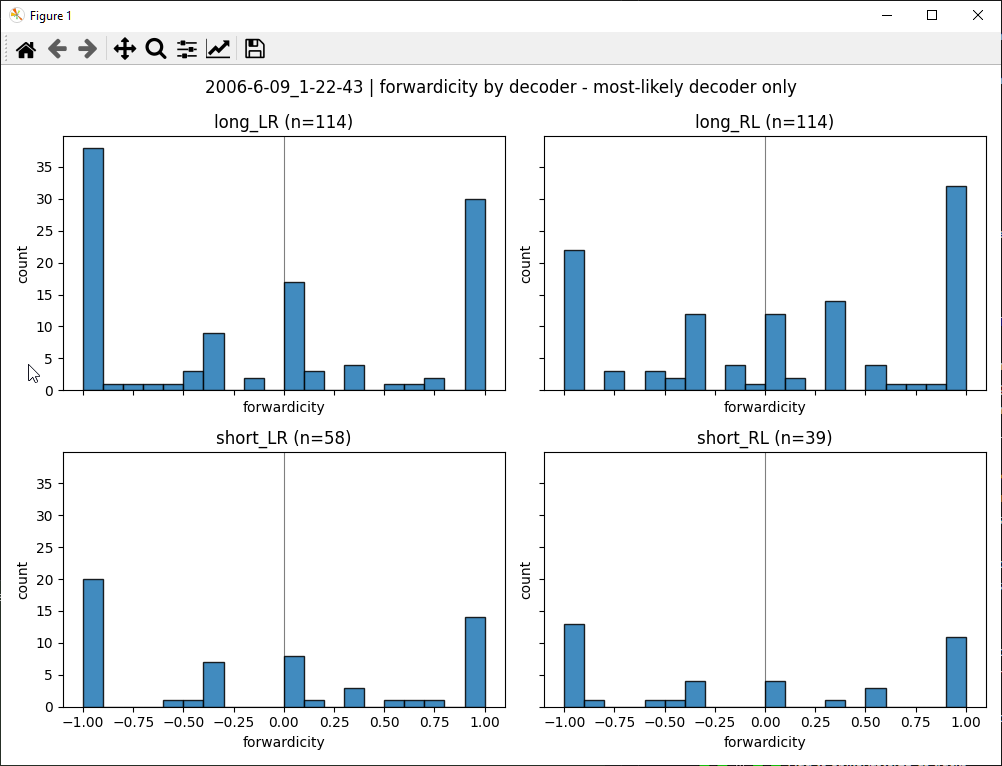
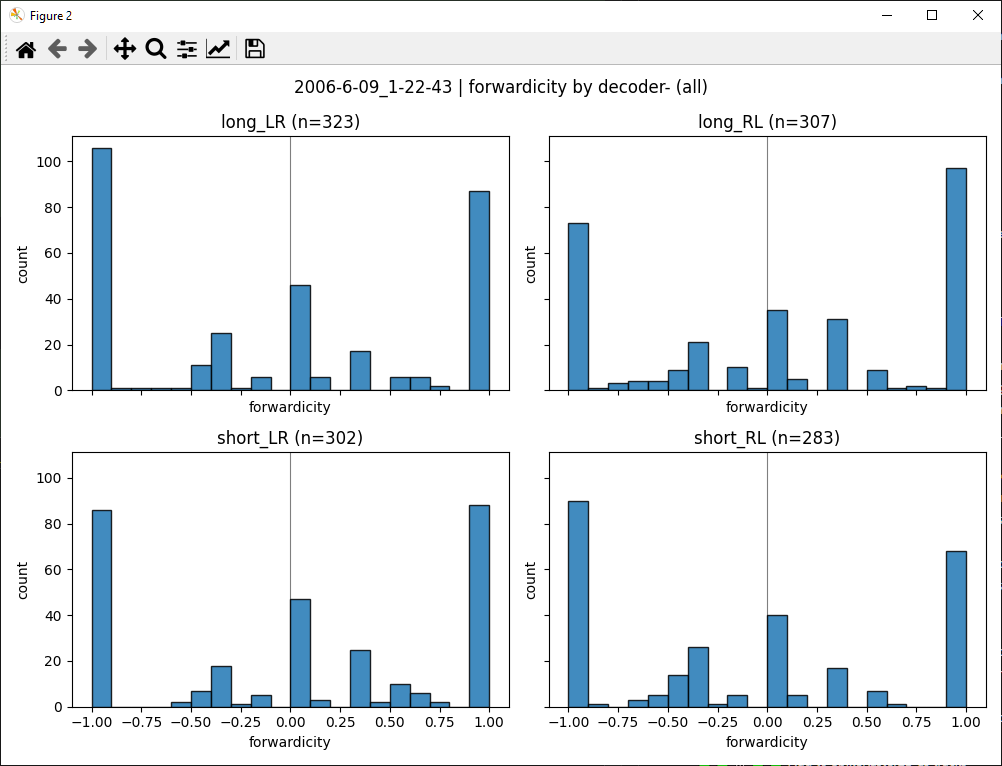

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Explicit 4-color categorical map
from matplotlib.colors import ListedColormap, BoundaryNorm
from neuropy.core.epoch import ensure_dataframe
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import DecoderDecodedEpochsResult


cmap = ListedColormap(['C0', 'C1', 'C2', 'C3'])
norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], cmap.N)

# 1) Ensure heuristics (incl. forwardicity) are on filter_epochs
# curr_active_pipeline.perform_specific_computation(
#     computation_functions_name_includelist=['directional_decoders_epoch_heuristic_scoring'],
#     fail_on_exception=True, debug_print=False,
# )

directional_decoders_epochs_decode_result: DecoderDecodedEpochsResult = (
    curr_active_pipeline.global_computation_results.computed_data['DirectionalDecodersEpochsEvaluations']
)

# 2) Merged per-epoch scores (adds forwardicity_long_LR, ..., and best-dir cols if merge succeeds)
scores_df: pd.DataFrame = directional_decoders_epochs_decode_result.build_complete_all_scores_merged_df()

# Probability columns after rename in build_complete_all_scores_merged_df
decoder_names = ['long_LR', 'long_RL', 'short_LR', 'short_RL']
p_cols = [f'P_{"Long" if n.startswith("long") else "Short"}_{n.split("_")[1]}' for n in decoder_names]
# -> ['P_Long_LR', 'P_Long_RL', 'P_Short_LR', 'P_Short_RL']
fwd_cols = [f'forwardicity_{n}' for n in decoder_names]

missing = [c for c in (p_cols + fwd_cols) if c not in scores_df.columns]
assert len(missing) == 0, f"Missing columns (recompute heuristics / check merge): {missing}"

# 3) Most-likely decoder's forwardicity per epoch
best_idx = scores_df[p_cols].to_numpy().argmax(axis=1)
fwd_mat = scores_df[fwd_cols].to_numpy(dtype=float)
scores_df['most_likely_decoder'] = np.asarray(decoder_names)[best_idx]
scores_df['forwardicity_most_likely_decoder'] = fwd_mat[np.arange(len(scores_df)), best_idx]

# Time axis (prefer delta-aligned if present)
t_col = 'delta_aligned_start_t' if 'delta_aligned_start_t' in scores_df.columns else 'start'
if t_col == 'start':
    _earliest, t_delta, _latest = curr_active_pipeline.find_LongShortDelta_times()
    scores_df['delta_aligned_start_t'] = scores_df['start'] - t_delta
    t_col = 'delta_aligned_start_t'

# 4) Plot over time
fig, ax = plt.subplots(figsize=(12, 3.5))
sc = ax.scatter(
    scores_df[t_col], scores_df['forwardicity_most_likely_decoder'],
    c=best_idx, cmap=cmap, norm=norm, s=18, alpha=0.85, # vmin=-0.5, vmax=3.5,
)
ax.axhline(0.0, color='k', lw=0.8, alpha=0.5)
ax.axvline(0.0, color='k', lw=0.8, alpha=0.5)  # delta
ax.set_ylim(-1.05, 1.05)
ax.set_xlabel(t_col)
ax.set_ylabel('forwardicity (most-likely decoder)')
ax.set_title(f'{curr_active_pipeline.session_name} | epoch forwardicity vs time')
cbar = fig.colorbar(sc, ax=ax, ticks=[0, 1, 2, 3])
cbar.ax.set_yticklabels(decoder_names)
fig.tight_layout()
plt.show()

scores_df[[t_col, 'most_likely_decoder', 'forwardicity_most_likely_decoder']].head()

In [ ]:
import numpy as np
import pandas as pd
import plotly.io as pio
# from neuropy.utils.mixins.dict_quantifyable import IdentifyingContext
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import DecoderDecodedEpochsResult
from pyphoplacecellanalysis.Pho2D.plotly.Extensions.plotly_helpers import plotly_pre_post_delta_scatter
from pyphoplacecellanalysis.Pho2D.plotly.plotly_templates import PlotlyHelpers

# --- build scores_df (same as your matplotlib cell) ---
directional_decoders_epochs_decode_result: DecoderDecodedEpochsResult = (
    curr_active_pipeline.global_computation_results.computed_data['DirectionalDecodersEpochsEvaluations']
)
scores_df: pd.DataFrame = directional_decoders_epochs_decode_result.build_complete_all_scores_merged_df()

decoder_names = ['long_LR', 'long_RL', 'short_LR', 'short_RL']
p_cols = ['P_Long_LR', 'P_Long_RL', 'P_Short_LR', 'P_Short_RL']
fwd_cols = [f'forwardicity_{n}' for n in decoder_names]
missing = [c for c in (p_cols + fwd_cols) if c not in scores_df.columns]
assert len(missing) == 0, f"Missing columns (recompute heuristics): {missing}"

best_idx = scores_df[p_cols].to_numpy().argmax(axis=1)
fwd_mat = scores_df[fwd_cols].to_numpy(dtype=float)
scores_df['most_likely_decoder'] = np.asarray(decoder_names)[best_idx]
scores_df['forwardicity_most_likely_decoder'] = fwd_mat[np.arange(len(scores_df)), best_idx]

if 'delta_aligned_start_t' not in scores_df.columns:
    _earliest, t_delta, _latest = curr_active_pipeline.find_LongShortDelta_times()
    scores_df['delta_aligned_start_t'] = scores_df['start'] - t_delta

# columns plotly_pre_post_delta_scatter expects
if 'time_bin_size' not in scores_df.columns:
    scores_df['time_bin_size'] = float(directional_decoders_epochs_decode_result.ripple_decoding_time_bin_size)
if 'session_name' not in scores_df.columns:
    scores_df['session_name'] = curr_active_pipeline.session_name

# drop undefined forwardicity so hists/scatter stay clean
plot_df = scores_df.dropna(subset=['forwardicity_most_likely_decoder', 'delta_aligned_start_t']).copy()

# --- pre/post delta layout ---
earliest_delta_aligned_t_start, t_delta, latest_delta_aligned_t_end = curr_active_pipeline.find_LongShortDelta_times()
# x-axis is already delta-aligned, so the middle of the tuple is 0.0
time_delta_tuple = (float(earliest_delta_aligned_t_start - t_delta), 0.0, float(latest_delta_aligned_t_end - t_delta))

is_dark_mode, template = PlotlyHelpers.get_plotly_template(is_dark_mode=False)
pio.templates.default = template

decoder_names = ['long_LR', 'long_RL', 'short_LR', 'short_RL']
color_seq = ['#1f77b4', '#aec7e8', '#ff7f0e', '#2ca02c']
variable_name = 'forwardicity_most_likely_decoder'

fig, fig_context = plotly_pre_post_delta_scatter(
    data_results_df=plot_df,
    data_context=IdentifyingContext(
        epochs_name='ripples', data_grain='per_epoch',
        title_prefix='Forwardicity (most-likely decoder)',
        dataframe_name='scores_df',
    ),
    histogram_bins=21,
    histogram_variable_name=variable_name,
    time_delta_tuple=time_delta_tuple,
    forced_range_y=[-1.0, 1.0],
    is_dark_mode=is_dark_mode,
    is_publication_ready_figure=False,
    main_title=f'{curr_active_pipeline.session_name} | forwardicity',
    common_plot_kwargs={
        'color': 'most_likely_decoder',
        'color_discrete_sequence': color_seq,
        'category_orders': {'most_likely_decoder': decoder_names},
    },
    px_scatter_kwargs={
        'x': 'delta_aligned_start_t',
        'y': variable_name,
        'size_max': 5,
        'render_mode': 'webgl',
        'title': variable_name,
        # no 'color' here
    },
    hist_kwargs={
        'nbins': 21,
        'range_y': [-1.0, 1.0],   # override helper default [0, 1]
        'opacity': 0.7,
        'barmode': 'overlay',
        # no 'color' here
    },
)

# baseline at 0 (signed score); helper default is often 0.5 for P_Short
fig = fig.add_hline(y=0.0, line=dict(color='rgba(0.2,0.2,0.2,0.75)', width=2), row='all', col='all')
fig = fig.update_yaxes(range=[-1.05, 1.05])
fig = fig.update_layout(width=1400, height=420)

color_map = dict(zip(decoder_names, color_seq))
for tr in fig.data:
    if getattr(tr, 'type', None) == 'histogram':
        for dec, c in color_map.items():
            if dec in str(tr.name) or dec in str(getattr(tr, 'legendgroup', '')):
                tr.marker.color = c
                break
fig.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

decoder_names = ['long_LR', 'long_RL', 'short_LR', 'short_RL']
fwd_cols = [f'forwardicity_{n}' for n in decoder_names]

fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)
axes = axes.ravel()

bins = np.linspace(-1.0, 1.0, 21)  # or np.arange(-1.05, 1.15, 0.1)

for ax, name, col in zip(axes, decoder_names, fwd_cols):

    # ## only best decoder    
    # title_modifier: str = ' - most-likely decoder only'
    # mask = scores_df['most_likely_decoder'].to_numpy() == name
    # vals = scores_df.loc[mask, col].to_numpy(dtype=float)
    # vals = vals[np.isfinite(vals)]
    # ax.hist(vals, bins=bins, color='C0', edgecolor='k', alpha=0.85)

    ## all decoders
    title_modifier = '- (all)'
    vals = scores_df[col].to_numpy(dtype=float)
    vals = vals[np.isfinite(vals)]
    ax.hist(vals, bins=bins, color='C0', edgecolor='k', alpha=0.85)


    ax.axvline(0.0, color='k', lw=0.8, alpha=0.5)
    ax.set_title(f'{name} (n={len(vals)})')
    ax.set_xlabel('forwardicity')
    ax.set_ylabel('count')

fig.suptitle(f'{curr_active_pipeline.session_name} | forwardicity by decoder{title_modifier}')
fig.tight_layout()
plt.show()

# 🚧 2026-10-09 - Shuffled Event Distributions (Figure S6c)

In [ ]:
"""Pipeline / shuffle analogue of the i.i.d. Uniform length-bias agg.
Uses already-computed WCorrShuffle values. x-axis n = epoch nbins.
Produces `agg` with the same columns as the synthetic cell so the next plot cell works.
"""
from copy import deepcopy
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, pearsonr

from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.SequenceBasedComputations import WCorrShuffle, SequenceBasedComputationsContainer
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import TrackTemplates

# --- load shuffle result -----------------------------------------------------------------
wcorr_shuffle_results: SequenceBasedComputationsContainer = curr_active_pipeline.global_computation_results.computed_data.get('SequenceBased', None)
# assert wcorr_shuffle_results is not None and wcorr_shuffle_results.wcorr_ripple_shuffle is not None, "SequenceBased.wcorr_ripple_shuffle missing — run wcorr_shuffle_analysis first"

if (wcorr_shuffle_results is None) or (wcorr_shuffle_results.wcorr_ripple_shuffle is None):
    print(f'"SequenceBased.wcorr_ripple_shuffle missing — run wcorr_shuffle_analysis first". Computing...')
    # Optional: ensure registered
    curr_active_pipeline.reload_default_computation_functions()

    # Best practice: pipeline API + short name + defaults (1024 shuffles, append if partial exists)
    curr_active_pipeline.perform_specific_computation(
        computation_functions_name_includelist=['wcorr_shuffle_analysis'],
        computation_kwargs_list=[{
            'num_shuffles': 128,                         # default in perform_wcorr_shuffle_analysis / Parameters
            'drop_previous_result_and_compute_fresh': False,  # keep/append existing shuffles
        }],
        enabled_filter_names=None,
        fail_on_exception=True,
        debug_print=False,
    )
    print(f'\tcomputing done.')

wcorr_shuffle_results: SequenceBasedComputationsContainer = curr_active_pipeline.global_computation_results.computed_data.get('SequenceBased', None)
assert wcorr_shuffle_results is not None and wcorr_shuffle_results.wcorr_ripple_shuffle is not None, "SequenceBased.wcorr_ripple_shuffle missing — EVEN AFTER COMPUTATION!"

wcorr_ripple_shuffle: WCorrShuffle = wcorr_shuffle_results.wcorr_ripple_shuffle
print(f'n_completed_shuffles={wcorr_ripple_shuffle.n_completed_shuffles}, n_epochs={wcorr_ripple_shuffle.n_epochs}')

decoder_names = list(TrackTemplates.get_decoder_names())  # or track_templates.get_decoder_names()
null_wcorr = wcorr_ripple_shuffle.all_shuffles_wcorr_array  # (n_shuffles, n_epochs, 4)
n_shuffles, n_epochs, n_decoders = null_wcorr.shape

# nbins: prefer a decoded result already in the kernel; else estimate from duration / tbin
epochs_df = deepcopy(wcorr_ripple_shuffle.filtered_epochs_df).reset_index(drop=True)
if 'nbins' in epochs_df.columns:
    nbins = epochs_df['nbins'].to_numpy(dtype=int)
else:
    try:
        _src = decoder_ripple_filter_epochs_decoder_result_dict  # from earlier notebook cells
        nbins = np.asarray(_src[decoder_names[0]].nbins, dtype=int)
        assert len(nbins) == n_epochs
    except Exception:
        tbin = float(wcorr_ripple_shuffle.all_templates_decode_kwargs.get('desired_ripple_decoding_time_bin_size', np.nan))
        assert np.isfinite(tbin) and tbin > 0
        nbins = np.maximum(1, np.floor(epochs_df['duration'].to_numpy(dtype=float) / tbin).astype(int))

# --- flatten shuffle |wcorr| into trial rows (n = nbins) ---------------------------------
trial_rows = []
for si in range(n_shuffles):
    for ei in range(n_epochs):
        n = int(nbins[ei])
        for di, a_name in enumerate(decoder_names):
            wc = null_wcorr[si, ei, di]
            if not np.isfinite(wc):
                continue
            trial_rows.append(dict(
                n=n, epoch_idx=ei, shuffle_idx=si, decoder=a_name,
                abs_wcorr=float(abs(wc)),
                # placeholders — filled below if possible
                abs_spearman=np.nan, abs_pearson=np.nan, is_mono=False,
                radon=np.nan, coverage=np.nan,
            ))
        ## END for di, a_name in enumerate(decoder_names)...
    ## END for ei in range(n_epochs)...
## END for si in range(n_shuffles)...

trial_df = pd.DataFrame(trial_rows)

# --- optional: real-epoch radon / mseq_tcov (NOT shuffle-null; by nbins for the plot) ------
# Prefer columns already on decoder filter_epochs: 'score' (radon), 'mseq_tcov' or 'coverage'
USE_REAL_HEURISTICS_BY_NBINS: bool = True
if USE_REAL_HEURISTICS_BY_NBINS:
    try:
        directional_decoders_epochs_decode_result = curr_active_pipeline.global_computation_results.computed_data['DirectionalDecodersEpochsEvaluations']
        real_rows = []
        for a_name in decoder_names:
            fe = deepcopy(directional_decoders_epochs_decode_result.decoder_ripple_filter_epochs_decoder_result_dict[a_name].filter_epochs)
            if hasattr(fe, 'to_dataframe'):
                fe = fe.to_dataframe()
            n_here = np.asarray(directional_decoders_epochs_decode_result.decoder_ripple_filter_epochs_decoder_result_dict[a_name].nbins, dtype=int)
            radon_col = 'score' if 'score' in fe.columns else ('radon' if 'radon' in fe.columns else None)
            tcov_col = 'mseq_tcov' if 'mseq_tcov' in fe.columns else ('coverage' if 'coverage' in fe.columns else None)
            for ei in range(min(len(fe), len(n_here))):
                real_rows.append(dict(
                    n=int(n_here[ei]),
                    radon=float(fe.iloc[ei][radon_col]) if radon_col else np.nan,
                    coverage=float(fe.iloc[ei][tcov_col]) if tcov_col else np.nan,
                ))
            ## END for ei in range(...)...
        ## END for a_name in decoder_names...
        real_metric_df = pd.DataFrame(real_rows)
    except Exception as e:
        print(f'real heuristic join skipped: {e}')
        real_metric_df = None
else:
    real_metric_df = None

# --- optional: if full shuffle decodes were saved, score ML positions for Spearman/radon/tcov
# (expensive; only if output_all_shuffles_decoded_results_list is non-empty)
if len(getattr(wcorr_ripple_shuffle, 'output_all_shuffles_decoded_results_list', []) or []) > 0:
    print('shuffle decoded results present — extend trial_df from most_likely_positions if you want true null Spearman/radon/tcov')
    # left as a hook: for each shuffle decode dict, take most_likely_positions_list[ei],
    # compute spearmanr/pearsonr/mono + radon_transform(wcorr already known) + track_coverage_score

# --- aggregate to plot-cell schema -------------------------------------------------------
def _mean_std(s: pd.Series):
    s = pd.to_numeric(s, errors='coerce').dropna()
    if len(s) == 0:
        return np.nan, np.nan
    if len(s) == 1:
        return float(s.iloc[0]), np.nan
    return float(s.mean()), float(s.std(ddof=1))


def _p_std(mask: pd.Series):
    """Bernoulli mean + sample SD of 0/1."""
    x = mask.astype(float)
    return _mean_std(x)


agg_rows = []
for n, g in trial_df.groupby('n'):
    mean_w, std_w = _mean_std(g['abs_wcorr'])
    p_w, std_p_w = _p_std(g['abs_wcorr'] > 0.8)
    mean_s, std_s = _mean_std(g['abs_spearman'])
    mean_p, std_p = _mean_std(g['abs_pearson'])
    p_sp, std_p_sp = _p_std(g['abs_spearman'] > 0.8)
    p_m, std_p_m = _p_std(g['is_mono'])
    mean_r, std_r = _mean_std(g['radon'])
    mean_c, std_c = _mean_std(g['coverage'])

    # Prefer real-epoch radon/tcov grouped by same n when trial_df lacks them
    if real_metric_df is not None:
        rg = real_metric_df[real_metric_df['n'] == n]
        if len(rg):
            if not np.isfinite(mean_r):
                mean_r, std_r = _mean_std(rg['radon'])
            if not np.isfinite(mean_c):
                mean_c, std_c = _mean_std(rg['coverage'])

    agg_rows.append(dict(
        n=int(n),
        mean_abs_spearman=mean_s, std_abs_spearman=std_s,
        mean_abs_pearson=mean_p, std_abs_pearson=std_p,
        p_abs_spearman_gt_0_8=p_sp, std_p_abs_spearman_gt_0_8=std_p_sp,
        p_mono=p_m, std_p_mono=std_p_m,
        mean_abs_wcorr=mean_w, std_abs_wcorr=std_w,
        p_abs_wcorr_gt_0_8=p_w, std_p_abs_wcorr_gt_0_8=std_p_w,
        mean_radon=mean_r, std_radon=std_r,
        mean_coverage=mean_c, std_coverage=std_c,
    ))
## END for n, g in trial_df.groupby('n')...

agg = pd.DataFrame(agg_rows).sort_values('n').reset_index(drop=True)
display(agg)

In [ ]:
df = trial_df

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from pyphoplacecellanalysis.SpecificResults.PhoDiba2023Paper import PhoPublicationFigureHelper

prepare_for_publication: bool = True
enable_error_bars: bool = False  # gated: ±1 SD whiskers (can go outside [0, 1] for proportions)
figsize = (12, 6.8)
# figures_parent_folder = Path('output/iid_uniform_trajectory_chance').resolve()
figures_parent_folder = Path('E:/Dropbox (Personal)/Active/Kamran Diba Lab/Pho-Kamran-Meetings/Pho Diba Paper 2023/Figures/UneditedSources/Figure S6 - Heuristic for Detecting Spatial Replay/iid_uniform_trajectory_chance').resolve()
figures_parent_folder.mkdir(parents=True, exist_ok=True)
export_stem: str = 'iid_uniform_short_sequences_look_trajectory_like'
# export_formats = ('pdf',)
export_formats = ()

vector_rc = PhoPublicationFigureHelper.rc_context_kwargs(prepare_for_publication=prepare_for_publication, **{
    'figure.figsize': figsize,
    'figure.dpi': '100',
    'figure.frameon': False,
    'svg.fonttype': 'none',  # editable <text> in Illustrator (not path outlines)
    'pdf.fonttype': 42,  # TrueType embed
})

err_kw = dict(capsize=2.5, elinewidth=0.9, markeredgewidth=0.9)
# Visible trial cloud: subsample + moderate alpha (80k full points at tiny alpha just looks like fog).
scatter_kw = dict(s=10, alpha=0.22, linewidths=0, rasterized=True)
max_scatter_per_n: int = 400  # cap points drawn per length so density stays readable
x_jitter_scale: float = 0.35
y_jitter_scale: float = 0.015  # tiny vertical jitter so ties don't paint as solid bars


def _errorbar(ax, x, y, yerr, **kwargs):
    """errorbar with NaN-safe yerr."""
    yerr = np.asarray(yerr, dtype=float)
    yerr = np.where(np.isfinite(yerr), yerr, 0.0)
    return ax.errorbar(x, y, yerr=yerr, **err_kw, **kwargs)


def _scatter_trials(ax, trials, y_col, color, rng, max_per_n=max_scatter_per_n, x_jitter_scale=x_jitter_scale, y_jitter_scale=y_jitter_scale, **kwargs):
    """Trial cloud: each vertical stripe is one discrete sequence length n (subsampled)."""
    parts = []
    for n_val, g in trials.groupby('n'):
        if len(g) > max_per_n:
            g = g.sample(n=max_per_n, random_state=int(rng.integers(0, 1_000_000_000)))
        parts.append(g)
    ## END for n_val, g in trials.groupby('n')...

    sub = pd.concat(parts, ignore_index=True) if parts else trials.iloc[0:0]
    x = sub['n'].to_numpy(dtype=float) + rng.uniform(-x_jitter_scale, x_jitter_scale, size=len(sub))
    y = sub[y_col].to_numpy(dtype=float) + rng.uniform(-y_jitter_scale, y_jitter_scale, size=len(sub))
    finite = np.isfinite(x) & np.isfinite(y)
    return ax.scatter(x[finite], y[finite], c=color, **scatter_kw, **kwargs)


# assert (df is not None) and (len(df) > 0), "Need trial-level df for scatter — re-run scoring with KEEP_TRIAL_DF=True."
scatter_rng = np.random.default_rng(0)

with mpl.rc_context(vector_rc):
    fig, axes = plt.subplots(2, 3, figsize=figsize)

    if (df is not None) and (len(df) > 0):
        # Continuous trial scores in the background (NOT 0/1 indicators — those only paint two horizontal bars).
        # Each vertical stripe = all (subsampled) trials at that discrete n.
        _scatter_trials(axes[0, 0], df, 'abs_spearman', color='C0', rng=scatter_rng)
        _scatter_trials(axes[0, 0], df, 'abs_pearson', color='C1', rng=scatter_rng)
        _scatter_trials(axes[0, 1], df, 'abs_spearman', color='C2', rng=scatter_rng)  # underlying |Spearman|; line is P(>0.8)
        _scatter_trials(axes[0, 2], df, 'abs_spearman', color='C3', rng=scatter_rng)  # context cloud; line is P(mono)
        _scatter_trials(axes[1, 0], df, 'abs_wcorr', color='C0', rng=scatter_rng)
        _scatter_trials(axes[1, 1], df, 'radon', color='C1', rng=scatter_rng)
        _scatter_trials(axes[1, 2], df, 'coverage', color='C4', rng=scatter_rng)
    else:
        print(f"Need trial-level df for scatter — re-run scoring with KEEP_TRIAL_DF=True.")

    # summary means (foreground)
    if enable_error_bars:
        _errorbar(axes[0, 0], agg['n'], agg['mean_abs_spearman'], agg['std_abs_spearman'], fmt='o-', color='C0', label='mean |Spearman| ± 1 SD', zorder=5)
        _errorbar(axes[0, 0], agg['n'], agg['mean_abs_pearson'], agg['std_abs_pearson'], fmt='s--', color='C1', label='mean |Pearson| ± 1 SD', zorder=5)
        _errorbar(axes[0, 1], agg['n'], agg['p_abs_spearman_gt_0_8'], agg['std_p_abs_spearman_gt_0_8'], fmt='o-', color='C2', label=r'P(|Spearman| > 0.8)', zorder=5)
        _errorbar(axes[0, 2], agg['n'], np.clip(agg['p_mono'], 1e-5, 1), agg['std_p_mono'], fmt='o-', color='C3', label='P(strictly monotonic)', zorder=5)
        _errorbar(axes[1, 0], agg['n'], agg['mean_abs_wcorr'], agg['std_abs_wcorr'], fmt='o-', color='C0', label='mean |wcorr| ± 1 SD', zorder=5)
        _errorbar(axes[1, 0], agg['n'], agg['p_abs_wcorr_gt_0_8'], agg['std_p_abs_wcorr_gt_0_8'], fmt='s--', color='C2', label=r'P(|wcorr| > 0.8)', zorder=5)
        _errorbar(axes[1, 1], agg['n'], agg['mean_radon'], agg['std_radon'], fmt='o-', color='C1', label='mean radon ± 1 SD', zorder=5)
        _errorbar(axes[1, 2], agg['n'], agg['mean_coverage'], agg['std_coverage'], fmt='o-', color='C4', label='mean tcov_seq ± 1 SD', zorder=5)
    else:
        axes[0, 0].plot(agg['n'], agg['mean_abs_spearman'], 'o-', color='C0', label='mean |Spearman|', zorder=5)
        axes[0, 0].plot(agg['n'], agg['mean_abs_pearson'], 's--', color='C1', label='mean |Pearson|', zorder=5)
        axes[0, 1].plot(agg['n'], agg['p_abs_spearman_gt_0_8'], 'o-', color='C2', label=r'P(|Spearman| > 0.8)', zorder=5)
        axes[0, 2].plot(agg['n'], np.clip(agg['p_mono'], 1e-5, 1), 'o-', color='C3', label='P(strictly monotonic)', zorder=5)
        axes[1, 0].plot(agg['n'], agg['mean_abs_wcorr'], 'o-', color='C0', label='mean |wcorr|', zorder=5)
        axes[1, 0].plot(agg['n'], agg['p_abs_wcorr_gt_0_8'], 's--', color='C2', label=r'P(|wcorr| > 0.8)', zorder=5)
        axes[1, 1].plot(agg['n'], agg['mean_radon'], 'o-', color='C1', label='mean radon', zorder=5)
        axes[1, 2].plot(agg['n'], agg['mean_coverage'], 'o-', color='C4', label='mean tcov_seq', zorder=5)

    axes[0, 0].set_xlabel('sequence length n'); axes[0, 0].set_ylabel('|corr(t, x)|  (points = trials)')
    axes[0, 0].set_title('Mean trajectory correlation'); axes[0, 0].legend(fontsize=7); axes[0, 0].set_ylim(0, 1)
    axes[0, 0].set_xlim([2, 16])

    axes[0, 1].axhline(0.8, color='0.35', lw=0.9, ls=':', zorder=4, label='threshold 0.8')
    axes[0, 1].set_xlabel('sequence length n'); axes[0, 1].set_ylabel(r'|Spearman| trials; line = P(> 0.8)')
    axes[0, 1].set_title('Chance of "looks sequential"'); axes[0, 1].legend(fontsize=7); axes[0, 1].set_ylim(0, 1)
    axes[0, 1].set_xlim([2, 16])

    axes[0, 2].set_xlabel('sequence length n'); axes[0, 2].set_ylabel(r'|Spearman| trials; line = P(mono)')
    axes[0, 2].set_title('Perfect ascending/descending order'); axes[0, 2].legend(fontsize=7); axes[0, 2].set_ylim(0, 1)
    axes[0, 2].set_xlim([2, 16])

    axes[1, 0].axhline(0.8, color='0.35', lw=0.9, ls=':', zorder=4)
    axes[1, 0].set_xlabel('sequence length n'); axes[1, 0].set_ylabel('|wcorr|  (points = trials)')
    axes[1, 0].set_title('wcorr'); axes[1, 0].legend(fontsize=7); axes[1, 0].set_ylim(0, 1)
    axes[1, 0].set_xlim([2, 16])

    axes[1, 1].set_xlabel('sequence length n'); axes[1, 1].set_ylabel('radon score  (points = trials)')
    axes[1, 1].set_title('radon'); axes[1, 1].legend(fontsize=7)
    axes[1, 1].set_xlim([2, 16])

    axes[1, 2].set_xlabel('sequence length n'); axes[1, 2].set_ylabel('track coverage  (points = trials)')
    axes[1, 2].set_title('tcov_seq'); axes[1, 2].legend(fontsize=7); axes[1, 2].set_ylim(0, 1)
    axes[1, 2].set_xlim([2, 16])

    fig.suptitle('i.i.d. Uniform positions — short sequences look more trajectory-like by chance\n(background points: subsampled trials at each discrete n; solid/dashed: summary curves)')
    plt.tight_layout()

    _out_paths = {}
    for file_format in export_formats:
        save_path = figures_parent_folder.joinpath(f'{export_stem}.{file_format}')
        fig.savefig(str(save_path), format=file_format, transparent=True)
        _out_paths[file_format] = save_path
        print(f'export_for_publication: saved "{save_path}"')
    ## END for file_format in export_formats...

    plt.show()

_out_paths

# agg


In [ ]:
"""Hypothesis: under cell-ID-shuffled templates (null posteriors from real spikes),
short events (few time bins) get higher |wcorr| than long ones; per-epoch shuffle
z-scoring should remove that duration bias."""
from copy import deepcopy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.SequenceBasedComputations import WCorrShuffle

num_shuffles: int = 20  # raise for a cleaner null; 20 is enough for a smoke test

wcorr_tool: WCorrShuffle = WCorrShuffle.init_from_templates(
    curr_active_pipeline=curr_active_pipeline,
    track_templates=track_templates,
    directional_decoders_epochs_decode_result=directional_decoders_epochs_decode_result,
    enable_saving_entire_decoded_shuffle_result=True,  # keep null position posteriors
)
wcorr_tool.compute_shuffles(num_shuffles=num_shuffles, curr_active_pipeline=curr_active_pipeline, track_templates=track_templates)

# null wcorr: (n_shuffles, n_epochs, 4); real: (n_epochs, 4)
null_wcorr = wcorr_tool.get_all_shuffles_wcorr_array()
real_wcorr = deepcopy(wcorr_tool.real_decoder_ripple_weighted_corr_arr)
epochs_df = deepcopy(wcorr_tool.filtered_epochs_df).reset_index(drop=True)
decoder_names = list(track_templates.get_decoder_names())

# nbins from first shuffle's decoded posteriors (same epoch structure for all shuffles)
null_decoded_0 = wcorr_tool.output_all_shuffles_decoded_results_list[0]
nbins = np.asarray(null_decoded_0[decoder_names[0]].nbins)
assert len(nbins) == len(epochs_df)

# Aggregate |null wcorr| across shuffles (mean of abs) per epoch × decoder
mean_abs_null = np.nanmean(np.abs(null_wcorr), axis=0)  # (n_epochs, 4)
rows = []
for di, a_name in enumerate(decoder_names):
    for ei in range(len(epochs_df)):
        shuff_vals = null_wcorr[:, ei, di]
        mu, sd = np.nanmean(shuff_vals), np.nanstd(shuff_vals)
        z_real = (real_wcorr[ei, di] - mu) / sd if (sd is not None and sd > 0) else np.nan
        rows.append(dict(
            epoch_idx=ei, decoder=a_name, duration=float(epochs_df.loc[ei, 'duration']),
            nbins=int(nbins[ei]), abs_real_wcorr=float(np.abs(real_wcorr[ei, di])),
            mean_abs_null_wcorr=float(mean_abs_null[ei, di]), wcorr_z=float(z_real),
        ))
## END for di, a_name in enumerate(decoder_names)...
null_bias_df = pd.DataFrame(rows)

print('Spearman |score| vs nbins (null should be negative if short events score higher):')
for metric in ('mean_abs_null_wcorr', 'abs_real_wcorr', 'wcorr_z'):
    corr = null_bias_df[['nbins', metric]].corr(method='spearman').iloc[0, 1]
    print(f'  {metric:>22s} ~ nbins: ρ={corr:+.3f}')

# Visual: short vs long under null
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True)
for ax, ycol, title in zip(axes, ('mean_abs_null_wcorr', 'wcorr_z'),
                           ('Null |wcorr| (raw)', 'Real wcorr z vs null (should flatten)')):
    for a_name, g in null_bias_df.groupby('decoder'):
        ax.scatter(g['nbins'], g[ycol], s=12, alpha=0.5, label=a_name)
    ax.set_xlabel('n time bins'); ax.set_ylabel(ycol); ax.set_title(title); ax.legend(fontsize=7)
## END for ax, ycol, title in zip(...)...
fig.suptitle('Cell-ID-shuffled templates → null posteriors from real spikes')
plt.tight_layout(); plt.show()

null_bias_df.head(), null_decoded_0  # posteriors: null_decoded_0[name].p_x_given_n_list

In [ ]:
paginated_multi_decoder_decoded_epochs_window.update_params(visible_overlay_label_keys=['score', 'wcorr', 'coverage', 'mseq_tcov'])
paginated_multi_decoder_decoded_epochs_window.refresh_current_page()

In [ ]:
paginated_multi_decoder_decoded_epochs_window.update_params(enable_decoded_sequence_and_heuristics_curve=True)
paginated_multi_decoder_decoded_epochs_window.refresh_current_page()

# if spacing looks off:
# paginated_multi_decoder_decoded_epochs_window.update_params(radon_label_bbox_y=0.70)
# paginated_multi_decoder_decoded_epochs_window.refresh_current_page()

In [ ]:


paginated_multi_decoder_decoded_epochs_window.update_params(disable_y_label=True)
paginated_multi_decoder_decoded_epochs_window.refresh_current_page()

In [ ]:
paginated_multi_decoder_decoded_epochs_window.decoder_filter_epochs_decoder_result_dict

In [ ]:
## check missing Radon Transform columns:
stored_dict = paginated_multi_decoder_decoded_epochs_window.decoder_filter_epochs_decoder_result_dict
# stored_dict = active_decoder_decoded_epochs_result_dict ## raw object
# stored_dict = filtered_decoder_filter_epochs_decoder_result_dict  ## raw object

epochs_df = stored_dict['long_LR'].active_filter_epochs
radon_cols = ['score', 'velocity', 'intercept', 'speed']
missing = [c for c in radon_cols if c not in epochs_df.columns]
are_radon_transform_columns_missing: bool = len(missing) > 0

# _computed_radon_transform_outputs_dict = None
if are_radon_transform_columns_missing:
    print(f'are_radon_transform_columns_missing: True, recomputing...')
    _computed_radon_transform_outputs_dict = {}
    
    for a_name, a_result in stored_dict.items():
        a_decoder = track_templates.get_decoders_dict()[a_name]
        print(f'\tcomputing for {a_name}...')
        _computed_radon_transform_outputs_dict[a_name] = a_result.compute_radon_transforms(
            pos_bin_size=float(a_decoder.pos_bin_size),
            xbin_centers=a_decoder.xbin_centers,
            nlines=4192, margin=4, n_jobs=1,
        )
        radon_df, *_extras = _computed_radon_transform_outputs_dict[a_name]
        # radon_df
        epochs_df = a_result.filter_epochs if isinstance(a_result.filter_epochs, pd.DataFrame) else a_result.filter_epochs.to_dataframe()
        for a_col in radon_cols:
            epochs_df[a_col] = radon_df[a_col].to_numpy()
        a_result.filter_epochs = epochs_df
    ## END for a_name, a_result in stored_dict.items()...

    # paginated_multi_decoder_decoded_epochs_window.add_data_overlays(
    #     included_columns=radon_cols + ['wcorr', 'P_decoder', 'pearsonr']
    # )

else:
    print(f'are_radon_transform_columns_missing: False.')



In [ ]:
paginated_multi_decoder_decoded_epochs_window.update_params(visible_overlay_label_keys=['score', 'wcorr'])
paginated_multi_decoder_decoded_epochs_window.refresh_current_page()

In [ ]:
## INPUTS: _computed_radon_transform_outputs_dict
force_overwrite_extant_columns: bool = False
# stored_dict = paginated_multi_decoder_decoded_epochs_window.decoder_filter_epochs_decoder_result_dict
stored_dict = filtered_decoder_filter_epochs_decoder_result_dict

for a_name, a_result in stored_dict.items():
    a_decoder = track_templates.get_decoders_dict()[a_name]
    radon_df, *_extras = _computed_radon_transform_outputs_dict[a_name]
    epochs_df = a_result.filter_epochs if isinstance(a_result.filter_epochs, pd.DataFrame) else a_result.filter_epochs.to_dataframe()
    for a_col in radon_cols:
        if (a_col not in epochs_df) or force_overwrite_extant_columns:
            epochs_df[a_col] = radon_df[a_col].to_numpy()
    a_result.filter_epochs = epochs_df


In [ ]:
_out_add_data_overlays = paginated_multi_decoder_decoded_epochs_window.add_data_overlays(
    included_columns=(radon_cols + ['wcorr', 'P_decoder', 'pearsonr'])
)

In [ ]:
_out_add_data_overlays = paginated_multi_decoder_decoded_epochs_window.add_data_overlays()

In [ ]:
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import ForwardicityPaginatedPlotDataProvider, forwardicity_score

for a_ctrl in paginated_multi_decoder_decoded_epochs_window.pagination_controllers.values():
    ForwardicityPaginatedPlotDataProvider.add_data_to_pagination_controller(a_ctrl, None, update_controller_on_apply=False)

paginated_multi_decoder_decoded_epochs_window.refresh_current_page()


In [ ]:
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import forwardicity_score, main_sequence_positions

decoder_names = ('long_LR', 'long_RL', 'short_LR', 'short_RL')
decoder_direction = {'long_LR': -1.0, 'long_RL': 1.0, 'short_LR': -1.0, 'short_RL': 1.0}

directional_merged_decoders_result = curr_active_pipeline.global_computation_results.computed_data['DirectionalMergedDecoders']
ripple_marginals_df = directional_merged_decoders_result.ripple_all_epoch_bins_marginals_df
p_mat = np.column_stack([
    ripple_marginals_df['P_LR'].to_numpy() * ripple_marginals_df['P_Long'].to_numpy(),
    ripple_marginals_df['P_RL'].to_numpy() * ripple_marginals_df['P_Long'].to_numpy(),
    ripple_marginals_df['P_LR'].to_numpy() * ripple_marginals_df['P_Short'].to_numpy(),
    ripple_marginals_df['P_RL'].to_numpy() * ripple_marginals_df['P_Short'].to_numpy(),
])
best_decoder_idx = np.argmax(p_mat, axis=1)
best_decoder_by_start = dict(zip(ripple_marginals_df['epoch_start_t'].to_numpy(), best_decoder_idx))

epoch_starts = list(next(iter(decoded_sequence_and_heuristics_partition_results_dict.values())).keys())
rows = []
for epoch_start_t in epoch_starts:
    a_best_idx = best_decoder_by_start[epoch_start_t]
    decoder_name = decoder_names[int(a_best_idx)]
    partition_result = decoded_sequence_and_heuristics_partition_results_dict[decoder_name][epoch_start_t]
    positions = main_sequence_positions(partition_result)
    forwardicity, (ratio_major_aligned_bins, ratio_decoder_aligned_bins) = forwardicity_score(most_likely_positions_arr=positions, most_likely_decoder_direction=decoder_direction[decoder_name], debug_print=False)
    rows.append({'epoch_start_t': epoch_start_t, 'decoder_name': decoder_name, 'forwardicity': forwardicity, 'ratio_major_aligned_bins': ratio_major_aligned_bins})
forwardicity_by_pbe_df = pd.DataFrame(rows)
forwardicity_by_pbe_df

In [ ]:
## OUTPUTS: forwardicity_by_pbe_df
decoder_colors = {'long_LR': '#4169E1', 'long_RL': '#607B00', 'short_LR': '#DC143C', 'short_RL': '#990099'}

fig, ax = plt.subplots(figsize=(12, 3.5), constrained_layout=True)
for decoder_name, group_df in forwardicity_by_pbe_df.groupby('decoder_name', sort=False):
    ax.scatter(group_df['epoch_start_t'], group_df['forwardicity'], s=18, alpha=0.85, color=decoder_colors[decoder_name], label=decoder_name)
ax.axhline(0.0, color='0.5', lw=0.8)
ax.set_ylim(-1.05, 1.05)
ax.set_xlabel('PBE start (s)')
ax.set_ylabel('forwardicity')
ax.legend(loc='upper right', frameon=False, ncol=4)
fig.show()

In [ ]:
decoder_colors = {'long_LR': '#4169E1', 'long_RL': '#607B00', 'short_LR': '#DC143C', 'short_RL': '#990099'}
decoder_names = ['long_LR', 'long_RL', 'short_LR', 'short_RL']
bins = np.linspace(-1.0, 1.0, 17)

fig, axes = plt.subplots(nrows=4, ncols=1, sharex=True, figsize=(6.5, 6.5), constrained_layout=True)
for ax, decoder_name in zip(axes, decoder_names):
    values = forwardicity_by_pbe_df.loc[forwardicity_by_pbe_df['decoder_name'] == decoder_name, 'forwardicity'].dropna()
    ax.hist(values, bins=bins, color=decoder_colors[decoder_name], edgecolor='white', linewidth=0.4)
    ax.axvline(0.0, color='0.4', lw=0.8)
    ax.set_ylabel(decoder_name)
    ax.set_xlim(-1.0, 1.0)
axes[-1].set_xlabel('forwardicity')
fig.show()

In [ ]:
comments_dict = {
    # long_LR ____________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________ #
    ('long_LR', 1117.3992461315356): 'score is surprisingly low',
    ('long_LR', 993.8681375394808): 'STRONGLY prefers stationary over trajectory-like',
    ('long_LR', 1161.0011335673044): 'very long epoch but low score',
    # long_RL ____________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________ #
    ('long_RL', 131.14078661589883): 'stationary_high',
    ('long_RL', 132.51138943410479): 'captures_start_end_not_middle',
    ('long_RL', 149.95935746072792): 'misses_main_traj',
    ('long_RL', 191.60855981637724): 'missed_main_traj_weaker',
    ('long_RL', 251.4167749545304): 'missed_main_traj_good',
    ('long_RL', 624.225748876459): 'longer_traj_event_example',
    ('long_RL', 637.7847819341114): 'perfect_missing_traj_example',
    ('long_RL', 764.1524509938899): 'always_misses_step_jumps',
    ('long_RL', 1117.6498597632162): 'rapid_traj_then_flat',
    ('long_RL', 1316.0564141790383): 'long_non_linear',
    ('long_RL', 1317.977058315766): 'super_non_linear',
    ('long_RL', 1440.8523566835793): 'sharply_non_linear',
}

found_epoch_idx_dict = {
    ('long_LR', 1117.3992461315356): 92,
    ('long_LR', 993.8681375394808): 86,
    ('long_LR', 1161.0011335673044): 100,
    ('long_RL', 131.14078661589883): None,
    ('long_RL', 132.51138943410479): 5,
    ('long_RL', 149.95935746072792): 8,
    ('long_RL', 191.60855981637724): 12,
    ('long_RL', 251.4167749545304): 16,
    ('long_RL', 624.225748876459): 44,
    ('long_RL', 637.7847819341114): 47,
    ('long_RL', 764.1524509938899): 67,
    ('long_RL', 1117.6498597632162): 93,
    ('long_RL', 1316.0564141790383): 121,
    ('long_RL', 1317.977058315766): 122,
    ('long_RL', 1440.8523566835793): 137,
}

found_epoch_idx_dict = {}
# Inputs: paginated_multi_decoder_decoded_epochs_window
# any_good_selected_epoch_times = deepcopy(paginated_multi_decoder_decoded_epochs_window.any_good_selected_epoch_times)
# any_good_selected_epoch_indicies = deepcopy(paginated_multi_decoder_decoded_epochs_window.find_data_indicies_from_epoch_times(paginated_multi_decoder_decoded_epochs_window.any_good_selected_epoch_times))
# any_good_selected_epoch_indicies
for (a_decoder_name, a_start_t), a_comment_text in comments_dict.items():
    print(f'(a_decoder_name, a_start_t): {(a_decoder_name, a_start_t)}: "{a_comment_text}"')
    ## find index of the epoch corresponding to a particular start_t in seconds
    # target_start_t: float = 1117.65
    # target_start_t: float = 191.65
    # a_result: DecodedFilterEpochsResult = epoch_type_selector_dict['ripple']['decoder_filter_epochs_decoder_result_dict'][a_decoder_name] # (1117.65, 248)
    # found_idx = a_result.find_data_indicies_from_epoch_times(a_start_t)
    found_idx = deepcopy(paginated_multi_decoder_decoded_epochs_window.find_data_indicies_from_epoch_times([a_start_t]))
    print(f'\tfound_idx: {found_idx}')
    if len(found_idx) < 1:
        found_epoch_idx_dict[(a_decoder_name, a_start_t)] = None
    else:
        found_epoch_idx_dict[(a_decoder_name, a_start_t)] = found_idx[0]

found_epoch_idx_dict

In [ ]:
selected_idxs = np.array([idx for idx in found_epoch_idx_dict.values() if idx is not None], dtype=int)

# get (N, 2) [start, stop] from any controller (epochs are shared)
a_ctrlr = next(iter(paginated_multi_decoder_decoded_epochs_window.pagination_controllers.values()))
epoch_times = a_ctrlr.plots_data.epoch_slices[selected_idxs]
epoch_times

for a_name, a_ctrlr in paginated_multi_decoder_decoded_epochs_window.pagination_controllers.items():
    _out_selections = a_ctrlr.restore_selections_from_epoch_times(epoch_times, is_additive_update=False, defer_render=False)
## END for a_name, a_ctrlr in ...

In [ ]:

with Ctx(format_name='kdiba',animal='gor01',exper_name='one',session_name='2006-6-09_1-22-43',display_fn_name='DecodedEpochSlices',epochs='ripple',user_annotation='selections') as ctx:
	user_annotations[ctx + Ctx(decoder='long_LR')] = [[132.511, 132.791], [149.959, 150.254], [191.609, 191.949], [251.417, 251.812], [624.226, 624.499], [637.785, 638.182], [764.152, 764.270], [993.868, 994.185], [1117.399, 1117.514], [1117.650, 1118.019], [1161.001, 1161.274], [1316.056, 1316.270], [1317.977, 1318.181], [1440.852, 1441.328]]
	user_annotations[ctx + Ctx(decoder='long_RL')] = [[132.511, 132.791], [149.959, 150.254], [191.609, 191.949], [251.417, 251.812], [624.226, 624.499], [637.785, 638.182], [764.152, 764.270], [993.868, 994.185], [1117.399, 1117.514], [1117.650, 1118.019], [1161.001, 1161.274], [1316.056, 1316.270], [1317.977, 1318.181], [1440.852, 1441.328]]
	user_annotations[ctx + Ctx(decoder='short_LR')] = [[132.511, 132.791], [149.959, 150.254], [191.609, 191.949], [251.417, 251.812], [624.226, 624.499], [637.785, 638.182], [764.152, 764.270], [993.868, 994.185], [1117.399, 1117.514], [1117.650, 1118.019], [1161.001, 1161.274], [1316.056, 1316.270], [1317.977, 1318.181], [1440.852, 1441.328]]
	user_annotations[ctx + Ctx(decoder='short_RL')] = [[132.511, 132.791], [149.959, 150.254], [191.609, 191.949], [251.417, 251.812], [624.226, 624.499], [637.785, 638.182], [764.152, 764.270], [993.868, 994.185], [1117.399, 1117.514], [1117.650, 1118.019], [1161.001, 1161.274], [1316.056, 1316.270], [1317.977, 1318.181], [1440.852, 1441.328]]


In [ ]:
paginated_multi_decoder_decoded_epochs_window.any_good_selected_epoch_times

In [ ]:
np.unique(np.concatenate([paginated_multi_decoder_decoded_epochs_window.any_good_selected_epoch_times, list(found_epoch_idx_dict.values())], axis=0), axis=0)

In [ ]:
paginated_multi_decoder_decoded_epochs_window.any_good_selected_epoch_times = np.unique(np.concatenate([paginated_multi_decoder_decoded_epochs_window.any_good_selected_epoch_times, list(found_epoch_idx_dict.values())], axis=0), axis=0)
paginated_multi_decoder_decoded_epochs_window.any_good_selected_epoch_times

In [ ]:
concatenated_selected_epoch_times = np.concatenate([a_ctrlr.selected_epoch_times for a_name, a_ctrlr in paginated_multi_decoder_decoded_epochs_window.pagination_controllers.items()], axis=0)
any_good_selected_epoch_times: NDArray = np.unique(concatenated_selected_epoch_times, axis=0) # drops duplicate rows (present in multiple decoders), and sorts them ascending
any_good_selected_epoch_times

In [ ]:
# paginated_multi_decoder_decoded_epochs_window.attached_yellow_blue_marginals_viewer_widget.plots_data.all_attributes # ['name', 'epoch_slices', 'global_pos_df', 'filter_epochs_decoder_result', 'active_marginal_fn', 'paginator', 'highlighted_epoch_time_bin_idx', 'decoded_position_curves_data', 'marginal_labels_data']

filter_epochs_decoder_result: DecodedFilterEpochsResult = paginated_multi_decoder_decoded_epochs_window.attached_yellow_blue_marginals_viewer_widget.plots_data.filter_epochs_decoder_result
filter_epochs_decoder_result.nbins
filter_epochs: pd.DataFrame = deepcopy(filter_epochs_decoder_result.filter_epochs)
filter_epochs

In [ ]:
filter_epochs['n_time_bins'] = filter_epochs_decoder_result.nbins
filter_epochs

In [ ]:
filter_epochs['est_n_t_bins'] = filter_epochs['duration'] / 0.025
filter_epochs

In [ ]:
filter_epochs[filter_epochs['label'] == '370']


# filter_epochs.

In [ ]:
filter_epochs[filter_epochs['start'] > 1505.164]


In [ ]:
import pyphoplacecellanalysis.General.type_aliases as types
from pyphoplacecellanalysis.Analysis.Decoder.heuristic_replay_scoring import SubsequencesPartitioningResult
from pyphoplacecellanalysis.General.Pipeline.Stages.DisplayFunctions.DecoderPredictionError import DecodedSequenceAndHeuristicsPlotData
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import forwardicity_score

decoded_sequence_and_heuristics_curves_data_dict: Dict[types.DecoderName, Dict[float, DecodedSequenceAndHeuristicsPlotData]] = paginated_multi_decoder_decoded_epochs_window.get_children_props(prop_path='plots_data.decoded_sequence_and_heuristics_curves_data')
decoded_sequence_and_heuristics_partition_results_dict: Dict[types.DecoderName, Dict[float, SubsequencesPartitioningResult]] = {a_name:{k:v.partition_result for k, v in a_data_dict.items()} for a_name, a_data_dict in decoded_sequence_and_heuristics_curves_data_dict.items()}
# decoded_sequence_and_heuristics_curves_data_dict
# decoded_sequence_and_heuristics_partition_results_dict


In [ ]:


## Version that uses the longest subsequence computed from the heuristic measure as the input to the `forwardicity_score`:
a_decoder_name: str = 'long_LR'
a_seq_and_heuristics_result_dict: Dict[float, SubsequencesPartitioningResult] = decoded_sequence_and_heuristics_partition_results_dict[a_decoder_name]
an_epoch_idx: int = 0
a_seq_and_heuristics_result: SubsequencesPartitioningResult = list(a_seq_and_heuristics_result_dict.values())[an_epoch_idx] ## normally indexed by epoch start_t
a_seq_and_heuristics_result.longest_sequence_subsequence
a_seq_and_heuristics_result.longest_sequence_subsequence_df


most_likely_decoder_direction = {'long_LR': -1.0, 'long_RL': 1.0, 'short_LR': -1.0, 'short_RL': 1.0}.get(a_decoder_name, None)
forwardicity, (ratio_major_aligned_bins, ratio_decoder_aligned_bins) = forwardicity_score(p_x_given_n=None, most_likely_positions_arr=a_seq_and_heuristics_result.longest_sequence_subsequence, xbin_centers=xbin_centers, most_likely_decoder_direction=most_likely_decoder_direction)
forwardicity

In [ ]:
decoded_sequence_and_heuristics_curves_data_dict ## OUTPUT

In [ ]:
paginated_multi_decoder_decoded_epochs_window.get_children_props(prop_path='params.data_overlay_heuristic_kwargs')


In [ ]:
paginated_multi_decoder_decoded_epochs_window.set_children_props(prop_path='params.data_overlay_heuristic_kwargs', value=dict(same_thresh_fraction_of_track=0.005, max_jump_distance_cm=360.0, max_ignore_bins=22))

# 🖼️ `export_current_epoch_marginal_and_raster_images` to export rasters

#### Batch (all) epochs export via `export_current_epoch_marginal_and_raster_images`

In [49]:
curr_active_pipeline.reload_default_display_functions()

In [ ]:
from pyphoplacecellanalysis.Pho2D.stacked_epoch_slices import PhoPaginatedMultiDecoderDecodedEpochsWindow


# DirectionalMergedDecoders: Get the result after computation:
directional_merged_decoders_result = curr_active_pipeline.global_computation_results.computed_data['DirectionalMergedDecoders'] # uses `DirectionalMergedDecoders`.

# root_export_path: Path = Path(r"/media/halechr/MAX/cloud/University of Michigan Dropbox/Pho Hale/Pho Diba Paper 2023/array_as_image").resolve() # Lab
# root_export_path: Path = Path(r'K:/scratch/collected_outputs/figures/array_as_image').resolve()

root_export_path: Path = Path(r'K:/scratch/collected_figures/qclu_1246789/array_as_image').resolve()


# root_export_path: Path = Path(r'C:\Users\pho\repos\Spike3DWorkEnv\Spike3D\EXTERNAL\Screenshots\ProgrammaticDisplayFunctionTesting\array_as_image').resolve()
root_export_path.mkdir(exist_ok=True)
Assert.path_exists(root_export_path)

complete_session_context, (session_context, additional_session_context) = curr_active_pipeline.get_complete_session_context()
_out_path_tuples_dict = paginated_multi_decoder_decoded_epochs_window.export_all_epoch_marginal_and_raster_images(directional_merged_decoders_result=directional_merged_decoders_result, root_export_path=root_export_path, active_context=complete_session_context)


current_page_idx = 5, found_data_index =50
DecodedEpochSlicesPaginatedFigureController.on_selected_epochs_changed(...)
	DecodedEpochSlicesPaginatedFigureController.on_selected_epochs_changed: selection changed!
current_page_idx = 5, found_data_index =50
on_secondary_click(event, clicked_ax=Axes(0.0869925,0.348502;0.885182x0.0832403), clicked_data_index=50)
log_clicked_epoch_times_to_message_box_callback(clicked_data_index: 50, clicked_epoch_is_selected: True, clicked_epoch_start_stop_time: [637.785 638.182])
update_attached_raster_viewer_epoch_callback(clicked_data_index: 50, clicked_epoch_is_selected: True, clicked_epoch_start_stop_time: [637.785 638.182])
start_t: 637.7847819341114
found_IDX: 50
WARN: self.disable_emit_changed = True
WARN: self.disable_emit_changed = True
ScrollBarWithSpinBox valueChanged(new_val: 50)
an_epoch: EpochTuple(Index=50, start=637.7847819341114, stop=638.1821449307026, label=136, duration=0.39736299659125507, end=638.1821449307026, wcorr=-0.468845730200220

In [ ]:
list(_out_path_tuples_dict.keys())


### 2026-11-18 - Programmatic Figure S2 Walkthru Example via `plot_map_based_context_decoder_walkthru`

In [ ]:
from pyphoplacecellanalysis.SpecificResults.PhoDiba2023Paper import plot_map_based_context_decoder_walkthru
from pyphoplacecellanalysis.Analysis.Decoder.reconstruction import SingleEpochDecodedResult

## active epoch: start_t: 637.7847819341114, found_IDX: 50
## Walkthru needs Pseudo2D (n_x, n_contexts, n_t) — not the per-decoder 1D results on the paginated window.
## Same source as the attached yellow-blue TrackID marginals (filtered to the window's epoch times).
active_epoch_start_t: float = 637.7847819341114
all_directional_ripple_filter_epochs_decoder_result = paginated_multi_decoder_decoded_epochs_window.attached_yellow_blue_marginals_viewer_widget.filter_epochs_decoder_result
# fallback if yellow-blue not attached:
# all_directional_ripple_filter_epochs_decoder_result = directional_merged_decoders_result.all_directional_ripple_filter_epochs_decoder_result
single_epoch_result: SingleEpochDecodedResult = all_directional_ripple_filter_epochs_decoder_result.get_result_for_epoch_at_time(epoch_start_time=active_epoch_start_t)
# equivalently: .get_result_for_epoch(active_epoch_idx=50)
print(f'single_epoch_result.p_x_given_n.shape: {single_epoch_result.p_x_given_n.shape}')  # expect (n_x, 4, n_t)

fig, extras = plot_map_based_context_decoder_walkthru(
    single_epoch_result,  # or NDArray (n_x, n_contexts, n_t)
    save_path='output/figS2_walkthru.pdf',
    max_time_bins=10, also_save_png=False,
)

#### Single epoch export via `export_current_epoch_marginal_and_raster_images`

In [ ]:
from pyphoplacecellanalysis.Pho2D.data_exporting import PosteriorExporting

## INPUTS: 

# DirectionalMergedDecoders: Get the result after computation:
directional_merged_decoders_result = curr_active_pipeline.global_computation_results.computed_data['DirectionalMergedDecoders'] # uses `DirectionalMergedDecoders`.


# root_export_path: Path = Path(r"/media/halechr/MAX/cloud/University of Michigan Dropbox/Pho Hale/Pho Diba Paper 2023/array_as_image").resolve() # Lab
# root_export_path: Path = Path(r'K:/scratch/collected_outputs/figures/array_as_image').resolve()
root_export_path: Path = collected_outputs_path.joinpath('figures/array_as_image') # '/nfs/turbo/umms-kdiba/Pho/Output/collected_outputs/figures/array_as_image'
print(f'root_export_path: {root_export_path}')

# root_export_path: Path = Path(r'C:\Users\pho\repos\Spike3DWorkEnv\Spike3D\EXTERNAL\Screenshots\ProgrammaticDisplayFunctionTesting\array_as_image').resolve()
root_export_path.mkdir(exist_ok=True)
Assert.path_exists(root_export_path)

complete_session_context, (session_context, additional_session_context) = curr_active_pipeline.get_complete_session_context()
epoch_specific_folder, (out_image_save_tuple_dict, _out_rasters_save_paths, merged_img_save_path) = paginated_multi_decoder_decoded_epochs_window.export_current_epoch_marginal_and_raster_images(directional_merged_decoders_result=directional_merged_decoders_result, root_export_path=root_export_path, active_context=complete_session_context)


In [ ]:
## INPUTS: paginated_multi_decoder_decoded_epochs_window
attached_ripple_rasters_widget: RankOrderRastersDebugger = paginated_multi_decoder_decoded_epochs_window.attached_ripple_rasters_widget
_out_ripple_rasters = paginated_multi_decoder_decoded_epochs_window
epoch_specific_folder, (out_image_save_tuple_dict, _out_rasters_save_paths, merged_img_save_path) = PosteriorExporting._perform_export_current_epoch_marginal_and_raster_images(_out_ripple_rasters=_out_ripple_rasters, directional_merged_decoders_result=directional_merged_decoders_result, 
    filtered_decoder_filter_epochs_decoder_result_dict=decoder_ripple_filter_epochs_decoder_result_dict, epoch_id_identifier_str='ripple',
    # filtered_decoder_filter_epochs_decoder_result_dict=decoder_laps_filter_epochs_decoder_result_dict, epoch_id_identifier_str='lap',
    active_session_context=curr_context, 
    root_export_path = root_export_path,
)

file_uri_from_path(epoch_specific_folder)
fullwidth_path_widget(a_path=epoch_specific_folder, file_name_label="epoch_specific_folder:")

In [ ]:
from pyphoplacecellanalysis.Pho2D.data_exporting import PosteriorExporting

# DirectionalMergedDecoders: Get the result after computation:
directional_merged_decoders_result = curr_active_pipeline.global_computation_results.computed_data['DirectionalMergedDecoders'] # uses `DirectionalMergedDecoders`.

# root_export_path: Path = Path(r'C:\Users\pho\repos\Spike3DWorkEnv\Spike3D\EXTERNAL\Screenshots\ProgrammaticDisplayFunctionTesting\array_as_image').resolve()
root_export_path: Path = Path(r'K:/scratch/collected_outputs/figures/array_as_image').resolve()
root_export_path.mkdir(exist_ok=True)
Assert.path_exists(root_export_path)

complete_session_context, (session_context, additional_session_context) = curr_active_pipeline.get_complete_session_context()

## INPUTS: paginated_multi_decoder_decoded_epochs_window
attached_ripple_rasters_widget: RankOrderRastersDebugger = paginated_multi_decoder_decoded_epochs_window.attached_ripple_rasters_widget
_out_ripple_rasters = paginated_multi_decoder_decoded_epochs_window
epoch_specific_folder, (out_image_save_tuple_dict, _out_rasters_save_paths, merged_img_save_path) = PosteriorExporting._perform_export_current_epoch_marginal_and_raster_images(_out_ripple_rasters=attached_ripple_rasters_widget, directional_merged_decoders_result=directional_merged_decoders_result, 
    filtered_decoder_filter_epochs_decoder_result_dict=decoder_ripple_filter_epochs_decoder_result_dict, epoch_id_identifier_str='ripple',
    # filtered_decoder_filter_epochs_decoder_result_dict=decoder_laps_filter_epochs_decoder_result_dict, epoch_id_identifier_str='lap',
    active_session_context=complete_session_context, 
    root_export_path = root_export_path,
)

file_uri_from_path(epoch_specific_folder)
fullwidth_path_widget(a_path=epoch_specific_folder, file_name_label="epoch_specific_folder:")

### <a id='toc12_1_4_'></a>[2024-02-29 3pm - Get the active user-annotated epoch times from the `paginated_multi_decoder_decoded_epochs_window` and use these to filter `filtered_ripple_simple_pf_pearson_merged_df`](#toc0_)

In [51]:

# Inputs: paginated_multi_decoder_decoded_epochs_window
any_good_selected_epoch_times = deepcopy(paginated_multi_decoder_decoded_epochs_window.any_good_selected_epoch_times)
any_good_selected_epoch_indicies = deepcopy(paginated_multi_decoder_decoded_epochs_window.find_data_indicies_from_epoch_times(paginated_multi_decoder_decoded_epochs_window.any_good_selected_epoch_times))
any_good_selected_epoch_indicies

array([50])

## <a id='toc12_2_'></a>[:✅:🎯 2024-09-27 - Test programmatic/background saving of stacked decoded epoch figures](#toc0_)

In [ ]:
## INPUTS: filtered_epochs_df
decoder_laps_filter_epochs_decoder_result_dict: Dict[types.DecoderName, DecodedFilterEpochsResult] = deepcopy(directional_decoders_epochs_decode_result.decoder_laps_filter_epochs_decoder_result_dict)
unfiltered_laps_epochs_df = deepcopy(decoder_laps_filter_epochs_decoder_result_dict['long_LR'].filter_epochs)
filtered_decoder_filter_epochs_decoder_result_dict: Dict[types.DecoderName, DecodedFilterEpochsResult] = {a_name:a_result.filtered_by_epoch_times(filtered_epochs_df[['start', 'stop']].to_numpy()) for a_name, a_result in decoder_ripple_filter_epochs_decoder_result_dict.items()} # working filtered

laps_decoding_time_bin_size: float = directional_decoders_epochs_decode_result.laps_decoding_time_bin_size
pos_bin_size: float = directional_decoders_epochs_decode_result.pos_bin_size
print(f'{pos_bin_size = }, {laps_decoding_time_bin_size = }')

In [ ]:
# using: perform_export_all_decoded_posteriors_as_images
from pyphoplacecellanalysis.Pho2D.data_exporting import HeatmapExportConfig, PosteriorExporting
from pyphoplacecellanalysis.Pho2D.data_exporting import HeatmapExportKind
from pyphoplacecellanalysis.SpecificResults.AcrossSessionResults import Assert

## INPUTS:: filtered_decoder_filter_epochs_decoder_result_dict, long_like_during_post_delta_only_filter_epochs
active_epochs_decoder_result_dict = deepcopy(filtered_decoder_filter_epochs_decoder_result_dict)
parent_output_folder = Path('output/array_to_images').resolve()

# active_epochs_decoder_result_dict = deepcopy(long_like_during_post_delta_only_filtered_decoder_filter_epochs_decoder_result_dict)
# parent_output_folder = Path('output/long_like_during_post_delta').resolve()


# active_epochs_decoder_result_dict = deepcopy(filtered_decoder_filter_epochs_decoder_result_dict)


## Laps:
active_epochs_decoder_result_dict = deepcopy(decoder_laps_filter_epochs_decoder_result_dict)



parent_output_folder.mkdir(exist_ok=True)
Assert.path_exists(parent_output_folder)
posterior_out_folder = parent_output_folder.joinpath(DAY_DATE_TO_USE).resolve()
posterior_out_folder.mkdir(parents=True, exist_ok=True)
save_path = posterior_out_folder.resolve()
_parent_save_context: IdentifyingContext = curr_active_pipeline.build_display_context_for_session('perform_export_all_decoded_posteriors_as_images')
_specific_session_output_folder = save_path.joinpath(active_context.get_description(subset_excludelist=['format_name'])).resolve()
_specific_session_output_folder.mkdir(parents=True, exist_ok=True)
print(f'\tspecific_session_output_folder: "{_specific_session_output_folder}"')

custom_export_formats: Dict[str, HeatmapExportConfig] = {
    'greyscale': HeatmapExportConfig.init_greyscale(desired_height=1200),
    # 'color': HeatmapExportConfig.init_for_export_kind(export_kind=HeatmapExportKind.COLORMAPPED, colormap='Oranges', desired_height=1200),
    # 'color': HeatmapExportConfig(colormap=additional_cmaps['long_LR']),
    # 'color': HeatmapExportConfig(colormap=cmap1, desired_height=200),
	# 'raw_rgba': HeatmapExportConfig.init_for_export_kind(export_kind=HeatmapExportKind.RAW_RGBA, lower_bound_alpha=0.1, drop_below_threshold=1e-2, desired_height=1200),
	# 'raw_rgba': HeatmapExportConfig.init_for_export_kind(export_kind=HeatmapExportKind.RAW_RGBA, 
    #                                                     raw_RGBA_only_parameters = dict(spikes_df=deepcopy(get_proper_global_spikes_df(curr_active_pipeline)), xbin=deepcopy(a_decoder.xbin), lower_bound_alpha=0.1, drop_below_threshold=1e-2, t_bin_size=0.025),
    #                                                     desired_height=1200),
}
# custom_export_formats = None


# `raw_RGBA_only_parameters` dict with keys: ['spikes_df', 'xbin', 'lower_bound_alpha', 'drop_below_threshold', 't_bin_size']

out_paths, out_custom_formats_dict = PosteriorExporting.perform_export_all_decoded_posteriors_as_images(decoder_laps_filter_epochs_decoder_result_dict=None, decoder_ripple_filter_epochs_decoder_result_dict=active_epochs_decoder_result_dict, ## for PBEs
# out_paths, out_custom_formats_dict = PosteriorExporting.perform_export_all_decoded_posteriors_as_images(decoder_laps_filter_epochs_decoder_result_dict=deepcopy(decoder_laps_filter_epochs_decoder_result_dict), decoder_ripple_filter_epochs_decoder_result_dict=None, ## for laps
                                                                                                            _save_context=_parent_save_context, parent_output_folder=_specific_session_output_folder,
                                                                                                            desired_height=1200, custom_export_formats=custom_export_formats, combined_img_padding=6, combined_img_separator_color=(0, 0, 0, 255))

In [ ]:
file_uri_from_path(_specific_session_output_folder)
fullwidth_path_widget(a_path=_specific_session_output_folder, file_name_label="epoch_specific_folder:")

In [ ]:
a_new_fully_generic_result.get_results_matching_contexts()

In [ ]:
curr_active_pipeline.perform_specific_computation(computation_functions_name_includelist=['generalized_specific_epochs_decoding'],
                        computation_kwargs_list=[{'epochs_decoding_time_bin_size': time_bin_size, 'drop_previous_result_and_compute_fresh': True, 'force_recompute': False}], 
                        enabled_filter_names=None, fail_on_exception=True, debug_print=False) 

# 11m 5s

In [ ]:


# pbe_trained_decoder_search_context = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, known_named_decoding_epochs_type='pbe', masked_time_bin_fill_type=('ignore', 'nan_filled', 'dropped'), data_grain='per_time_bin') # , decoder_identifier='pseudo2D', data_grain= 'per_time_bin -- not really relevant: ['masked_time_bin_fill_type', 'known_named_decoding_epochs_type', 'data_grain']
# laps_trained_decoder_search_context = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, decoder_identifier='pseudo2D', known_named_decoding_epochs_type='laps', masked_time_bin_fill_type='dropped', data_grain='per_time_bin')
pbe_trained_decoder_search_context = IdentifyingContext()
flat_context_list, flat_result_context_dict, flat_decoder_context_dict, flat_decoded_marginal_posterior_df_context_dict = a_new_fully_generic_result.get_results_matching_contexts(context_query=pbe_trained_decoder_search_context, return_multiple_matches=True, debug_print=False)
flat_context_list


In [ ]:
[Context(trained_compute_epochs= 'laps', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'pbe', masked_time_bin_fill_type= 'nan_filled', data_grain= 'per_time_bin'),
 Context(trained_compute_epochs= 'laps', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'pbe', masked_time_bin_fill_type= 'nan_filled'),
 Context(trained_compute_epochs= 'laps', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'laps', masked_time_bin_fill_type= 'dropped', data_grain= 'per_epoch'),
 Context(trained_compute_epochs= 'laps', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'non_pbe_endcaps', masked_time_bin_fill_type= 'dropped', data_grain= 'per_time_bin', decoding_time_bin_size= 0.025),
 Context(trained_compute_epochs= 'non_pbe', known_named_decoding_epochs_type= 'non_pbe', masked_time_bin_fill_type= 'last_valid'),
 Context(trained_compute_epochs= 'laps', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'global', masked_time_bin_fill_type= 'ignore', data_grain= 'per_time_bin'),
 Context(trained_compute_epochs= 'non_pbe', known_named_decoding_epochs_type= 'laps', masked_time_bin_fill_type= 'nan_filled'),
 Context(trained_compute_epochs= 'non_pbe', known_named_decoding_epochs_type= 'pbe', masked_time_bin_fill_type= 'ignore'),
 Context(trained_compute_epochs= 'laps', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'laps', masked_time_bin_fill_type= 'dropped', data_grain= 'per_time_bin'),
 Context(trained_compute_epochs= 'laps', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'non_pbe_endcaps', masked_time_bin_fill_type= 'last_valid', data_grain= 'per_time_bin', decoding_time_bin_size= 0.025),
 Context(trained_compute_epochs= 'laps', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'laps', masked_time_bin_fill_type= 'nan_filled', data_grain= 'per_epoch'),
 Context(trained_compute_epochs= 'laps', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'global', masked_time_bin_fill_type= 'nan_filled', data_grain= 'per_time_bin'),
 Context(trained_compute_epochs= 'laps', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'non_pbe_endcaps', masked_time_bin_fill_type= 'ignore', data_grain= 'per_time_bin', decoding_time_bin_size= 0.025),
 Context(trained_compute_epochs= 'laps', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'laps', masked_time_bin_fill_type= 'ignore', data_grain= 'per_time_bin'),
 Context(trained_compute_epochs= 'non_pbe', known_named_decoding_epochs_type= 'non_pbe', masked_time_bin_fill_type= 'ignore'),
 Context(trained_compute_epochs= 'laps', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'non_pbe_endcaps', masked_time_bin_fill_type= 'nan_filled', data_grain= 'per_time_bin', decoding_time_bin_size= 0.025),
 Context(trained_compute_epochs= 'laps', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'pbe', masked_time_bin_fill_type= 'ignore', data_grain= 'per_time_bin'),
 Context(trained_compute_epochs= 'laps', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'pbe', masked_time_bin_fill_type= 'ignore'),
 Context(trained_compute_epochs= 'non_pbe', known_named_decoding_epochs_type= 'laps', masked_time_bin_fill_type= 'last_valid'),
 Context(trained_compute_epochs= 'laps', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'pbe', masked_time_bin_fill_type= 'dropped', data_grain= 'per_epoch'),
 Context(trained_compute_epochs= 'non_pbe', known_named_decoding_epochs_type= 'laps'),
 Context(trained_compute_epochs= 'laps', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'laps', masked_time_bin_fill_type= 'nan_filled'),
 Context(trained_compute_epochs= 'laps', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'laps', masked_time_bin_fill_type= 'ignore'),
 Context(trained_compute_epochs= 'laps', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'pbe', masked_time_bin_fill_type= 'ignore', data_grain= 'per_epoch'),
 Context(trained_compute_epochs= 'laps', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'laps', masked_time_bin_fill_type= 'nan_filled', data_grain= 'per_time_bin'),
 Context(trained_compute_epochs= 'non_pbe', known_named_decoding_epochs_type= 'laps', masked_time_bin_fill_type= 'ignore'),
 Context(trained_compute_epochs= 'laps', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'pbe', masked_time_bin_fill_type= 'dropped', data_grain= 'per_time_bin'),
 Context(trained_compute_epochs= 'non_pbe', known_named_decoding_epochs_type= 'pbe', masked_time_bin_fill_type= 'nan_filled'),
 Context(trained_compute_epochs= 'non_pbe', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'laps', masked_time_bin_fill_type= 'dropped', data_grain= 'per_time_bin'),
 Context(trained_compute_epochs= 'laps', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'pbe', masked_time_bin_fill_type= 'nan_filled', data_grain= 'per_epoch'),
 Context(trained_compute_epochs= 'non_pbe', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'laps', masked_time_bin_fill_type= 'ignore', data_grain= 'per_time_bin'),
 Context(trained_compute_epochs= 'laps', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025),
 Context(trained_compute_epochs= 'laps', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'laps', masked_time_bin_fill_type= 'ignore', data_grain= 'per_epoch'),
 Context(trained_compute_epochs= 'non_pbe', known_named_decoding_epochs_type= 'non_pbe', masked_time_bin_fill_type= 'nan_filled'),
 Context(trained_compute_epochs= 'non_pbe', known_named_decoding_epochs_type= 'non_pbe'),
 Context(trained_compute_epochs= 'non_pbe', known_named_decoding_epochs_type= 'pbe'),
 Context(trained_compute_epochs= 'non_pbe', known_named_decoding_epochs_type= 'pbe', masked_time_bin_fill_type= 'dropped', data_grain= 'per_time_bin'),
 Context(trained_compute_epochs= 'non_pbe', known_named_decoding_epochs_type= 'pbe', masked_time_bin_fill_type= 'last_valid')]

In [ ]:
test_epoch_specific_decoded_results1D_dict, continuous_specific_decoded_results1D_dict, new_decoder1D_dict, new_pf1Ds_dict = self.recompute(curr_active_pipeline=curr_active_pipeline, pfND_ndim=1, epochs_decoding_time_bin_size=epochs_decoding_time_bin_size, skip_training_test_split=skip_training_test_split)
frame_divided_epochs_specific_decoded_results1D_dict = {a_name:a_new_decoder.decode_specific_epochs(spikes_df=deepcopy(get_proper_global_spikes_df(curr_active_pipeline)), filter_epochs=deepcopy(global_frame_divided_epochs_obj), decoding_time_bin_size=epochs_decoding_time_bin_size, debug_print=False) for a_name, a_new_decoder in new_decoder1D_dict.items()}
results1D = DecodingResultND(ndim=1, 
    test_epoch_results=test_epoch_specific_decoded_results1D_dict, 
    continuous_results=continuous_specific_decoded_results1D_dict,
    decoders=new_decoder1D_dict, pfs=new_pf1Ds_dict,
    frame_divided_epochs_results=frame_divided_epochs_specific_decoded_results1D_dict, 
    frame_divided_epochs_df=deepcopy(global_frame_divided_epochs_df), pos_df=global_pos_df)


In [ ]:
## Get epochs to decode:

long_epoch_name, short_epoch_name, global_epoch_name = curr_active_pipeline.find_LongShortGlobal_epoch_names()
t_start, t_delta, t_end = curr_active_pipeline.find_LongShortDelta_times()
global_session = curr_active_pipeline.filtered_sessions[global_epoch_name]

# global_spikes_df = deepcopy(curr_active_pipeline.computation_results[global_epoch_name]['computed_data'].pf1D.spikes_df)
global_laps = ensure_Epoch(deepcopy(curr_active_pipeline.filtered_sessions[global_epoch_name].laps.to_dataframe())) # .trimmed_to_non_overlapping()
global_PBEs = ensure_Epoch(deepcopy(curr_active_pipeline.filtered_sessions[global_epoch_name].pbe)) # .trimmed_to_non_overlapping()

epochs_to_decode_dict: Dict = {'laps': global_laps, 'pbe': global_PBEs}
## OUTPUTS: epochs_to_decode_dict


In [ ]:
## INPUTS: curr_active_pipeline, epochs_decoding_time_bin_size, epochs_to_decode_dict, a_new_fully_generic_result

## UPDATES: a_new_fully_generic_result

decoders_dict: Dict[types.DecoderName, BasePositionDecoder] = deepcopy(track_templates.get_decoders_dict())
laps_trained_decoder_search_context = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, masked_time_bin_fill_type='ignore', data_grain='per_time_bin') # , data_grain= 'per_time_bin -- not really relevant: ['masked_time_bin_fill_type', 'known_named_decoding_epochs_type', 'data_grain']

## Can add:     known_named_decoding_epochs_type='laps', 
out_dict = {}

for a_decoder_name, a_decoder in decoders_dict.items():
    ## for each decoder
    for an_epoch_to_decode_name, an_epochs_to_decode_obj in epochs_to_decode_dict.items():
        ## for each epoch to decode
        a_context: IdentifyingContext = deepcopy(laps_trained_decoder_search_context).overwriting_context(decoder_identifier=a_decoder_name, known_named_decoding_epochs_type=an_epoch_to_decode_name)        
        a_result: DecodedFilterEpochsResult = a_decoder.decode_specific_epochs(spikes_df=deepcopy(get_proper_global_spikes_df(curr_active_pipeline)), filter_epochs=deepcopy(an_epochs_to_decode_obj), decoding_time_bin_size=epochs_decoding_time_bin_size, debug_print=False)
        a_new_fully_generic_result.updating_results_for_context(new_context=a_context, a_result=a_result, a_decoder=deepcopy(a_decoder), a_decoded_marginal_posterior_df=None, an_epoch_to_decode=deepcopy(an_epochs_to_decode_obj)) ## update using the result
        


In [ ]:
out_dict[a_context]

# TODONO - 2025-06-04 - Paper 2025 Figure Gen

In [ ]:
from pyphoplacecellanalysis.General.Batch.BatchJobCompletion.BatchCompletionHandler import BatchSessionCompletionHandler
from neuropy.utils.matplotlib_helpers import matplotlib_file_only
from pyphoplacecellanalysis.SpecificResults.PhoDiba2023Paper import main_complete_figure_generations


# self.try_complete_figure_generation_to_file(curr_active_pipeline, enable_default_wandb_plots=self.should_generate_all_plots)
fail_on_exception: bool = False
enable_default_wandb_plots = False
completed_good: bool = False

try:
    ## To file only:
    with matplotlib_file_only():
        # Perform non-interactive Matplotlib operations with 'AGG' backend
        # wandb_logger = batch_perform_all_plots(curr_active_pipeline, enable_wandb=True, wandb_logger=None)
        main_complete_figure_generations(curr_active_pipeline, enable_default_wandb_plots=enable_default_wandb_plots, save_figures_only=True, save_figure=True)

    # IF thst's done, clear all the plots:
    # from matplotlib import pyplot as plt
    # plt.close('all') # this takes care of the matplotlib-backed figures.
    curr_active_pipeline.clear_display_outputs()
    curr_active_pipeline.clear_registered_output_files()
    completed_good = True # completed successfully (without raising an error at least).

except Exception as e:
    completed_good =  False
    raise
    # exception_info = sys.exc_info()
    # e = CapturedException(e, exception_info)
    # print(f'main_complete_figure_generations failed with exception: {e}')
    # if fail_on_exception:
    #     raise e.exc



## OUTPUTS: completed_good
print(f'completed_good: {completed_good}')




# 2025-08-26 - Lap Ground Truth Performance assessment to disqualify poor context decoding sessions

In [ ]:
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import determine_percent_correctly_decoded_contexts

## find the number of correctly decoded components:
time_bin_size: float = 0.075
records_df: pd.DataFrame = determine_percent_correctly_decoded_contexts(curr_active_pipeline, time_bin_size=time_bin_size)
records_df

In [ ]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import LapDecodingGroundTruth
# PhoJonathan Results:
long_epoch_name, short_epoch_name, global_epoch_name = curr_active_pipeline.find_LongShortGlobal_epoch_names()
long_results, short_results, global_results = [curr_active_pipeline.computation_results[an_epoch_name]['computed_data'] for an_epoch_name in [long_epoch_name, short_epoch_name, global_epoch_name]]
jonathan_firing_rate_analysis_result = curr_active_pipeline.global_computation_results.computed_data.jonathan_firing_rate_analysis
neuron_replay_stats_df, short_exclusive, long_exclusive, BOTH_subset, EITHER_subset, XOR_subset, NEITHER_subset = jonathan_firing_rate_analysis_result.get_cell_track_partitions(frs_index_inclusion_magnitude=0.2)

# desired_laps_decoding_time_bin_size: float = 1.0
# desired_laps_decoding_time_bin_size: float = 0.6
desired_laps_decoding_time_bin_size: float = 0.075
# included_neuron_ids_list = [short_exclusive, long_exclusive, BOTH_subset, EITHER_subset, XOR_subset, NEITHER_subset]
included_neuron_ids_list = [None]

_output_tuples_list = LapDecodingGroundTruth.perform_sweep_lap_groud_truth_performance_testing(curr_active_pipeline,
                                                                        included_neuron_ids_list=included_neuron_ids_list,
                                                                        desired_laps_decoding_time_bin_size=desired_laps_decoding_time_bin_size)

percent_laps_correctness_df: pd.DataFrame = pd.DataFrame.from_records([complete_decoded_context_correctness_tuple.percent_correct_tuple for (a_directional_merged_decoders_result, result_laps_epochs_df, complete_decoded_context_correctness_tuple) in _output_tuples_list],
                        columns=("track_ID_correct", "dir_correct", "complete_correct"))
percent_laps_correctness_df

In [ ]:
(a_directional_merged_decoders_result, result_laps_epochs_df, complete_decoded_context_correctness_tuple) = _output_tuples_list[0]
# result_laps_epochs_df
# a_directional_merged_decoders_result.laps_track_identity_marginals_tuple
# a_directional_merged_decoders_result.all_directional_laps_filter_epochs_decoder_result.marginal_x_list
# a_directional_merged_decoders_result.all_directional_laps_filter_epochs_decoder_result.perform_compute_marginals()

In [ ]:
a_new_fully_generic_result

In [ ]:
from neuropy.core.epoch import ensure_dataframe

## INPUTS: directional_merged_decoders_result, curr_active_pipeline
global_any_laps_epochs_obj = deepcopy(curr_active_pipeline.computation_results[global_any_name].computation_config.pf_params.computation_epochs) # global_any_name='maze_any' (? same as global_epoch_name?)
global_any_laps_epochs_df = ensure_dataframe(global_any_laps_epochs_obj)    
global_any_laps_epochs_df = global_any_laps_epochs_df.epochs.adding_maze_id_if_needed(t_start=t_start, t_delta=t_delta, t_end=t_end)
global_any_laps_epochs_df = global_any_laps_epochs_df.laps_accessor.compute_lap_dir_from_net_displacement(global_session=deepcopy(global_session), replace_existing=True)

result_laps_epochs_df: pd.DataFrame = directional_merged_decoders_result.add_groundtruth_information(curr_active_pipeline)
result_laps_epochs_df


In [ ]:

try:
    laps_directional_marginals, laps_directional_all_epoch_bins_marginal, laps_most_likely_direction_from_decoder, laps_is_most_likely_direction_LR_dir  = directional_merged_decoders_result.laps_directional_marginals_tuple
    percent_laps_estimated_correctly = DirectionalPseudo2DDecodersResult.validate_lap_dir_estimations(curr_active_pipeline.sess, active_global_laps_df=global_any_laps_epochs_obj.to_dataframe(), laps_is_most_likely_direction_LR_dir=laps_is_most_likely_direction_LR_dir)
    print(f'percent_laps_estimated_correctly: {percent_laps_estimated_correctly}')
except (AssertionError, ValueError) as err:
    print(F'fails due to some types thing?')
    print(f'\terr: {err}')
    pass



In [ ]:
laps_directional_all_epoch_bins_marginal

In [ ]:
## Get the global (continuous) epoch df

## Compute the time-binned decoding for it

## Add the groundtruth to it

## Filter out the correct time bins:



In [ ]:
curr_active_pipeline.reload_default_display_functions()

In [ ]:
_out = dict()
_out['_display_long_short_laps'] = curr_active_pipeline.display(display_function='_display_long_short_laps', active_session_configuration_context=None) # _display_long_short_laps


In [ ]:
curr_active_pipeline.reload_default_display_functions()

_out = dict()
_out['_display_plot_marginal_1D_most_likely_position_comparisons'] = curr_active_pipeline.display(display_function='_display_plot_marginal_1D_most_likely_position_comparisons', 
																								  active_session_configuration_context=IdentifyingContext(format_name='kdiba',animal='pin01',exper_name='one',session_name='fet11-01_12-58-54',filter_name='maze_any',lap_dir='any'),
                                                                                                    # variable_name='x',
                                                                                                    variable_name='lin_pos',
																								  ) # _display_plot_marginal_1D_most_likely_position_comparisons


In [ ]:
_out = dict()
_out['_display_two_step_decoder_prediction_error_2D'] = curr_active_pipeline.display(display_function='_display_two_step_decoder_prediction_error_2D', active_session_configuration_context=IdentifyingContext(format_name='kdiba',animal='pin01',exper_name='one',session_name='fet11-01_12-58-54',filter_name='maze_any',lap_dir='any')) # _display_two_step_decoder_prediction_error_2D


In [ ]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.EpochComputationFunctions import KnownFilterEpochs
curr_active_pipeline.reload_default_display_functions()

decoding_time_bin_size: float = 0.075 # 75ms
params_kwargs = {'build_fn':'insets_view', 'should_use_MatplotlibTimeSynchronizedWidget': False, 'scrollable_figure': False, }

_out = dict()
_out['_display_plot_decoded_epoch_slices'] = curr_active_pipeline.display(display_function='_display_plot_decoded_epoch_slices',
																		   active_session_configuration_context=IdentifyingContext(format_name='kdiba',animal='pin01',exper_name='one',session_name='fet11-01_12-58-54',filter_name='maze_any',lap_dir='any'),
																		   filter_epochs='lap',
																		#    filter_epochs='pbe',
                                                                            decoding_time_bin_size = decoding_time_bin_size,
																			decoder_ndim = 1,
																			variable_name='lin_pos',
																			# decoding_time_bin_size=0.075,
																			# variable_name='x',
                                                                            size=(30, 15),
																			scrollable_figure=False, should_use_MatplotlibTimeSynchronizedWidget=False,
																			params_kwargs=params_kwargs,
																		   ) # _display_plot_decoded_epoch_slices


In [ ]:
print(f'\t trying "_display_plot_decoded_epoch_slices"')

decoding_time_bin_size: float = 0.075 # 75ms
a_params_kwargs = {'build_fn':'insets_view', 'should_use_MatplotlibTimeSynchronizedWidget': False, 'scrollable_figure': False, }

custom_figure_output_path = collected_outputs_path

# display_context = curr_active_pipeline.build_display_context_for_session(display_fn_name='decoded_epoch_slices')

display_context = curr_active_pipeline.build_display_context_for_filtered_session(filtered_session_name=curr_active_pipeline.find_Global_epoch_name(), display_fn_name='decoded_epoch_slices')


_out = curr_active_pipeline.display('_display_plot_decoded_epoch_slices', display_context, defer_render=True, save_figure=True,
        # override_fig_man=custom_fig_man, 
        filter_epochs='lap',
    #    filter_epochs='pbe',
        decoding_time_bin_size = decoding_time_bin_size,
        decoder_ndim = 1,
        variable_name='lin_pos',
        # variable_name='x',
        size=(30, 15),
        scrollable_figure=False, should_use_MatplotlibTimeSynchronizedWidget=False,
        params_kwargs=a_params_kwargs,
        parent_output_folder=custom_figure_output_path,
    )

# _out = EpochComputationDisplayFunctions._display_plot_decoded_epoch_slices(curr_active_pipeline, None, None, None, include_includelist=None, save_figure=True)
keys_to_convert_to_benedict = ['export_paths', 'out_custom_formats_dict']
_out = {k:benedict(v) if (k in keys_to_convert_to_benedict) else v for k, v in _out.items()}

across_session_results_extended_dict['figures_plot_generalized_decode_epochs_dict_and_export_results_completion_function'].update({
'_display_plot_decoded_epoch_slices': _out,
})

In [ ]:
_out.figure

In [ ]:
from pyphoplacecellanalysis.Pho2D.matplotlib.MatplotlibTimeSynchronizedWidget import MatplotlibTimeSynchronizedWidget

_out_container: GenericMatplotlibContainer = list(_out['_display_plot_decoded_epoch_slices'].values())[0]
_out_container

In [ ]:
mw: MatplotlibTimeSynchronizedWidget  = _out_container.ui.mw
mw.geometry()
mw.size()
fig = mw.getFigure()
fig.get_size_inches()

In [ ]:
plt.close('all')

In [ ]:
curr_active_pipeline.reload_default_display_functions()

# from pyphoplacecellanalysis.General.Batch.NonInteractiveProcessing import batch_perform_all_plots
from pyphoplacecellanalysis.General.Batch.NonInteractiveProcessing import BatchPlotting

# _out = batch_perform_all_plots(curr_active_pipeline, enable_wandb=False, debug_print=True)
BatchPlotting.batch_extended_programmatic_figures(curr_active_pipeline=curr_active_pipeline, debug_print=True)


In [ ]:
mw.resize(700, 312)

In [ ]:
_out = dict()
_out['_display_plot_most_likely_position_comparisons'] = curr_active_pipeline.display(display_function='_display_plot_most_likely_position_comparisons', active_session_configuration_context=IdentifyingContext(format_name='kdiba',animal='pin01',exper_name='one',session_name='fet11-01_12-58-54',filter_name='maze_any',lap_dir='any')) # _display_plot_most_likely_position_comparisons


In [ ]:
_out = dict()
_out['_display_spike_rasters_window'] = curr_active_pipeline.display(display_function='_display_spike_rasters_window', active_session_configuration_context=IdentifyingContext(format_name='kdiba',animal='pin01',exper_name='one',session_name='fet11-01_12-58-54',filter_name='maze_any',lap_dir='any')) # _display_spike_rasters_window


# 2025-11-03 - Endcap bins excluded

In [ ]:
from pyphoplacecellanalysis.Pho2D.data_exporting import LoadedPosteriorContainer
from pyphoplacecellanalysis.Pho2D.track_shape_drawing import LinearTrackInstance
from neuropy.core.user_annotations import UserAnnotationsManager


loaded_track_limits = {'long_xlim': np.array([59.0774, 228.69]),
 'long_unit_xlim': np.array([0.205294, 0.794698]),
 'short_xlim': np.array([94.0156, 193.757]),
 'short_unit_xlim': np.array([0.326704, 0.673304]),
 'long_ylim': np.array([138.164, 146.12]),
 'long_unit_ylim': np.array([0.48012, 0.507766]),
 'short_ylim': np.array([138.021, 146.263]),
 'short_unit_ylim': np.array([0.479622, 0.508264])
}

long_track_inst, short_track_inst = LinearTrackInstance.init_LS_tracks_from_loaded_track_limits(loaded_track_limits=loaded_track_limits)


In [ ]:
directional_decoders_epochs_decode_result: DecoderDecodedEpochsResult = deepcopy(curr_active_pipeline.global_computation_results.computed_data['DirectionalDecodersEpochsEvaluations']) ## GENERAL
directional_merged_decoders_result: DirectionalPseudo2DDecodersResult = deepcopy(curr_active_pipeline.global_computation_results.computed_data['DirectionalMergedDecoders'])
spikes_df = deepcopy(get_proper_global_spikes_df(curr_active_pipeline))

laps_all_epoch_bins_marginals_df: pd.DataFrame = deepcopy(directional_merged_decoders_result.laps_all_epoch_bins_marginals_df)
laps_time_bin_marginals_df: pd.DataFrame = deepcopy(directional_merged_decoders_result.laps_time_bin_marginals_df)
session_name: str = curr_active_pipeline.session_name
t_start, t_delta, t_end = curr_active_pipeline.find_LongShortDelta_times()
laps_time_bin_marginals_df = laps_time_bin_marginals_df.across_session_identity.add_session_df_columns(session_name=session_name, time_bin_size=0.025, t_start=t_start, curr_session_t_delta=t_delta, t_end=t_end)
laps_time_bin_marginals_df

In [ ]:
## math
laps_time_bin_marginals_df['most_likely_positions_1D']



In [ ]:
active_df: pd.DataFrame = deepcopy(laps_time_bin_marginals_df)
a_most_likely_positions_from_most_likely_decoder_classification_df: pd.DataFrame = long_track_inst.build_x_position_classification_df(x_arr=active_df['most_likely_positions_1D'])
# a_most_likely_positions_from_most_likely_decoder_classification_df
active_df['is_decoded_pos_track_body'] = np.logical_and(np.logical_not(a_most_likely_positions_from_most_likely_decoder_classification_df['is_endcap']), a_most_likely_positions_from_most_likely_decoder_classification_df['is_on_maze'])
active_df

In [ ]:
active_df = deepcopy(active_df[active_df['is_decoded_pos_track_body']])
active_df

In [ ]:
## INPUTS: most_likely_positions_from_most_likely_decoder_classification_df
col_name:str = 'is_decoded_endcap_pos'

active_df = active_df.drop(columns=[col_name], inplace=False)
# on_maze_only_df = deepcopy(most_likely_positions_from_most_likely_decoder_classification_df[most_likely_positions_from_most_likely_decoder_classification_df['is_on_maze']])
on_maze_body_only_df = deepcopy(most_likely_positions_from_most_likely_decoder_classification_df[~most_likely_positions_from_most_likely_decoder_classification_df['is_endcap']])

on_maze_body_only_df
if col_name not in active_df.columns:
    active_df[col_name] = True ## default to True to throw them out
    # matching_indicies = active_df.epochs.find_data_indicies_from_epoch_times(most_likely_positions_from_most_likely_decoder_classification_df['t_bin_center'].values)
    matching_indicies = active_df.epochs.find_data_indicies_from_epoch_times(on_maze_body_only_df['t_bin_center'].values)
    active_df.loc[matching_indicies, col_name] = False #  most_likely_positions_from_most_likely_decoder_classification_df['is_on_maze']
    # most_likely_positions_from_most_likely_decoder_classification_df
    

# ['session_uid', 't_bin_center']
# np.sum(np.logical_not(active_df['is_decoded_endcap_pos']))



In [ ]:
import numpy as np
from pyphoplacecellanalysis.Analysis.Decoder.transition_matrix import TransitionMatrixComputations
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import DirectionalDecodersContinuouslyDecodedResult
from pyphoplacecellanalysis.Analysis.Decoder.transition_matrix import plot_blocked_transition_matrix
from neuropy.utils.matplotlib_helpers import perform_update_title_subtitle
import matplotlib.pyplot as plt
import seaborn as sns
from pyphoplacecellanalysis.Analysis.Decoder.transition_matrix import _perform_plot_P_Context_State_Transition_Matrix, _perform_plot_position_Transition_Matrix
from pyphoplacecellanalysis.Analysis.Decoder.context_dependent import GenericDecoderDictDecodedEpochsDictResult
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.EpochComputationFunctions import EpochComputationFunctions, EpochComputationsComputationsContainer
from neuropy.utils.mixins.binning_helpers import BinningContainer, BinningInfo
from pyphoplacecellanalysis.Analysis.Decoder.reconstruction import DecodedFilterEpochsResult
from pyphoplacecellanalysis.Analysis.Decoder.transition_matrix import complete_all_transition_matricies, build_transition_matricies
from pyphoplacecellanalysis.Analysis.Decoder.transition_matrix import split_transition_matricies_results_pre_post_delta_category
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import filter_and_update_epochs_and_spikes
from pyphoplacecellanalysis.Pho2D.data_exporting import PosteriorExporting
from pyphoplacecellanalysis.SpecificResults.PhoDiba2023Paper import LongShortTrackDataframeAccessor


# desired_time_bin_size = 0.050 # 50ms
desired_time_bin_size = 0.025 # 25ms
curr_active_pipeline.perform_specific_computation(computation_functions_name_includelist=['directional_decoders_decode_continuous'], computation_kwargs_list=[{'time_bin_size': desired_time_bin_size, 'should_disable_cache': False}], enabled_filter_names=None, fail_on_exception=True, debug_print=False)


## Uses the `global_computation_results.computed_data['DirectionalDecodersDecoded']`
directional_decoders_decode_result: DirectionalDecodersContinuouslyDecodedResult = curr_active_pipeline.global_computation_results.computed_data['DirectionalDecodersDecoded']
# all_directional_pf1D_Decoder_dict: Dict[str, BasePositionDecoder] = directional_decoders_decode_result.pf1D_Decoder_dict
pseudo2D_decoder: BasePositionDecoder = directional_decoders_decode_result.pseudo2D_decoder

# all_directional_pf1D_Decoder_dict: Dict[str, BasePositionDecoder] = directional_decoders_decode_result.pf1D_Decoder_dict
continuously_decoded_result_cache_dict = directional_decoders_decode_result.continuously_decoded_result_cache_dict
continuously_decoded_pseudo2D_decoder_dict = directional_decoders_decode_result.continuously_decoded_pseudo2D_decoder_dict
# continuously_decoded_result_cache_dict
continuously_decoded_pseudo2D_decoder_dict



In [ ]:
continuously_decoded_pseudo2D_decoder_dict

In [ ]:
valid_EpochComputations_result: EpochComputationsComputationsContainer = curr_active_pipeline.global_computation_results.computed_data['EpochComputations']
a_new_fully_generic_result: GenericDecoderDictDecodedEpochsDictResult = valid_EpochComputations_result.a_generic_decoder_dict_decoded_epochs_dict_result

# a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, time_bin_size=0.050, known_named_decoding_epochs_type='pbe', masked_time_bin_fill_type='ignore') # , decoder_identifier='long_LR'
# a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, time_bin_size=0.025, known_named_decoding_epochs_type='pbe', masked_time_bin_fill_type='ignore', data_grain='per_epoch') # , time_bin_size=0.050, known_named_decoding_epochs_type='pbe', masked_time_bin_fill_type='ignore', decoder_identifier='long_LR'

# a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, time_bin_size=0.025, known_named_decoding_epochs_type='laps', masked_time_bin_fill_type='ignore', data_grain='per_epoch') ## Laps
# any_matching_contexts_list, result_context_dict, decoder_context_dict, decoded_marginal_posterior_df_context_dict = a_new_fully_generic_result.get_results_matching_contexts(context_query=a_target_context)

# common_constraint_dict = dict(trained_compute_epochs='laps', pfND_ndim=1, time_bin_size=0.025, masked_time_bin_fill_type='ignore')
# common_constraint_dict = dict(trained_compute_epochs='laps', time_bin_size=0.025, masked_time_bin_fill_type='nan_filled') # , pfND_ndim=1
# common_constraint_dict = dict(trained_compute_epochs='laps', time_bin_size=0.025, masked_time_bin_fill_type='nan_filled')
common_constraint_dict = dict(trained_compute_epochs='laps', time_bin_size=0.075, masked_time_bin_fill_type='nan_filled')


## Laps context:
a_laps_target_context: IdentifyingContext = IdentifyingContext(known_named_decoding_epochs_type='laps', **common_constraint_dict, data_grain='per_epoch') ## Laps
laps_target_context_results = complete_all_transition_matricies(a_new_fully_generic_result=a_new_fully_generic_result, a_target_context=a_laps_target_context)
laps_matched_result_tuple_context_dict, (laps_time_bin_container_context_dict, laps_position_transition_matrix_context_dict, laps_context_state_transition_matrix_context_dict, laps_combined_transition_matrix_context_dict), (laps_mean_context_state_transition_matrix_context_dict, laps_mean_position_transition_matrix_context_dict) = laps_target_context_results
# a_best_matching_context, a_result, a_decoder, a_decoded_marginal_posterior_df = out_matched_result_tuple_context_dict[a_ctxt]


In [ ]:
# laps_target_context_results
a_new_fully_generic_result.filtere

In [ ]:
a_ctxt = IdentifyingContext(trained_compute_epochs= 'laps', pfND_ndim= 1, decoder_identifier= 'pseudo2D', time_bin_size= 0.025, known_named_decoding_epochs_type= 'laps', masked_time_bin_fill_type= 'nan_filled', data_grain= 'per_time_bin')
a_result = a_new_fully_generic_result.filter_epochs_specific_decoded_result[a_ctxt]
a_result.filter_epochs

In [ ]:
a_laps = curr_active_pipeline.sess.laps

In [ ]:
laps_time_bin_marginals_df['most_likely_positions_1D']


In [ ]:
laps_matched_result_tuple_context_dict

In [ ]:
a_laps_best_matching_context, a_laps_result, a_laps_decoder, a_laps_decoded_marginal_posterior_df = list(laps_matched_result_tuple_context_dict.values())[0] # [-1]


In [ ]:

## PBEs context:
a_PBEs_target_context: IdentifyingContext = IdentifyingContext(known_named_decoding_epochs_type='pbe', **common_constraint_dict, data_grain='per_epoch') ## Laps
pbes_target_context_results = complete_all_transition_matricies(a_new_fully_generic_result=a_new_fully_generic_result, a_target_context=a_PBEs_target_context)
pbes_matched_result_tuple_context_dict, (pbes_time_bin_container_context_dict, pbes_position_transition_matrix_context_dict, pbes_context_state_transition_matrix_context_dict, pbes_combined_transition_matrix_context_dict), (pbes_mean_context_state_transition_matrix_context_dict, pbes_mean_position_transition_matrix_context_dict) = pbes_target_context_results
a_pbes_best_matching_context, a_pbes_result, a_pbes_decoder, a_pbes_decoded_marginal_posterior_df = list(pbes_matched_result_tuple_context_dict.values())[0] # [-1] # pbes_matched_result_tuple_context_dict[a_PBEs_target_context]
## INPUTS: laps_context_state_transition_matrix_context_dict
out_context_state_transition_matrix_context_dict = deepcopy(laps_context_state_transition_matrix_context_dict)
out_matched_result_tuple_context_dict = deepcopy(laps_matched_result_tuple_context_dict)

an_out_best_matching_context, an_out_result, an_out_decoder, an_out_decoded_marginal_posterior_df = list(out_matched_result_tuple_context_dict.values())[0] # [-1]
a_context_state_transition_matrix_list: List[NDArray] = list(out_context_state_transition_matrix_context_dict.values())[0]

## INPUTS: an_out_decoded_marginal_posterior_df, a_context_state_transition_matrix_list
a_mean_context_state_transition_matrix_dict = split_transition_matricies_results_pre_post_delta_category(an_out_decoded_marginal_posterior_df=an_out_decoded_marginal_posterior_df, a_context_state_transition_matrix_list=a_context_state_transition_matrix_list)
a_mean_context_state_transition_matrix_dict



# Context Likelihood as a function of position

In [ ]:
from pyphoplacecellanalysis.Analysis.Decoder.context_dependent import GenericDecoderDictDecodedEpochsDictResult
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.EpochComputationFunctions import EpochComputationFunctions, EpochComputationsComputationsContainer
from neuropy.utils.mixins.binning_helpers import BinningContainer, BinningInfo
from pyphoplacecellanalysis.Analysis.Decoder.reconstruction import DecodedFilterEpochsResult
from pyphoplacecellanalysis.Analysis.Decoder.transition_matrix import complete_all_transition_matricies, build_transition_matricies
from pyphoplacecellanalysis.Analysis.Decoder.transition_matrix import split_transition_matricies_results_pre_post_delta_category
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import filter_and_update_epochs_and_spikes
from pyphoplacecellanalysis.Pho2D.data_exporting import PosteriorExporting
from pyphoplacecellanalysis.SpecificResults.PhoDiba2023Paper import LongShortTrackDataframeAccessor
from pyphoplacecellanalysis.Analysis.Decoder.context_dependent import GenericDecoderDictDecodedEpochsDictResult
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.EpochComputationFunctions import EpochComputationFunctions, EpochComputationsComputationsContainer


valid_EpochComputations_result: EpochComputationsComputationsContainer = curr_active_pipeline.global_computation_results.computed_data['EpochComputations']
a_new_fully_generic_result: GenericDecoderDictDecodedEpochsDictResult = valid_EpochComputations_result.a_generic_decoder_dict_decoded_epochs_dict_result


# # a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, time_bin_size=0.050, known_named_decoding_epochs_type='pbe', masked_time_bin_fill_type='ignore') # , decoder_identifier='long_LR'
# # a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, time_bin_size=0.025, known_named_decoding_epochs_type='pbe', masked_time_bin_fill_type='ignore', data_grain='per_epoch') # , time_bin_size=0.050, known_named_decoding_epochs_type='pbe', masked_time_bin_fill_type='ignore', decoder_identifier='long_LR'

# # a_target_context: IdentifyingContext = IdentifyingContext(trained_compute_epochs='laps', pfND_ndim=1, time_bin_size=0.025, known_named_decoding_epochs_type='laps', masked_time_bin_fill_type='ignore', data_grain='per_epoch') ## Laps
# # any_matching_contexts_list, result_context_dict, decoder_context_dict, decoded_marginal_posterior_df_context_dict = a_new_fully_generic_result.get_results_matching_contexts(context_query=a_target_context)

# # common_constraint_dict = dict(trained_compute_epochs='laps', pfND_ndim=1, time_bin_size=0.025, masked_time_bin_fill_type='ignore')
# # common_constraint_dict = dict(trained_compute_epochs='laps', time_bin_size=0.050, masked_time_bin_fill_type='nan_filled') # , pfND_ndim=1
# common_constraint_dict = dict(trained_compute_epochs='laps', time_bin_size=0.075, masked_time_bin_fill_type='nan_filled') # , pfND_ndim=1

# # common_constraint_dict.update(data_grain='per_epoch')
# common_constraint_dict.update(data_grain='per_t_bin')

# ## Laps context:
# a_laps_target_context: IdentifyingContext = IdentifyingContext(known_named_decoding_epochs_type='laps', **common_constraint_dict) ## Laps
# laps_target_context_results = complete_all_transition_matricies(a_new_fully_generic_result=a_new_fully_generic_result, a_target_context=a_laps_target_context)
# laps_matched_result_tuple_context_dict, (laps_time_bin_container_context_dict, laps_position_transition_matrix_context_dict, laps_context_state_transition_matrix_context_dict, laps_combined_transition_matrix_context_dict), (laps_mean_context_state_transition_matrix_context_dict, laps_mean_position_transition_matrix_context_dict) = laps_target_context_results
# # a_best_matching_context, a_result, a_decoder, a_decoded_marginal_posterior_df = out_matched_result_tuple_context_dict[a_ctxt]
# a_laps_best_matching_context, a_laps_result, a_laps_decoder, a_laps_decoded_marginal_posterior_df = list(laps_matched_result_tuple_context_dict.values())[0] # [-1]

# ## PBEs context:
# a_PBEs_target_context: IdentifyingContext = IdentifyingContext(known_named_decoding_epochs_type='pbe', **common_constraint_dict) ## Laps
# pbes_target_context_results = complete_all_transition_matricies(a_new_fully_generic_result=a_new_fully_generic_result, a_target_context=a_PBEs_target_context)
# pbes_matched_result_tuple_context_dict, (pbes_time_bin_container_context_dict, pbes_position_transition_matrix_context_dict, pbes_context_state_transition_matrix_context_dict, pbes_combined_transition_matrix_context_dict), (pbes_mean_context_state_transition_matrix_context_dict, pbes_mean_position_transition_matrix_context_dict) = pbes_target_context_results
# a_pbes_best_matching_context, a_pbes_result, a_pbes_decoder, a_pbes_decoded_marginal_posterior_df = list(pbes_matched_result_tuple_context_dict.values())[0] # [-1] # pbes_matched_result_tuple_context_dict[a_PBEs_target_context]
# pre_post_delta_a_laps_decoded_marginal_posterior_df_dict = a_laps_decoded_marginal_posterior_df.pho.partition_df_dict('pre_post_delta_category') # pre_post_delta_category
# # pre_post_delta_a_laps_decoded_marginal_posterior_df_dict = a_pbes_decoded_marginal_posterior_df.pho.partition_df_dict('pre_post_delta_category') # pre_post_delta_category
# # pre_post_delta_a_laps_decoded_marginal_posterior_df_dict['pre-delta']
# # pre_post_delta_a_laps_decoded_marginal_posterior_df_dict['post-delta']

# _out = pre_post_delta_a_laps_decoded_marginal_posterior_df_dict['pre-delta'].plot.scatter(x='t_bin_center', y='P_Short')



a_new_fully_generic_result


# common_constraint_dict = dict(trained_compute_epochs='laps', pfND_ndim=1, time_bin_size=0.025, masked_time_bin_fill_type='ignore')
common_constraint_dict = dict(trained_compute_epochs='laps', time_bin_size=0.025, masked_time_bin_fill_type='nan_filled') # , pfND_ndim=1

# common_constraint_dict.update(data_grain='per_epoch')
common_constraint_dict.update(data_grain='per_t_bin')

## Laps context:
a_laps_target_context: IdentifyingContext = IdentifyingContext(known_named_decoding_epochs_type='laps', **common_constraint_dict) ## Laps
a_laps_best_matching_context, a_laps_result, a_laps_decoder, a_laps_decoded_marginal_posterior_df = a_new_fully_generic_result.get_results_best_matching_context(context_query=a_laps_target_context)
# laps_matched_result_tuple_context_dict, (laps_time_bin_container_context_dict, laps_position_transition_matrix_context_dict, laps_context_state_transition_matrix_context_dict, laps_combined_transition_matrix_context_dict), (laps_mean_context_state_transition_matrix_context_dict, laps_mean_position_transition_matrix_context_dict) = laps_target_context_results
# a_best_matching_context, a_result, a_decoder, a_decoded_marginal_posterior_df = out_matched_result_tuple_context_dict[a_ctxt]
# a_laps_best_matching_context, a_laps_result, a_laps_decoder, a_laps_decoded_marginal_posterior_df = list(laps_matched_result_tuple_context_dict.values())[0] # [-1]

## PBEs context:
a_PBEs_target_context: IdentifyingContext = IdentifyingContext(known_named_decoding_epochs_type='pbe', **common_constraint_dict) ## PBEs
a_pbes_best_matching_context, a_pbes_result, a_pbes_decoder, a_pbes_decoded_marginal_posterior_df  = a_new_fully_generic_result.get_results_best_matching_context(context_query=a_PBEs_target_context)


In [ ]:
# np.shape(a_laps_result.p_x_given_n_list[0]) # (59, 4, 227) - (n_x_bins, n_contexts, n_t_bins)

p_x_by_ctxt_marginals = []
p_x_by_ctxt_marginal_all_laps = None

# an_epoch_idx: int = 0
# a_p_x_given_n = a_laps_result.p_x_given_n_list[an_epoch_idx] # (59, 4, 227) - (n_x_bins, n_contexts, n_t_bins)


for an_epoch_idx, a_p_x_given_n in enumerate(a_laps_result.p_x_given_n_list):
    an_epoch_n_t_bins: int = a_laps_result.nbins[an_epoch_idx] 

    # np.nansum(a_p_x_given_n)
    a_p_x_by_ctxt_marginal = np.nansum(a_p_x_given_n, axis=2) ## last axis (sum over the time bins)
    # an_epoch_n_t_bins, np.nansum(a_p_x_by_ctxt_marginal)
    # a_p_x_by_ctxt_marginal = a_p_x_by_ctxt_marginal / an_epoch_n_t_bins ## divide by the number of bins? TODO: NORMALIZE like a PDF
    a_p_x_by_ctxt_marginal = a_p_x_by_ctxt_marginal / np.nansum(a_p_x_by_ctxt_marginal) ## divide by the number of bins? TODO: NORMALIZE like a PDF
    # np.nansum(a_p_x_by_ctxt_marginal)
    # np.nansum(a_p_x_by_ctxt_marginal)
    # np.shape(a_p_x_by_ctxt_marginal) # (59, 4) - (n_x_bins, n_ctxts)
    p_x_by_ctxt_marginals.append(a_p_x_by_ctxt_marginal)
    if p_x_by_ctxt_marginal_all_laps is None:
        p_x_by_ctxt_marginal_all_laps = a_p_x_by_ctxt_marginal.copy()
    else:
        p_x_by_ctxt_marginal_all_laps += a_p_x_by_ctxt_marginal ## elementwise sum 


## OUTPUTS: p_x_by_ctxt_marginals
# np.nansum(p_x_by_ctxt_marginals)

# np.shape(np.stack(p_x_by_ctxt_marginals)) # (82, 59, 4)

# np.shape(a_p_x_by_ctxt_marginal) # (59, 4)
# a_p_x_by_ctxt_marginal ## plot this

# np.shape(a_laps_result.marginal_x_list)

p_x_by_ctxt_marginal_all_laps = p_x_by_ctxt_marginal_all_laps / np.nansum(p_x_by_ctxt_marginal_all_laps) ## 82 == n_epochs
p_x_by_ctxt_marginal_all_laps

## OUTPUTS: p_x_by_ctxt_marginal_all_laps, a_p_x_by_ctxt_marginal
# np.shape(p_x_by_ctxt_marginal_all_laps) # (59, 4) - (n_x_pos, n_contexts)


In [ ]:
np.nansum(p_x_by_ctxt_marginal_all_laps, axis=1)

In [ ]:
pg.ImageWindow(a_p_x_by_ctxt_marginal)

In [ ]:
from pyphoplacecellanalysis.GUI.PyQtPlot.BinnedImageRenderingWindow import BasicBinnedImageRenderingWindow, LayoutScrollability

# _out_viewer = BasicBinnedImageRenderingWindow(a_p_x_by_ctxt_marginal, name='p_x_by_ctxt_marginal', title="p_x_by_ctxt_marginal per Pos X", variable_label='Ctxt')
_out_viewer = BasicBinnedImageRenderingWindow(p_x_by_ctxt_marginal_all_laps, name='p_x_by_ctxt_marginal_all_laps', title="p_x_by_ctxt_marginal_all_laps per Pos X", variable_label='Ctxt')
_out_viewer

In [ ]:
a_laps_decoded_marginal_posterior_df

In [ ]:
a_pbes_decoded_marginal_posterior_df

pre_post_delta_a_laps_decoded_marginal_posterior_df_dict = a_pbes_decoded_marginal_posterior_df.pho.partition_df_dict('pre_post_delta_category') # pre_post_delta_category
pre_post_delta_a_laps_decoded_marginal_posterior_df_dict['pre-delta']
pre_post_delta_a_laps_decoded_marginal_posterior_df_dict['post-delta']



# 2026-07-09 - ⚓🎯🟢 Position Decoding Performance and Special Cases

## 2026-07-09 - Determine what happens with the Bayesian Decoder when only two disjoint cells fire

In [ ]:
list(curr_active_pipeline.computation_results.keys())

In [ ]:
from copy import deepcopy
from neuropy.core.epoch import ensure_dataframe
from pyphoplacecellanalysis.Analysis.Decoder.reconstruction import DecodedFilterEpochsResult
from neuropy.core.ratemap import Ratemap
from neuropy.analyses.placefields import PfND
from pyphoplacecellanalysis.Analysis.Decoder.reconstruction import BayesianPlacemapPositionDecoder, BasePositionDecoder
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import DisjointPlacefieldsExploration

# --- pick maze context (decoder is per filtered session) ---
maze_name = 'maze1_odd'  # or 'maze2', etc.
computed_data = curr_active_pipeline.computation_results[maze_name].computed_data
decoder: BayesianPlacemapPositionDecoder = computed_data['pf2D_Decoder']
# pf: PfND = deepcopy(decoder.pf)
# ratemap: Ratemap = deepcopy(decoder.ratemap)
ratemap: Ratemap = decoder.ratemap

pairs = DisjointPlacefieldsExploration.compute_unit_pair_least_overlapping(ratemap=ratemap)
pairs
# good_pairs_co_firing_bins_dict, good_pairs_co_firing_posteriors_dict, good_pairs_co_firing_marginals_dict, graphics_outputs_dict = DisjointPlacefieldsExploration.compute_and_plot_for_disjoint_cell_pairs(decoder=decoder, pairs=pairs,
#                                                                                                                                             plot_first_n_pairs = None,
#                                                                                                                                         )


good_pairs_co_firing_sliced_decoders_dict, good_pairs_co_firing_bins_dict, good_pairs_co_firing_posteriors_dict, good_pairs_co_firing_marginals_dict, graphics_outputs_dict = DisjointPlacefieldsExploration.compute_and_plot_for_disjoint_cell_pairs(decoder=decoder, pairs=pairs,
                                                                                                                                            plot_first_n_pairs = None, return_decoders_dict = True,
                                                                                                                                        )

In [ ]:
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import DisjointPlacefieldsExploration

pair_idx: int = 1
tuple_key = list(good_pairs_co_firing_posteriors_dict.keys())[pair_idx]
fig, axes = DisjointPlacefieldsExploration.plot_pfs_and_decoded_posteriors_all_t(
    neuron_sliced_decoder=good_pairs_co_firing_sliced_decoders_dict[tuple_key],
    co_firing_posteriors=good_pairs_co_firing_posteriors_dict[tuple_key],
    tuple_key=tuple_key,
    co_firing_time_bin_indices=good_pairs_co_firing_bins_dict[tuple_key],
)
# axes: ax_placefields, ax_occupancy, ax_posteriors, ax_spike_rows

In [ ]:
neuron_sliced_decoder = decoder

In [ ]:
from pyphoplacecellanalysis.Analysis.Decoder.reconstruction import BayesianPlacemapPositionDecoder

## disjoint cells
# disjoint_cell_ids = [313, 380] # okay
# disjoint_cell_ids = [222, 223] # lowest overlap pairs, no co-spikes
disjoint_cell_ids = [21, 49] # lowest overlap pairs, no co-spikes


# neuron_sliced_decoder = BayesianPlacemapPositionDecoder(
# 		time_bin_size=decoder.time_bin_size, pf=decoder.pf.get_by_id(disjoint_cell_ids), spikes_df=decoder.spikes_df,
# 		setup_on_init=decoder.setup_on_init, post_load_on_init=decoder.post_load_on_init, debug_print=decoder.debug_print)

# neuron_sliced_decoder.compute_all()

neuron_sliced_decoder = decoder.get_by_id(disjoint_cell_ids, defer_compute_all=True)
# ratemap.neuron_ids
# type(ratemap)
neuron_sliced_decoder
neuron_sliced_decoder.compute_all() ## can crash the kernel
from pyphoplacecellanalysis.General.Pipeline.Stages.Loading import safeSaveData, safeSaveSplitData

# INPUTS: neuron_sliced_decoder

## Pickle the result:
# pkl_output_path: Path = curr_active_pipeline.get_output_path().joinpath('2026-01-16_PredictiveDecodingComputationsContainer.pkl')
pkl_output_path: Path = curr_active_pipeline.get_output_path().joinpath('2026-07-17_two_cell_decoder.pkl')

# safeSaveData(pkl_path=pkl_output_path, db=container)
safeSaveData(pkl_path=pkl_output_path, db=neuron_sliced_decoder)

print(f'pkl_output_path: "{pkl_output_path.as_posix()}"') # Path("/home/halechr/FastData/Bapun/RatS/Day4Openfield/output/2026-07-09_two_cell_decoder.pkl")
# split_save_folder, split_save_paths, split_save_output_types, failed_keys = safeSaveSplitData(pkl_output_path, masked_container, debug_print=True)
# print(f'split_save_folder: "{split_save_folder.as_posix()}"')



In [ ]:
pairs

In [ ]:
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import DisjointPlacefieldsExploration

## INPUTS: tuple_key, good_pairs_co_firing_posteriors_dict, neuron_sliced_decoder
tuple_key = list(good_pairs_co_firing_posteriors_dict.keys())[3]
# tuple_key = list(good_pairs_co_firing_posteriors_dict.keys())[2]
print(f'tuple_key: {tuple_key}')
# fig, axes = DisjointPlacefieldsExploration.plot_pfs_and_decoded_posterior(neuron_sliced_decoder, co_firing_posteriors=good_pairs_co_firing_posteriors_dict[tuple_key], tuple_key=tuple_key,
fig, axes = DisjointPlacefieldsExploration.plot_pfs_and_decoded_posterior(neuron_sliced_decoder=good_pairs_co_firing_sliced_decoders_dict[tuple_key],
                                                co_firing_posteriors=good_pairs_co_firing_posteriors_dict[tuple_key], tuple_key=tuple_key,
                                                co_firing_time_bin_indices=good_pairs_co_firing_bins_dict[tuple_key],
                                                # t_idx = 0,
)

In [ ]:
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import DisjointPlacefieldsExploration

tuple_key = list(good_pairs_co_firing_posteriors_dict.keys())[1]
print(f'tuple_key: {tuple_key}')
neuron_sliced_decoder = good_pairs_co_firing_sliced_decoders_dict[tuple_key]
p_x_given_n = good_pairs_co_firing_posteriors_dict[tuple_key]
# np.shape(p_x_given_n) # (30, 29, 6)

_display_fcns_outputs_dict = {}
n_bins: int = np.shape(p_x_given_n)[-1]
for i in np.arange(n_bins):
    _display_fcns_outputs_dict[i] = DisjointPlacefieldsExploration.plot_pfs_and_decoded_posterior(neuron_sliced_decoder=neuron_sliced_decoder,
                                                co_firing_posteriors=p_x_given_n, tuple_key=tuple_key,
                                                co_firing_time_bin_indices=good_pairs_co_firing_bins_dict[tuple_key],
                                                t_idx = i,
    )
    plt.show()


In [ ]:
tau = neuron_sliced_decoder.time_bin_size
f38 = neuron_sliced_decoder.ratemap.tuning_curves[0]
f49 = neuron_sliced_decoder.ratemap.tuning_curves[1]
L = f38 * f49 * np.exp(-tau * (f38 + f49))
# compare:
# np.unravel_index(np.nanargmax(L), L.shape)
# vs np.unravel_index(np.nanargmax(f38), f38.shape)
# vs posterior peak index
tau
(f38, f49)
plt.figure()
plt.imshow(L)


In [ ]:
np.unravel_index(np.nanargmax(L), L.shape) # (4, 17)
np.unravel_index(np.nanargmax(f38), f38.shape) # (26, 10)

In [ ]:



np.diff(p_x_given_n, axis=-1)
[np.all(np.diff(p_x_given_n, axis=-1)[i] == 0) for i in np.arange(np.shape(p_x_given_n)[-1]-1)]


In [ ]:
fig, axes = DisjointPlacefieldsExploration.plot_pfs_and_decoded_posterior(neuron_sliced_decoder, co_firing_posteriors=good_pairs_co_firing_posteriors_dict[tuple_key], tuple_key=tuple_key,
                                                t_idx = 1,
)

## 2026-07-17 - Bayesian Decoder Eqn Intution - Expected Firing Rate Effects (Temporal?)

In [ ]:
"""Single-cell Poisson decoding intuition: fixed f=5 Hz, tune observed spike count n.
L(f|n) ∝ (τ f)^n / n! * exp(-τ f)   [same term as neuropy_bayesian_prob]
"""
import numpy as np
import matplotlib.pyplot as plt
from math import factorial

tau = 0.5  # s  (matches your decoder time_bin_size / screenshot dt)
f_cell = 5.0  # Hz — this cell's rate at the location of interest
expected_spikes = tau * f_cell  # 2.5

f = np.linspace(0.01, 25.0, 800)  # Hz
n_values = [0, 1, 2, 3, 5, 8]

def poisson_place_likelihood(f_hz, n_spikes, tau_s):
    """Unnormalized L(f|n) used in Bayesian PF decoding (one cell)."""
    lam = tau_s * f_hz
    return (lam ** n_spikes) / factorial(n_spikes) * np.exp(-lam)

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)

# --- Left: L vs rate for each observed n; mark f=5 Hz ---
cmap = plt.cm.viridis(np.linspace(0.15, 0.9, len(n_values)))
for n, color in zip(n_values, cmap):
    L = poisson_place_likelihood(f, n, tau)
    L = L / np.nanmax(L)  # peak-normalize per curve for shape comparison
    ax0.plot(f, L, color=color, lw=2.0, label=rf'$n={n}$ (peak at $f={n/tau:.1f}$ Hz)')
## END for n, color in zip(n_values, cmap)...

ax0.axvline(f_cell, color='k', ls='--', lw=1.5, label=rf'$f={f_cell:.0f}$ Hz (this cell)')
ax0.axvline(1.0 / tau, color='0.4', ls=':', lw=1.2, label=rf'$1/\tau={1/tau:.0f}$ Hz (ML rate for $n=1$)')
ax0.set_xlabel('Placefield rate $f$ (Hz)')
ax0.set_ylabel(r'Peak-normalized $L(f \mid n)$')
ax0.set_title(rf'Likelihood vs rate ($\tau={tau}$ s)')
ax0.legend(fontsize=8, loc='upper right')
ax0.set_xlim(0, 25)
ax0.set_ylim(0, 1.05)
ax0.grid(True, alpha=0.3)

# --- Right: at fixed f=5 Hz, how L changes with observed n ---
n_scan = np.arange(0, 16)
L_at_5Hz = np.array([poisson_place_likelihood(f_cell, int(n), tau) for n in n_scan])
L_at_5Hz_rel = L_at_5Hz / np.nanmax(L_at_5Hz)

bars = ax1.bar(n_scan, L_at_5Hz_rel, color='steelblue', edgecolor='k', linewidth=0.6, alpha=0.85)
# highlight n nearest expected count
n_star = int(np.round(expected_spikes))
bars[n_star].set_color('crimson')
ax1.axvline(expected_spikes, color='k', ls='--', lw=1.5, label=rf'$\mathbb{{E}}[n]=\tau f={expected_spikes:.1f}$')
ax1.set_xlabel(r'Observed spike count $n$ in bin')
ax1.set_ylabel(r'Relative $L(f{=}5\,\mathrm{Hz} \mid n)$')
ax1.set_title(rf'At fixed $f={f_cell:.0f}$ Hz: effect of changing $n$')
ax1.legend(fontsize=9)
ax1.set_xticks(n_scan)
ax1.grid(True, axis='y', alpha=0.3)

fig.suptitle('Single-cell Poisson term: why high rate + few spikes is evidence against that location', fontsize=11)
plt.show()

print(f'tau={tau}s, f={f_cell}Hz → expected spikes={expected_spikes}')
print('Relative L(f=5Hz | n):')
for n, Lrel in zip(n_scan, L_at_5Hz_rel):
    print(f'  n={n:2d}: {Lrel:6.3f}')
## END for n, Lrel in zip(n_scan, L_at_5Hz_rel)...

## 2026-07-17 - Bayesian Decoder Eqn Intution - Expected Firing Rate Effects

Build an interactive viewer with the following features:
Takes as input a PseudoND Decoder and a `all_epochs_decoding_result: DecodedFilterEpochsResult` decomposes the contributions into its relevant equation parts (e.g. to see how each part contributes independently)

Displays and Performs each step of the Bayesian Decoding Equation calculation to visualize how it works:
For Poisson place-cell decoding:
\[
P(n\mid x) \propto \prod_i \frac{(\tau f_i(x))^{n_i}}{n_i!}\, e^{-\tau f_i(x)}
\]




<!-- 1a) Allow modifying $-\tau f_i(x)$  -->
    <!-- Start with inputs  -->


In [ ]:
# 2026-07-17 - Bayesian Decoder Eqn Intuition — Interactive 2D decode with tunable spike counts
# Poisson:  P(n|x) ∝ Π_i  (τ f_i(x))^{n_i} / n_i!  ·  exp(-τ f_i(x))
# Then:     P(x|n) = L(x) / Σ_x L(x)   (uniform prior; P_x unused in neuropy_bayesian_prob)

from typing import Optional, Sequence
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from pyphoplacecellanalysis.Analysis.Decoder.reconstruction import BayesianPlacemapPositionDecoder, DecodedFilterEpochsResult
from pyphoplacecellanalysis.SpecificResults.PendingNotebookCode import build_interactive_bayesian_2d_eqn_viewer


# --- CONFIG: point these at your session objects -------------------------------------------------
maze_name = 'maze1_odd'  # change if needed
decoder: BayesianPlacemapPositionDecoder = curr_active_pipeline.computation_results[maze_name].computed_data['pf2D_Decoder']

# Optional: seed spike counts from a real decoded epoch/bin (set to None to start at zeros / defaults)
all_epochs_decoding_result: Optional[DecodedFilterEpochsResult] = None  # e.g. your DecodedFilterEpochsResult
seed_epoch_idx: int = 0
seed_t_bin_idx: int = 0

# Which cells to decode with (None → most-disjoint pair from ratemap)
# neuron_ids: Optional[Sequence[int]] = None  # e.g. (38, 49)
# neuron_ids: Optional[Sequence[int]] = -1  # e.g. (38, 49)
# neuron_ids: Optional[Sequence[int]] = (28, 49)  # e.g. (38, 49)
# neuron_ids: Optional[Sequence[int]] = (28, 38, 49)  # e.g. (38, 49)
# neuron_ids: Optional[Sequence[int]] = (25, 70, 89, 40, 68)  # e.g. 1D cells -  3 cells from 0 end of track, two from opposite end
neuron_ids: Optional[Sequence[int]] = (15, 25, 43, 56, 57, 67)  # e.g. 2D cells -  4 cells from 0 end of track, two from opposite end
# neuron_ids: Optional[Sequence[int]] = (15, 25, 43, 67)  # e.g. 2D cells -  4 cells from 0 end of track, two from opposite end

# neuron_ids: Optional[Sequence[int]] = (53, 82, 43, 26)  # e.g. 2D cells -  (right, bimodal-split, trimodal-right, trimodal-left)


# -------------------------------------------------------------------------------------------------

# display(Markdown(r"""
# ### Interactive Bayesian 2D decoding
# Panels (top): **$P(x\mid n)$**, $\prod(\tau f_i)^{n_i}$, $\prod e^{-\tau f_i}$, joint $L$ (log$_{10}$).

# Bottom: each cell's placefield (raw Hz) + per-cell likelihood term. Use sliders to change observed spike counts in the decoded bin.

# Try: both $n=1$ on a disjoint pair — posterior usually collapses to one field (peak-rate / residual asymmetry), not 50/50.
# When $n_i=0$, that cell's term is $e^{-\tau f_i}$ (inverted vs its ratemap — evidence from silence).
# """))

fig, sliced_decoder, used_ids = build_interactive_bayesian_2d_eqn_viewer(decoder=decoder, neuron_ids=neuron_ids, # or None for most-disjoint pair; or (38, 49)
    all_epochs_decoding_result=all_epochs_decoding_result, seed_epoch_idx=seed_epoch_idx, seed_t_bin_idx=seed_t_bin_idx, max_spikes_per_cell=15, show_log_likelihood=True)
plt.show()


In [ ]:
decoder.neuron_IDs

## 2026-07-22 - Neuron False/True- Positive Rates for Reliability

In [ ]:
maze_epoch_name: str = 'maze_GLOBAL'
# sess = curr_active_pipeline.sess
sess = curr_active_pipeline.filtered_sessions[maze_epoch_name]
sess


In [ ]:
pos_df: pd.DataFrame = sess.position.to_dataframe()
pos_df = pos_df.position.adding_maze_id_if_needed(active_maze_epochs_df=epochs_df)
spikes_df: pd.DataFrame = deepcopy(sess.spikes_df)
# pos_df
spikes_df

In [ ]:
# TimeSynchronizedPlacefieldActivityDebugPlotter

# All Time Synchronized Plotter

In [ ]:
from copy import deepcopy
from neuropy.core.neuron_identities import PlotStringBrevityModeEnum

## INPUTS: centroid_blobs_masks_dict
mask_ratemap = deepcopy(decoder.ratemap)
mask_ratemap.tuning_curves = np.stack(
    [centroid_blobs_masks_dict[aclu].astype(float) for aclu in mask_ratemap.neuron_ids],
    axis=0,
)

_out_figs = mask_ratemap.plot(
    subplots=(None, 9),
    fig_column_width=None,
    fig_row_height=1.0,
    resolution_multiplier=1.0,
    enable_spike_overlay=False,
    drop_below_threshold=1e-7,  # False→0 dropped; True→1 kept
    brev_mode=PlotStringBrevityModeEnum.MINIMAL,
)

In [ ]:
from pyphoplacecellanalysis.Pho2D.PyQtPlots.plot_placefields import pyqtplot_plot_image_array

images = np.stack(
    [centroid_blobs_masks_dict[aclu].astype(float) for aclu in decoder.ratemap.neuron_ids],
    axis=0,
)
app, win, root, plot_array, img_item_array, other = pyqtplot_plot_image_array(
    decoder.xbin, decoder.ybin, images, decoder.ratemap.occupancy,
)
win.show()

In [ ]:
## split on 'maze_id'
# maze_name_to_pos_df_dict: Dict[str, pd.DataFrame] = {}
# for maze_id, maze_name in maze_id_to_label_dict.items():
#     maze_name_to_pos_df_dict[maze_name] = pos_df[pos_df['maze_id'] == maze_id]
#     # maze_name_to_pos_df_dict[maze_name]['maze_label'] = maze_name

# 2026-10-05 - `forwardicity_score`
I can define a "monotonicity" score -- how many directional changes are in the most-common direction relative to the total number of directional bins. This would be 1.0 for fully unidirectional events in either dir, or 0.5 for mixed events and we can filter on some threshold like 0.75 to only look at the directional ones

In [ ]:
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.DirectionalPlacefieldGlobalComputationFunctions import DirectionalLapsResult, TrackTemplates

directional_laps_results: DirectionalLapsResult = curr_active_pipeline.global_computation_results.computed_data['DirectionalLaps']

# optional filters (typical notebook pattern):
minimum_inclusion_fr_Hz = 2.0
# minimum_inclusion_fr_Hz = 5.0
# included_qclu_values = [1, 2]  # or whatever you use
included_qclu_values = None

track_templates: TrackTemplates = directional_laps_results.get_templates(
    minimum_inclusion_fr_Hz=minimum_inclusion_fr_Hz,
    included_qclu_values=included_qclu_values,
)

# unpack
long_LR, long_RL, short_LR, short_RL = track_templates.get_decoders()
# or:
decoders_dict = track_templates.get_decoders_dict()
# {'long_LR': ..., 'long_RL': ..., 'short_LR': ..., 'short_RL': ...}

(LR_peaks_df, RL_peaks_df), any_dir_peaks_df = track_templates.get_directional_pf_maximum_peaks_dfs(
    drop_aclu_if_missing_long_or_short=False,  # keep cells with only one track
)

# columns like: long_LR, short_LR, peak_diff   (and RL analogs)
# any_dir also has: peak_diff_LR, peak_diff_RL
# LR_peaks_df
# RL_peaks_df
any_dir_peaks_df


# 2) Full peak info (includes widths) for each of the 4 decoders
#    Require width so find_peaks returns 'widths'
_, _, decoder_peaks_df_dict = track_templates.get_decoders_tuning_curve_modes(
    peak_mode='peaks',
    height=0.2,
    width=2,   # important: enables widths in the peak properties
)

max_n_peaks: int = 3
all_decoder_peaks_df_list = []
for decoder_name, peaks_df in decoder_peaks_df_dict.items():
    peaks_df = peaks_df[peaks_df['subpeak_idx'] < max_n_peaks].copy()
    peaks_df['decoder_name'] = decoder_name
    all_decoder_peaks_df_list.append(peaks_df)

all_decoder_peaks_df = pd.concat(all_decoder_peaks_df_list, ignore_index=True)
# columns include: aclu, subpeak_idx, pos, bin_index, peak_heights, widths, ...
all_decoder_peaks_df
## OUTPUTS: all_decoder_peaks_df

In [ ]:
filter_epochs_decoder_result: DecodedFilterEpochsResult = paginated_multi_decoder_decoded_epochs_window.attached_yellow_blue_marginals_viewer_widget.plots_data.filter_epochs_decoder_result
filter_epochs_decoder_result.nbins
filter_epochs: pd.DataFrame = deepcopy(filter_epochs_decoder_result.filter_epochs)
filter_epochs

In [ ]:
## INPUTS: filter_epochs_decoder_result
epoch_idx: int = 4
pbe_epoch = filter_epochs_decoder_result.get_result_for_epoch(epoch_idx)
pbe_epoch

In [ ]:
from neuropy.utils.mixins.binning_helpers import get_bin_centers # used for `pos_bin_centers`





In [ ]:
import matplotlib.pyplot as plt
from neuropy.utils.mixins.binning_helpers import get_bin_centers # used for `pos_bin_centers`

# 2026-10-05 Single 1D decoder Way ___________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________ #
# epochs_eval: DecoderDecodedEpochsResult = curr_active_pipeline.global_computation_results.computed_data['DirectionalDecodersEpochsEvaluations']
# decoder_name: str = 'long_LR' # or 'long_RL', 'short_LR', 'short_RL'
# pbe_decoded: DecodedFilterEpochsResult = epochs_eval.decoder_ripple_filter_epochs_decoder_result_dict[decoder_name]

decoder_names_list: List[str] = ['long_LR', 'long_RL', 'short_LR', 'short_RL']
decoder_direction_dict = {'long_LR': 1.0, 'long_RL': -1.0, 'short_LR': 1.0, 'short_RL': -1.0}
decoder_direction_arr = np.array(list(decoder_direction_dict.values()))

# pbe_decoded: DecodedFilterEpochsResult = filter_epochs_decoder_result.decoder_ripple_filter_epochs_decoder_result_dict[decoder_name]

epoch_idx: int = 93 # 5
# pbe_epoch: SingleEpochDecodedResult = pbe_decoded.get_result_for_epoch(epoch_idx)

## INPUTS: filter_epochs_decoder_result
pbe_decoded = filter_epochs_decoder_result
pbe_epoch: SingleEpochDecodedResult = filter_epochs_decoder_result.get_result_for_epoch(epoch_idx)

p_x_given_n = pbe_epoch.p_x_given_n  # (n_pos_bins, n_time_bins); sums to ~1 over position
time_bin_centers = pbe_epoch.time_bin_container.centers

xbin = deepcopy(pbe_decoded.pos_bin_edges)
xbin_centers = None
if (xbin is not None) and (len(xbin) > 2):
    xbin_centers = deepcopy(get_bin_centers(xbin))
    xbin_centers

print(p_x_given_n.shape, np.nansum(p_x_given_n, axis=0)[:5]) # (59, 4, 6) - (n_x_bins, n_decoders, n_epoch_t_bins)


# 4-decoder (Pseudo2D posteriors) ____________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________ #
np.shape(pbe_epoch.marginal_x['p_x_given_n']) # (59, 6) - (n_x_bins, n_epoch_t_bins)
np.shape(pbe_epoch.marginal_y['p_x_given_n']) # (4, 6) - (n_decoders, n_epoch_t_bins)
# np.shape(pbe_epoch.marginal_z['p_x_given_n'])

full_epoch_decoder_likelihoods: NDArray = np.nansum(pbe_epoch.marginal_y['p_x_given_n'], axis=-1) # (4, 6) - (n_decoders, n_epoch_t_bins)
full_epoch_decoder_likelihoods = full_epoch_decoder_likelihoods / np.nansum(full_epoch_decoder_likelihoods) ## re-normalize
# np.nansum(full_epoch_decoder_likelihoods)
full_epoch_decoder_likelihoods # (4,) - (n_decoders,)
print(f'full_epoch_decoder_likelihoods: {full_epoch_decoder_likelihoods}')

most_likely_decoder_index: int = np.argmax(full_epoch_decoder_likelihoods)
print(f'most_likely_decoder_index: {most_likely_decoder_index}')
decoder_name: str = decoder_names_list[most_likely_decoder_index]
print(f'decoder_name: {decoder_name}')
most_likely_decoder_direction: float = decoder_direction_arr[most_likely_decoder_index]
print(f'most_likely_decoder_direction: {most_likely_decoder_direction}')

most_likely_decoder_p_x_given_n_1D: NDArray = deepcopy(p_x_given_n[:, most_likely_decoder_index, :])
most_likely_decoder_p_x_given_n_1D = most_likely_decoder_p_x_given_n_1D / np.nansum(most_likely_decoder_p_x_given_n_1D, axis=0) ## re-normalize by dividing by the sums over all positions, but we have to avoid dividing by zero right?
np.shape(most_likely_decoder_p_x_given_n_1D) # (59, 6) - (n_x_bins, n_epoch_t_bins)

## sanity check:
np.nansum(most_likely_decoder_p_x_given_n_1D, axis=0)



In [ ]:


# Preview the posterior ______________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________ #
# decoder = track_templates.get_decoders_dict()[decoder_name]
# xbin = decoder.xbin
# Assert.all_equal(pbe_decoded.pos_bin_edges, decoder.xbin)
# # xbin_centers = decoder.xbin_centers
# Assert.all_equal(xbin_centers, decoder.xbin_centers)

# active_p_x_given_n = p_x_given_n  # 2026-10-05 Single 1D decoder Way
active_p_x_given_n = most_likely_decoder_p_x_given_n_1D  # 2026-10-06 4-decoder (Pseudo2D posteriors) Way


# ratio_aligned_bins: float = forwardicity_score(p_x_given_n=active_p_x_given_n, xbin_centers=xbin_centers)
# ratio_aligned_bins

ratio_major_aligned_bins, ratio_decoder_aligned_bins = forwardicity_score(p_x_given_n=active_p_x_given_n, xbin_centers=xbin_centers, most_likely_decoder_direction=most_likely_decoder_direction)
(ratio_major_aligned_bins, ratio_decoder_aligned_bins)

dt = pbe_decoded.decoding_time_bin_size
t0 = time_bin_centers[0] - (dt / 2.0)
t1 = time_bin_centers[-1] + (dt / 2.0)

plot_title: str = f'{decoder_name} PBE[{epoch_idx}]'
plot_subtitle: str = f'ratio_decoder_aligned_bins: {ratio_decoder_aligned_bins}, ratio_major_aligned_bins: {ratio_major_aligned_bins}'
fig, ax = plt.subplots(figsize=(6, 3), dpi=120, num=plot_title, clear=True)
im = ax.imshow(active_p_x_given_n, origin='lower', aspect='auto', cmap='viridis', interpolation='nearest', extent=(t0, t1, xbin[0], xbin[-1]))
_artist_most_likely_pos_line = ax.plot(time_bin_centers, pbe_epoch.most_likely_positions, color='w', lw=1)
_artist_xlabel = ax.set_xlabel('t (s)')
_artist_ylabel = ax.set_ylabel('position')
_artist_title = ax.set_title(f'{decoder_name} PBE[{epoch_idx}]:\n{plot_subtitle}')
_artist_colorbar = fig.colorbar(im, ax=ax, label='p(x|n)')
plt.show()





In [ ]:
paginated_multi_decoder_decoded_epochs_window

In [ ]:
_out = dict()
_out['_display_directional_merged_pf_decoded_stacked_epoch_slices'] = curr_active_pipeline.display(display_function='_display_directional_merged_pf_decoded_stacked_epoch_slices', active_session_configuration_context=None) # _display_directional_merged_pf_decoded_stacked_epoch_slices


In [ ]:
pbe_epoch.most_likely_positions
pbe_epoch.most_likely_position_indicies
n_t_bins_most_likely_positions = len(pbe_epoch.most_likely_positions)

n_t_bins_most_likely_positions


In [ ]:

num_filter_epochs: int = pbe_decoded.num_filter_epochs
num_filter_epochs
# Assert.len_equals((pbe_decoded.p_x_given_n_list, pbe_decoded.time_bin_containers, pbe_decoded.nbins), required_length=num_filter_epochs)

Assert.len_equals(pbe_decoded.p_x_given_n_list, required_length=num_filter_epochs)
Assert.len_equals(pbe_decoded.time_bin_containers, required_length=num_filter_epochs)
Assert.len_equals(pbe_decoded.nbins, required_length=num_filter_epochs)
# _var_length_dict = {k:len(v) for k, v in zip(('pbe_decoded.p_x_given_n_list', 'pbe_decoded.time_bin_containers', 'pbe_decoded.nbins'), (pbe_decoded.p_x_given_n_list, pbe_decoded.time_bin_containers, pbe_decoded.nbins))} # {'pbe_decoded.p_x_given_n_list': 416, 'pbe_decoded.time_bin_containers': 416, 'pbe_decoded.nbins': 416}




In [ ]:
problem_epoch_idxs_dict = {}
for epoch_idx in np.arange(num_filter_epochs):
    p_x_given_n: NDArray = pbe_decoded.p_x_given_n_list[epoch_idx]
    time_bin_container = pbe_decoded.time_bin_containers[epoch_idx]
    n_bins: int = pbe_decoded.nbins[epoch_idx]
    n_t_bins_time_bin_container_centers: int = len(time_bin_container.centers)
    n_t_bins_p_x_given_n: int = np.shape(p_x_given_n)[-1]
    has_problem: bool = False

    if (n_bins != n_t_bins_time_bin_container_centers):
        print(f'epoch_idx: {epoch_idx}\n\tERROR: n_bins: {n_bins} ! = n_t_bins_time_bin_container_centers: {n_t_bins_time_bin_container_centers}')
        has_problem = True

    if (n_bins != n_t_bins_p_x_given_n):
        print(f'epoch_idx: {epoch_idx}\n\tERROR: n_bins: {n_bins} ! = n_t_bins_p_x_given_n: {n_t_bins_p_x_given_n}')
        has_problem = True

    if has_problem:
        problem_epoch_idxs_dict[epoch_idx] = {'epoch_idx': epoch_idx, 'nbins': nbins, 'n_t_bins_time_bin_container_centers': n_t_bins_time_bin_container_centers, 'n_t_bins_p_x_given_n': n_t_bins_p_x_given_n, }

    # nbins

problem_epoch_idxs_dict

In [ ]:
len(time_bin_container.centers)


In [ ]:
# pbe_decoded.pos_bin_edges

most_likely_position_indicies = pbe_decoded.most_likely_position_indicies_list[epoch_idx]
most_likely_positions = pbe_decoded.most_likely_positions_list[epoch_idx]

most_likely_position_indicies
most_likely_positions

In [ ]:
ratio_aligned_bins: float = forwardicity_score(p_x_given_n=p_x_given_n)
ratio_aligned_bins

# 2026-10-12 - Export Real Shuffle Results to .pkl for analysis in external notebook

# Recprocal Cell: `2024-04-20 - silx_RadonTransformTesting.ipynb`/`⛓️🔗 2026-10-12 - Real WCorrShuffle unpickle and analysis`

In [ ]:
"""Ensure pipeline WCorrShuffle exists (with full shuffled decode results), then save to disk.

Requires: curr_active_pipeline with DirectionalLaps / DirectionalMergedDecoders /
          DirectionalDecodersEpochsEvaluations (and RankOrder or its params).

Note: perform_wcorr_shuffle_analysis(...) hardcodes
      enable_saving_entire_decoded_shuffle_result=False on init, so we manage the
      WCorrShuffle object here when full posteriors are needed.
"""
from pathlib import Path
from copy import deepcopy

from pyphocorehelpers.print_helpers import get_now_rounded_time_str
from pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.SequenceBasedComputations import WCorrShuffle, SequenceBasedComputationsContainer

# --- knobs ---------------------------------------------------------------------------------
num_shuffles: int = 1028  # target completed shuffles
FORCE_RECOMPUTE_IF_MISSING_FULL_DECODES: bool = True  # scores-only → drop & recompute with full saves
custom_suffix: str = ''  # optional filename tag, e.g. session custom_suffix

# --- extract / create ----------------------------------------------------------------------
seq_container: SequenceBasedComputationsContainer = curr_active_pipeline.global_computation_results.computed_data.get('SequenceBased', None)
wcorr_ripple_shuffle = None if seq_container is None else seq_container.wcorr_ripple_shuffle

need_init = (wcorr_ripple_shuffle is None)
need_full_decodes = False
if not need_init:
    n_have = int(wcorr_ripple_shuffle.n_completed_shuffles)
    n_full = len(getattr(wcorr_ripple_shuffle, 'output_all_shuffles_decoded_results_list', []) or [])
    print(f'found existing: n_completed_shuffles={n_have}, n_full_decoded_shuffles={n_full}, '
          f'enable_saving_entire_decoded_shuffle_result={wcorr_ripple_shuffle.enable_saving_entire_decoded_shuffle_result}')
    # Flag alone is not enough — past shuffles may have been score-only.
    need_full_decodes = (n_full < n_have) or (n_have == 0)
else:
    print('SequenceBased.wcorr_ripple_shuffle missing.')

if need_init or (need_full_decodes and FORCE_RECOMPUTE_IF_MISSING_FULL_DECODES):
    print('initializing WCorrShuffle with enable_saving_entire_decoded_shuffle_result=True ...')
    wcorr_ripple_shuffle = WCorrShuffle.init_from_templates(
        curr_active_pipeline=curr_active_pipeline,
        enable_saving_entire_decoded_shuffle_result=True,
    )
    if seq_container is None:
        seq_container = SequenceBasedComputationsContainer(wcorr_ripple_shuffle=wcorr_ripple_shuffle, is_global=True)
        curr_active_pipeline.global_computation_results.computed_data['SequenceBased'] = seq_container
    else:
        seq_container.wcorr_ripple_shuffle = wcorr_ripple_shuffle
else:
    # Keep existing scores; only append new shuffles with full decode retention.
    wcorr_ripple_shuffle.enable_saving_entire_decoded_shuffle_result = True
    wcorr_ripple_shuffle.curr_active_pipeline = curr_active_pipeline

# --- compute IFF short -----------------------------------------------------------------------
n_have = int(wcorr_ripple_shuffle.n_completed_shuffles)
n_full = len(getattr(wcorr_ripple_shuffle, 'output_all_shuffles_decoded_results_list', []) or [])
desired_new = max(num_shuffles - n_have, 0)
print(f'n_have={n_have}, n_full={n_full}, target={num_shuffles}, will_compute={desired_new}')

if desired_new > 0:
    assert wcorr_ripple_shuffle.enable_saving_entire_decoded_shuffle_result is True
    wcorr_ripple_shuffle.compute_shuffles(num_shuffles=desired_new, curr_active_pipeline=curr_active_pipeline)
    curr_active_pipeline.global_computation_results.computed_data['SequenceBased'].wcorr_ripple_shuffle = wcorr_ripple_shuffle

# --- extract ---------------------------------------------------------------------------------
assert wcorr_ripple_shuffle.n_completed_shuffles > 0, 'no shuffles after compute'
null_wcorr = wcorr_ripple_shuffle.all_shuffles_wcorr_array  # (n_shuffles, n_epochs, 4)
real_wcorr = wcorr_ripple_shuffle.real_decoder_ripple_weighted_corr_arr  # (n_epochs, 4)
null_decoded_list = wcorr_ripple_shuffle.output_all_shuffles_decoded_results_list  # list[dict[str, DecodedFilterEpochsResult]]
epochs_df = deepcopy(wcorr_ripple_shuffle.filtered_epochs_df)

print(f'null_wcorr.shape={null_wcorr.shape}, real_wcorr.shape={np.shape(real_wcorr)}, '
      f'len(null_decoded_list)={len(null_decoded_list)}, n_epochs={len(epochs_df)}')
assert len(null_decoded_list) == wcorr_ripple_shuffle.n_completed_shuffles, (
    'full decoded shuffle list length != n_completed_shuffles — enable_saving was False for those runs; '
    'set FORCE_RECOMPUTE_IF_MISSING_FULL_DECODES=True and re-run'
)
# Example posterior: null_decoded_list[shuffle_i][decoder_name].p_x_given_n_list[epoch_i]

assert wcorr_ripple_shuffle.real_decoder_ripple_filter_epochs_decoder_result_dict is not None
# print(len(loaded) if False else '', 'will save 5-tuple with real decode')
# --- save to disk (includes output_all_shuffles_decoded_results_list when flag True) --------
standalone_pkl_filename = (
    f'{get_now_rounded_time_str()}{custom_suffix}_standalone_wcorr_ripple_shuffle_data_only_'
    f'{wcorr_ripple_shuffle.n_completed_shuffles}.pkl'
)
standalone_pkl_filepath = curr_active_pipeline.get_output_path().joinpath(standalone_pkl_filename).resolve()
print(f'saving → {standalone_pkl_filepath}')
wcorr_ripple_shuffle.save_data(standalone_pkl_filepath)
print(f'done. n_completed_shuffles={wcorr_ripple_shuffle.n_completed_shuffles}')

# Handles for later cells:
# wcorr_ripple_shuffle, null_wcorr, real_wcorr, null_decoded_list, epochs_df, standalone_pkl_filepath

In [ ]:
# wcorr_ripple_shuffle.real_decoder_ripple_filter_epochs_decoder_result_dict
# wcorr_ripple_shuffle.real_decoder_ripple_weighted_corr_arr

"""Save only the real (non-shuffled) decode results to a separate pickle."""
from pathlib import Path
from copy import deepcopy

from pyphocorehelpers.print_helpers import get_now_rounded_time_str
from pyphoplacecellanalysis.General.Pipeline.Stages.Loading import saveData

real_decoded = wcorr_ripple_shuffle.real_decoder_ripple_filter_epochs_decoder_result_dict
real_wcorr = wcorr_ripple_shuffle.real_decoder_ripple_weighted_corr_arr
epochs_df = deepcopy(wcorr_ripple_shuffle.filtered_epochs_df)

assert real_decoded is not None, 'real_decoder_ripple_filter_epochs_decoder_result_dict is None — run build_real_result / assign first'
assert real_wcorr is not None

out_name = f'{get_now_rounded_time_str()}_standalone_wcorr_real_decoded_only.pkl'
out_path = curr_active_pipeline.get_output_path().joinpath(out_name).resolve()

saveData(out_path, {
    'real_decoder_ripple_filter_epochs_decoder_result_dict': real_decoded,
    'real_decoder_ripple_weighted_corr_arr': real_wcorr,
    'filtered_epochs_df': epochs_df,
})
print(f'saved real decode → {out_path}')
# out_path

# ## Load with:
# from pathlib import Path
# from pyphoplacecellanalysis.General.Pipeline.Stages.Loading import loadData

# real_pkl_path = Path(r'W:/Data/KDIBA/gor01/one/2006-6-09_1-22-43/output/2026-10-12_0410PM_standalone_wcorr_real_decoded_only.pkl').resolve()
# d = loadData(real_pkl_path)
# real_decoded = d['real_decoder_ripple_filter_epochs_decoder_result_dict']
# real_wcorr = d['real_decoder_ripple_weighted_corr_arr']
# epochs_df = d['filtered_epochs_df']
# # real_decoded['long_LR'].p_x_given_n_list[epoch_i]


In [ ]:
import importlib

_sbc = importlib.import_module(
    'pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.SequenceBasedComputations'
)
_sbc = importlib.reload(_sbc)
WCorrShuffle = _sbc.WCorrShuffle
SequenceBasedComputationsContainer = _sbc.SequenceBasedComputationsContainer

In [ ]:
import importlib

_sbc = importlib.import_module(
    'pyphoplacecellanalysis.General.Pipeline.Stages.ComputationFunctions.MultiContextComputationFunctions.SequenceBasedComputations'
)
_sbc = importlib.reload(_sbc)
WCorrShuffle = _sbc.WCorrShuffle
SequenceBasedComputationsContainer = _sbc.SequenceBasedComputationsContainer


wcorr_ripple_shuffle = curr_active_pipeline.global_computation_results.computed_data['SequenceBased'].wcorr_ripple_shuffle
wcorr_ripple_shuffle.curr_active_pipeline = curr_active_pipeline
wcorr_ripple_shuffle.enable_saving_entire_decoded_shuffle_result = True

# track_templates may be None after unpickle — restore if needed
if wcorr_ripple_shuffle.track_templates is None:
    # compute_shuffles / init path recovers from pipeline; or pass explicitly below
    pass

(_, real_decoded), real_wcorr = WCorrShuffle.build_real_result(
    track_templates=wcorr_ripple_shuffle.track_templates,  # or get from DirectionalLaps as in init_from_templates
    directional_merged_decoders_result=curr_active_pipeline.global_computation_results.computed_data['DirectionalMergedDecoders'],
    active_spikes_df=deepcopy(wcorr_ripple_shuffle.active_spikes_df),
    all_templates_decode_kwargs=wcorr_ripple_shuffle.all_templates_decode_kwargs,
)
wcorr_ripple_shuffle.real_decoder_ripple_filter_epochs_decoder_result_dict = real_decoded
wcorr_ripple_shuffle.real_decoder_ripple_weighted_corr_arr = real_wcorr

assert wcorr_ripple_shuffle.real_decoder_ripple_filter_epochs_decoder_result_dict is not None
print('real decode OK; n_shuffles=', wcorr_ripple_shuffle.n_completed_shuffles)

In [ ]:
# W:\Data\KDIBA\gor01\one\2006-6-09_1-22-43\output\2026-10-12_1247PM_standalone_wcorr_ripple_shuffle_data_only_512.pkl

# 2026-11-06 - Figure 1 PhoJonathan fig exports

In [ ]:
import pylustrator

pylustrator.start()

In [ ]:
from neuropy.utils.matplotlib_helpers import matplotlib_configuration_update

# from neuropy.utils.matplotlib_helpers import matplotlib_configuration_update
_restore_previous_matplotlib_settings_callback = matplotlib_configuration_update(is_interactive=True, backend='Qt5Agg')

# _bak = matplotlib_configuration_update(is_interactive=True, backend='Qt5Agg')

In [ ]:
from pyphoplacecellanalysis.General.Batch.NonInteractiveProcessing import BatchPhoJonathanFiguresHelper

curr_active_pipeline.reload_default_display_functions()
jonathan_firing_rate_analysis_result = curr_active_pipeline.global_computation_results.computed_data.jonathan_firing_rate_analysis
neuron_replay_stats_df, short_exclusive, long_exclusive, BOTH_subset, EITHER_subset, XOR_subset, NEITHER_subset = jonathan_firing_rate_analysis_result.get_cell_track_partitions(frs_index_inclusion_magnitude=0.2)

_out_figs = BatchPhoJonathanFiguresHelper.perform_run(
    curr_active_pipeline,
    shared_aclus=[71],  # skip shared
    # long_only_aclus=long_exclusive.track_exclusive_aclus.tolist(),
    # short_only_aclus=short_exclusive.track_exclusive_aclus.tolist(),
    long_only_aclus=[5],
    short_only_aclus=[55],
    n_max_page_rows=20,
    write_vector_format=True,
    write_png=False,  # or True if you still want PNGs
    disable_top_row=True,
)

In [ ]:
jonathan = curr_active_pipeline.global_computation_results.computed_data.jonathan_firing_rate_analysis
row = jonathan.neuron_replay_stats_df.loc[55]  # or .query('aclu == 55') if aclu is a column

row[['has_long_pf','has_short_pf','track_membership',
     'long_pf_peak_x','short_pf_peak_x',
     'long_non_replay_mean','short_non_replay_mean','non_replay_diff',
     'long_replay_mean','short_replay_mean','replay_diff',
     'long_mean','short_mean','mean_diff','custom_frs_index',
     'long_num_replays','short_num_replays','num_replays']]


In [ ]:
long_name, short_name, global_name = curr_active_pipeline.find_LongShortGlobal_epoch_names()
pf1d_long = curr_active_pipeline.computation_results[long_name].computed_data.pf1D
pf1d_short = curr_active_pipeline.computation_results[short_name].computed_data.pf1D

55 in pf1d_long.ratemap.neuron_ids, 55 in pf1d_short.ratemap.neuron_ids
# also useful:
pf1d_short.config  # inclusion thresholds / filters that gated which cells got a PF

In [ ]:
print(curr_active_pipeline.active_completed_computation_result_names[:3], '...', curr_active_pipeline.active_completed_computation_result_names[-1])
long_name, short_name, _ = curr_active_pipeline.find_LongShortGlobal_epoch_names()

for name in ['maze2_odd', 'maze2_even', 'maze2_any', short_name]:
    pf = curr_active_pipeline.computation_results[name].computed_data.pf1D
    print(name, 55 in pf.ratemap.neuron_ids)

# 2026-11-16 - Figure 1a Example Session Placefield Exports

In [ ]:
## Fig 1a — Directional Track Templates via TemplateDebugger (peak-sorted, no CoM lines)
from pyphoplacecellanalysis.GUI.PyQtPlot.Widgets.ContainerBased.TemplateDebugger import TemplateDebugger

curr_active_pipeline.reload_default_display_functions()

fig1a_kwargs = dict(
    use_incremental_sorting=False,
    prepare_for_publication=True,
    enable_track_boundary_lines=True,
    enable_pf_peak_indicator_lines=False,  # hide CoM lines
    pf_sort_mode='peaks',                  # sort by peak firing location
    enable_cell_colored_heatmap_rows=True,
)

_out = dict()
_out['_display_directional_template_debugger'] = curr_active_pipeline.display(
    display_function='_display_directional_template_debugger',
    active_session_configuration_context=None,
    **fig1a_kwargs,
)
graphics_output_dict = _out['_display_directional_template_debugger']
template_debugger: TemplateDebugger = graphics_output_dict['obj']

_DAY_EXPORT_DATE: str = '2026-11-16'
figure_1_output_folder: Path = Path('E:/Dropbox (Personal)/Active/Kamran Diba Lab/Pho-Kamran-Meetings/Pho Diba Paper 2023/Figures/UneditedSources/Figure 1 - Overview/Inputs/').joinpath(_DAY_EXPORT_DATE)
print(f'exporting to figure_1_output_folder: "{figure_1_output_folder.as_posix()}"...')
Assert.path_exists(figure_1_output_folder)


figure_1a_export_folder = figure_1_output_folder.joinpath('fig1a_directional_track_templates').resolve()

# _export_dict = template_debugger.save_figure(shared_output_file_prefix='output/fig1a_directional_track_templates')
_export_dict = template_debugger.save_figure(shared_output_file_prefix=figure_1a_export_folder, export_format='.svg')

template_debugger, _export_dict